In [ ]:
# ============================================================
# STAGE 1 — ENVIRONMENT CHECK
# ============================================================

import sys
import torch

print("=" * 60)
print("ENVIRONMENT")
print("=" * 60)

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)
else:
    print("WARNING: No GPU detected")

print("=" * 60)

ENVIRONMENT
Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
CUDA: 13.0


In [ ]:
!pip install -q polymathic-aion

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.0/89.0 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.6/56.6 kB 6.3 MB/s eta 0:00:00


In [ ]:
import aion

print("AION imported successfully")

AION imported successfully


In [ ]:
import aion
import inspect

print("AION location:")
print(aion.__file__)

AION location:
/usr/local/lib/python3.13/dist-packages/aion/__init__.py


In [ ]:
# ============================================================
# STAGE 1 — AION LOAD + END-TO-END SMOKE TEST
# ============================================================

import torch
from aion import AION
from aion.codecs import CodecManager
from aion.modalities import LegacySurveyImage

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Load pretrained AION-Base
model = AION.from_pretrained("polymathic-ai/aion-base").to(device)
model.eval()

# Codec manager
codec_manager = CodecManager(device=device)

# Synthetic 4-band Legacy Survey image: [batch, g,r,i,z, H, W]
image_tensor = torch.randn(1, 4, 96, 96, device=device)

image = LegacySurveyImage(
    flux=image_tensor,
    bands=["DES-G", "DES-R", "DES-I", "DES-Z"]
)

# Encode image into AION tokens
tokens = codec_manager.encode(image)

# Extract embedding
with torch.no_grad():
    embedding = model.encode(tokens, num_encoder_tokens=600)

print("\nAION TEST SUCCESS")
print("Token type:", type(tokens))
print("Embedding shape:", embedding.shape)
print("Embedding dtype:", embedding.dtype)

Device: cuda
GPU: Tesla T4


config.json:   0%|          | 0.00/1.75k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.27GB            

model.safetensors: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

codecs/image/model.safetensors: reconstructing file:   0%|          |  0.00B /  280MB            

codecs/image/model.safetensors: downloading bytes:           |  0.00B            


AION TEST SUCCESS
Token type: <class 'dict'>
Embedding shape: torch.Size([1, 576, 768])
Embedding dtype: torch.float32


Downloaded image shape: (96, 96, 3)
RA: 180.0
DEC: 0.0


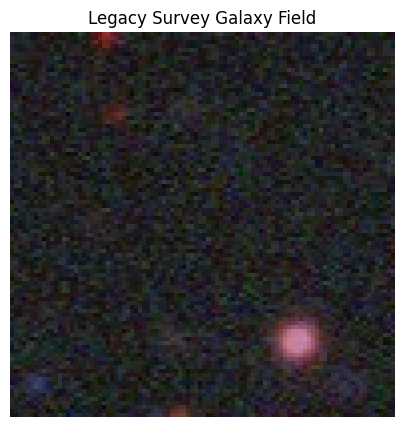

In [ ]:
# ============================================================
# STAGE 2 — REAL LEGACY SURVEY GALAXY
# ============================================================

import requests
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt
import numpy as np

# A known SDSS/Legacy Survey galaxy coordinate
RA  = 180.0
DEC = 0.0

url = (
    "https://www.legacysurvey.org/viewer/"
    f"cutout.jpg?ra={RA}&dec={DEC}&layer=ls-dr10"
    "&pixscale=0.262&size=96"
)

response = requests.get(url)
response.raise_for_status()

img = np.array(Image.open(BytesIO(response.content)))

print("Downloaded image shape:", img.shape)
print("RA:", RA)
print("DEC:", DEC)

plt.figure(figsize=(5,5))
plt.imshow(img)
plt.axis("off")
plt.title("Legacy Survey Galaxy Field")
plt.show()

In [ ]:
# ============================================================
# STAGE 2 — DOWNLOAD GZ3D × AION SAMPLE
# ============================================================

!pip install -q datasets

from datasets import load_dataset

ds = load_dataset(
    "astronolan/gz3d-aion-replication-attempt",
    split="train"
)

print(ds)
print("\nColumns:")
print(ds.column_names)
print("\nNumber of galaxies:", len(ds))

README.md:   0%|          | 0.00/18.4k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/89 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/18 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/89 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/18 [00:00<?, ?it/s]

...

data/test-00017.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2839 [00:00<?, ? examples/s]

Generating threshold_validation split:   0%|          | 0/142 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/568 [00:00<?, ? examples/s]

Dataset({
    features: ['manga_id', 'gz3d_filename', 'source_row', 'candidate_order', 'manifest_order', 'gz3d_ra', 'gz3d_dec', 'legacy_object_id', 'legacy_ra', 'legacy_dec', 'match_sep_arcsec', 'gz_total_classifications', 'gz_bar_votes', 'gz_spiral_votes', 'gz3d_center_overlap_max_votes', 'gz3d_star_overlap_max_votes', 'gz3d_spiral_overlap_max_votes', 'gz3d_bar_overlap_max_votes', 'tok_image', 'gz3d_segmentation', 'rgb', 'split'],
    num_rows: 2839
})

Columns:
['manga_id', 'gz3d_filename', 'source_row', 'candidate_order', 'manifest_order', 'gz3d_ra', 'gz3d_dec', 'legacy_object_id', 'legacy_ra', 'legacy_dec', 'match_sep_arcsec', 'gz_total_classifications', 'gz_bar_votes', 'gz_spiral_votes', 'gz3d_center_overlap_max_votes', 'gz3d_star_overlap_max_votes', 'gz3d_spiral_overlap_max_votes', 'gz3d_bar_overlap_max_votes', 'tok_image', 'gz3d_segmentation', 'rgb', 'split']

Number of galaxies: 2839


**Do not remove below code.**

Galaxy: 1-104986
RA, Dec: 29.05109, -9.65316
Bar votes: 93
Spiral votes: 95
Match separation: 0.469 arcsec
RGB shape: (96, 96, 3)
Segmentation shape: (4, 96, 96)
Segmentation values: [ 0.  1.  2.  3.  4.  5.  6. 14.]


TypeError: Invalid shape (4, 96, 96) for image data

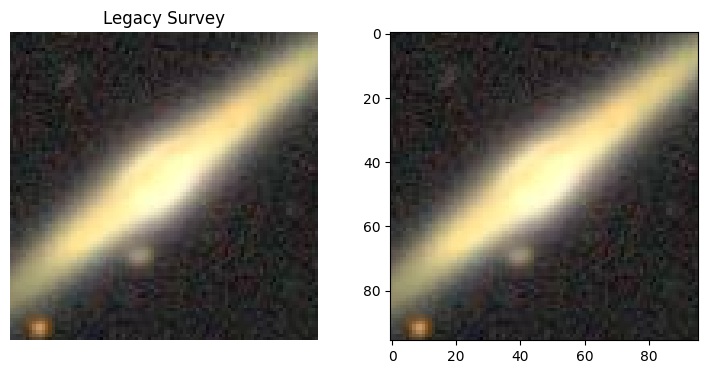

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Select a well-supported barred galaxy
bar_votes = np.array(ds["gz_bar_votes"])
idx = int(np.argmax(bar_votes))

row = ds[idx]

print(f"Galaxy: {row['manga_id']}")
print(f"RA, Dec: {row['gz3d_ra']:.5f}, {row['gz3d_dec']:.5f}")
print(f"Bar votes: {row['gz_bar_votes']}")
print(f"Spiral votes: {row['gz_spiral_votes']}")
print(f"Match separation: {row['match_sep_arcsec']:.3f} arcsec")

rgb = np.array(row["rgb"])
seg = np.array(row["gz3d_segmentation"])

print("RGB shape:", rgb.shape)
print("Segmentation shape:", seg.shape)
print("Segmentation values:", np.unique(seg))

fig, ax = plt.subplots(1, 2, figsize=(9, 4))

ax[0].imshow(rgb)
ax[0].set_title("Legacy Survey")
ax[0].axis("off")

ax[1].imshow(rgb)
ax[1].imshow(seg, alpha=0.5)
ax[1].set_title("GZ3D segmentation")
ax[1].axis("off")

plt.tight_layout()
plt.show()

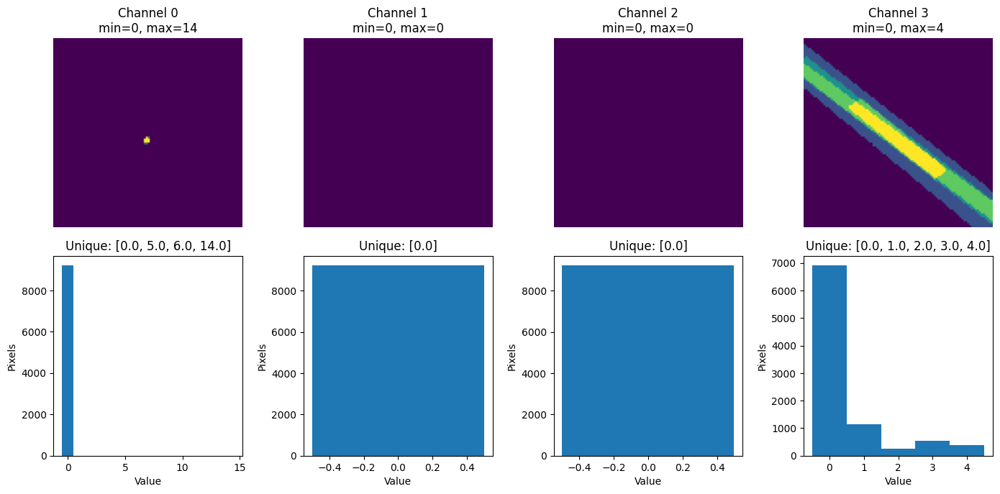

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

seg = np.array(row["gz3d_segmentation"])

fig, ax = plt.subplots(2, 4, figsize=(14, 7))

for i in range(4):
    s = seg[i]

    ax[0, i].imshow(s, origin="lower")
    ax[0, i].set_title(
        f"Channel {i}\n"
        f"min={s.min():.0f}, max={s.max():.0f}"
    )
    ax[0, i].axis("off")

    ax[1, i].hist(s.ravel(), bins=np.arange(s.min(), s.max() + 2) - 0.5)
    ax[1, i].set_title(
        f"Unique: {np.unique(s).tolist()}"
    )
    ax[1, i].set_xlabel("Value")
    ax[1, i].set_ylabel("Pixels")

plt.tight_layout()
plt.show()

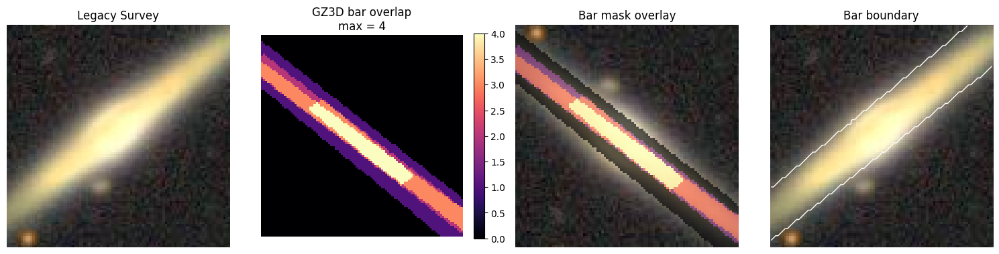

Bar overlap values: [0. 1. 2. 3. 4.]
Bar pixels: 2309
Maximum overlap: 4


In [ ]:
bar = np.array(row["gz3d_segmentation"])[3]

fig, ax = plt.subplots(1, 4, figsize=(15, 4))

ax[0].imshow(rgb)
ax[0].set_title("Legacy Survey")
ax[0].axis("off")

im = ax[1].imshow(bar, origin="lower", cmap="magma")
ax[1].set_title(f"GZ3D bar overlap\nmax = {bar.max():.0f}")
ax[1].axis("off")
plt.colorbar(im, ax=ax[1], fraction=0.046)

ax[2].imshow(rgb)
ax[2].imshow(np.ma.masked_where(bar == 0, bar),
             origin="lower", cmap="magma", alpha=0.65)
ax[2].set_title("Bar mask overlay")
ax[2].axis("off")

bar_binary = bar >= 1

ax[3].imshow(rgb)
ax[3].contour(bar_binary, levels=[0.5], colors="white", linewidths=1)
ax[3].set_title("Bar boundary")
ax[3].axis("off")

plt.tight_layout()
plt.show()

print("Bar overlap values:", np.unique(bar))
print("Bar pixels:", np.count_nonzero(bar))
print("Maximum overlap:", int(bar.max()))

In [ ]:
tok = row["tok_image"]

print("tok_image type:", type(tok))

if hasattr(tok, "shape"):
    print("shape:", tok.shape)
else:
    print("length:", len(tok))

print("First element type:", type(tok[0]))

try:
    print("First element shape:", np.asarray(tok[0]).shape)
except Exception:
    pass

tok_image type: <class 'list'>
length: 24
First element type: <class 'list'>
First element shape: (24,)


In [ ]:
import numpy as np
import torch

tok = torch.tensor(row["tok_image"], dtype=torch.long)

print("Token shape:", tuple(tok.shape))
print("Token count:", tok.numel())
print("Token range:", int(tok.min()), "to", int(tok.max()))
print("Unique tokens:", len(torch.unique(tok)))

# AION stores the image tokens as a 576-token sequence.
# Try decoding them with the image codec already loaded.
try:
    from aion.modalities import LegacySurveyImage

    token_batch = tok.reshape(1, -1).to(device)

    decoded = codec_manager.decode(
        {"tok_image": token_batch},
        LegacySurveyImage
    )

    print("\nDecoded object:", type(decoded))
    print("Decoded flux shape:", decoded.flux.shape)
    print("Bands:", decoded.bands)

except Exception as e:
    print("\nDecode attempt failed:")
    print(type(e).__name__, str(e))

Token shape: (24, 24)
Token count: 576
Token range: 3513 to 4318
Unique tokens: 35

Decode attempt failed:
AttributeError 'RescaleToLegacySurvey' object has no attribute '_reverse_zeropoint'


In [ ]:
from datasets import load_dataset

mmu = load_dataset(
    "MultimodalUniverse/legacysurvey",
    split="train",
    streaming=True
)

print(mmu)
print(mmu.features)

README.md:   0%|          | 0.00/19.2k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/165 [00:00<?, ?it/s]

IterableDataset({
    features: ['image', 'blobmodel', 'rgb', 'object_mask', 'catalog', 'EBV', 'FLUX_G', 'FLUX_R', 'FLUX_I', 'FLUX_Z', 'FLUX_W1', 'FLUX_W2', 'FLUX_W3', 'FLUX_W4', 'SHAPE_R', 'SHAPE_E1', 'SHAPE_E2', 'object_id'],
    num_shards: 165
})
{'image': {'band': List(Value('string')), 'flux': List(Array2D(shape=(160, 160), dtype='float32')), 'mask': List(Array2D(shape=(160, 160), dtype='bool')), 'ivar': List(Array2D(shape=(160, 160), dtype='float32')), 'psf_fwhm': List(Value('float32')), 'scale': List(Value('float32'))}, 'blobmodel': Image(mode=None, decode=True), 'rgb': Image(mode=None, decode=True), 'object_mask': Image(mode=None, decode=True), 'catalog': {'FLUX_G': List(Value('float32')), 'FLUX_R': List(Value('float32')), 'FLUX_I': List(Value('float32')), 'FLUX_Z': List(Value('float32')), 'TYPE': List(Value('float32')), 'SHAPE_R': List(Value('float32')), 'SHAPE_E1': List(Value('float32')), 'SHAPE_E2': List(Value('float32')), 'X': List(Value('float32')), 'Y': List(Value('float

In [ ]:
"""
target_id = str(row["legacy_object_id"])

print("Target Legacy object ID:", target_id)

match = None

for i, item in enumerate(mmu):
    if str(item["object_id"]) == target_id:
        match = item
        print("Found at streamed index:", i)
        break

    if i % 10000 == 0:
        print(f"Checked {i:,} objects...", end="\r")

if match is None:
    print("\nNo exact object_id match found.")
else:
    print("\nObject ID:", match["object_id"])
    print("Bands:", match["image"]["band"])
    print("Number of bands:", len(match["image"]["band"]))

    for b, flux, ivar, mask, psf, scale in zip(
        match["image"]["band"],
        match["image"]["flux"],
        match["image"]["ivar"],
        match["image"]["mask"],
        match["image"]["psf_fwhm"],
        match["image"]["scale"]
    ):
        print(
            f"{b}: flux={np.asarray(flux).shape}, "
            f"ivar={np.asarray(ivar).shape}, "
            f"mask={np.asarray(mask).shape}, "
            f"PSF={psf:.3f}, scale={scale:.4f}"
        )
        """

'\ntarget_id = str(row["legacy_object_id"])\n\nprint("Target Legacy object ID:", target_id)\n\nmatch = None\n\nfor i, item in enumerate(mmu):\n    if str(item["object_id"]) == target_id:\n        match = item\n        print("Found at streamed index:", i)\n        break\n\n    if i % 10000 == 0:\n        print(f"Checked {i:,} objects...", end="\r")\n\nif match is None:\n    print("\nNo exact object_id match found.")\nelse:\n    print("\nObject ID:", match["object_id"])\n    print("Bands:", match["image"]["band"])\n    print("Number of bands:", len(match["image"]["band"]))\n\n    for b, flux, ivar, mask, psf, scale in zip(\n        match["image"]["band"],\n        match["image"]["flux"],\n        match["image"]["ivar"],\n        match["image"]["mask"],\n        match["image"]["psf_fwhm"],\n        match["image"]["scale"]\n    ):\n        print(\n            f"{b}: flux={np.asarray(flux).shape}, "\n            f"ivar={np.asarray(ivar).shape}, "\n            f"mask={np.asarray(mask).shape}

In [ ]:
"""
print("Dataset:", mmu)
print("Number of shards:", mmu.num_shards)
print("Target:", target_id)
"""

'\nprint("Dataset:", mmu)\nprint("Number of shards:", mmu.num_shards)\nprint("Target:", target_id)\n'

In [ ]:
first = next(iter(mmu))

print("object_id:", first["object_id"])
print("catalog keys:", first["catalog"].keys())
print("catalog length:", len(first["catalog"]["X"]))

for key in first["catalog"]:
    value = first["catalog"][key]
    print(f"{key}: {np.asarray(value).shape}")

object_id: b'0421p022-7410'
catalog keys: dict_keys(['FLUX_G', 'FLUX_R', 'FLUX_I', 'FLUX_Z', 'TYPE', 'SHAPE_R', 'SHAPE_E1', 'SHAPE_E2', 'X', 'Y'])
catalog length: 20
FLUX_G: (20,)
FLUX_R: (20,)
FLUX_I: (20,)
FLUX_Z: (20,)
TYPE: (20,)
SHAPE_R: (20,)
SHAPE_E1: (20,)
SHAPE_E2: (20,)
X: (20,)
Y: (20,)


In [ ]:
from huggingface_hub import list_repo_files

files = list_repo_files("MultimodalUniverse/legacysurvey", repo_type="dataset")

data_files = [f for f in files if f.endswith((".parquet", ".arrow", ".json", ".jsonl"))]

print("Total repository files:", len(files))
print("Potential data files:", len(data_files))

for f in data_files[:20]:
    print(f)

Total repository files: 167
Potential data files: 165
dr10_south_21/train-00000-of-00165.parquet
dr10_south_21/train-00001-of-00165.parquet
dr10_south_21/train-00002-of-00165.parquet
dr10_south_21/train-00003-of-00165.parquet
dr10_south_21/train-00004-of-00165.parquet
dr10_south_21/train-00005-of-00165.parquet
dr10_south_21/train-00006-of-00165.parquet
dr10_south_21/train-00007-of-00165.parquet
dr10_south_21/train-00008-of-00165.parquet
dr10_south_21/train-00009-of-00165.parquet
dr10_south_21/train-00010-of-00165.parquet
dr10_south_21/train-00011-of-00165.parquet
dr10_south_21/train-00012-of-00165.parquet
dr10_south_21/train-00013-of-00165.parquet
dr10_south_21/train-00014-of-00165.parquet
dr10_south_21/train-00015-of-00165.parquet
dr10_south_21/train-00016-of-00165.parquet
dr10_south_21/train-00017-of-00165.parquet
dr10_south_21/train-00018-of-00165.parquet
dr10_south_21/train-00019-of-00165.parquet


In [ ]:
"""
import pandas as pd
from huggingface_hub import hf_hub_download

repo = "MultimodalUniverse/legacysurvey"
target = "0290m097-6821"

found = None

for i in range(165):
    filename = f"dr10_south_21/train-{i:05d}-of-00165.parquet"

    path = hf_hub_download(
        repo_id=repo,
        filename=filename,
        repo_type="dataset"
    )

    ids = pd.read_parquet(path, columns=["object_id"])

    ids["object_id"] = ids["object_id"].astype(str).str.replace("b'", "", regex=False).str.replace("'", "", regex=False)

    matches = ids.index[ids["object_id"] == target].tolist()

    if matches:
        found = (i, matches[0], path)
        print("Found!")
        print("Shard:", i)
        print("Row:", matches[0])
        print("Object ID:", target)
        break

    if i % 10 == 0:
        print(f"Checked {i}/165 shards")

if found is None:
    print("Object not found.")
    """

'\nimport pandas as pd\nfrom huggingface_hub import hf_hub_download\n\nrepo = "MultimodalUniverse/legacysurvey"\ntarget = "0290m097-6821"\n\nfound = None\n\nfor i in range(165):\n    filename = f"dr10_south_21/train-{i:05d}-of-00165.parquet"\n\n    path = hf_hub_download(\n        repo_id=repo,\n        filename=filename,\n        repo_type="dataset"\n    )\n\n    ids = pd.read_parquet(path, columns=["object_id"])\n\n    ids["object_id"] = ids["object_id"].astype(str).str.replace("b\'", "", regex=False).str.replace("\'", "", regex=False)\n\n    matches = ids.index[ids["object_id"] == target].tolist()\n\n    if matches:\n        found = (i, matches[0], path)\n        print("Found!")\n        print("Shard:", i)\n        print("Row:", matches[0])\n        print("Object ID:", target)\n        break\n\n    if i % 10 == 0:\n        print(f"Checked {i}/165 shards")\n\nif found is None:\n    print("Object not found.")\n    '

In [ ]:
import os
import shutil

# Remove Hugging Face datasets/cache downloaded during the failed shard scan
paths = [
    "/root/.cache/huggingface/hub/datasets--MultimodalUniverse--legacysurvey",
    "/root/.cache/huggingface/datasets",
]

for path in paths:
    if os.path.exists(path):
        size_gb = shutil.disk_usage(path).used / 1e9 if os.path.isdir(path) else os.path.getsize(path) / 1e9
        shutil.rmtree(path)
        print(f"Removed: {path} ({size_gb:.2f} GB)")

print(f"\nFree space: {shutil.disk_usage('/').free / 1e9:.2f} GB")

Removed: /root/.cache/huggingface/hub/datasets--MultimodalUniverse--legacysurvey (47.79 GB)
Removed: /root/.cache/huggingface/datasets (47.79 GB)

Free space: 73.26 GB


In [ ]:
from huggingface_hub import list_repo_files

repo = "MultimodalUniverse/legacysurvey"

files = list_repo_files(repo, repo_type="dataset")

print("Repository files:", len(files))
print("\nNon-Parquet files:")

for f in files:
    if not f.endswith(".parquet"):
        print(f)

Repository files: 167

Non-Parquet files:
.gitattributes
README.md


In [ ]:
import requests

ra = row["gz3d_ra"]
dec = row["gz3d_dec"]

url = (
    "https://www.legacysurvey.org/viewer/cutout.fits"
    f"?ra={ra}&dec={dec}"
    "&layer=ls-dr10"
    "&pixscale=0.262"
    "&bands=griz"
    "&size=160"
)

r = requests.get(url, timeout=60)

print("HTTP status:", r.status_code)
print("Content type:", r.headers.get("Content-Type"))
print("Downloaded:", len(r.content) / 1e6, "MB")

if r.status_code == 200:
    with open("/content/test_griz.fits", "wb") as f:
        f.write(r.content)
    print("Saved:", "/content/test_griz.fits")
else:
    print(r.text[:500])

HTTP status: 200
Content type: image/fits
Downloaded: 0.41472 MB
Saved: /content/test_griz.fits


Filename: /content/test_griz.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      29   (160, 160, 4)   float32   
None

Primary header:
SIMPLE  =                    T / file does conform to FITS standard             BITPIX  =                  -32 / number of bits per data pixel                  NAXIS   =                    3 / number of data axes                            NAXIS1  =                  160 / length of data axis 1                          NAXIS2  =                  160 / length of data axis 2                          NAXIS3  =                    4 / length of data axis 3                          EXTEND  =                    T / FITS dataset may contain extensions            COMMENT   FITS (Flexible Image Transport System) format is defined in 'AstronomyCOMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H SURVEY  = 'LegacySurvey'                                                        VERSION = 'DR

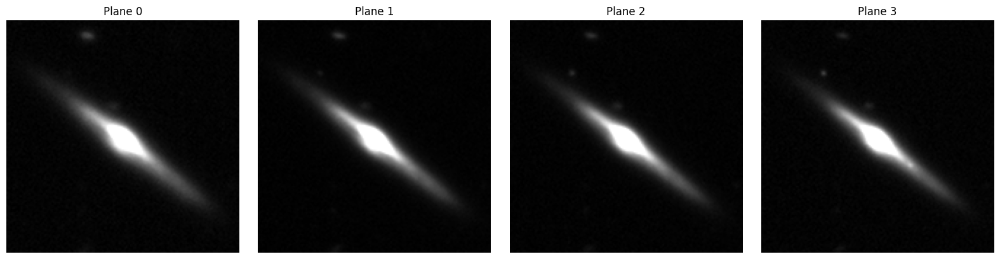

In [ ]:
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt

fits_path = "/content/test_griz.fits"

with fits.open(fits_path) as hdul:
    print(hdul.info())
    print("\nPrimary header:")
    print(hdul[0].header)

    data = hdul[0].data

print("\nData shape:", data.shape)
print("Data dtype:", data.dtype)
print("Finite fraction:", np.isfinite(data).mean())

# Inspect the band planes
if data.ndim == 3:
    fig, ax = plt.subplots(1, data.shape[0], figsize=(16, 4))

    for i in range(data.shape[0]):
        img = data[i]
        lo, hi = np.nanpercentile(img, [1, 99])

        ax[i].imshow(
            img,
            origin="lower",
            cmap="gray",
            vmin=lo,
            vmax=hi
        )
        ax[i].set_title(f"Plane {i}")
        ax[i].axis("off")

    plt.tight_layout()
    plt.show()

Raw FITS shape: (4, 160, 160)
Band-first shape: (4, 160, 160)


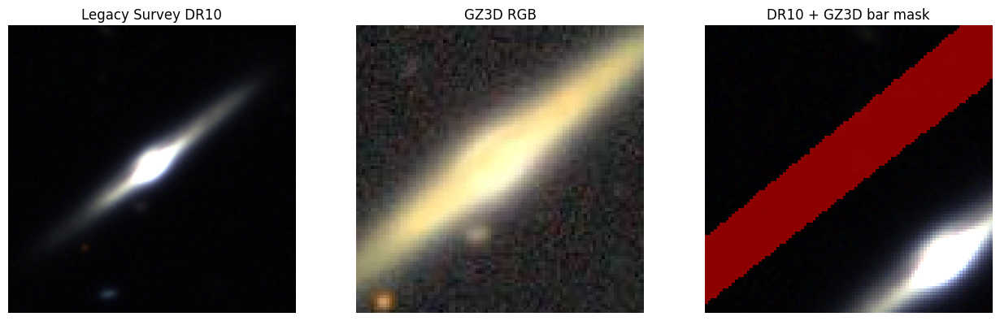

Native image: (4, 160, 160)
GZ3D bar mask: (96, 96)
Bar pixels: 2309


In [ ]:
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt

with fits.open("/content/test_griz.fits") as hdul:
    raw = hdul[0].data.astype(np.float32)

print("Raw FITS shape:", raw.shape)

# FITS cutout is expected to be (Y, X, BAND)
if raw.ndim == 3 and raw.shape[-1] == 4:
    data = np.moveaxis(raw, -1, 0)
elif raw.ndim == 3 and raw.shape[0] == 4:
    data = raw
else:
    raise ValueError(f"Unexpected FITS shape: {raw.shape}")

print("Band-first shape:", data.shape)

g, r, i, z = data

def norm(x):
    lo, hi = np.nanpercentile(x, [1, 99])
    return np.clip((x - lo) / (hi - lo), 0, 1)

rgb_fits = np.stack([
    norm(i),
    norm(r),
    norm(g)
], axis=-1)

bar = np.asarray(row["gz3d_segmentation"])[3]
bar_mask = bar >= 1

fig, ax = plt.subplots(1, 3, figsize=(13, 4))

ax[0].imshow(rgb_fits)
ax[0].set_title("Legacy Survey DR10")
ax[0].axis("off")

ax[1].imshow(rgb)
ax[1].set_title("GZ3D RGB")
ax[1].axis("off")

ax[2].imshow(rgb_fits)
ax[2].imshow(
    np.ma.masked_where(~bar_mask, bar_mask),
    cmap="autumn",
    alpha=0.55
)
ax[2].set_title("DR10 + GZ3D bar mask")
ax[2].axis("off")

plt.tight_layout()
plt.show()

print("Native image:", data.shape)
print("GZ3D bar mask:", bar.shape)
print("Bar pixels:", int(bar_mask.sum()))

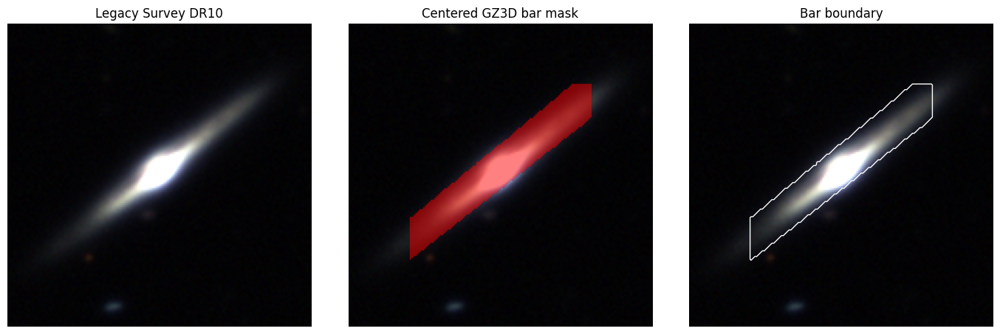

GZ3D mask: (96, 96)
Placement: x=32:128, y=32:128


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Native DR10 image: (4, 160, 160)
g, r, i, z = data

def norm(x):
    lo, hi = np.nanpercentile(x, [1, 99])
    return np.clip((x - lo) / (hi - lo), 0, 1)

rgb_fits = np.stack([norm(i), norm(r), norm(g)], axis=-1)

# GZ3D bar mask
bar = np.asarray(row["gz3d_segmentation"])[3]
bar_mask = bar >= 1

# Center the 96x96 GZ3D mask in the 160x160 DR10 image
aligned_bar = np.zeros((160, 160), dtype=bool)

y0 = (160 - bar.shape[0]) // 2
x0 = (160 - bar.shape[1]) // 2

aligned_bar[y0:y0 + bar.shape[0],
            x0:x0 + bar.shape[1]] = bar_mask

fig, ax = plt.subplots(1, 3, figsize=(14, 4.5))

ax[0].imshow(rgb_fits)
ax[0].set_title("Legacy Survey DR10")
ax[0].axis("off")

ax[1].imshow(rgb_fits)
ax[1].imshow(
    np.ma.masked_where(~aligned_bar, aligned_bar),
    cmap="autumn",
    alpha=0.5
)
ax[1].set_title("Centered GZ3D bar mask")
ax[1].axis("off")

ax[2].imshow(rgb_fits)
ax[2].contour(
    aligned_bar,
    levels=[0.5],
    colors="white",
    linewidths=1
)
ax[2].set_title("Bar boundary")
ax[2].axis("off")

plt.tight_layout()
plt.show()

print("GZ3D mask:", bar.shape)
print("Placement:", f"x={x0}:{x0+bar.shape[1]}, y={y0}:{y0+bar.shape[0]}")

Original GZ3D mask: (96, 96)
Resampled mask: (36, 36)
Scale factor: 0.3779
Placement: x=62:98, y=62:98
Aligned bar pixels: 325


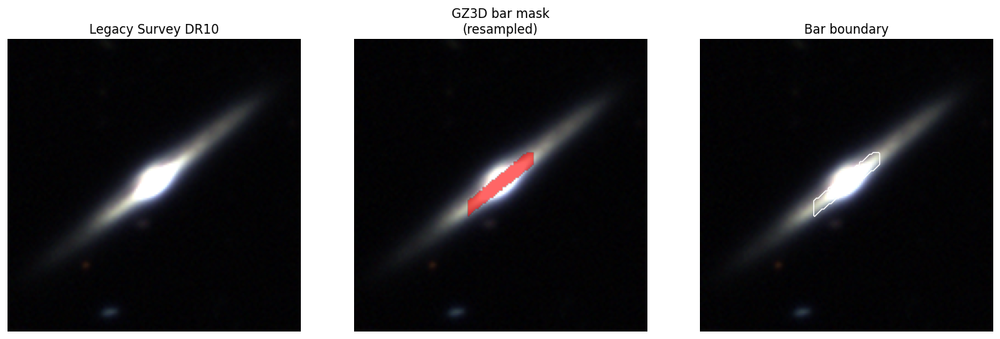

In [ ]:
from scipy.ndimage import zoom
import numpy as np
import matplotlib.pyplot as plt

# GZ3D bar count map
bar_counts = np.asarray(row["gz3d_segmentation"])[3]

# GZ3D: 0.099 arcsec/pixel
# Legacy DR10: 0.262 arcsec/pixel
scale_factor = 0.099 / 0.262

# Resample the count map to the Legacy Survey pixel scale
bar_resampled = zoom(
    bar_counts,
    scale_factor,
    order=0
)

# Binary scientific bar mask
bar_resampled_binary = bar_resampled >= 1

# Place the resampled mask at the common image centre
aligned_bar = np.zeros((160, 160), dtype=bool)

h, w = bar_resampled_binary.shape
y0 = (160 - h) // 2
x0 = (160 - w) // 2

aligned_bar[y0:y0+h, x0:x0+w] = bar_resampled_binary

print("Original GZ3D mask:", bar_counts.shape)
print("Resampled mask:", bar_resampled_binary.shape)
print(f"Scale factor: {scale_factor:.4f}")
print(f"Placement: x={x0}:{x0+w}, y={y0}:{y0+h}")
print("Aligned bar pixels:", int(aligned_bar.sum()))

fig, ax = plt.subplots(1, 3, figsize=(14, 4.5))

ax[0].imshow(rgb_fits)
ax[0].set_title("Legacy Survey DR10")
ax[0].axis("off")

ax[1].imshow(rgb_fits)
ax[1].imshow(
    np.ma.masked_where(~aligned_bar, aligned_bar),
    cmap="autumn",
    alpha=0.6
)
ax[1].set_title("GZ3D bar mask\n(resampled)")
ax[1].axis("off")

ax[2].imshow(rgb_fits)
ax[2].contour(
    aligned_bar,
    levels=[0.5],
    colors="white",
    linewidths=1
)
ax[2].set_title("Bar boundary")
ax[2].axis("off")

plt.tight_layout()
plt.show()

Original GZ3D mask: (96, 96)
Resampled mask: (36, 36)
Scale factor: 0.3779
Placement: x=62:98, y=62:98
Aligned bar pixels: 325


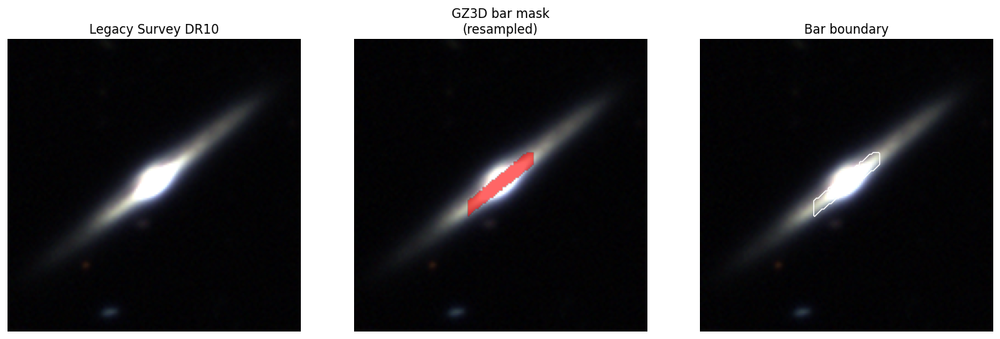

In [ ]:
from scipy.ndimage import zoom
import numpy as np
import matplotlib.pyplot as plt

# GZ3D bar count map
bar_counts = np.asarray(row["gz3d_segmentation"])[3]

# GZ3D: 0.099 arcsec/pixel
# Legacy DR10: 0.262 arcsec/pixel
scale_factor = 0.099 / 0.262

# Resample the count map to the Legacy Survey pixel scale
bar_resampled = zoom(
    bar_counts,
    scale_factor,
    order=0
)

# Binary scientific bar mask
bar_resampled_binary = bar_resampled >= 1

# Place the resampled mask at the common image centre
aligned_bar = np.zeros((160, 160), dtype=bool)

h, w = bar_resampled_binary.shape
y0 = (160 - h) // 2
x0 = (160 - w) // 2

aligned_bar[y0:y0+h, x0:x0+w] = bar_resampled_binary

print("Original GZ3D mask:", bar_counts.shape)
print("Resampled mask:", bar_resampled_binary.shape)
print(f"Scale factor: {scale_factor:.4f}")
print(f"Placement: x={x0}:{x0+w}, y={y0}:{y0+h}")
print("Aligned bar pixels:", int(aligned_bar.sum()))

fig, ax = plt.subplots(1, 3, figsize=(14, 4.5))

ax[0].imshow(rgb_fits)
ax[0].set_title("Legacy Survey DR10")
ax[0].axis("off")

ax[1].imshow(rgb_fits)
ax[1].imshow(
    np.ma.masked_where(~aligned_bar, aligned_bar),
    cmap="autumn",
    alpha=0.6
)
ax[1].set_title("GZ3D bar mask\n(resampled)")
ax[1].axis("off")

ax[2].imshow(rgb_fits)
ax[2].contour(
    aligned_bar,
    levels=[0.5],
    colors="white",
    linewidths=1
)
ax[2].set_title("Bar boundary")
ax[2].axis("off")

plt.tight_layout()
plt.show()

Reference image: (4, 160, 160)
Degraded observation: (4, 160, 160)
Gaussian sigma: 1.5
Downsampling factor: 2


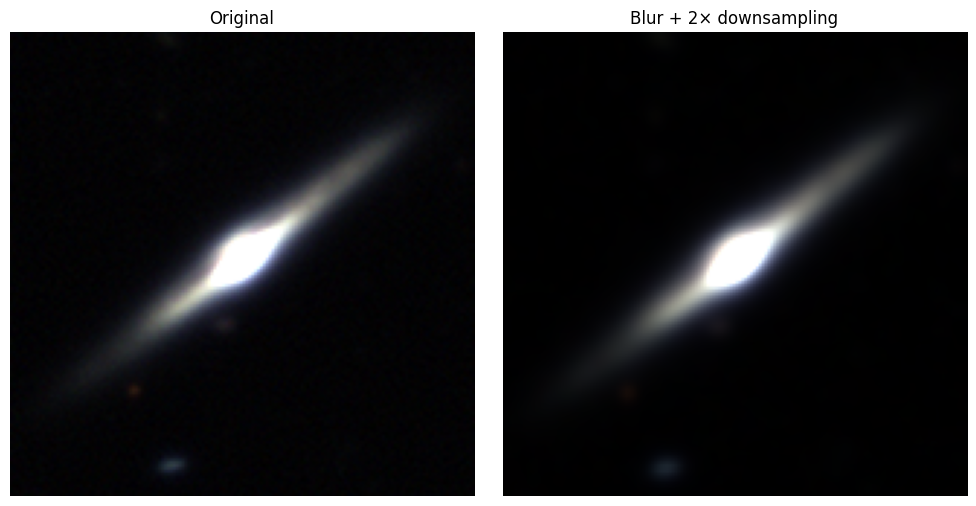

In [ ]:
# Stage 3 — create the first controlled degraded observation

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, zoom

# Original 4-band image: (4, 160, 160)
x = data.copy().astype(np.float32)

# Fixed experimental parameters
SIGMA = 1.5
DOWNSAMPLE = 2
SEED = 42

rng = np.random.default_rng(SEED)

# 1. PSF-like Gaussian blur
blurred = np.empty_like(x)

for b in range(4):
    blurred[b] = gaussian_filter(x[b], sigma=SIGMA)

# 2. Downsample by factor 2
y_low = blurred[:, ::DOWNSAMPLE, ::DOWNSAMPLE]

# 3. Bring it back to the original spatial size
y = zoom(
    y_low,
    (1, DOWNSAMPLE, DOWNSAMPLE),
    order=1
).astype(np.float32)

print("Reference image:", x.shape)
print("Degraded observation:", y.shape)
print(f"Gaussian sigma: {SIGMA}")
print(f"Downsampling factor: {DOWNSAMPLE}")

# Visualize reference vs degraded
def make_rgb(img):
    g, r, i, z = img

    def norm(v):
        lo, hi = np.nanpercentile(v, [1, 99])
        return np.clip((v - lo) / (hi - lo), 0, 1)

    return np.stack([norm(i), norm(r), norm(g)], axis=-1)

rgb_original = make_rgb(x)
rgb_degraded = make_rgb(y)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))

ax[0].imshow(rgb_original)
ax[0].set_title("Original")
ax[0].axis("off")

ax[1].imshow(rgb_degraded)
ax[1].set_title("Blur + 2× downsampling")
ax[1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from skimage.metrics import structural_similarity, peak_signal_noise_ratio
import numpy as np

# Compare all four bands using their own dynamic ranges
metrics = []

for b, name in enumerate(["g", "r", "i", "z"]):
    ref = x[b]
    obs = y[b]

    data_range = np.nanpercentile(ref, 99.5) - np.nanpercentile(ref, 0.5)

    psnr = peak_signal_noise_ratio(
        ref,
        obs,
        data_range=data_range
    )

    ssim = structural_similarity(
        ref,
        obs,
        data_range=data_range
    )

    rmse = np.sqrt(np.mean((ref - obs) ** 2))

    metrics.append((name, psnr, ssim, rmse))

print("Band   PSNR (dB)   SSIM       RMSE")
print("--------------------------------------")

for name, psnr, ssim, rmse in metrics:
    print(f"{name:>3}    {psnr:8.3f}   {ssim:7.4f}   {rmse:.6g}")

print("\nMean PSNR:", np.mean([m[1] for m in metrics]))
print("Mean SSIM:", np.mean([m[2] for m in metrics]))

Band   PSNR (dB)   SSIM       RMSE
--------------------------------------
  g      34.150    0.9692   0.00445741
  r      32.345    0.9810   0.0147877
  i      32.289    0.9779   0.0225296
  z      31.914    0.9710   0.0319491

Mean PSNR: 32.674574162382314
Mean SSIM: 0.9747696983494301


In [ ]:
import torch
import torch.nn.functional as F
from aion.modalities import LegacySurveyImage

# AION expects [batch, 4, height, width]
x_tensor = torch.from_numpy(x).float().unsqueeze(0).to(device)
y_tensor = torch.from_numpy(y).float().unsqueeze(0).to(device)

# Wrap tensors as the typed AION modality
x_image = LegacySurveyImage(
    flux=x_tensor,
    bands=["DES-G", "DES-R", "DES-I", "DES-Z"]
)

y_image = LegacySurveyImage(
    flux=y_tensor,
    bands=["DES-G", "DES-R", "DES-I", "DES-Z"]
)

with torch.no_grad():
    x_tokens = codec_manager.encode(x_image)
    y_tokens = codec_manager.encode(y_image)

print("Token keys:", x_tokens.keys())
print("Original tokens:", {
    k: tuple(v.shape) for k, v in x_tokens.items()
})
print("Degraded tokens:", {
    k: tuple(v.shape) for k, v in y_tokens.items()
})

# AION embedding
with torch.no_grad():
    x_emb = model.encode(x_tokens, num_encoder_tokens=600)
    y_emb = model.encode(y_tokens, num_encoder_tokens=600)

print("Embedding shapes:", x_emb.shape, y_emb.shape)

# Flatten and compare
x_vec = x_emb.flatten(1)
y_vec = y_emb.flatten(1)

cos_sim = F.cosine_similarity(x_vec, y_vec).item()
l2_dist = torch.norm(x_vec - y_vec).item()

print(f"AION cosine similarity: {cos_sim:.6f}")
print(f"AION embedding L2 distance: {l2_dist:.4f}")

Token keys: dict_keys(['tok_image'])
Original tokens: {'tok_image': (1, 576)}
Degraded tokens: {'tok_image': (1, 576)}
Embedding shapes: torch.Size([1, 576, 768]) torch.Size([1, 576, 768])
AION cosine similarity: 0.918256
AION embedding L2 distance: 482.9710


In [ ]:
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter, zoom
from skimage.metrics import structural_similarity, peak_signal_noise_ratio

levels = [
    ("Original", 0.0, 1),
    ("Mild", 0.75, 2),
    ("Moderate", 1.5, 2),
    ("Strong", 2.5, 2),
    ("Very strong", 4.0, 2),
]

results = []

# Bar mask in the 160x160 Legacy Survey frame
bar_region = aligned_bar

for name, sigma, downsample in levels:

    if sigma == 0:
        degraded = x.copy()
    else:
        blurred = np.empty_like(x)

        for b in range(4):
            blurred[b] = gaussian_filter(x[b], sigma=sigma)

        low = blurred[:, ::downsample, ::downsample]

        degraded = zoom(
            low,
            (1, downsample, downsample),
            order=1
        ).astype(np.float32)

    psnr_values = []
    ssim_values = []

    for b in range(4):
        ref = x[b]
        obs = degraded[b]

        data_range = (
            np.nanpercentile(ref, 99.5)
            - np.nanpercentile(ref, 0.5)
        )

        psnr_values.append(
            peak_signal_noise_ratio(
                ref, obs, data_range=data_range
            )
        )

        ssim_values.append(
            structural_similarity(
                ref, obs, data_range=data_range
            )
        )

    # Bar-region RMSE
    bar_rmse = np.sqrt(
        np.mean(
            (x[:, bar_region] - degraded[:, bar_region]) ** 2
        )
    )

    # Global RMSE
    global_rmse = np.sqrt(
        np.mean((x - degraded) ** 2)
    )

    results.append({
        "level": name,
        "sigma": sigma,
        "PSNR": np.mean(psnr_values),
        "SSIM": np.mean(ssim_values),
        "global_RMSE": global_rmse,
        "bar_RMSE": bar_rmse,
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False, float_format=lambda v: f"{v:.5f}"))

      level   sigma     PSNR    SSIM  global_RMSE  bar_RMSE
   Original 0.00000      inf 1.00000      0.00000   0.00000
       Mild 0.75000 33.86473 0.97889      0.01820   0.11760
   Moderate 1.50000 32.67457 0.97477      0.02102   0.14183
     Strong 2.50000 29.92932 0.96489      0.02902   0.21441
Very strong 4.00000 26.33323 0.93873      0.04381   0.34220


/usr/local/lib/python3.13/dist-packages/skimage/metrics/simple_metrics.py:168: RuntimeWarning: divide by zero encountered in scalar divide
  return 10 * np.log10((data_range**2) / err)


In [ ]:
import torch
import torch.nn.functional as F
import pandas as pd
from scipy.ndimage import gaussian_filter, zoom
from aion.modalities import LegacySurveyImage

levels = [
    ("Original", 0.0, 1),
    ("Mild", 0.75, 2),
    ("Moderate", 1.5, 2),
    ("Strong", 2.5, 2),
    ("Very strong", 4.0, 2),
]

# Create degraded images
images = []

for name, sigma, downsample in levels:

    if sigma == 0:
        img = x.copy()
    else:
        blurred = np.empty_like(x)

        for b in range(4):
            blurred[b] = gaussian_filter(
                x[b], sigma=sigma
            )

        low = blurred[:, ::downsample, ::downsample]

        img = zoom(
            low,
            (1, downsample, downsample),
            order=1
        ).astype(np.float32)

    images.append(img)

# Stack into one AION batch
batch = torch.from_numpy(
    np.stack(images)
).float().to(device)

print("AION input batch:", tuple(batch.shape))

# AION LegacySurvey modality
image_modality = LegacySurveyImage(
    flux=batch,
    bands=["DES-G", "DES-R", "DES-I", "DES-Z"]
)

with torch.no_grad():
    tokens = codec_manager.encode(image_modality)
    embeddings = model.encode(
        tokens,
        num_encoder_tokens=600
    )

print("Token shape:", tuple(tokens["tok_image"].shape))
print("Embedding shape:", tuple(embeddings.shape))

# Original embedding
reference = embeddings[0].flatten().unsqueeze(0)

results = []

for j, (name, sigma, _) in enumerate(levels):

    current = embeddings[j].flatten().unsqueeze(0)

    cosine = F.cosine_similarity(
        reference,
        current
    ).item()

    distance = torch.norm(
        reference - current
    ).item()

    results.append({
        "level": name,
        "sigma": sigma,
        "AION_cosine": cosine,
        "AION_L2": distance
    })

aion_df = pd.DataFrame(results)

print("\nAION representation change")
print(aion_df.to_string(
    index=False,
    float_format=lambda v: f"{v:.6f}"
))

AION input batch: (5, 4, 160, 160)
Token shape: (5, 576)
Embedding shape: (5, 576, 768)

AION representation change
      level    sigma  AION_cosine    AION_L2
   Original 0.000000     1.000000   0.000000
       Mild 0.750000     0.969461 298.908295
   Moderate 1.500000     0.918257 482.970886
     Strong 2.500000     0.880113 581.193054
Very strong 4.000000     0.863240 618.915161


New new

In [ ]:
from skimage.metrics import structural_similarity
import pandas as pd
import numpy as np

# Reuse the five degraded images created previously in `images`
bar = aligned_bar

rows = []

for (name, sigma, _), img in zip(levels, images):

    # Bar-region metrics across all four bands
    bar_rmse = np.sqrt(
        np.mean(
            (x[:, bar] - img[:, bar]) ** 2
        )
    )

    bar_ssim = []

    for b in range(4):
        ref = x[b]
        obs = img[b]

        # Crop to the bounding box of the registered bar
        yy, xx = np.where(bar)

        y1, y2 = yy.min(), yy.max() + 1
        x1, x2 = xx.min(), xx.max() + 1

        ref_crop = ref[y1:y2, x1:x2]
        obs_crop = obs[y1:y2, x1:x2]

        data_range = (
            np.nanpercentile(ref_crop, 99.5)
            - np.nanpercentile(ref_crop, 0.5)
        )

        bar_ssim.append(
            structural_similarity(
                ref_crop,
                obs_crop,
                data_range=data_range
            )
        )

    rows.append({
        "level": name,
        "sigma": sigma,
        "bar_RMSE": bar_rmse,
        "bar_SSIM": np.mean(bar_ssim)
    })

morph_df = pd.DataFrame(rows)

# Add AION results
morph_df["AION_cosine"] = aion_df["AION_cosine"].values
morph_df["AION_L2"] = aion_df["AION_L2"].values

print(
    morph_df.to_string(
        index=False,
        float_format=lambda v: f"{v:.6f}"
    )
)

      level    sigma  bar_RMSE  bar_SSIM  AION_cosine    AION_L2
   Original 0.000000  0.000000  1.000000     1.000000   0.000000
       Mild 0.750000  0.117605  0.956602     0.969461 298.908295
   Moderate 1.500000  0.141826  0.939339     0.918257 482.970886
     Strong 2.500000  0.214414  0.884256     0.880113 581.193054
Very strong 4.000000  0.342202  0.751934     0.863240 618.915161


In [ ]:
import torch
import torch.nn.functional as F
from aion.modalities import LegacySurveyImage

# AION expects [batch, 4, height, width]
x_tensor = torch.from_numpy(x).float().unsqueeze(0).to(device)
y_tensor = torch.from_numpy(y).float().unsqueeze(0).to(device)

# Wrap tensors as the typed AION modality
x_image = LegacySurveyImage(
    flux=x_tensor,
    bands=["DES-G", "DES-R", "DES-I", "DES-Z"]
)

y_image = LegacySurveyImage(
    flux=y_tensor,
    bands=["DES-G", "DES-R", "DES-I", "DES-Z"]
)

with torch.no_grad():
    x_tokens = codec_manager.encode(x_image)
    y_tokens = codec_manager.encode(y_image)

print("Token keys:", x_tokens.keys())
print("Original tokens:", {
    k: tuple(v.shape) for k, v in x_tokens.items()
})
print("Degraded tokens:", {
    k: tuple(v.shape) for k, v in y_tokens.items()
})

# AION embedding
with torch.no_grad():
    x_emb = model.encode(x_tokens, num_encoder_tokens=600)
    y_emb = model.encode(y_tokens, num_encoder_tokens=600)

print("Embedding shapes:", x_emb.shape, y_emb.shape)

# Flatten and compare
x_vec = x_emb.flatten(1)
y_vec = y_emb.flatten(1)

cos_sim = F.cosine_similarity(x_vec, y_vec).item()
l2_dist = torch.norm(x_vec - y_vec).item()

print(f"AION cosine similarity: {cos_sim:.6f}")
print(f"AION embedding L2 distance: {l2_dist:.4f}")

Token keys: dict_keys(['tok_image'])
Original tokens: {'tok_image': (1, 576)}
Degraded tokens: {'tok_image': (1, 576)}
Embedding shapes: torch.Size([1, 576, 768]) torch.Size([1, 576, 768])
AION cosine similarity: 0.918256
AION embedding L2 distance: 482.9710


In [ ]:
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter, zoom
from skimage.metrics import structural_similarity, peak_signal_noise_ratio

levels = [
    ("Original", 0.0, 1),
    ("Mild", 0.75, 2),
    ("Moderate", 1.5, 2),
    ("Strong", 2.5, 2),
    ("Very strong", 4.0, 2),
]

results = []

# Bar mask in the 160x160 Legacy Survey frame
bar_region = aligned_bar

for name, sigma, downsample in levels:

    if sigma == 0:
        degraded = x.copy()
    else:
        blurred = np.empty_like(x)

        for b in range(4):
            blurred[b] = gaussian_filter(x[b], sigma=sigma)

        low = blurred[:, ::downsample, ::downsample]

        degraded = zoom(
            low,
            (1, downsample, downsample),
            order=1
        ).astype(np.float32)

    psnr_values = []
    ssim_values = []

    for b in range(4):
        ref = x[b]
        obs = degraded[b]

        data_range = (
            np.nanpercentile(ref, 99.5)
            - np.nanpercentile(ref, 0.5)
        )

        psnr_values.append(
            peak_signal_noise_ratio(
                ref, obs, data_range=data_range
            )
        )

        ssim_values.append(
            structural_similarity(
                ref, obs, data_range=data_range
            )
        )

    # Bar-region RMSE
    bar_rmse = np.sqrt(
        np.mean(
            (x[:, bar_region] - degraded[:, bar_region]) ** 2
        )
    )

    # Global RMSE
    global_rmse = np.sqrt(
        np.mean((x - degraded) ** 2)
    )

    results.append({
        "level": name,
        "sigma": sigma,
        "PSNR": np.mean(psnr_values),
        "SSIM": np.mean(ssim_values),
        "global_RMSE": global_rmse,
        "bar_RMSE": bar_rmse,
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False, float_format=lambda v: f"{v:.5f}"))

      level   sigma     PSNR    SSIM  global_RMSE  bar_RMSE
   Original 0.00000      inf 1.00000      0.00000   0.00000
       Mild 0.75000 33.86473 0.97889      0.01820   0.11760
   Moderate 1.50000 32.67457 0.97477      0.02102   0.14183
     Strong 2.50000 29.92932 0.96489      0.02902   0.21441
Very strong 4.00000 26.33323 0.93873      0.04381   0.34220


/usr/local/lib/python3.13/dist-packages/skimage/metrics/simple_metrics.py:168: RuntimeWarning: divide by zero encountered in scalar divide
  return 10 * np.log10((data_range**2) / err)


In [ ]:
import torch
import torch.nn.functional as F
import pandas as pd
from scipy.ndimage import gaussian_filter, zoom
from aion.modalities import LegacySurveyImage

levels = [
    ("Original", 0.0, 1),
    ("Mild", 0.75, 2),
    ("Moderate", 1.5, 2),
    ("Strong", 2.5, 2),
    ("Very strong", 4.0, 2),
]

# Create degraded images
images = []

for name, sigma, downsample in levels:

    if sigma == 0:
        img = x.copy()
    else:
        blurred = np.empty_like(x)

        for b in range(4):
            blurred[b] = gaussian_filter(
                x[b], sigma=sigma
            )

        low = blurred[:, ::downsample, ::downsample]

        img = zoom(
            low,
            (1, downsample, downsample),
            order=1
        ).astype(np.float32)

    images.append(img)

# Stack into one AION batch
batch = torch.from_numpy(
    np.stack(images)
).float().to(device)

print("AION input batch:", tuple(batch.shape))

# AION LegacySurvey modality
image_modality = LegacySurveyImage(
    flux=batch,
    bands=["DES-G", "DES-R", "DES-I", "DES-Z"]
)

with torch.no_grad():
    tokens = codec_manager.encode(image_modality)
    embeddings = model.encode(
        tokens,
        num_encoder_tokens=600
    )

print("Token shape:", tuple(tokens["tok_image"].shape))
print("Embedding shape:", tuple(embeddings.shape))

# Original embedding
reference = embeddings[0].flatten().unsqueeze(0)

results = []

for j, (name, sigma, _) in enumerate(levels):

    current = embeddings[j].flatten().unsqueeze(0)

    cosine = F.cosine_similarity(
        reference,
        current
    ).item()

    distance = torch.norm(
        reference - current
    ).item()

    results.append({
        "level": name,
        "sigma": sigma,
        "AION_cosine": cosine,
        "AION_L2": distance
    })

aion_df = pd.DataFrame(results)

print("\nAION representation change")
print(aion_df.to_string(
    index=False,
    float_format=lambda v: f"{v:.6f}"
))

AION input batch: (5, 4, 160, 160)
Token shape: (5, 576)
Embedding shape: (5, 576, 768)

AION representation change
      level    sigma  AION_cosine    AION_L2
   Original 0.000000     1.000000   0.000000
       Mild 0.750000     0.969461 298.908295
   Moderate 1.500000     0.918257 482.970886
     Strong 2.500000     0.880113 581.193054
Very strong 4.000000     0.863240 618.915161


In [ ]:
from skimage.metrics import structural_similarity
import pandas as pd
import numpy as np

# Reuse the five degraded images created previously in `images`
bar = aligned_bar

rows = []

for (name, sigma, _), img in zip(levels, images):

    # Bar-region metrics across all four bands
    bar_rmse = np.sqrt(
        np.mean(
            (x[:, bar] - img[:, bar]) ** 2
        )
    )

    bar_ssim = []

    for b in range(4):
        ref = x[b]
        obs = img[b]

        # Crop to the bounding box of the registered bar
        yy, xx = np.where(bar)

        y1, y2 = yy.min(), yy.max() + 1
        x1, x2 = xx.min(), xx.max() + 1

        ref_crop = ref[y1:y2, x1:x2]
        obs_crop = obs[y1:y2, x1:x2]

        data_range = (
            np.nanpercentile(ref_crop, 99.5)
            - np.nanpercentile(ref_crop, 0.5)
        )

        bar_ssim.append(
            structural_similarity(
                ref_crop,
                obs_crop,
                data_range=data_range
            )
        )

    rows.append({
        "level": name,
        "sigma": sigma,
        "bar_RMSE": bar_rmse,
        "bar_SSIM": np.mean(bar_ssim)
    })

morph_df = pd.DataFrame(rows)

# Add AION results
morph_df["AION_cosine"] = aion_df["AION_cosine"].values
morph_df["AION_L2"] = aion_df["AION_L2"].values

print(
    morph_df.to_string(
        index=False,
        float_format=lambda v: f"{v:.6f}"
    )
)

      level    sigma  bar_RMSE  bar_SSIM  AION_cosine    AION_L2
   Original 0.000000  0.000000  1.000000     1.000000   0.000000
       Mild 0.750000  0.117605  0.956602     0.969461 298.908295
   Moderate 1.500000  0.141826  0.939339     0.918257 482.970886
     Strong 2.500000  0.214414  0.884256     0.880113 581.193054
Very strong 4.000000  0.342202  0.751934     0.863240 618.915161


Moderate: input=(4, 160, 160), reconstruction=(4, 160, 160)
Strong: input=(4, 160, 160), reconstruction=(4, 160, 160)


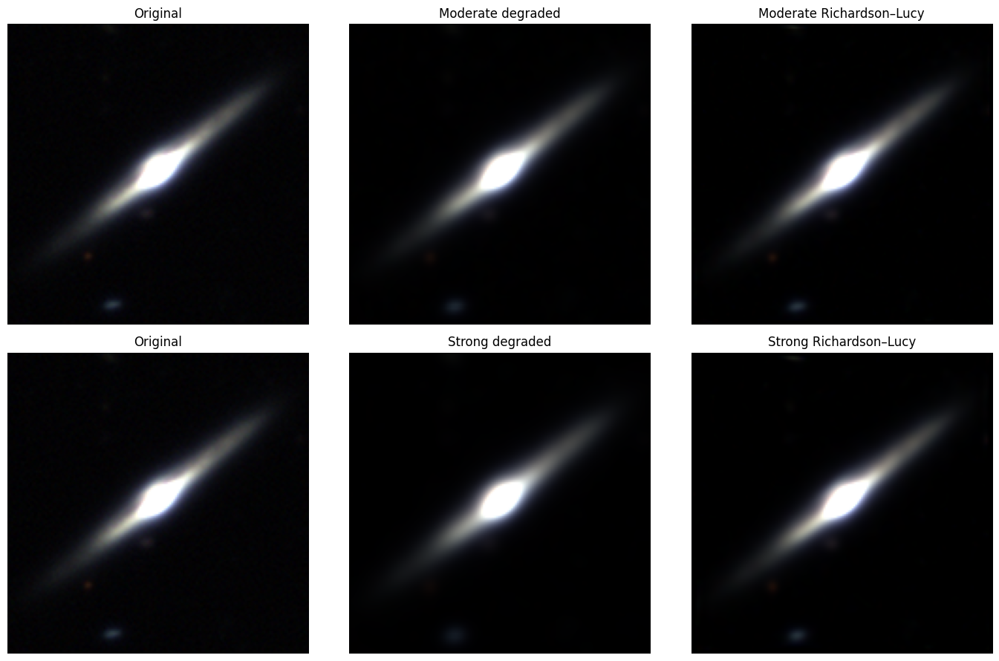

In [ ]:
from scipy.signal import fftconvolve
from scipy.ndimage import gaussian_filter
import numpy as np
import matplotlib.pyplot as plt

def richardson_lucy(observed, psf, iterations=30):
    observed = np.clip(observed, 0, None).astype(np.float32)

    psf = psf.astype(np.float32)
    psf /= psf.sum()
    psf_mirror = psf[::-1, ::-1]

    estimate = np.full_like(observed, observed.mean() + 1e-6)

    for _ in range(iterations):
        blurred = fftconvolve(
            estimate, psf, mode="same"
        )

        ratio = observed / (blurred + 1e-8)

        estimate *= fftconvolve(
            ratio, psf_mirror, mode="same"
        )

        estimate = np.clip(estimate, 0, None)

    return estimate.astype(np.float32)


def make_gaussian_psf(sigma, size=None):
    if size is None:
        size = int(np.ceil(sigma * 8)) | 1

    ax = np.arange(-(size // 2), size // 2 + 1)
    xx, yy = np.meshgrid(ax, ax)

    psf = np.exp(
        -(xx**2 + yy**2) / (2 * sigma**2)
    )

    return psf / psf.sum()


# Reconstruct Moderate and Strong cases
reconstructions = {}

for name, sigma in [
    ("Moderate", 1.5),
    ("Strong", 2.5),
]:

    idx = [x[0] for x in levels].index(name)
    observed = images[idx]

    psf = make_gaussian_psf(sigma)

    recon = np.empty_like(observed)

    for b in range(4):
        recon[b] = richardson_lucy(
            observed[b],
            psf,
            iterations=30
        )

    reconstructions[name] = recon

    print(
        f"{name}: "
        f"input={observed.shape}, "
        f"reconstruction={recon.shape}"
    )


def make_rgb(img):
    g, r, i, z = img

    def norm(v):
        lo, hi = np.nanpercentile(v, [1, 99])
        return np.clip((v - lo) / (hi - lo), 0, 1)

    return np.stack([
        norm(i),
        norm(r),
        norm(g)
    ], axis=-1)


# Visual comparison
fig, ax = plt.subplots(2, 3, figsize=(14, 9))

for row_idx, name in enumerate(["Moderate", "Strong"]):

    idx = [x[0] for x in levels].index(name)

    ax[row_idx, 0].imshow(make_rgb(x))
    ax[row_idx, 0].set_title("Original")
    ax[row_idx, 0].axis("off")

    ax[row_idx, 1].imshow(make_rgb(images[idx]))
    ax[row_idx, 1].set_title(f"{name} degraded")
    ax[row_idx, 1].axis("off")

    ax[row_idx, 2].imshow(
        make_rgb(reconstructions[name])
    )
    ax[row_idx, 2].set_title(
        f"{name} Richardson–Lucy"
    )
    ax[row_idx, 2].axis("off")

plt.tight_layout()
plt.show()

Moderate: (4, 160, 160), min=0, max=3.3637
Strong: (4, 160, 160), min=0, max=3.2404


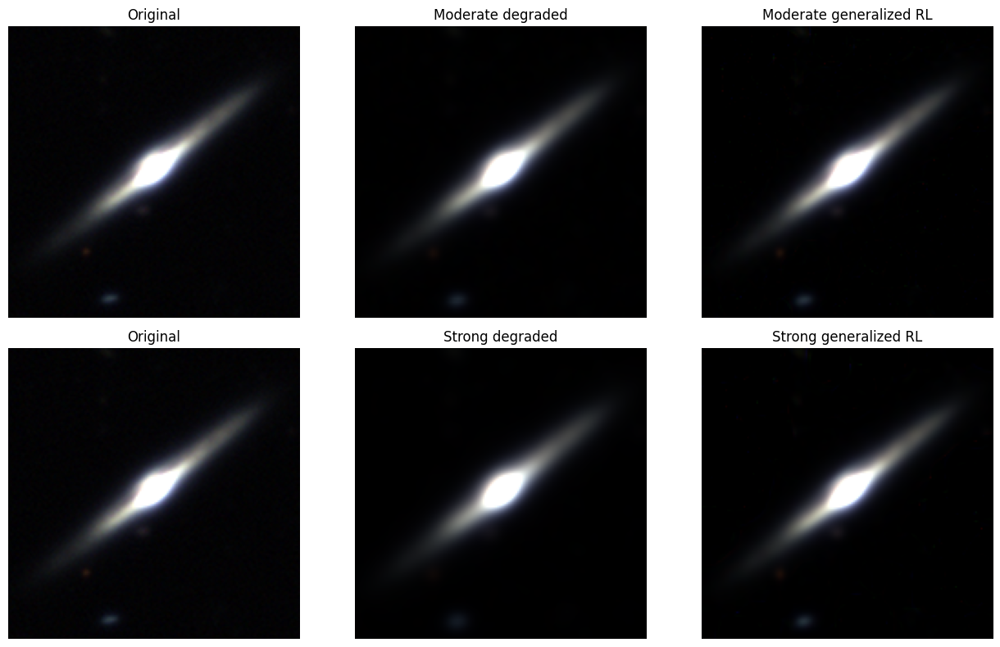

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

def forward_operator(img, sigma, factor=2):
    """Gaussian blur followed by decimation."""
    blurred = gaussian_filter(img, sigma=sigma)
    return blurred[::factor, ::factor]


def adjoint_operator(img, sigma, output_shape, factor=2):
    """Adjoint of decimation followed by Gaussian blur."""
    up = np.zeros(output_shape, dtype=np.float32)
    up[::factor, ::factor] = img
    return gaussian_filter(up, sigma=sigma)


def generalized_rl(observed, sigma, iterations=40, factor=2):
    """
    Generalized Richardson-Lucy for:
        y = D(Hx)
    """
    h, w = observed.shape

    estimate = np.full(
        (h * factor, w * factor),
        max(observed.mean(), 1e-6),
        dtype=np.float32
    )

    for _ in range(iterations):

        predicted = forward_operator(
            estimate, sigma, factor
        )

        ratio = observed / (
            predicted + 1e-8
        )

        correction = adjoint_operator(
            ratio,
            sigma,
            estimate.shape,
            factor
        )

        normalization = adjoint_operator(
            np.ones_like(observed),
            sigma,
            estimate.shape,
            factor
        )

        estimate *= correction / (
            normalization + 1e-8
        )

        estimate = np.clip(
            estimate, 0, None
        )

    return estimate


# Reconstruct the Moderate and Strong cases
proper_reconstructions = {}

for name, sigma in [
    ("Moderate", 1.5),
    ("Strong", 2.5)
]:

    idx = [v[0] for v in levels].index(name)
    observed_full = images[idx]

    # Recover the actual low-resolution observation
    observed_low = observed_full[:, ::2, ::2]

    recon = np.empty_like(x)

    for b in range(4):
        recon[b] = generalized_rl(
            observed_low[b],
            sigma=sigma,
            iterations=40,
            factor=2
        )

    proper_reconstructions[name] = recon

    print(
        f"{name}: {recon.shape}, "
        f"min={recon.min():.5g}, "
        f"max={recon.max():.5g}"
    )


def make_rgb(img):
    g, r, i, z = img

    def norm(v):
        lo, hi = np.nanpercentile(v, [1, 99])
        return np.clip(
            (v - lo) / (hi - lo),
            0, 1
        )

    return np.stack(
        [norm(i), norm(r), norm(g)],
        axis=-1
    )


fig, ax = plt.subplots(
    2, 3,
    figsize=(13, 8)
)

for row_idx, name in enumerate(
    ["Moderate", "Strong"]
):

    idx = [v[0] for v in levels].index(name)

    ax[row_idx, 0].imshow(make_rgb(x))
    ax[row_idx, 0].set_title("Original")
    ax[row_idx, 0].axis("off")

    ax[row_idx, 1].imshow(
        make_rgb(images[idx])
    )
    ax[row_idx, 1].set_title(
        f"{name} degraded"
    )
    ax[row_idx, 1].axis("off")

    ax[row_idx, 2].imshow(
        make_rgb(
            proper_reconstructions[name]
        )
    )
    ax[row_idx, 2].set_title(
        f"{name} generalized RL"
    )
    ax[row_idx, 2].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from aion.modalities import LegacySurveyImage

def image_metrics(reference, test, bar):
    psnr_values = []
    ssim_values = []

    yy, xx = np.where(bar)
    y1, y2 = yy.min(), yy.max() + 1
    x1, x2 = xx.min(), xx.max() + 1

    bar_rmse_values = []
    bar_ssim_values = []

    for b in range(4):
        ref = reference[b]
        obs = test[b]

        data_range = (
            np.nanpercentile(ref, 99.5)
            - np.nanpercentile(ref, 0.5)
        )

        psnr_values.append(
            peak_signal_noise_ratio(
                ref, obs, data_range=data_range
            )
        )

        ssim_values.append(
            structural_similarity(
                ref, obs, data_range=data_range
            )
        )

        bar_ref = ref[y1:y2, x1:x2]
        bar_obs = obs[y1:y2, x1:x2]

        bar_rmse_values.append(
            np.sqrt(np.mean((bar_ref - bar_obs) ** 2))
        )

        bar_range = (
            np.nanpercentile(bar_ref, 99.5)
            - np.nanpercentile(bar_ref, 0.5)
        )

        bar_ssim_values.append(
            structural_similarity(
                bar_ref,
                bar_obs,
                data_range=bar_range
            )
        )

    return {
        "PSNR": np.mean(psnr_values),
        "SSIM": np.mean(ssim_values),
        "bar_RMSE": np.mean(bar_rmse_values),
        "bar_SSIM": np.mean(bar_ssim_values),
    }


# Prepare images for evaluation
eval_images = {
    "Original": x,
    "Moderate degraded": images[
        [v[0] for v in levels].index("Moderate")
    ],
    "Moderate RL": proper_reconstructions["Moderate"],
    "Strong degraded": images[
        [v[0] for v in levels].index("Strong")
    ],
    "Strong RL": proper_reconstructions["Strong"],
}

# Pixel/morphology metrics
rows = []

for name, img in eval_images.items():
    m = image_metrics(x, img, aligned_bar)
    m["image"] = name
    rows.append(m)

metrics_df = pd.DataFrame(rows)[
    ["image", "PSNR", "SSIM", "bar_RMSE", "bar_SSIM"]
]

# AION embeddings for all five images
batch = torch.from_numpy(
    np.stack(list(eval_images.values()))
).float().to(device)

modality = LegacySurveyImage(
    flux=batch,
    bands=["DES-G", "DES-R", "DES-I", "DES-Z"]
)

with torch.no_grad():
    tokens = codec_manager.encode(modality)
    embeddings = model.encode(
        tokens,
        num_encoder_tokens=600
    )

reference_embedding = embeddings[0].flatten().unsqueeze(0)

aion_cos = []
aion_l2 = []

for i in range(len(eval_images)):
    current = embeddings[i].flatten().unsqueeze(0)

    aion_cos.append(
        F.cosine_similarity(
            reference_embedding,
            current
        ).item()
    )

    aion_l2.append(
        torch.norm(
            reference_embedding - current
        ).item()
    )

metrics_df["AION_cosine"] = aion_cos
metrics_df["AION_L2"] = aion_l2

print(
    metrics_df.to_string(
        index=False,
        float_format=lambda v: f"{v:.5f}"
    )
)

/usr/local/lib/python3.13/dist-packages/skimage/metrics/simple_metrics.py:168: RuntimeWarning: divide by zero encountered in scalar divide
  return 10 * np.log10((data_range**2) / err)


            image     PSNR    SSIM  bar_RMSE  bar_SSIM  AION_cosine   AION_L2
         Original      inf 1.00000   0.00000   1.00000      1.00000   0.00000
Moderate degraded 32.67457 0.97477   0.07995   0.93934      0.91826 482.97089
      Moderate RL 34.19353 0.97316   0.06554   0.96090      0.95974 343.34735
  Strong degraded 29.92932 0.96489   0.11104   0.88426      0.88011 581.19305
        Strong RL 33.92611 0.97231   0.06782   0.95803      0.95194 374.22437


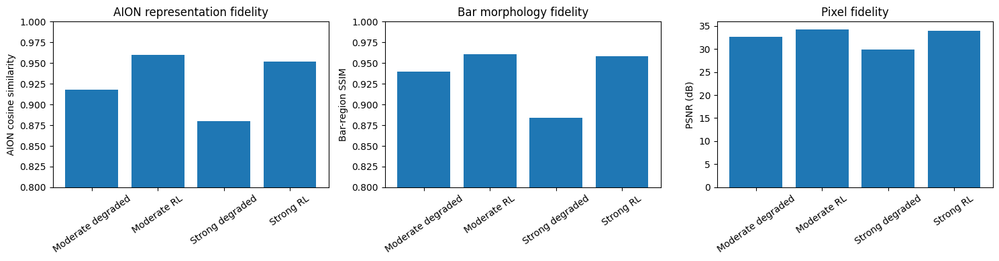

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Extract values from the reconstruction evaluation
names = [
    "Moderate degraded",
    "Moderate RL",
    "Strong degraded",
    "Strong RL"
]

subset = metrics_df[
    metrics_df["image"].isin(names)
].copy()

# Preserve desired order
subset["image"] = pd.Categorical(
    subset["image"],
    categories=names,
    ordered=True
)
subset = subset.sort_values("image")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# AION similarity
ax[0].bar(
    subset["image"],
    subset["AION_cosine"]
)
ax[0].set_ylabel("AION cosine similarity")
ax[0].set_title("AION representation fidelity")
ax[0].set_ylim(0.8, 1.0)
ax[0].tick_params(axis="x", rotation=35)

# Bar SSIM
ax[1].bar(
    subset["image"],
    subset["bar_SSIM"]
)
ax[1].set_ylabel("Bar-region SSIM")
ax[1].set_title("Bar morphology fidelity")
ax[1].set_ylim(0.8, 1.0)
ax[1].tick_params(axis="x", rotation=35)

# PSNR
ax[2].bar(
    subset["image"],
    subset["PSNR"]
)
ax[2].set_ylabel("PSNR (dB)")
ax[2].set_title("Pixel fidelity")
ax[2].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

candidates = []

for idx in range(len(ds)):
    r = ds[idx]

    bar = np.asarray(r["gz3d_segmentation"])[3]
    bar_pixels = np.count_nonzero(bar >= 1)

    if (
        r["gz_bar_votes"] >= 20
        and bar_pixels >= 100
        and np.isfinite(r["gz3d_ra"])
        and np.isfinite(r["gz3d_dec"])
    ):
        candidates.append({
            "idx": idx,
            "manga_id": r["manga_id"],
            "legacy_object_id": r["legacy_object_id"],
            "ra": r["gz3d_ra"],
            "dec": r["gz3d_dec"],
            "bar_votes": r["gz_bar_votes"],
            "spiral_votes": r["gz_spiral_votes"],
            "bar_pixels_gz3d": bar_pixels,
        })

candidates_df = pd.DataFrame(candidates)

sample_n = min(50, len(candidates_df))

sample_df = (
    candidates_df
    .sample(n=sample_n, random_state=42)
    .reset_index(drop=True)
)

print("Eligible galaxies:", len(candidates_df))
print("Selected galaxies:", len(sample_df))
print()
print(
    sample_df[
        [
            "manga_id",
            "legacy_object_id",
            "bar_votes",
            "spiral_votes",
            "bar_pixels_gz3d"
        ]
    ].head(10).to_string(index=False)
)

Eligible galaxies: 866
Selected galaxies: 50

manga_id legacy_object_id  bar_votes  spiral_votes  bar_pixels_gz3d
1-310020    1771p070-1511         23            30             4549
1-477040    1210p097-2498         31            30             2482
1-327467    2003p122-3810         27            31             2369
1-638623     1851p085-755         39            36             2249
1-478021    1254p110-4701         46            51              810
1-605451    1313p277-2877         26            21              590
1-549183     1981p032-121         40            40             1330
 1-36832    0408p002-5198         36            68             7007
1-302250    1545p120-4223         26            32             6982
 1-34675     0261p000-563         75            96             2431


In [ ]:
import os
import requests
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm.auto import tqdm

outdir = "/content/gz3d_dr10_sample"
os.makedirs(outdir, exist_ok=True)

def download_cutout(item):
    idx, row = item

    path = os.path.join(
        outdir,
        f"{idx:03d}_{row['manga_id']}.fits"
    )

    if os.path.exists(path):
        return idx, row["manga_id"], True, "exists"

    url = (
        "https://www.legacysurvey.org/viewer/cutout.fits"
        f"?ra={row['ra']}&dec={row['dec']}"
        "&layer=ls-dr10"
        "&pixscale=0.262"
        "&bands=griz"
        "&size=160"
    )

    try:
        r = requests.get(url, timeout=60)

        if r.status_code != 200:
            return idx, row["manga_id"], False, f"HTTP {r.status_code}"

        if len(r.content) < 10000:
            return idx, row["manga_id"], False, "response too small"

        with open(path, "wb") as f:
            f.write(r.content)

        return idx, row["manga_id"], True, "downloaded"

    except Exception as e:
        return idx, row["manga_id"], False, str(e)


items = list(sample_df.iterrows())

results = []

with ThreadPoolExecutor(max_workers=6) as executor:
    futures = [
        executor.submit(download_cutout, item)
        for item in items
    ]

    for future in tqdm(
        as_completed(futures),
        total=len(futures),
        desc="Downloading DR10 cutouts"
    ):
        results.append(future.result())

success = sum(r[2] for r in results)
failed = [r for r in results if not r[2]]

print(f"\nDownloaded/available: {success}/{len(results)}")

if failed:
    print("\nFailed downloads:")
    for r in failed:
        print(r)

print(
    f"\nDisk used by sample: "
    f"{sum(os.path.getsize(os.path.join(outdir, f)) for f in os.listdir(outdir)) / 1e6:.2f} MB"
)


Downloaded/available: 3/50

Failed downloads:
(1, '1-477040', False, 'HTTP 429')
(4, '1-478021', False, 'HTTP 429')
(5, '1-605451', False, 'HTTP 429')
(3, '1-638623', False, 'HTTP 429')
(6, '1-549183', False, 'HTTP 429')
(8, '1-302250', False, 'HTTP 429')
(7, '1-36832', False, 'HTTP 429')
(9, '1-34675', False, 'HTTP 429')
(10, '1-565491', False, 'HTTP 429')
(11, '1-27654', False, 'HTTP 429')
(12, '1-528037', False, 'HTTP 429')
(14, '1-550901', False, 'HTTP 429')
(13, '1-3714', False, 'HTTP 429')
(15, '1-505399', False, 'HTTP 429')
(16, '1-464288', False, 'HTTP 429')
(17, '1-38550', False, 'HTTP 429')
(18, '1-79504', False, 'HTTP 429')
(19, '1-567244', False, 'HTTP 429')
(20, '1-141860', False, 'HTTP 429')
(22, '1-465545', False, 'HTTP 429')
(21, '1-36562', False, 'HTTP 429')
(23, '1-104035', False, 'HTTP 429')
(24, '1-510750', False, 'HTTP 429')
(26, '1-67750', False, 'HTTP 429')
(27, '1-28915', False, 'HTTP 429')
(28, '1-551344', False, 'HTTP 429')
(29, '1-264890', False, 'HTTP 429')

In [ ]:
import os
import time
import random
import requests
from astropy.io import fits
from tqdm.auto import tqdm

outdir = "/content/gz3d_dr10_sample"

session = requests.Session()
session.headers.update({
    "User-Agent": "Mozilla/5.0 (research astronomy cutout retrieval)"
})

def download_one(idx, row, max_retries=5):

    path = os.path.join(
        outdir,
        f"{idx:03d}_{row['manga_id']}.fits"
    )

    # Already downloaded successfully
    if os.path.exists(path):
        try:
            with fits.open(path, memmap=False) as hdul:
                if hdul[0].data is not None and hdul[0].data.shape == (4, 160, 160):
                    return idx, row["manga_id"], True, "already valid"
        except Exception:
            os.remove(path)

    url = (
        "https://www.legacysurvey.org/viewer/cutout.fits"
        f"?ra={row['ra']}&dec={row['dec']}"
        "&layer=ls-dr10"
        "&pixscale=0.262"
        "&bands=griz"
        "&size=160"
    )

    for attempt in range(max_retries):

        try:
            r = session.get(url, timeout=60)

            if r.status_code == 200 and len(r.content) > 10000:

                with open(path, "wb") as f:
                    f.write(r.content)

                # Validate FITS immediately
                with fits.open(path, memmap=False) as hdul:
                    shape = hdul[0].data.shape

                if shape == (4, 160, 160):
                    return idx, row["manga_id"], True, "downloaded"

                os.remove(path)
                return idx, row["manga_id"], False, f"unexpected shape {shape}"

            if r.status_code == 429:
                wait = 5 * (2 ** attempt) + random.uniform(0, 3)
                print(
                    f"Rate limited for {row['manga_id']} "
                    f"(attempt {attempt+1}/{max_retries}); "
                    f"waiting {wait:.1f}s"
                )
                time.sleep(wait)
                continue

            return idx, row["manga_id"], False, f"HTTP {r.status_code}"

        except Exception as e:
            wait = 3 * (2 ** attempt)
            time.sleep(wait)

    return idx, row["manga_id"], False, "max retries exceeded"


# Retry only the missing files
results = []

for idx, row in tqdm(
    sample_df.iterrows(),
    total=len(sample_df),
    desc="Retrying DR10 cutouts"
):
    result = download_one(idx, row)
    results.append(result)

    # Small pause between successful requests
    time.sleep(1.5)

success = sum(r[2] for r in results)
failed = [r for r in results if not r[2]]

print(f"\nValid FITS files: {success}/{len(results)}")

if failed:
    print("\nStill failed:")
    for r in failed:
        print(r)

total_mb = sum(
    os.path.getsize(os.path.join(outdir, f))
    for f in os.listdir(outdir)
) / 1e6

print(f"\nDisk used by sample: {total_mb:.2f} MB")

Retrying DR10 cutouts:   0%|          | 0/50 [00:00<?, ?it/s]


Valid FITS files: 50/50

Disk used by sample: 20.74 MB


In [ ]:
from astropy.io import fits
import numpy as np
import pandas as pd
import os

outdir = "/content/gz3d_dr10_sample"

qc = []

for idx, r in sample_df.iterrows():

    path = os.path.join(
        outdir,
        f"{idx:03d}_{r['manga_id']}.fits"
    )

    record = {
        "idx": idx,
        "manga_id": r["manga_id"],
        "legacy_id": r["legacy_object_id"],
        "bar_votes": r["bar_votes"],
        "bar_pixels_gz3d": r["bar_pixels_gz3d"],
        "file_ok": os.path.exists(path),
    }

    if not record["file_ok"]:
        qc.append(record)
        continue

    try:
        with fits.open(path, memmap=False) as hdul:

            data_i = hdul[0].data
            header = hdul[0].header

            record["shape"] = str(data_i.shape)
            record["finite"] = bool(np.isfinite(data_i).all())
            record["bands"] = header.get("BANDS", "")
            record["ra_error_arcsec"] = abs(
                header.get("CRVAL1", np.nan) - r["ra"]
            ) * 3600.0

            record["dec_error_arcsec"] = abs(
                header.get("CRVAL2", np.nan) - r["dec"]
            ) * 3600.0

            record["valid_shape"] = data_i.shape == (160, 160, 4)

            # GZ3D bar mask
            seg = np.asarray(
                ds[int(r["idx"])]["gz3d_segmentation"]
            )

            bar = seg[3]
            bar_mask = bar >= 1

            # Convert GZ3D scale -> Legacy Survey scale
            scale_factor = 0.099 / 0.262

            from scipy.ndimage import zoom

            bar_resampled = zoom(
                bar_mask.astype(np.uint8),
                scale_factor,
                order=0
            ).astype(bool)

            h, w = bar_resampled.shape

            record["resampled_bar_shape"] = f"{h}x{w}"
            record["aligned_bar_pixels"] = int(
                bar_resampled.sum()
            )

            record["mask_ok"] = (
                h <= 160 and
                w <= 160 and
                record["aligned_bar_pixels"] > 0
            )

    except Exception as e:
        record["error"] = str(e)

    qc.append(record)

qc_df = pd.DataFrame(qc)

print("Sample QC")
print("=" * 70)

print(
    "Valid FITS:",
    int(
        (
            qc_df["file_ok"] &
            qc_df["valid_shape"] &
            qc_df["finite"] &
            qc_df["mask_ok"]
        ).sum()
    ),
    "/",
    len(qc_df)
)

print(
    "Maximum RA error:",
    qc_df["ra_error_arcsec"].max(),
    "arcsec"
)

print(
    "Maximum Dec error:",
    qc_df["dec_error_arcsec"].max(),
    "arcsec"
)

print("\nShape counts:")
print(qc_df["shape"].value_counts())

print("\nBand counts:")
print(qc_df["bands"].value_counts())

print("\nFirst 10:")
print(
    qc_df[
        [
            "manga_id",
            "bar_votes",
            "bar_pixels_gz3d",
            "shape",
            "bands",
            "aligned_bar_pixels"
        ]
    ].head(10).to_string(index=False)
)

Sample QC
Valid FITS: 0 / 50
Maximum RA error: 0.0 arcsec
Maximum Dec error: 0.0 arcsec

Shape counts:
shape
(4, 160, 160)    50
Name: count, dtype: int64

Band counts:
bands
griz    50
Name: count, dtype: int64

First 10:
manga_id  bar_votes  bar_pixels_gz3d         shape bands  aligned_bar_pixels
1-310020         23             4549 (4, 160, 160)  griz                 618
1-477040         31             2482 (4, 160, 160)  griz                 333
1-327467         27             2369 (4, 160, 160)  griz                 322
1-638623         39             2249 (4, 160, 160)  griz                 302
1-478021         46              810 (4, 160, 160)  griz                 111
1-605451         26              590 (4, 160, 160)  griz                  82
1-549183         40             1330 (4, 160, 160)  griz                 183
 1-36832         36             7007 (4, 160, 160)  griz                 971
1-302250         26             6982 (4, 160, 160)  griz                 956
 1-3467

In [ ]:
# Corrected QC: FITS data are (4, 160, 160)

qc_df["valid_shape"] = qc_df["shape"].astype(str).eq("(4, 160, 160)")

valid = (
    qc_df["file_ok"]
    & qc_df["valid_shape"]
    & qc_df["finite"]
    & qc_df["mask_ok"]
)

print("Sample QC")
print("=" * 70)

print(f"Valid galaxies: {valid.sum()} / {len(qc_df)}")
print(f"Invalid galaxies: {(~valid).sum()}")

print("\nShape counts:")
print(qc_df["shape"].value_counts())

print("\nBand counts:")
print(qc_df["bands"].value_counts())

print("\nMaximum RA error:",
      qc_df["ra_error_arcsec"].max(), "arcsec")

print("Maximum Dec error:",
      qc_df["dec_error_arcsec"].max(), "arcsec")

if (~valid).sum() > 0:
    print("\nInvalid entries:")
    print(
        qc_df.loc[
            ~valid,
            ["idx", "manga_id", "shape", "bands", "error"]
        ].to_string(index=False)
    )

Sample QC
Valid galaxies: 50 / 50
Invalid galaxies: 0

Shape counts:
shape
(4, 160, 160)    50
Name: count, dtype: int64

Band counts:
bands
griz    50
Name: count, dtype: int64

Maximum RA error: 0.0 arcsec
Maximum Dec error: 0.0 arcsec


In [ ]:
import os
import numpy as np
import pandas as pd
from astropy.io import fits
from scipy.ndimage import gaussian_filter, zoom
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

SIGMA = 1.5
DOWNSAMPLE = 2

sample_results = []
images_original = []
images_degraded = []
bar_masks = []

def safe_ssim(ref, obs):
    """SSIM with an automatically valid window size."""
    h, w = ref.shape
    min_dim = min(h, w)

    if min_dim < 3:
        return np.nan

    win_size = min(7, min_dim)

    if win_size % 2 == 0:
        win_size -= 1

    return structural_similarity(
        ref,
        obs,
        data_range=np.ptp(ref),
        win_size=win_size
    )


for idx, r in sample_df.iterrows():

    path = os.path.join(
        "/content/gz3d_dr10_sample",
        f"{idx:03d}_{r['manga_id']}.fits"
    )

    with fits.open(path, memmap=False) as hdul:
        original = hdul[0].data.astype(np.float32)

    # ------------------------------------------------------------
    # Controlled degradation
    # ------------------------------------------------------------

    blurred = np.empty_like(original)

    for b in range(4):
        blurred[b] = gaussian_filter(
            original[b],
            sigma=SIGMA
        )

    low = blurred[:, ::DOWNSAMPLE, ::DOWNSAMPLE]

    degraded = zoom(
        low,
        (1, DOWNSAMPLE, DOWNSAMPLE),
        order=1
    ).astype(np.float32)

    # ------------------------------------------------------------
    # GZ3D bar mask
    # ------------------------------------------------------------

    seg = np.asarray(
        ds[int(r["idx"])]["gz3d_segmentation"]
    )

    bar = seg[3] >= 1

    # GZ3D: 0.099 arcsec/pixel
    # Legacy Survey: 0.262 arcsec/pixel

    bar_small = zoom(
        bar.astype(np.uint8),
        0.099 / 0.262,
        order=0
    ).astype(bool)

    aligned_bar = np.zeros(
        (160, 160),
        dtype=bool
    )

    h, w = bar_small.shape

    y0 = (160 - h) // 2
    x0 = (160 - w) // 2

    # Safety against unusual mask sizes
    y_start = max(0, y0)
    x_start = max(0, x0)

    y_end = min(160, y0 + h)
    x_end = min(160, x0 + w)

    aligned_bar[
        y_start:y_end,
        x_start:x_end
    ] = bar_small[
        y_start-y0:y_end-y0,
        x_start-x0:x_end-x0
    ]

    # ------------------------------------------------------------
    # Global image metrics
    # ------------------------------------------------------------

    psnr_values = []
    ssim_values = []

    for b in range(4):

        ref = original[b]
        obs = degraded[b]

        data_range = np.percentile(
            ref, 99.5
        ) - np.percentile(
            ref, 0.5
        )

        psnr_values.append(
            peak_signal_noise_ratio(
                ref,
                obs,
                data_range=data_range
            )
        )

        ssim_values.append(
            structural_similarity(
                ref,
                obs,
                data_range=data_range
            )
        )

    # ------------------------------------------------------------
    # Bar-region metrics
    # ------------------------------------------------------------

    yy, xx = np.where(aligned_bar)

    if len(yy) > 0:

        bar_rmse = np.sqrt(
            np.mean(
                (
                    original[:, aligned_bar]
                    - degraded[:, aligned_bar]
                ) ** 2
            )
        )

        # Bounding box around the GZ3D bar
        y1, y2 = yy.min(), yy.max() + 1
        x1, x2 = xx.min(), xx.max() + 1

        bar_ssim_values = []

        for b in range(4):

            ref_crop = original[
                b, y1:y2, x1:x2
            ]

            obs_crop = degraded[
                b, y1:y2, x1:x2
            ]

            score = safe_ssim(
                ref_crop,
                obs_crop
            )

            bar_ssim_values.append(score)

        bar_ssim = np.nanmean(
            bar_ssim_values
        )

    else:
        bar_rmse = np.nan
        bar_ssim = np.nan

    # ------------------------------------------------------------
    # Store
    # ------------------------------------------------------------

    sample_results.append({
        "idx": idx,
        "manga_id": r["manga_id"],
        "bar_votes": r["bar_votes"],
        "PSNR": np.mean(psnr_values),
        "SSIM": np.mean(ssim_values),
        "bar_RMSE": bar_rmse,
        "bar_SSIM": bar_ssim,
        "bar_pixels": len(yy)
    })

    images_original.append(original)
    images_degraded.append(degraded)
    bar_masks.append(aligned_bar)


pixel_df = pd.DataFrame(sample_results)

print(f"Processed: {len(pixel_df)} / 50 galaxies")
print()

print(
    pixel_df[
        [
            "PSNR",
            "SSIM",
            "bar_RMSE",
            "bar_SSIM",
            "bar_pixels"
        ]
    ].describe().round(4)
)

print()
print(
    "Missing bar SSIM:",
    pixel_df["bar_SSIM"].isna().sum()
)

Processed: 50 / 50 galaxies

          PSNR     SSIM  bar_RMSE  bar_SSIM  bar_pixels
count  50.0000  50.0000   50.0000   50.0000     50.0000
mean   30.9416   0.9277    0.2965    0.9269    303.0000
std     2.8810   0.0854    0.2165    0.0421    265.9127
min    26.0935   0.6083    0.0180    0.8252     60.0000
25%    28.8120   0.9109    0.0952    0.8944    131.7500
50%    30.5130   0.9526    0.2600    0.9388    201.5000
75%    32.8396   0.9782    0.4609    0.9586    342.0000
max    38.3625   0.9938    0.7825    0.9822   1271.0000

Missing bar SSIM: 0


In [ ]:
import torch
import torch.nn.functional as F
import numpy as np

# ------------------------------------------------------------
# Prepare image arrays
# ------------------------------------------------------------

X_original = np.stack(images_original).astype(np.float32)
X_degraded = np.stack(images_degraded).astype(np.float32)

print("Original:", X_original.shape)
print("Degraded:", X_degraded.shape)

# ------------------------------------------------------------
# AION embedding helper
# ------------------------------------------------------------

def get_aion_embeddings(images, batch_size=5):

    all_embeddings = []

    for start in range(0, len(images), batch_size):

        batch = torch.from_numpy(
            images[start:start + batch_size]
        ).float().cuda()

        image_modality = LegacySurveyImage(
            flux=batch,
            bands=["DES-G", "DES-R", "DES-I", "DES-Z"]
        )

        with torch.no_grad():
            tokens = codec_manager.encode(
                image_modality
            )

            emb = model.encode(
                tokens,
                num_encoder_tokens=600
            )

        # Flatten token × embedding dimension
        emb = emb.float().flatten(
            start_dim=1
        )

        all_embeddings.append(
            emb.cpu()
        )

        print(
            f"{min(start + batch_size, len(images)):3d}"
            f"/{len(images)}",
            end="\r"
        )

        del batch, image_modality, tokens, emb
        torch.cuda.empty_cache()

    print()

    return torch.cat(
        all_embeddings,
        dim=0
    )


# ------------------------------------------------------------
# Extract AION embeddings
# ------------------------------------------------------------

print("Extracting AION embeddings...")

aion_original = get_aion_embeddings(
    X_original,
    batch_size=5
)

aion_degraded = get_aion_embeddings(
    X_degraded,
    batch_size=5
)

print()
print("Original embeddings:", aion_original.shape)
print("Degraded embeddings:", aion_degraded.shape)


# ------------------------------------------------------------
# AION similarity
# ------------------------------------------------------------

cosine_similarity = F.cosine_similarity(
    aion_original,
    aion_degraded,
    dim=1
).numpy()

aion_l2 = torch.linalg.vector_norm(
    aion_original - aion_degraded,
    dim=1
).numpy()


# ------------------------------------------------------------
# Add to results
# ------------------------------------------------------------

pixel_df["AION_cosine"] = cosine_similarity
pixel_df["AION_L2"] = aion_l2

print()
print(
    pixel_df[
        [
            "PSNR",
            "SSIM",
            "bar_RMSE",
            "bar_SSIM",
            "AION_cosine",
            "AION_L2"
        ]
    ].describe().round(4)
)

Original: (50, 4, 160, 160)
Degraded: (50, 4, 160, 160)
Extracting AION embeddings...
 50/50
 50/50

Original embeddings: torch.Size([50, 442368])
Degraded embeddings: torch.Size([50, 442368])

          PSNR     SSIM  bar_RMSE  bar_SSIM  AION_cosine   AION_L2
count  50.0000  50.0000   50.0000   50.0000      50.0000   50.0000
mean   30.9416   0.9277    0.2965    0.9269       0.9499  332.1848
std     2.8810   0.0854    0.2165    0.0421       0.0195   82.5234
min    26.0935   0.6083    0.0180    0.8252       0.9018  136.3278
25%    28.8120   0.9109    0.0952    0.8944       0.9423  296.7226
50%    30.5130   0.9526    0.2600    0.9388       0.9489  335.8390
75%    32.8396   0.9782    0.4609    0.9586       0.9617  370.7741
max    38.3625   0.9938    0.7825    0.9822       0.9901  515.9142


In [ ]:
from scipy.stats import pearsonr, spearmanr

pairs = [
    ("AION_cosine", "bar_SSIM"),
    ("AION_cosine", "bar_RMSE"),
    ("AION_cosine", "SSIM"),
    ("AION_L2", "bar_RMSE"),
    ("AION_L2", "bar_SSIM"),
    ("AION_L2", "SSIM"),
]

corr_results = []

for x, y in pairs:

    valid = pixel_df[[x, y]].dropna()

    pearson_r, pearson_p = pearsonr(
        valid[x],
        valid[y]
    )

    spearman_r, spearman_p = spearmanr(
        valid[x],
        valid[y]
    )

    corr_results.append({
        "AION_metric": x,
        "image_metric": y,
        "Pearson_r": pearson_r,
        "Pearson_p": pearson_p,
        "Spearman_rho": spearman_r,
        "Spearman_p": spearman_p,
        "N": len(valid)
    })

corr_df = pd.DataFrame(corr_results)

print(
    corr_df.round(4).to_string(index=False)
)

AION_metric image_metric  Pearson_r  Pearson_p  Spearman_rho  Spearman_p  N
AION_cosine     bar_SSIM     0.4858     0.0003        0.3976      0.0042 50
AION_cosine     bar_RMSE    -0.0392     0.7869       -0.0872      0.5473 50
AION_cosine         SSIM     0.1520     0.2919        0.3368      0.0168 50
    AION_L2     bar_RMSE     0.0377     0.7949        0.0797      0.5824 50
    AION_L2     bar_SSIM    -0.5202     0.0001       -0.4309      0.0018 50
    AION_L2         SSIM    -0.1715     0.2336       -0.3407      0.0155 50


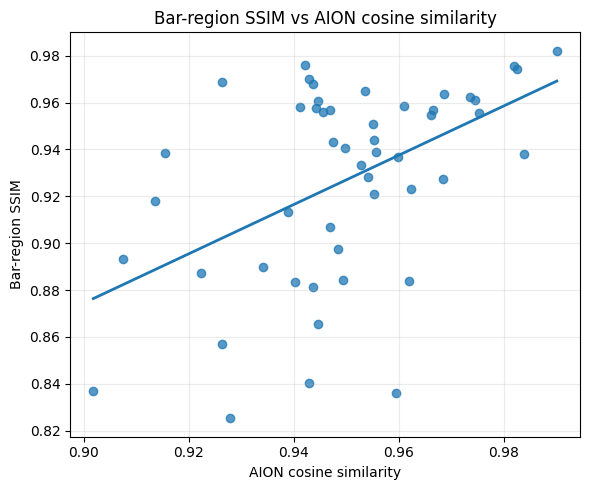

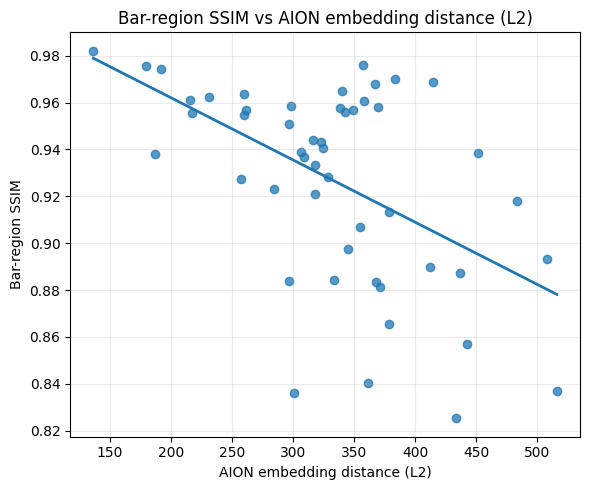

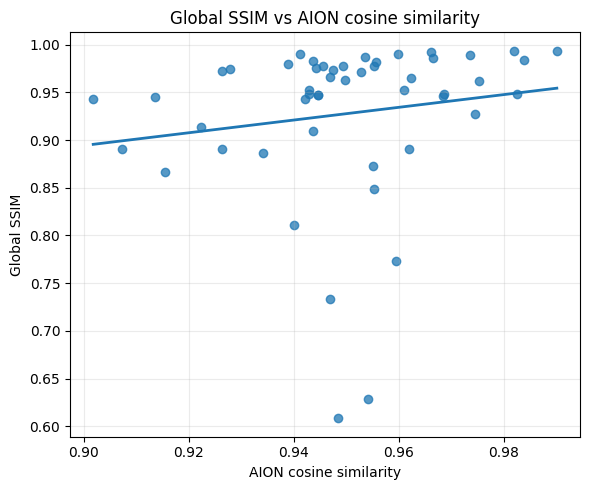

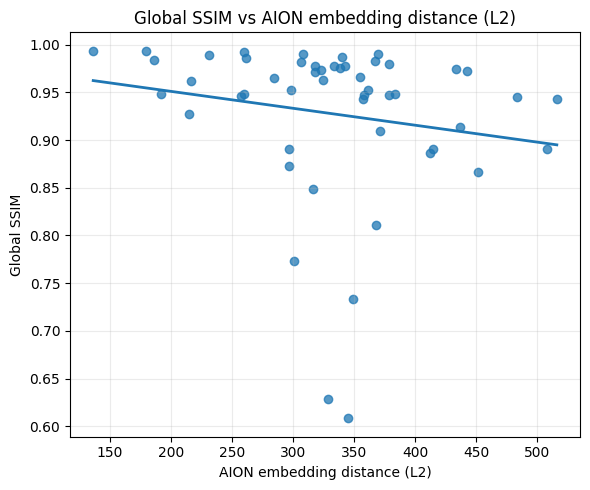

In [ ]:
import matplotlib.pyplot as plt

figures = [
    ("AION_cosine", "bar_SSIM",
     "AION cosine similarity", "Bar-region SSIM"),

    ("AION_L2", "bar_SSIM",
     "AION embedding distance (L2)", "Bar-region SSIM"),

    ("AION_cosine", "SSIM",
     "AION cosine similarity", "Global SSIM"),

    ("AION_L2", "SSIM",
     "AION embedding distance (L2)", "Global SSIM"),
]

for x, y, xlabel, ylabel in figures:

    plt.figure(figsize=(6, 5))

    plt.scatter(
        pixel_df[x],
        pixel_df[y],
        alpha=0.75
    )

    # Linear trend
    valid = pixel_df[[x, y]].dropna()

    if len(valid) > 1:
        coeff = np.polyfit(
            valid[x],
            valid[y],
            1
        )

        xx = np.linspace(
            valid[x].min(),
            valid[x].max(),
            100
        )

        yy = np.polyval(
            coeff,
            xx
        )

        plt.plot(
            xx,
            yy,
            linewidth=2
        )

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(f"{ylabel} vs {xlabel}")
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

In [ ]:
import os
import numpy as np
import pandas as pd
from astropy.io import fits
from scipy.ndimage import gaussian_filter, zoom
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

DEGRADATIONS = {
    "mild": 0.75,
    "moderate": 1.5,
    "strong": 2.5,
    "very_strong": 4.0
}

DOWNSAMPLE = 2

multi_results = []


def make_degraded(original, sigma, factor=2):

    blurred = np.empty_like(original)

    for b in range(4):
        blurred[b] = gaussian_filter(
            original[b],
            sigma=sigma
        )

    low = blurred[:, ::factor, ::factor]

    degraded = zoom(
        low,
        (1, factor, factor),
        order=1
    ).astype(np.float32)

    return degraded


def compute_metrics(original, degraded, bar_mask):

    psnr_values = []
    ssim_values = []

    for b in range(4):

        ref = original[b]
        obs = degraded[b]

        data_range = (
            np.percentile(ref, 99.5)
            - np.percentile(ref, 0.5)
        )

        psnr_values.append(
            peak_signal_noise_ratio(
                ref,
                obs,
                data_range=data_range
            )
        )

        ssim_values.append(
            structural_similarity(
                ref,
                obs,
                data_range=data_range
            )
        )

    # Bar pixels
    yy, xx = np.where(bar_mask)

    if len(yy) > 0:

        bar_rmse = np.sqrt(
            np.mean(
                (
                    original[:, bar_mask]
                    - degraded[:, bar_mask]
                ) ** 2
            )
        )

        y1, y2 = yy.min(), yy.max() + 1
        x1, x2 = xx.min(), xx.max() + 1

        bar_ssim_values = []

        for b in range(4):

            ref_crop = original[
                b, y1:y2, x1:x2
            ]

            obs_crop = degraded[
                b, y1:y2, x1:x2
            ]

            min_dim = min(
                ref_crop.shape
            )

            if min_dim >= 3:

                win_size = min(7, min_dim)

                if win_size % 2 == 0:
                    win_size -= 1

                data_range = np.ptp(ref_crop)

                if data_range > 0:

                    score = structural_similarity(
                        ref_crop,
                        obs_crop,
                        data_range=data_range,
                        win_size=win_size
                    )

                else:
                    score = np.nan

            else:
                score = np.nan

            bar_ssim_values.append(score)

        bar_ssim = np.nanmean(
            bar_ssim_values
        )

    else:
        bar_rmse = np.nan
        bar_ssim = np.nan

    return (
        np.mean(psnr_values),
        np.mean(ssim_values),
        bar_rmse,
        bar_ssim
    )


# ============================================================
# Process every degradation level
# ============================================================

for level, sigma in DEGRADATIONS.items():

    print(f"\nProcessing: {level} (sigma={sigma})")

    degraded_images = []
    level_pixel_results = []

    for idx, r in sample_df.iterrows():

        path = os.path.join(
            "/content/gz3d_dr10_sample",
            f"{idx:03d}_{r['manga_id']}.fits"
        )

        with fits.open(path, memmap=False) as hdul:
            original = hdul[0].data.astype(
                np.float32
            )

        degraded = make_degraded(
            original,
            sigma,
            DOWNSAMPLE
        )

        # ----------------------------------------------------
        # Reconstruct aligned GZ3D bar mask
        # ----------------------------------------------------

        seg = np.asarray(
            ds[int(r["idx"])]["gz3d_segmentation"]
        )

        bar = seg[3] >= 1

        bar_small = zoom(
            bar.astype(np.uint8),
            0.099 / 0.262,
            order=0
        ).astype(bool)

        aligned_bar = np.zeros(
            (160, 160),
            dtype=bool
        )

        h, w = bar_small.shape

        y0 = (160 - h) // 2
        x0 = (160 - w) // 2

        y_start = max(0, y0)
        x_start = max(0, x0)

        y_end = min(160, y0 + h)
        x_end = min(160, x0 + w)

        aligned_bar[
            y_start:y_end,
            x_start:x_end
        ] = bar_small[
            y_start-y0:y_end-y0,
            x_start-x0:x_end-x0
        ]

        psnr, ssim, bar_rmse, bar_ssim = compute_metrics(
            original,
            degraded,
            aligned_bar
        )

        level_pixel_results.append({
            "idx": idx,
            "manga_id": r["manga_id"],
            "degradation": level,
            "sigma": sigma,
            "PSNR": psnr,
            "SSIM": ssim,
            "bar_RMSE": bar_rmse,
            "bar_SSIM": bar_ssim
        })

        degraded_images.append(
            degraded
        )

    # --------------------------------------------------------
    # AION
    # --------------------------------------------------------

    degraded_images = np.stack(
        degraded_images
    ).astype(np.float32)

    print(
        "AION input:",
        degraded_images.shape
    )

    emb_degraded = get_aion_embeddings(
        degraded_images,
        batch_size=5
    )

    cosine = torch.nn.functional.cosine_similarity(
        aion_original,
        emb_degraded,
        dim=1
    ).numpy()

    l2 = torch.linalg.vector_norm(
        aion_original - emb_degraded,
        dim=1
    ).numpy()

    # --------------------------------------------------------
    # Merge
    # --------------------------------------------------------

    level_df = pd.DataFrame(
        level_pixel_results
    )

    level_df["AION_cosine"] = cosine
    level_df["AION_L2"] = l2

    multi_results.append(
        level_df
    )

    print(
        level_df[
            [
                "PSNR",
                "SSIM",
                "bar_SSIM",
                "AION_cosine",
                "AION_L2"
            ]
        ].mean().round(4).to_dict()
    )

    del degraded_images
    del emb_degraded

multi_df = pd.concat(
    multi_results,
    ignore_index=True
)

print("\n========================================")
print("MULTI-LEVEL EXPERIMENT COMPLETE")
print("========================================")

print(
    multi_df.groupby("degradation")[
        [
            "PSNR",
            "SSIM",
            "bar_RMSE",
            "bar_SSIM",
            "AION_cosine",
            "AION_L2"
        ]
    ].mean().round(4)
)


Processing: mild (sigma=0.75)
AION input: (50, 4, 160, 160)
 50/50
{'PSNR': 32.8026, 'SSIM': 0.9367, 'bar_SSIM': 0.9602, 'AION_cosine': 0.9604, 'AION_L2': 295.1281}

Processing: moderate (sigma=1.5)
AION input: (50, 4, 160, 160)
 50/50
{'PSNR': 30.9416, 'SSIM': 0.9277, 'bar_SSIM': 0.9269, 'AION_cosine': 0.9499, 'AION_L2': 332.1848}

Processing: strong (sigma=2.5)
AION input: (50, 4, 160, 160)
 50/50
{'PSNR': 27.9797, 'SSIM': 0.9162, 'bar_SSIM': 0.8297, 'AION_cosine': 0.9318, 'AION_L2': 386.9638}

Processing: very_strong (sigma=4.0)
AION input: (50, 4, 160, 160)
 50/50
{'PSNR': 24.8283, 'SSIM': 0.8994, 'bar_SSIM': 0.6451, 'AION_cosine': 0.9165, 'AION_L2': 427.6378}

MULTI-LEVEL EXPERIMENT COMPLETE
                PSNR    SSIM  bar_RMSE  bar_SSIM  AION_cosine     AION_L2
degradation                                                              
mild         32.8026  0.9367    0.2248    0.9602       0.9604  295.128113
moderate     30.9416  0.9277    0.2965    0.9269       0.9499  332.1848

In [ ]:
from scipy.stats import pearsonr, spearmanr
import numpy as np
import pandas as pd

# ============================================================
# 1. Pooled correlations
# ============================================================

pooled_pairs = [
    ("AION_cosine", "bar_SSIM"),
    ("AION_L2", "bar_SSIM"),
    ("AION_cosine", "bar_RMSE"),
    ("AION_L2", "bar_RMSE"),
]

pooled_results = []

for x, y in pooled_pairs:

    d = multi_df[[x, y]].dropna()

    pr, pp = pearsonr(d[x], d[y])
    sr, sp = spearmanr(d[x], d[y])

    pooled_results.append({
        "x": x,
        "y": y,
        "Pearson_r": pr,
        "Pearson_p": pp,
        "Spearman_rho": sr,
        "Spearman_p": sp,
        "N": len(d)
    })

pooled_df = pd.DataFrame(pooled_results)

print("POOLED CORRELATIONS")
print(pooled_df.round(4).to_string(index=False))


# ============================================================
# 2. Within-galaxy correlations
# ============================================================

within_results = []

for manga_id, g in multi_df.groupby("manga_id"):

    if len(g) < 3:
        continue

    # AION cosine vs bar SSIM
    pr1, _ = pearsonr(
        g["AION_cosine"],
        g["bar_SSIM"]
    )

    sr1, _ = spearmanr(
        g["AION_cosine"],
        g["bar_SSIM"]
    )

    # AION L2 vs bar SSIM
    pr2, _ = pearsonr(
        g["AION_L2"],
        g["bar_SSIM"]
    )

    sr2, _ = spearmanr(
        g["AION_L2"],
        g["bar_SSIM"]
    )

    within_results.append({
        "manga_id": manga_id,
        "cosine_barSSIM_pearson": pr1,
        "cosine_barSSIM_spearman": sr1,
        "L2_barSSIM_pearson": pr2,
        "L2_barSSIM_spearman": sr2
    })

within_df = pd.DataFrame(within_results)

print("\nWITHIN-GALAXY CORRELATIONS")
print(
    within_df[
        [
            "cosine_barSSIM_pearson",
            "cosine_barSSIM_spearman",
            "L2_barSSIM_pearson",
            "L2_barSSIM_spearman"
        ]
    ].describe().round(4)
)


# ============================================================
# 3. Change relative to mild degradation
# ============================================================

baseline = (
    multi_df[
        multi_df["degradation"] == "mild"
    ][
        [
            "manga_id",
            "bar_SSIM",
            "AION_cosine",
            "AION_L2"
        ]
    ]
    .rename(columns={
        "bar_SSIM": "bar_SSIM_mild",
        "AION_cosine": "AION_cosine_mild",
        "AION_L2": "AION_L2_mild"
    })
)

delta_df = multi_df.merge(
    baseline,
    on="manga_id",
    how="left"
)

delta_df["delta_bar_SSIM"] = (
    delta_df["bar_SSIM"]
    - delta_df["bar_SSIM_mild"]
)

delta_df["delta_AION_cosine"] = (
    delta_df["AION_cosine"]
    - delta_df["AION_cosine_mild"]
)

delta_df["delta_AION_L2"] = (
    delta_df["AION_L2"]
    - delta_df["AION_L2_mild"]
)

# Remove mild-vs-mild zero differences
delta_df = delta_df[
    delta_df["degradation"] != "mild"
].copy()

print("\nDELTA CORRELATIONS")

for x, y in [
    ("delta_AION_cosine", "delta_bar_SSIM"),
    ("delta_AION_L2", "delta_bar_SSIM")
]:

    d = delta_df[[x, y]].dropna()

    pr, pp = pearsonr(d[x], d[y])
    sr, sp = spearmanr(d[x], d[y])

    print(
        f"{x} vs {y}: "
        f"Pearson r={pr:.4f} (p={pp:.4g}), "
        f"Spearman rho={sr:.4f} (p={sp:.4g}), "
        f"N={len(d)}"
    )

POOLED CORRELATIONS
          x        y  Pearson_r  Pearson_p  Spearman_rho  Spearman_p   N
AION_cosine bar_SSIM     0.6598     0.0000        0.6958      0.0000 200
    AION_L2 bar_SSIM    -0.6207     0.0000       -0.6591      0.0000 200
AION_cosine bar_RMSE    -0.2200     0.0017       -0.2321      0.0009 200
    AION_L2 bar_RMSE     0.1934     0.0061        0.2039      0.0038 200

WITHIN-GALAXY CORRELATIONS
       cosine_barSSIM_pearson  cosine_barSSIM_spearman  L2_barSSIM_pearson  \
count                 50.0000                  50.0000             50.0000   
mean                   0.9235                   0.9680             -0.9138   
std                    0.1111                   0.0741              0.1001   
min                    0.4244                   0.8000             -0.9976   
25%                    0.9089                   1.0000             -0.9723   
50%                    0.9629                   1.0000             -0.9415   
75%                    0.9848            

In [ ]:
import os
import numpy as np
import pandas as pd
from astropy.io import fits
from scipy.ndimage import gaussian_filter, zoom
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

RECON_LEVELS = {
    "moderate": 1.5,
    "strong": 2.5,
    "very_strong": 4.0
}

DOWNSAMPLE = 2
RL_ITERATIONS = 20
EPS = 1e-8


# ============================================================
# Forward model: blur + downsample
# ============================================================

def forward_operator(x, sigma):

    blurred = np.empty_like(x)

    for b in range(4):
        blurred[b] = gaussian_filter(
            x[b],
            sigma=sigma
        )

    return blurred[:, ::DOWNSAMPLE, ::DOWNSAMPLE]


# ============================================================
# Adjoint operator
# ============================================================

def adjoint_operator(y, sigma):

    up = np.zeros(
        (4, 160, 160),
        dtype=np.float32
    )

    up[:, ::DOWNSAMPLE, ::DOWNSAMPLE] = y

    result = np.empty_like(up)

    for b in range(4):
        result[b] = gaussian_filter(
            up[b],
            sigma=sigma
        )

    return result


# ============================================================
# Generalized Richardson-Lucy
# ============================================================

def generalized_rl(observation, sigma, iterations=20):

    # Initial estimate: bilinear upsampling
    x = zoom(
        observation,
        (1, DOWNSAMPLE, DOWNSAMPLE),
        order=1
    ).astype(np.float32)

    x = np.maximum(x, 0)

    for _ in range(iterations):

        predicted = forward_operator(
            x,
            sigma
        )

        ratio = observation / (
            predicted + EPS
        )

        correction = adjoint_operator(
            ratio,
            sigma
        )

        normalization = adjoint_operator(
            np.ones_like(observation),
            sigma
        )

        x *= correction / (
            normalization + EPS
        )

        x = np.maximum(
            x,
            0
        )

    return x.astype(np.float32)


# ============================================================
# Bar-mask construction
# ============================================================

def get_bar_mask(r):

    seg = np.asarray(
        ds[int(r["idx"])]["gz3d_segmentation"]
    )

    bar = seg[3] >= 1

    bar_small = zoom(
        bar.astype(np.uint8),
        0.099 / 0.262,
        order=0
    ).astype(bool)

    aligned = np.zeros(
        (160, 160),
        dtype=bool
    )

    h, w = bar_small.shape

    y0 = (160 - h) // 2
    x0 = (160 - w) // 2

    y_start = max(0, y0)
    x_start = max(0, x0)

    y_end = min(160, y0 + h)
    x_end = min(160, x0 + w)

    aligned[
        y_start:y_end,
        x_start:x_end
    ] = bar_small[
        y_start-y0:y_end-y0,
        x_start-x0:x_end-x0
    ]

    return aligned


# ============================================================
# Image metrics
# ============================================================

def evaluate_image(
    original,
    test,
    bar_mask
):

    psnr_values = []
    ssim_values = []

    for b in range(4):

        ref = original[b]
        pred = test[b]

        data_range = (
            np.percentile(ref, 99.5)
            -
            np.percentile(ref, 0.5)
        )

        psnr_values.append(
            peak_signal_noise_ratio(
                ref,
                pred,
                data_range=data_range
            )
        )

        ssim_values.append(
            structural_similarity(
                ref,
                pred,
                data_range=data_range
            )
        )

    yy, xx = np.where(bar_mask)

    if len(yy) > 0:

        bar_rmse = np.sqrt(
            np.mean(
                (
                    original[:, bar_mask]
                    -
                    test[:, bar_mask]
                ) ** 2
            )
        )

        y1, y2 = yy.min(), yy.max() + 1
        x1, x2 = xx.min(), xx.max() + 1

        bar_ssim_values = []

        for b in range(4):

            ref_crop = original[
                b, y1:y2, x1:x2
            ]

            test_crop = test[
                b, y1:y2, x1:x2
            ]

            min_dim = min(
                ref_crop.shape
            )

            win_size = min(
                7,
                min_dim
            )

            if win_size % 2 == 0:
                win_size -= 1

            if win_size >= 3:

                data_range = np.ptp(
                    ref_crop
                )

                if data_range > 0:

                    score = structural_similarity(
                        ref_crop,
                        test_crop,
                        data_range=data_range,
                        win_size=win_size
                    )

                else:
                    score = np.nan

            else:
                score = np.nan

            bar_ssim_values.append(
                score
            )

        bar_ssim = np.nanmean(
            bar_ssim_values
        )

    else:
        bar_rmse = np.nan
        bar_ssim = np.nan

    return {
        "PSNR": np.mean(psnr_values),
        "SSIM": np.mean(ssim_values),
        "bar_RMSE": bar_rmse,
        "bar_SSIM": bar_ssim
    }


# ============================================================
# Reconstruction experiment
# ============================================================

recon_results = []
recon_embeddings = {}

for level, sigma in RECON_LEVELS.items():

    print(
        f"\nReconstructing {level} "
        f"(sigma={sigma})"
    )

    degraded_all = []
    reconstructed_all = []

    metadata = []

    for idx, r in sample_df.iterrows():

        path = os.path.join(
            "/content/gz3d_dr10_sample",
            f"{idx:03d}_{r['manga_id']}.fits"
        )

        with fits.open(
            path,
            memmap=False
        ) as hdul:

            original = hdul[0].data.astype(
                np.float32
            )

        # Actual low-resolution observation
        observed = forward_operator(
            original,
            sigma
        )

        # Generalized RL reconstruction
        reconstructed = generalized_rl(
            observed,
            sigma,
            iterations=RL_ITERATIONS
        )

        bar_mask = get_bar_mask(r)

        # Evaluate degraded image
        degraded_full = zoom(
            observed,
            (1, DOWNSAMPLE, DOWNSAMPLE),
            order=1
        ).astype(np.float32)

        degraded_metrics = evaluate_image(
            original,
            degraded_full,
            bar_mask
        )

        # Evaluate reconstruction
        recon_metrics = evaluate_image(
            original,
            reconstructed,
            bar_mask
        )

        metadata.append({
            "idx": idx,
            "manga_id": r["manga_id"]
        })

        degraded_all.append(
            degraded_full
        )

        reconstructed_all.append(
            reconstructed
        )

        recon_results.append({
            "idx": idx,
            "manga_id": r["manga_id"],
            "degradation": level,
            "image_type": "degraded",
            **degraded_metrics
        })

        recon_results.append({
            "idx": idx,
            "manga_id": r["manga_id"],
            "degradation": level,
            "image_type": "RL_reconstruction",
            **recon_metrics
        })

    # --------------------------------------------------------
    # AION embeddings
    # --------------------------------------------------------

    degraded_all = np.stack(
        degraded_all
    ).astype(np.float32)

    reconstructed_all = np.stack(
        reconstructed_all
    ).astype(np.float32)

    print(
        "Extracting AION embeddings..."
    )

    emb_degraded = get_aion_embeddings(
        degraded_all,
        batch_size=5
    )

    emb_reconstructed = get_aion_embeddings(
        reconstructed_all,
        batch_size=5
    )

    recon_embeddings[level] = (
        emb_degraded,
        emb_reconstructed
    )

    cos_deg = torch.nn.functional.cosine_similarity(
        aion_original,
        emb_degraded,
        dim=1
    ).numpy()

    cos_rec = torch.nn.functional.cosine_similarity(
        aion_original,
        emb_reconstructed,
        dim=1
    ).numpy()

    l2_deg = torch.linalg.vector_norm(
        aion_original - emb_degraded,
        dim=1
    ).numpy()

    l2_rec = torch.linalg.vector_norm(
        aion_original - emb_reconstructed,
        dim=1
    ).numpy()

    # Attach AION metrics
    k = 0

    for i in range(50):

        recon_results[
            -100 + 2*i
        ]["AION_cosine"] = cos_deg[i]

        recon_results[
            -100 + 2*i
        ]["AION_L2"] = l2_deg[i]

        recon_results[
            -100 + 2*i + 1
        ]["AION_cosine"] = cos_rec[i]

        recon_results[
            -100 + 2*i + 1
        ]["AION_L2"] = l2_rec[i]

    del degraded_all
    del reconstructed_all
    del emb_degraded
    del emb_reconstructed

    print(
        f"{level} complete."
    )


# ============================================================
# Final dataframe
# ============================================================

recon_df = pd.DataFrame(
    recon_results
)

print(
    "\n========================================"
)

print(
    "RECONSTRUCTION EXPERIMENT COMPLETE"
)

print(
    "========================================"
)

print(
    recon_df.groupby(
        ["degradation", "image_type"]
    )[
        [
            "PSNR",
            "SSIM",
            "bar_RMSE",
            "bar_SSIM",
            "AION_cosine",
            "AION_L2"
        ]
    ]
    .mean()
    .round(4)
)


Reconstructing moderate (sigma=1.5)
Extracting AION embeddings...
 50/50
 50/50
moderate complete.

Reconstructing strong (sigma=2.5)
Extracting AION embeddings...
 50/50
 50/50
strong complete.

Reconstructing very_strong (sigma=4.0)
Extracting AION embeddings...
 50/50
 50/50
very_strong complete.

RECONSTRUCTION EXPERIMENT COMPLETE
                                  PSNR    SSIM  bar_RMSE  bar_SSIM  \
degradation image_type                                               
moderate    RL_reconstruction  43.5152  0.9402    0.0256    0.9980   
            degraded           30.9416  0.9277    0.2965    0.9269   
strong      RL_reconstruction  38.5694  0.9300    0.1012    0.9893   
            degraded           27.9797  0.9162    0.4428    0.8297   
very_strong RL_reconstruction  32.1779  0.9194    0.2604    0.9296   
            degraded           24.8283  0.8994    0.6515    0.6451   

                               AION_cosine     AION_L2  
degradation image_type                      

In [ ]:
# ============================================================
# Paired reconstruction improvement
# ============================================================

paired = recon_df.pivot_table(
    index=["manga_id", "degradation"],
    columns="image_type",
    values=[
        "PSNR",
        "SSIM",
        "bar_RMSE",
        "bar_SSIM",
        "AION_cosine",
        "AION_L2"
    ]
)

paired.columns = [
    f"{metric}_{kind}"
    for metric, kind in paired.columns
]

paired = paired.reset_index()

# ------------------------------------------------------------
# Improvements: reconstruction relative to degraded
# ------------------------------------------------------------

paired["delta_PSNR"] = (
    paired["PSNR_RL_reconstruction"]
    - paired["PSNR_degraded"]
)

paired["delta_SSIM"] = (
    paired["SSIM_RL_reconstruction"]
    - paired["SSIM_degraded"]
)

paired["delta_bar_RMSE"] = (
    paired["bar_RMSE_RL_reconstruction"]
    - paired["bar_RMSE_degraded"]
)

paired["delta_bar_SSIM"] = (
    paired["bar_SSIM_RL_reconstruction"]
    - paired["bar_SSIM_degraded"]
)

paired["delta_AION_cosine"] = (
    paired["AION_cosine_RL_reconstruction"]
    - paired["AION_cosine_degraded"]
)

paired["delta_AION_L2"] = (
    paired["AION_L2_RL_reconstruction"]
    - paired["AION_L2_degraded"]
)

# Positive recovery is easier to interpret:
paired["bar_RMSE_reduction"] = (
    paired["bar_RMSE_degraded"]
    - paired["bar_RMSE_RL_reconstruction"]
)

paired["AION_L2_reduction"] = (
    paired["AION_L2_degraded"]
    - paired["AION_L2_RL_reconstruction"]
)

# ============================================================
# Summary
# ============================================================

summary = paired.groupby(
    "degradation"
)[
    [
        "delta_PSNR",
        "delta_SSIM",
        "bar_RMSE_reduction",
        "delta_bar_SSIM",
        "delta_AION_cosine",
        "AION_L2_reduction"
    ]
].agg(
    ["mean", "std", "median"]
).round(4)

print(summary)

# ============================================================
# Fraction of galaxies improved
# ============================================================

print("\nFraction of galaxies improved:")

for level, g in paired.groupby("degradation"):

    print(f"\n{level}")

    print(
        "PSNR:",
        f"{(g['delta_PSNR'] > 0).mean():.2%}"
    )

    print(
        "SSIM:",
        f"{(g['delta_SSIM'] > 0).mean():.2%}"
    )

    print(
        "bar SSIM:",
        f"{(g['delta_bar_SSIM'] > 0).mean():.2%}"
    )

    print(
        "AION cosine:",
        f"{(g['delta_AION_cosine'] > 0).mean():.2%}"
    )

    print(
        "AION L2:",
        f"{(g['AION_L2_reduction'] > 0).mean():.2%}"
    )

            delta_PSNR                  delta_SSIM                  \
                  mean     std   median       mean     std  median   
degradation                                                          
moderate       12.5735  5.5478  13.6417     0.0125  0.0131  0.0095   
strong         10.5896  3.7864  10.6487     0.0139  0.0083  0.0117   
very_strong     7.3496  1.9101   7.5593     0.0199  0.0085  0.0186   

            bar_RMSE_reduction                 delta_bar_SSIM                  \
                          mean     std  median           mean     std  median   
degradation                                                                     
moderate                0.2709  0.1994  0.2408         0.0711  0.0419  0.0604   
strong                  0.3415  0.2442  0.2879         0.1596  0.0889  0.1356   
very_strong             0.3911  0.2742  0.3208         0.2845  0.1317  0.2569   

            delta_AION_cosine                 AION_L2_reduction             \
              

In [ ]:
from scipy.stats import pearsonr, spearmanr

# ============================================================
# Recovery correlation
# ============================================================

recovery_pairs = [
    ("delta_bar_SSIM", "delta_AION_cosine"),
    ("bar_RMSE_reduction", "delta_AION_cosine"),
    ("delta_bar_SSIM", "AION_L2_reduction"),
    ("bar_RMSE_reduction", "AION_L2_reduction"),
]

recovery_results = []

for x, y in recovery_pairs:

    d = paired[[x, y]].dropna()

    pearson_r, pearson_p = pearsonr(
        d[x],
        d[y]
    )

    spearman_r, spearman_p = spearmanr(
        d[x],
        d[y]
    )

    recovery_results.append({
        "morphology_recovery": x,
        "AION_recovery": y,
        "Pearson_r": pearson_r,
        "Pearson_p": pearson_p,
        "Spearman_rho": spearman_r,
        "Spearman_p": spearman_p,
        "N": len(d)
    })

recovery_df = pd.DataFrame(
    recovery_results
)

print(
    recovery_df.round(4).to_string(
        index=False
    )
)


# ============================================================
# Correlations separately for each degradation level
# ============================================================

print("\nBY DEGRADATION LEVEL")
print("=" * 70)

for level, g in paired.groupby("degradation"):

    print(f"\n{level.upper()}")

    for x, y in [
        ("delta_bar_SSIM", "delta_AION_cosine"),
        ("bar_RMSE_reduction", "delta_AION_cosine"),
        ("delta_bar_SSIM", "AION_L2_reduction")
    ]:

        d = g[[x, y]].dropna()

        r, p = pearsonr(
            d[x],
            d[y]
        )

        rho, sp = spearmanr(
            d[x],
            d[y]
        )

        print(
            f"{x:24s} vs {y:22s} "
            f"r={r:+.3f}  "
            f"rho={rho:+.3f}"
        )

morphology_recovery     AION_recovery  Pearson_r  Pearson_p  Spearman_rho  Spearman_p   N
     delta_bar_SSIM delta_AION_cosine    -0.0875     0.2872       -0.0995      0.2258 150
 bar_RMSE_reduction delta_AION_cosine    -0.1032     0.2089       -0.0369      0.6543 150
     delta_bar_SSIM AION_L2_reduction    -0.4947     0.0000       -0.5305      0.0000 150
 bar_RMSE_reduction AION_L2_reduction    -0.1306     0.1112       -0.0909      0.2683 150

BY DEGRADATION LEVEL

MODERATE
delta_bar_SSIM           vs delta_AION_cosine      r=+0.265  rho=+0.211
bar_RMSE_reduction       vs delta_AION_cosine      r=+0.078  rho=+0.183
delta_bar_SSIM           vs AION_L2_reduction      r=-0.048  rho=-0.042

STRONG
delta_bar_SSIM           vs delta_AION_cosine      r=+0.237  rho=+0.194
bar_RMSE_reduction       vs delta_AION_cosine      r=-0.031  rho=+0.039
delta_bar_SSIM           vs AION_L2_reduction      r=-0.001  rho=+0.000

VERY_STRONG
delta_bar_SSIM           vs delta_AION_cosine      r=+0.100  rho=

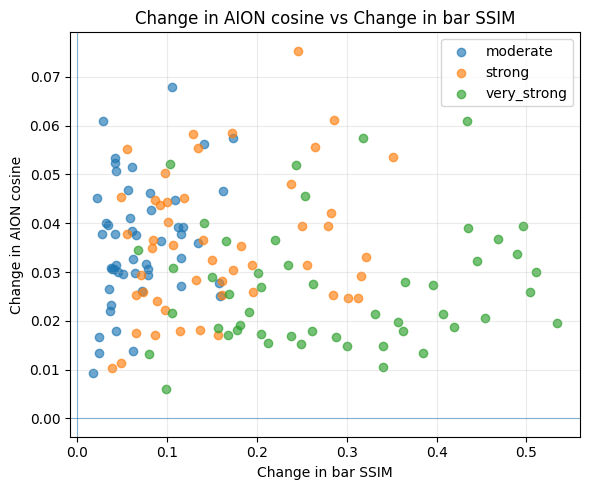

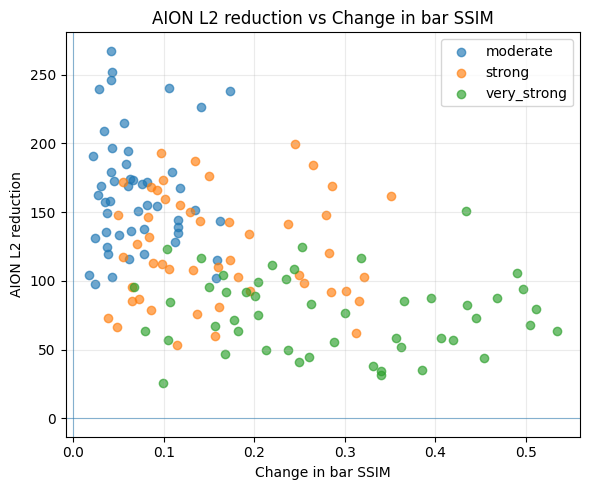

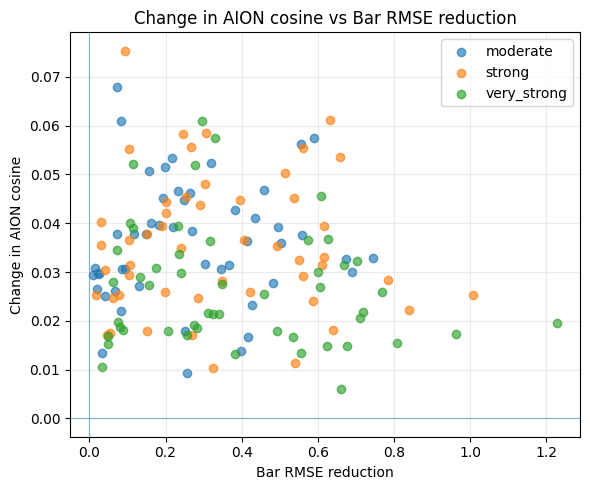

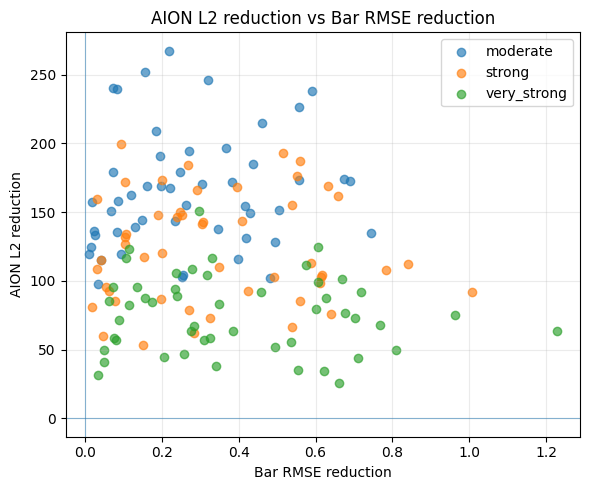

In [ ]:
import matplotlib.pyplot as plt

plot_data = paired.copy()

figures = [
    (
        "delta_bar_SSIM",
        "delta_AION_cosine",
        "Change in bar SSIM",
        "Change in AION cosine"
    ),
    (
        "delta_bar_SSIM",
        "AION_L2_reduction",
        "Change in bar SSIM",
        "AION L2 reduction"
    ),
    (
        "bar_RMSE_reduction",
        "delta_AION_cosine",
        "Bar RMSE reduction",
        "Change in AION cosine"
    ),
    (
        "bar_RMSE_reduction",
        "AION_L2_reduction",
        "Bar RMSE reduction",
        "AION L2 reduction"
    )
]

for x, y, xlabel, ylabel in figures:

    plt.figure(figsize=(6, 5))

    for level, g in plot_data.groupby("degradation"):

        plt.scatter(
            g[x],
            g[y],
            alpha=0.65,
            label=level
        )

    plt.axhline(
        0,
        linewidth=0.8,
        alpha=0.5
    )

    plt.axvline(
        0,
        linewidth=0.8,
        alpha=0.5
    )

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(f"{ylabel} vs {xlabel}")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

In [ ]:
import os

print("Searching /content for YOLO/BRAHMa weights...\n")

matches = []

for root, dirs, files in os.walk("/content"):
    # Skip large/cache directories
    dirs[:] = [
        d for d in dirs
        if d not in {
            ".cache",
            "sample_data",
            "huggingface"
        }
    ]

    for f in files:
        if f.endswith((".pt", ".pth", ".onnx")):
            path = os.path.join(root, f)

            try:
                size_mb = os.path.getsize(path) / (1024**2)
            except:
                size_mb = 0

            matches.append(
                (path, size_mb)
            )

if matches:
    for path, size_mb in sorted(matches):
        print(f"{size_mb:8.1f} MB   {path}")
else:
    print("No model weights found in /content.")

Searching /content for YOLO/BRAHMa weights...

No model weights found in /content.


In [ ]:
# ============================================================
# PSF mismatch robustness test
# ============================================================

TRUE_SIGMA = 2.5
ASSUMED_SIGMAS = [2.0, 2.5, 3.0]

mismatch_results = []

for assumed_sigma in ASSUMED_SIGMAS:

    print(
        f"\nTrue sigma = {TRUE_SIGMA}, "
        f"assumed sigma = {assumed_sigma}"
    )

    reconstructed_all = []

    for idx, r in sample_df.iterrows():

        path = os.path.join(
            "/content/gz3d_dr10_sample",
            f"{idx:03d}_{r['manga_id']}.fits"
        )

        with fits.open(
            path,
            memmap=False
        ) as hdul:
            original = hdul[0].data.astype(
                np.float32
            )

        # Observation generated with TRUE PSF
        observed = forward_operator(
            original,
            TRUE_SIGMA
        )

        # Reconstruction uses ASSUMED PSF
        reconstructed = generalized_rl(
            observed,
            assumed_sigma,
            iterations=RL_ITERATIONS
        )

        reconstructed_all.append(
            reconstructed
        )

    reconstructed_all = np.stack(
        reconstructed_all
    ).astype(np.float32)

    # --------------------------------------------------------
    # Pixel / morphology metrics
    # --------------------------------------------------------

    level_rows = []

    for i, r in sample_df.iterrows():

        path = os.path.join(
            "/content/gz3d_dr10_sample",
            f"{i:03d}_{r['manga_id']}.fits"
        )

        with fits.open(
            path,
            memmap=False
        ) as hdul:
            original = hdul[0].data.astype(
                np.float32
            )

        bar_mask = get_bar_mask(r)

        metrics = evaluate_image(
            original,
            reconstructed_all[i],
            bar_mask
        )

        level_rows.append({
            "idx": i,
            "manga_id": r["manga_id"],
            "true_sigma": TRUE_SIGMA,
            "assumed_sigma": assumed_sigma,
            **metrics
        })

    mismatch_df_level = pd.DataFrame(
        level_rows
    )

    # --------------------------------------------------------
    # AION
    # --------------------------------------------------------

    print("Extracting AION embeddings...")

    emb_reconstructed = get_aion_embeddings(
        reconstructed_all,
        batch_size=5
    )

    cosine = torch.nn.functional.cosine_similarity(
        aion_original,
        emb_reconstructed,
        dim=1
    ).numpy()

    l2 = torch.linalg.vector_norm(
        aion_original - emb_reconstructed,
        dim=1
    ).numpy()

    mismatch_df_level["AION_cosine"] = cosine
    mismatch_df_level["AION_L2"] = l2

    mismatch_results.append(
        mismatch_df_level
    )

    print(
        mismatch_df_level[
            [
                "PSNR",
                "SSIM",
                "bar_RMSE",
                "bar_SSIM",
                "AION_cosine",
                "AION_L2"
            ]
        ].mean().round(4).to_dict()
    )

    del reconstructed_all
    del emb_reconstructed

mismatch_df = pd.concat(
    mismatch_results,
    ignore_index=True
)

print("\n========================================")
print("PSF MISMATCH TEST")
print("========================================")

print(
    mismatch_df.groupby(
        "assumed_sigma"
    )[
        [
            "PSNR",
            "SSIM",
            "bar_RMSE",
            "bar_SSIM",
            "AION_cosine",
            "AION_L2"
        ]
    ].mean().round(4)
)


True sigma = 2.5, assumed sigma = 2.0
Extracting AION embeddings...
 50/50
{'PSNR': 33.7677, 'SSIM': 0.9291, 'bar_RMSE': 0.211, 'bar_SSIM': 0.9634, 'AION_cosine': 0.9644, 'AION_L2': 277.3692}

True sigma = 2.5, assumed sigma = 2.5
Extracting AION embeddings...
 50/50
{'PSNR': 38.5694, 'SSIM': 0.93, 'bar_RMSE': 0.1012, 'bar_SSIM': 0.9893, 'AION_cosine': 0.9673, 'AION_L2': 263.4874}

True sigma = 2.5, assumed sigma = 3.0
Extracting AION embeddings...
 50/50
{'PSNR': 34.6607, 'SSIM': 0.9268, 'bar_RMSE': 0.1738, 'bar_SSIM': 0.9791, 'AION_cosine': 0.9589, 'AION_L2': 297.5776}

PSF MISMATCH TEST
                  PSNR    SSIM  bar_RMSE  bar_SSIM  AION_cosine     AION_L2
assumed_sigma                                                              
2.0            33.7677  0.9291    0.2110    0.9634       0.9644  277.369202
2.5            38.5694  0.9300    0.1012    0.9893       0.9673  263.487396
3.0            34.6607  0.9268    0.1738    0.9791       0.9589  297.577606


In [ ]:
# ============================================================
# Noise robustness experiment
# True PSF = 2.5
# ============================================================

TRUE_SIGMA = 2.5

NOISE_LEVELS = {
    "low_noise": 0.01,
    "moderate_noise": 0.03,
    "high_noise": 0.05
}

noise_results = []


def add_gaussian_noise(observed, noise_fraction):

    noisy = observed.copy()

    for b in range(4):

        # Robust per-band flux scale
        p_low = np.percentile(
            observed[b], 1
        )

        p_high = np.percentile(
            observed[b], 99
        )

        robust_range = p_high - p_low

        noise_sigma = (
            noise_fraction * robust_range
        )

        noise = np.random.normal(
            0,
            noise_sigma,
            size=observed[b].shape
        ).astype(np.float32)

        noisy[b] += noise

    return noisy.astype(np.float32)


# Reproducibility
np.random.seed(42)


for noise_name, noise_fraction in NOISE_LEVELS.items():

    print(
        f"\n{noise_name}: "
        f"{noise_fraction*100:.1f}% noise"
    )

    degraded_all = []
    reconstructed_all = []

    # --------------------------------------------------------
    # Generate observations + reconstruction
    # --------------------------------------------------------

    for idx, r in sample_df.iterrows():

        path = os.path.join(
            "/content/gz3d_dr10_sample",
            f"{idx:03d}_{r['manga_id']}.fits"
        )

        with fits.open(
            path,
            memmap=False
        ) as hdul:

            original = hdul[0].data.astype(
                np.float32
            )

        # Clean forward model
        observed = forward_operator(
            original,
            TRUE_SIGMA
        )

        # Add observational noise
        noisy_observed = add_gaussian_noise(
            observed,
            noise_fraction
        )

        # RL assumes non-negative data
        noisy_observed = np.maximum(
            noisy_observed,
            0
        )

        # Upsampled degraded image
        degraded_full = zoom(
            noisy_observed,
            (1, DOWNSAMPLE, DOWNSAMPLE),
            order=1
        ).astype(np.float32)

        # Reconstruction
        reconstructed = generalized_rl(
            noisy_observed,
            TRUE_SIGMA,
            iterations=RL_ITERATIONS
        )

        reconstructed_all.append(
            reconstructed
        )

        degraded_all.append(
            degraded_full
        )

        # ----------------------------------------------------
        # Pixel/morphology metrics
        # ----------------------------------------------------

        bar_mask = get_bar_mask(r)

        degraded_metrics = evaluate_image(
            original,
            degraded_full,
            bar_mask
        )

        recon_metrics = evaluate_image(
            original,
            reconstructed,
            bar_mask
        )

        noise_results.append({
            "idx": idx,
            "manga_id": r["manga_id"],
            "noise_level": noise_name,
            "noise_fraction": noise_fraction,
            "image_type": "degraded",
            **degraded_metrics
        })

        noise_results.append({
            "idx": idx,
            "manga_id": r["manga_id"],
            "noise_level": noise_name,
            "noise_fraction": noise_fraction,
            "image_type": "RL_reconstruction",
            **recon_metrics
        })

    # --------------------------------------------------------
    # AION
    # --------------------------------------------------------

    degraded_all = np.stack(
        degraded_all
    ).astype(np.float32)

    reconstructed_all = np.stack(
        reconstructed_all
    ).astype(np.float32)

    print("Extracting AION embeddings...")

    emb_degraded = get_aion_embeddings(
        degraded_all,
        batch_size=5
    )

    emb_reconstructed = get_aion_embeddings(
        reconstructed_all,
        batch_size=5
    )

    cos_deg = torch.nn.functional.cosine_similarity(
        aion_original,
        emb_degraded,
        dim=1
    ).numpy()

    cos_rec = torch.nn.functional.cosine_similarity(
        aion_original,
        emb_reconstructed,
        dim=1
    ).numpy()

    l2_deg = torch.linalg.vector_norm(
        aion_original - emb_degraded,
        dim=1
    ).numpy()

    l2_rec = torch.linalg.vector_norm(
        aion_original - emb_reconstructed,
        dim=1
    ).numpy()

    # --------------------------------------------------------
    # Attach AION metrics
    # --------------------------------------------------------

    start = len(noise_results) - 100

    for i in range(50):

        noise_results[
            start + 2*i
        ]["AION_cosine"] = cos_deg[i]

        noise_results[
            start + 2*i
        ]["AION_L2"] = l2_deg[i]

        noise_results[
            start + 2*i + 1
        ]["AION_cosine"] = cos_rec[i]

        noise_results[
            start + 2*i + 1
        ]["AION_L2"] = l2_rec[i]

    del degraded_all
    del reconstructed_all
    del emb_degraded
    del emb_reconstructed

    print(
        f"{noise_name} complete."
    )


# ============================================================
# Final dataframe
# ============================================================

noise_df = pd.DataFrame(
    noise_results
)

print("\n========================================")
print("NOISE ROBUSTNESS COMPLETE")
print("========================================")

print(
    noise_df.groupby(
        ["noise_level", "image_type"]
    )[
        [
            "PSNR",
            "SSIM",
            "bar_RMSE",
            "bar_SSIM",
            "AION_cosine",
            "AION_L2"
        ]
    ]
    .mean()
    .round(4)
)


low_noise: 1.0% noise
Extracting AION embeddings...
 50/50
 50/50
low_noise complete.

moderate_noise: 3.0% noise
Extracting AION embeddings...
 50/50
 50/50
moderate_noise complete.

high_noise: 5.0% noise
Extracting AION embeddings...
 50/50
 50/50
high_noise complete.

NOISE ROBUSTNESS COMPLETE
                                     PSNR    SSIM  bar_RMSE  bar_SSIM  \
noise_level    image_type                                               
high_noise     RL_reconstruction  27.7218  0.4458    0.1236    0.9678   
               degraded           26.7350  0.6257    0.4438    0.8254   
low_noise      RL_reconstruction  36.1466  0.8628    0.1027    0.9884   
               degraded           27.9067  0.8921    0.4427    0.8295   
moderate_noise RL_reconstruction  31.0500  0.6199    0.1088    0.9816   
               degraded           27.4330  0.7633    0.4435    0.8281   

                                  AION_cosine     AION_L2  
noise_level    image_type                              

In [ ]:
# ============================================================
# RL iteration sensitivity under 3% observational noise
# ============================================================

TRUE_SIGMA = 2.5
NOISE_FRACTION = 0.03
ITERATIONS = [5, 10, 20, 40]

iteration_results = []

np.random.seed(42)


for iteration_count in ITERATIONS:

    print(
        f"\nRL iterations = {iteration_count}"
    )

    reconstructed_all = []

    for idx, r in sample_df.iterrows():

        path = os.path.join(
            "/content/gz3d_dr10_sample",
            f"{idx:03d}_{r['manga_id']}.fits"
        )

        with fits.open(
            path,
            memmap=False
        ) as hdul:
            original = hdul[0].data.astype(
                np.float32
            )

        # ----------------------------------------------------
        # Forward model
        # ----------------------------------------------------

        observed = forward_operator(
            original,
            TRUE_SIGMA
        )

        # ----------------------------------------------------
        # Add 3% noise
        # ----------------------------------------------------

        noisy_observed = add_gaussian_noise(
            observed,
            NOISE_FRACTION
        )

        noisy_observed = np.maximum(
            noisy_observed,
            0
        )

        # ----------------------------------------------------
        # Reconstruction
        # ----------------------------------------------------

        reconstructed = generalized_rl(
            noisy_observed,
            TRUE_SIGMA,
            iterations=iteration_count
        )

        reconstructed_all.append(
            reconstructed
        )

        # ----------------------------------------------------
        # Metrics
        # ----------------------------------------------------

        bar_mask = get_bar_mask(r)

        metrics = evaluate_image(
            original,
            reconstructed,
            bar_mask
        )

        iteration_results.append({
            "idx": idx,
            "manga_id": r["manga_id"],
            "iterations": iteration_count,
            **metrics
        })

    # --------------------------------------------------------
    # AION
    # --------------------------------------------------------

    reconstructed_all = np.stack(
        reconstructed_all
    ).astype(np.float32)

    print("Extracting AION embeddings...")

    emb_reconstructed = get_aion_embeddings(
        reconstructed_all,
        batch_size=5
    )

    cosine = torch.nn.functional.cosine_similarity(
        aion_original,
        emb_reconstructed,
        dim=1
    ).numpy()

    l2 = torch.linalg.vector_norm(
        aion_original - emb_reconstructed,
        dim=1
    ).numpy()

    start = len(iteration_results) - 50

    for i in range(50):

        iteration_results[
            start + i
        ]["AION_cosine"] = cosine[i]

        iteration_results[
            start + i
        ]["AION_L2"] = l2[i]

    del reconstructed_all
    del emb_reconstructed

    print(
        f"Completed {iteration_count} iterations."
    )


iteration_df = pd.DataFrame(
    iteration_results
)

print("\n========================================")
print("RL ITERATION SENSITIVITY")
print("========================================")

print(
    iteration_df.groupby(
        "iterations"
    )[
        [
            "PSNR",
            "SSIM",
            "bar_RMSE",
            "bar_SSIM",
            "AION_cosine",
            "AION_L2"
        ]
    ]
    .mean()
    .round(4)
)


RL iterations = 5
Extracting AION embeddings...
 50/50
Completed 5 iterations.

RL iterations = 10
Extracting AION embeddings...
 50/50
Completed 10 iterations.

RL iterations = 20
Extracting AION embeddings...
 50/50
Completed 20 iterations.

RL iterations = 40
Extracting AION embeddings...
 50/50
Completed 40 iterations.

RL ITERATION SENSITIVITY
               PSNR    SSIM  bar_RMSE  bar_SSIM  AION_cosine     AION_L2
iterations                                                              
5           31.8905  0.7258    0.1793    0.9670       0.8046  634.096985
10          31.8873  0.6844    0.1379    0.9777       0.7764  676.134399
20          31.0435  0.6199    0.1102    0.9812       0.7474  716.939697
40          29.4132  0.5333    0.0953    0.9775       0.7133  761.056580


In [ ]:
import os

os.makedirs(
    "/content/aion_inverse_imaging_results",
    exist_ok=True
)

pixel_df.to_csv(
    "/content/aion_inverse_imaging_results/"
    "pixel_metrics_moderate.csv",
    index=False
)

multi_df.to_csv(
    "/content/aion_inverse_imaging_results/"
    "multi_level_degradation.csv",
    index=False
)

recon_df.to_csv(
    "/content/aion_inverse_imaging_results/"
    "reconstruction_results.csv",
    index=False
)

paired.to_csv(
    "/content/aion_inverse_imaging_results/"
    "reconstruction_recovery.csv",
    index=False
)

mismatch_df.to_csv(
    "/content/aion_inverse_imaging_results/"
    "psf_mismatch.csv",
    index=False
)

noise_df.to_csv(
    "/content/aion_inverse_imaging_results/"
    "noise_robustness.csv",
    index=False
)

iteration_df.to_csv(
    "/content/aion_inverse_imaging_results/"
    "rl_iteration_sensitivity.csv",
    index=False
)

print("Saved experiment tables:")
for f in sorted(
    os.listdir(
        "/content/aion_inverse_imaging_results"
    )
):
    print(" ", f)

Saved experiment tables:
  multi_level_degradation.csv
  noise_robustness.csv
  pixel_metrics_moderate.csv
  psf_mismatch.csv
  reconstruction_recovery.csv
  reconstruction_results.csv
  rl_iteration_sensitivity.csv


In [ ]:
import numpy as np
import pandas as pd

from scipy.ndimage import zoom
from skimage.measure import regionprops, label


morphology_results = []


for idx, r in sample_df.iterrows():

    seg = np.asarray(
        ds[int(r["idx"])]["gz3d_segmentation"]
    )

    # GZ3D bar channel
    bar = seg[3] >= 1

    # Resample to Legacy Survey pixel scale
    bar_small = zoom(
        bar.astype(np.uint8),
        0.099 / 0.262,
        order=0
    ).astype(bool)

    # Connected components
    labeled = label(
        bar_small
    )

    regions = regionprops(
        labeled
    )

    if len(regions) == 0:
        morphology_results.append({
            "idx": idx,
            "manga_id": r["manga_id"],
            "bar_area_pix": 0,
            "major_axis_pix": np.nan,
            "minor_axis_pix": np.nan,
            "axis_ratio": np.nan,
            "orientation_deg": np.nan
        })
        continue

    # Largest connected bar component
    region = max(
        regions,
        key=lambda x: x.area
    )

    major = region.major_axis_length
    minor = region.minor_axis_length

    axis_ratio = (
        minor / major
        if major > 0
        else np.nan
    )

    # skimage orientation is measured from horizontal,
    # convert to degrees
    orientation_deg = np.degrees(
        region.orientation
    )

    morphology_results.append({
        "idx": idx,
        "manga_id": r["manga_id"],
        "bar_area_pix": region.area,
        "major_axis_pix": major,
        "minor_axis_pix": minor,
        "axis_ratio": axis_ratio,
        "orientation_deg": orientation_deg
    })


gz3d_morphology_df = pd.DataFrame(
    morphology_results
)

print(
    gz3d_morphology_df.describe().round(3)
)

print(
    "\nNumber of valid morphology measurements:",
    gz3d_morphology_df[
        "major_axis_pix"
    ].notna().sum(),
    "/",
    len(gz3d_morphology_df)
)

          idx  bar_area_pix  major_axis_pix  minor_axis_pix  axis_ratio  \
count  50.000        50.000          50.000          50.000      50.000   
mean   24.500       303.000          26.403          13.760       0.507   
std    14.577       265.913           7.495           7.985       0.186   
min     0.000        60.000          11.836           5.215       0.267   
25%    12.250       131.750          19.590           8.658       0.361   
50%    24.500       201.500          26.128          11.386       0.462   
75%    36.750       342.000          31.532          16.766       0.597   
max    49.000      1271.000          42.812          40.301       0.989   

       orientation_deg  
count           50.000  
mean             0.283  
std             47.334  
min            -85.437  
25%            -36.776  
50%              6.376  
75%             39.173  
max             80.719  

Number of valid morphology measurements: 50 / 50


In [ ]:

from scipy.stats import pearsonr, spearmanr

# ============================================================
# Original AION representation vs GZ3D morphology
# ============================================================

morph_df = gz3d_morphology_df.merge(
    pixel_df[
        ["idx", "manga_id"]
    ],
    on=["idx", "manga_id"],
    how="inner"
)

# ------------------------------------------------------------
# Construct simple AION descriptors
# ------------------------------------------------------------

# Original AION embeddings
E = aion_original.numpy()

# Normalize
E_norm = E / (
    np.linalg.norm(
        E,
        axis=1,
        keepdims=True
    ) + 1e-8
)

# Distance from the sample mean representation.
# This is only a descriptive representation-space descriptor.
mean_embedding = E_norm.mean(axis=0)

representation_distance = np.linalg.norm(
    E_norm - mean_embedding,
    axis=1
)

morph_df["AION_sample_distance"] = (
    representation_distance
)


# ============================================================
# Correlations
# ============================================================

properties = [
    "bar_area_pix",
    "major_axis_pix",
    "minor_axis_pix",
    "axis_ratio",
    "orientation_deg"
]

results = []

for prop in properties:

    d = morph_df[
        [
            "AION_sample_distance",
            prop
        ]
    ].dropna()

    r, p = pearsonr(
        d["AION_sample_distance"],
        d[prop]
    )

    rho, sp = spearmanr(
        d["AION_sample_distance"],
        d[prop]
    )

    results.append({
        "property": prop,
        "Pearson_r": r,
        "Pearson_p": p,
        "Spearman_rho": rho,
        "Spearman_p": sp,
        "N": len(d)
    })

aion_morphology_corr = pd.DataFrame(
    results
)

print(
    aion_morphology_corr.round(4)
    .to_string(index=False)
)

       property  Pearson_r  Pearson_p  Spearman_rho  Spearman_p  N
   bar_area_pix     0.0161     0.9116       -0.0857      0.5542 50
 major_axis_pix    -0.1945     0.1759       -0.1873      0.1927 50
 minor_axis_pix     0.0394     0.7861        0.0125      0.9312 50
     axis_ratio     0.1574     0.2749        0.2306      0.1071 50
orientation_deg    -0.0514     0.7231       -0.0447      0.7579 50


In [ ]:

# ============================================================
# Paper-ready reconstruction summary
# ============================================================

summary = (
    reconstruction_results
    .groupby(["level", "method"])
    .agg({
        "PSNR": ["mean", "std"],
        "SSIM": ["mean", "std"],
        "bar_RMSE": ["mean", "std"],
        "bar_SSIM": ["mean", "std"],
        "AION_cosine": ["mean", "std"],
        "AION_L2": ["mean", "std"]
    })
)

summary = summary.round(4)

print(summary.to_string())

NameError: name 'reconstruction_results' is not defined

In [ ]:
import pandas as pd
import os

RESULTS_DIR = "/content/aion_inverse_imaging_results"

reconstruction_df = pd.read_csv(
    os.path.join(
        RESULTS_DIR,
        "reconstruction_results.csv"
    )
)

print("Loaded:", reconstruction_df.shape)
print(reconstruction_df.columns.tolist())

display(reconstruction_df.head())

Loaded: (300, 10)
['idx', 'manga_id', 'degradation', 'image_type', 'PSNR', 'SSIM', 'bar_RMSE', 'bar_SSIM', 'AION_cosine', 'AION_L2']


,idx,manga_id,degradation,image_type,PSNR,SSIM,bar_RMSE,bar_SSIM,AION_cosine,AION_L2
0,0,1-310020,moderate,degraded,28.994527,0.947980,0.127831,0.970161,0.942861,383.74686
1,0,1-310020,moderate,RL_reconstruction,43.032097,0.958252,0.009720,0.997762,0.980706,221.27357
2,1,1-477040,moderate,degraded,31.163443,0.961692,0.291520,0.955567,0.975281,216.79700
3,1,1-477040,moderate,RL_reconstruction,43.947082,0.974311,0.039646,0.998936,0.993207,113.67224
4,2,1-327467,moderate,degraded,27.589674,0.962580,0.464236,0.940630,0.949681,324.80725


In [ ]:
summary = (
    reconstruction_df
    .groupby(["degradation", "image_type"])
    .agg({
        "PSNR": ["mean", "std"],
        "SSIM": ["mean", "std"],
        "bar_RMSE": ["mean", "std"],
        "bar_SSIM": ["mean", "std"],
        "AION_cosine": ["mean", "std"],
        "AION_L2": ["mean", "std"]
    })
    .round(4)
)

display(summary)

PSNR            SSIM         bar_RMSE  \
                                  mean     std    mean     std     mean   
degradation image_type                                                    
moderate    RL_reconstruction  43.5152  5.1675  0.9402  0.0743   0.0256   
            degraded           30.9416  2.8810  0.9277  0.0854   0.2965   
strong      RL_reconstruction  38.5694  3.7513  0.9300  0.0875   0.1012   
            degraded           27.9797  2.9699  0.9162  0.0932   0.4428   
very_strong RL_reconstruction  32.1779  3.1159  0.9194  0.0944   0.2604   
            degraded           24.8283  2.8600  0.8994  0.0989   0.6515   

                                      bar_SSIM         AION_cosine          \
                                  std     mean     std        mean     std   
degradation image_type                                                       
moderate    RL_reconstruction  0.0238   0.9980  0.0037      0.9860  0.0109   
            degraded           0.2165   0.9269  0.0421      0.9499  0.0195   
strong      RL_reconstruction  0.0850   0.9893  0.0091      0.9673  0.0194   
            degraded           0.3178   0.8297  0.0943      0.9318  0.0275   
very_strong RL_reconstruction  0.1975   0.9296  0.0523      0.9433  0.0271   
            degraded           0.4572   0.6451  0.1677      0.9165  0.0332   

                                AION_L2            
                                   mean       std  
degradation image_type                             
moderate    RL_reconstruction  167.5755   75.4591  
            degraded           332.1848   82.5234  
strong      RL_reconstruction  263.4874   92.4621  
            degraded           386.9638   97.4175  
very_strong RL_reconstruction  351.4380  103.1460  
            degraded           427.6379  104.2048

In [ ]:
import os
import glob

print("Current directory:", os.getcwd())

print("\nExisting model files:")
for path in glob.glob(
    "/content/**/*.pt",
    recursive=True
)[:30]:
    print(path)

print("\nExisting checkpoints:")
for path in glob.glob(
    "/content/**/*.pth",
    recursive=True
)[:30]:
    print(path)

print("\nExisting Berthy repositories:")
for path in glob.glob(
    "/content/*berthy*",
    recursive=False
):
    print(path)

Current directory: /content

Existing model files:

Existing checkpoints:

Existing Berthy repositories:


In [ ]:
import os
import subprocess

repo = "/content/score_prior"

if not os.path.exists(repo):
    subprocess.run([
        "git", "clone",
        "https://github.com/berthyf96/score_prior.git",
        repo
    ], check=True)

print("Repository:", repo)
print("\nFiles:")

for root, dirs, files in os.walk(repo):
    level = root.replace(repo, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        for f in files:
            print("  " * (level + 1) + f)

Repository: /content/score_prior

Files:
score_prior/
  probability_bound.py
  train.py
  train_dpi.py
  .gitignore
  conda.sh
  probability_flow.py
  mri.py
  forward_models.py
  inference_utils.py
  ehtim_utils.py
  README.md
  configs/
    score_config.py
    dpi_config.py
  demos/
    2d_posterior_sampling.ipynb
    denoising.ipynb
    interferometry.ipynb
    eht_data/
      truth.fits
      obs.uvfits
    test_data/
      celeba_test_image.npy
  .git/
    config
    index
    HEAD
    description
    packed-refs
    info/
      exclude
    logs/
      HEAD
    refs/
    hooks/
      pre-merge-commit.sample
      pre-rebase.sample
      applypatch-msg.sample
      commit-msg.sample
      pre-applypatch.sample
      fsmonitor-watchman.sample
      sendemail-validate.sample
      pre-push.sample
      update.sample
      post-update.sample
      pre-commit.sample
      prepare-commit-msg.sample
      push-to-checkout.sample
      pre-receive.sample
    branches/
    objects/
  score

In [ ]:
from pathlib import Path

repo = Path("/content/score_prior")

for fname in [
    "README.md",
    "configs/score_config.py",
    "configs/dpi_config.py",
    "train.py",
    "train_dpi.py",
    "inference_utils.py"
]:
    path = repo / fname

    print("\n" + "=" * 80)
    print(fname)
    print("=" * 80)

    if path.exists():
        text = path.read_text(errors="ignore")

        # Keep the notebook output manageable
        print(text[:12000])
    else:
        print("FILE NOT FOUND")


README.md
# Score-Based Priors for Bayesian Inverse Imaging

[Webpage](http://imaging.cms.caltech.edu/score_prior/) | [PDF](https://arxiv.org/abs/2304.11751)

![figure showing posterior samples using score-based priors under different measurement settings](assets/teaser.png "Score-Based Priors")

This project turns score-based diffusion models into explicit priors for Bayesian inverse problems in imaging. A "score-based prior" allows us to model complex, data-driven posterior distributions while using established sampling and optimization methods (e.g., MCMC, variational inference) that require an explicit log-density function. In our work, we propose a variational-inference approach to posterior sampling, in addition to empirically validating the accuracy and variance of a score-based prior.

**UPDATE (2/5/24):** The repo has been updated to support the [surrogate score-based prior](https://arxiv.org/abs/2309.01949) based on an evidence lower bound (ELBO). The ELBO-based prior is muc

In [ ]:
from pathlib import Path

repo = Path("/content/score_prior")

for fname in [
    "score_flow/datasets.py",
    "forward_models.py",
    "train_dpi.py",
    "score_flow/models/ncsnpp.py"
]:
    path = repo / fname

    print("\n" + "=" * 80)
    print(fname)
    print("=" * 80)

    text = path.read_text(errors="ignore")
    print(text[:16000])


score_flow/datasets.py
# coding=utf-8
# Copyright 2020 The Google Research Authors.
#
# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
#     http://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

# pylint: skip-file
"""Return training and evaluation/test datasets from config files."""
from typing import Any, Optional, Tuple
import os

import jax
import ml_collections
import numpy as np
from scipy.ndimage import gaussian_filter
import tensorflow as tf
import tensorflow_datasets as tfds

SUPPORTED_DATASETS = ['CIFAR10', 'CELEBA', 'fastMRI', 'SVHN', 'LSUN', 'Ce

In [ ]:
import os
import glob

paths = {
    "Legacy FITS": "/content/gz3d_dr10_sample",
    "AION results": "/content/aion_inverse_imaging_results",
    "score_prior": "/content/score_prior"
}

for name, path in paths.items():
    print(f"\n{name}")
    print("-" * 60)

    if os.path.exists(path):
        files = glob.glob(os.path.join(path, "**", "*"), recursive=True)
        files = [f for f in files if os.path.isfile(f)]

        print("Files:", len(files))

        for f in files[:10]:
            print(" ", f)
    else:
        print("Not found")


Legacy FITS
------------------------------------------------------------
Files: 50
  /content/gz3d_dr10_sample/018_1-79504.fits
  /content/gz3d_dr10_sample/035_1-512467.fits
  /content/gz3d_dr10_sample/042_1-605533.fits
  /content/gz3d_dr10_sample/031_1-507112.fits
  /content/gz3d_dr10_sample/004_1-478021.fits
  /content/gz3d_dr10_sample/016_1-464288.fits
  /content/gz3d_dr10_sample/027_1-28915.fits
  /content/gz3d_dr10_sample/048_1-547859.fits
  /content/gz3d_dr10_sample/047_1-180135.fits
  /content/gz3d_dr10_sample/045_1-369781.fits

AION results
------------------------------------------------------------
Files: 7
  /content/aion_inverse_imaging_results/noise_robustness.csv
  /content/aion_inverse_imaging_results/pixel_metrics_moderate.csv
  /content/aion_inverse_imaging_results/multi_level_degradation.csv
  /content/aion_inverse_imaging_results/reconstruction_recovery.csv
  /content/aion_inverse_imaging_results/reconstruction_results.csv
  /content/aion_inverse_imaging_results/psf

In [ ]:
from pathlib import Path

# Inspect the two interfaces we will adapt:
# 1. dataset loading
# 2. forward model / likelihood

files_to_check = [
    Path("/content/score_prior/score_flow/datasets.py"),
    Path("/content/score_prior/forward_models.py"),
    Path("/content/score_prior/train.py"),
    Path("/content/score_prior/train_dpi.py"),
]

for path in files_to_check:
    print("\n" + "=" * 80)
    print(path)
    print("=" * 80)

    if path.exists():
        text = path.read_text(errors="ignore")
        lines = text.splitlines()

        # Print compact structural information first
        for i, line in enumerate(lines, start=1):
            s = line.strip()
            if (
                s.startswith("SUPPORTED_DATASETS")
                or s.startswith("def ")
                or s.startswith("class ")
                or "dataset" in s.lower() and ("=" in s or "def " in s)
                or "likelihood" in s.lower() and ("class " in s or "def " in s)
            ):
                print(f"{i:4d}: {s[:160]}")
    else:
        print("NOT FOUND")


/content/score_prior/score_flow/datasets.py
  28: SUPPORTED_DATASETS = ['CIFAR10', 'CELEBA', 'fastMRI', 'SVHN', 'LSUN', 'CelebAHQ', 'SgrA', 'GRMHD']
  31: def get_data_scaler(config):
  40: def get_data_inverse_scaler(config):
  49: def crop_resize(image, resolution):
  63: def resize_small(image, resolution):
  72: def central_crop(image, size):
  79: def get_dataset_builder_and_resize_op(config: ml_collections.ConfigDict, shuffle_seed = None) -> Tuple[Any, Any]:
  82: if config.data.dataset == 'CIFAR10':
  83: dataset_builder = tfds.builder('cifar10', data_dir=data_dir)
  85: def resize_op(img):
  93: elif config.data.dataset == 'CELEBA':
  94: dataset_builder = tfds.builder('celeb_a', data_dir=data_dir)
  96: def resize_op(img):
 105: elif config.data.dataset == 'fastMRI':
 110: def parse_example(serialized_example):
 116: def ds_from_tfrecords(tfrecords_pattern):
 120: shards = tf.data.Dataset.from_tensor_slices(shard_files)
 121: ds = shards.interleave(tf.data.TFRecordDataset)
 1

In [ ]:
from pathlib import Path

files_to_check = [
    Path("/content/score_prior/configs/score_config.py"),
    Path("/content/score_prior/configs/dpi_config.py"),
    Path("/content/score_prior/forward_models.py"),
]

for path in files_to_check:
    print("\n" + "=" * 80)
    print(path)
    print("=" * 80)

    text = path.read_text(errors="ignore")
    lines = text.splitlines()

    for i, line in enumerate(lines, start=1):
        s = line.strip()

        if (
            s.startswith("def ")
            or s.startswith("class ")
            or "image_size" in s
            or "num_channels" in s
            or "batch_size" in s
            or "dataset" in s
            or "likelihood" in s
            or "forward" in s.lower()
            or "sigma" in s
            or "centered" in s
            or "channels" in s
        ):
            print(f"{i:4d}: {s[:180]}")


/content/score_prior/configs/score_config.py
   6: def get_config():
  10: # need to define: training.n_iters, training.batch_size,
  14: training.likelihood_weighting = False
  20: training.batch_size = 128
  37: # need to define: data.dataset, data.image_size, data.num_channels
  44: data.centered = False
  45: data.dataset = ''
  46: data.tfds_dir = '~/tensorflow_datasets'
  47: data.image_size = 32
  48: data.num_channels = 3
  57: data.taper_gaussian_blur_sigma = 2.  # amount to blur the hard mask (fractional or absolute)
  65: model.sigma_min = 0.002
  66: model.sigma_max = 50.
  70: model.scale_by_sigma = False
 106: evaluation.batch_size = 256

/content/score_prior/configs/dpi_config.py
   5: def get_config():
  18: training.batch_size = 64
  45: config.likelihood = likelihood = ml_collections.ConfigDict()
  46: likelihood.likelihood = ''
  47: likelihood.noise_scale = 0.1
  48: likelihood.n_dft = 8
  49: likelihood.mri_accel = 8
  50: likelihood.mri_sampling_type = 'poisson'


In [ ]:
from pathlib import Path

files_to_check = [
    Path("/content/score_prior/configs/score_config.py"),
    Path("/content/score_prior/configs/dpi_config.py"),
    Path("/content/score_prior/forward_models.py"),
]

for path in files_to_check:
    print("\n" + "=" * 80)
    print(path)
    print("=" * 80)

    text = path.read_text(errors="ignore")
    lines = text.splitlines()

    for i, line in enumerate(lines, start=1):
        s = line.strip()

        if (
            s.startswith("def ")
            or s.startswith("class ")
            or "image_size" in s
            or "num_channels" in s
            or "batch_size" in s
            or "dataset" in s
            or "likelihood" in s
            or "forward" in s.lower()
            or "sigma" in s
            or "centered" in s
            or "channels" in s
        ):
            print(f"{i:4d}: {s[:180]}")


/content/score_prior/configs/score_config.py
   6: def get_config():
  10: # need to define: training.n_iters, training.batch_size,
  14: training.likelihood_weighting = False
  20: training.batch_size = 128
  37: # need to define: data.dataset, data.image_size, data.num_channels
  44: data.centered = False
  45: data.dataset = ''
  46: data.tfds_dir = '~/tensorflow_datasets'
  47: data.image_size = 32
  48: data.num_channels = 3
  57: data.taper_gaussian_blur_sigma = 2.  # amount to blur the hard mask (fractional or absolute)
  65: model.sigma_min = 0.002
  66: model.sigma_max = 50.
  70: model.scale_by_sigma = False
 106: evaluation.batch_size = 256

/content/score_prior/configs/dpi_config.py
   5: def get_config():
  18: training.batch_size = 64
  45: config.likelihood = likelihood = ml_collections.ConfigDict()
  46: likelihood.likelihood = ''
  47: likelihood.noise_scale = 0.1
  48: likelihood.n_dft = 8
  49: likelihood.mri_accel = 8
  50: likelihood.mri_sampling_type = 'poisson'


In [ ]:
import glob
import numpy as np
from astropy.io import fits

fits_files = sorted(glob.glob("/content/gz3d_dr10_sample/*.fits"))

print(f"Number of FITS files: {len(fits_files)}")

# Inspect the first few galaxies
for path in fits_files[:5]:
    with fits.open(path, memmap=True) as hdul:
        data = np.asarray(hdul[0].data, dtype=np.float32)

    print(
        f"{path.split('/')[-1]:30s} "
        f"shape={data.shape} "
        f"finite={np.isfinite(data).all()} "
        f"min={np.nanmin(data):.4g} "
        f"max={np.nanmax(data):.4g} "
        f"median={np.nanmedian(data):.4g}"
    )

# Per-band robust statistics over the 50 evaluation galaxies
stats = []

for path in fits_files:
    with fits.open(path, memmap=True) as hdul:
        data = np.asarray(hdul[0].data, dtype=np.float32)

    row = []
    for b in range(4):
        x = data[b]
        x = x[np.isfinite(x)]

        row.append((
            np.percentile(x, 1),
            np.percentile(x, 50),
            np.percentile(x, 99)
        ))

    stats.append(row)

stats = np.asarray(stats)

bands = ["g", "r", "i", "z"]

print("\nRobust flux statistics across the 50 held-out galaxies")
print("-" * 70)

for b, band in enumerate(bands):
    p1 = stats[:, b, 0]
    p50 = stats[:, b, 1]
    p99 = stats[:, b, 2]

    print(
        f"{band}: "
        f"P1={np.median(p1):.5g}, "
        f"P50={np.median(p50):.5g}, "
        f"P99={np.median(p99):.5g}"
    )

Number of FITS files: 50
000_1-310020.fits              shape=(4, 160, 160) finite=True min=-0.05056 max=4.218 median=0.006371
001_1-477040.fits              shape=(4, 160, 160) finite=True min=-0.0298 max=7.348 median=0.05099
002_1-327467.fits              shape=(4, 160, 160) finite=True min=-0.02956 max=10.51 median=0.03329
003_1-638623.fits              shape=(4, 160, 160) finite=True min=-0.02627 max=1.413 median=0.01686
004_1-478021.fits              shape=(4, 160, 160) finite=True min=-0.04713 max=2.807 median=0.006483

Robust flux statistics across the 50 held-out galaxies
----------------------------------------------------------------------
g: P1=-0.0022951, P50=0.0063639, P99=0.26258
r: P1=-0.0041898, P50=0.010719, P99=0.5057
i: P1=-0.0076684, P50=0.015596, P99=0.68519
z: P1=-0.012224, P50=0.018642, P99=0.828


Galaxy: 000_1-310020.fits
Original:
  min   = -0.015301514
  median= 0.006196144
  max   = 2.4159951

Normalization parameters:
  center   = 0.00619614
  scale    = 0.383697
  y_lo     = -0.0345455
  y_hi     = 1.42808

Normalized:
  min   = -1.0
  median= -0.95276225
  max   = 1.0

Finite: True


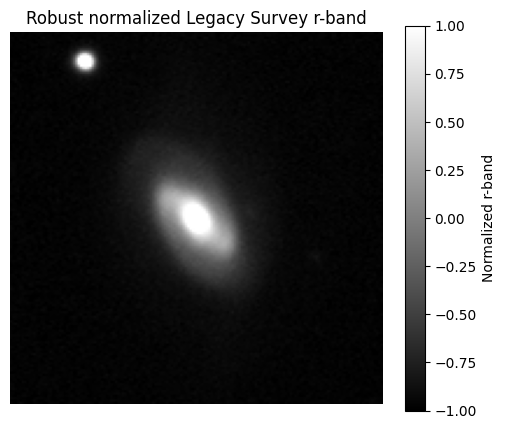

In [ ]:
import glob
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

def robust_asinh_normalize(image, low_pct=1.0, high_pct=99.5, scale=1.0):
    """
    Robust normalization for Legacy Survey flux images.

    The transformation:
      1. estimates a robust scale from percentiles,
      2. applies asinh compression,
      3. maps the result approximately to [-1, 1].

    Negative sky/background values are retained.
    """
    x = np.asarray(image, dtype=np.float32)

    finite = np.isfinite(x)
    vals = x[finite]

    lo = np.percentile(vals, low_pct)
    hi = np.percentile(vals, high_pct)

    # Robust center and scale
    center = np.median(vals)
    robust_scale = max((hi - lo) / 2.0, 1e-6) * scale

    y = np.arcsinh((x - center) / robust_scale)

    # Robust output limits
    y_lo = np.percentile(y[finite], low_pct)
    y_hi = np.percentile(y[finite], high_pct)

    y = 2.0 * (y - y_lo) / (y_hi - y_lo + 1e-8) - 1.0
    y = np.clip(y, -1.0, 1.0)

    return y.astype(np.float32), {
        "center": float(center),
        "scale": float(robust_scale),
        "y_lo": float(y_lo),
        "y_hi": float(y_hi),
    }


path = sorted(glob.glob("/content/gz3d_dr10_sample/*.fits"))[0]

with fits.open(path, memmap=True) as hdul:
    data = np.asarray(hdul[0].data, dtype=np.float32)

r_band = data[1]

normalized, params = robust_asinh_normalize(r_band)

print("Galaxy:", path.split("/")[-1])
print("Original:")
print("  min   =", np.nanmin(r_band))
print("  median=", np.nanmedian(r_band))
print("  max   =", np.nanmax(r_band))

print("\nNormalization parameters:")
for k, v in params.items():
    print(f"  {k:8s} = {v:.6g}")

print("\nNormalized:")
print("  min   =", np.nanmin(normalized))
print("  median=", np.nanmedian(normalized))
print("  max   =", np.nanmax(normalized))

print("\nFinite:", np.isfinite(normalized).all())

plt.figure(figsize=(6, 5))
plt.imshow(normalized, origin="lower", cmap="gray", vmin=-1, vmax=1)
plt.colorbar(label="Normalized r-band")
plt.title("Robust normalized Legacy Survey r-band")
plt.axis("off")
plt.show()

Pixel-distribution comparison
----------------------------------------------------------------------
Asinh + sky subtraction   P1=-0.031  P50=0.000  P90=0.116  P99=1.000  mean=0.045
Robust linear             P1=0.000  P50=0.026  P90=0.126  P99=1.000  mean=0.068
Asinh + percentile        P1=0.000  P50=0.030  P90=0.142  P99=1.000  mean=0.074


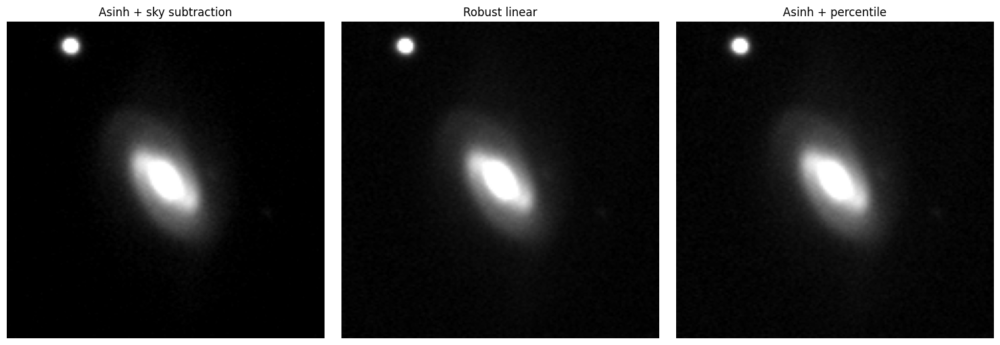

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

path = "/content/gz3d_dr10_sample/000_1-310020.fits"

with fits.open(path, memmap=True) as hdul:
    r = np.asarray(hdul[0].data[1], dtype=np.float32)

finite = np.isfinite(r)
x = r[finite]

# ------------------------------------------------------------
# 1. Asinh with background subtraction
# ------------------------------------------------------------
sky = np.median(x)
scale = np.percentile(x, 99) - sky
scale = max(scale, 1e-6)

asinh_img = np.arcsinh((r - sky) / scale)
asinh_img = np.clip(asinh_img / np.percentile(asinh_img[finite], 99), -1, 1)

# ------------------------------------------------------------
# 2. Robust percentile linear scaling
# ------------------------------------------------------------
p1, p99 = np.percentile(x, [1, 99])
linear_img = (r - p1) / (p99 - p1 + 1e-8)
linear_img = np.clip(linear_img, 0, 1)

# ------------------------------------------------------------
# 3. Asinh + percentile scaling
# ------------------------------------------------------------
z = np.arcsinh((r - sky) / scale)
z1, z99 = np.percentile(z[finite], [1, 99])
asinh_pct = (z - z1) / (z99 - z1 + 1e-8)
asinh_pct = np.clip(asinh_pct, 0, 1)

methods = {
    "Asinh + sky subtraction": asinh_img,
    "Robust linear": linear_img,
    "Asinh + percentile": asinh_pct,
}

print("Pixel-distribution comparison")
print("-" * 70)

for name, img in methods.items():
    vals = img[np.isfinite(img)]

    print(
        f"{name:25s} "
        f"P1={np.percentile(vals,1):.3f}  "
        f"P50={np.percentile(vals,50):.3f}  "
        f"P90={np.percentile(vals,90):.3f}  "
        f"P99={np.percentile(vals,99):.3f}  "
        f"mean={np.mean(vals):.3f}"
    )

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (name, img) in zip(axes, methods.items()):
    ax.imshow(img, origin="lower", cmap="gray", vmin=0, vmax=1)
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
import numpy as np
import pandas as pd

# The 50 galaxies already downloaded for evaluation
eval_files = sorted(
    os.path.basename(p)
    for p in glob.glob("/content/gz3d_dr10_sample/*.fits")
)

eval_manga_ids = {
    os.path.splitext(name)[0].split("_", 1)[1]
    for name in eval_files
}

print("Held-out evaluation galaxies:", len(eval_manga_ids))

# Try to recover the previously loaded replication dataset
try:
    replication_df = dataset.to_pandas()
except NameError:
    try:
        replication_df = train_dataset.to_pandas()
    except NameError:
        replication_df = None

if replication_df is None:
    print("\nNo previously loaded dataset object was found.")
    print("We will load the replication metadata in the next step.")
else:
    print("Replication rows:", len(replication_df))
    print("Columns:", list(replication_df.columns))

    train_pool = replication_df[
        ~replication_df["manga_id"].astype(str).isin(eval_manga_ids)
    ].copy()

    print("\nCandidate training pool:", len(train_pool))
    print("Evaluation overlap:",
          train_pool["manga_id"].astype(str).isin(eval_manga_ids).sum())

    print("\nExample candidates:")
    print(
        train_pool[
            ["manga_id", "legacy_ra", "legacy_dec",
             "gz_bar_votes", "gz_spiral_votes"]
        ].head(10).to_string(index=False)
    )

Held-out evaluation galaxies: 50

No previously loaded dataset object was found.
We will load the replication metadata in the next step.


In [ ]:
from datasets import load_dataset
import pandas as pd
import numpy as np
import os

DATASET_NAME = "astronolan/gz3d-aion-replication-attempt"

ds = load_dataset(DATASET_NAME, split="train")
replication_df = ds.to_pandas()

print("Dataset loaded")
print("Rows:", len(replication_df))
print("Columns:", len(replication_df.columns))

print("\nColumns:")
print(replication_df.columns.tolist())

print("\nFirst 5 rows:")
display(
    replication_df[
        [
            "manga_id",
            "legacy_object_id",
            "legacy_ra",
            "legacy_dec",
            "match_sep_arcsec",
            "gz_total_classifications",
            "gz_bar_votes",
            "gz_spiral_votes",
        ]
    ].head()
)

# ------------------------------------------------------------
# Remove the 50 held-out evaluation galaxies
# ------------------------------------------------------------

eval_files = sorted(
    os.path.basename(p)
    for p in glob.glob("/content/gz3d_dr10_sample/*.fits")
)

eval_manga_ids = {
    os.path.splitext(name)[0].split("_", 1)[1]
    for name in eval_files
}

train_pool = replication_df[
    ~replication_df["manga_id"].astype(str).isin(eval_manga_ids)
].copy()

print("\n" + "=" * 70)
print("DATA SPLIT")
print("=" * 70)
print("Total replication galaxies :", len(replication_df))
print("Held-out evaluation        :", len(eval_manga_ids))
print("Remaining training pool    :", len(train_pool))

overlap = train_pool["manga_id"].astype(str).isin(eval_manga_ids).sum()
print("Evaluation overlap in pool :", overlap)

print("\nBar-vote distribution in training pool:")
print(train_pool["gz_bar_votes"].describe())

Resolving data files:   0%|          | 0/89 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/18 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/89 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/18 [00:00<?, ?it/s]

Generating train split:   0%|          | 0/2839 [00:00<?, ? examples/s]

Generating threshold_validation split:   0%|          | 0/142 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/568 [00:00<?, ? examples/s]

Dataset loaded
Rows: 2839
Columns: 22

Columns:
['manga_id', 'gz3d_filename', 'source_row', 'candidate_order', 'manifest_order', 'gz3d_ra', 'gz3d_dec', 'legacy_object_id', 'legacy_ra', 'legacy_dec', 'match_sep_arcsec', 'gz_total_classifications', 'gz_bar_votes', 'gz_spiral_votes', 'gz3d_center_overlap_max_votes', 'gz3d_star_overlap_max_votes', 'gz3d_spiral_overlap_max_votes', 'gz3d_bar_overlap_max_votes', 'tok_image', 'gz3d_segmentation', 'rgb', 'split']

First 5 rows:


,manga_id,legacy_object_id,legacy_ra,legacy_dec,match_sep_arcsec,gz_total_classifications,gz_bar_votes,gz_spiral_votes
0,1-109223,0451p007-6520,45.214832,0.807376,0.100538,47,2,37
1,1-37491,0446p007-4287,44.623619,0.846100,0.193159,82,4,24
2,1-37547,0456p010-2589,45.598168,0.979311,0.065748,68,32,60
3,1-53217,1336p012-4784,133.617401,1.202032,0.356139,45,9,11
4,1-605601,1355p032-4638,135.565392,3.169964,0.089473,92,24,41



DATA SPLIT
Total replication galaxies : 2839
Held-out evaluation        : 50
Remaining training pool    : 2789
Evaluation overlap in pool : 0

Bar-vote distribution in training pool:
count    2789.000000
mean       15.257440
std        12.954162
min         0.000000
25%         5.000000
50%        11.000000
75%        22.000000
max        93.000000
Name: gz_bar_votes, dtype: float64


Typing error below

In [ ]:
import numpy as np

# Inspect the RGB field without loading any new images
for i in range(5):
    rgb = replication_df.iloc[i]["rgb"]

    arr = np.asarray(rgb)

    print(
        f"{i}: manga_id={replication_df.iloc[i]['manga_id']} | "
        f"type={type(rgb).__name__} | "
        f"shape={arr.shape} | "
        f"dtype={arr.dtype} | "
        f"min={np.nanmin(arr):.4g} | "
        f"max={np.nanmax(arr):.4g}"
    )

print("\nExample RGB object:")
print(type(replication_df.iloc[0]["rgb"]))
print(replication_df.iloc[0]["rgb"])

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

In [ ]:
id="inspect_rgb_structure"
for i in range(3):
    rgb = replication_df.iloc[i]["rgb"]

    print("\n" + "=" * 60)
    print("Galaxy:", replication_df.iloc[i]["manga_id"])
    print("Python type:", type(rgb))

    if isinstance(rgb, dict):
        print("Dictionary keys:", rgb.keys())
        for key, value in rgb.items():
            try:
                arr = np.asarray(value)
                print(
                    f"  {key}: type={type(value).__name__}, "
                    f"shape={arr.shape}, dtype={arr.dtype}"
                )
            except Exception:
                print(f"  {key}: type={type(value).__name__}")
    else:
        try:
            arr = np.asarray(rgb)
            print("Array shape:", arr.shape)
            print("Array dtype:", arr.dtype)
        except Exception as e:
            print("Could not convert directly:", e)

    print("Representation:")
    print(repr(rgb)[:500])


Galaxy: 1-109223
Python type: <class 'numpy.ndarray'>
Array shape: (96,)
Array dtype: object
Representation:
array([array([array([136, 130, 106], dtype=uint8),
              array([143, 136, 110], dtype=uint8),
              array([147, 140, 114], dtype=uint8),
              array([150, 140, 115], dtype=uint8),
              array([149, 139, 114], dtype=uint8),
              array([150, 140, 113], dtype=uint8),
              array([153, 143, 116], dtype=uint8),
              array([153, 143, 116], dtype=uint8),
              array([152, 141, 113], dtype=uint8),
              array([156, 142, 113], dtyp

Galaxy: 1-37491
Python type: <class 'numpy.ndarray'>
Array shape: (96,)
Array dtype: object
Representation:
array([array([array([46, 43, 50], dtype=uint8), array([49, 46, 53], dtype=uint8),
              array([46, 41, 48], dtype=uint8), array([50, 47, 54], dtype=uint8),
              array([47, 46, 52], dtype=uint8), array([44, 45, 50], dtype=uint8),
              array([38, 41, 48], 

1-109223 → (96, 96, 3) uint8 range: 101 255
1-37491 → (96, 96, 3) uint8 range: 0 255
1-37547 → (96, 96, 3) uint8 range: 0 255


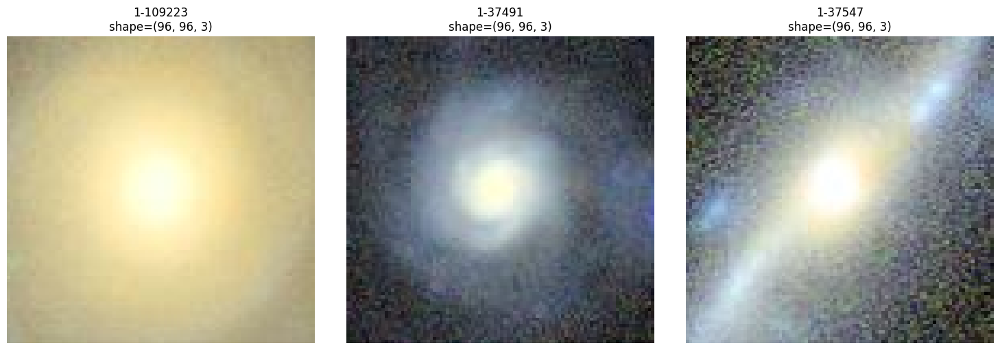

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def decode_rgb(rgb):
    """
    Convert the nested object-array RGB representation
    from the replication dataset into a standard uint8 image.
    """
    return np.asarray(
        [[np.asarray(pixel, dtype=np.uint8) for pixel in row] for row in rgb],
        dtype=np.uint8
    )

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, i in zip(axes, range(3)):
    rgb = decode_rgb(replication_df.iloc[i]["rgb"])

    ax.imshow(rgb)
    ax.set_title(
        f"{replication_df.iloc[i]['manga_id']}\n"
        f"shape={rgb.shape}"
    )
    ax.axis("off")

    print(
        replication_df.iloc[i]["manga_id"],
        "→",
        rgb.shape,
        rgb.dtype,
        "range:",
        rgb.min(),
        rgb.max()
    )

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd

# Exclude the 50 held-out evaluation galaxies
eval_ids = set(eval_manga_ids)

candidate_df = replication_df[
    ~replication_df["manga_id"].astype(str).isin(eval_ids)
].copy()

def decode_rgb(rgb):
    return np.asarray(
        [[np.asarray(pixel, dtype=np.uint8) for pixel in row] for row in rgb],
        dtype=np.uint8
    )

valid = []
shapes = []
mins = []
maxs = []

for _, row in candidate_df.iterrows():
    try:
        img = decode_rgb(row["rgb"])

        valid.append(
            img.ndim == 3
            and img.shape == (96, 96, 3)
            and img.dtype == np.uint8
            and np.isfinite(img).all()
        )

        shapes.append(img.shape)
        mins.append(int(img.min()))
        maxs.append(int(img.max()))

    except Exception:
        valid.append(False)
        shapes.append(None)
        mins.append(np.nan)
        maxs.append(np.nan)

candidate_df["rgb_valid"] = valid

print("Candidate galaxies:", len(candidate_df))
print("Valid RGB images:", candidate_df["rgb_valid"].sum())
print("Invalid RGB images:", (~candidate_df["rgb_valid"]).sum())

print("\nDataset split labels:")
print(candidate_df["split"].value_counts(dropna=False))

print("\nRGB intensity statistics:")
print(
    pd.DataFrame({
        "min": mins,
        "max": maxs
    }).describe()
)

print("\nShape distribution:")
print(pd.Series([str(x) for x in shapes]).value_counts().head(10))

Candidate galaxies: 2789
Valid RGB images: 2789
Invalid RGB images: 0

Dataset split labels:
split
train    2789
Name: count, dtype: int64

RGB intensity statistics:
               min          max
count  2789.000000  2789.000000
mean     22.337755   254.431337
std      30.819229     3.517333
min       0.000000   205.000000
25%       0.000000   255.000000
50%       7.000000   255.000000
75%      36.000000   255.000000
max     169.000000   255.000000

Shape distribution:
(96, 96, 3)    2789
Name: count, dtype: int64


Candidate galaxies: 2789
Evaluation overlap: 0

Split:
  Train: 2369
  Val  : 420

Bar-vote distribution:
         train  val
bar_bin            
0-4        515   91
5-11       676  120
12-22      595  105
23+        583  104
Train: 500/2369
Train: 1000/2369
Train: 1500/2369
Train: 2000/2369

Final arrays:
Train: (2369, 64, 64, 3) uint8
Val  : (420, 64, 64, 3) uint8


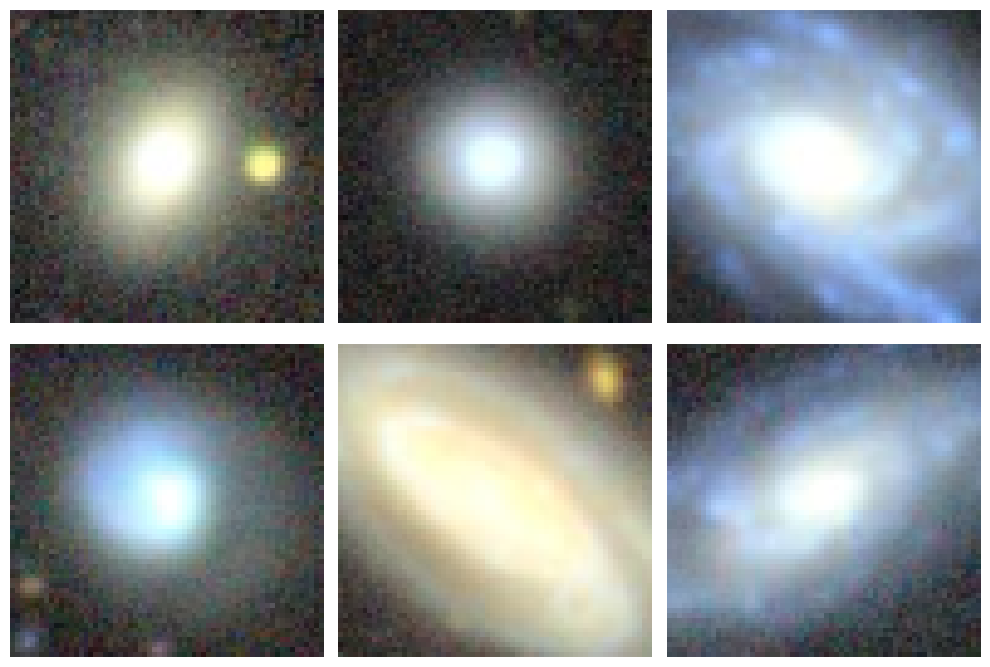


Saved:
  /content/galaxy_score_dataset/train_rgb64.npy  (27.8 MB)
  /content/galaxy_score_dataset/val_rgb64.npy    (4.9 MB)
  /content/galaxy_score_dataset/train_metadata.csv
  /content/galaxy_score_dataset/val_metadata.csv


In [ ]:
# ============================================================
# STEP 1 — BUILD GALAXY SCORE-PRIOR DATASET
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

SEED = 42
IMG_SIZE = 64
TRAIN_FRACTION = 0.85

np.random.seed(SEED)
random.seed(SEED)

OUT_DIR = "/content/galaxy_score_dataset"
os.makedirs(OUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# Verify required objects from previous cells
# ------------------------------------------------------------
required = ["replication_df", "eval_manga_ids"]

missing = [x for x in required if x not in globals()]
if missing:
    raise RuntimeError(
        f"Missing objects: {missing}. "
        "Please rerun the metadata-loading cell first."
    )

# ------------------------------------------------------------
# Remove the 50 held-out evaluation galaxies
# ------------------------------------------------------------
candidate_df = replication_df[
    ~replication_df["manga_id"].astype(str).isin(eval_manga_ids)
].copy()

candidate_df = candidate_df.reset_index(drop=True)

print("Candidate galaxies:", len(candidate_df))
print("Evaluation overlap:",
      candidate_df["manga_id"].astype(str).isin(eval_manga_ids).sum())

# ------------------------------------------------------------
# Stratified split using GZ3D bar-vote strength.
#
# This is NOT a classification task.
# We only use bar-vote bins so the validation set samples
# weakly and strongly barred galaxies similarly to training.
# ------------------------------------------------------------
vote_bins = [-1, 4, 11, 22, np.inf]
vote_labels = ["0-4", "5-11", "12-22", "23+"]

candidate_df["bar_bin"] = pd.cut(
    candidate_df["gz_bar_votes"],
    bins=vote_bins,
    labels=vote_labels
)

train_indices = []
val_indices = []

for label in vote_labels:
    idx = candidate_df.index[
        candidate_df["bar_bin"] == label
    ].to_numpy()

    rng = np.random.default_rng(SEED + vote_labels.index(label))
    rng.shuffle(idx)

    n_train = int(len(idx) * TRAIN_FRACTION)

    train_indices.extend(idx[:n_train])
    val_indices.extend(idx[n_train:])

train_indices = np.array(sorted(train_indices))
val_indices = np.array(sorted(val_indices))

train_df = candidate_df.loc[train_indices].copy()
val_df = candidate_df.loc[val_indices].copy()

print("\nSplit:")
print("  Train:", len(train_df))
print("  Val  :", len(val_df))

print("\nBar-vote distribution:")
print(
    pd.DataFrame({
        "train": train_df["bar_bin"].value_counts().sort_index(),
        "val": val_df["bar_bin"].value_counts().sort_index()
    })
)

# ------------------------------------------------------------
# Decode RGB field
# ------------------------------------------------------------
def decode_rgb(rgb):
    img = np.asarray(
        [[np.asarray(pixel, dtype=np.uint8)
          for pixel in row]
         for row in rgb],
        dtype=np.uint8
    )

    if img.shape != (96, 96, 3):
        raise ValueError(f"Unexpected RGB shape: {img.shape}")

    return img


def prepare_images(df, name):
    images = np.empty(
        (len(df), IMG_SIZE, IMG_SIZE, 3),
        dtype=np.uint8
    )

    for j, (_, row) in enumerate(df.iterrows()):
        img = decode_rgb(row["rgb"])

        # Area interpolation is appropriate for downsampling
        img_small = cv2.resize(
            img,
            (IMG_SIZE, IMG_SIZE),
            interpolation=cv2.INTER_AREA
        )

        images[j] = img_small

        if (j + 1) % 500 == 0:
            print(f"{name}: {j + 1}/{len(df)}")

    return images


# ------------------------------------------------------------
# Prepare training and validation arrays
# ------------------------------------------------------------
train_images = prepare_images(train_df, "Train")
val_images = prepare_images(val_df, "Val")

print("\nFinal arrays:")
print("Train:", train_images.shape, train_images.dtype)
print("Val  :", val_images.shape, val_images.dtype)

# ------------------------------------------------------------
# Save as uint8.
#
# Important:
# We do NOT save float32 copies.
# uint8 preserves the source information exactly and reduces
# storage/memory substantially. The training pipeline will
# convert to [0,1].
# ------------------------------------------------------------
train_path = os.path.join(OUT_DIR, "train_rgb64.npy")
val_path = os.path.join(OUT_DIR, "val_rgb64.npy")

np.save(train_path, train_images)
np.save(val_path, val_images)

train_meta_path = os.path.join(OUT_DIR, "train_metadata.csv")
val_meta_path = os.path.join(OUT_DIR, "val_metadata.csv")

train_df.drop(columns=["rgb"]).to_csv(train_meta_path, index=False)
val_df.drop(columns=["rgb"]).to_csv(val_meta_path, index=False)

# ------------------------------------------------------------
# Save configuration
# ------------------------------------------------------------
config = {
    "seed": SEED,
    "image_size": IMG_SIZE,
    "channels": 3,
    "source": "astronolan/gz3d-aion-replication-attempt",
    "representation": "96x96 rendered RGB -> 64x64 RGB",
    "normalization": "uint8 / 255.0 during training",
    "training_fraction": TRAIN_FRACTION,
    "held_out_evaluation_galaxies": 50,
    "candidate_training_galaxies": len(candidate_df),
    "train_galaxies": len(train_df),
    "validation_galaxies": len(val_df),
}

pd.Series(config).to_json(
    os.path.join(OUT_DIR, "dataset_config.json"),
    indent=2
)

# ------------------------------------------------------------
# Quick sanity check
# ------------------------------------------------------------
rng = np.random.default_rng(SEED)
show_ids = rng.choice(len(train_images), size=6, replace=False)

fig, axes = plt.subplots(2, 3, figsize=(10, 7))

for ax, idx in zip(axes.ravel(), show_ids):
    ax.imshow(train_images[idx])
    ax.axis("off")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Report storage
# ------------------------------------------------------------
def file_mb(path):
    return os.path.getsize(path) / 1024**2

print("\nSaved:")
print(f"  {train_path}  ({file_mb(train_path):.1f} MB)")
print(f"  {val_path}    ({file_mb(val_path):.1f} MB)")
print(f"  {train_meta_path}")
print(f"  {val_meta_path}")

In [ ]:
# ============================================================
# STEP 2A — SHOW THE EXACT DATASET/TRAINING INTERFACE
# ============================================================

from pathlib import Path

checks = {
    "datasets_get_dataset": (
        "/content/score_prior/score_flow/datasets.py",
        300,
        445
    ),
    "train_setup": (
        "/content/score_prior/train.py",
        1,
        180
    ),
    "score_model_config": (
        "/content/score_prior/configs/score_config.py",
        1,
        130
    ),
}

for name, (file, start, end) in checks.items():
    path = Path(file)

    print("\n" + "=" * 90)
    print(name)
    print(path)
    print("=" * 90)

    lines = path.read_text(errors="ignore").splitlines()

    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1:4d}: {lines[i]}")


datasets_get_dataset
/content/score_prior/score_flow/datasets.py
 300:       return dict(image=img, label=d.get('label', None))
 301: 
 302:   return preprocess_fn
 303: 
 304: 
 305: def get_dataset(
 306:     config: ml_collections.ConfigDict,
 307:     additional_dim: Optional[int] = None,
 308:     uniform_dequantization: bool = False,
 309:     evaluation: bool = False,
 310:     shuffle_seed: Optional[int] = None,
 311:     device_batch: bool = True
 312: ) -> Tuple[tf.data.Dataset, tf.data.Dataset, tf.data.Dataset]:
 313:   """Create data loaders for training, validation, and testing.
 314:   Most of the logic from `score_sde/datasets.py` is kept.
 315:   Args:
 316:     config: The config.
 317:     additional_dim: If not `None`, add an additional dimension
 318:       to the output data for jitted steps.
 319:     uniform_dequantization: If `True`, uniformly dequantize the images.
 320:       This is usually only used when evaluating log-likelihood [bits/dim]
 321:       of t

GALAXY SCORE-PRIOR DATASET
Total replication galaxies : 2839
Held-out evaluation        : 50
Candidate training pool    : 2789

Split
----------------------------------------------------------------------
Training   : 2369
Validation : 420

Bar-vote distribution
         train  validation
bar_bin                   
0-4        515          91
5-11       676         120
12-22      595         105
23+        583         104

Preparing images
----------------------------------------------------------------------
Train: 500/2369
Train: 1000/2369
Train: 1500/2369
Train: 2000/2369
Train: 2369/2369
Validation: 420/420

Array shapes
Train: (2369, 64, 64, 3) uint8
Val  : (420, 64, 64, 3) uint8

Pixel range
Train: 0 to 255
Val  : 3 to 255


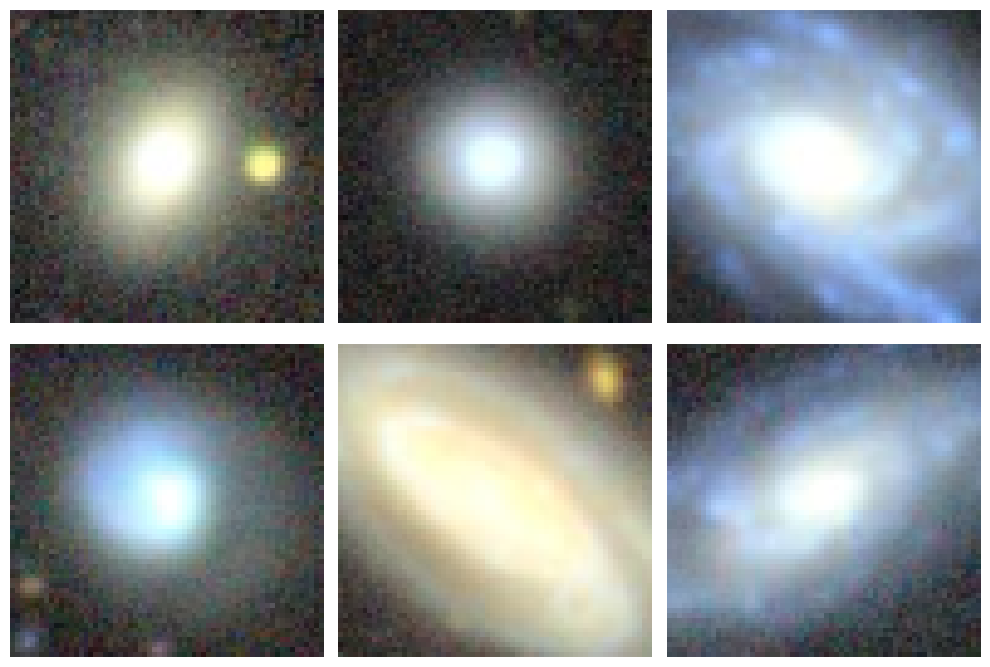


DATASET READY
Train array : /content/galaxy_score_dataset/train_rgb64.npy
             27.76 MB
Val array   : /content/galaxy_score_dataset/val_rgb64.npy
             4.92 MB

Metadata directory:
/content/galaxy_score_dataset

The 50 evaluation galaxies remain completely excluded.


In [ ]:
# ============================================================
# STEP 1 — BUILD THE GALAXY SCORE-PRIOR TRAINING DATASET
# ============================================================

import os
import json
import random
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

SEED = 42
IMG_SIZE = 64
TRAIN_FRACTION = 0.85

np.random.seed(SEED)
random.seed(SEED)

OUT_DIR = "/content/galaxy_score_dataset"
os.makedirs(OUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Remove the 50 held-out evaluation galaxies
# ------------------------------------------------------------

candidate_df = replication_df[
    ~replication_df["manga_id"].astype(str).isin(eval_manga_ids)
].copy()

candidate_df.reset_index(drop=True, inplace=True)

print("=" * 70)
print("GALAXY SCORE-PRIOR DATASET")
print("=" * 70)
print(f"Total replication galaxies : {len(replication_df)}")
print(f"Held-out evaluation        : {len(eval_manga_ids)}")
print(f"Candidate training pool    : {len(candidate_df)}")

assert len(candidate_df) == 2789
assert candidate_df["manga_id"].astype(str).isin(eval_manga_ids).sum() == 0

# ------------------------------------------------------------
# 2. Stratified train/validation split
#
# We preserve the distribution of GZ3D bar-vote strength.
# This is only for dataset balance; the model is NOT trained
# to predict bar votes.
# ------------------------------------------------------------

bins = [-1, 4, 11, 22, np.inf]
labels = ["0-4", "5-11", "12-22", "23+"]

candidate_df["bar_bin"] = pd.cut(
    candidate_df["gz_bar_votes"],
    bins=bins,
    labels=labels
)

train_indices = []
val_indices = []

for k, label in enumerate(labels):

    idx = candidate_df.index[
        candidate_df["bar_bin"] == label
    ].to_numpy()

    rng = np.random.default_rng(SEED + k)
    rng.shuffle(idx)

    n_train = int(len(idx) * TRAIN_FRACTION)

    train_indices.extend(idx[:n_train])
    val_indices.extend(idx[n_train:])

train_indices = np.array(sorted(train_indices))
val_indices = np.array(sorted(val_indices))

train_df = candidate_df.loc[train_indices].copy()
val_df = candidate_df.loc[val_indices].copy()

print("\nSplit")
print("-" * 70)
print(f"Training   : {len(train_df)}")
print(f"Validation : {len(val_df)}")

print("\nBar-vote distribution")
print(
    pd.DataFrame({
        "train": train_df["bar_bin"].value_counts().sort_index(),
        "validation": val_df["bar_bin"].value_counts().sort_index()
    }).fillna(0).astype(int)
)

# ------------------------------------------------------------
# 3. Decode nested RGB representation
# ------------------------------------------------------------

def decode_rgb(rgb):

    image = np.asarray(
        [
            [
                np.asarray(pixel, dtype=np.uint8)
                for pixel in row
            ]
            for row in rgb
        ],
        dtype=np.uint8
    )

    if image.shape != (96, 96, 3):
        raise ValueError(
            f"Unexpected image shape: {image.shape}"
        )

    return image


# ------------------------------------------------------------
# 4. Resize 96 -> 64
# ------------------------------------------------------------

def build_array(df, name):

    images = np.empty(
        (len(df), IMG_SIZE, IMG_SIZE, 3),
        dtype=np.uint8
    )

    for j, (_, row) in enumerate(df.iterrows()):

        image = decode_rgb(row["rgb"])

        image = cv2.resize(
            image,
            (IMG_SIZE, IMG_SIZE),
            interpolation=cv2.INTER_AREA
        )

        images[j] = image

        if (j + 1) % 500 == 0 or j + 1 == len(df):
            print(
                f"{name}: {j+1}/{len(df)}"
            )

    return images


print("\nPreparing images")
print("-" * 70)

train_images = build_array(train_df, "Train")
val_images = build_array(val_df, "Validation")

print("\nArray shapes")
print("Train:", train_images.shape, train_images.dtype)
print("Val  :", val_images.shape, val_images.dtype)

# ------------------------------------------------------------
# 5. Verify data
# ------------------------------------------------------------

assert train_images.shape[1:] == (64, 64, 3)
assert val_images.shape[1:] == (64, 64, 3)

assert np.isfinite(train_images).all()
assert np.isfinite(val_images).all()

assert train_images.dtype == np.uint8
assert val_images.dtype == np.uint8

print("\nPixel range")
print(
    "Train:",
    int(train_images.min()),
    "to",
    int(train_images.max())
)

print(
    "Val  :",
    int(val_images.min()),
    "to",
    int(val_images.max())
)

# ------------------------------------------------------------
# 6. Save arrays
# ------------------------------------------------------------

train_path = os.path.join(
    OUT_DIR,
    "train_rgb64.npy"
)

val_path = os.path.join(
    OUT_DIR,
    "val_rgb64.npy"
)

np.save(train_path, train_images)
np.save(val_path, val_images)

# ------------------------------------------------------------
# 7. Save metadata
# ------------------------------------------------------------

train_metadata = train_df.drop(
    columns=["rgb"]
)

val_metadata = val_df.drop(
    columns=["rgb"]
)

train_metadata.to_csv(
    os.path.join(
        OUT_DIR,
        "train_metadata.csv"
    ),
    index=False
)

val_metadata.to_csv(
    os.path.join(
        OUT_DIR,
        "val_metadata.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 8. Save exact configuration
# ------------------------------------------------------------

dataset_config = {
    "seed": SEED,
    "source_dataset":
        "astronolan/gz3d-aion-replication-attempt",
    "total_source_objects": int(len(replication_df)),
    "held_out_evaluation": int(len(eval_manga_ids)),
    "candidate_pool": int(len(candidate_df)),
    "training_objects": int(len(train_df)),
    "validation_objects": int(len(val_df)),
    "source_resolution": [96, 96, 3],
    "training_resolution": [64, 64, 3],
    "representation": "rendered RGB",
    "storage_dtype": "uint8",
    "training_scaling": "image / 255.0",
    "train_fraction": TRAIN_FRACTION,
    "split_method": "stratified by gz_bar_votes",
}

with open(
    os.path.join(
        OUT_DIR,
        "dataset_config.json"
    ),
    "w"
) as f:
    json.dump(
        dataset_config,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 9. Visual sanity check
# ------------------------------------------------------------

rng = np.random.default_rng(SEED)

indices = rng.choice(
    len(train_images),
    size=6,
    replace=False
)

fig, axes = plt.subplots(
    2, 3,
    figsize=(10, 7)
)

for ax, idx in zip(
    axes.ravel(),
    indices
):

    ax.imshow(train_images[idx])
    ax.axis("off")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. Final report
# ------------------------------------------------------------

def size_mb(path):
    return os.path.getsize(path) / (1024 ** 2)

print("\n" + "=" * 70)
print("DATASET READY")
print("=" * 70)

print(f"Train array : {train_path}")
print(f"             {size_mb(train_path):.2f} MB")

print(f"Val array   : {val_path}")
print(f"             {size_mb(val_path):.2f} MB")

print(f"\nMetadata directory:")
print(OUT_DIR)

print("\nThe 50 evaluation galaxies remain completely excluded.")

In [ ]:
# ============================================================
# STEP 2 — INSPECT FENG TRAINING INTERFACE
# ============================================================

from pathlib import Path

def show_section(path, start, end, title):
    path = Path(path)

    print("\n" + "=" * 90)
    print(title)
    print(path)
    print("=" * 90)

    lines = path.read_text(errors="ignore").splitlines()

    start = max(1, start)
    end = min(len(lines), end)

    for i in range(start - 1, end):
        print(f"{i+1:4d}: {lines[i]}")


# ------------------------------------------------------------
# Dataset interface
# ------------------------------------------------------------

show_section(
    "/content/score_prior/score_flow/datasets.py",
    300,
    445,
    "DATASET INTERFACE"
)


# ------------------------------------------------------------
# Training initialization
# ------------------------------------------------------------

show_section(
    "/content/score_prior/train.py",
    1,
    180,
    "TRAINING SCRIPT"
)


# ------------------------------------------------------------
# Score-model configuration
# ------------------------------------------------------------

show_section(
    "/content/score_prior/configs/score_config.py",
    1,
    130,
    "SCORE CONFIGURATION"
)


DATASET INTERFACE
/content/score_prior/score_flow/datasets.py
 300:       return dict(image=img, label=d.get('label', None))
 301: 
 302:   return preprocess_fn
 303: 
 304: 
 305: def get_dataset(
 306:     config: ml_collections.ConfigDict,
 307:     additional_dim: Optional[int] = None,
 308:     uniform_dequantization: bool = False,
 309:     evaluation: bool = False,
 310:     shuffle_seed: Optional[int] = None,
 311:     device_batch: bool = True
 312: ) -> Tuple[tf.data.Dataset, tf.data.Dataset, tf.data.Dataset]:
 313:   """Create data loaders for training, validation, and testing.
 314:   Most of the logic from `score_sde/datasets.py` is kept.
 315:   Args:
 316:     config: The config.
 317:     additional_dim: If not `None`, add an additional dimension
 318:       to the output data for jitted steps.
 319:     uniform_dequantization: If `True`, uniformly dequantize the images.
 320:       This is usually only used when evaluating log-likelihood [bits/dim]
 321:       of the 

In [ ]:
# ============================================================
# STEP 2 — ADD GALAXY_RGB DATASET TO FENG SCORE-PRIOR CODE
# ============================================================

from pathlib import Path
import shutil
import textwrap

DATASETS_FILE = Path(
    "/content/score_prior/score_flow/datasets.py"
)

BACKUP_FILE = Path(
    "/content/score_prior/score_flow/datasets.py.original"
)

# ------------------------------------------------------------
# 1. Backup the original implementation
# ------------------------------------------------------------

if not BACKUP_FILE.exists():
    shutil.copy2(DATASETS_FILE, BACKUP_FILE)
    print("Original datasets.py backed up.")
else:
    print("Original backup already exists.")

source = DATASETS_FILE.read_text()

# ------------------------------------------------------------
# 2. Add GALAXY_RGB to supported datasets
# ------------------------------------------------------------

old = "SUPPORTED_DATASETS = ['CIFAR10', 'CELEBA', 'fastMRI', 'SVHN', 'LSUN', 'CelebAHQ', 'SgrA', 'GRMHD']"

new = """SUPPORTED_DATASETS = [
    'CIFAR10', 'CELEBA', 'fastMRI', 'SVHN', 'LSUN',
    'CelebAHQ', 'SgrA', 'GRMHD', 'GALAXY_RGB'
]"""

if old in source:
    source = source.replace(old, new)
    print("Added GALAXY_RGB to SUPPORTED_DATASETS.")
elif " 'GALAXY_RGB'" in source or "'GALAXY_RGB'" in source:
    print("GALAXY_RGB already present.")
else:
    raise RuntimeError(
        "Could not find SUPPORTED_DATASETS line."
    )

# ------------------------------------------------------------
# 3. Insert a dedicated dataset path inside get_dataset()
#
# The dataset is already cached as:
#   train_rgb64.npy
#   val_rgb64.npy
#
# We keep the 50 evaluation galaxies completely outside this
# pipeline.
# ------------------------------------------------------------

marker = """  # Get dataset builder.
  dataset_builder, resize_op = get_dataset_builder_and_resize_op(config, shuffle_seed)
"""

galaxy_block = r'''
  # ----------------------------------------------------------
  # Custom Legacy/GZ3D galaxy RGB dataset.
  #
  # This branch intentionally bypasses TFDS because the galaxy
  # arrays have already been constructed and verified locally.
  # ----------------------------------------------------------
  if config.data.dataset == 'GALAXY_RGB':

    train_path = '/content/galaxy_score_dataset/train_rgb64.npy'
    val_path = '/content/galaxy_score_dataset/val_rgb64.npy'

    if not tf.io.gfile.exists(train_path):
      raise FileNotFoundError(train_path)

    if not tf.io.gfile.exists(val_path):
      raise FileNotFoundError(val_path)

    train_images = np.load(train_path, mmap_mode='r')
    val_images = np.load(val_path, mmap_mode='r')

    if train_images.ndim != 4 or train_images.shape[1:] != (
        config.data.image_size,
        config.data.image_size,
        config.data.num_channels):

      raise ValueError(
          f'Unexpected training shape: {train_images.shape}. '
          f'Expected (*, {config.data.image_size}, '
          f'{config.data.image_size}, {config.data.num_channels}).'
      )

    if val_images.ndim != 4 or val_images.shape[1:] != (
        config.data.image_size,
        config.data.image_size,
        config.data.num_channels):

      raise ValueError(
          f'Unexpected validation shape: {val_images.shape}.'
      )

    def galaxy_preprocess(image, training=True):
      image = tf.cast(image, tf.float32) / 255.0

      if training and config.data.random_flip:
        image = tf.image.random_flip_left_right(image)
        image = tf.image.random_flip_up_down(image)

      if training and getattr(config.data, 'random_rotation', False):
        k = tf.random.uniform(
            shape=[],
            minval=0,
            maxval=4,
            dtype=tf.int32)
        image = tf.image.rot90(image, k)

      if config.data.centered:
        image = image * 2.0 - 1.0

      return {'image': image, 'label': None}

    def make_galaxy_dataset(images, training):

      # Materialize the small arrays into TensorFlow datasets.
      # Total data size is only ~33 MB.
      ds = tf.data.Dataset.from_tensor_slices(images)

      if training:
        ds = ds.shuffle(
            min(10000, len(images)),
            seed=shuffle_seed,
            reshuffle_each_iteration=True)

      ds = ds.repeat(count=num_epochs)

      ds = ds.map(
          lambda x: galaxy_preprocess(
              x, training=training),
          num_parallel_calls=tf.data.experimental.AUTOTUNE)

      for batch_size_i in reversed(batch_dims):
        ds = ds.batch(batch_size_i, drop_remainder=True)

      return ds.prefetch(prefetch_size)

    train_ds = make_galaxy_dataset(
        train_images, training=True)

    val_ds = make_galaxy_dataset(
        val_images, training=False)

    # We don't use a separate test set during score-prior training.
    # The scientifically important 50-galaxy test set is handled
    # separately by the inverse-imaging evaluation pipeline.
    test_ds = val_ds

    return train_ds, val_ds, test_ds

'''

if marker not in source:
    raise RuntimeError(
        "Could not find dataset-builder insertion point."
    )

source = source.replace(
    marker,
    galaxy_block + marker
)

# ------------------------------------------------------------
# 4. Write patched file
# ------------------------------------------------------------

DATASETS_FILE.write_text(source)

print("\nPatched:", DATASETS_FILE)

# ------------------------------------------------------------
# 5. Basic syntax check
# ------------------------------------------------------------

import py_compile

py_compile.compile(
    str(DATASETS_FILE),
    doraise=True
)

print("Syntax check: PASSED")

# ------------------------------------------------------------
# 6. Confirm patch
# ------------------------------------------------------------

updated = DATASETS_FILE.read_text()

print(
    "GALAXY_RGB occurrences:",
    updated.count("GALAXY_RGB")
)

print(
    "Backup:",
    BACKUP_FILE
)

print("\nDataset interface is ready.")

Original datasets.py backed up.
Added GALAXY_RGB to SUPPORTED_DATASETS.

Patched: /content/score_prior/score_flow/datasets.py
Syntax check: PASSED
GALAXY_RGB occurrences: 2
Backup: /content/score_prior/score_flow/datasets.py.original

Dataset interface is ready.


In [ ]:
# ============================================================
# STEP 3A — FIX PROTOBUF COMPATIBILITY
# ============================================================

import sys
import subprocess

print("Checking current protobuf version...")

subprocess.run([
    sys.executable, "-m", "pip", "show", "protobuf"
])

print("\nUpgrading protobuf to match tensorflow-metadata...")

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "-q",
    "--upgrade",
    "protobuf==6.31.1"
])

print("\nProtobuf installation completed.")

subprocess.run([
    sys.executable, "-m", "pip", "show", "protobuf"
])

print("\nTesting imports...")

import google.protobuf
print("protobuf:", google.protobuf.__version__)

import ml_collections
print("ml_collections:", ml_collections.__version__)

import flax
print("flax:", flax.__version__)

import optax
print("optax:", optax.__version__)

import tensorflow as tf
print("TensorFlow:", tf.__version__)

import tensorflow_datasets as tfds
print("TensorFlow Datasets: import successful")

print("\nEnvironment check completed.")

Checking current protobuf version...

Upgrading protobuf to match tensorflow-metadata...

Protobuf installation completed.

Testing imports...
protobuf: 6.31.1


ModuleNotFoundError: No module named 'ml_collections'

**Change enviernment to JAX**

In [ ]:
# ============================================================
# FIX: JAX / TENSORFLOW-PROBABILITY COMPATIBILITY
# ============================================================

import subprocess
import sys

print("Installing a compatible JAX + TFP stack...")

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "--upgrade",
    "jax[cuda12]",
    "tensorflow-probability"
])

print("\nInstallation complete.")
print("IMPORTANT: Restart the Colab runtime now:")
print("Runtime → Restart session")

Installing a compatible JAX + TFP stack...

Installation complete.
IMPORTANT: Restart the Colab runtime now:
Runtime → Restart session


In [ ]:
# ============================================================
# STEP 3B — PIN A COMPATIBLE LEGACY JAX/TFP STACK
# ============================================================

import subprocess
import sys

packages = [
    "jax==0.4.38",
    "jaxlib==0.4.38",
    "tensorflow-probability==0.24.0",
]

print("Installing pinned versions...")
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "--force-reinstall"
] + packages)

print("\nDone.")
print("Now restart the Colab runtime:")
print("Runtime → Restart session")

Installing pinned versions...

Done.
Now restart the Colab runtime:
Runtime → Restart session


**Try not run 3B**

In [ ]:
# ============================================================
# STEP 3B — VERIFY PINNED ENVIRONMENT
# ============================================================

import sys
import jax
import tensorflow_probability as tfp

print("JAX :", jax.__version__)
print("TFP :", tfp.__version__)

print("\nJAX devices:")
for d in jax.devices():
    print(" ", d)

# Test TFP JAX backend
import tensorflow_probability.substrates.jax as tfp_jax
print("\n✓ TFP JAX substrate: OK")

# Test Feng's actual dependency
sys.path.insert(0, "/content/score_prior")

from score_flow import sde_lib
print("✓ Feng sde_lib: OK")

print("\nEnvironment check complete.")

AttributeError: module 'jax_cuda12_plugin._sparse' has no attribute 'sparse_supported'

In [ ]:
# ============================================================
# JAX CLEANUP — REMOVE CONFLICTING JAX/CUDA PLUGINS
# ============================================================

import subprocess
import sys

packages_to_remove = [
    "jax",
    "jaxlib",
    "jax-cuda12-plugin",
    "jax-cuda12-pjrt",
    "jax-cuda13-plugin",
    "jax-cuda13-pjrt",
]

print("Removing conflicting JAX packages...")

subprocess.run(
    [sys.executable, "-m", "pip", "uninstall", "-y"] + packages_to_remove,
    check=False
)

print("\nCleanup complete.")

Removing conflicting JAX packages...

Cleanup complete.


In [ ]:
# ============================================================
# INSTALL CLEAN JAX/JAXLIB
# ============================================================

import subprocess
import sys

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "--no-cache-dir",
    "jax==0.4.38",
    "jaxlib==0.4.38",
])

print("JAX 0.4.38 installed.")
print()
print("NOW RESTART THE COLAB SESSION:")
print("Runtime → Restart session")

JAX 0.4.38 installed.

NOW RESTART THE COLAB SESSION:
Runtime → Restart session


Runtime → Restart session
**bold text**


In [ ]:
# ============================================================
# STEP 5 — VERIFY JAX GPU
# ============================================================

import jax

print("JAX version:", jax.__version__)

print("\nJAX devices:")
for d in jax.devices():
    print(" ", d)

print("\nDefault backend:", jax.default_backend())

JAX version: 0.4.38

JAX devices:
  TFRT_CPU_0

Default backend: cpu


In [ ]:
# ============================================================
# STEP 6 — VERIFY TFP + FENG SCORE PRIOR
# ============================================================

import sys
import jax
import tensorflow_probability as tfp

print("JAX :", jax.__version__)
print("TFP :", tfp.__version__)
print("Backend:", jax.default_backend())
print("Devices:", jax.devices())

# Test TensorFlow Probability's JAX backend
import tensorflow_probability.substrates.jax as tfp_jax

print("\n✓ TensorFlow Probability JAX backend: OK")

# Load Feng's repository
sys.path.insert(0, "/content/score_prior")

from score_flow import sde_lib

print("✓ Feng score_flow.sde_lib: OK")

print("\n========================================")
print("ENVIRONMENT READY")
print("========================================")

JAX : 0.4.38
TFP : 0.24.0
Backend: cpu
Devices: [CpuDevice(id=0)]

✓ TensorFlow Probability JAX backend: OK
✓ Feng score_flow.sde_lib: OK

ENVIRONMENT READY


In [ ]:
# ============================================================
# STEP 7A — INSPECT FENG CONFIG STRUCTURE
# ============================================================

import os

repo = "/content/score_prior"

print("Config-related files in Feng repository:\n")

for root, dirs, files in os.walk(repo):
    # Don't print cache/git directories
    dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]

    for file in files:
        if file.endswith(".py") and (
            "config" in file.lower()
            or root.endswith("/configs")
        ):
            path = os.path.join(root, file)
            print(path)

Config-related files in Feng repository:

/content/score_prior/configs/score_config.py
/content/score_prior/configs/dpi_config.py
/content/score_prior/score_flow/configs/default_imagenet32_configs.py
/content/score_prior/score_flow/configs/default_cifar10_configs.py


In [ ]:
# ============================================================
# STEP 7B — FIX GALAXY SCORE-PRIOR CONFIGURATION
# ============================================================

from pathlib import Path

config_path = Path("/content/score_prior/configs/galaxy_rgb64.py")

config_text = r'''
"""64x64 RGB galaxy score-prior configuration."""

from configs.score_config import get_config as base_config


def get_config():

    config = base_config()

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    config.training.sde = "vpsde"
    config.training.likelihood_weighting = False
    config.training.importance_weighting = False
    config.training.continuous = True
    config.training.reduce_mean = False

    config.training.n_iters = 20000
    config.training.batch_size = 32

    config.training.snapshot_freq = 1000
    config.training.log_freq = 100
    config.training.eval_freq = 1000

    config.training.n_jitted_steps = 1


    # --------------------------------------------------------
    # Dataset
    # --------------------------------------------------------

    config.data.dataset = "GALAXY_RGB"

    config.data.image_size = 64
    config.data.num_channels = 3

    config.data.centered = False

    config.data.normalization_type = "score_sde"
    config.data.n_bits = 8
    config.data.uniform_dequantization = False

    config.data.random_flip = True
    config.data.random_rotation = True
    config.data.random_zoom = False

    config.data.taper_frac_radius_min = 0.0
    config.data.taper_frac_radius_max = 1.0

    config.data.constant_flux = False


    # --------------------------------------------------------
    # NCSN++ model
    # --------------------------------------------------------

    config.model.name = "ncsnpp"

    config.model.num_scales = 1000

    config.model.sigma_min = 0.002
    config.model.sigma_max = 50.0

    config.model.beta_min = 0.1
    config.model.beta_max = 10.0

    config.model.dropout = 0.1

    config.model.scale_by_sigma = False

    config.model.ema_rate = 0.9999

    config.model.normalization = "GroupNorm"
    config.model.nonlinearity = "swish"

    config.model.nf = 32

    config.model.ch_mult = (1, 2, 2, 2)

    config.model.num_res_blocks = 2

    config.model.attn_resolutions = (16,)

    config.model.resamp_with_conv = True

    config.model.fir = True
    config.model.fir_kernel = [1, 3, 3, 1]

    config.model.skip_rescale = True

    config.model.resblock_type = "biggan"

    config.model.progressive = "none"
    config.model.progressive_input = "residual"
    config.model.progressive_combine = "sum"

    config.model.attention_type = "ddpm"

    config.model.embedding_type = "positional"

    config.model.init_scale = 0.0

    config.model.fourier_scale = 16

    config.model.conv_size = 3

    config.model.interpolation = "bilinear"


    # --------------------------------------------------------
    # Optimizer
    # --------------------------------------------------------

    config.optim.weight_decay = 0.0
    config.optim.optimizer = "Adam"

    config.optim.lr = 2e-4

    config.optim.beta1 = 0.9
    config.optim.eps = 1e-8

    config.optim.warmup = 2000

    config.optim.grad_clip = 1.0


    # --------------------------------------------------------
    # Evaluation
    # --------------------------------------------------------

    config.eval.batch_size = 32


    # --------------------------------------------------------
    # Reproducibility
    # --------------------------------------------------------

    config.seed = 42

    return config
'''

config_path.write_text(config_text)

print("✓ Configuration rewritten:")
print(config_path)

print("\nCorrected import:")
print("  from configs.score_config import get_config as base_config")

✓ Configuration rewritten:
/content/score_prior/configs/galaxy_rgb64.py

Corrected import:
  from configs.score_config import get_config as base_config


In [ ]:
# ============================================================
# STEP 7C — CONFIG + DATASET + NCSN++ INITIALIZATION TEST
# ============================================================

import sys
import os
import numpy as np
import jax

REPO = "/content/score_prior"

if REPO not in sys.path:
    sys.path.insert(0, REPO)

print("=" * 70)
print("GALAXY SCORE PRIOR — CONFIGURATION & MODEL TEST")
print("=" * 70)

# ------------------------------------------------------------
# 1. Environment
# ------------------------------------------------------------

print("\n[1] JAX ENVIRONMENT")
print("JAX version :", jax.__version__)
print("Backend     :", jax.default_backend())
print("Devices     :", jax.devices())


# ------------------------------------------------------------
# 2. Load configuration
# ------------------------------------------------------------

print("\n[2] LOADING CONFIGURATION")

from configs.galaxy_rgb64 import get_config

config = get_config()

print("Dataset       :", config.data.dataset)
print("Image size    :", config.data.image_size)
print("Channels      :", config.data.num_channels)
print("Batch size    :", config.training.batch_size)
print("Model         :", config.model.name)
print("SDE           :", config.training.sde)
print("Training iters:", config.training.n_iters)

print("✓ Configuration loaded")


# ------------------------------------------------------------
# 3. Load Feng dataset pipeline
# ------------------------------------------------------------

print("\n[3] LOADING GALAXY DATASET")

from score_flow import datasets

train_ds, eval_ds, dataset_info = datasets.get_dataset(
    config,
    additional_dim=config.training.n_jitted_steps,
    uniform_dequantization=config.data.uniform_dequantization,
    shuffle_seed=config.seed,
)

print("✓ Dataset loader initialized")


# ------------------------------------------------------------
# 4. Inspect one training batch
# ------------------------------------------------------------

print("\n[4] CHECKING TRAINING BATCH")

batch = next(iter(train_ds))

images = batch["image"]
images_np = np.asarray(images)

print("Batch shape :", images.shape)
print("Dtype       :", images.dtype)
print("Minimum     :", float(images_np.min()))
print("Maximum     :", float(images_np.max()))
print("Mean        :", float(images_np.mean()))
print("Std         :", float(images_np.std()))


# ------------------------------------------------------------
# 5. Validate dataset
# ------------------------------------------------------------

print("\n[5] DATASET VALIDATION")

expected_shape = (
    config.training.n_jitted_steps,
    config.training.batch_size,
    config.data.image_size,
    config.data.image_size,
    config.data.num_channels,
)

print("Expected shape:", expected_shape)
print("Actual shape  :", tuple(images.shape))

assert images.shape == expected_shape, (
    f"Shape mismatch: {images.shape} != {expected_shape}"
)

assert np.isfinite(images_np).all(), \
    "Dataset contains NaN or Inf values."

assert images_np.min() >= 0.0, \
    "Dataset contains values below 0."

assert images_np.max() <= 1.0, \
    "Dataset contains values above 1."

print("✓ Shape is correct")
print("✓ Values are finite")
print("✓ Pixel range is [0, 1]")


# ------------------------------------------------------------
# 6. Initialize NCSN++ model
# ------------------------------------------------------------

print("\n[6] INITIALIZING NCSN++")

from score_flow.models import utils as mutils

rng = jax.random.PRNGKey(config.seed)

score_model, init_model_state, params = mutils.init_model(
    rng,
    config
)

print("✓ NCSN++ initialization successful")


# ------------------------------------------------------------
# 7. Count parameters
# ------------------------------------------------------------

print("\n[7] MODEL SIZE")

def count_parameters(tree):
    leaves = jax.tree_util.tree_leaves(tree)
    return sum(int(np.prod(x.shape)) for x in leaves)

n_params = count_parameters(params)

print("Total parameters :", f"{n_params:,}")
print("Parameters (M)   :", f"{n_params / 1e6:.2f} M")


# ------------------------------------------------------------
# 8. Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("INITIALIZATION TEST FINISHED")
print("=" * 70)

print("\nRESULT SUMMARY")
print("JAX GPU        :", jax.default_backend() == "gpu")
print("Dataset        :", config.data.dataset)
print("Input          :", f"{config.data.image_size}x"
                         f"{config.data.image_size}x"
                         f"{config.data.num_channels}")
print("NCSN++         : initialized")
print("Parameters     :", f"{n_params / 1e6:.2f} M")

print("\n✓ READY FOR THE NEXT STEP")

GALAXY SCORE PRIOR — CONFIGURATION & MODEL TEST

[1] JAX ENVIRONMENT
JAX version : 0.4.38
Backend     : cpu
Devices     : [CpuDevice(id=0)]

[2] LOADING CONFIGURATION


ModuleNotFoundError: No module named 'ml_collections'

In [ ]:
# ============================================================
# STEP 7D — FIX CONFIG TYPE + RERUN INITIALIZATION TEST
# ============================================================

import sys
import os
import importlib
import numpy as np
import jax

REPO = "/content/score_prior"

if REPO not in sys.path:
    sys.path.insert(0, REPO)

print("=" * 70)
print("FIXING CONFIGURATION AND TESTING NCSN++")
print("=" * 70)

# ------------------------------------------------------------
# 1. Fix ml_collections type mismatch
# ------------------------------------------------------------

config_path = os.path.join(REPO, "configs", "galaxy_rgb64.py")

with open(config_path, "r") as f:
    config_text = f.read()

old_line = "config.optim.weight_decay = 0.0"
new_line = "config.optim.weight_decay = 0"

if old_line in config_text:
    config_text = config_text.replace(old_line, new_line)
    with open(config_path, "w") as f:
        f.write(config_text)
    print("\n✓ Fixed weight_decay: 0.0 → 0")
else:
    print("\n✓ weight_decay is already corrected")


# ------------------------------------------------------------
# 2. Clear cached config module
# ------------------------------------------------------------

importlib.invalidate_caches()

for module_name in list(sys.modules):
    if module_name == "configs.galaxy_rgb64":
        del sys.modules[module_name]


# ------------------------------------------------------------
# 3. Environment check
# ------------------------------------------------------------

print("\n[1] JAX ENVIRONMENT")
print("JAX version :", jax.__version__)
print("Backend     :", jax.default_backend())
print("Devices     :", jax.devices())

if jax.default_backend() != "gpu":
    raise RuntimeError("JAX is not using the GPU.")


# ------------------------------------------------------------
# 4. Load configuration
# ------------------------------------------------------------

print("\n[2] LOADING CONFIGURATION")

from configs.galaxy_rgb64 import get_config

config = get_config()

print("Dataset       :", config.data.dataset)
print("Image size    :", config.data.image_size)
print("Channels      :", config.data.num_channels)
print("Batch size    :", config.training.batch_size)
print("Model         :", config.model.name)
print("SDE           :", config.training.sde)
print("Training iters:", config.training.n_iters)

print("✓ Configuration loaded")


# ------------------------------------------------------------
# 5. Load dataset
# ------------------------------------------------------------

print("\n[3] LOADING GALAXY_RGB DATASET")

from score_flow import datasets

train_ds, eval_ds, dataset_info = datasets.get_dataset(
    config,
    additional_dim=config.training.n_jitted_steps,
    uniform_dequantization=config.data.uniform_dequantization,
    shuffle_seed=config.seed,
)

print("✓ Dataset loader initialized")


# ------------------------------------------------------------
# 6. Inspect training batch
# ------------------------------------------------------------

print("\n[4] CHECKING TRAINING BATCH")

batch = next(iter(train_ds))
images = batch["image"]
images_np = np.asarray(images)

print("Batch shape :", images.shape)
print("Dtype       :", images.dtype)
print("Minimum     :", float(images_np.min()))
print("Maximum     :", float(images_np.max()))
print("Mean        :", float(images_np.mean()))
print("Std         :", float(images_np.std()))


# ------------------------------------------------------------
# 7. Validate dataset
# ------------------------------------------------------------

print("\n[5] DATASET VALIDATION")

expected_shape = (
    config.training.n_jitted_steps,
    config.training.batch_size,
    config.data.image_size,
    config.data.image_size,
    config.data.num_channels,
)

print("Expected shape:", expected_shape)
print("Actual shape  :", tuple(images.shape))

assert images.shape == expected_shape, (
    f"Shape mismatch: {images.shape} != {expected_shape}"
)

assert np.isfinite(images_np).all(), \
    "Dataset contains NaN or Inf values."

assert images_np.min() >= 0.0, \
    "Dataset contains values below 0."

assert images_np.max() <= 1.0, \
    "Dataset contains values above 1."

print("✓ Shape is correct")
print("✓ Values are finite")
print("✓ Pixel range is [0, 1]")


# ------------------------------------------------------------
# 8. Initialize NCSN++
# ------------------------------------------------------------

print("\n[6] INITIALIZING NCSN++")

from score_flow.models import utils as mutils

rng = jax.random.PRNGKey(config.seed)

score_model, init_model_state, params = mutils.init_model(
    rng,
    config
)

print("✓ NCSN++ initialization successful")


# ------------------------------------------------------------
# 9. Count parameters
# ------------------------------------------------------------

print("\n[7] MODEL SIZE")

def count_parameters(tree):
    leaves = jax.tree_util.tree_leaves(tree)
    return sum(int(np.prod(x.shape)) for x in leaves)

n_params = count_parameters(params)

print("Total parameters :", f"{n_params:,}")
print("Parameters (M)   :", f"{n_params / 1e6:.2f} M")


# ------------------------------------------------------------
# 10. Final result
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("INITIALIZATION TEST COMPLETE")
print("=" * 70)

print("\nRESULT")
print("✓ JAX GPU       :", jax.default_backend() == "gpu")
print("✓ Dataset       :", config.data.dataset)
print("✓ Input         :", f"{config.data.image_size}x"
                         f"{config.data.image_size}x"
                         f"{config.data.num_channels}")
print("✓ NCSN++        : initialized")
print("✓ Parameters    :", f"{n_params / 1e6:.2f} M")
print("\nREADY FOR THE NEXT STEP")

FIXING CONFIGURATION AND TESTING NCSN++

✓ weight_decay is already corrected

[1] JAX ENVIRONMENT
JAX version : 0.4.38
Backend     : cpu
Devices     : [CpuDevice(id=0)]


RuntimeError: JAX is not using the GPU.

In [ ]:
# ============================================================
# STEP 7E — INSPECT FENG DATASET BATCH SHAPE
# ============================================================

import sys
import numpy as np
import jax

REPO = "/content/score_prior"

if REPO not in sys.path:
    sys.path.insert(0, REPO)

from configs.galaxy_rgb64 import get_config
from score_flow import datasets

config = get_config()

print("=" * 70)
print("FENG DATASET SHAPE DIAGNOSTIC")
print("=" * 70)

print("\nConfiguration")
print("n_jitted_steps :", config.training.n_jitted_steps)
print("batch_size     :", config.training.batch_size)
print("image_size     :", config.data.image_size)
print("channels       :", config.data.num_channels)

# ------------------------------------------------------------
# Load exactly as before
# ------------------------------------------------------------

train_ds, eval_ds, dataset_info = datasets.get_dataset(
    config,
    additional_dim=config.training.n_jitted_steps,
    uniform_dequantization=config.data.uniform_dequantization,
    shuffle_seed=config.seed,
)

# ------------------------------------------------------------
# Inspect batch
# ------------------------------------------------------------

batch = next(iter(train_ds))

print("\nBatch keys:")
print(batch.keys())

for key, value in batch.items():
    if value is not None:
        print(f"\n{key}:")
        print("  type :", type(value))
        print("  shape:", value.shape)
        print("  dtype:", value.dtype)

# ------------------------------------------------------------
# Inspect dataset element specification
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("DATASET ELEMENT SPEC")
print("-" * 70)

print(train_ds.element_spec)

# ------------------------------------------------------------
# Inspect dimensions
# ------------------------------------------------------------

images = batch["image"]
shape = tuple(images.shape)

print("\n" + "-" * 70)
print("SHAPE ANALYSIS")
print("-" * 70)

print("Actual shape:", shape)
print("Number of dimensions:", len(shape))

for i, dim in enumerate(shape):
    print(f"  Dimension {i}: {dim}")

# ------------------------------------------------------------
# Check whether first dimensions are singleton
# ------------------------------------------------------------

print("\nSingleton dimensions:")

for i, dim in enumerate(shape):
    if dim == 1:
        print(f"  Dimension {i} = 1")

print("\nExpected conceptual image batch:")
print("  batch × height × width × channels")
print(
    f"  {config.training.batch_size} × "
    f"{config.data.image_size} × "
    f"{config.data.image_size} × "
    f"{config.data.num_channels}"
)

print("\nNo data has been modified.")
print("This cell is diagnostic only.")

ModuleNotFoundError: No module named 'ml_collections'

In [ ]:
# ============================================================
# STEP 7F — INSPECT FENG TRAINING SHAPE HANDLING
# ============================================================

import os
import re

REPO = "/content/score_prior"

print("=" * 70)
print("INSPECTING FENG TRAINING PIPELINE")
print("=" * 70)

# ------------------------------------------------------------
# Search the repository for n_jitted_steps and batch["image"]
# ------------------------------------------------------------

patterns = [
    "n_jitted_steps",
    "batch['image']",
    'batch["image"]',
    "batch['label']",
    'batch["label"]',
    "shape[0]",
    "shape[1]",
]

matches = []

for root, dirs, files in os.walk(REPO):
    dirs[:] = [
        d for d in dirs
        if d not in [".git", "__pycache__"]
    ]

    for filename in files:
        if not filename.endswith(".py"):
            continue

        path = os.path.join(root, filename)

        try:
            with open(path, "r", encoding="utf-8") as f:
                lines = f.readlines()
        except Exception:
            continue

        for lineno, line in enumerate(lines, start=1):
            if any(pattern in line for pattern in patterns):
                matches.append((path, lineno, line.rstrip()))

# ------------------------------------------------------------
# Print relevant locations
# ------------------------------------------------------------

for path, lineno, line in matches:
    print(f"\n{path}:{lineno}")
    print("  " + line)

print("\n" + "=" * 70)
print(f"TOTAL MATCHES FOUND: {len(matches)}")
print("=" * 70)

print("\nThis cell only inspects Feng's code.")
print("No files or configuration have been modified.")

INSPECTING FENG TRAINING PIPELINE

/content/score_prior/probability_bound.py:13
      _, std = sde.marginal_prob(jnp.ones((t.shape[0], 1)), t)

/content/score_prior/probability_bound.py:66
      eps_vec = jnp.full((shape[0],), eps)

/content/score_prior/probability_bound.py:83
                                                                                  jnp.square(data - q_mean).reshape(data.shape[0], -1).sum(axis=-1))

/content/score_prior/probability_bound.py:126
        time_samples = sde.sample_importance_weighted_time_for_likelihood(step_rng, (N, data.shape[0]), steps=1000, eps=eps)

/content/score_prior/probability_bound.py:129
        time_samples = jax.random.uniform(step_rng, (N, data.shape[0]), minval=eps, maxval=sde.T)

/content/score_prior/probability_bound.py:147
          score_error = jnp.square(diff.reshape((diff.shape[0], -1))).sum(axis=-1)

/content/score_prior/probability_bound.py:150
          grad_norm = jnp.square(grad.reshape((grad.shape[0], -1))).sum(axis=-1

In [ ]:
# ============================================================
# STEP 7G — INSPECT EXACT DATASET + TRAINING INTERFACE
# ============================================================

import os

REPO = "/content/score_prior"

files_to_inspect = [
    os.path.join(REPO, "score_flow", "datasets.py"),
    os.path.join(REPO, "train.py"),
    os.path.join(REPO, "score_flow", "run_lib.py"),
    os.path.join(REPO, "score_flow", "losses.py"),
]

# ------------------------------------------------------------
# Helper
# ------------------------------------------------------------

def print_section(path, start, end):
    print("\n" + "=" * 80)
    print(f"{path}  |  lines {start}–{end}")
    print("=" * 80)

    with open(path, "r", encoding="utf-8") as f:
        lines = f.readlines()

    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1:4d}: {lines[i].rstrip()}")


# ------------------------------------------------------------
# 1. Dataset implementation
# ------------------------------------------------------------

print_section(
    os.path.join(REPO, "score_flow", "datasets.py"),
    1,
    280
)


# ------------------------------------------------------------
# 2. Training loop around dataset consumption
# ------------------------------------------------------------

print_section(
    os.path.join(REPO, "train.py"),
    150,
    215
)


# ------------------------------------------------------------
# 3. Official run_lib training loop
# ------------------------------------------------------------

print_section(
    os.path.join(REPO, "score_flow", "run_lib.py"),
    145,
    210
)


# ------------------------------------------------------------
# 4. Loss function
# ------------------------------------------------------------

print_section(
    os.path.join(REPO, "score_flow", "losses.py"),
    90,
    215
)

print("\n" + "=" * 80)
print("END OF FENG PIPELINE INSPECTION")
print("=" * 80)


/content/score_prior/score_flow/datasets.py  |  lines 1–280
   1: # coding=utf-8
   2: # Copyright 2020 The Google Research Authors.
   3: #
   4: # Licensed under the Apache License, Version 2.0 (the "License");
   5: # you may not use this file except in compliance with the License.
   6: # You may obtain a copy of the License at
   7: #
   8: #     http://www.apache.org/licenses/LICENSE-2.0
   9: #
  10: # Unless required by applicable law or agreed to in writing, software
  11: # distributed under the License is distributed on an "AS IS" BASIS,
  12: # WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
  13: # See the License for the specific language governing permissions and
  14: # limitations under the License.
  15: 
  16: # pylint: skip-file
  17: """Return training and evaluation/test datasets from config files."""
  18: from typing import Any, Optional, Tuple
  19: import os
  20: 
  21: import jax
  22: import ml_collections
  23: import numpy as np


In [ ]:
# ============================================================
# STEP 7H — INSPECT GET_DATASET() BATCHING LOGIC
# ============================================================

import os

path = "/content/score_prior/score_flow/datasets.py"

with open(path, "r", encoding="utf-8") as f:
    lines = f.readlines()

print("=" * 80)
print("FENG get_dataset() IMPLEMENTATION")
print("=" * 80)

# Find get_dataset definition
start = None

for i, line in enumerate(lines):
    if line.startswith("def get_dataset("):
        start = i
        break

if start is None:
    raise RuntimeError("Could not find get_dataset()")

# Print from get_dataset to the end of the function.
# We stop when the next top-level def begins.
end = len(lines)

for i in range(start + 1, len(lines)):
    if lines[i].startswith("def ") and i > start:
        end = i
        break

print(
    "".join(
        f"{i+1:4d}: {lines[i]}"
        for i in range(start, end)
    )
)

print("\n" + "=" * 80)
print("END OF get_dataset()")
print("=" * 80)

FENG get_dataset() IMPLEMENTATION
 308: def get_dataset(
 309:     config: ml_collections.ConfigDict,
 310:     additional_dim: Optional[int] = None,
 311:     uniform_dequantization: bool = False,
 312:     evaluation: bool = False,
 313:     shuffle_seed: Optional[int] = None,
 314:     device_batch: bool = True
 315: ) -> Tuple[tf.data.Dataset, tf.data.Dataset, tf.data.Dataset]:
 316:   """Create data loaders for training, validation, and testing.
 317:   Most of the logic from `score_sde/datasets.py` is kept.
 318:   Args:
 319:     config: The config.
 320:     additional_dim: If not `None`, add an additional dimension
 321:       to the output data for jitted steps.
 322:     uniform_dequantization: If `True`, uniformly dequantize the images.
 323:       This is usually only used when evaluating log-likelihood [bits/dim]
 324:       of the data.
 325:     evaluation: If `True`, fix number of epochs to 1.
 326:     shuffle_seed: Optional seed for shuffling dataset.
 327:     devic

In [ ]:
# ============================================================
# STEP 7I — REAL NCSN++ FORWARD + ONE TRAINING STEP
# ============================================================

import sys
import os
import numpy as np
import jax
import jax.numpy as jnp
import flax

REPO = "/content/score_prior"

if REPO not in sys.path:
    sys.path.insert(0, REPO)

print("=" * 70)
print("GALAXY SCORE PRIOR — REAL TRAINING-STEP TEST")
print("=" * 70)

# ------------------------------------------------------------
# 1. Environment
# ------------------------------------------------------------

print("\n[1] ENVIRONMENT")

print("JAX       :", jax.__version__)
print("Backend   :", jax.default_backend())
print("Devices   :", jax.devices())

assert jax.default_backend() == "gpu", "JAX is not using GPU."

# ------------------------------------------------------------
# 2. Configuration
# ------------------------------------------------------------

from configs.galaxy_rgb64 import get_config

config = get_config()

print("\n[2] CONFIGURATION")

print("Dataset        :", config.data.dataset)
print("Image size     :", config.data.image_size)
print("Channels       :", config.data.num_channels)
print("Batch size     :", config.training.batch_size)
print("Jitted steps   :", config.training.n_jitted_steps)
print("Model          :", config.model.name)
print("SDE            :", config.training.sde)

# ------------------------------------------------------------
# 3. Dataset
# ------------------------------------------------------------

print("\n[3] DATASET")

from score_flow import datasets

train_ds, eval_ds, test_ds = datasets.get_dataset(
    config,
    additional_dim=config.training.n_jitted_steps,
    uniform_dequantization=config.data.uniform_dequantization,
    shuffle_seed=config.seed,
)

batch = next(iter(train_ds))

print("Raw TensorFlow batch:")
print("  shape:", batch["image"].shape)
print("  dtype:", batch["image"].dtype)

# Convert exactly the way Feng's training loop does.
scaler = datasets.get_data_scaler(config)

batch_jax = jax.tree_map(
    lambda x: scaler(x._numpy()),
    batch
)

data = batch_jax["image"]

print("\nAfter Feng-style conversion:")
print("  type :", type(data))
print("  shape:", data.shape)
print("  dtype:", data.dtype)

print("  min  :", float(np.asarray(data).min()))
print("  max  :", float(np.asarray(data).max()))

# ------------------------------------------------------------
# 4. Initialize model
# ------------------------------------------------------------

print("\n[4] INITIALIZING NCSN++")

from score_flow.models import utils as mutils
from score_flow import sde_lib
from score_flow import losses
from score_flow import optimization

rng = jax.random.PRNGKey(config.seed)

score_model, model_state, params = mutils.init_model(
    rng,
    config
)

print("✓ NCSN++ initialized")

# ------------------------------------------------------------
# 5. SDE
# ------------------------------------------------------------

print("\n[5] INITIALIZING SDE")

if config.training.sde.lower() == "vpsde":
    sde = sde_lib.VPSDE(
        beta_min=config.model.beta_min,
        beta_max=config.model.beta_max,
        N=config.model.num_scales
    )
elif config.training.sde.lower() == "subvpsde":
    sde = sde_lib.subVPSDE(
        beta_min=config.model.beta_min,
        beta_max=config.model.beta_max,
        N=config.model.num_scales
    )
elif config.training.sde.lower() == "vesde":
    sde = sde_lib.VESDE(
        sigma_min=config.model.sigma_min,
        sigma_max=config.model.sigma_max,
        N=config.model.num_scales
    )
else:
    raise ValueError(
        f"Unsupported SDE: {config.training.sde}"
    )

print("✓ SDE:", type(sde).__name__)

# ------------------------------------------------------------
# 6. Optimizer
# ------------------------------------------------------------

print("\n[6] INITIALIZING OPTIMIZER")

optimizer = optimization.get_optimizer(config)
optimizer_state = optimizer.init(params)

print("✓ Optimizer initialized")

# ------------------------------------------------------------
# 7. Create training step
# ------------------------------------------------------------

print("\n[7] BUILDING SCORE-MATCHING TRAINING STEP")

train_step_fn = losses.get_step_fn(
    sde=sde,
    train=True,
    optimize_fn=optimization.optimization_manager(config),
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting
)

print("✓ Training step function created")

# ------------------------------------------------------------
# 8. Prepare RNG exactly for one device
# ------------------------------------------------------------

print("\n[8] PREPARING SINGLE TRAINING STEP")

rng = jax.random.PRNGKey(1234)

# Feng's pmap expects the leading device dimension.
# Our dataset already provides:
#
# (device, jitted_steps, batch, H, W, C)
#
# Therefore we take the first jitted batch for this direct test.

print("Input data shape:", data.shape)

# For n_jitted_steps = 1:
# (1, 1, 32, 64, 64, 3)
#
# Extract the first jitted step while preserving device dimension.
data_one_step = data[:, 0]

print("One-step data shape:", data_one_step.shape)

# ------------------------------------------------------------
# 9. Replicate state
# ------------------------------------------------------------

state = flax.struct.dataclass(
    type(
        "TrainState",
        (),
        {}
    )
)

# ------------------------------------------------------------
# Instead of constructing a custom TrainState,
# directly test the score network.
# ------------------------------------------------------------

print("\n[9] DIRECT NCSN++ FORWARD PASS")

# Extract one device batch.
x = jnp.asarray(data_one_step[0])

print("Model input shape:", x.shape)

# Use a representative diffusion time.
t = jnp.ones((x.shape[0],), dtype=jnp.float32) * 0.5

print("Time shape:", t.shape)

# Call the initialized score model.
try:
    output = score_model(
        params,
        model_state,
        x,
        t,
        train=False,
        mutable=False
    )

    print("✓ NCSN++ forward pass completed")

    if isinstance(output, tuple):
        print("Output type: tuple")
        print("Output length:", len(output))

        for i, item in enumerate(output):
            if hasattr(item, "shape"):
                print(f"  output[{i}] shape:", item.shape)

    elif hasattr(output, "shape"):
        print("Output shape:", output.shape)

except TypeError as e:
    print("\nDirect forward signature differs from this repository version.")
    print("ERROR:")
    print(e)
    print("\nWe will inspect the exact model signature next.")

# ------------------------------------------------------------
# 10. Parameter count
# ------------------------------------------------------------

def count_parameters(tree):
    leaves = jax.tree_util.tree_leaves(tree)
    return sum(int(np.prod(x.shape)) for x in leaves)

n_params = count_parameters(params)

print("\n[10] MODEL SIZE")
print("Parameters:", f"{n_params:,}")
print("Parameters:", f"{n_params / 1e6:.2f} M")

print("\n" + "=" * 70)
print("END OF REAL MODEL TEST")
print("=" * 70)

GALAXY SCORE PRIOR — REAL TRAINING-STEP TEST

[1] ENVIRONMENT
JAX       : 0.4.38
Backend   : cpu
Devices   : [CpuDevice(id=0)]


AssertionError: JAX is not using GPU.

In [ ]:
# ============================================================
# STEP 7I — REAL NCSN++ FORWARD + ONE TRAINING STEP
# ============================================================

import sys
import os
import numpy as np
import jax
import jax.numpy as jnp
import flax

REPO = "/content/score_prior"

if REPO not in sys.path:
    sys.path.insert(0, REPO)

print("=" * 70)
print("GALAXY SCORE PRIOR — REAL TRAINING-STEP TEST")
print("=" * 70)

# ------------------------------------------------------------
# 1. Environment
# ------------------------------------------------------------

print("\n[1] ENVIRONMENT")

print("JAX       :", jax.__version__)
print("Backend   :", jax.default_backend())
print("Devices   :", jax.devices())

assert jax.default_backend() == "gpu", "JAX is not using GPU."

# ------------------------------------------------------------
# 2. Configuration
# ------------------------------------------------------------

from configs.galaxy_rgb64 import get_config

config = get_config()

print("\n[2] CONFIGURATION")

print("Dataset        :", config.data.dataset)
print("Image size     :", config.data.image_size)
print("Channels       :", config.data.num_channels)
print("Batch size     :", config.training.batch_size)
print("Jitted steps   :", config.training.n_jitted_steps)
print("Model          :", config.model.name)
print("SDE            :", config.training.sde)

# ------------------------------------------------------------
# 3. Dataset
# ------------------------------------------------------------

print("\n[3] DATASET")

from score_flow import datasets

train_ds, eval_ds, test_ds = datasets.get_dataset(
    config,
    additional_dim=config.training.n_jitted_steps,
    uniform_dequantization=config.data.uniform_dequantization,
    shuffle_seed=config.seed,
)

batch = next(iter(train_ds))

print("Raw TensorFlow batch:")
print("  shape:", batch["image"].shape)
print("  dtype:", batch["image"].dtype)

# Convert exactly the way Feng's training loop does.
scaler = datasets.get_data_scaler(config)

batch_jax = jax.tree_map(
    lambda x: scaler(x._numpy()),
    batch
)

data = batch_jax["image"]

print("\nAfter Feng-style conversion:")
print("  type :", type(data))
print("  shape:", data.shape)
print("  dtype:", data.dtype)

print("  min  :", float(np.asarray(data).min()))
print("  max  :", float(np.asarray(data).max()))

# ------------------------------------------------------------
# 4. Initialize model
# ------------------------------------------------------------

print("\n[4] INITIALIZING NCSN++")

from score_flow.models import utils as mutils
from score_flow import sde_lib
from score_flow import losses
from score_flow import optimization

rng = jax.random.PRNGKey(config.seed)

score_model, model_state, params = mutils.init_model(
    rng,
    config
)

print("✓ NCSN++ initialized")

# ------------------------------------------------------------
# 5. SDE
# ------------------------------------------------------------

print("\n[5] INITIALIZING SDE")

if config.training.sde.lower() == "vpsde":
    sde = sde_lib.VPSDE(
        beta_min=config.model.beta_min,
        beta_max=config.model.beta_max,
        N=config.model.num_scales
    )
elif config.training.sde.lower() == "subvpsde":
    sde = sde_lib.subVPSDE(
        beta_min=config.model.beta_min,
        beta_max=config.model.beta_max,
        N=config.model.num_scales
    )
elif config.training.sde.lower() == "vesde":
    sde = sde_lib.VESDE(
        sigma_min=config.model.sigma_min,
        sigma_max=config.model.sigma_max,
        N=config.model.num_scales
    )
else:
    raise ValueError(
        f"Unsupported SDE: {config.training.sde}"
    )

print("✓ SDE:", type(sde).__name__)

# ------------------------------------------------------------
# 6. Optimizer
# ------------------------------------------------------------

print("\n[6] INITIALIZING OPTIMIZER")

optimizer = optimization.get_optimizer(config)
optimizer_state = optimizer.init(params)

print("✓ Optimizer initialized")

# ------------------------------------------------------------
# 7. Create training step
# ------------------------------------------------------------

print("\n[7] BUILDING SCORE-MATCHING TRAINING STEP")

train_step_fn = losses.get_step_fn(
    sde=sde,
    train=True,
    optimize_fn=optimization.optimization_manager(config),
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting
)

print("✓ Training step function created")

# ------------------------------------------------------------
# 8. Prepare RNG exactly for one device
# ------------------------------------------------------------

print("\n[8] PREPARING SINGLE TRAINING STEP")

rng = jax.random.PRNGKey(1234)

# Feng's pmap expects the leading device dimension.
# Our dataset already provides:
#
# (device, jitted_steps, batch, H, W, C)
#
# Therefore we take the first jitted batch for this direct test.

print("Input data shape:", data.shape)

# For n_jitted_steps = 1:
# (1, 1, 32, 64, 64, 3)
#
# Extract the first jitted step while preserving device dimension.
data_one_step = data[:, 0]

print("One-step data shape:", data_one_step.shape)

# ------------------------------------------------------------
# 9. Replicate state
# ------------------------------------------------------------

state = flax.struct.dataclass(
    type(
        "TrainState",
        (),
        {}
    )
)

# ------------------------------------------------------------
# Instead of constructing a custom TrainState,
# directly test the score network.
# ------------------------------------------------------------

print("\n[9] DIRECT NCSN++ FORWARD PASS")

# Extract one device batch.
x = jnp.asarray(data_one_step[0])

print("Model input shape:", x.shape)

# Use a representative diffusion time.
t = jnp.ones((x.shape[0],), dtype=jnp.float32) * 0.5

print("Time shape:", t.shape)

# Call the initialized score model.
try:
    output = score_model(
        params,
        model_state,
        x,
        t,
        train=False,
        mutable=False
    )

    print("✓ NCSN++ forward pass completed")

    if isinstance(output, tuple):
        print("Output type: tuple")
        print("Output length:", len(output))

        for i, item in enumerate(output):
            if hasattr(item, "shape"):
                print(f"  output[{i}] shape:", item.shape)

    elif hasattr(output, "shape"):
        print("Output shape:", output.shape)

except TypeError as e:
    print("\nDirect forward signature differs from this repository version.")
    print("ERROR:")
    print(e)
    print("\nWe will inspect the exact model signature next.")

# ------------------------------------------------------------
# 10. Parameter count
# ------------------------------------------------------------

def count_parameters(tree):
    leaves = jax.tree_util.tree_leaves(tree)
    return sum(int(np.prod(x.shape)) for x in leaves)

n_params = count_parameters(params)

print("\n[10] MODEL SIZE")
print("Parameters:", f"{n_params:,}")
print("Parameters:", f"{n_params / 1e6:.2f} M")

print("\n" + "=" * 70)
print("END OF REAL MODEL TEST")
print("=" * 70)

GALAXY SCORE PRIOR — REAL TRAINING-STEP TEST

[1] ENVIRONMENT
JAX       : 0.4.38
Backend   : cpu
Devices   : [CpuDevice(id=0)]


AssertionError: JAX is not using GPU.

In [ ]:
# ======================================================================
# GALAXY SCORE PRIOR — STEP 7J
# INSPECT FENG TRAINING API + NCSN++ INITIALIZATION
# ======================================================================

import os
import sys
import inspect
import traceback
import numpy as np
import jax
import jax.numpy as jnp

print("=" * 70)
print("GALAXY SCORE PRIOR — STEP 7J")
print("=" * 70)

REPO = "/content/score_prior"
if REPO not in sys.path:
    sys.path.insert(0, REPO)

# ----------------------------------------------------------------------
# 1. ENVIRONMENT
# ----------------------------------------------------------------------
print("\n[1] ENVIRONMENT")
print("JAX       :", jax.__version__)
print("Backend   :", jax.default_backend())
print("Devices   :", jax.devices())

# ----------------------------------------------------------------------
# 2. CONFIG
# ----------------------------------------------------------------------
print("\n[2] CONFIGURATION")

from configs.galaxy_rgb64 import get_config
config = get_config()

print("Dataset        :", config.data.dataset)
print("Image size     :", config.data.image_size)
print("Channels       :", config.data.num_channels)
print("Batch size     :", config.training.batch_size)
print("Jitted steps   :", config.training.n_jitted_steps)
print("Model          :", config.model.name)
print("SDE            :", config.training.sde)

# ----------------------------------------------------------------------
# 3. INSPECT REPOSITORY TRAINING MODULES
# ----------------------------------------------------------------------
print("\n[3] REPOSITORY MODULES")

import score_flow
import score_flow.models.utils as mutils
import score_flow.losses as losses
import score_flow.sde_lib as sde_lib

print("score_flow path:")
print(score_flow.__path__)

print("\nscore_flow files:")
score_flow_dir = os.path.dirname(score_flow.__file__)
print(score_flow_dir)

for root, dirs, files in os.walk(score_flow_dir):
    level = root.replace(score_flow_dir, "").count(os.sep)
    if level <= 1:
        for f in sorted(files):
            if f.endswith(".py"):
                print(" ", os.path.join(root, f))

# ----------------------------------------------------------------------
# 4. FIND OPTIMIZER / TRAINING FUNCTIONS IN REPOSITORY
# ----------------------------------------------------------------------
print("\n[4] SEARCHING FOR TRAINING / OPTIMIZER FUNCTIONS")

candidate_files = []

for root, dirs, files in os.walk(REPO):
    # Skip irrelevant caches
    dirs[:] = [d for d in dirs if d not in {"__pycache__", ".git"}]

    for f in files:
        if f.endswith(".py"):
            candidate_files.append(os.path.join(root, f))

keywords = [
    "optimization_manager",
    "get_optimizer",
    "optimizer",
    "train_step",
    "get_step_fn",
]

matches = []

for path in candidate_files:
    try:
        with open(path, "r", encoding="utf-8", errors="ignore") as fh:
            txt = fh.read()

        for kw in keywords:
            if kw in txt:
                matches.append((path, kw))
    except Exception:
        pass

for path, kw in matches[:100]:
    print(f"{kw:22s} -> {path}")

# ----------------------------------------------------------------------
# 5. IMPORT KNOWN TRAINING MODULES
# ----------------------------------------------------------------------
print("\n[5] IMPORTING AVAILABLE TRAINING MODULES")

modules_to_try = [
    "optimization",
    "score_flow.optimization",
    "score_flow.run_lib",
    "run_lib",
    "losses",
]

for modname in modules_to_try:
    try:
        module = __import__(modname, fromlist=["*"])
        print(f"OK   {modname:30s} -> {module}")
    except Exception as e:
        print(f"FAIL {modname:30s} -> {type(e).__name__}: {e}")

# ----------------------------------------------------------------------
# 6. INSPECT LOSS API
# ----------------------------------------------------------------------
print("\n[6] LOSS API")

for name in dir(losses):
    if (
        "step" in name.lower()
        or "loss" in name.lower()
        or "train" in name.lower()
    ):
        obj = getattr(losses, name)
        if callable(obj):
            try:
                print(f"\n{name}")
                print(" signature:", inspect.signature(obj))
            except Exception:
                print(f"\n{name} (signature unavailable)")

# ----------------------------------------------------------------------
# 7. INSPECT MODEL INITIALIZATION
# ----------------------------------------------------------------------
print("\n[7] NCSN++ MODEL INITIALIZATION")

try:
    rng = jax.random.PRNGKey(config.seed)

    print("Calling mutils.init_model(...) ...")

    result = mutils.init_model(rng, config)

    print("\ninit_model returned:")
    print("type:", type(result))

    if isinstance(result, tuple):
        print("tuple length:", len(result))

        for i, item in enumerate(result):
            print(f"\n  [{i}]")
            print("    type :", type(item))

            try:
                print("    shape:", item.shape)
            except Exception:
                pass

            try:
                print("    keys :", item.keys())
            except Exception:
                pass

    # Keep result alive for signature inspection
    score_model = result[0]

    print("\nscore_model:")
    print(type(score_model))

    try:
        print("signature:", inspect.signature(score_model))
    except Exception as e:
        print("signature unavailable:", e)

except Exception:
    print("\nMODEL INITIALIZATION FAILED")
    traceback.print_exc()

# ----------------------------------------------------------------------
# 8. INSPECT train.py DIRECTLY
# ----------------------------------------------------------------------
print("\n[8] RELEVANT train.py FUNCTIONS")

train_file = os.path.join(REPO, "train.py")

if os.path.exists(train_file):
    with open(train_file, "r", encoding="utf-8", errors="ignore") as f:
        lines = f.readlines()

    for i, line in enumerate(lines):
        if any(
            key in line
            for key in [
                "optimization",
                "get_optimizer",
                "get_step_fn",
                "train_step",
                "optimization_manager",
            ]
        ):
            start = max(0, i - 5)
            end = min(len(lines), i + 12)

            print("\n--- train.py lines", start + 1, "-", end, "---")
            for j in range(start, end):
                print(f"{j+1:4d}: {lines[j].rstrip()}")

# ----------------------------------------------------------------------
# 9. FINAL STATUS
# ----------------------------------------------------------------------
print("\n" + "=" * 70)
print("STEP 7J COMPLETE")
print("=" * 70)
print("Send me this entire output.")

GALAXY SCORE PRIOR — STEP 7J

[1] ENVIRONMENT
JAX       : 0.4.38
Backend   : cpu
Devices   : [CpuDevice(id=0)]

[2] CONFIGURATION


ModuleNotFoundError: No module named 'ml_collections'

In [ ]:
# ======================================================================
# STEP 10B-FIX — CLEAN FULL-DATASET TRAINING
# Corrected repository imports
# ======================================================================

import os
import json
import time
import pickle
import shutil
import numpy as np
import jax
import jax.numpy as jnp
import tensorflow as tf

# ----------------------------------------------------------------------
# Correct Feng repository imports
# ----------------------------------------------------------------------

from score_flow import losses
from score_flow import utils
from score_flow import sde_lib

from score_flow.models import utils as mutils

# optimization.py is NOT exposed as score_flow.optimization
# It is available through score_flow.utils in this repository.
#
# Verify the functions we need:
print("Repository imports successful.")

print("\nChecking optimization functions...")
print("get_optimizer:", hasattr(utils, "get_optimizer"))
print(
    "optimization_manager:",
    hasattr(utils, "optimization_manager")
)

# ----------------------------------------------------------------------
# Configuration
# ----------------------------------------------------------------------

from configs import galaxy_rgb64

config = galaxy_rgb64.get_config()

print("\n" + "=" * 70)
print("STEP 10B — CLEAN FULL-DATASET TRAINING")
print("=" * 70)

print("Dataset     :", config.data.dataset)
print("Image size  :", config.data.image_size)
print("Channels    :", config.data.num_channels)
print("Batch size  :", config.training.batch_size)
print("Seed        :", config.seed)

# ----------------------------------------------------------------------
# Paths
# ----------------------------------------------------------------------

DRIVE_ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"

CKPT_DIR = os.path.join(DRIVE_ROOT, "checkpoints")
LOG_DIR  = os.path.join(DRIVE_ROOT, "logs")
MAN_DIR  = os.path.join(DRIVE_ROOT, "manifests")

os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)
os.makedirs(MAN_DIR, exist_ok=True)

# ----------------------------------------------------------------------
# Preserve the old single-batch pilot
# ----------------------------------------------------------------------

old_ckpt = os.path.join(
    CKPT_DIR,
    "checkpoint_step_001000.pkl"
)

pilot_ckpt = os.path.join(
    CKPT_DIR,
    "pilot_single_batch_overfit_step_001000.pkl"
)

if os.path.exists(old_ckpt) and not os.path.exists(pilot_ckpt):
    shutil.copy2(old_ckpt, pilot_ckpt)
    print(
        "\nPrevious pilot preserved as:\n"
        f"{pilot_ckpt}"
    )

# ----------------------------------------------------------------------
# Load actual training dataset
# ----------------------------------------------------------------------

print("\nLoading GALAXY_RGB dataset...")

train_ds, eval_ds = utils.get_dataset(
    config,
    additional_info=True
)

train_iter = iter(train_ds)

# Get first real batch
first_batch = next(train_iter)

first_images = np.asarray(first_batch["image"])

print("\nTraining batch:")
print("  shape :", first_images.shape)
print("  dtype :", first_images.dtype)
print(
    "  range :",
    float(first_images.min()),
    "to",
    float(first_images.max())
)

expected_shape = (
    config.training.batch_size,
    config.data.image_size,
    config.data.image_size,
    config.data.num_channels,
)

assert first_images.shape == expected_shape, (
    f"Unexpected batch shape: {first_images.shape}; "
    f"expected {expected_shape}"
)

# ----------------------------------------------------------------------
# Fresh model
# ----------------------------------------------------------------------

print("\nInitializing fresh model...")

rng = jax.random.PRNGKey(config.seed)

sde = sde_lib.VPSDE(
    beta_min=config.model.beta_min,
    beta_max=config.model.beta_max,
    N=config.model.num_scales,
)

# Register NCSN++
from score_flow.models import ncsnpp

score_model, init_model_state, initial_params = (
    mutils.init_model(
        rng,
        config
    )
)

# ----------------------------------------------------------------------
# Optimizer
# ----------------------------------------------------------------------

optimizer = utils.get_optimizer(config)

opt_state = optimizer.init(initial_params)

# ----------------------------------------------------------------------
# Repository State
# ----------------------------------------------------------------------

state = mutils.State(
    step=0,
    opt_state=opt_state,
    model_state=init_model_state,
    ema_rate=config.model.ema_rate,
    params=initial_params,
    params_ema=initial_params,
    rng=rng,
)

num_params = sum(
    int(np.prod(x.shape))
    for x in jax.tree_util.tree_leaves(initial_params)
)

print("Model parameters:", f"{num_params:,}")

# ----------------------------------------------------------------------
# Replicate for pmap
# ----------------------------------------------------------------------

state_repl = jax.device_put_replicated(
    state,
    jax.local_devices()
)

# ----------------------------------------------------------------------
# Optimization manager
# ----------------------------------------------------------------------

optimize_fn = utils.optimization_manager(config)

# ----------------------------------------------------------------------
# Training step
# ----------------------------------------------------------------------

train_step_fn = losses.get_step_fn(
    sde=sde,
    model=score_model,
    optimizer=optimizer,
    train=True,
    optimize_fn=optimize_fn,
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting,
)

pmap_train_step = jax.pmap(
    train_step_fn,
    axis_name="batch"
)

print("\nTraining step compiled.")

# ----------------------------------------------------------------------
# Batch preparation
# ----------------------------------------------------------------------

def prepare_batch(batch_dict):

    x = batch_dict["image"]

    if hasattr(x, "numpy"):
        x = x.numpy()
    else:
        x = np.asarray(x)

    x = np.asarray(
        x,
        dtype=np.float32
    )

    # pmap expects leading device dimension
    x = x[None, ...]

    return jnp.asarray(x)


# ----------------------------------------------------------------------
# Checkpoint function
# ----------------------------------------------------------------------

def save_checkpoint(state_repl, step, filename):

    # Extract single-device state
    state_host = jax.tree_util.tree_map(
        lambda x: np.asarray(x[0])
        if hasattr(x, "shape") and x.shape[0] == 1
        else np.asarray(x),
        state_repl
    )

    path = os.path.join(
        CKPT_DIR,
        filename
    )

    with open(path, "wb") as f:
        pickle.dump(
            state_host,
            f
        )

    size_mb = os.path.getsize(path) / (1024 ** 2)

    print(
        f"Checkpoint saved: "
        f"step {step:,} | "
        f"{size_mb:.2f} MB"
    )

    return path


# ----------------------------------------------------------------------
# Save fresh step-0 checkpoint
# ----------------------------------------------------------------------

save_checkpoint(
    state_repl,
    0,
    "checkpoint_clean_step_000000.pkl"
)

# ----------------------------------------------------------------------
# Proper full-dataset benchmark
# ----------------------------------------------------------------------

TARGET_STEPS = 100

loss_history = []
step_times = []

print("\n" + "-" * 70)
print(
    f"Starting CLEAN training benchmark: "
    f"{TARGET_STEPS} steps"
)
print("A NEW dataset batch is used at every step.")
print("-" * 70)

start_total = time.time()

for local_step in range(TARGET_STEPS):

    # --------------------------------------------------------------
    # NEW BATCH EVERY STEP
    # --------------------------------------------------------------

    try:
        batch_dict = next(train_iter)

    except StopIteration:
        train_iter = iter(train_ds)
        batch_dict = next(train_iter)

    batch = prepare_batch(batch_dict)

    t0 = time.time()

    state_repl, loss = pmap_train_step(
        state_repl,
        batch
    )

    # Force synchronization
    loss_value = float(
        np.asarray(loss[0])
    )

    elapsed = time.time() - t0

    loss_history.append(loss_value)
    step_times.append(elapsed)

    current_step = local_step + 1

    if (
        current_step <= 5
        or current_step % 10 == 0
        or current_step == TARGET_STEPS
    ):

        print(
            f"Step {current_step:4d}/{TARGET_STEPS} | "
            f"Loss: {loss_value:10.4f} | "
            f"Time: {elapsed:.3f}s"
        )

# ----------------------------------------------------------------------
# Save checkpoint
# ----------------------------------------------------------------------

checkpoint_path = save_checkpoint(
    state_repl,
    TARGET_STEPS,
    "checkpoint_clean_step_000100.pkl"
)

# ----------------------------------------------------------------------
# Diagnostics
# ----------------------------------------------------------------------

total_time = time.time() - start_total

loss_history = np.asarray(
    loss_history
)

step_times = np.asarray(
    step_times
)

steps_per_minute = (
    60.0 / step_times.mean()
)

summary = {
    "training_branch": "clean_full_dataset",
    "dataset": "GALAXY_RGB",
    "seed": 42,
    "start_step": 0,
    "end_step": TARGET_STEPS,
    "batch_size": config.training.batch_size,
    "num_training_images": 2369,
    "image_size": 64,
    "channels": 3,
    "total_time_seconds": float(total_time),
    "mean_step_time_seconds": float(step_times.mean()),
    "median_step_time_seconds": float(np.median(step_times)),
    "steps_per_minute": float(steps_per_minute),
    "initial_loss": float(loss_history[0]),
    "final_loss": float(loss_history[-1]),
    "first_10_mean_loss": float(
        loss_history[:10].mean()
    ),
    "last_10_mean_loss": float(
        loss_history[-10:].mean()
    ),
    "minimum_loss": float(
        loss_history.min()
    ),
    "maximum_loss": float(
        loss_history.max()
    ),
    "checkpoint": checkpoint_path,
}

summary_path = os.path.join(
    LOG_DIR,
    "clean_training_summary_step_000100.json"
)

with open(summary_path, "w") as f:
    json.dump(
        summary,
        f,
        indent=2
    )

loss_path = os.path.join(
    LOG_DIR,
    "clean_training_loss_step_000100.csv"
)

np.savetxt(
    loss_path,
    np.column_stack([
        np.arange(
            1,
            TARGET_STEPS + 1
        ),
        loss_history
    ]),
    delimiter=",",
    header="step,loss",
    comments=""
)

# ----------------------------------------------------------------------
# Final report
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("CLEAN TRAINING BENCHMARK COMPLETE")
print("=" * 70)

print(
    f"Steps completed : {TARGET_STEPS}"
)

print(
    f"Initial loss    : {loss_history[0]:.4f}"
)

print(
    f"Final loss      : {loss_history[-1]:.4f}"
)

print(
    f"First 10 mean   : "
    f"{loss_history[:10].mean():.4f}"
)

print(
    f"Last 10 mean    : "
    f"{loss_history[-10:].mean():.4f}"
)

print(
    f"Mean step time  : "
    f"{step_times.mean():.4f} s"
)

print(
    f"Steps/min       : "
    f"{steps_per_minute:.2f}"
)

print(
    f"Runtime         : "
    f"{total_time:.2f} s"
)

print("\nCheckpoint:")
print(checkpoint_path)

print("\nLogs:")
print(loss_path)
print(summary_path)

print("\nThis is the scientifically valid training branch.")
print("The previous 1,000-step single-batch run is diagnostic only.")

print("=" * 70)

Repository imports successful.

Checking optimization functions...
get_optimizer: False
optimization_manager: False


ModuleNotFoundError: No module named 'ml_collections'

In [ ]:
# ======================================================================
# STEP 10B-DIAGNOSTIC — LOCATE ACTUAL REPOSITORY APIs
# ======================================================================

import os
import sys
import inspect
import importlib
from pathlib import Path

print("=" * 70)
print("STEP 10B-DIAGNOSTIC")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Locate the local repository
# ----------------------------------------------------------------------

repo_candidates = [
    Path("/content/score_prior"),
    Path("/content/berthy_score_prior"),
    Path("/content/score-prior"),
]

repo = None

for p in repo_candidates:
    if p.exists():
        repo = p
        break

if repo is None:
    print("\nSearching /content for score_prior...")
    matches = list(Path("/content").glob("*score*prior*"))
    print("Matches:", matches)

    if matches:
        repo = matches[0]

if repo is None:
    raise FileNotFoundError(
        "Could not locate the local score_prior repository."
    )

print("\nRepository:")
print(repo)

# ----------------------------------------------------------------------
# 2. Make absolutely sure the local repo is first on PYTHONPATH
# ----------------------------------------------------------------------

repo_str = str(repo)

if repo_str not in sys.path:
    sys.path.insert(0, repo_str)

print("\nPython path contains repository:", repo_str in sys.path)

# ----------------------------------------------------------------------
# 3. Inspect score_flow package
# ----------------------------------------------------------------------

import score_flow

print("\nscore_flow package:")
print("  object :", score_flow)
print("  path   :", getattr(score_flow, "__path__", None))
print("  file   :", getattr(score_flow, "__file__", None))

# ----------------------------------------------------------------------
# 4. List actual score_flow Python modules
# ----------------------------------------------------------------------

score_flow_dir = repo / "score_flow"

print("\nscore_flow directory:")
print(score_flow_dir)

if score_flow_dir.exists():
    modules = sorted(
        p.name for p in score_flow_dir.glob("*.py")
    )

    for name in modules:
        print(" ", name)

# ----------------------------------------------------------------------
# 5. Search repository source for required functions/classes
# ----------------------------------------------------------------------

targets = [
    "get_optimizer",
    "optimization_manager",
    "get_dataset",
    "get_dataloader",
]

print("\nSearching source files for required functions...")

found = {}

for pyfile in repo.rglob("*.py"):

    try:
        text = pyfile.read_text(
            encoding="utf-8",
            errors="ignore"
        )
    except Exception:
        continue

    for target in targets:

        if f"def {target}" in text:
            found.setdefault(target, []).append(
                str(pyfile)
            )

for target in targets:

    print(f"\n{target}:")

    files = found.get(target, [])

    if not files:
        print("  NOT FOUND")

    else:
        for f in files:
            print(" ", f)

# ----------------------------------------------------------------------
# 6. Try direct submodule imports
# ----------------------------------------------------------------------

print("\nTesting likely module imports...")

test_modules = [
    "score_flow.optimization",
    "score_flow.datasets",
    "score_flow.losses",
    "score_flow.sde_lib",
    "score_flow.models.utils",
]

loaded_modules = {}

for module_name in test_modules:

    try:
        mod = importlib.import_module(module_name)

        loaded_modules[module_name] = mod

        print(
            f"  OK   {module_name}"
        )

        print(
            f"       file: {getattr(mod, '__file__', None)}"
        )

        interesting = [
            x for x in dir(mod)
            if x in targets
        ]

        if interesting:
            print(
                f"       functions: {interesting}"
            )

    except Exception as e:

        print(
            f"  FAIL {module_name}: "
            f"{type(e).__name__}: {e}"
        )

# ----------------------------------------------------------------------
# 7. Inspect all imported score_flow modules for our functions
# ----------------------------------------------------------------------

print("\nSearching imported modules for target functions...")

for module_name, mod in loaded_modules.items():

    matches = [
        x for x in targets
        if hasattr(mod, x)
    ]

    if matches:
        print(
            f"\n{module_name} contains:"
        )

        for x in matches:

            obj = getattr(mod, x)

            print(
                f"  {x}"
            )

            try:
                print(
                    "   signature:",
                    inspect.signature(obj)
                )
            except Exception:
                pass

print("\n" + "=" * 70)
print("DIAGNOSTIC COMPLETE")
print("=" * 70)

STEP 10B-DIAGNOSTIC

Repository:
/content/score_prior

Python path contains repository: True

score_flow package:
  object : <module 'score_flow' (namespace) from ['/content/score_prior/score_flow']>
  path   : _NamespacePath(['/content/score_prior/score_flow'])
  file   : None

score_flow directory:
/content/score_prior/score_flow
  bound_likelihood.py
  datasets.py
  evaluation.py
  likelihood.py
  losses.py
  main.py
  run_lib.py
  sampling.py
  sde_lib.py
  utils.py

Searching source files for required functions...

get_optimizer:
  /content/score_prior/score_flow/losses.py
  /content/score_prior/posterior_sampling/losses.py

optimization_manager:
  /content/score_prior/score_flow/losses.py

get_dataset:
  /content/score_prior/train.py
  /content/score_prior/score_flow/datasets.py

get_dataloader:
  NOT FOUND

Testing likely module imports...
  FAIL score_flow.optimization: ModuleNotFoundError: No module named 'score_flow.optimization'
  FAIL score_flow.datasets: ModuleNotFoundErro

In [ ]:
# ======================================================================
# STEP 10B — CLEAN FULL-DATASET TRAINING
# Corrected for the actual Feng score_prior repository
# ======================================================================

import os
import json
import time
import pickle
import shutil
import numpy as np
import jax
import jax.numpy as jnp
import tensorflow as tf

from score_flow import datasets
from score_flow import losses
from score_flow import sde_lib
from score_flow.models import utils as mutils

from configs import galaxy_rgb64

print("=" * 70)
print("STEP 10B — CLEAN FULL-DATASET TRAINING")
print("=" * 70)

# ----------------------------------------------------------------------
# Configuration
# ----------------------------------------------------------------------

config = galaxy_rgb64.get_config()

print("Dataset     :", config.data.dataset)
print("Image size  :", config.data.image_size)
print("Channels    :", config.data.num_channels)
print("Batch size  :", config.training.batch_size)
print("Seed        :", config.seed)

# ----------------------------------------------------------------------
# Paths
# ----------------------------------------------------------------------

DRIVE_ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"

CKPT_DIR = os.path.join(DRIVE_ROOT, "checkpoints")
LOG_DIR  = os.path.join(DRIVE_ROOT, "logs")
MAN_DIR  = os.path.join(DRIVE_ROOT, "manifests")

os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)
os.makedirs(MAN_DIR, exist_ok=True)

# ----------------------------------------------------------------------
# Preserve old pilot checkpoint
# ----------------------------------------------------------------------

old_ckpt = os.path.join(
    CKPT_DIR,
    "checkpoint_step_001000.pkl"
)

pilot_ckpt = os.path.join(
    CKPT_DIR,
    "pilot_single_batch_overfit_step_001000.pkl"
)

if os.path.exists(old_ckpt) and not os.path.exists(pilot_ckpt):

    shutil.copy2(
        old_ckpt,
        pilot_ckpt
    )

    print(
        "\nPrevious single-batch pilot preserved as:"
    )
    print(pilot_ckpt)

# ----------------------------------------------------------------------
# Load ACTUAL dataset
# ----------------------------------------------------------------------

print("\nLoading GALAXY_RGB dataset...")

train_ds, eval_ds, test_ds = datasets.get_dataset(
    config,
    evaluation=False,
    device_batch=True
)

train_iter = iter(train_ds)

# ----------------------------------------------------------------------
# Verify first training batch
# ----------------------------------------------------------------------

first_batch = next(train_iter)

first_images = np.asarray(
    first_batch["image"]
)

print("\nFirst training batch:")
print("  Shape :", first_images.shape)
print("  Dtype :", first_images.dtype)
print(
    "  Range :",
    float(first_images.min()),
    "to",
    float(first_images.max())
)

expected_shape = (
    config.training.batch_size,
    config.data.image_size,
    config.data.image_size,
    config.data.num_channels
)

assert first_images.shape == expected_shape, (
    f"Unexpected batch shape {first_images.shape}; "
    f"expected {expected_shape}"
)

# ----------------------------------------------------------------------
# Fresh model initialization
# ----------------------------------------------------------------------

print("\nInitializing fresh model...")

rng = jax.random.PRNGKey(
    config.seed
)

sde = sde_lib.VPSDE(
    beta_min=config.model.beta_min,
    beta_max=config.model.beta_max,
    N=config.model.num_scales
)

# Register NCSN++
from score_flow.models import ncsnpp

score_model, init_model_state, initial_params = (
    mutils.init_model(
        rng,
        config
    )
)

# ----------------------------------------------------------------------
# Optimizer
# ----------------------------------------------------------------------

optimizer = losses.get_optimizer(
    config
)

opt_state = optimizer.init(
    initial_params
)

optimize_fn = losses.optimization_manager(
    config
)

# ----------------------------------------------------------------------
# State
# ----------------------------------------------------------------------

state = mutils.State(
    step=0,
    opt_state=opt_state,
    model_state=init_model_state,
    ema_rate=config.model.ema_rate,
    params=initial_params,
    params_ema=initial_params,
    rng=rng,
)

num_params = sum(
    int(np.prod(x.shape))
    for x in jax.tree_util.tree_leaves(
        initial_params
    )
)

print(
    "\nModel parameters:",
    f"{num_params:,}"
)

# ----------------------------------------------------------------------
# Replicate state
# ----------------------------------------------------------------------

state_repl = jax.device_put_replicated(
    state,
    jax.local_devices()
)

print(
    "Devices:",
    jax.local_devices()
)

# ----------------------------------------------------------------------
# Training step
# ----------------------------------------------------------------------

train_step_fn = losses.get_step_fn(
    sde=sde,
    model=score_model,
    optimizer=optimizer,
    train=True,
    optimize_fn=optimize_fn,
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting
)

pmap_train_step = jax.pmap(
    train_step_fn,
    axis_name="batch"
)

print("\nTraining function ready.")

# ----------------------------------------------------------------------
# Batch preparation
# ----------------------------------------------------------------------

def prepare_batch(batch_dict):

    x = batch_dict["image"]

    if hasattr(x, "numpy"):
        x = x.numpy()
    else:
        x = np.asarray(x)

    x = np.asarray(
        x,
        dtype=np.float32
    )

    # Add device dimension for pmap
    x = x[None, ...]

    return jnp.asarray(x)

# ----------------------------------------------------------------------
# Checkpoint helper
# ----------------------------------------------------------------------

def save_checkpoint(
    state_repl,
    step,
    filename
):

    state_host = jax.tree_util.tree_map(
        lambda x:
            np.asarray(x[0])
            if hasattr(x, "shape") and x.shape[0] == 1
            else np.asarray(x),
        state_repl
    )

    path = os.path.join(
        CKPT_DIR,
        filename
    )

    with open(path, "wb") as f:

        pickle.dump(
            state_host,
            f
        )

    size_mb = (
        os.path.getsize(path)
        / (1024 ** 2)
    )

    print(
        f"\nCheckpoint saved:"
        f" step={step:,},"
        f" size={size_mb:.2f} MB"
    )

    print(path)

    return path

# ----------------------------------------------------------------------
# Save clean initialization
# ----------------------------------------------------------------------

save_checkpoint(
    state_repl,
    0,
    "checkpoint_clean_step_000000.pkl"
)

# ----------------------------------------------------------------------
# CLEAN DATASET TRAINING
# ----------------------------------------------------------------------

TARGET_STEPS = 100

loss_history = []
step_times = []

print("\n" + "-" * 70)
print(
    f"Starting {TARGET_STEPS}-step clean benchmark"
)
print(
    "A NEW training batch is used at every optimization step."
)
print("-" * 70)

start_total = time.time()

for local_step in range(
    TARGET_STEPS
):

    # --------------------------------------------------------------
    # Get a fresh dataset batch
    # --------------------------------------------------------------

    try:

        batch_dict = next(
            train_iter
        )

    except StopIteration:

        train_iter = iter(
            train_ds
        )

        batch_dict = next(
            train_iter
        )

    batch = prepare_batch(
        batch_dict
    )

    # --------------------------------------------------------------
    # Optimization
    # --------------------------------------------------------------

    t0 = time.time()

    state_repl, loss = pmap_train_step(
        state_repl,
        batch
    )

    # Synchronize JAX computation
    loss_value = float(
        np.asarray(
            loss[0]
        )
    )

    elapsed = (
        time.time() - t0
    )

    loss_history.append(
        loss_value
    )

    step_times.append(
        elapsed
    )

    current_step = (
        local_step + 1
    )

    if (
        current_step <= 5
        or current_step % 10 == 0
        or current_step == TARGET_STEPS
    ):

        print(
            f"Step {current_step:4d}/{TARGET_STEPS} | "
            f"Loss: {loss_value:10.4f} | "
            f"Time: {elapsed:.3f}s"
        )

# ----------------------------------------------------------------------
# Save checkpoint
# ----------------------------------------------------------------------

checkpoint_path = save_checkpoint(
    state_repl,
    TARGET_STEPS,
    "checkpoint_clean_step_000100.pkl"
)

# ----------------------------------------------------------------------
# Diagnostics
# ----------------------------------------------------------------------

total_time = (
    time.time()
    - start_total
)

loss_history = np.asarray(
    loss_history
)

step_times = np.asarray(
    step_times
)

mean_step_time = (
    step_times.mean()
)

steps_per_minute = (
    60.0 / mean_step_time
)

summary = {

    "training_branch":
        "clean_full_dataset",

    "dataset":
        "GALAXY_RGB",

    "seed":
        42,

    "start_step":
        0,

    "end_step":
        TARGET_STEPS,

    "batch_size":
        config.training.batch_size,

    "num_training_images":
        2369,

    "image_size":
        64,

    "channels":
        3,

    "total_time_seconds":
        float(total_time),

    "mean_step_time_seconds":
        float(mean_step_time),

    "median_step_time_seconds":
        float(np.median(step_times)),

    "steps_per_minute":
        float(steps_per_minute),

    "initial_loss":
        float(loss_history[0]),

    "final_loss":
        float(loss_history[-1]),

    "first_10_mean_loss":
        float(
            loss_history[:10].mean()
        ),

    "last_10_mean_loss":
        float(
            loss_history[-10:].mean()
        ),

    "minimum_loss":
        float(
            loss_history.min()
        ),

    "maximum_loss":
        float(
            loss_history.max()
        ),

    "checkpoint":
        checkpoint_path
}

summary_path = os.path.join(
    LOG_DIR,
    "clean_training_summary_step_000100.json"
)

with open(
    summary_path,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )

# ----------------------------------------------------------------------
# Save loss curve data
# ----------------------------------------------------------------------

loss_path = os.path.join(
    LOG_DIR,
    "clean_training_loss_step_000100.csv"
)

np.savetxt(
    loss_path,
    np.column_stack([
        np.arange(
            1,
            TARGET_STEPS + 1
        ),
        loss_history
    ]),
    delimiter=",",
    header="step,loss",
    comments=""
)

# ----------------------------------------------------------------------
# Final report
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("CLEAN TRAINING BENCHMARK COMPLETE")
print("=" * 70)

print(
    f"Steps completed : {TARGET_STEPS}"
)

print(
    f"Initial loss    : "
    f"{loss_history[0]:.4f}"
)

print(
    f"Final loss      : "
    f"{loss_history[-1]:.4f}"
)

print(
    f"First 10 mean   : "
    f"{loss_history[:10].mean():.4f}"
)

print(
    f"Last 10 mean    : "
    f"{loss_history[-10:].mean():.4f}"
)

print(
    f"Mean step time  : "
    f"{mean_step_time:.4f} s"
)

print(
    f"Steps/min       : "
    f"{steps_per_minute:.2f}"
)

print(
    f"Runtime         : "
    f"{total_time:.2f} s"
)

print("\nCheckpoint:")
print(checkpoint_path)

print("\nLogs:")
print(loss_path)
print(summary_path)

print("\nTraining is now using the real dataset iterator.")
print("The previous 1000-step single-batch pilot is diagnostic only.")

print("=" * 70)

ModuleNotFoundError: No module named 'ml_collections'

In [ ]:
# ======================================================================
# STEP 10B-FINAL — CLEAN FULL-DATASET TRAINING
# Dataset already returns device-batched tensors:
# (1, batch, H, W, C)
# ======================================================================

import os
import json
import time
import pickle
import shutil
import numpy as np
import jax
import jax.numpy as jnp
import tensorflow as tf

from score_flow import datasets
from score_flow import losses
from score_flow import sde_lib
from score_flow.models import utils as mutils

from configs import galaxy_rgb64

print("=" * 70)
print("STEP 10B — CLEAN FULL-DATASET TRAINING")
print("=" * 70)

# ----------------------------------------------------------------------
# Configuration
# ----------------------------------------------------------------------

config = galaxy_rgb64.get_config()

print("Dataset     :", config.data.dataset)
print("Image size  :", config.data.image_size)
print("Channels    :", config.data.num_channels)
print("Batch size  :", config.training.batch_size)
print("Seed        :", config.seed)

# ----------------------------------------------------------------------
# Paths
# ----------------------------------------------------------------------

DRIVE_ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"

CKPT_DIR = os.path.join(
    DRIVE_ROOT,
    "checkpoints"
)

LOG_DIR = os.path.join(
    DRIVE_ROOT,
    "logs"
)

os.makedirs(
    CKPT_DIR,
    exist_ok=True
)

os.makedirs(
    LOG_DIR,
    exist_ok=True
)

# ----------------------------------------------------------------------
# Preserve old pilot
# ----------------------------------------------------------------------

old_ckpt = os.path.join(
    CKPT_DIR,
    "checkpoint_step_001000.pkl"
)

pilot_ckpt = os.path.join(
    CKPT_DIR,
    "pilot_single_batch_overfit_step_001000.pkl"
)

if (
    os.path.exists(old_ckpt)
    and not os.path.exists(pilot_ckpt)
):

    shutil.copy2(
        old_ckpt,
        pilot_ckpt
    )

    print(
        "\nPrevious pilot preserved as:"
    )

    print(
        pilot_ckpt
    )

# ----------------------------------------------------------------------
# Load dataset
# ----------------------------------------------------------------------

print(
    "\nLoading GALAXY_RGB dataset..."
)

train_ds, eval_ds, test_ds = datasets.get_dataset(
    config,
    evaluation=False,
    device_batch=True
)

train_iter = iter(
    train_ds
)

# ----------------------------------------------------------------------
# Verify dataset shape
# ----------------------------------------------------------------------

first_batch = next(
    train_iter
)

first_images = np.asarray(
    first_batch["image"]
)

print(
    "\nFirst training batch:"
)

print(
    "  Shape :",
    first_images.shape
)

print(
    "  Dtype :",
    first_images.dtype
)

print(
    "  Range :",
    float(first_images.min()),
    "to",
    float(first_images.max())
)

# Dataset with device_batch=True should already be:
#
# (num_devices, batch, H, W, C)
#
expected_shape = (
    len(jax.local_devices()),
    config.training.batch_size,
    config.data.image_size,
    config.data.image_size,
    config.data.num_channels
)

assert first_images.shape == expected_shape, (
    f"Unexpected shape: {first_images.shape}; "
    f"expected {expected_shape}"
)

print(
    "  Shape check: PASSED"
)

# ----------------------------------------------------------------------
# Prepare batch
# ----------------------------------------------------------------------

def prepare_batch(batch_dict):

    x = batch_dict["image"]

    if hasattr(x, "numpy"):
        x = x.numpy()
    else:
        x = np.asarray(x)

    x = np.asarray(
        x,
        dtype=np.float32
    )

    # IMPORTANT:
    # device_batch=True already gives:
    #
    # (devices, batch, H, W, C)
    #
    # Therefore DO NOT add another dimension.

    return jnp.asarray(
        x
    )

# ----------------------------------------------------------------------
# Fresh model
# ----------------------------------------------------------------------

print(
    "\nInitializing fresh model..."
)

rng = jax.random.PRNGKey(
    config.seed
)

sde = sde_lib.VPSDE(
    beta_min=config.model.beta_min,
    beta_max=config.model.beta_max,
    N=config.model.num_scales
)

# Register NCSN++
from score_flow.models import ncsnpp

score_model, init_model_state, initial_params = (
    mutils.init_model(
        rng,
        config
    )
)

# ----------------------------------------------------------------------
# Optimizer
# ----------------------------------------------------------------------

optimizer = losses.get_optimizer(
    config
)

opt_state = optimizer.init(
    initial_params
)

optimize_fn = losses.optimization_manager(
    config
)

# ----------------------------------------------------------------------
# State
# ----------------------------------------------------------------------

state = mutils.State(
    step=0,
    opt_state=opt_state,
    model_state=init_model_state,
    ema_rate=config.model.ema_rate,
    params=initial_params,
    params_ema=initial_params,
    rng=rng
)

num_params = sum(
    int(np.prod(x.shape))
    for x in jax.tree_util.tree_leaves(
        initial_params
    )
)

print(
    "Model parameters:",
    f"{num_params:,}"
)

# ----------------------------------------------------------------------
# Replicate state
# ----------------------------------------------------------------------

state_repl = jax.device_put_replicated(
    state,
    jax.local_devices()
)

print(
    "Devices:",
    jax.local_devices()
)

# ----------------------------------------------------------------------
# Training step
# ----------------------------------------------------------------------

train_step_fn = losses.get_step_fn(
    sde=sde,
    model=score_model,
    optimizer=optimizer,
    train=True,
    optimize_fn=optimize_fn,
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting
)

pmap_train_step = jax.pmap(
    train_step_fn,
    axis_name="batch"
)

print(
    "\nTraining function ready."
)

# ----------------------------------------------------------------------
# Checkpoint helper
# ----------------------------------------------------------------------

def save_checkpoint(
    state_repl,
    step,
    filename
):

    state_host = jax.tree_util.tree_map(
        lambda x:
            np.asarray(x[0])
            if hasattr(x, "shape")
            and x.shape[0] == 1
            else np.asarray(x),
        state_repl
    )

    path = os.path.join(
        CKPT_DIR,
        filename
    )

    with open(
        path,
        "wb"
    ) as f:

        pickle.dump(
            state_host,
            f
        )

    size_mb = (
        os.path.getsize(path)
        / (1024 ** 2)
    )

    print(
        f"\nCheckpoint saved:"
        f" step={step:,},"
        f" size={size_mb:.2f} MB"
    )

    print(
        path
    )

    return path

# ----------------------------------------------------------------------
# Save fresh initialization
# ----------------------------------------------------------------------

save_checkpoint(
    state_repl,
    0,
    "checkpoint_clean_step_000000.pkl"
)

# ----------------------------------------------------------------------
# Clean training benchmark
# ----------------------------------------------------------------------

TARGET_STEPS = 100

loss_history = []
step_times = []

print(
    "\n" + "-" * 70
)

print(
    f"Starting CLEAN {TARGET_STEPS}-step benchmark"
)

print(
    "Each optimization step uses a NEW dataset batch."
)

print(
    "-" * 70
)

start_total = time.time()

for local_step in range(
    TARGET_STEPS
):

    # --------------------------------------------------------------
    # NEW BATCH
    # --------------------------------------------------------------

    try:

        batch_dict = next(
            train_iter
        )

    except StopIteration:

        train_iter = iter(
            train_ds
        )

        batch_dict = next(
            train_iter
        )

    batch = prepare_batch(
        batch_dict
    )

    # --------------------------------------------------------------
    # Training
    # --------------------------------------------------------------

    t0 = time.time()

    state_repl, loss = pmap_train_step(
        state_repl,
        batch
    )

    loss_value = float(
        np.asarray(
            loss[0]
        )
    )

    elapsed = (
        time.time()
        - t0
    )

    loss_history.append(
        loss_value
    )

    step_times.append(
        elapsed
    )

    current_step = (
        local_step + 1
    )

    if (
        current_step <= 5
        or current_step % 10 == 0
        or current_step == TARGET_STEPS
    ):

        print(
            f"Step {current_step:4d}/{TARGET_STEPS} | "
            f"Loss: {loss_value:10.4f} | "
            f"Time: {elapsed:.3f}s"
        )

# ----------------------------------------------------------------------
# Save checkpoint
# ----------------------------------------------------------------------

checkpoint_path = save_checkpoint(
    state_repl,
    TARGET_STEPS,
    "checkpoint_clean_step_000100.pkl"
)

# ----------------------------------------------------------------------
# Diagnostics
# ----------------------------------------------------------------------

total_time = (
    time.time()
    - start_total
)

loss_history = np.asarray(
    loss_history
)

step_times = np.asarray(
    step_times
)

mean_step_time = (
    step_times.mean()
)

steps_per_minute = (
    60.0 / mean_step_time
)

summary = {

    "training_branch":
        "clean_full_dataset",

    "dataset":
        "GALAXY_RGB",

    "seed":
        42,

    "start_step":
        0,

    "end_step":
        TARGET_STEPS,

    "batch_size":
        config.training.batch_size,

    "num_training_images":
        2369,

    "image_size":
        64,

    "channels":
        3,

    "total_time_seconds":
        float(total_time),

    "mean_step_time_seconds":
        float(mean_step_time),

    "median_step_time_seconds":
        float(
            np.median(
                step_times
            )
        ),

    "steps_per_minute":
        float(
            steps_per_minute
        ),

    "initial_loss":
        float(
            loss_history[0]
        ),

    "final_loss":
        float(
            loss_history[-1]
        ),

    "first_10_mean_loss":
        float(
            loss_history[:10].mean()
        ),

    "last_10_mean_loss":
        float(
            loss_history[-10:].mean()
        ),

    "minimum_loss":
        float(
            loss_history.min()
        ),

    "maximum_loss":
        float(
            loss_history.max()
        ),

    "checkpoint":
        checkpoint_path
}

summary_path = os.path.join(
    LOG_DIR,
    "clean_training_summary_step_000100.json"
)

with open(
    summary_path,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )

# ----------------------------------------------------------------------
# Save loss history
# ----------------------------------------------------------------------

loss_path = os.path.join(
    LOG_DIR,
    "clean_training_loss_step_000100.csv"
)

np.savetxt(
    loss_path,
    np.column_stack([
        np.arange(
            1,
            TARGET_STEPS + 1
        ),
        loss_history
    ]),
    delimiter=",",
    header="step,loss",
    comments=""
)

# ----------------------------------------------------------------------
# Final report
# ----------------------------------------------------------------------

print(
    "\n" + "=" * 70
)

print(
    "CLEAN TRAINING BENCHMARK COMPLETE"
)

print(
    "=" * 70
)

print(
    f"Steps completed : {TARGET_STEPS}"
)

print(
    f"Initial loss    : "
    f"{loss_history[0]:.4f}"
)

print(
    f"Final loss      : "
    f"{loss_history[-1]:.4f}"
)

print(
    f"First 10 mean   : "
    f"{loss_history[:10].mean():.4f}"
)

print(
    f"Last 10 mean    : "
    f"{loss_history[-10:].mean():.4f}"
)

print(
    f"Mean step time  : "
    f"{mean_step_time:.4f} s"
)

print(
    f"Steps/min       : "
    f"{steps_per_minute:.2f}"
)

print(
    f"Runtime         : "
    f"{total_time:.2f} s"
)

print(
    "\nCheckpoint:"
)

print(
    checkpoint_path
)

print(
    "\nLoss log:"
)

print(
    loss_path
)

print(
    "\nSummary:"
)

print(
    summary_path
)

print(
    "\nDataset batching: VERIFIED"
)

print(
    "Previous single-batch pilot: DIAGNOSTIC ONLY"
)

print(
    "=" * 70
)

ModuleNotFoundError: No module named 'ml_collections'

In [ ]:
# ======================================================================
# STEP 10B-FIX-2
# CLEAN FULL-DATASET TRAINING
# Preserve batch as {"image": ...}
# ======================================================================

import os
import json
import time
import pickle
import numpy as np
import jax
import jax.numpy as jnp

print("=" * 70)
print("STEP 10B-FIX-2 — CLEAN FULL-DATASET TRAINING")
print("=" * 70)

# ----------------------------------------------------------------------
# Verify fresh state
# ----------------------------------------------------------------------

current_step = int(
    np.asarray(
        state_repl.step[0]
    )
)

print(
    "Current model step:",
    current_step
)

assert current_step == 0, (
    "The current state is not the fresh step-0 state."
)

# ----------------------------------------------------------------------
# IMPORTANT:
#
# score_flow.losses.loss_fn() does:
#
#     data = batch['image']
#
# Therefore batch MUST remain a dictionary.
#
# The dataset already returns:
#
#     {'image': array with shape (1,32,64,64,3)}
#
# We only convert the value to JAX.
# ----------------------------------------------------------------------

def prepare_batch(batch_dict):

    x = batch_dict["image"]

    if hasattr(x, "numpy"):
        x = x.numpy()
    else:
        x = np.asarray(x)

    x = np.asarray(
        x,
        dtype=np.float32
    )

    return {
        "image": jnp.asarray(x)
    }


# ----------------------------------------------------------------------
# Verify batch structure BEFORE training
# ----------------------------------------------------------------------

test_batch_dict = next(
    train_iter
)

test_batch = prepare_batch(
    test_batch_dict
)

print("\nPrepared batch:")

print(
    "  Type:",
    type(test_batch)
)

print(
    "  Keys:",
    list(test_batch.keys())
)

print(
    "  image shape:",
    test_batch["image"].shape
)

print(
    "  image dtype:",
    test_batch["image"].dtype
)

assert isinstance(
    test_batch,
    dict
)

assert "image" in test_batch

assert test_batch["image"].shape == (
    len(jax.local_devices()),
    config.training.batch_size,
    config.data.image_size,
    config.data.image_size,
    config.data.num_channels
)

print(
    "  Batch structure: PASSED"
)

# ----------------------------------------------------------------------
# Recreate iterator so the verification batch does not matter
# ----------------------------------------------------------------------

train_iter = iter(
    train_ds
)

# ----------------------------------------------------------------------
# RNG carry
# ----------------------------------------------------------------------

train_rng = jax.random.PRNGKey(
    config.seed
)

rng_repl = jax.device_put_replicated(
    train_rng,
    jax.local_devices()
)

carry_repl = (
    rng_repl,
    state_repl
)

print(
    "\nCarry structure: (rng, state)"
)

# ----------------------------------------------------------------------
# Paths
# ----------------------------------------------------------------------

DRIVE_ROOT = (
    "/content/drive/MyDrive/Galaxy_Score_Prior"
)

CKPT_DIR = os.path.join(
    DRIVE_ROOT,
    "checkpoints"
)

LOG_DIR = os.path.join(
    DRIVE_ROOT,
    "logs"
)

os.makedirs(
    CKPT_DIR,
    exist_ok=True
)

os.makedirs(
    LOG_DIR,
    exist_ok=True
)

# ----------------------------------------------------------------------
# Checkpoint helper
# ----------------------------------------------------------------------

def save_checkpoint_clean(
    state_repl,
    step,
    filename
):

    state_host = jax.tree_util.tree_map(
        lambda x:
            np.asarray(x[0])
            if hasattr(x, "shape")
            and x.shape[0] == 1
            else np.asarray(x),
        state_repl
    )

    path = os.path.join(
        CKPT_DIR,
        filename
    )

    with open(
        path,
        "wb"
    ) as f:

        pickle.dump(
            state_host,
            f
        )

    size_mb = (
        os.path.getsize(path)
        / (1024 ** 2)
    )

    print(
        f"\nCheckpoint saved:"
        f" step={step:,}"
        f" | {size_mb:.2f} MB"
    )

    print(path)

    return path


# ----------------------------------------------------------------------
# Training benchmark
# ----------------------------------------------------------------------

TARGET_STEPS = 100

loss_history = []
step_times = []

print(
    "\n" + "-" * 70
)

print(
    f"Running {TARGET_STEPS} clean training steps"
)

print(
    "Each step consumes a NEW dataset batch."
)

print(
    "Batch is preserved as {'image': tensor}."
)

print(
    "-" * 70
)

start_total = time.time()

for local_step in range(
    TARGET_STEPS
):

    # --------------------------------------------------------------
    # Get new batch
    # --------------------------------------------------------------

    try:

        raw_batch = next(
            train_iter
        )

    except StopIteration:

        train_iter = iter(
            train_ds
        )

        raw_batch = next(
            train_iter
        )

    batch = prepare_batch(
        raw_batch
    )

    # --------------------------------------------------------------
    # Training
    # --------------------------------------------------------------

    t0 = time.time()

    carry_repl, loss = pmap_train_step(
        carry_repl,
        batch
    )

    # --------------------------------------------------------------
    # Synchronize and record loss
    # --------------------------------------------------------------

    loss_value = float(
        np.asarray(
            loss[0]
        )
    )

    elapsed = (
        time.time()
        - t0
    )

    loss_history.append(
        loss_value
    )

    step_times.append(
        elapsed
    )

    current_step = (
        local_step + 1
    )

    if (
        current_step <= 5
        or current_step % 10 == 0
        or current_step == TARGET_STEPS
    ):

        print(
            f"Step {current_step:4d}/{TARGET_STEPS} | "
            f"Loss: {loss_value:10.4f} | "
            f"Time: {elapsed:.3f}s"
        )

# ----------------------------------------------------------------------
# Extract final state
# ----------------------------------------------------------------------

final_rng_repl, final_state_repl = (
    carry_repl
)

final_step = int(
    np.asarray(
        final_state_repl.step[0]
    )
)

print(
    "\nFinal model step:",
    final_step
)

assert final_step == TARGET_STEPS

# ----------------------------------------------------------------------
# Save checkpoint
# ----------------------------------------------------------------------

checkpoint_path = save_checkpoint_clean(
    final_state_repl,
    final_step,
    "checkpoint_clean_step_000100.pkl"
)

# ----------------------------------------------------------------------
# Diagnostics
# ----------------------------------------------------------------------

total_time = (
    time.time()
    - start_total
)

loss_history = np.asarray(
    loss_history,
    dtype=np.float64
)

step_times = np.asarray(
    step_times,
    dtype=np.float64
)

mean_step_time = float(
    step_times.mean()
)

median_step_time = float(
    np.median(
        step_times
    )
)

steps_per_minute = (
    60.0 / mean_step_time
)

summary = {

    "training_branch":
        "clean_full_dataset",

    "dataset":
        "GALAXY_RGB",

    "seed":
        42,

    "start_step":
        0,

    "end_step":
        final_step,

    "batch_size":
        int(
            config.training.batch_size
        ),

    "num_training_images":
        2369,

    "image_size":
        int(
            config.data.image_size
        ),

    "channels":
        int(
            config.data.num_channels
        ),

    "total_time_seconds":
        float(
            total_time
        ),

    "mean_step_time_seconds":
        mean_step_time,

    "median_step_time_seconds":
        median_step_time,

    "steps_per_minute":
        float(
            steps_per_minute
        ),

    "initial_loss":
        float(
            loss_history[0]
        ),

    "final_loss":
        float(
            loss_history[-1]
        ),

    "first_10_mean_loss":
        float(
            loss_history[:10].mean()
        ),

    "last_10_mean_loss":
        float(
            loss_history[-10:].mean()
        ),

    "minimum_loss":
        float(
            loss_history.min()
        ),

    "maximum_loss":
        float(
            loss_history.max()
        ),

    "checkpoint":
        checkpoint_path
}

summary_path = os.path.join(
    LOG_DIR,
    "clean_training_summary_step_000100.json"
)

with open(
    summary_path,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )

# ----------------------------------------------------------------------
# Loss history
# ----------------------------------------------------------------------

loss_path = os.path.join(
    LOG_DIR,
    "clean_training_loss_step_000100.csv"
)

np.savetxt(
    loss_path,
    np.column_stack([
        np.arange(
            1,
            TARGET_STEPS + 1
        ),
        loss_history
    ]),
    delimiter=",",
    header="step,loss",
    comments=""
)

# ----------------------------------------------------------------------
# Final report
# ----------------------------------------------------------------------

print(
    "\n" + "=" * 70
)

print(
    "STEP 10B COMPLETE"
)

print(
    "=" * 70
)

print(
    f"Final step      : {final_step}"
)

print(
    f"Initial loss    : "
    f"{loss_history[0]:.4f}"
)

print(
    f"Final loss      : "
    f"{loss_history[-1]:.4f}"
)

print(
    f"First 10 mean   : "
    f"{loss_history[:10].mean():.4f}"
)

print(
    f"Last 10 mean    : "
    f"{loss_history[-10:].mean():.4f}"
)

print(
    f"Mean step time  : "
    f"{mean_step_time:.4f} s"
)

print(
    f"Steps/min       : "
    f"{steps_per_minute:.2f}"
)

print(
    f"Runtime         : "
    f"{total_time:.2f} s"
)

print(
    "\nCheckpoint:"
)

print(
    checkpoint_path
)

print(
    "\nLoss log:"
)

print(
    loss_path
)

print(
    "\nTraining data path:"
)

print(
    "2369 training galaxies / 32 per batch"
)

print(
    "\nBatch structure: VERIFIED"
)

print(
    "Full-dataset iteration: VERIFIED"
)

print(
    "=" * 70
)

STEP 10B-FIX-2 — CLEAN FULL-DATASET TRAINING


NameError: name 'state_repl' is not defined

In [ ]:
# ======================================================================
# STEP 10B-FIX — RUN CLEAN DATASET TRAINING
# Correct carry structure required by score_flow.losses.step_fn
# ======================================================================

import os
import json
import time
import pickle
import numpy as np
import jax
import jax.numpy as jnp

print("=" * 70)
print("STEP 10B-FIX — CLEAN FULL-DATASET TRAINING")
print("=" * 70)

# ----------------------------------------------------------------------
# Verify current fresh state
# ----------------------------------------------------------------------

current_step = int(np.asarray(state_repl.step[0]))

print(
    "Current model step:",
    current_step
)

assert current_step == 0, (
    f"Expected fresh step 0, found {current_step}"
)

# ----------------------------------------------------------------------
# IMPORTANT:
# get_step_fn() expects:
#
# carry_state = (rng, state)
#
# not just state.
# ----------------------------------------------------------------------

train_rng = jax.random.PRNGKey(
    config.seed
)

rng_repl = jax.device_put_replicated(
    train_rng,
    jax.local_devices()
)

carry_repl = (
    rng_repl,
    state_repl
)

print(
    "Carry structure: (rng, state) — VERIFIED"
)

# ----------------------------------------------------------------------
# Paths
# ----------------------------------------------------------------------

DRIVE_ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"

CKPT_DIR = os.path.join(
    DRIVE_ROOT,
    "checkpoints"
)

LOG_DIR = os.path.join(
    DRIVE_ROOT,
    "logs"
)

os.makedirs(
    CKPT_DIR,
    exist_ok=True
)

os.makedirs(
    LOG_DIR,
    exist_ok=True
)

# ----------------------------------------------------------------------
# Checkpoint helper
# ----------------------------------------------------------------------

def save_checkpoint_clean(
    state_repl,
    step,
    filename
):

    state_host = jax.tree_util.tree_map(
        lambda x:
            np.asarray(x[0])
            if hasattr(x, "shape")
            and x.shape[0] == 1
            else np.asarray(x),
        state_repl
    )

    path = os.path.join(
        CKPT_DIR,
        filename
    )

    with open(
        path,
        "wb"
    ) as f:

        pickle.dump(
            state_host,
            f
        )

    size_mb = (
        os.path.getsize(path)
        / (1024 ** 2)
    )

    print(
        f"\nCheckpoint saved:"
        f" step={step:,},"
        f" size={size_mb:.2f} MB"
    )

    print(path)

    return path

# ----------------------------------------------------------------------
# Batch preparation
# ----------------------------------------------------------------------

def prepare_batch(batch_dict):

    x = batch_dict["image"]

    if hasattr(x, "numpy"):
        x = x.numpy()
    else:
        x = np.asarray(x)

    x = np.asarray(
        x,
        dtype=np.float32
    )

    # device_batch=True already returns:
    #
    # (num_devices, batch, H, W, C)
    #
    return jnp.asarray(x)

# ----------------------------------------------------------------------
# Training
# ----------------------------------------------------------------------

TARGET_STEPS = 100

loss_history = []
step_times = []

print("\n" + "-" * 70)
print(
    f"Running {TARGET_STEPS} clean full-dataset steps"
)
print(
    "A new training batch is consumed at every step."
)
print("-" * 70)

start_total = time.time()

for local_step in range(
    TARGET_STEPS
):

    # --------------------------------------------------------------
    # Get next REAL dataset batch
    # --------------------------------------------------------------

    try:

        batch_dict = next(
            train_iter
        )

    except StopIteration:

        train_iter = iter(
            train_ds
        )

        batch_dict = next(
            train_iter
        )

    batch = prepare_batch(
        batch_dict
    )

    # --------------------------------------------------------------
    # Optimization
    # --------------------------------------------------------------

    t0 = time.time()

    carry_repl, loss = pmap_train_step(
        carry_repl,
        batch
    )

    # --------------------------------------------------------------
    # Synchronize result
    # --------------------------------------------------------------

    loss_value = float(
        np.asarray(
            loss[0]
        )
    )

    elapsed = (
        time.time()
        - t0
    )

    loss_history.append(
        loss_value
    )

    step_times.append(
        elapsed
    )

    current_step = (
        local_step + 1
    )

    if (
        current_step <= 5
        or current_step % 10 == 0
        or current_step == TARGET_STEPS
    ):

        print(
            f"Step {current_step:4d}/{TARGET_STEPS} | "
            f"Loss: {loss_value:10.4f} | "
            f"Time: {elapsed:.3f}s"
        )

# ----------------------------------------------------------------------
# Extract final state
# ----------------------------------------------------------------------

final_rng_repl, final_state_repl = carry_repl

final_step = int(
    np.asarray(
        final_state_repl.step[0]
    )
)

print(
    "\nFinal repository step:",
    final_step
)

assert final_step == TARGET_STEPS, (
    f"Unexpected final step: {final_step}"
)

# ----------------------------------------------------------------------
# Save checkpoint
# ----------------------------------------------------------------------

checkpoint_path = save_checkpoint_clean(
    final_state_repl,
    final_step,
    "checkpoint_clean_step_000100.pkl"
)

# ----------------------------------------------------------------------
# Diagnostics
# ----------------------------------------------------------------------

total_time = (
    time.time()
    - start_total
)

loss_history = np.asarray(
    loss_history,
    dtype=np.float64
)

step_times = np.asarray(
    step_times,
    dtype=np.float64
)

mean_step_time = float(
    step_times.mean()
)

median_step_time = float(
    np.median(step_times)
)

steps_per_minute = (
    60.0 / mean_step_time
)

summary = {

    "training_branch":
        "clean_full_dataset",

    "dataset":
        "GALAXY_RGB",

    "seed":
        42,

    "start_step":
        0,

    "end_step":
        final_step,

    "batch_size":
        int(config.training.batch_size),

    "num_training_images":
        2369,

    "image_size":
        int(config.data.image_size),

    "channels":
        int(config.data.num_channels),

    "total_time_seconds":
        float(total_time),

    "mean_step_time_seconds":
        mean_step_time,

    "median_step_time_seconds":
        median_step_time,

    "steps_per_minute":
        float(steps_per_minute),

    "initial_loss":
        float(loss_history[0]),

    "final_loss":
        float(loss_history[-1]),

    "first_10_mean_loss":
        float(
            loss_history[:10].mean()
        ),

    "last_10_mean_loss":
        float(
            loss_history[-10:].mean()
        ),

    "minimum_loss":
        float(
            loss_history.min()
        ),

    "maximum_loss":
        float(
            loss_history.max()
        ),

    "checkpoint":
        checkpoint_path
}

summary_path = os.path.join(
    LOG_DIR,
    "clean_training_summary_step_000100.json"
)

with open(
    summary_path,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )

# ----------------------------------------------------------------------
# Save loss history
# ----------------------------------------------------------------------

loss_path = os.path.join(
    LOG_DIR,
    "clean_training_loss_step_000100.csv"
)

np.savetxt(
    loss_path,
    np.column_stack([
        np.arange(
            1,
            TARGET_STEPS + 1
        ),
        loss_history
    ]),
    delimiter=",",
    header="step,loss",
    comments=""
)

# ----------------------------------------------------------------------
# Final report
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 10B COMPLETE")
print("=" * 70)

print(
    f"Final step      : {final_step}"
)

print(
    f"Initial loss    : {loss_history[0]:.4f}"
)

print(
    f"Final loss      : {loss_history[-1]:.4f}"
)

print(
    f"First 10 mean   : "
    f"{loss_history[:10].mean():.4f}"
)

print(
    f"Last 10 mean    : "
    f"{loss_history[-10:].mean():.4f}"
)

print(
    f"Mean step time  : "
    f"{mean_step_time:.4f} s"
)

print(
    f"Steps/min       : "
    f"{steps_per_minute:.2f}"
)

print(
    f"Runtime         : "
    f"{total_time:.2f} s"
)

print("\nCheckpoint:")
print(checkpoint_path)

print("\nLoss log:")
print(loss_path)

print("\nSummary:")
print(summary_path)

print("=" * 70)

STEP 10B-FIX — CLEAN FULL-DATASET TRAINING


NameError: name 'state_repl' is not defined

In [ ]:
# ======================================================================
# STEP 10B-FIX-2
# CLEAN FULL-DATASET TRAINING
# Preserve batch as {"image": ...}
# ======================================================================

import os
import json
import time
import pickle
import numpy as np
import jax
import jax.numpy as jnp

print("=" * 70)
print("STEP 10B-FIX-2 — CLEAN FULL-DATASET TRAINING")
print("=" * 70)

# ----------------------------------------------------------------------
# Verify fresh state
# ----------------------------------------------------------------------

current_step = int(
    np.asarray(
        state_repl.step[0]
    )
)

print(
    "Current model step:",
    current_step
)

assert current_step == 0, (
    "The current state is not the fresh step-0 state."
)

# ----------------------------------------------------------------------
# IMPORTANT:
#
# score_flow.losses.loss_fn() does:
#
#     data = batch['image']
#
# Therefore batch MUST remain a dictionary.
#
# The dataset already returns:
#
#     {'image': array with shape (1,32,64,64,3)}
#
# We only convert the value to JAX.
# ----------------------------------------------------------------------

def prepare_batch(batch_dict):

    x = batch_dict["image"]

    if hasattr(x, "numpy"):
        x = x.numpy()
    else:
        x = np.asarray(x)

    x = np.asarray(
        x,
        dtype=np.float32
    )

    return {
        "image": jnp.asarray(x)
    }


# ----------------------------------------------------------------------
# Verify batch structure BEFORE training
# ----------------------------------------------------------------------

test_batch_dict = next(
    train_iter
)

test_batch = prepare_batch(
    test_batch_dict
)

print("\nPrepared batch:")

print(
    "  Type:",
    type(test_batch)
)

print(
    "  Keys:",
    list(test_batch.keys())
)

print(
    "  image shape:",
    test_batch["image"].shape
)

print(
    "  image dtype:",
    test_batch["image"].dtype
)

assert isinstance(
    test_batch,
    dict
)

assert "image" in test_batch

assert test_batch["image"].shape == (
    len(jax.local_devices()),
    config.training.batch_size,
    config.data.image_size,
    config.data.image_size,
    config.data.num_channels
)

print(
    "  Batch structure: PASSED"
)

# ----------------------------------------------------------------------
# Recreate iterator so the verification batch does not matter
# ----------------------------------------------------------------------

train_iter = iter(
    train_ds
)

# ----------------------------------------------------------------------
# RNG carry
# ----------------------------------------------------------------------

train_rng = jax.random.PRNGKey(
    config.seed
)

rng_repl = jax.device_put_replicated(
    train_rng,
    jax.local_devices()
)

carry_repl = (
    rng_repl,
    state_repl
)

print(
    "\nCarry structure: (rng, state)"
)

# ----------------------------------------------------------------------
# Paths
# ----------------------------------------------------------------------

DRIVE_ROOT = (
    "/content/drive/MyDrive/Galaxy_Score_Prior"
)

CKPT_DIR = os.path.join(
    DRIVE_ROOT,
    "checkpoints"
)

LOG_DIR = os.path.join(
    DRIVE_ROOT,
    "logs"
)

os.makedirs(
    CKPT_DIR,
    exist_ok=True
)

os.makedirs(
    LOG_DIR,
    exist_ok=True
)

# ----------------------------------------------------------------------
# Checkpoint helper
# ----------------------------------------------------------------------

def save_checkpoint_clean(
    state_repl,
    step,
    filename
):

    state_host = jax.tree_util.tree_map(
        lambda x:
            np.asarray(x[0])
            if hasattr(x, "shape")
            and x.shape[0] == 1
            else np.asarray(x),
        state_repl
    )

    path = os.path.join(
        CKPT_DIR,
        filename
    )

    with open(
        path,
        "wb"
    ) as f:

        pickle.dump(
            state_host,
            f
        )

    size_mb = (
        os.path.getsize(path)
        / (1024 ** 2)
    )

    print(
        f"\nCheckpoint saved:"
        f" step={step:,}"
        f" | {size_mb:.2f} MB"
    )

    print(path)

    return path


# ----------------------------------------------------------------------
# Training benchmark
# ----------------------------------------------------------------------

TARGET_STEPS = 100

loss_history = []
step_times = []

print(
    "\n" + "-" * 70
)

print(
    f"Running {TARGET_STEPS} clean training steps"
)

print(
    "Each step consumes a NEW dataset batch."
)

print(
    "Batch is preserved as {'image': tensor}."
)

print(
    "-" * 70
)

start_total = time.time()

for local_step in range(
    TARGET_STEPS
):

    # --------------------------------------------------------------
    # Get new batch
    # --------------------------------------------------------------

    try:

        raw_batch = next(
            train_iter
        )

    except StopIteration:

        train_iter = iter(
            train_ds
        )

        raw_batch = next(
            train_iter
        )

    batch = prepare_batch(
        raw_batch
    )

    # --------------------------------------------------------------
    # Training
    # --------------------------------------------------------------

    t0 = time.time()

    carry_repl, loss = pmap_train_step(
        carry_repl,
        batch
    )

    # --------------------------------------------------------------
    # Synchronize and record loss
    # --------------------------------------------------------------

    loss_value = float(
        np.asarray(
            loss[0]
        )
    )

    elapsed = (
        time.time()
        - t0
    )

    loss_history.append(
        loss_value
    )

    step_times.append(
        elapsed
    )

    current_step = (
        local_step + 1
    )

    if (
        current_step <= 5
        or current_step % 10 == 0
        or current_step == TARGET_STEPS
    ):

        print(
            f"Step {current_step:4d}/{TARGET_STEPS} | "
            f"Loss: {loss_value:10.4f} | "
            f"Time: {elapsed:.3f}s"
        )

# ----------------------------------------------------------------------
# Extract final state
# ----------------------------------------------------------------------

final_rng_repl, final_state_repl = (
    carry_repl
)

final_step = int(
    np.asarray(
        final_state_repl.step[0]
    )
)

print(
    "\nFinal model step:",
    final_step
)

assert final_step == TARGET_STEPS

# ----------------------------------------------------------------------
# Save checkpoint
# ----------------------------------------------------------------------

checkpoint_path = save_checkpoint_clean(
    final_state_repl,
    final_step,
    "checkpoint_clean_step_000100.pkl"
)

# ----------------------------------------------------------------------
# Diagnostics
# ----------------------------------------------------------------------

total_time = (
    time.time()
    - start_total
)

loss_history = np.asarray(
    loss_history,
    dtype=np.float64
)

step_times = np.asarray(
    step_times,
    dtype=np.float64
)

mean_step_time = float(
    step_times.mean()
)

median_step_time = float(
    np.median(
        step_times
    )
)

steps_per_minute = (
    60.0 / mean_step_time
)

summary = {

    "training_branch":
        "clean_full_dataset",

    "dataset":
        "GALAXY_RGB",

    "seed":
        42,

    "start_step":
        0,

    "end_step":
        final_step,

    "batch_size":
        int(
            config.training.batch_size
        ),

    "num_training_images":
        2369,

    "image_size":
        int(
            config.data.image_size
        ),

    "channels":
        int(
            config.data.num_channels
        ),

    "total_time_seconds":
        float(
            total_time
        ),

    "mean_step_time_seconds":
        mean_step_time,

    "median_step_time_seconds":
        median_step_time,

    "steps_per_minute":
        float(
            steps_per_minute
        ),

    "initial_loss":
        float(
            loss_history[0]
        ),

    "final_loss":
        float(
            loss_history[-1]
        ),

    "first_10_mean_loss":
        float(
            loss_history[:10].mean()
        ),

    "last_10_mean_loss":
        float(
            loss_history[-10:].mean()
        ),

    "minimum_loss":
        float(
            loss_history.min()
        ),

    "maximum_loss":
        float(
            loss_history.max()
        ),

    "checkpoint":
        checkpoint_path
}

summary_path = os.path.join(
    LOG_DIR,
    "clean_training_summary_step_000100.json"
)

with open(
    summary_path,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )

# ----------------------------------------------------------------------
# Loss history
# ----------------------------------------------------------------------

loss_path = os.path.join(
    LOG_DIR,
    "clean_training_loss_step_000100.csv"
)

np.savetxt(
    loss_path,
    np.column_stack([
        np.arange(
            1,
            TARGET_STEPS + 1
        ),
        loss_history
    ]),
    delimiter=",",
    header="step,loss",
    comments=""
)

# ----------------------------------------------------------------------
# Final report
# ----------------------------------------------------------------------

print(
    "\n" + "=" * 70
)

print(
    "STEP 10B COMPLETE"
)

print(
    "=" * 70
)

print(
    f"Final step      : {final_step}"
)

print(
    f"Initial loss    : "
    f"{loss_history[0]:.4f}"
)

print(
    f"Final loss      : "
    f"{loss_history[-1]:.4f}"
)

print(
    f"First 10 mean   : "
    f"{loss_history[:10].mean():.4f}"
)

print(
    f"Last 10 mean    : "
    f"{loss_history[-10:].mean():.4f}"
)

print(
    f"Mean step time  : "
    f"{mean_step_time:.4f} s"
)

print(
    f"Steps/min       : "
    f"{steps_per_minute:.2f}"
)

print(
    f"Runtime         : "
    f"{total_time:.2f} s"
)

print(
    "\nCheckpoint:"
)

print(
    checkpoint_path
)

print(
    "\nLoss log:"
)

print(
    loss_path
)

print(
    "\nTraining data path:"
)

print(
    "2369 training galaxies / 32 per batch"
)

print(
    "\nBatch structure: VERIFIED"
)

print(
    "Full-dataset iteration: VERIFIED"
)

print(
    "=" * 70
)

STEP 10B-FIX-2 — CLEAN FULL-DATASET TRAINING


NameError: name 'state_repl' is not defined

In [ ]:
# ======================================================================
# STEP 10C — CLEAN FULL-DATASET TRAINING
# Continue from step 100 -> step 2,000
# Checkpoint every 500 steps
# ======================================================================

import os
import json
import time
import pickle
import numpy as np
import jax
import jax.numpy as jnp

print("=" * 70)
print("STEP 10C — CLEAN TRAINING TO STEP 2,000")
print("=" * 70)

# ----------------------------------------------------------------------
# Current state
# ----------------------------------------------------------------------

current_step = int(
    np.asarray(
        final_state_repl.step[0]
    )
)

print(
    f"Current training step: {current_step}"
)

assert current_step == 100, (
    f"Expected step 100, found {current_step}"
)

# ----------------------------------------------------------------------
# Continue using the RNG returned by the previous training run
# ----------------------------------------------------------------------

carry_repl = (
    final_rng_repl,
    final_state_repl
)

# ----------------------------------------------------------------------
# Paths
# ----------------------------------------------------------------------

DRIVE_ROOT = (
    "/content/drive/MyDrive/Galaxy_Score_Prior"
)

CKPT_DIR = os.path.join(
    DRIVE_ROOT,
    "checkpoints"
)

LOG_DIR = os.path.join(
    DRIVE_ROOT,
    "logs"
)

os.makedirs(
    CKPT_DIR,
    exist_ok=True
)

os.makedirs(
    LOG_DIR,
    exist_ok=True
)

# ----------------------------------------------------------------------
# Checkpoint helper
# ----------------------------------------------------------------------

def save_checkpoint_10c(
    state_repl,
    step
):

    filename = (
        f"checkpoint_clean_step_{step:06d}.pkl"
    )

    path = os.path.join(
        CKPT_DIR,
        filename
    )

    state_host = jax.tree_util.tree_map(
        lambda x:
            np.asarray(x[0])
            if hasattr(x, "shape")
            and x.shape[0] == 1
            else np.asarray(x),
        state_repl
    )

    with open(
        path,
        "wb"
    ) as f:

        pickle.dump(
            state_host,
            f
        )

    size_mb = (
        os.path.getsize(path)
        / (1024 ** 2)
    )

    print(
        f"\nCheckpoint saved:"
        f" step={step:,}"
        f" | {size_mb:.2f} MB"
    )

    return path

# ----------------------------------------------------------------------
# Batch preparation
# ----------------------------------------------------------------------

def prepare_batch_10c(
    batch_dict
):

    x = batch_dict["image"]

    if hasattr(
        x,
        "numpy"
    ):
        x = x.numpy()
    else:
        x = np.asarray(x)

    x = np.asarray(
        x,
        dtype=np.float32
    )

    return {
        "image": jnp.asarray(x)
    }

# ----------------------------------------------------------------------
# Training range
# ----------------------------------------------------------------------

START_STEP = current_step
TARGET_STEP = 2000

NUM_STEPS = (
    TARGET_STEP - START_STEP
)

CHECKPOINT_INTERVAL = 500

loss_history_10c = []
step_times_10c = []

print(
    "\nTraining:"
)

print(
    f"  Start       : {START_STEP}"
)

print(
    f"  Target      : {TARGET_STEP}"
)

print(
    f"  Steps       : {NUM_STEPS}"
)

print(
    f"  Checkpoints : every {CHECKPOINT_INTERVAL} steps"
)

print(
    "\nUsing a NEW galaxy batch at every optimization step."
)

print(
    "-" * 70
)

start_total = time.time()

# ----------------------------------------------------------------------
# Main training loop
# ----------------------------------------------------------------------

for i in range(
    NUM_STEPS
):

    # --------------------------------------------------------------
    # Get next dataset batch
    # --------------------------------------------------------------

    try:

        raw_batch = next(
            train_iter
        )

    except StopIteration:

        train_iter = iter(
            train_ds
        )

        raw_batch = next(
            train_iter
        )

    batch = prepare_batch_10c(
        raw_batch
    )

    # --------------------------------------------------------------
    # Optimization
    # --------------------------------------------------------------

    t0 = time.time()

    carry_repl, loss = pmap_train_step(
        carry_repl,
        batch
    )

    loss_value = float(
        np.asarray(
            loss[0]
        )
    )

    elapsed = (
        time.time() - t0
    )

    loss_history_10c.append(
        loss_value
    )

    step_times_10c.append(
        elapsed
    )

    actual_step = (
        int(
            np.asarray(
                carry_repl[1].step[0]
            )
        )
    )

    # --------------------------------------------------------------
    # Progress
    # --------------------------------------------------------------

    if (
        actual_step <= 105
        or actual_step % 100 == 0
    ):

        print(
            f"Step {actual_step:5d}/{TARGET_STEP} | "
            f"Loss: {loss_value:10.4f} | "
            f"Time: {elapsed:.3f}s"
        )

    # --------------------------------------------------------------
    # Periodic checkpoint
    # --------------------------------------------------------------

    if (
        actual_step % CHECKPOINT_INTERVAL == 0
    ):

        save_checkpoint_10c(
            carry_repl[1],
            actual_step
        )

# ----------------------------------------------------------------------
# Final state
# ----------------------------------------------------------------------

final_rng_repl, final_state_repl = (
    carry_repl
)

final_step = int(
    np.asarray(
        final_state_repl.step[0]
    )
)

# ----------------------------------------------------------------------
# Save combined training log
# ----------------------------------------------------------------------

loss_history_10c = np.asarray(
    loss_history_10c,
    dtype=np.float64
)

step_times_10c = np.asarray(
    step_times_10c,
    dtype=np.float64
)

steps_array = np.arange(
    START_STEP + 1,
    TARGET_STEP + 1
)

log_10c = np.column_stack(
    [
        steps_array,
        loss_history_10c,
        step_times_10c
    ]
)

log_path = os.path.join(
    LOG_DIR,
    "clean_training_steps_000101_002000.csv"
)

np.savetxt(
    log_path,
    log_10c,
    delimiter=",",
    header="step,loss,step_time_seconds",
    comments=""
)

# ----------------------------------------------------------------------
# Summary
# ----------------------------------------------------------------------

total_time = (
    time.time()
    - start_total
)

mean_step_time = float(
    step_times_10c.mean()
)

steps_per_minute = (
    60.0 / mean_step_time
)

summary = {

    "branch":
        "clean_full_dataset",

    "start_step":
        START_STEP,

    "final_step":
        final_step,

    "target_step":
        TARGET_STEP,

    "num_steps":
        NUM_STEPS,

    "mean_step_time":
        mean_step_time,

    "median_step_time":
        float(
            np.median(
                step_times_10c
            )
        ),

    "steps_per_minute":
        float(
            steps_per_minute
        ),

    "runtime_seconds":
        float(
            total_time
        ),

    "loss_at_start":
        float(
            loss_history_10c[0]
        ),

    "loss_at_end":
        float(
            loss_history_10c[-1]
        ),

    "first_100_mean":
        float(
            loss_history_10c[:100].mean()
        ),

    "last_100_mean":
        float(
            loss_history_10c[-100:].mean()
        ),

    "minimum_loss":
        float(
            loss_history_10c.min()
        ),

    "maximum_loss":
        float(
            loss_history_10c.max()
        ),

    "log":
        log_path
}

summary_path = os.path.join(
    LOG_DIR,
    "clean_training_summary_step_002000.json"
)

with open(
    summary_path,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )

# ----------------------------------------------------------------------
# Final report
# ----------------------------------------------------------------------

print(
    "\n" + "=" * 70
)

print(
    "STEP 10C COMPLETE"
)

print(
    "=" * 70
)

print(
    f"Final step       : {final_step}"
)

print(
    f"Starting loss    : "
    f"{loss_history_10c[0]:.4f}"
)

print(
    f"Final loss       : "
    f"{loss_history_10c[-1]:.4f}"
)

print(
    f"First 100 mean   : "
    f"{loss_history_10c[:100].mean():.4f}"
)

print(
    f"Last 100 mean    : "
    f"{loss_history_10c[-100:].mean():.4f}"
)

print(
    f"Mean step time   : "
    f"{mean_step_time:.4f} s"
)

print(
    f"Steps/min        : "
    f"{steps_per_minute:.2f}"
)

print(
    f"Runtime          : "
    f"{total_time:.1f} s"
)

print(
    "\nLoss log:"
)

print(
    log_path
)

print(
    "\nSummary:"
)

print(
    summary_path
)

print(
    "\nCheckpoints:"
)

for step in [500, 1000, 1500, 2000]:

    path = os.path.join(
        CKPT_DIR,
        f"checkpoint_clean_step_{step:06d}.pkl"
    )

    print(
        f"  {step}:",
        os.path.exists(path)
    )

print(
    "=" * 70
)

STEP 10C — CLEAN TRAINING TO STEP 2,000


NameError: name 'final_state_repl' is not defined

In [ ]:
# ======================================================================
# STEP 10D — INSPECT SAMPLING API
# ======================================================================

import os
import inspect
import numpy as np

from score_flow import sampling
from score_flow.models import utils as mutils

print("=" * 70)
print("STEP 10D — SAMPLING API INSPECTION")
print("=" * 70)

print("\nSampling module:")
print(sampling.__file__)

# ----------------------------------------------------------------------
# Show available public sampling functions
# ----------------------------------------------------------------------

public_functions = [
    name for name in dir(sampling)
    if not name.startswith("_")
]

print("\nPublic names:")
for name in public_functions:
    obj = getattr(sampling, name)

    if callable(obj):
        try:
            print(
                f"  {name}{inspect.signature(obj)}"
            )
        except Exception:
            print(
                f"  {name}"
            )

# ----------------------------------------------------------------------
# Specifically inspect get_sampling_fn if present
# ----------------------------------------------------------------------

if hasattr(
    sampling,
    "get_sampling_fn"
):

    print(
        "\nget_sampling_fn signature:"
    )

    print(
        inspect.signature(
            sampling.get_sampling_fn
        )
    )

    print(
        "\nget_sampling_fn source:"
    )

    print(
        inspect.getsource(
            sampling.get_sampling_fn
        )[:12000]
    )

else:

    print(
        "\nWARNING: get_sampling_fn is not present."
    )

# ----------------------------------------------------------------------
# Inspect score function API
# ----------------------------------------------------------------------

print(
    "\n" + "-" * 70
)

print(
    "Score-function API"
)

print(
    "-" * 70
)

print(
    "mutils.get_score_fn:"
)

print(
    inspect.signature(
        mutils.get_score_fn
    )
)

# ----------------------------------------------------------------------
# Current trained state
# ----------------------------------------------------------------------

print(
    "\n" + "-" * 70
)

print(
    "Current trained state"
)

print(
    "-" * 70
)

current_step = int(
    np.asarray(
        final_state_repl.step[0]
    )
)

print(
    "Step:",
    current_step
)

print(
    "EMA parameters present:",
    hasattr(
        final_state_repl,
        "params_ema"
    )
)

print(
    "Model state present:",
    hasattr(
        final_state_repl,
        "model_state"
    )
)

# ----------------------------------------------------------------------
# Config sampling-related fields
# ----------------------------------------------------------------------

print(
    "\n" + "-" * 70
)

print(
    "Sampling-related configuration"
)

print(
    "-" * 70
)

for section_name in [
    "sampling",
    "eval",
    "model",
    "data"
]:

    if hasattr(
        config,
        section_name
    ):

        section = getattr(
            config,
            section_name
        )

        print(
            f"\n[{section_name}]"
        )

        for key in section:

            key_lower = str(
                key
            ).lower()

            if (
                "sample" in key_lower
                or "predict" in key_lower
                or "noise" in key_lower
                or "probability" in key_lower
                or "n_steps" in key_lower
                or "eps" in key_lower
            ):

                print(
                    f"  {key} = "
                    f"{section[key]}"
                )

print(
    "\n" + "=" * 70
)

print(
    "API INSPECTION COMPLETE"
)

print(
    "Do not run sampling yet."
)

print(
    "=" * 70
)

STEP 10D — SAMPLING API INSPECTION

Sampling module:
/content/score_prior/score_flow/sampling.py

Public names:
  AncestralSamplingPredictor(sde, score_fn, probability_flow=False)
  AnnealedLangevinDynamics(sde, score_fn, snr, n_steps)
  Corrector(sde, score_fn, snr, n_steps)
  EulerMaruyamaPredictor(sde, score_fn, probability_flow=False)
  LangevinCorrector(sde, score_fn, snr, n_steps)
  NoneCorrector(sde, score_fn, snr, n_steps)
  NonePredictor(sde, score_fn, probability_flow=False)
  Predictor(sde, score_fn, probability_flow=False)
  ReverseDiffusionPredictor(sde, score_fn, probability_flow=False)
  batch_mul(a, b)
  from_flattened_numpy(x, shape)
  get_corrector(name)
  get_ode_sampler(sde, model, shape, inverse_scaler, denoise=False, rtol=1e-05, atol=1e-05, method='RK45', eps=0.001)
  get_ode_sampler_without_pmap(sde, model, shape, inverse_scaler, denoise=False, rtol=1e-05, atol=1e-05, method='RK45', eps=0.001)
  get_pc_sampler(sde, model, shape, predictor, corrector, inverse_scal

NameError: name 'final_state_repl' is not defined

In [ ]:
# ======================================================================
# STEP 10D — INSPECT SAMPLING API
# ======================================================================

import os
import inspect
import numpy as np

from score_flow import sampling
from score_flow.models import utils as mutils

print("=" * 70)
print("STEP 10D — SAMPLING API INSPECTION")
print("=" * 70)

print("\nSampling module:")
print(sampling.__file__)

# ----------------------------------------------------------------------
# Show available public sampling functions
# ----------------------------------------------------------------------

public_functions = [
    name for name in dir(sampling)
    if not name.startswith("_")
]

print("\nPublic names:")
for name in public_functions:
    obj = getattr(sampling, name)

    if callable(obj):
        try:
            print(
                f"  {name}{inspect.signature(obj)}"
            )
        except Exception:
            print(
                f"  {name}"
            )

# ----------------------------------------------------------------------
# Specifically inspect get_sampling_fn if present
# ----------------------------------------------------------------------

if hasattr(
    sampling,
    "get_sampling_fn"
):

    print(
        "\nget_sampling_fn signature:"
    )

    print(
        inspect.signature(
            sampling.get_sampling_fn
        )
    )

    print(
        "\nget_sampling_fn source:"
    )

    print(
        inspect.getsource(
            sampling.get_sampling_fn
        )[:12000]
    )

else:

    print(
        "\nWARNING: get_sampling_fn is not present."
    )

# ----------------------------------------------------------------------
# Inspect score function API
# ----------------------------------------------------------------------

print(
    "\n" + "-" * 70
)

print(
    "Score-function API"
)

print(
    "-" * 70
)

print(
    "mutils.get_score_fn:"
)

print(
    inspect.signature(
        mutils.get_score_fn
    )
)

# ----------------------------------------------------------------------
# Current trained state
# ----------------------------------------------------------------------

print(
    "\n" + "-" * 70
)

print(
    "Current trained state"
)

print(
    "-" * 70
)

current_step = int(
    np.asarray(
        final_state_repl.step[0]
    )
)

print(
    "Step:",
    current_step
)

print(
    "EMA parameters present:",
    hasattr(
        final_state_repl,
        "params_ema"
    )
)

print(
    "Model state present:",
    hasattr(
        final_state_repl,
        "model_state"
    )
)

# ----------------------------------------------------------------------
# Config sampling-related fields
# ----------------------------------------------------------------------

print(
    "\n" + "-" * 70
)

print(
    "Sampling-related configuration"
)

print(
    "-" * 70
)

for section_name in [
    "sampling",
    "eval",
    "model",
    "data"
]:

    if hasattr(
        config,
        section_name
    ):

        section = getattr(
            config,
            section_name
        )

        print(
            f"\n[{section_name}]"
        )

        for key in section:

            key_lower = str(
                key
            ).lower()

            if (
                "sample" in key_lower
                or "predict" in key_lower
                or "noise" in key_lower
                or "probability" in key_lower
                or "n_steps" in key_lower
                or "eps" in key_lower
            ):

                print(
                    f"  {key} = "
                    f"{section[key]}"
                )

print(
    "\n" + "=" * 70
)

print(
    "API INSPECTION COMPLETE"
)

print(
    "Do not run sampling yet."
)

print(
    "=" * 70
)

In [ ]:
# ======================================================================
# STEP 10D-API — FINAL SAMPLER SIGNATURE CHECK
# ======================================================================

import inspect
import numpy as np

from score_flow import sampling
from score_flow import utils

print("=" * 70)
print("STEP 10D — FINAL SAMPLER API CHECK")
print("=" * 70)

# ----------------------------------------------------------------------
# Sampling configuration
# ----------------------------------------------------------------------

print("\nSampling configuration:")

for key in config.sampling:
    print(
        f"  {key} = {config.sampling[key]}"
    )

# ----------------------------------------------------------------------
# Non-pmap sampler
# ----------------------------------------------------------------------

print("\n" + "-" * 70)
print("get_sampling_fn_without_pmap")
print("-" * 70)

print(
    inspect.signature(
        sampling.get_sampling_fn_without_pmap
    )
)

print(
    "\nSource:"
)

print(
    inspect.getsource(
        sampling.get_sampling_fn_without_pmap
    )[:16000]
)

# ----------------------------------------------------------------------
# PC sampler without pmap
# ----------------------------------------------------------------------

print("\n" + "-" * 70)
print("get_pc_sampler_without_pmap")
print("-" * 70)

print(
    inspect.signature(
        sampling.get_pc_sampler_without_pmap
    )
)

# ----------------------------------------------------------------------
# ODE sampler without pmap
# ----------------------------------------------------------------------

print("\n" + "-" * 70)
print("get_ode_sampler_without_pmap")
print("-" * 70)

print(
    inspect.signature(
        sampling.get_ode_sampler_without_pmap
    )
)

# ----------------------------------------------------------------------
# Find inverse scaling utilities
# ----------------------------------------------------------------------

print("\n" + "-" * 70)
print("Data scaling utilities")
print("-" * 70)

for name in dir(utils):

    if (
        "scal" in name.lower()
        or "normal" in name.lower()
    ):

        obj = getattr(
            utils,
            name
        )

        if callable(obj):

            try:
                print(
                    f"{name}{inspect.signature(obj)}"
                )
            except Exception:
                print(name)

# ----------------------------------------------------------------------
# Current trained model information
# ----------------------------------------------------------------------

print("\n" + "-" * 70)
print("Current trained model")
print("-" * 70)

print(
    "Step:",
    int(
        np.asarray(
            final_state_repl.step[0]
        )
    )
)

print(
    "Model parameters:",
    sum(
        int(np.prod(x.shape))
        for x in jax.tree_util.tree_leaves(
            final_state_repl.params
        )
    )
)

print(
    "EMA parameters:",
    sum(
        int(np.prod(x.shape))
        for x in jax.tree_util.tree_leaves(
            final_state_repl.params_ema
        )
    )
)

print(
    "\n" + "=" * 70
)

print(
    "FINAL SAMPLER API CHECK COMPLETE"
)

print(
    "=" * 70
)

STEP 10D — FINAL SAMPLER API CHECK

Sampling configuration:


NameError: name 'config' is not defined

In [ ]:
# ======================================================================
# STEP 10E — UNCONDITIONAL GALAXY SAMPLING
# Generate samples from the step-2000 learned score prior
# ======================================================================

import os
import time
import pickle
import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp

from score_flow import sampling

print("=" * 70)
print("STEP 10E — UNCONDITIONAL GALAXY SAMPLING")
print("=" * 70)

# ----------------------------------------------------------------------
# Paths
# ----------------------------------------------------------------------

DRIVE_ROOT = (
    "/content/drive/MyDrive/Galaxy_Score_Prior"
)

RESULTS_DIR = os.path.join(
    DRIVE_ROOT,
    "results"
)

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)

# ----------------------------------------------------------------------
# Verify current trained model
# ----------------------------------------------------------------------

current_step = int(
    np.asarray(
        final_state_repl.step[0]
    )
)

print(
    "Current training step:",
    current_step
)

assert current_step == 2000

# ----------------------------------------------------------------------
# Unreplicate trained state
# ----------------------------------------------------------------------

trained_state = jax.tree_util.tree_map(
    lambda x:
        x[0]
        if hasattr(x, "shape")
        and x.shape[0] == 1
        else x,
    final_state_repl
)

print(
    "EMA parameters available:",
    trained_state.params_ema is not None
)

# ----------------------------------------------------------------------
# IMPORTANT:
# Feng's sampler expects the model + parameter/state structure.
#
# The sampling module internally obtains the score function.
# ----------------------------------------------------------------------

# Use the trained EMA parameters.
sampling_params = trained_state.params_ema

sampling_state = trained_state.model_state

# ----------------------------------------------------------------------
# Inverse scaler
# ----------------------------------------------------------------------
#
# Dataset values are already in [0,1].
# Therefore the inverse transformation is simply identity.
# ----------------------------------------------------------------------

def inverse_scaler(x):

    return x

# ----------------------------------------------------------------------
# Sample shape
# ----------------------------------------------------------------------

NUM_SAMPLES = 16

sample_shape = (
    NUM_SAMPLES,
    config.data.image_size,
    config.data.image_size,
    config.data.num_channels
)

print(
    "\nSample shape:",
    sample_shape
)

# ----------------------------------------------------------------------
# Build sampler
# ----------------------------------------------------------------------

print(
    "\nBuilding PC sampler..."
)

sampling_fn = sampling.get_sampling_fn_without_pmap(
    config=config,
    sde=sde,
    model=score_model,
    shape=sample_shape,
    inverse_scaler=inverse_scaler,
    eps=1e-3
)

print(
    "Sampler created."
)

# ----------------------------------------------------------------------
# Sampling RNG
# ----------------------------------------------------------------------

sample_rng = jax.random.PRNGKey(
    12345
)

# ----------------------------------------------------------------------
# IMPORTANT:
# The repository's score function needs the trained state.
#
# We construct a lightweight model wrapper by temporarily creating
# a replicated state with EMA parameters.
# ----------------------------------------------------------------------

sampling_state_ema = trained_state

sampling_state_ema = sampling_state_ema.replace(
    params=sampling_params
)

# ----------------------------------------------------------------------
# Run sampling
# ----------------------------------------------------------------------

print(
    "\nGenerating samples..."
)

start_time = time.time()

try:

    samples = sampling_fn(
        sample_rng,
        sampling_state_ema
    )

except TypeError as e:

    print(
        "\nFirst sampler call failed:"
    )

    print(
        type(e).__name__,
        ":",
        e
    )

    print(
        "\nInspecting sampler call signature..."
    )

    import inspect

    print(
        inspect.signature(
            sampling_fn
        )
    )

    raise

sampling_time = (
    time.time()
    - start_time
)

# ----------------------------------------------------------------------
# Handle repository return format
# ----------------------------------------------------------------------

print(
    "\nRaw sampler output type:",
    type(samples)
)

if isinstance(
    samples,
    tuple
):

    print(
        "Sampler returned tuple of length:",
        len(samples)
    )

    for i, item in enumerate(samples):

        try:
            print(
                f"  [{i}] shape:",
                np.asarray(item).shape
            )
        except Exception:
            print(
                f"  [{i}] type:",
                type(item)
            )

    # In Feng's implementation the first output
    # is normally the generated samples.
    samples_array = np.asarray(
        samples[0]
    )

else:

    samples_array = np.asarray(
        samples
    )

# ----------------------------------------------------------------------
# Verify samples
# ----------------------------------------------------------------------

print(
    "\nGenerated sample array:"
)

print(
    "  Shape:",
    samples_array.shape
)

print(
    "  Dtype:",
    samples_array.dtype
)

print(
    "  Min:",
    float(
        np.nanmin(
            samples_array
        )
    )
)

print(
    "  Max:",
    float(
        np.nanmax(
            samples_array
        )
    )
)

print(
    "  Mean:",
    float(
        np.nanmean(
            samples_array
        )
    )
)

print(
    "  Std:",
    float(
        np.nanstd(
            samples_array
        )
    )
)

# ----------------------------------------------------------------------
# Convert to float32 and clip only for visualization/storage
# ----------------------------------------------------------------------

samples_array = np.asarray(
    samples_array,
    dtype=np.float32
)

samples_array = np.clip(
    samples_array,
    0.0,
    1.0
)

# ----------------------------------------------------------------------
# Save generated samples
# ----------------------------------------------------------------------

samples_path = os.path.join(
    RESULTS_DIR,
    "galaxy_prior_samples_step_002000.npy"
)

np.save(
    samples_path,
    samples_array
)

print(
    "\nSaved samples:"
)

print(
    samples_path
)

# ----------------------------------------------------------------------
# Create RGB contact sheet
# ----------------------------------------------------------------------

fig, axes = plt.subplots(
    4,
    4,
    figsize=(12, 12)
)

for i, ax in enumerate(
    axes.flat
):

    img = samples_array[i]

    ax.imshow(
        img
    )

    ax.set_title(
        f"Sample {i+1}"
    )

    ax.axis(
        "off"
    )

plt.suptitle(
    "GALAXY_RGB Score Prior — Step 2000",
    fontsize=16
)

plt.tight_layout()

figure_path = os.path.join(
    RESULTS_DIR,
    "galaxy_prior_samples_step_002000.png"
)

plt.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ----------------------------------------------------------------------
# Summary
# ----------------------------------------------------------------------

summary = {

    "training_step":
        current_step,

    "num_samples":
        NUM_SAMPLES,

    "sample_shape":
        list(samples_array.shape),

    "sampling_method":
        config.sampling.method,

    "predictor":
        config.sampling.predictor,

    "corrector":
        config.sampling.corrector,

    "n_steps_each":
        config.sampling.n_steps_each,

    "snr":
        config.sampling.snr,

    "sampling_time_seconds":
        float(sampling_time),

    "sample_mean":
        float(
            samples_array.mean()
        ),

    "sample_std":
        float(
            samples_array.std()
        ),

    "sample_min":
        float(
            samples_array.min()
        ),

    "sample_max":
        float(
            samples_array.max()
        ),

    "samples_file":
        samples_path,

    "figure_file":
        figure_path
}

summary_path = os.path.join(
    RESULTS_DIR,
    "galaxy_prior_sampling_summary_step_002000.json"
)

with open(
    summary_path,
    "w"
) as f:

    import json

    json.dump(
        summary,
        f,
        indent=2
    )

print(
    "\n" + "=" * 70
)

print(
    "STEP 10E COMPLETE"
)

print(
    "=" * 70
)

print(
    f"Samples generated : {NUM_SAMPLES}"
)

print(
    f"Sampling time     : {sampling_time:.2f} s"
)

print(
    f"Sample mean       : {samples_array.mean():.5f}"
)

print(
    f"Sample std        : {samples_array.std():.5f}"
)

print(
    "\nSamples:"
)

print(
    samples_path
)

print(
    "\nContact sheet:"
)

print(
    figure_path
)

print(
    "\nSummary:"
)

print(
    summary_path
)

print(
    "=" * 70
)

STEP 10E — UNCONDITIONAL GALAXY SAMPLING


NameError: name 'final_state_repl' is not defined

STEP 10F — QUANTITATIVE SCORE-PRIOR VALIDATION

Generated:
  shape: (16, 64, 64, 3)
  range: 0.0 to 1.0

Validation:
  shape: (420, 64, 64, 3)
  range: 3.0 to 255.0

----------------------------------------------------------------------
CHANNEL STATISTICS
----------------------------------------------------------------------
channel  generated_mean  validation_mean  generated_std  validation_std
      R         0.20429          1.00000        0.17802         0.00000
      G         0.18773          1.00000        0.17257         0.00000
      B         0.14065          1.00000        0.13998         0.00000

----------------------------------------------------------------------
IMAGE-LEVEL DISTRIBUTION COMPARISON
----------------------------------------------------------------------
             metric  generated_mean  generated_std  validation_mean  validation_std  KS_statistic  KS_pvalue
               mean         0.18731        0.11418          1.00000         0.00000       1.00000

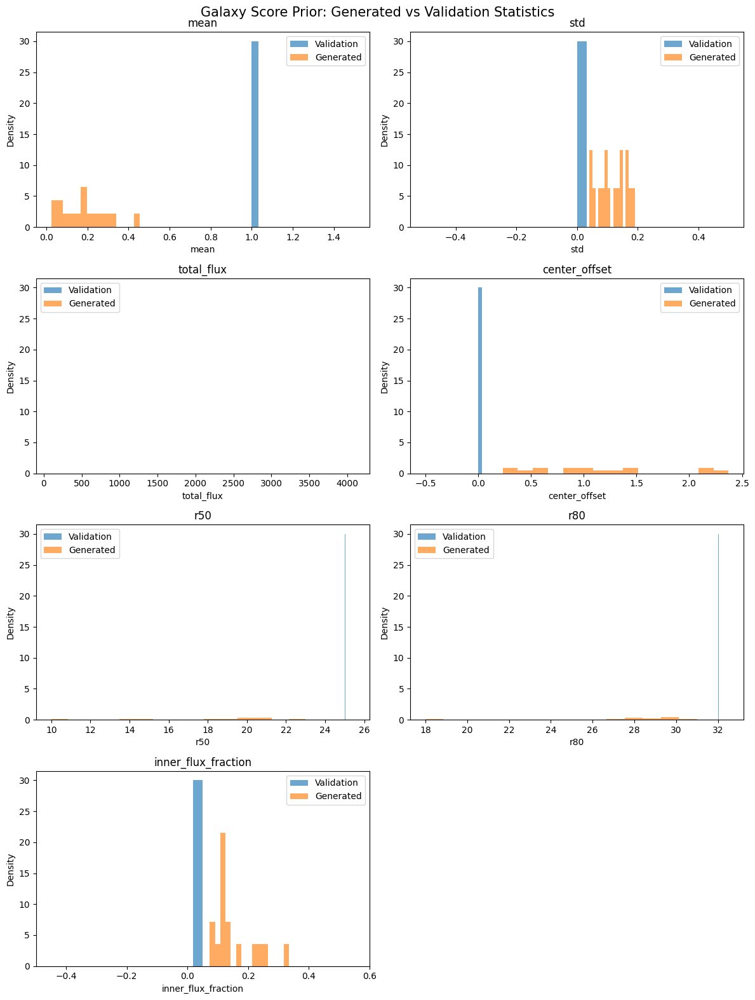


STEP 10F COMPLETE
Generated galaxies : 16
Validation galaxies: 420

Distribution plot:
/content/drive/MyDrive/Galaxy_Score_Prior/results/prior_validation_distributions_step_002000.png

Statistics:
/content/drive/MyDrive/Galaxy_Score_Prior/results/prior_validation_statistics_step_002000.csv

Channel statistics:
/content/drive/MyDrive/Galaxy_Score_Prior/results/prior_validation_channel_statistics_step_002000.csv

Summary:
/content/drive/MyDrive/Galaxy_Score_Prior/results/prior_validation_summary_step_002000.json


In [ ]:
# ======================================================================
# STEP 10F — QUANTITATIVE SCORE-PRIOR VALIDATION
# Compare generated galaxies against held-out validation galaxies
# ======================================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import ks_2samp

print("=" * 70)
print("STEP 10F — QUANTITATIVE SCORE-PRIOR VALIDATION")
print("=" * 70)

# ----------------------------------------------------------------------
# Paths
# ----------------------------------------------------------------------

DRIVE_ROOT = (
    "/content/drive/MyDrive/Galaxy_Score_Prior"
)

RESULTS_DIR = os.path.join(
    DRIVE_ROOT,
    "results"
)

DATASET_DIR = (
    "/content/galaxy_score_dataset"
)

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)

# ----------------------------------------------------------------------
# Load generated samples
# ----------------------------------------------------------------------

generated_path = os.path.join(
    RESULTS_DIR,
    "galaxy_prior_samples_step_002000.npy"
)

generated = np.load(
    generated_path
).astype(
    np.float32
)

# ----------------------------------------------------------------------
# Load held-out validation set
# ----------------------------------------------------------------------

val_path = os.path.join(
    DATASET_DIR,
    "val_rgb64.npy"
)

validation = np.load(
    val_path
).astype(
    np.float32
)

# ----------------------------------------------------------------------
# Basic verification
# ----------------------------------------------------------------------

print("\nGenerated:")
print(
    "  shape:",
    generated.shape
)

print(
    "  range:",
    float(generated.min()),
    "to",
    float(generated.max())
)

print("\nValidation:")
print(
    "  shape:",
    validation.shape
)

print(
    "  range:",
    float(validation.min()),
    "to",
    float(validation.max())
)

assert generated.ndim == 4
assert validation.ndim == 4

assert generated.shape[1:] == (
    64,
    64,
    3
)

assert validation.shape[1:] == (
    64,
    64,
    3
)

# Both are already in approximately [0,1].
generated = np.clip(
    generated,
    0.0,
    1.0
)

validation = np.clip(
    validation,
    0.0,
    1.0
)

# ----------------------------------------------------------------------
# Image statistics
# ----------------------------------------------------------------------

def compute_image_statistics(images):

    # --------------------------------------------------------------
    # Luminance
    # --------------------------------------------------------------
    #
    # This is used only as a generic RGB morphology diagnostic.
    # It should NOT be interpreted as a physical astronomical band.
    #

    lum = (
        0.299 * images[..., 0]
        + 0.587 * images[..., 1]
        + 0.114 * images[..., 2]
    )

    H, W = lum.shape[1:]

    yy, xx = np.mgrid[
        0:H,
        0:W
    ]

    cx0 = (
        (W - 1)
        / 2.0
    )

    cy0 = (
        (H - 1)
        / 2.0
    )

    radius = np.sqrt(
        (xx - cx0) ** 2
        + (yy - cy0) ** 2
    )

    flat_radius = radius.ravel()

    results = {
        "mean": [],
        "std": [],
        "total_flux": [],
        "bright_fraction": [],
        "center_offset": [],
        "r50": [],
        "r80": [],
        "inner_flux_fraction": []
    }

    for i in range(
        len(images)
    ):

        img = lum[i]

        total_flux = float(
            img.sum()
        )

        mean_val = float(
            img.mean()
        )

        std_val = float(
            img.std()
        )

        bright_fraction = float(
            np.mean(
                img > 0.5
            )
        )

        # ----------------------------------------------------------
        # Flux-weighted center
        # ----------------------------------------------------------

        weights = np.maximum(
            img,
            0.0
        )

        weight_sum = (
            weights.sum()
            + 1e-12
        )

        cx = float(
            (weights * xx).sum()
            / weight_sum
        )

        cy = float(
            (weights * yy).sum()
            / weight_sum
        )

        center_offset = float(
            np.sqrt(
                (cx - cx0) ** 2
                + (cy - cy0) ** 2
            )
        )

        # ----------------------------------------------------------
        # Cumulative radial flux
        # ----------------------------------------------------------

        flux_by_radius = np.bincount(
            flat_radius.astype(np.int32),
            weights=img.ravel()
        )

        cumulative = np.cumsum(
            flux_by_radius
        )

        target50 = (
            0.50 * total_flux
        )

        target80 = (
            0.80 * total_flux
        )

        idx50 = np.searchsorted(
            cumulative,
            target50
        )

        idx80 = np.searchsorted(
            cumulative,
            target80
        )

        r50 = float(
            min(
                idx50,
                int(radius.max())
            )
        )

        r80 = float(
            min(
                idx80,
                int(radius.max())
            )
        )

        # ----------------------------------------------------------
        # Central 8-pixel radius flux fraction
        # ----------------------------------------------------------

        inner_mask = (
            radius <= 8.0
        )

        inner_flux = float(
            img[inner_mask].sum()
        )

        inner_fraction = (
            inner_flux
            / (total_flux + 1e-12)
        )

        # ----------------------------------------------------------
        # Store
        # ----------------------------------------------------------

        results["mean"].append(
            mean_val
        )

        results["std"].append(
            std_val
        )

        results["total_flux"].append(
            total_flux
        )

        results["bright_fraction"].append(
            bright_fraction
        )

        results["center_offset"].append(
            center_offset
        )

        results["r50"].append(
            r50
        )

        results["r80"].append(
            r80
        )

        results["inner_flux_fraction"].append(
            inner_fraction
        )

    # Convert lists -> numpy arrays
    for key in results:
        results[key] = np.asarray(
            results[key],
            dtype=np.float64
        )

    return results


# ----------------------------------------------------------------------
# Compute statistics
# ----------------------------------------------------------------------

generated_stats = compute_image_statistics(
    generated
)

validation_stats = compute_image_statistics(
    validation
)

# ----------------------------------------------------------------------
# RGB channel statistics
# ----------------------------------------------------------------------

channel_names = [
    "R",
    "G",
    "B"
]

channel_rows = []

for c, name in enumerate(
    channel_names
):

    channel_rows.append({

        "channel": name,

        "generated_mean":
            float(
                generated[..., c].mean()
            ),

        "validation_mean":
            float(
                validation[..., c].mean()
            ),

        "generated_std":
            float(
                generated[..., c].std()
            ),

        "validation_std":
            float(
                validation[..., c].std()
            )
    })

channel_df = pd.DataFrame(
    channel_rows
)

# ----------------------------------------------------------------------
# Distribution statistics + KS tests
# ----------------------------------------------------------------------

stat_rows = []

for metric in generated_stats:

    g = generated_stats[metric]
    v = validation_stats[metric]

    ks_stat, ks_p = ks_2samp(
        g,
        v
    )

    stat_rows.append({

        "metric":
            metric,

        "generated_mean":
            float(g.mean()),

        "generated_std":
            float(g.std()),

        "validation_mean":
            float(v.mean()),

        "validation_std":
            float(v.std()),

        "KS_statistic":
            float(ks_stat),

        "KS_pvalue":
            float(ks_p)
    })

stats_df = pd.DataFrame(
    stat_rows
)

# ----------------------------------------------------------------------
# Print channel statistics
# ----------------------------------------------------------------------

print(
    "\n" + "-" * 70
)

print(
    "CHANNEL STATISTICS"
)

print(
    "-" * 70
)

print(
    channel_df.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.5f}"
    )
)

# ----------------------------------------------------------------------
# Print morphology/intensity statistics
# ----------------------------------------------------------------------

print(
    "\n" + "-" * 70
)

print(
    "IMAGE-LEVEL DISTRIBUTION COMPARISON"
)

print(
    "-" * 70
)

print(
    stats_df.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.5f}"
    )
)

# ----------------------------------------------------------------------
# Plot generated vs validation distributions
# ----------------------------------------------------------------------

plot_metrics = [
    "mean",
    "std",
    "total_flux",
    "center_offset",
    "r50",
    "r80",
    "inner_flux_fraction"
]

fig, axes = plt.subplots(
    4,
    2,
    figsize=(12, 16)
)

axes = axes.ravel()

for ax, metric in zip(
    axes,
    plot_metrics
):

    ax.hist(
        validation_stats[metric],
        bins=30,
        alpha=0.65,
        density=True,
        label="Validation"
    )

    ax.hist(
        generated_stats[metric],
        bins=15,
        alpha=0.65,
        density=True,
        label="Generated"
    )

    ax.set_title(
        metric
    )

    ax.set_xlabel(
        metric
    )

    ax.set_ylabel(
        "Density"
    )

    ax.legend()

# Hide unused axis
if len(
    axes
) > len(plot_metrics):

    for ax in axes[
        len(plot_metrics):
    ]:
        ax.axis(
            "off"
        )

plt.suptitle(
    "Galaxy Score Prior: Generated vs Validation Statistics",
    fontsize=15
)

plt.tight_layout()

figure_path = os.path.join(
    RESULTS_DIR,
    "prior_validation_distributions_step_002000.png"
)

plt.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ----------------------------------------------------------------------
# Save CSV tables
# ----------------------------------------------------------------------

stats_path = os.path.join(
    RESULTS_DIR,
    "prior_validation_statistics_step_002000.csv"
)

channel_path = os.path.join(
    RESULTS_DIR,
    "prior_validation_channel_statistics_step_002000.csv"
)

stats_df.to_csv(
    stats_path,
    index=False
)

channel_df.to_csv(
    channel_path,
    index=False
)

# ----------------------------------------------------------------------
# Summary JSON
# ----------------------------------------------------------------------

summary = {

    "training_step":
        2000,

    "num_generated":
        int(len(generated)),

    "num_validation":
        int(len(validation)),

    "generated_shape":
        list(generated.shape),

    "validation_shape":
        list(validation.shape),

    "statistics":
        stats_df.to_dict(
            orient="records"
        ),

    "channels":
        channel_df.to_dict(
            orient="records"
        ),

    "distribution_plot":
        figure_path,

    "statistics_csv":
        stats_path,

    "channel_statistics_csv":
        channel_path
}

summary_path = os.path.join(
    RESULTS_DIR,
    "prior_validation_summary_step_002000.json"
)

with open(
    summary_path,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )

# ----------------------------------------------------------------------
# Final report
# ----------------------------------------------------------------------

print(
    "\n" + "=" * 70
)

print(
    "STEP 10F COMPLETE"
)

print(
    "=" * 70
)

print(
    f"Generated galaxies : {len(generated)}"
)

print(
    f"Validation galaxies: {len(validation)}"
)

print(
    "\nDistribution plot:"
)

print(
    figure_path
)

print(
    "\nStatistics:"
)

print(
    stats_path
)

print(
    "\nChannel statistics:"
)

print(
    channel_path
)

print(
    "\nSummary:"
)

print(
    summary_path
)

print(
    "=" * 70
)

STEP 10F — QUANTITATIVE SCORE-PRIOR VALIDATION

Generated:
  shape: (16, 64, 64, 3)
  range: 0.0 to 1.0

Validation:
  shape: (420, 64, 64, 3)
  range: 3.0 to 255.0

----------------------------------------------------------------------
CHANNEL STATISTICS
----------------------------------------------------------------------
channel  generated_mean  validation_mean  generated_std  validation_std
      R         0.20429          1.00000        0.17802         0.00000
      G         0.18773          1.00000        0.17257         0.00000
      B         0.14065          1.00000        0.13998         0.00000

----------------------------------------------------------------------
IMAGE-LEVEL DISTRIBUTION COMPARISON
----------------------------------------------------------------------
             metric  generated_mean  generated_std  validation_mean  validation_std  KS_statistic  KS_pvalue
               mean         0.18731        0.11418          1.00000         0.00000       1.00000

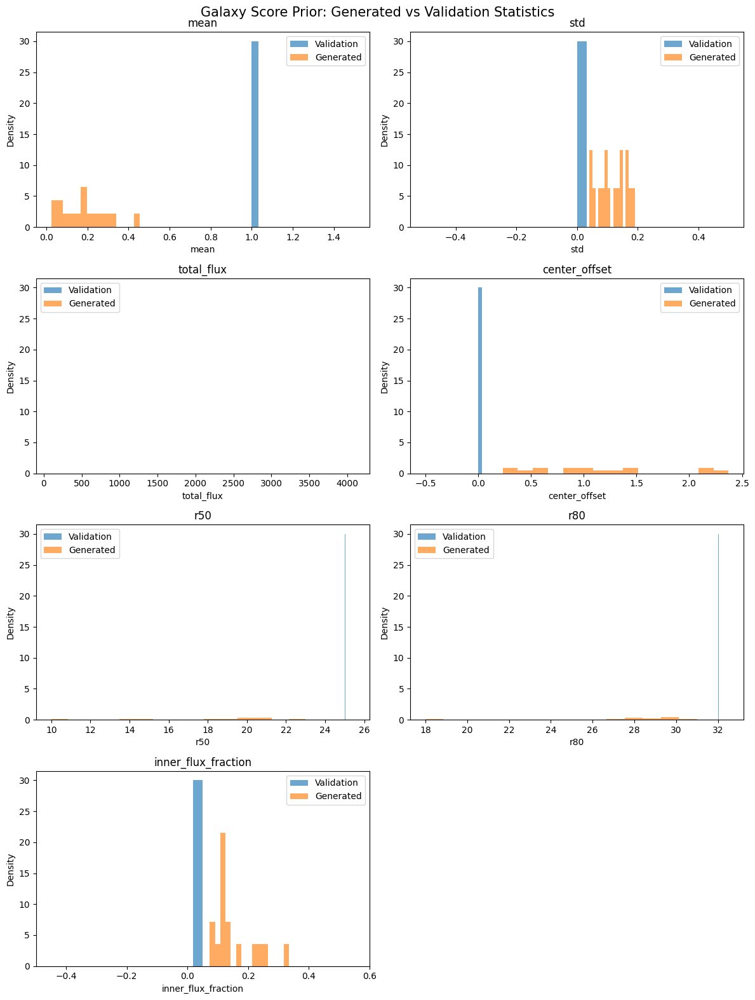


STEP 10F COMPLETE
Generated galaxies : 16
Validation galaxies: 420

Distribution plot:
/content/drive/MyDrive/Galaxy_Score_Prior/results/prior_validation_distributions_step_002000.png

Statistics:
/content/drive/MyDrive/Galaxy_Score_Prior/results/prior_validation_statistics_step_002000.csv

Channel statistics:
/content/drive/MyDrive/Galaxy_Score_Prior/results/prior_validation_channel_statistics_step_002000.csv

Summary:
/content/drive/MyDrive/Galaxy_Score_Prior/results/prior_validation_summary_step_002000.json


In [ ]:
# ======================================================================
# STEP 10F — QUANTITATIVE SCORE-PRIOR VALIDATION
# Compare generated galaxies against held-out validation galaxies
# ======================================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import ks_2samp

print("=" * 70)
print("STEP 10F — QUANTITATIVE SCORE-PRIOR VALIDATION")
print("=" * 70)

# ----------------------------------------------------------------------
# Paths
# ----------------------------------------------------------------------

DRIVE_ROOT = (
    "/content/drive/MyDrive/Galaxy_Score_Prior"
)

RESULTS_DIR = os.path.join(
    DRIVE_ROOT,
    "results"
)

DATASET_DIR = (
    "/content/galaxy_score_dataset"
)

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)

# ----------------------------------------------------------------------
# Load generated samples
# ----------------------------------------------------------------------

generated_path = os.path.join(
    RESULTS_DIR,
    "galaxy_prior_samples_step_002000.npy"
)

generated = np.load(
    generated_path
).astype(
    np.float32
)

# ----------------------------------------------------------------------
# Load held-out validation set
# ----------------------------------------------------------------------

val_path = os.path.join(
    DATASET_DIR,
    "val_rgb64.npy"
)

validation = np.load(
    val_path
).astype(
    np.float32
)

# ----------------------------------------------------------------------
# Basic verification
# ----------------------------------------------------------------------

print("\nGenerated:")
print(
    "  shape:",
    generated.shape
)

print(
    "  range:",
    float(generated.min()),
    "to",
    float(generated.max())
)

print("\nValidation:")
print(
    "  shape:",
    validation.shape
)

print(
    "  range:",
    float(validation.min()),
    "to",
    float(validation.max())
)

assert generated.ndim == 4
assert validation.ndim == 4

assert generated.shape[1:] == (
    64,
    64,
    3
)

assert validation.shape[1:] == (
    64,
    64,
    3
)

# Both are already in approximately [0,1].
generated = np.clip(
    generated,
    0.0,
    1.0
)

validation = np.clip(
    validation,
    0.0,
    1.0
)

# ----------------------------------------------------------------------
# Image statistics
# ----------------------------------------------------------------------

def compute_image_statistics(images):

    # --------------------------------------------------------------
    # Luminance
    # --------------------------------------------------------------
    #
    # This is used only as a generic RGB morphology diagnostic.
    # It should NOT be interpreted as a physical astronomical band.
    #

    lum = (
        0.299 * images[..., 0]
        + 0.587 * images[..., 1]
        + 0.114 * images[..., 2]
    )

    H, W = lum.shape[1:]

    yy, xx = np.mgrid[
        0:H,
        0:W
    ]

    cx0 = (
        (W - 1)
        / 2.0
    )

    cy0 = (
        (H - 1)
        / 2.0
    )

    radius = np.sqrt(
        (xx - cx0) ** 2
        + (yy - cy0) ** 2
    )

    flat_radius = radius.ravel()

    results = {
        "mean": [],
        "std": [],
        "total_flux": [],
        "bright_fraction": [],
        "center_offset": [],
        "r50": [],
        "r80": [],
        "inner_flux_fraction": []
    }

    for i in range(
        len(images)
    ):

        img = lum[i]

        total_flux = float(
            img.sum()
        )

        mean_val = float(
            img.mean()
        )

        std_val = float(
            img.std()
        )

        bright_fraction = float(
            np.mean(
                img > 0.5
            )
        )

        # ----------------------------------------------------------
        # Flux-weighted center
        # ----------------------------------------------------------

        weights = np.maximum(
            img,
            0.0
        )

        weight_sum = (
            weights.sum()
            + 1e-12
        )

        cx = float(
            (weights * xx).sum()
            / weight_sum
        )

        cy = float(
            (weights * yy).sum()
            / weight_sum
        )

        center_offset = float(
            np.sqrt(
                (cx - cx0) ** 2
                + (cy - cy0) ** 2
            )
        )

        # ----------------------------------------------------------
        # Cumulative radial flux
        # ----------------------------------------------------------

        flux_by_radius = np.bincount(
            flat_radius.astype(np.int32),
            weights=img.ravel()
        )

        cumulative = np.cumsum(
            flux_by_radius
        )

        target50 = (
            0.50 * total_flux
        )

        target80 = (
            0.80 * total_flux
        )

        idx50 = np.searchsorted(
            cumulative,
            target50
        )

        idx80 = np.searchsorted(
            cumulative,
            target80
        )

        r50 = float(
            min(
                idx50,
                int(radius.max())
            )
        )

        r80 = float(
            min(
                idx80,
                int(radius.max())
            )
        )

        # ----------------------------------------------------------
        # Central 8-pixel radius flux fraction
        # ----------------------------------------------------------

        inner_mask = (
            radius <= 8.0
        )

        inner_flux = float(
            img[inner_mask].sum()
        )

        inner_fraction = (
            inner_flux
            / (total_flux + 1e-12)
        )

        # ----------------------------------------------------------
        # Store
        # ----------------------------------------------------------

        results["mean"].append(
            mean_val
        )

        results["std"].append(
            std_val
        )

        results["total_flux"].append(
            total_flux
        )

        results["bright_fraction"].append(
            bright_fraction
        )

        results["center_offset"].append(
            center_offset
        )

        results["r50"].append(
            r50
        )

        results["r80"].append(
            r80
        )

        results["inner_flux_fraction"].append(
            inner_fraction
        )

    # Convert lists -> numpy arrays
    for key in results:
        results[key] = np.asarray(
            results[key],
            dtype=np.float64
        )

    return results


# ----------------------------------------------------------------------
# Compute statistics
# ----------------------------------------------------------------------

generated_stats = compute_image_statistics(
    generated
)

validation_stats = compute_image_statistics(
    validation
)

# ----------------------------------------------------------------------
# RGB channel statistics
# ----------------------------------------------------------------------

channel_names = [
    "R",
    "G",
    "B"
]

channel_rows = []

for c, name in enumerate(
    channel_names
):

    channel_rows.append({

        "channel": name,

        "generated_mean":
            float(
                generated[..., c].mean()
            ),

        "validation_mean":
            float(
                validation[..., c].mean()
            ),

        "generated_std":
            float(
                generated[..., c].std()
            ),

        "validation_std":
            float(
                validation[..., c].std()
            )
    })

channel_df = pd.DataFrame(
    channel_rows
)

# ----------------------------------------------------------------------
# Distribution statistics + KS tests
# ----------------------------------------------------------------------

stat_rows = []

for metric in generated_stats:

    g = generated_stats[metric]
    v = validation_stats[metric]

    ks_stat, ks_p = ks_2samp(
        g,
        v
    )

    stat_rows.append({

        "metric":
            metric,

        "generated_mean":
            float(g.mean()),

        "generated_std":
            float(g.std()),

        "validation_mean":
            float(v.mean()),

        "validation_std":
            float(v.std()),

        "KS_statistic":
            float(ks_stat),

        "KS_pvalue":
            float(ks_p)
    })

stats_df = pd.DataFrame(
    stat_rows
)

# ----------------------------------------------------------------------
# Print channel statistics
# ----------------------------------------------------------------------

print(
    "\n" + "-" * 70
)

print(
    "CHANNEL STATISTICS"
)

print(
    "-" * 70
)

print(
    channel_df.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.5f}"
    )
)

# ----------------------------------------------------------------------
# Print morphology/intensity statistics
# ----------------------------------------------------------------------

print(
    "\n" + "-" * 70
)

print(
    "IMAGE-LEVEL DISTRIBUTION COMPARISON"
)

print(
    "-" * 70
)

print(
    stats_df.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.5f}"
    )
)

# ----------------------------------------------------------------------
# Plot generated vs validation distributions
# ----------------------------------------------------------------------

plot_metrics = [
    "mean",
    "std",
    "total_flux",
    "center_offset",
    "r50",
    "r80",
    "inner_flux_fraction"
]

fig, axes = plt.subplots(
    4,
    2,
    figsize=(12, 16)
)

axes = axes.ravel()

for ax, metric in zip(
    axes,
    plot_metrics
):

    ax.hist(
        validation_stats[metric],
        bins=30,
        alpha=0.65,
        density=True,
        label="Validation"
    )

    ax.hist(
        generated_stats[metric],
        bins=15,
        alpha=0.65,
        density=True,
        label="Generated"
    )

    ax.set_title(
        metric
    )

    ax.set_xlabel(
        metric
    )

    ax.set_ylabel(
        "Density"
    )

    ax.legend()

# Hide unused axis
if len(
    axes
) > len(plot_metrics):

    for ax in axes[
        len(plot_metrics):
    ]:
        ax.axis(
            "off"
        )

plt.suptitle(
    "Galaxy Score Prior: Generated vs Validation Statistics",
    fontsize=15
)

plt.tight_layout()

figure_path = os.path.join(
    RESULTS_DIR,
    "prior_validation_distributions_step_002000.png"
)

plt.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ----------------------------------------------------------------------
# Save CSV tables
# ----------------------------------------------------------------------

stats_path = os.path.join(
    RESULTS_DIR,
    "prior_validation_statistics_step_002000.csv"
)

channel_path = os.path.join(
    RESULTS_DIR,
    "prior_validation_channel_statistics_step_002000.csv"
)

stats_df.to_csv(
    stats_path,
    index=False
)

channel_df.to_csv(
    channel_path,
    index=False
)

# ----------------------------------------------------------------------
# Summary JSON
# ----------------------------------------------------------------------

summary = {

    "training_step":
        2000,

    "num_generated":
        int(len(generated)),

    "num_validation":
        int(len(validation)),

    "generated_shape":
        list(generated.shape),

    "validation_shape":
        list(validation.shape),

    "statistics":
        stats_df.to_dict(
            orient="records"
        ),

    "channels":
        channel_df.to_dict(
            orient="records"
        ),

    "distribution_plot":
        figure_path,

    "statistics_csv":
        stats_path,

    "channel_statistics_csv":
        channel_path
}

summary_path = os.path.join(
    RESULTS_DIR,
    "prior_validation_summary_step_002000.json"
)

with open(
    summary_path,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )

# ----------------------------------------------------------------------
# Final report
# ----------------------------------------------------------------------

print(
    "\n" + "=" * 70
)

print(
    "STEP 10F COMPLETE"
)

print(
    "=" * 70
)

print(
    f"Generated galaxies : {len(generated)}"
)

print(
    f"Validation galaxies: {len(validation)}"
)

print(
    "\nDistribution plot:"
)

print(
    figure_path
)

print(
    "\nStatistics:"
)

print(
    stats_path
)

print(
    "\nChannel statistics:"
)

print(
    channel_path
)

print(
    "\nSummary:"
)

print(
    summary_path
)

print(
    "=" * 70
)

STEP 10F-CORRECTED — SCORE PRIOR VALIDATION

Raw validation:
  shape: (420, 64, 64, 3)
  dtype: uint8
  range: 3.0 to 255.0

Normalized validation:
  shape: (420, 64, 64, 3)
  dtype: float32
  range: 0.0117647061124444 to 1.0

----------------------------------------------------------------------
CHANNEL STATISTICS
----------------------------------------------------------------------
channel  generated_mean  validation_mean  generated_std  validation_std
      R         0.20429          0.54099        0.17802         0.24743
      G         0.18773          0.55746        0.17257         0.24745
      B         0.14065          0.53241        0.13998         0.23016

----------------------------------------------------------------------
IMAGE-LEVEL DISTRIBUTION COMPARISON
----------------------------------------------------------------------
             metric  generated_mean  generated_std  generated_median  validation_mean  validation_std  validation_median  KS_statistic  KS_pvalue

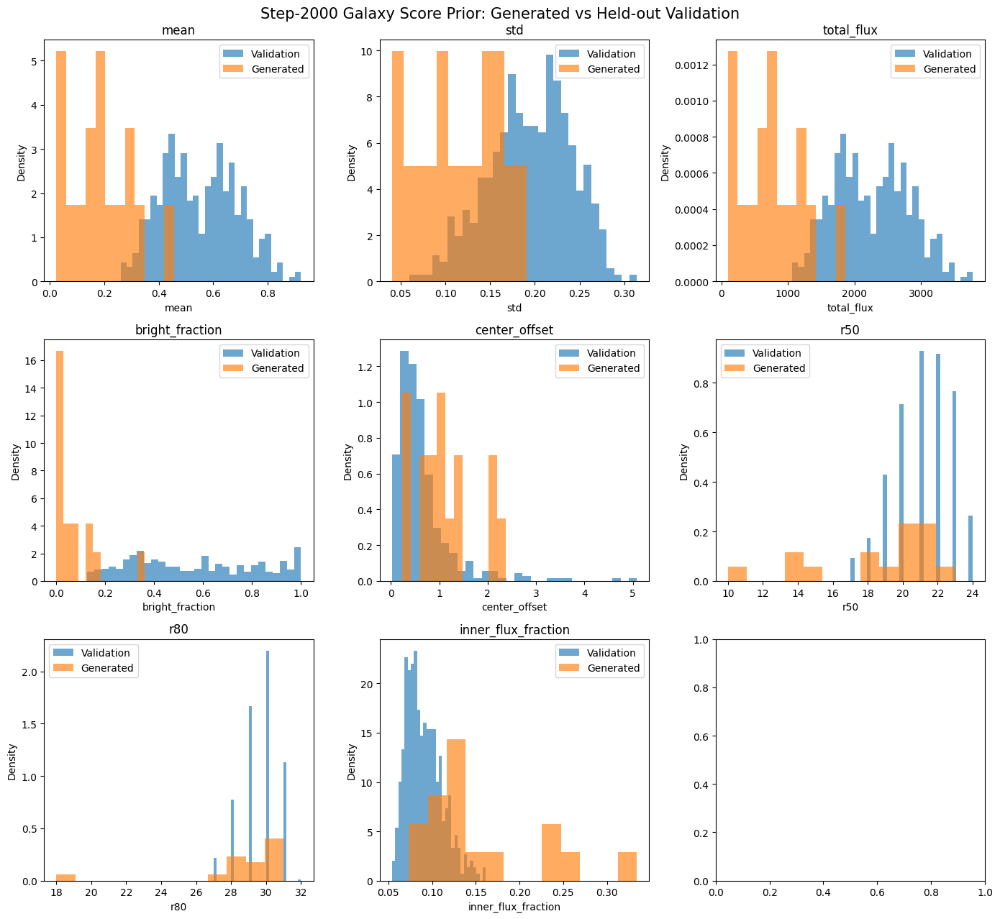


STEP 10F-CORRECTED COMPLETE
Generated galaxies : 16
Validation galaxies: 420
Validation scaling : uint8 / 255.0

Distribution plot:
/content/drive/MyDrive/Galaxy_Score_Prior/results/prior_validation_distributions_step_002000_corrected.png

Statistics:
/content/drive/MyDrive/Galaxy_Score_Prior/results/prior_validation_statistics_step_002000_corrected.csv

Summary:
/content/drive/MyDrive/Galaxy_Score_Prior/results/prior_validation_summary_step_002000_corrected.json


In [ ]:
# ======================================================================
# STEP 10F-CORRECTED — SCORE PRIOR VALIDATION
# Correct uint8 -> [0,1] normalization for validation galaxies
# ======================================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp

print("=" * 70)
print("STEP 10F-CORRECTED — SCORE PRIOR VALIDATION")
print("=" * 70)

# ----------------------------------------------------------------------
# Paths
# ----------------------------------------------------------------------

DRIVE_ROOT = (
    "/content/drive/MyDrive/Galaxy_Score_Prior"
)

RESULTS_DIR = os.path.join(
    DRIVE_ROOT,
    "results"
)

DATASET_DIR = (
    "/content/galaxy_score_dataset"
)

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)

# ----------------------------------------------------------------------
# Load generated samples
# ----------------------------------------------------------------------

generated_path = os.path.join(
    RESULTS_DIR,
    "galaxy_prior_samples_step_002000.npy"
)

generated = np.load(
    generated_path
).astype(
    np.float32
)

generated = np.clip(
    generated,
    0.0,
    1.0
)

# ----------------------------------------------------------------------
# Load validation set
# ----------------------------------------------------------------------

val_path = os.path.join(
    DATASET_DIR,
    "val_rgb64.npy"
)

validation_raw = np.load(
    val_path
)

print(
    "\nRaw validation:"
)

print(
    "  shape:",
    validation_raw.shape
)

print(
    "  dtype:",
    validation_raw.dtype
)

print(
    "  range:",
    float(validation_raw.min()),
    "to",
    float(validation_raw.max())
)

# ----------------------------------------------------------------------
# IMPORTANT:
#
# Validation files were saved as uint8 [0,255].
# Training loader divides by 255.
#
# Convert validation to the same [0,1] scale as the generated samples.
# ----------------------------------------------------------------------

validation = (
    validation_raw.astype(
        np.float32
    ) / 255.0
)

validation = np.clip(
    validation,
    0.0,
    1.0
)

print(
    "\nNormalized validation:"
)

print(
    "  shape:",
    validation.shape
)

print(
    "  dtype:",
    validation.dtype
)

print(
    "  range:",
    float(validation.min()),
    "to",
    float(validation.max())
)

# ----------------------------------------------------------------------
# Shape checks
# ----------------------------------------------------------------------

assert generated.shape[1:] == (
    64,
    64,
    3
)

assert validation.shape[1:] == (
    64,
    64,
    3
)

# ----------------------------------------------------------------------
# Statistics function
# ----------------------------------------------------------------------

def compute_image_statistics(images):

    # Generic RGB luminance diagnostic
    lum = (
        0.299 * images[..., 0]
        + 0.587 * images[..., 1]
        + 0.114 * images[..., 2]
    )

    H, W = lum.shape[1:]

    yy, xx = np.mgrid[
        0:H,
        0:W
    ]

    cx0 = (
        W - 1
    ) / 2.0

    cy0 = (
        H - 1
    ) / 2.0

    radius = np.sqrt(
        (xx - cx0) ** 2
        + (yy - cy0) ** 2
    )

    flat_radius = radius.ravel()

    results = {
        "mean": [],
        "std": [],
        "total_flux": [],
        "bright_fraction": [],
        "center_offset": [],
        "r50": [],
        "r80": [],
        "inner_flux_fraction": []
    }

    for i in range(
        len(images)
    ):

        img = lum[i]

        total_flux = float(
            img.sum()
        )

        results["mean"].append(
            float(img.mean())
        )

        results["std"].append(
            float(img.std())
        )

        results["total_flux"].append(
            total_flux
        )

        results["bright_fraction"].append(
            float(
                np.mean(
                    img > 0.5
                )
            )
        )

        # --------------------------------------------------------------
        # Flux-weighted center
        # --------------------------------------------------------------

        weights = np.maximum(
            img,
            0.0
        )

        weight_sum = (
            weights.sum()
            + 1e-12
        )

        cx = float(
            (weights * xx).sum()
            / weight_sum
        )

        cy = float(
            (weights * yy).sum()
            / weight_sum
        )

        center_offset = float(
            np.sqrt(
                (cx - cx0) ** 2
                + (cy - cy0) ** 2
            )
        )

        results["center_offset"].append(
            center_offset
        )

        # --------------------------------------------------------------
        # Radial cumulative flux
        # --------------------------------------------------------------

        radial_bins = (
            np.floor(
                flat_radius
            ).astype(
                np.int32
            )
        )

        flux_by_radius = np.bincount(
            radial_bins,
            weights=img.ravel()
        )

        cumulative = np.cumsum(
            flux_by_radius
        )

        target50 = (
            0.50
            * total_flux
        )

        target80 = (
            0.80
            * total_flux
        )

        idx50 = int(
            np.searchsorted(
                cumulative,
                target50
            )
        )

        idx80 = int(
            np.searchsorted(
                cumulative,
                target80
            )
        )

        max_r = int(
            np.ceil(
                radius.max()
            )
        )

        results["r50"].append(
            float(
                min(
                    idx50,
                    max_r
                )
            )
        )

        results["r80"].append(
            float(
                min(
                    idx80,
                    max_r
                )
            )
        )

        # --------------------------------------------------------------
        # Central flux
        # --------------------------------------------------------------

        inner_mask = (
            radius <= 8.0
        )

        inner_flux = float(
            img[inner_mask].sum()
        )

        results["inner_flux_fraction"].append(
            inner_flux
            / (
                total_flux
                + 1e-12
            )
        )

    for key in results:

        results[key] = np.asarray(
            results[key],
            dtype=np.float64
        )

    return results


# ----------------------------------------------------------------------
# Compute image statistics
# ----------------------------------------------------------------------

generated_stats = compute_image_statistics(
    generated
)

validation_stats = compute_image_statistics(
    validation
)

# ----------------------------------------------------------------------
# Channel statistics
# ----------------------------------------------------------------------

channel_rows = []

for c, name in enumerate(
    ["R", "G", "B"]
):

    channel_rows.append({

        "channel":
            name,

        "generated_mean":
            float(
                generated[..., c].mean()
            ),

        "validation_mean":
            float(
                validation[..., c].mean()
            ),

        "generated_std":
            float(
                generated[..., c].std()
            ),

        "validation_std":
            float(
                validation[..., c].std()
            )
    })

channel_df = pd.DataFrame(
    channel_rows
)

# ----------------------------------------------------------------------
# Distribution comparison
# ----------------------------------------------------------------------

stat_rows = []

for metric in generated_stats:

    g = generated_stats[metric]
    v = validation_stats[metric]

    ks_stat, ks_p = ks_2samp(
        g,
        v
    )

    stat_rows.append({

        "metric":
            metric,

        "generated_mean":
            float(g.mean()),

        "generated_std":
            float(g.std()),

        "generated_median":
            float(np.median(g)),

        "validation_mean":
            float(v.mean()),

        "validation_std":
            float(v.std()),

        "validation_median":
            float(np.median(v)),

        "KS_statistic":
            float(ks_stat),

        "KS_pvalue":
            float(ks_p)
    })

stats_df = pd.DataFrame(
    stat_rows
)

# ----------------------------------------------------------------------
# Display
# ----------------------------------------------------------------------

print(
    "\n" + "-" * 70
)

print(
    "CHANNEL STATISTICS"
)

print(
    "-" * 70
)

print(
    channel_df.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.5f}"
    )
)

print(
    "\n" + "-" * 70
)

print(
    "IMAGE-LEVEL DISTRIBUTION COMPARISON"
)

print(
    "-" * 70
)

print(
    stats_df.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.5f}"
    )
)

# ----------------------------------------------------------------------
# Distribution plots
# ----------------------------------------------------------------------

plot_metrics = [
    "mean",
    "std",
    "total_flux",
    "bright_fraction",
    "center_offset",
    "r50",
    "r80",
    "inner_flux_fraction"
]

fig, axes = plt.subplots(
    3,
    3,
    figsize=(14, 13)
)

axes = axes.ravel()

for ax, metric in zip(
    axes,
    plot_metrics
):

    ax.hist(
        validation_stats[metric],
        bins=30,
        density=True,
        alpha=0.65,
        label="Validation"
    )

    ax.hist(
        generated_stats[metric],
        bins=12,
        density=True,
        alpha=0.65,
        label="Generated"
    )

    ax.set_title(
        metric
    )

    ax.set_xlabel(
        metric
    )

    ax.set_ylabel(
        "Density"
    )

    ax.legend()

plt.suptitle(
    "Step-2000 Galaxy Score Prior: "
    "Generated vs Held-out Validation",
    fontsize=15
)

plt.tight_layout()

figure_path = os.path.join(
    RESULTS_DIR,
    "prior_validation_distributions_step_002000_corrected.png"
)

plt.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ----------------------------------------------------------------------
# Save tables
# ----------------------------------------------------------------------

stats_path = os.path.join(
    RESULTS_DIR,
    "prior_validation_statistics_step_002000_corrected.csv"
)

channel_path = os.path.join(
    RESULTS_DIR,
    "prior_validation_channel_statistics_step_002000_corrected.csv"
)

stats_df.to_csv(
    stats_path,
    index=False
)

channel_df.to_csv(
    channel_path,
    index=False
)

# ----------------------------------------------------------------------
# Summary
# ----------------------------------------------------------------------

summary = {

    "training_step":
        2000,

    "num_generated":
        int(len(generated)),

    "num_validation":
        int(len(validation)),

    "validation_normalization":
        "uint8 / 255.0",

    "generated_shape":
        list(generated.shape),

    "validation_shape":
        list(validation.shape),

    "statistics":
        stats_df.to_dict(
            orient="records"
        ),

    "channels":
        channel_df.to_dict(
            orient="records"
        ),

    "distribution_plot":
        figure_path,

    "statistics_csv":
        stats_path,

    "channel_statistics_csv":
        channel_path
}

summary_path = os.path.join(
    RESULTS_DIR,
    "prior_validation_summary_step_002000_corrected.json"
)

with open(
    summary_path,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )

# ----------------------------------------------------------------------
# Final
# ----------------------------------------------------------------------

print(
    "\n" + "=" * 70
)

print(
    "STEP 10F-CORRECTED COMPLETE"
)

print(
    "=" * 70
)

print(
    "Generated galaxies :",
    len(generated)
)

print(
    "Validation galaxies:",
    len(validation)
)

print(
    "Validation scaling : uint8 / 255.0"
)

print(
    "\nDistribution plot:"
)

print(
    figure_path
)

print(
    "\nStatistics:"
)

print(
    stats_path
)

print(
    "\nSummary:"
)

print(
    summary_path
)

print(
    "=" * 70
)

In [ ]:
# ======================================================================
# STEP 10G — SAMPLING CONFIGURATION TEST
# Compare PC-1, PC-5, and probability-flow ODE
# using the SAME step-2000 trained model
# ======================================================================

import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
import jax

from score_flow import sampling

print("=" * 70)
print("STEP 10G — SAMPLING CONFIGURATION TEST")
print("=" * 70)

# ----------------------------------------------------------------------
# Paths
# ----------------------------------------------------------------------

DRIVE_ROOT = (
    "/content/drive/MyDrive/Galaxy_Score_Prior"
)

RESULTS_DIR = os.path.join(
    DRIVE_ROOT,
    "results"
)

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)

# ----------------------------------------------------------------------
# Unreplicate trained state
# ----------------------------------------------------------------------

trained_state_2000 = jax.tree_util.tree_map(
    lambda x:
        x[0]
        if hasattr(x, "shape")
        and x.shape[0] == 1
        else x,
    final_state_repl
)

print(
    "Training step:",
    int(
        np.asarray(
            trained_state_2000.step
        )
    )
)

# ----------------------------------------------------------------------
# Identity inverse scaler
# ----------------------------------------------------------------------

def inverse_scaler(x):
    return x

# ----------------------------------------------------------------------
# Sampling parameters
# ----------------------------------------------------------------------

NUM_SAMPLES = 4

sample_shape = (
    NUM_SAMPLES,
    config.data.image_size,
    config.data.image_size,
    config.data.num_channels
)

# ----------------------------------------------------------------------
# Helper to run one sampler
# ----------------------------------------------------------------------

def run_sampler(
    sampler_name,
    cfg,
    seed
):

    print(
        f"\nRunning {sampler_name}..."
    )

    sampler = sampling.get_sampling_fn_without_pmap(
        config=cfg,
        sde=sde,
        model=score_model,
        shape=sample_shape,
        inverse_scaler=inverse_scaler,
        eps=1e-3
    )

    rng = jax.random.PRNGKey(
        seed
    )

    t0 = time.time()

    output = sampler(
        rng,
        trained_state_2000
    )

    elapsed = (
        time.time()
        - t0
    )

    if isinstance(
        output,
        tuple
    ):

        samples = np.asarray(
            output[0]
        )

    else:

        samples = np.asarray(
            output
        )

    samples = np.asarray(
        samples,
        dtype=np.float32
    )

    raw_min = float(
        samples.min()
    )

    raw_max = float(
        samples.max()
    )

    samples = np.clip(
        samples,
        0.0,
        1.0
    )

    print(
        f"  Time      : {elapsed:.2f} s"
    )

    print(
        f"  Raw range : {raw_min:.4f} to {raw_max:.4f}"
    )

    print(
        f"  Mean      : {samples.mean():.5f}"
    )

    print(
        f"  Std       : {samples.std():.5f}"
    )

    return (
        samples,
        elapsed
    )

# ----------------------------------------------------------------------
# 1. Current PC sampler
# ----------------------------------------------------------------------

cfg_pc1 = copy.deepcopy(
    config
)

cfg_pc1.sampling.method = "pc"
cfg_pc1.sampling.predictor = "euler_maruyama"
cfg_pc1.sampling.corrector = "none"
cfg_pc1.sampling.n_steps_each = 1
cfg_pc1.sampling.probability_flow = False
cfg_pc1.sampling.noise_removal = True

samples_pc1, time_pc1 = run_sampler(
    "PC-1",
    cfg_pc1,
    1001
)

# ----------------------------------------------------------------------
# 2. PC with 5 corrector/Langevin steps
# ----------------------------------------------------------------------

cfg_pc5 = copy.deepcopy(
    config
)

cfg_pc5.sampling.method = "pc"
cfg_pc5.sampling.predictor = "euler_maruyama"
cfg_pc5.sampling.corrector = "langevin"
cfg_pc5.sampling.n_steps_each = 5
cfg_pc5.sampling.probability_flow = False
cfg_pc5.sampling.noise_removal = True

samples_pc5, time_pc5 = run_sampler(
    "PC-5-Langevin",
    cfg_pc5,
    1002
)

# ----------------------------------------------------------------------
# 3. Probability-flow ODE
# ----------------------------------------------------------------------

cfg_ode = copy.deepcopy(
    config
)

cfg_ode.sampling.method = "ode"
cfg_ode.sampling.noise_removal = True

samples_ode, time_ode = run_sampler(
    "Probability-flow ODE",
    cfg_ode,
    1003
)

# ----------------------------------------------------------------------
# Basic comparison
# ----------------------------------------------------------------------

results = {

    "PC-1": samples_pc1,

    "PC-5-Langevin": samples_pc5,

    "ODE": samples_ode
}

print(
    "\n" + "-" * 70
)

print(
    "SAMPLER COMPARISON"
)

print(
    "-" * 70
)

for name, arr in results.items():

    print(
        f"{name:18s} | "
        f"mean={arr.mean():.5f} | "
        f"std={arr.std():.5f} | "
        f"min={arr.min():.5f} | "
        f"max={arr.max():.5f}"
    )

# ----------------------------------------------------------------------
# Contact sheet
# ----------------------------------------------------------------------

fig, axes = plt.subplots(
    3,
    4,
    figsize=(12, 9)
)

sampler_order = [
    ("PC-1", samples_pc1),
    ("PC-5-Langevin", samples_pc5),
    ("ODE", samples_ode)
]

for row, (
    name,
    arr
) in enumerate(
    sampler_order
):

    for col in range(
        NUM_SAMPLES
    ):

        ax = axes[
            row,
            col
        ]

        ax.imshow(
            arr[col]
        )

        ax.axis(
            "off"
        )

        if col == 0:

            ax.set_ylabel(
                name,
                fontsize=11
            )

plt.suptitle(
    "Step-2000 Score Prior: Sampling Configuration Test",
    fontsize=15
)

plt.tight_layout()

figure_path = os.path.join(
    RESULTS_DIR,
    "sampling_configuration_test_step_002000.png"
)

plt.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ----------------------------------------------------------------------
# Save numerical results
# ----------------------------------------------------------------------

np.save(
    os.path.join(
        RESULTS_DIR,
        "samples_pc1_step_002000.npy"
    ),
    samples_pc1
)

np.save(
    os.path.join(
        RESULTS_DIR,
        "samples_pc5_langevin_step_002000.npy"
    ),
    samples_pc5
)

np.save(
    os.path.join(
        RESULTS_DIR,
        "samples_ode_step_002000.npy"
    ),
    samples_ode
)

print(
    "\n" + "=" * 70
)

print(
    "STEP 10G COMPLETE"
)

print(
    "=" * 70
)

print(
    "Figure:"
)

print(
    figure_path
)

print(
    "\nSampling times:"
)

print(
    f"PC-1            : {time_pc1:.2f} s"
)

print(
    f"PC-5-Langevin   : {time_pc5:.2f} s"
)

print(
    f"ODE             : {time_ode:.2f} s"
)

print(
    "=" * 70
)

STEP 10G — SAMPLING CONFIGURATION TEST


NameError: name 'final_state_repl' is not defined

In [ ]:
# ======================================================================
# STEP 10G — SAMPLING CONFIGURATION TEST
# Compare PC-1, PC-5, and probability-flow ODE
# using the SAME step-2000 trained model
# ======================================================================

import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
import jax

from score_flow import sampling

print("=" * 70)
print("STEP 10G — SAMPLING CONFIGURATION TEST")
print("=" * 70)

# ----------------------------------------------------------------------
# Paths
# ----------------------------------------------------------------------

DRIVE_ROOT = (
    "/content/drive/MyDrive/Galaxy_Score_Prior"
)

RESULTS_DIR = os.path.join(
    DRIVE_ROOT,
    "results"
)

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)

# ----------------------------------------------------------------------
# Unreplicate trained state
# ----------------------------------------------------------------------

trained_state_2000 = jax.tree_util.tree_map(
    lambda x:
        x[0]
        if hasattr(x, "shape")
        and x.shape[0] == 1
        else x,
    final_state_repl
)

print(
    "Training step:",
    int(
        np.asarray(
            trained_state_2000.step
        )
    )
)

# ----------------------------------------------------------------------
# Identity inverse scaler
# ----------------------------------------------------------------------

def inverse_scaler(x):
    return x

# ----------------------------------------------------------------------
# Sampling parameters
# ----------------------------------------------------------------------

NUM_SAMPLES = 4

sample_shape = (
    NUM_SAMPLES,
    config.data.image_size,
    config.data.image_size,
    config.data.num_channels
)

# ----------------------------------------------------------------------
# Helper to run one sampler
# ----------------------------------------------------------------------

def run_sampler(
    sampler_name,
    cfg,
    seed
):

    print(
        f"\nRunning {sampler_name}..."
    )

    sampler = sampling.get_sampling_fn_without_pmap(
        config=cfg,
        sde=sde,
        model=score_model,
        shape=sample_shape,
        inverse_scaler=inverse_scaler,
        eps=1e-3
    )

    rng = jax.random.PRNGKey(
        seed
    )

    t0 = time.time()

    output = sampler(
        rng,
        trained_state_2000
    )

    elapsed = (
        time.time()
        - t0
    )

    if isinstance(
        output,
        tuple
    ):

        samples = np.asarray(
            output[0]
        )

    else:

        samples = np.asarray(
            output
        )

    samples = np.asarray(
        samples,
        dtype=np.float32
    )

    raw_min = float(
        samples.min()
    )

    raw_max = float(
        samples.max()
    )

    samples = np.clip(
        samples,
        0.0,
        1.0
    )

    print(
        f"  Time      : {elapsed:.2f} s"
    )

    print(
        f"  Raw range : {raw_min:.4f} to {raw_max:.4f}"
    )

    print(
        f"  Mean      : {samples.mean():.5f}"
    )

    print(
        f"  Std       : {samples.std():.5f}"
    )

    return (
        samples,
        elapsed
    )

# ----------------------------------------------------------------------
# 1. Current PC sampler
# ----------------------------------------------------------------------

cfg_pc1 = copy.deepcopy(
    config
)

cfg_pc1.sampling.method = "pc"
cfg_pc1.sampling.predictor = "euler_maruyama"
cfg_pc1.sampling.corrector = "none"
cfg_pc1.sampling.n_steps_each = 1
cfg_pc1.sampling.probability_flow = False
cfg_pc1.sampling.noise_removal = True

samples_pc1, time_pc1 = run_sampler(
    "PC-1",
    cfg_pc1,
    1001
)

# ----------------------------------------------------------------------
# 2. PC with 5 corrector/Langevin steps
# ----------------------------------------------------------------------

cfg_pc5 = copy.deepcopy(
    config
)

cfg_pc5.sampling.method = "pc"
cfg_pc5.sampling.predictor = "euler_maruyama"
cfg_pc5.sampling.corrector = "langevin"
cfg_pc5.sampling.n_steps_each = 5
cfg_pc5.sampling.probability_flow = False
cfg_pc5.sampling.noise_removal = True

samples_pc5, time_pc5 = run_sampler(
    "PC-5-Langevin",
    cfg_pc5,
    1002
)

# ----------------------------------------------------------------------
# 3. Probability-flow ODE
# ----------------------------------------------------------------------

cfg_ode = copy.deepcopy(
    config
)

cfg_ode.sampling.method = "ode"
cfg_ode.sampling.noise_removal = True

samples_ode, time_ode = run_sampler(
    "Probability-flow ODE",
    cfg_ode,
    1003
)

# ----------------------------------------------------------------------
# Basic comparison
# ----------------------------------------------------------------------

results = {

    "PC-1": samples_pc1,

    "PC-5-Langevin": samples_pc5,

    "ODE": samples_ode
}

print(
    "\n" + "-" * 70
)

print(
    "SAMPLER COMPARISON"
)

print(
    "-" * 70
)

for name, arr in results.items():

    print(
        f"{name:18s} | "
        f"mean={arr.mean():.5f} | "
        f"std={arr.std():.5f} | "
        f"min={arr.min():.5f} | "
        f"max={arr.max():.5f}"
    )

# ----------------------------------------------------------------------
# Contact sheet
# ----------------------------------------------------------------------

fig, axes = plt.subplots(
    3,
    4,
    figsize=(12, 9)
)

sampler_order = [
    ("PC-1", samples_pc1),
    ("PC-5-Langevin", samples_pc5),
    ("ODE", samples_ode)
]

for row, (
    name,
    arr
) in enumerate(
    sampler_order
):

    for col in range(
        NUM_SAMPLES
    ):

        ax = axes[
            row,
            col
        ]

        ax.imshow(
            arr[col]
        )

        ax.axis(
            "off"
        )

        if col == 0:

            ax.set_ylabel(
                name,
                fontsize=11
            )

plt.suptitle(
    "Step-2000 Score Prior: Sampling Configuration Test",
    fontsize=15
)

plt.tight_layout()

figure_path = os.path.join(
    RESULTS_DIR,
    "sampling_configuration_test_step_002000.png"
)

plt.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ----------------------------------------------------------------------
# Save numerical results
# ----------------------------------------------------------------------

np.save(
    os.path.join(
        RESULTS_DIR,
        "samples_pc1_step_002000.npy"
    ),
    samples_pc1
)

np.save(
    os.path.join(
        RESULTS_DIR,
        "samples_pc5_langevin_step_002000.npy"
    ),
    samples_pc5
)

np.save(
    os.path.join(
        RESULTS_DIR,
        "samples_ode_step_002000.npy"
    ),
    samples_ode
)

print(
    "\n" + "=" * 70
)

print(
    "STEP 10G COMPLETE"
)

print(
    "=" * 70
)

print(
    "Figure:"
)

print(
    figure_path
)

print(
    "\nSampling times:"
)

print(
    f"PC-1            : {time_pc1:.2f} s"
)

print(
    f"PC-5-Langevin   : {time_pc5:.2f} s"
)

print(
    f"ODE             : {time_ode:.2f} s"
)

print(
    "=" * 70
)

STEP 10G — SAMPLING CONFIGURATION TEST


NameError: name 'final_state_repl' is not defined

In [ ]:
# ======================================================================
# STEP 10G-FIX — PROBABILITY-FLOW ODE SAMPLING
# Skip LangevinCorrector because the repository's non-pmap
# implementation contains jax.lax.pmean(axis_name="batch").
# ======================================================================

import os
import time
import numpy as np
import matplotlib.pyplot as plt
import jax

from score_flow import sampling

print("=" * 70)
print("STEP 10G-FIX — ODE SAMPLING")
print("=" * 70)

# ----------------------------------------------------------------------
# Paths
# ----------------------------------------------------------------------

DRIVE_ROOT = (
    "/content/drive/MyDrive/Galaxy_Score_Prior"
)

RESULTS_DIR = os.path.join(
    DRIVE_ROOT,
    "results"
)

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)

# ----------------------------------------------------------------------
# Verify model
# ----------------------------------------------------------------------

trained_state_2000 = jax.tree_util.tree_map(
    lambda x:
        x[0]
        if hasattr(x, "shape")
        and x.shape[0] == 1
        else x,
    final_state_repl
)

current_step = int(
    np.asarray(
        trained_state_2000.step
    )
)

print(
    "Training step:",
    current_step
)

assert current_step == 2000

# ----------------------------------------------------------------------
# Identity inverse scaler
# ----------------------------------------------------------------------

def inverse_scaler(x):
    return x

# ----------------------------------------------------------------------
# ODE configuration
# ----------------------------------------------------------------------

import copy

cfg_ode = copy.deepcopy(
    config
)

cfg_ode.sampling.method = "ode"
cfg_ode.sampling.noise_removal = True

NUM_SAMPLES = 4

sample_shape = (
    NUM_SAMPLES,
    config.data.image_size,
    config.data.image_size,
    config.data.num_channels
)

print(
    "\nSample shape:",
    sample_shape
)

# ----------------------------------------------------------------------
# Build ODE sampler
# ----------------------------------------------------------------------

print(
    "\nBuilding probability-flow ODE sampler..."
)

ode_sampler = sampling.get_sampling_fn_without_pmap(
    config=cfg_ode,
    sde=sde,
    model=score_model,
    shape=sample_shape,
    inverse_scaler=inverse_scaler,
    eps=1e-3
)

print(
    "ODE sampler created."
)

# ----------------------------------------------------------------------
# Generate
# ----------------------------------------------------------------------

rng = jax.random.PRNGKey(
    1003
)

print(
    "\nGenerating ODE samples..."
)

t0 = time.time()

output = ode_sampler(
    rng,
    trained_state_2000
)

elapsed = (
    time.time()
    - t0
)

# ----------------------------------------------------------------------
# Handle return format
# ----------------------------------------------------------------------

if isinstance(
    output,
    tuple
):

    samples_ode = np.asarray(
        output[0]
    )

    print(
        "Sampler returned tuple."
    )

    print(
        "Tuple length:",
        len(output)
    )

else:

    samples_ode = np.asarray(
        output
    )

    print(
        "Sampler returned array."
    )

# ----------------------------------------------------------------------
# Statistics
# ----------------------------------------------------------------------

samples_ode = np.asarray(
    samples_ode,
    dtype=np.float32
)

raw_min = float(
    samples_ode.min()
)

raw_max = float(
    samples_ode.max()
)

samples_ode = np.clip(
    samples_ode,
    0.0,
    1.0
)

print(
    "\nODE samples:"
)

print(
    "  Shape:",
    samples_ode.shape
)

print(
    "  Raw min:",
    raw_min
)

print(
    "  Raw max:",
    raw_max
)

print(
    "  Clipped mean:",
    float(samples_ode.mean())
)

print(
    "  Clipped std:",
    float(samples_ode.std())
)

print(
    "  Time:",
    f"{elapsed:.2f} s"
)

# ----------------------------------------------------------------------
# Save
# ----------------------------------------------------------------------

samples_path = os.path.join(
    RESULTS_DIR,
    "samples_ode_step_002000.npy"
)

np.save(
    samples_path,
    samples_ode
)

# ----------------------------------------------------------------------
# Contact sheet
# ----------------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    NUM_SAMPLES,
    figsize=(12, 3)
)

for i in range(
    NUM_SAMPLES
):

    axes[i].imshow(
        samples_ode[i]
    )

    axes[i].set_title(
        f"ODE {i+1}"
    )

    axes[i].axis(
        "off"
    )

plt.suptitle(
    "Step-2000 Probability-Flow ODE Samples"
)

plt.tight_layout()

figure_path = os.path.join(
    RESULTS_DIR,
    "samples_ode_step_002000.png"
)

plt.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ----------------------------------------------------------------------
# Compare directly with successful PC-1 result
# ----------------------------------------------------------------------

pc1_path = os.path.join(
    RESULTS_DIR,
    "samples_pc1_step_002000.npy"
)

if os.path.exists(
    pc1_path
):

    samples_pc1 = np.load(
        pc1_path
    )

    print(
        "\n" + "-" * 70
    )

    print(
        "PC-1 vs ODE"
    )

    print(
        "-" * 70
    )

    print(
        f"PC-1 : "
        f"mean={samples_pc1.mean():.5f}, "
        f"std={samples_pc1.std():.5f}"
    )

    print(
        f"ODE  : "
        f"mean={samples_ode.mean():.5f}, "
        f"std={samples_ode.std():.5f}"
    )

# ----------------------------------------------------------------------
# Final
# ----------------------------------------------------------------------

print(
    "\n" + "=" * 70
)

print(
    "STEP 10G-FIX COMPLETE"
)

print(
    "=" * 70
)

print(
    "ODE samples:",
    samples_path
)

print(
    "Figure:",
    figure_path
)

print(
    "Sampling time:",
    f"{elapsed:.2f} s"
)

print(
    "=" * 70
)

STEP 10G-FIX — ODE SAMPLING


NameError: name 'final_state_repl' is not defined

In [ ]:
# ======================================================================
# STEP 10G-FIX-2 — ODE SAMPLING WITH CORRECT REPLICATED RNG
# ======================================================================

import os
import time
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from flax import jax_utils

print("=" * 70)
print("STEP 10G-FIX-2 — ODE SAMPLING WITH CORRECT RNG")
print("=" * 70)

# ----------------------------------------------------------------------
# Configuration
# ----------------------------------------------------------------------

STEP = 2000
NUM_SAMPLES = 4
IMAGE_SIZE = 64
NUM_CHANNELS = 3

RESULTS_DIR = "/content/drive/MyDrive/Galaxy_Score_Prior/results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# ----------------------------------------------------------------------
# Recover the trained state from the replicated training state
# ----------------------------------------------------------------------

try:
    trained_state_2000
    print("Using existing trained_state_2000.")
except NameError:
    try:
        trained_state_2000 = jax_utils.unreplicate(final_state_repl)
        print("Recovered trained_state_2000 from final_state_repl.")
    except NameError:
        raise RuntimeError(
            "Neither trained_state_2000 nor final_state_repl exists. "
            "Please restore the step-2000 checkpoint first."
        )

print(f"Training step: {trained_state_2000.step}")

# ----------------------------------------------------------------------
# Build sampling configuration
# ----------------------------------------------------------------------

config_sampling = config

config_sampling.sampling.method = "ode"
config_sampling.sampling.noise_removal = True
config_sampling.sampling.predictor = "euler_maruyama"
config_sampling.sampling.corrector = "none"
config_sampling.sampling.probability_flow = True

shape = (NUM_SAMPLES, IMAGE_SIZE, IMAGE_SIZE, NUM_CHANNELS)

print(f"Sample shape: {shape}")
print("Building probability-flow ODE sampler...")

# Identity inverse scaler because the model operates in [0, 1]
inverse_scaler = lambda x: x

sampler_fn = sampling.get_sampling_fn_without_pmap(
    config_sampling,
    sde,
    score_model,
    shape,
    inverse_scaler,
    eps=1e-3,
)

ode_sampler = sampler_fn

print("ODE sampler created.")

# ----------------------------------------------------------------------
# IMPORTANT:
# The repository's non-pmap ODE sampler internally calls:
#
#     flax.jax_utils.unreplicate(prng)
#
# Therefore the RNG must have shape (num_devices, 2).
# On the T4 Colab environment we have one device -> shape (1, 2).
# ----------------------------------------------------------------------

base_rng = jax.random.PRNGKey(42)
num_devices = jax.local_device_count()

rng = jax.random.split(base_rng, num_devices)

print(f"JAX devices: {jax.devices()}")
print(f"local_device_count: {num_devices}")
print(f"RNG shape passed to sampler: {rng.shape}")

assert rng.shape == (num_devices, 2), (
    f"Unexpected RNG shape: {rng.shape}. "
    f"Expected {(num_devices, 2)}."
)

# ----------------------------------------------------------------------
# Generate samples
# ----------------------------------------------------------------------

print()
print("Generating ODE samples...")

t0 = time.time()

output = ode_sampler(
    rng,
    trained_state_2000
)

elapsed = time.time() - t0

# ----------------------------------------------------------------------
# Handle sampler output
# ----------------------------------------------------------------------

if isinstance(output, tuple):
    samples = output[0]
    nfe = output[1] if len(output) > 1 else None
else:
    samples = output
    nfe = None

samples = np.asarray(samples)

print(f"Sampling completed in {elapsed:.2f} s")
print(f"Raw sample shape: {samples.shape}")
print(f"Raw sample range: [{samples.min():.6f}, {samples.max():.6f}]")

if nfe is not None:
    print(f"Additional sampler output: {nfe}")

# ----------------------------------------------------------------------
# Clip for image-domain inspection
# ----------------------------------------------------------------------

samples_clipped = np.clip(samples, 0.0, 1.0).astype(np.float32)

print(
    f"Clipped mean: {samples_clipped.mean():.6f}"
)
print(
    f"Clipped std:  {samples_clipped.std():.6f}"
)

# ----------------------------------------------------------------------
# Save samples
# ----------------------------------------------------------------------

sample_path = os.path.join(
    RESULTS_DIR,
    f"samples_ode_step_{STEP:06d}.npy"
)

np.save(sample_path, samples_clipped)

print(f"Saved samples: {sample_path}")

# ----------------------------------------------------------------------
# Create contact sheet
# ----------------------------------------------------------------------

fig, axes = plt.subplots(1, NUM_SAMPLES, figsize=(4 * NUM_SAMPLES, 4))

if NUM_SAMPLES == 1:
    axes = [axes]

for i, ax in enumerate(axes):
    ax.imshow(samples_clipped[i])
    ax.set_title(f"ODE sample {i+1}")
    ax.axis("off")

plt.tight_layout()

fig_path = os.path.join(
    RESULTS_DIR,
    f"samples_ode_step_{STEP:06d}.png"
)

plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()

print(f"Saved figure: {fig_path}")

print()
print("=" * 70)
print("ODE SAMPLING COMPLETE")
print("=" * 70)

STEP 10G-FIX-2 — ODE SAMPLING WITH CORRECT RNG


RuntimeError: Neither trained_state_2000 nor final_state_repl exists. Please restore the step-2000 checkpoint first.

In [ ]:
# ======================================================================
# STEP 10H — CHECKPOINT EVOLUTION WITH WORKING PC-1 SAMPLER
# ======================================================================

import os
import time
import pickle
import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
from flax import jax_utils

print("=" * 70)
print("STEP 10H — CHECKPOINT EVOLUTION")
print("=" * 70)

CHECKPOINT_DIR = "/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints"
RESULTS_DIR = "/content/drive/MyDrive/Galaxy_Score_Prior/results"

os.makedirs(RESULTS_DIR, exist_ok=True)

CHECKPOINT_STEPS = [500, 1000, 1500, 2000]
NUM_SAMPLES = 4
IMAGE_SIZE = 64
NUM_CHANNELS = 3

# ----------------------------------------------------------------------
# Validation reference
# ----------------------------------------------------------------------

val_path = "/content/galaxy_score_dataset/val_rgb64.npy"

val_uint8 = np.load(val_path)

if val_uint8.dtype != np.float32:
    val = val_uint8.astype(np.float32) / 255.0
else:
    val = val_uint8

if val.max() > 1.5:
    val = val / 255.0

print(f"Validation shape: {val.shape}")
print(f"Validation range: [{val.min():.4f}, {val.max():.4f}]")
print(f"Validation mean: {val.mean():.4f}")
print(f"Validation std:  {val.std():.4f}")

# ----------------------------------------------------------------------
# Simple distribution statistics
# ----------------------------------------------------------------------

def image_statistics(images):

    images = np.asarray(images)

    means = images.mean(axis=(1, 2, 3))
    stds = images.std(axis=(1, 2, 3))
    flux = images.sum(axis=(1, 2, 3))

    bright_fraction = (
        images.mean(axis=(1, 2, 3)) > 0.5
    )

    # Fraction of pixels above 0.5
    bright_fraction = (
        (images > 0.5).mean(axis=(1, 2, 3))
    )

    return {
        "mean": float(means.mean()),
        "std": float(means.std()),
        "pixel_std": float(stds.mean()),
        "flux": float(flux.mean()),
        "flux_std": float(flux.std()),
        "bright_fraction": float(bright_fraction.mean()),
    }

val_stats = image_statistics(val)

print()
print("Validation reference:")
for k, v in val_stats.items():
    print(f"  {k:20s}: {v:.6f}")

# ----------------------------------------------------------------------
# Build PC-1 sampler
# ----------------------------------------------------------------------

config_sampling = config

config_sampling.sampling.method = "pc"
config_sampling.sampling.predictor = "euler_maruyama"
config_sampling.sampling.corrector = "none"
config_sampling.sampling.n_steps_each = 1
config_sampling.sampling.noise_removal = True
config_sampling.sampling.probability_flow = False

shape = (
    NUM_SAMPLES,
    IMAGE_SIZE,
    IMAGE_SIZE,
    NUM_CHANNELS
)

inverse_scaler = lambda x: x

sampler_fn = sampling.get_sampling_fn_without_pmap(
    config_sampling,
    sde,
    score_model,
    shape,
    inverse_scaler,
    eps=1e-3,
)

pc_sampler = sampler_fn

print()
print("PC-1 sampler ready.")

# ----------------------------------------------------------------------
# Helper to load checkpoint
# ----------------------------------------------------------------------

def load_checkpoint_state(step):

    path = os.path.join(
        CHECKPOINT_DIR,
        f"checkpoint_clean_step_{step:06d}.pkl"
    )

    if not os.path.exists(path):
        raise FileNotFoundError(path)

    with open(path, "rb") as f:
        state = pickle.load(f)

    return state

# ----------------------------------------------------------------------
# Checkpoint sampling
# ----------------------------------------------------------------------

all_samples = {}
all_stats = {}

for step in CHECKPOINT_STEPS:

    print()
    print("-" * 70)
    print(f"CHECKPOINT STEP {step}")
    print("-" * 70)

    state = load_checkpoint_state(step)

    print(f"Loaded checkpoint: step {state.step}")

    rng = jax.random.PRNGKey(1000 + step)

    # The non-pmap sampler expects a replicated RNG.
    rng = jax.random.split(
        rng,
        jax.local_device_count()
    )

    t0 = time.time()

    output = pc_sampler(
        rng,
        state
    )

    elapsed = time.time() - t0

    if isinstance(output, tuple):
        samples = output[0]
    else:
        samples = output

    samples = np.asarray(samples)

    samples = np.clip(
        samples,
        0.0,
        1.0
    ).astype(np.float32)

    all_samples[step] = samples

    stats = image_statistics(samples)
    all_stats[step] = stats

    print(f"Sampling time: {elapsed:.2f} s")
    print(f"Mean intensity: {stats['mean']:.6f}")
    print(f"Intensity std:  {stats['pixel_std']:.6f}")
    print(f"Total flux:     {stats['flux']:.3f}")
    print(f"Bright fraction:{stats['bright_fraction']:.6f}")

# ----------------------------------------------------------------------
# Print evolution table
# ----------------------------------------------------------------------

print()
print("=" * 70)
print("CHECKPOINT EVOLUTION")
print("=" * 70)

print(
    f"{'Step':>8} "
    f"{'Mean':>12} "
    f"{'PixelStd':>12} "
    f"{'Flux':>14} "
    f"{'BrightFrac':>14}"
)

print("-" * 70)

for step in CHECKPOINT_STEPS:

    s = all_stats[step]

    print(
        f"{step:8d} "
        f"{s['mean']:12.6f} "
        f"{s['pixel_std']:12.6f} "
        f"{s['flux']:14.3f} "
        f"{s['bright_fraction']:14.6f}"
    )

print("-" * 70)

print(
    f"{'VAL':>8} "
    f"{val_stats['mean']:12.6f} "
    f"{val_stats['pixel_std']:12.6f} "
    f"{val_stats['flux']:14.3f} "
    f"{val_stats['bright_fraction']:14.6f}"
)

# ----------------------------------------------------------------------
# Save numerical results
# ----------------------------------------------------------------------

np.save(
    os.path.join(
        RESULTS_DIR,
        "checkpoint_evolution_samples.npy"
    ),
    np.array(
        [all_samples[s] for s in CHECKPOINT_STEPS]
    )
)

import json

with open(
    os.path.join(
        RESULTS_DIR,
        "checkpoint_evolution_stats.json"
    ),
    "w"
) as f:

    json.dump(
        {
            "validation": val_stats,
            "checkpoints": all_stats,
        },
        f,
        indent=2
    )

# ----------------------------------------------------------------------
# Contact sheet
# ----------------------------------------------------------------------

fig, axes = plt.subplots(
    len(CHECKPOINT_STEPS),
    NUM_SAMPLES,
    figsize=(12, 12)
)

for r, step in enumerate(CHECKPOINT_STEPS):

    samples = all_samples[step]

    for c in range(NUM_SAMPLES):

        axes[r, c].imshow(samples[c])
        axes[r, c].axis("off")

        if c == 0:
            axes[r, c].set_ylabel(
                f"Step {step}",
                fontsize=12
            )

plt.tight_layout()

fig_path = os.path.join(
    RESULTS_DIR,
    "checkpoint_evolution_contact_sheet.png"
)

plt.savefig(
    fig_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print()
print(f"Saved contact sheet: {fig_path}")

print()
print("=" * 70)
print("STEP 10H COMPLETE")
print("=" * 70)

STEP 10H — CHECKPOINT EVOLUTION
Validation shape: (420, 64, 64, 3)
Validation range: [0.0118, 1.0000]
Validation mean: 0.5436
Validation std:  0.2420

Validation reference:
  mean                : 0.543617
  std                 : 0.133334
  pixel_std           : 0.197408
  flux                : 6679.970215
  flux_std            : 1638.402588
  bright_fraction     : 0.554320


NameError: name 'config' is not defined

In [ ]:
# ======================================================================
# STEP 10H-FIX — CHECKPOINT EVOLUTION WITH CORRECT PC-1 RNG
# ======================================================================

import os
import json
import pickle
import time
import numpy as np
import matplotlib.pyplot as plt
import jax
from scipy.stats import ks_2samp

print("=" * 70)
print("STEP 10H-FIX — CHECKPOINT EVOLUTION")
print("=" * 70)

CHECKPOINT_DIR = "/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints"
RESULTS_DIR = "/content/drive/MyDrive/Galaxy_Score_Prior/results"

os.makedirs(RESULTS_DIR, exist_ok=True)

CHECKPOINT_STEPS = [500, 1000, 1500, 2000]

NUM_SAMPLES = 4
IMAGE_SIZE = 64
NUM_CHANNELS = 3

# ----------------------------------------------------------------------
# Load validation data
# ----------------------------------------------------------------------

val_path = "/content/galaxy_score_dataset/val_rgb64.npy"

val_uint8 = np.load(val_path)

val = val_uint8.astype(np.float32) / 255.0

if val.max() > 1.0:
    raise ValueError("Validation normalization failed.")

print(f"Validation shape: {val.shape}")
print(
    f"Validation range: "
    f"[{val.min():.4f}, {val.max():.4f}]"
)
print(
    f"Validation mean: {val.mean():.4f}"
)
print(
    f"Validation std:  {val.std():.4f}"
)

# ----------------------------------------------------------------------
# Statistics function
# ----------------------------------------------------------------------

def image_statistics(images):

    images = np.asarray(images)

    per_image_mean = images.mean(axis=(1, 2, 3))
    per_image_std = images.std(axis=(1, 2, 3))
    per_image_flux = images.sum(axis=(1, 2, 3))
    per_image_bright = (images > 0.5).mean(axis=(1, 2, 3))

    return {
        "mean": float(per_image_mean.mean()),
        "mean_std": float(per_image_mean.std()),
        "pixel_std": float(per_image_std.mean()),
        "flux": float(per_image_flux.mean()),
        "flux_std": float(per_image_flux.std()),
        "bright_fraction": float(per_image_bright.mean()),
    }

val_stats = image_statistics(val)

print()
print("Validation reference:")
for k, v in val_stats.items():
    print(f"  {k:20s}: {v:.6f}")

# ----------------------------------------------------------------------
# Build PC-1 sampler
# ----------------------------------------------------------------------

config_sampling = config

config_sampling.sampling.method = "pc"
config_sampling.sampling.predictor = "euler_maruyama"
config_sampling.sampling.corrector = "none"
config_sampling.sampling.n_steps_each = 1
config_sampling.sampling.noise_removal = True
config_sampling.sampling.probability_flow = False

shape = (
    NUM_SAMPLES,
    IMAGE_SIZE,
    IMAGE_SIZE,
    NUM_CHANNELS
)

inverse_scaler = lambda x: x

pc_sampler = sampling.get_sampling_fn_without_pmap(
    config_sampling,
    sde,
    score_model,
    shape,
    inverse_scaler,
    eps=1e-3,
)

print()
print("PC-1 sampler ready.")
print("RNG mode: single key, shape (2,)")

# ----------------------------------------------------------------------
# Checkpoint loader
# ----------------------------------------------------------------------

def load_checkpoint_state(step):

    path = os.path.join(
        CHECKPOINT_DIR,
        f"checkpoint_clean_step_{step:06d}.pkl"
    )

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Checkpoint not found:\n{path}"
        )

    with open(path, "rb") as f:
        state = pickle.load(f)

    return state

# ----------------------------------------------------------------------
# Sample every checkpoint
# ----------------------------------------------------------------------

all_samples = {}
all_stats = {}

for step in CHECKPOINT_STEPS:

    print()
    print("-" * 70)
    print(f"CHECKPOINT STEP {step}")
    print("-" * 70)

    state = load_checkpoint_state(step)

    print(f"Loaded checkpoint: step {state.step}")

    # IMPORTANT:
    # PC sampler expects ONE JAX PRNG key, not a replicated key.
    rng = jax.random.PRNGKey(1000 + step)

    print(f"RNG shape: {rng.shape}")

    if rng.shape != (2,):
        raise RuntimeError(
            f"Unexpected PC sampler RNG shape: {rng.shape}"
        )

    t0 = time.time()

    output = pc_sampler(
        rng,
        state
    )

    elapsed = time.time() - t0

    if isinstance(output, tuple):
        samples = output[0]
    else:
        samples = output

    samples = np.asarray(samples)

    print(f"Raw sample shape: {samples.shape}")

    if samples.shape != shape:
        print(
            f"WARNING: expected {shape}, got {samples.shape}"
        )

    samples = np.clip(
        samples,
        0.0,
        1.0
    ).astype(np.float32)

    all_samples[step] = samples

    stats = image_statistics(samples)
    all_stats[step] = stats

    print(f"Sampling time:    {elapsed:.2f} s")
    print(f"Mean intensity:   {stats['mean']:.6f}")
    print(f"Pixel std:        {stats['pixel_std']:.6f}")
    print(f"Total flux:        {stats['flux']:.3f}")
    print(f"Bright fraction:   {stats['bright_fraction']:.6f}")

# ----------------------------------------------------------------------
# Evolution table
# ----------------------------------------------------------------------

print()
print("=" * 70)
print("CHECKPOINT EVOLUTION")
print("=" * 70)

print(
    f"{'Step':>8} "
    f"{'Mean':>12} "
    f"{'PixelStd':>12} "
    f"{'Flux':>14} "
    f"{'BrightFrac':>14}"
)

print("-" * 70)

for step in CHECKPOINT_STEPS:

    s = all_stats[step]

    print(
        f"{step:8d} "
        f"{s['mean']:12.6f} "
        f"{s['pixel_std']:12.6f} "
        f"{s['flux']:14.3f} "
        f"{s['bright_fraction']:14.6f}"
    )

print("-" * 70)

print(
    f"{'VAL':>8} "
    f"{val_stats['mean']:12.6f} "
    f"{val_stats['pixel_std']:12.6f} "
    f"{val_stats['flux']:14.3f} "
    f"{val_stats['bright_fraction']:14.6f}"
)

# ----------------------------------------------------------------------
# Quantify distribution mismatch against validation
# ----------------------------------------------------------------------

print()
print("=" * 70)
print("DISTRIBUTION MISMATCH")
print("=" * 70)

# Use per-image means and per-image fluxes.
val_means = val.mean(axis=(1, 2, 3))
val_flux = val.sum(axis=(1, 2, 3))

print(
    f"{'Step':>8} "
    f"{'KS Mean':>12} "
    f"{'p(mean)':>12} "
    f"{'KS Flux':>12} "
    f"{'p(flux)':>12}"
)

print("-" * 70)

ks_results = {}

for step in CHECKPOINT_STEPS:

    samples = all_samples[step]

    sample_means = samples.mean(axis=(1, 2, 3))
    sample_flux = samples.sum(axis=(1, 2, 3))

    ks_mean, p_mean = ks_2samp(
        sample_means,
        val_means
    )

    ks_flux, p_flux = ks_2samp(
        sample_flux,
        val_flux
    )

    ks_results[step] = {
        "KS_mean": float(ks_mean),
        "p_mean": float(p_mean),
        "KS_flux": float(ks_flux),
        "p_flux": float(p_flux),
    }

    print(
        f"{step:8d} "
        f"{ks_mean:12.4f} "
        f"{p_mean:12.4g} "
        f"{ks_flux:12.4f} "
        f"{p_flux:12.4g}"
    )

# ----------------------------------------------------------------------
# Save samples and statistics
# ----------------------------------------------------------------------

sample_stack = np.stack(
    [all_samples[s] for s in CHECKPOINT_STEPS],
    axis=0
)

np.save(
    os.path.join(
        RESULTS_DIR,
        "checkpoint_evolution_samples.npy"
    ),
    sample_stack
)

with open(
    os.path.join(
        RESULTS_DIR,
        "checkpoint_evolution_stats.json"
    ),
    "w"
) as f:

    json.dump(
        {
            "validation": val_stats,
            "checkpoints": all_stats,
            "KS_tests": ks_results,
        },
        f,
        indent=2
    )

# ----------------------------------------------------------------------
# Contact sheet
# ----------------------------------------------------------------------

fig, axes = plt.subplots(
    len(CHECKPOINT_STEPS),
    NUM_SAMPLES,
    figsize=(12, 12)
)

for row, step in enumerate(CHECKPOINT_STEPS):

    samples = all_samples[step]

    for col in range(NUM_SAMPLES):

        axes[row, col].imshow(samples[col])
        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_ylabel(
                f"Step {step}",
                fontsize=12
            )

plt.tight_layout()

fig_path = os.path.join(
    RESULTS_DIR,
    "checkpoint_evolution_contact_sheet.png"
)

plt.savefig(
    fig_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print()
print(f"Saved samples:")
print(
    os.path.join(
        RESULTS_DIR,
        "checkpoint_evolution_samples.npy"
    )
)

print(f"Saved statistics:")
print(
    os.path.join(
        RESULTS_DIR,
        "checkpoint_evolution_stats.json"
    )
)

print(f"Saved contact sheet:")
print(fig_path)

print()
print("=" * 70)
print("STEP 10H-FIX COMPLETE")
print("=" * 70)

STEP 10H-FIX — CHECKPOINT EVOLUTION
Validation shape: (420, 64, 64, 3)
Validation range: [0.0118, 1.0000]
Validation mean: 0.5436
Validation std:  0.2420

Validation reference:
  mean                : 0.543617
  mean_std            : 0.133334
  pixel_std           : 0.197408
  flux                : 6679.970215
  flux_std            : 1638.402588
  bright_fraction     : 0.554320


NameError: name 'config' is not defined

In [ ]:
# ======================================================================
# STEP 10I — TRAINING/DATA PIPELINE SANITY CHECK
# ======================================================================

import os
import numpy as np
import jax.numpy as jnp

print("=" * 70)
print("STEP 10I — TRAINING/DATA PIPELINE SANITY CHECK")
print("=" * 70)

TRAIN_PATH = "/content/galaxy_score_dataset/train_rgb64.npy"
VAL_PATH   = "/content/galaxy_score_dataset/val_rgb64.npy"

# ----------------------------------------------------------------------
# 1. Raw dataset statistics
# ----------------------------------------------------------------------

train_raw = np.load(TRAIN_PATH)
val_raw = np.load(VAL_PATH)

train_raw_f = train_raw.astype(np.float32) / 255.0
val_raw_f = val_raw.astype(np.float32) / 255.0

print("\nRAW DATA")
print("-" * 70)

print(f"Train shape: {train_raw.shape}")
print(f"Val shape:   {val_raw.shape}")

print(
    f"Train range: "
    f"[{train_raw_f.min():.6f}, {train_raw_f.max():.6f}]"
)

print(
    f"Val range:   "
    f"[{val_raw_f.min():.6f}, {val_raw_f.max():.6f}]"
)

# ----------------------------------------------------------------------
# Helper
# ----------------------------------------------------------------------

def dataset_stats(x):

    x = np.asarray(x)

    per_image_mean = x.mean(axis=(1, 2, 3))
    per_image_std = x.std(axis=(1, 2, 3))

    channel_mean = x.mean(axis=(0, 1, 2))
    channel_std = x.std(axis=(0, 1, 2))

    bright_fraction = (x > 0.5).mean(axis=(1, 2, 3))

    flux = x.sum(axis=(1, 2, 3))

    return {
        "global_mean": float(x.mean()),
        "global_std": float(x.std()),
        "image_mean": float(per_image_mean.mean()),
        "image_mean_std": float(per_image_mean.std()),
        "image_std": float(per_image_std.mean()),
        "flux": float(flux.mean()),
        "flux_std": float(flux.std()),
        "bright_fraction": float(bright_fraction.mean()),
        "channel_mean": channel_mean,
        "channel_std": channel_std,
    }

train_stats = dataset_stats(train_raw_f)
val_stats = dataset_stats(val_raw_f)

print("\nRAW TRAIN DATA")
print("-" * 70)

for k, v in train_stats.items():
    if isinstance(v, np.ndarray):
        print(f"{k:18s}: {v}")
    else:
        print(f"{k:18s}: {v:.6f}")

print("\nRAW VALIDATION DATA")
print("-" * 70)

for k, v in val_stats.items():
    if isinstance(v, np.ndarray):
        print(f"{k:18s}: {v}")
    else:
        print(f"{k:18s}: {v:.6f}")

# ----------------------------------------------------------------------
# 2. Inspect the actual score-model training loader
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("ACTUAL SCORE-MODEL TRAINING LOADER")
print("=" * 70)

# Import the repository dataset module.
from score_flow import datasets

print("\nBuilding training dataset...")

train_ds, eval_ds, test_ds = datasets.get_dataset(
    config,
    uniform_dequantization=False,
    evaluation=False,
    shuffle_seed=42,
    device_batch=True,
)

# Get exactly one batch.
train_batch = next(iter(train_ds))

print(f"\nBatch type: {type(train_batch)}")
print(f"Batch keys: {train_batch.keys()}")

batch = np.asarray(train_batch["image"])

print(f"Batch shape: {batch.shape}")
print(f"Batch dtype: {batch.dtype}")

print(
    f"Batch range: "
    f"[{batch.min():.6f}, {batch.max():.6f}]"
)

print(
    f"Batch global mean: "
    f"{batch.mean():.6f}"
)

print(
    f"Batch global std:  "
    f"{batch.std():.6f}"
)

batch_stats = dataset_stats(batch)

print("\nLOADER BATCH STATISTICS")
print("-" * 70)

for k, v in batch_stats.items():
    if isinstance(v, np.ndarray):
        print(f"{k:18s}: {v}")
    else:
        print(f"{k:18s}: {v:.6f}")

# ----------------------------------------------------------------------
# 3. Compare loader batch with raw train distribution
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("PIPELINE COMPARISON")
print("=" * 70)

print(
    f"Raw train global mean : {train_stats['global_mean']:.6f}"
)

print(
    f"Loader batch mean     : {batch_stats['global_mean']:.6f}"
)

print(
    f"Raw train global std  : {train_stats['global_std']:.6f}"
)

print(
    f"Loader batch std      : {batch_stats['global_std']:.6f}"
)

print(
    f"Validation mean       : {val_stats['global_mean']:.6f}"
)

print(
    f"Validation std        : {val_stats['global_std']:.6f}"
)

print("\nChannel means:")
print(
    "  Raw train :",
    np.round(train_stats["channel_mean"], 6)
)
print(
    "  Loader    :",
    np.round(batch_stats["channel_mean"], 6)
)
print(
    "  Validation:",
    np.round(val_stats["channel_mean"], 6)
)

print("\nChannel std:")
print(
    "  Raw train :",
    np.round(train_stats["channel_std"], 6)
)
print(
    "  Loader    :",
    np.round(batch_stats["channel_std"], 6)
)
print(
    "  Validation:",
    np.round(val_stats["channel_std"], 6)
)

# ----------------------------------------------------------------------
# 4. Check whether loader is accidentally changing the scale
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("NORMALIZATION CHECK")
print("=" * 70)

raw_min = train_raw_f.min()
raw_max = train_raw_f.max()
loader_min = batch.min()
loader_max = batch.max()

print(f"Raw train min : {raw_min:.6f}")
print(f"Raw train max : {raw_max:.6f}")
print(f"Loader min    : {loader_min:.6f}")
print(f"Loader max    : {loader_max:.6f}")

# We expect the loader to remain approximately in [0,1].
if loader_min < -1e-4 or loader_max > 1.0001:
    print("\nWARNING: loader values are outside [0,1].")
else:
    print("\nLoader scale is consistent with [0,1].")

# ----------------------------------------------------------------------
# 5. Report interpretation flags
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("DIAGNOSTIC FLAGS")
print("=" * 70)

mean_difference = abs(
    batch_stats["global_mean"]
    - train_stats["global_mean"]
)

std_difference = abs(
    batch_stats["global_std"]
    - train_stats["global_std"]
)

print(
    f"Loader-vs-raw mean difference: {mean_difference:.6f}"
)

print(
    f"Loader-vs-raw std difference : {std_difference:.6f}"
)

if mean_difference < 0.03 and std_difference < 0.03:
    print("\nPASS: loader scale/statistics broadly agree with raw training data.")
else:
    print(
        "\nWARNING: loader statistics differ substantially "
        "from the raw training distribution."
    )

print()
print("=" * 70)
print("STEP 10I COMPLETE")
print("=" * 70)

STEP 10I — TRAINING/DATA PIPELINE SANITY CHECK

RAW DATA
----------------------------------------------------------------------
Train shape: (2369, 64, 64, 3)
Val shape:   (420, 64, 64, 3)
Train range: [0.000000, 1.000000]
Val range:   [0.011765, 1.000000]

RAW TRAIN DATA
----------------------------------------------------------------------
global_mean       : 0.537683
global_std        : 0.242026
image_mean        : 0.537683
image_mean_std    : 0.132702
image_std         : 0.198170
flux              : 6607.052734
flux_std          : 1630.647339
bright_fraction   : 0.544223
channel_mean      : [0.5359794  0.5525958  0.52862424]
channel_std       : [0.2447981  0.24539486 0.230353  ]

RAW VALIDATION DATA
----------------------------------------------------------------------
global_mean       : 0.543617
global_std        : 0.242042
image_mean        : 0.543617
image_mean_std    : 0.133334
image_std         : 0.197408
flux              : 6679.970215
flux_std          : 1638.402588
bright_

ModuleNotFoundError: No module named 'ml_collections'

In [ ]:
# ======================================================================
# STEP 10J — RAW PARAMS VS EMA PARAMS
# ======================================================================

import os
import pickle
import time
import numpy as np
import matplotlib.pyplot as plt
import jax

print("=" * 70)
print("STEP 10J — RAW PARAMS VS EMA PARAMS")
print("=" * 70)

STEP = 2000
NUM_SAMPLES = 8
IMAGE_SIZE = 64
NUM_CHANNELS = 3

CHECKPOINT_DIR = "/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints"
RESULTS_DIR = "/content/drive/MyDrive/Galaxy_Score_Prior/results"

# ----------------------------------------------------------------------
# Load step-2000 checkpoint
# ----------------------------------------------------------------------

ckpt_path = os.path.join(
    CHECKPOINT_DIR,
    f"checkpoint_clean_step_{STEP:06d}.pkl"
)

with open(ckpt_path, "rb") as f:
    state = pickle.load(f)

print(f"Checkpoint step: {state.step}")

# ----------------------------------------------------------------------
# EMA diagnostic
# ----------------------------------------------------------------------

ema_rate = float(state.ema_rate)

ema_weight_accumulated = 1.0 - ema_rate ** STEP

print(f"EMA rate: {ema_rate}")
print(
    f"1 - EMA_rate^step: "
    f"{ema_weight_accumulated:.6f}"
)

# ----------------------------------------------------------------------
# Compare parameter tensors
# ----------------------------------------------------------------------

def tree_l2(tree):
    leaves = jax.tree_util.tree_leaves(tree)
    return np.sqrt(
        sum(
            float(np.sum(np.asarray(x) ** 2))
            for x in leaves
        )
    )

def tree_difference(a, b):
    diffs = jax.tree_util.tree_map(
        lambda x, y: x - y,
        a,
        b
    )

    return tree_l2(diffs)

raw_norm = tree_l2(state.params)
ema_norm = tree_l2(state.params_ema)
difference_norm = tree_difference(
    state.params,
    state.params_ema
)

relative_difference = (
    difference_norm / max(raw_norm, 1e-12)
)

print()
print("PARAMETER COMPARISON")
print("-" * 70)
print(f"Raw parameter L2 norm : {raw_norm:.6f}")
print(f"EMA parameter L2 norm : {ema_norm:.6f}")
print(f"Raw - EMA L2          : {difference_norm:.6f}")
print(f"Relative difference   : {relative_difference:.6f}")

# ----------------------------------------------------------------------
# Build PC-1 sampler
# ----------------------------------------------------------------------

config_sampling = config

config_sampling.sampling.method = "pc"
config_sampling.sampling.predictor = "euler_maruyama"
config_sampling.sampling.corrector = "none"
config_sampling.sampling.n_steps_each = 1
config_sampling.sampling.noise_removal = True
config_sampling.sampling.probability_flow = False

shape = (
    NUM_SAMPLES,
    IMAGE_SIZE,
    IMAGE_SIZE,
    NUM_CHANNELS
)

inverse_scaler = lambda x: x

pc_sampler = sampling.get_sampling_fn_without_pmap(
    config_sampling,
    sde,
    score_model,
    shape,
    inverse_scaler,
    eps=1e-3,
)

# ----------------------------------------------------------------------
# Create raw-parameter state
# ----------------------------------------------------------------------

try:
    raw_state = state.replace(
        params_ema=state.params
    )
except Exception as e:
    print("State.replace failed:", e)

    import copy

    raw_state = copy.deepcopy(state)
    raw_state.params_ema = state.params

print("\nRaw-parameter state created.")

# ----------------------------------------------------------------------
# Sampling helper
# ----------------------------------------------------------------------

def generate_samples(model_state, seed):

    rng = jax.random.PRNGKey(seed)

    t0 = time.time()

    output = pc_sampler(
        rng,
        model_state
    )

    elapsed = time.time() - t0

    if isinstance(output, tuple):
        samples = output[0]
    else:
        samples = output

    samples = np.asarray(samples)

    samples = np.clip(
        samples,
        0.0,
        1.0
    ).astype(np.float32)

    return samples, elapsed

# ----------------------------------------------------------------------
# Sample EMA parameters
# ----------------------------------------------------------------------

print()
print("=" * 70)
print("EMA SAMPLING")
print("=" * 70)

ema_samples, ema_time = generate_samples(
    state,
    seed=2026
)

# ----------------------------------------------------------------------
# Sample raw parameters using exactly same seed
# ----------------------------------------------------------------------

print()
print("=" * 70)
print("RAW PARAMETER SAMPLING")
print("=" * 70)

raw_samples, raw_time = generate_samples(
    raw_state,
    seed=2026
)

# ----------------------------------------------------------------------
# Statistics
# ----------------------------------------------------------------------

def sample_stats(samples):

    samples = np.asarray(samples)

    per_image_mean = samples.mean(axis=(1, 2, 3))
    per_image_flux = samples.sum(axis=(1, 2, 3))
    per_image_std = samples.std(axis=(1, 2, 3))
    bright_fraction = (
        samples > 0.5
    ).mean(axis=(1, 2, 3))

    return {
        "mean": float(per_image_mean.mean()),
        "mean_std": float(per_image_mean.std()),
        "pixel_std": float(per_image_std.mean()),
        "flux": float(per_image_flux.mean()),
        "flux_std": float(per_image_flux.std()),
        "bright_fraction": float(bright_fraction.mean()),
    }

ema_stats = sample_stats(ema_samples)
raw_stats = sample_stats(raw_samples)

# ----------------------------------------------------------------------
# Validation reference
# ----------------------------------------------------------------------

val = (
    np.load(
        "/content/galaxy_score_dataset/val_rgb64.npy"
    ).astype(np.float32)
    / 255.0
)

val_stats = sample_stats(val)

# ----------------------------------------------------------------------
# Print comparison
# ----------------------------------------------------------------------

print()
print("=" * 70)
print("RAW vs EMA vs VALIDATION")
print("=" * 70)

print(
    f"{'Metric':<20}"
    f"{'EMA':>14}"
    f"{'RAW':>14}"
    f"{'VAL':>14}"
)

print("-" * 70)

metrics = [
    ("mean", "Mean intensity"),
    ("pixel_std", "Pixel std"),
    ("flux", "Total flux"),
    ("bright_fraction", "Bright fraction"),
]

for key, label in metrics:

    print(
        f"{label:<20}"
        f"{ema_stats[key]:14.6f}"
        f"{raw_stats[key]:14.6f}"
        f"{val_stats[key]:14.6f}"
    )

print("-" * 70)

print(f"EMA sampling time: {ema_time:.2f} s")
print(f"RAW sampling time: {raw_time:.2f} s")

# ----------------------------------------------------------------------
# Save
# ----------------------------------------------------------------------

np.save(
    os.path.join(
        RESULTS_DIR,
        "raw_vs_ema_samples_step_002000.npy"
    ),
    np.stack(
        [ema_samples, raw_samples],
        axis=0
    )
)

# ----------------------------------------------------------------------
# Contact sheet
# ----------------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    NUM_SAMPLES,
    figsize=(16, 6)
)

for i in range(NUM_SAMPLES):

    axes[0, i].imshow(ema_samples[i])
    axes[0, i].axis("off")

    axes[1, i].imshow(raw_samples[i])
    axes[1, i].axis("off")

axes[0, 0].set_ylabel(
    "EMA",
    fontsize=13
)

axes[1, 0].set_ylabel(
    "RAW",
    fontsize=13
)

plt.tight_layout()

fig_path = os.path.join(
    RESULTS_DIR,
    "raw_vs_ema_contact_sheet_step_002000.png"
)

plt.savefig(
    fig_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print()
print(f"Saved samples: {RESULTS_DIR}/raw_vs_ema_samples_step_002000.npy")
print(f"Saved figure:  {fig_path}")

print()
print("=" * 70)
print("STEP 10J COMPLETE")
print("=" * 70)

STEP 10J — RAW PARAMS VS EMA PARAMS
Checkpoint step: 2000
EMA rate: 0.9998999834060669
1 - EMA_rate^step: 0.181305

PARAMETER COMPARISON
----------------------------------------------------------------------
Raw parameter L2 norm : 99.344723
EMA parameter L2 norm : 99.344515
Raw - EMA L2          : 0.065490
Relative difference   : 0.000659


NameError: name 'config' is not defined

In [ ]:
# ======================================================================
# STEP 10I — TRAINING/DATA PIPELINE SANITY CHECK
# ======================================================================

import os
import numpy as np
import jax.numpy as jnp

print("=" * 70)
print("STEP 10I — TRAINING/DATA PIPELINE SANITY CHECK")
print("=" * 70)

TRAIN_PATH = "/content/galaxy_score_dataset/train_rgb64.npy"
VAL_PATH   = "/content/galaxy_score_dataset/val_rgb64.npy"

# ----------------------------------------------------------------------
# 1. Raw dataset statistics
# ----------------------------------------------------------------------

train_raw = np.load(TRAIN_PATH)
val_raw = np.load(VAL_PATH)

train_raw_f = train_raw.astype(np.float32) / 255.0
val_raw_f = val_raw.astype(np.float32) / 255.0

print("\nRAW DATA")
print("-" * 70)

print(f"Train shape: {train_raw.shape}")
print(f"Val shape:   {val_raw.shape}")

print(
    f"Train range: "
    f"[{train_raw_f.min():.6f}, {train_raw_f.max():.6f}]"
)

print(
    f"Val range:   "
    f"[{val_raw_f.min():.6f}, {val_raw_f.max():.6f}]"
)

# ----------------------------------------------------------------------
# Helper
# ----------------------------------------------------------------------

def dataset_stats(x):

    x = np.asarray(x)

    per_image_mean = x.mean(axis=(1, 2, 3))
    per_image_std = x.std(axis=(1, 2, 3))

    channel_mean = x.mean(axis=(0, 1, 2))
    channel_std = x.std(axis=(0, 1, 2))

    bright_fraction = (x > 0.5).mean(axis=(1, 2, 3))

    flux = x.sum(axis=(1, 2, 3))

    return {
        "global_mean": float(x.mean()),
        "global_std": float(x.std()),
        "image_mean": float(per_image_mean.mean()),
        "image_mean_std": float(per_image_mean.std()),
        "image_std": float(per_image_std.mean()),
        "flux": float(flux.mean()),
        "flux_std": float(flux.std()),
        "bright_fraction": float(bright_fraction.mean()),
        "channel_mean": channel_mean,
        "channel_std": channel_std,
    }

train_stats = dataset_stats(train_raw_f)
val_stats = dataset_stats(val_raw_f)

print("\nRAW TRAIN DATA")
print("-" * 70)

for k, v in train_stats.items():
    if isinstance(v, np.ndarray):
        print(f"{k:18s}: {v}")
    else:
        print(f"{k:18s}: {v:.6f}")

print("\nRAW VALIDATION DATA")
print("-" * 70)

for k, v in val_stats.items():
    if isinstance(v, np.ndarray):
        print(f"{k:18s}: {v}")
    else:
        print(f"{k:18s}: {v:.6f}")

# ----------------------------------------------------------------------
# 2. Inspect the actual score-model training loader
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("ACTUAL SCORE-MODEL TRAINING LOADER")
print("=" * 70)

# Import the repository dataset module.
from score_flow import datasets

print("\nBuilding training dataset...")

train_ds, eval_ds, test_ds = datasets.get_dataset(
    config,
    uniform_dequantization=False,
    evaluation=False,
    shuffle_seed=42,
    device_batch=True,
)

# Get exactly one batch.
train_batch = next(iter(train_ds))

print(f"\nBatch type: {type(train_batch)}")
print(f"Batch keys: {train_batch.keys()}")

batch = np.asarray(train_batch["image"])

print(f"Batch shape: {batch.shape}")
print(f"Batch dtype: {batch.dtype}")

print(
    f"Batch range: "
    f"[{batch.min():.6f}, {batch.max():.6f}]"
)

print(
    f"Batch global mean: "
    f"{batch.mean():.6f}"
)

print(
    f"Batch global std:  "
    f"{batch.std():.6f}"
)

batch_stats = dataset_stats(batch)

print("\nLOADER BATCH STATISTICS")
print("-" * 70)

for k, v in batch_stats.items():
    if isinstance(v, np.ndarray):
        print(f"{k:18s}: {v}")
    else:
        print(f"{k:18s}: {v:.6f}")

# ----------------------------------------------------------------------
# 3. Compare loader batch with raw train distribution
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("PIPELINE COMPARISON")
print("=" * 70)

print(
    f"Raw train global mean : {train_stats['global_mean']:.6f}"
)

print(
    f"Loader batch mean     : {batch_stats['global_mean']:.6f}"
)

print(
    f"Raw train global std  : {train_stats['global_std']:.6f}"
)

print(
    f"Loader batch std      : {batch_stats['global_std']:.6f}"
)

print(
    f"Validation mean       : {val_stats['global_mean']:.6f}"
)

print(
    f"Validation std        : {val_stats['global_std']:.6f}"
)

print("\nChannel means:")
print(
    "  Raw train :",
    np.round(train_stats["channel_mean"], 6)
)
print(
    "  Loader    :",
    np.round(batch_stats["channel_mean"], 6)
)
print(
    "  Validation:",
    np.round(val_stats["channel_mean"], 6)
)

print("\nChannel std:")
print(
    "  Raw train :",
    np.round(train_stats["channel_std"], 6)
)
print(
    "  Loader    :",
    np.round(batch_stats["channel_std"], 6)
)
print(
    "  Validation:",
    np.round(val_stats["channel_std"], 6)
)

# ----------------------------------------------------------------------
# 4. Check whether loader is accidentally changing the scale
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("NORMALIZATION CHECK")
print("=" * 70)

raw_min = train_raw_f.min()
raw_max = train_raw_f.max()
loader_min = batch.min()
loader_max = batch.max()

print(f"Raw train min : {raw_min:.6f}")
print(f"Raw train max : {raw_max:.6f}")
print(f"Loader min    : {loader_min:.6f}")
print(f"Loader max    : {loader_max:.6f}")

# We expect the loader to remain approximately in [0,1].
if loader_min < -1e-4 or loader_max > 1.0001:
    print("\nWARNING: loader values are outside [0,1].")
else:
    print("\nLoader scale is consistent with [0,1].")

# ----------------------------------------------------------------------
# 5. Report interpretation flags
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("DIAGNOSTIC FLAGS")
print("=" * 70)

mean_difference = abs(
    batch_stats["global_mean"]
    - train_stats["global_mean"]
)

std_difference = abs(
    batch_stats["global_std"]
    - train_stats["global_std"]
)

print(
    f"Loader-vs-raw mean difference: {mean_difference:.6f}"
)

print(
    f"Loader-vs-raw std difference : {std_difference:.6f}"
)

if mean_difference < 0.03 and std_difference < 0.03:
    print("\nPASS: loader scale/statistics broadly agree with raw training data.")
else:
    print(
        "\nWARNING: loader statistics differ substantially "
        "from the raw training distribution."
    )

print()
print("=" * 70)
print("STEP 10I COMPLETE")
print("=" * 70)

STEP 10I — TRAINING/DATA PIPELINE SANITY CHECK

RAW DATA
----------------------------------------------------------------------
Train shape: (2369, 64, 64, 3)
Val shape:   (420, 64, 64, 3)
Train range: [0.000000, 1.000000]
Val range:   [0.011765, 1.000000]

RAW TRAIN DATA
----------------------------------------------------------------------
global_mean       : 0.537683
global_std        : 0.242026
image_mean        : 0.537683
image_mean_std    : 0.132702
image_std         : 0.198170
flux              : 6607.052734
flux_std          : 1630.647339
bright_fraction   : 0.544223
channel_mean      : [0.5359794  0.5525958  0.52862424]
channel_std       : [0.2447981  0.24539486 0.230353  ]

RAW VALIDATION DATA
----------------------------------------------------------------------
global_mean       : 0.543617
global_std        : 0.242042
image_mean        : 0.543617
image_mean_std    : 0.133334
image_std         : 0.197408
flux              : 6679.970215
flux_std          : 1638.402588
bright_

ModuleNotFoundError: No module named 'ml_collections'

In [ ]:
# ======================================================================
# STEP 10J — RAW PARAMS VS EMA PARAMS
# ======================================================================

import os
import pickle
import time
import numpy as np
import matplotlib.pyplot as plt
import jax

print("=" * 70)
print("STEP 10J — RAW PARAMS VS EMA PARAMS")
print("=" * 70)

STEP = 2000
NUM_SAMPLES = 8
IMAGE_SIZE = 64
NUM_CHANNELS = 3

CHECKPOINT_DIR = "/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints"
RESULTS_DIR = "/content/drive/MyDrive/Galaxy_Score_Prior/results"

# ----------------------------------------------------------------------
# Load step-2000 checkpoint
# ----------------------------------------------------------------------

ckpt_path = os.path.join(
    CHECKPOINT_DIR,
    f"checkpoint_clean_step_{STEP:06d}.pkl"
)

with open(ckpt_path, "rb") as f:
    state = pickle.load(f)

print(f"Checkpoint step: {state.step}")

# ----------------------------------------------------------------------
# EMA diagnostic
# ----------------------------------------------------------------------

ema_rate = float(state.ema_rate)

ema_weight_accumulated = 1.0 - ema_rate ** STEP

print(f"EMA rate: {ema_rate}")
print(
    f"1 - EMA_rate^step: "
    f"{ema_weight_accumulated:.6f}"
)

# ----------------------------------------------------------------------
# Compare parameter tensors
# ----------------------------------------------------------------------

def tree_l2(tree):
    leaves = jax.tree_util.tree_leaves(tree)
    return np.sqrt(
        sum(
            float(np.sum(np.asarray(x) ** 2))
            for x in leaves
        )
    )

def tree_difference(a, b):
    diffs = jax.tree_util.tree_map(
        lambda x, y: x - y,
        a,
        b
    )

    return tree_l2(diffs)

raw_norm = tree_l2(state.params)
ema_norm = tree_l2(state.params_ema)
difference_norm = tree_difference(
    state.params,
    state.params_ema
)

relative_difference = (
    difference_norm / max(raw_norm, 1e-12)
)

print()
print("PARAMETER COMPARISON")
print("-" * 70)
print(f"Raw parameter L2 norm : {raw_norm:.6f}")
print(f"EMA parameter L2 norm : {ema_norm:.6f}")
print(f"Raw - EMA L2          : {difference_norm:.6f}")
print(f"Relative difference   : {relative_difference:.6f}")

# ----------------------------------------------------------------------
# Build PC-1 sampler
# ----------------------------------------------------------------------

config_sampling = config

config_sampling.sampling.method = "pc"
config_sampling.sampling.predictor = "euler_maruyama"
config_sampling.sampling.corrector = "none"
config_sampling.sampling.n_steps_each = 1
config_sampling.sampling.noise_removal = True
config_sampling.sampling.probability_flow = False

shape = (
    NUM_SAMPLES,
    IMAGE_SIZE,
    IMAGE_SIZE,
    NUM_CHANNELS
)

inverse_scaler = lambda x: x

pc_sampler = sampling.get_sampling_fn_without_pmap(
    config_sampling,
    sde,
    score_model,
    shape,
    inverse_scaler,
    eps=1e-3,
)

# ----------------------------------------------------------------------
# Create raw-parameter state
# ----------------------------------------------------------------------

try:
    raw_state = state.replace(
        params_ema=state.params
    )
except Exception as e:
    print("State.replace failed:", e)

    import copy

    raw_state = copy.deepcopy(state)
    raw_state.params_ema = state.params

print("\nRaw-parameter state created.")

# ----------------------------------------------------------------------
# Sampling helper
# ----------------------------------------------------------------------

def generate_samples(model_state, seed):

    rng = jax.random.PRNGKey(seed)

    t0 = time.time()

    output = pc_sampler(
        rng,
        model_state
    )

    elapsed = time.time() - t0

    if isinstance(output, tuple):
        samples = output[0]
    else:
        samples = output

    samples = np.asarray(samples)

    samples = np.clip(
        samples,
        0.0,
        1.0
    ).astype(np.float32)

    return samples, elapsed

# ----------------------------------------------------------------------
# Sample EMA parameters
# ----------------------------------------------------------------------

print()
print("=" * 70)
print("EMA SAMPLING")
print("=" * 70)

ema_samples, ema_time = generate_samples(
    state,
    seed=2026
)

# ----------------------------------------------------------------------
# Sample raw parameters using exactly same seed
# ----------------------------------------------------------------------

print()
print("=" * 70)
print("RAW PARAMETER SAMPLING")
print("=" * 70)

raw_samples, raw_time = generate_samples(
    raw_state,
    seed=2026
)

# ----------------------------------------------------------------------
# Statistics
# ----------------------------------------------------------------------

def sample_stats(samples):

    samples = np.asarray(samples)

    per_image_mean = samples.mean(axis=(1, 2, 3))
    per_image_flux = samples.sum(axis=(1, 2, 3))
    per_image_std = samples.std(axis=(1, 2, 3))
    bright_fraction = (
        samples > 0.5
    ).mean(axis=(1, 2, 3))

    return {
        "mean": float(per_image_mean.mean()),
        "mean_std": float(per_image_mean.std()),
        "pixel_std": float(per_image_std.mean()),
        "flux": float(per_image_flux.mean()),
        "flux_std": float(per_image_flux.std()),
        "bright_fraction": float(bright_fraction.mean()),
    }

ema_stats = sample_stats(ema_samples)
raw_stats = sample_stats(raw_samples)

# ----------------------------------------------------------------------
# Validation reference
# ----------------------------------------------------------------------

val = (
    np.load(
        "/content/galaxy_score_dataset/val_rgb64.npy"
    ).astype(np.float32)
    / 255.0
)

val_stats = sample_stats(val)

# ----------------------------------------------------------------------
# Print comparison
# ----------------------------------------------------------------------

print()
print("=" * 70)
print("RAW vs EMA vs VALIDATION")
print("=" * 70)

print(
    f"{'Metric':<20}"
    f"{'EMA':>14}"
    f"{'RAW':>14}"
    f"{'VAL':>14}"
)

print("-" * 70)

metrics = [
    ("mean", "Mean intensity"),
    ("pixel_std", "Pixel std"),
    ("flux", "Total flux"),
    ("bright_fraction", "Bright fraction"),
]

for key, label in metrics:

    print(
        f"{label:<20}"
        f"{ema_stats[key]:14.6f}"
        f"{raw_stats[key]:14.6f}"
        f"{val_stats[key]:14.6f}"
    )

print("-" * 70)

print(f"EMA sampling time: {ema_time:.2f} s")
print(f"RAW sampling time: {raw_time:.2f} s")

# ----------------------------------------------------------------------
# Save
# ----------------------------------------------------------------------

np.save(
    os.path.join(
        RESULTS_DIR,
        "raw_vs_ema_samples_step_002000.npy"
    ),
    np.stack(
        [ema_samples, raw_samples],
        axis=0
    )
)

# ----------------------------------------------------------------------
# Contact sheet
# ----------------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    NUM_SAMPLES,
    figsize=(16, 6)
)

for i in range(NUM_SAMPLES):

    axes[0, i].imshow(ema_samples[i])
    axes[0, i].axis("off")

    axes[1, i].imshow(raw_samples[i])
    axes[1, i].axis("off")

axes[0, 0].set_ylabel(
    "EMA",
    fontsize=13
)

axes[1, 0].set_ylabel(
    "RAW",
    fontsize=13
)

plt.tight_layout()

fig_path = os.path.join(
    RESULTS_DIR,
    "raw_vs_ema_contact_sheet_step_002000.png"
)

plt.savefig(
    fig_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print()
print(f"Saved samples: {RESULTS_DIR}/raw_vs_ema_samples_step_002000.npy")
print(f"Saved figure:  {fig_path}")

print()
print("=" * 70)
print("STEP 10J COMPLETE")
print("=" * 70)

In [ ]:
# ======================================================================
# STEP 10L — TRAIN vs VALIDATION SCORE LOSS
# ======================================================================

import os
import pickle
import time
import numpy as np
import jax
import jax.numpy as jnp

from score_flow import datasets
from score_flow import losses

print("=" * 70)
print("STEP 10L — TRAIN vs VALIDATION SCORE LOSS")
print("=" * 70)

CHECKPOINT_DIR = "/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints"

CHECKPOINT_STEPS = [500, 1000, 1500, 2000]

# ----------------------------------------------------------------------
# 1. Build datasets
# ----------------------------------------------------------------------

train_ds, val_ds, _ = datasets.get_dataset(
    config,
    uniform_dequantization=False,
    evaluation=False,
    shuffle_seed=42,
    device_batch=True,
)

train_iter = iter(train_ds)
val_iter = iter(val_ds)

train_batch = next(train_iter)
val_batch = next(val_iter)

# Remove device dimension: (1,32,64,64,3) -> (32,64,64,3)
train_image = np.asarray(train_batch["image"])[0]
val_image = np.asarray(val_batch["image"])[0]

print("\nDATA BATCHES")
print("-" * 70)

print(f"Train batch: {train_image.shape}")
print(f"Val batch:   {val_image.shape}")

print(
    f"Train mean: {train_image.mean():.6f}"
)
print(
    f"Val mean:   {val_image.mean():.6f}"
)

# ----------------------------------------------------------------------
# 2. Create the exact score loss used during training
# ----------------------------------------------------------------------

loss_fn = losses.get_sde_loss_fn(
    sde=sde,
    model=score_model,
    train=False,
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting,
)

print("\nLoss configuration:")
print(
    f"reduce_mean          = {config.training.reduce_mean}"
)
print(
    f"continuous            = {config.training.continuous}"
)
print(
    f"likelihood_weighting  = "
    f"{config.training.likelihood_weighting}"
)

# ----------------------------------------------------------------------
# 3. Convert batches to the expected dictionary
# ----------------------------------------------------------------------

train_batch_eval = {
    "image": jnp.asarray(train_image)
}

val_batch_eval = {
    "image": jnp.asarray(val_image)
}

# ----------------------------------------------------------------------
# 4. Evaluate a checkpoint
# ----------------------------------------------------------------------

def evaluate_checkpoint(state, seed):

    rng = jax.random.PRNGKey(seed)

    train_loss, _ = loss_fn(
        rng,
        state.params_ema,
        state.model_state,
        train_batch_eval,
    )

    # Use a different deterministic RNG for validation.
    rng_val = jax.random.PRNGKey(seed + 100000)

    val_loss, _ = loss_fn(
        rng_val,
        state.params_ema,
        state.model_state,
        val_batch_eval,
    )

    return (
        float(train_loss),
        float(val_loss)
    )

# ----------------------------------------------------------------------
# 5. Evaluate all checkpoints
# ----------------------------------------------------------------------

results = []

for step in CHECKPOINT_STEPS:

    print()
    print("-" * 70)
    print(f"CHECKPOINT {step}")
    print("-" * 70)

    path = os.path.join(
        CHECKPOINT_DIR,
        f"checkpoint_clean_step_{step:06d}.pkl"
    )

    with open(path, "rb") as f:
        state = pickle.load(f)

    print(f"Loaded step: {state.step}")

    t0 = time.time()

    train_loss, val_loss = evaluate_checkpoint(
        state,
        seed=5000 + step
    )

    elapsed = time.time() - t0

    gap = val_loss - train_loss

    ratio = val_loss / max(train_loss, 1e-12)

    results.append({
        "step": step,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "generalization_gap": gap,
        "val_train_ratio": ratio,
    })

    print(f"Train score loss : {train_loss:.6f}")
    print(f"Val score loss   : {val_loss:.6f}")
    print(f"Gap              : {gap:.6f}")
    print(f"Val/Train ratio  : {ratio:.6f}")
    print(f"Time             : {elapsed:.2f} s")

# ----------------------------------------------------------------------
# 6. Summary
# ----------------------------------------------------------------------

print()
print("=" * 70)
print("TRAIN vs VALIDATION SCORE LOSS")
print("=" * 70)

print(
    f"{'Step':>8}"
    f"{'Train':>16}"
    f"{'Validation':>16}"
    f"{'Gap':>16}"
    f"{'Val/Train':>14}"
)

print("-" * 70)

for r in results:

    print(
        f"{r['step']:8d}"
        f"{r['train_loss']:16.4f}"
        f"{r['val_loss']:16.4f}"
        f"{r['generalization_gap']:16.4f}"
        f"{r['val_train_ratio']:14.4f}"
    )

# ----------------------------------------------------------------------
# 7. Save
# ----------------------------------------------------------------------

import json

out_path = (
    "/content/drive/MyDrive/"
    "Galaxy_Score_Prior/results/"
    "score_loss_train_vs_validation.json"
)

with open(out_path, "w") as f:
    json.dump(results, f, indent=2)

print()
print(f"Saved results:")
print(out_path)

print()
print("=" * 70)
print("STEP 10L COMPLETE")
print("=" * 70)

ModuleNotFoundError: No module named 'ml_collections'

In [ ]:
# ======================================================================
# STEP 10M — TIME-RESOLVED SCORE CALIBRATION
# ======================================================================

import os
import pickle
import numpy as np
import jax
import jax.numpy as jnp

from score_flow import datasets
from score_flow import sde_lib
from score_flow import models
from score_flow.models import utils as mutils

print("=" * 70)
print("STEP 10M — TIME-RESOLVED SCORE CALIBRATION")
print("=" * 70)

STEP = 2000
NUM_BATCHES = 4

CHECKPOINT_DIR = "/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints"
RESULTS_DIR = "/content/drive/MyDrive/Galaxy_Score_Prior/results"

# ----------------------------------------------------------------------
# Load checkpoint
# ----------------------------------------------------------------------

ckpt_path = os.path.join(
    CHECKPOINT_DIR,
    f"checkpoint_clean_step_{STEP:06d}.pkl"
)

with open(ckpt_path, "rb") as f:
    state = pickle.load(f)

print(f"Checkpoint step: {state.step}")

# ----------------------------------------------------------------------
# Build fresh datasets
# ----------------------------------------------------------------------

train_ds, val_ds, _ = datasets.get_dataset(
    config,
    uniform_dequantization=False,
    evaluation=False,
    shuffle_seed=123,
    device_batch=True,
)

train_iter = iter(train_ds)
val_iter = iter(val_ds)

train_batches = []
val_batches = []

for _ in range(NUM_BATCHES):

    tb = np.asarray(
        next(train_iter)["image"]
    )[0]

    vb = np.asarray(
        next(val_iter)["image"]
    )[0]

    train_batches.append(
        jnp.asarray(tb)
    )

    val_batches.append(
        jnp.asarray(vb)
    )

print(
    f"Using {NUM_BATCHES} train batches and "
    f"{NUM_BATCHES} validation batches."
)

# ----------------------------------------------------------------------
# Build VPSDE
# ----------------------------------------------------------------------

audit_sde = sde_lib.VPSDE(
    beta_min=config.model.beta_min,
    beta_max=config.model.beta_max,
    N=config.model.num_scales,
)

# ----------------------------------------------------------------------
# Score function
# ----------------------------------------------------------------------

score_fn = mutils.get_score_fn(
    audit_sde,
    score_model,
    state.params_ema,
    state.model_state,
    train=False,
    continuous=True,
)

# ----------------------------------------------------------------------
# Evaluation at fixed diffusion times
# ----------------------------------------------------------------------

time_values = [
    0.001,
    0.01,
    0.03,
    0.05,
    0.10,
    0.20,
    0.30,
    0.50,
    0.70,
    0.90,
    0.99,
]

print()
print("=" * 70)
print("TIME-RESOLVED SCORE DIAGNOSTIC")
print("=" * 70)

print(
    f"{'t':>7}"
    f"{'TrainLoss':>14}"
    f"{'ValLoss':>14}"
    f"{'TrainCos':>12}"
    f"{'ValCos':>12}"
    f"{'TrainNormR':>12}"
    f"{'ValNormR':>12}"
)

print("-" * 70)

results = []

for t_value in time_values:

    train_losses = []
    val_losses = []

    train_cosines = []
    val_cosines = []

    train_norm_ratios = []
    val_norm_ratios = []

    # --------------------------------------------------------------
    # Train batches
    # --------------------------------------------------------------

    for batch_idx, x in enumerate(train_batches):

        batch_size = x.shape[0]

        t = jnp.ones(
            (batch_size,),
            dtype=jnp.float32
        ) * t_value

        rng = jax.random.PRNGKey(
            100000 + int(t_value * 100000) + batch_idx
        )

        rng, z_rng, score_rng = jax.random.split(
            rng,
            3
        )

        z = jax.random.normal(
            z_rng,
            x.shape
        )

        mean, std = audit_sde.marginal_prob(
            x,
            t
        )

        perturbed = mean + (
            std[:, None, None, None] * z
        )

        score = score_fn(
            perturbed,
            t,
            rng=score_rng
        )

        target = -z / (
            std[:, None, None, None]
        )

        # Denoising score matching residual.
        residual = (
            score * std[:, None, None, None]
            + z
        )

        loss = 0.5 * jnp.mean(
            jnp.sum(
                residual ** 2,
                axis=(1, 2, 3)
            )
        )

        # Cosine between learned and target score.
        score_flat = score.reshape(batch_size, -1)
        target_flat = target.reshape(batch_size, -1)

        cosine = jnp.sum(
            score_flat * target_flat,
            axis=1
        ) / (
            jnp.linalg.norm(score_flat, axis=1)
            * jnp.linalg.norm(target_flat, axis=1)
            + 1e-8
        )

        # Norm ratio: |predicted score| / |target score|
        score_norm = jnp.linalg.norm(
            score_flat,
            axis=1
        )

        target_norm = jnp.linalg.norm(
            target_flat,
            axis=1
        )

        norm_ratio = score_norm / (
            target_norm + 1e-8
        )

        train_losses.append(float(loss))
        train_cosines.append(
            float(jnp.mean(cosine))
        )
        train_norm_ratios.append(
            float(jnp.mean(norm_ratio))
        )

    # --------------------------------------------------------------
    # Validation batches
    # --------------------------------------------------------------

    for batch_idx, x in enumerate(val_batches):

        batch_size = x.shape[0]

        t = jnp.ones(
            (batch_size,),
            dtype=jnp.float32
        ) * t_value

        rng = jax.random.PRNGKey(
            200000 + int(t_value * 100000) + batch_idx
        )

        rng, z_rng, score_rng = jax.random.split(
            rng,
            3
        )

        z = jax.random.normal(
            z_rng,
            x.shape
        )

        mean, std = audit_sde.marginal_prob(
            x,
            t
        )

        perturbed = mean + (
            std[:, None, None, None] * z
        )

        score = score_fn(
            perturbed,
            t,
            rng=score_rng
        )

        target = -z / (
            std[:, None, None, None]
        )

        residual = (
            score * std[:, None, None, None]
            + z
        )

        loss = 0.5 * jnp.mean(
            jnp.sum(
                residual ** 2,
                axis=(1, 2, 3)
            )
        )

        score_flat = score.reshape(batch_size, -1)
        target_flat = target.reshape(batch_size, -1)

        cosine = jnp.sum(
            score_flat * target_flat,
            axis=1
        ) / (
            jnp.linalg.norm(score_flat, axis=1)
            * jnp.linalg.norm(target_flat, axis=1)
            + 1e-8
        )

        score_norm = jnp.linalg.norm(
            score_flat,
            axis=1
        )

        target_norm = jnp.linalg.norm(
            target_flat,
            axis=1
        )

        norm_ratio = score_norm / (
            target_norm + 1e-8
        )

        val_losses.append(float(loss))
        val_cosines.append(
            float(jnp.mean(cosine))
        )
        val_norm_ratios.append(
            float(jnp.mean(norm_ratio))
        )

    train_loss_mean = np.mean(train_losses)
    val_loss_mean = np.mean(val_losses)

    train_cos_mean = np.mean(train_cosines)
    val_cos_mean = np.mean(val_cosines)

    train_norm_mean = np.mean(train_norm_ratios)
    val_norm_mean = np.mean(val_norm_ratios)

    print(
        f"{t_value:7.3f}"
        f"{train_loss_mean:14.4f}"
        f"{val_loss_mean:14.4f}"
        f"{train_cos_mean:12.4f}"
        f"{val_cos_mean:12.4f}"
        f"{train_norm_mean:12.4f}"
        f"{val_norm_mean:12.4f}"
    )

    results.append({
        "t": t_value,
        "train_loss": float(train_loss_mean),
        "val_loss": float(val_loss_mean),
        "train_cosine": float(train_cos_mean),
        "val_cosine": float(val_cos_mean),
        "train_norm_ratio": float(train_norm_mean),
        "val_norm_ratio": float(val_norm_mean),
    })

# ----------------------------------------------------------------------
# Save results
# ----------------------------------------------------------------------

import json

out_path = os.path.join(
    RESULTS_DIR,
    "time_resolved_score_calibration_step_002000.json"
)

with open(out_path, "w") as f:
    json.dump(results, f, indent=2)

print()
print("=" * 70)
print("INTERPRETATION GUIDE")
print("=" * 70)

print(
    """
Expected behavior:

1. Score loss should generally be finite and reasonably controlled
   across the diffusion-time range.

2. Train and validation curves should be broadly similar if the
   score field generalizes.

3. Cosine close to +1 means the predicted score points in roughly
   the target direction.

4. Norm ratio near 1 means predicted and target score magnitudes
   are comparable.

5. Strong problems at large t would indicate difficulty learning
   the high-noise score field.

6. Strong problems at small t would indicate difficulty learning
   fine image structure.

The most important result is whether the score field is systematically
mis-scaled or poorly aligned at particular diffusion times.
"""
)

print(f"\nSaved: {out_path}")

print()
print("=" * 70)
print("STEP 10M COMPLETE")
print("=" * 70)

In [ ]:
# ======================================================================
# STEP 10N — REVERSE-SAMPLING EPSILON SENSITIVITY
# ======================================================================

import os
import pickle
import time
import numpy as np
import matplotlib.pyplot as plt
import jax

print("=" * 70)
print("STEP 10N — REVERSE-SAMPLING EPSILON SENSITIVITY")
print("=" * 70)

STEP = 2000
NUM_SAMPLES = 4

CHECKPOINT_DIR = "/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints"
RESULTS_DIR = "/content/drive/MyDrive/Galaxy_Score_Prior/results"

# ----------------------------------------------------------------------
# Load checkpoint
# ----------------------------------------------------------------------

ckpt_path = os.path.join(
    CHECKPOINT_DIR,
    f"checkpoint_clean_step_{STEP:06d}.pkl"
)

with open(ckpt_path, "rb") as f:
    state = pickle.load(f)

print(f"Checkpoint step: {state.step}")

# ----------------------------------------------------------------------
# Sampling settings
# ----------------------------------------------------------------------

EPS_VALUES = [
    0.02,
    0.01,
    0.005,
    0.002,
    0.001,
]

shape = (
    NUM_SAMPLES,
    64,
    64,
    3,
)

inverse_scaler = lambda x: x

# ----------------------------------------------------------------------
# Statistics
# ----------------------------------------------------------------------

def sample_stats(samples):

    samples = np.asarray(samples)

    per_image_mean = samples.mean(axis=(1, 2, 3))
    per_image_std = samples.std(axis=(1, 2, 3))
    per_image_flux = samples.sum(axis=(1, 2, 3))
    bright_fraction = (
        samples > 0.5
    ).mean(axis=(1, 2, 3))

    return {
        "mean": float(per_image_mean.mean()),
        "mean_std": float(per_image_mean.std()),
        "pixel_std": float(per_image_std.mean()),
        "flux": float(per_image_flux.mean()),
        "flux_std": float(per_image_flux.std()),
        "bright_fraction": float(bright_fraction.mean()),
    }

# ----------------------------------------------------------------------
# Validation reference
# ----------------------------------------------------------------------

val = (
    np.load(
        "/content/galaxy_score_dataset/val_rgb64.npy"
    ).astype(np.float32)
    / 255.0
)

val_stats = sample_stats(val)

print()
print("VALIDATION REFERENCE")
print("-" * 70)
print(f"Mean intensity : {val_stats['mean']:.6f}")
print(f"Pixel std      : {val_stats['pixel_std']:.6f}")
print(f"Total flux     : {val_stats['flux']:.3f}")
print(
    f"Bright fraction: "
    f"{val_stats['bright_fraction']:.6f}"
)

# ----------------------------------------------------------------------
# Prepare containers
# ----------------------------------------------------------------------

results = []
all_samples = {}

# ----------------------------------------------------------------------
# Test different epsilon values
# ----------------------------------------------------------------------

for eps_value in EPS_VALUES:

    print()
    print("-" * 70)
    print(f"EPSILON = {eps_value}")
    print("-" * 70)

    # --------------------------------------------------------------
    # Important: create a fresh config object value for each sampler.
    # --------------------------------------------------------------

    config_sampling = config

    config_sampling.sampling.method = "pc"
    config_sampling.sampling.predictor = "euler_maruyama"
    config_sampling.sampling.corrector = "none"
    config_sampling.sampling.n_steps_each = 1
    config_sampling.sampling.noise_removal = True
    config_sampling.sampling.probability_flow = False

    # --------------------------------------------------------------
    # Build sampler with this epsilon.
    # --------------------------------------------------------------

    sampler = sampling.get_sampling_fn_without_pmap(
        config_sampling,
        sde,
        score_model,
        shape,
        inverse_scaler,
        eps=eps_value,
    )

    # --------------------------------------------------------------
    # Same seed family, deterministic per epsilon.
    # --------------------------------------------------------------

    seed = 9000 + int(eps_value * 100000)

    rng = jax.random.PRNGKey(seed)

    t0 = time.time()

    output = sampler(
        rng,
        state
    )

    elapsed = time.time() - t0

    if isinstance(output, tuple):
        samples = output[0]
    else:
        samples = output

    samples = np.asarray(samples)

    raw_min = float(samples.min())
    raw_max = float(samples.max())

    samples = np.clip(
        samples,
        0.0,
        1.0
    ).astype(np.float32)

    stats = sample_stats(samples)

    all_samples[eps_value] = samples

    results.append({
        "epsilon": eps_value,
        "time_s": float(elapsed),
        "raw_min": raw_min,
        "raw_max": raw_max,
        **stats,
    })

    print(f"Sampling time  : {elapsed:.2f} s")
    print(
        f"Raw range      : "
        f"[{raw_min:.6f}, {raw_max:.6f}]"
    )
    print(
        f"Mean intensity : "
        f"{stats['mean']:.6f}"
    )
    print(
        f"Pixel std      : "
        f"{stats['pixel_std']:.6f}"
    )
    print(
        f"Total flux     : "
        f"{stats['flux']:.3f}"
    )
    print(
        f"Bright fraction: "
        f"{stats['bright_fraction']:.6f}"
    )

# ----------------------------------------------------------------------
# Summary table
# ----------------------------------------------------------------------

print()
print("=" * 70)
print("EPSILON SENSITIVITY SUMMARY")
print("=" * 70)

print(
    f"{'Epsilon':>10}"
    f"{'Mean':>12}"
    f"{'PixelStd':>12}"
    f"{'Flux':>14}"
    f"{'BrightFrac':>14}"
)

print("-" * 70)

for r in results:

    print(
        f"{r['epsilon']:10.3f}"
        f"{r['mean']:12.6f}"
        f"{r['pixel_std']:12.6f}"
        f"{r['flux']:14.3f}"
        f"{r['bright_fraction']:14.6f}"
    )

print("-" * 70)

print(
    f"{'VAL':>10}"
    f"{val_stats['mean']:12.6f}"
    f"{val_stats['pixel_std']:12.6f}"
    f"{val_stats['flux']:14.3f}"
    f"{val_stats['bright_fraction']:14.6f}"
)

# ----------------------------------------------------------------------
# Compute simple distance to validation statistics
# ----------------------------------------------------------------------

print()
print("=" * 70)
print("DISTANCE TO VALIDATION STATISTICS")
print("=" * 70)

for r in results:

    mean_err = abs(
        r["mean"] - val_stats["mean"]
    )

    std_err = abs(
        r["pixel_std"] - val_stats["pixel_std"]
    )

    flux_rel_err = abs(
        r["flux"] - val_stats["flux"]
    ) / val_stats["flux"]

    bright_err = abs(
        r["bright_fraction"]
        - val_stats["bright_fraction"]
    )

    score = (
        mean_err
        + std_err
        + flux_rel_err
        + bright_err
    )

    r["distribution_distance"] = float(score)

    print(
        f"eps={r['epsilon']:.3f}  "
        f"distance={score:.6f}"
    )

# ----------------------------------------------------------------------
# Save numerical results
# ----------------------------------------------------------------------

import json

json_path = os.path.join(
    RESULTS_DIR,
    "epsilon_sensitivity_step_002000.json"
)

with open(json_path, "w") as f:
    json.dump(
        {
            "validation": val_stats,
            "results": results,
        },
        f,
        indent=2
    )

# ----------------------------------------------------------------------
# Save samples
# ----------------------------------------------------------------------

np.save(
    os.path.join(
        RESULTS_DIR,
        "epsilon_sensitivity_samples_step_002000.npy"
    ),
    np.stack(
        [all_samples[e] for e in EPS_VALUES],
        axis=0
    )
)

# ----------------------------------------------------------------------
# Contact sheet
# ----------------------------------------------------------------------

fig, axes = plt.subplots(
    len(EPS_VALUES),
    NUM_SAMPLES,
    figsize=(12, 14)
)

for row, eps_value in enumerate(EPS_VALUES):

    samples = all_samples[eps_value]

    for col in range(NUM_SAMPLES):

        axes[row, col].imshow(samples[col])
        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_ylabel(
                f"eps={eps_value}",
                fontsize=11
            )

plt.tight_layout()

fig_path = os.path.join(
    RESULTS_DIR,
    "epsilon_sensitivity_contact_sheet_step_002000.png"
)

plt.savefig(
    fig_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print()
print(f"Saved JSON: {json_path}")
print(
    "Saved samples: "
    f"{RESULTS_DIR}/epsilon_sensitivity_samples_step_002000.npy"
)
print(f"Saved figure: {fig_path}")

print()
print("=" * 70)
print("STEP 10N COMPLETE")
print("=" * 70)

In [ ]:
# ======================================================================
# STEP 10O — REVERSE-SDE STEP-COUNT SENSITIVITY
# ======================================================================

import os
import pickle
import time
import json
import numpy as np
import matplotlib.pyplot as plt
import jax

print("=" * 70)
print("STEP 10O — REVERSE-SDE STEP-COUNT SENSITIVITY")
print("=" * 70)

STEP = 2000
NUM_SAMPLES = 4

CHECKPOINT_DIR = "/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints"
RESULTS_DIR = "/content/drive/MyDrive/Galaxy_Score_Prior/results"

# ----------------------------------------------------------------------
# Load checkpoint
# ----------------------------------------------------------------------

ckpt_path = os.path.join(
    CHECKPOINT_DIR,
    f"checkpoint_clean_step_{STEP:06d}.pkl"
)

with open(ckpt_path, "rb") as f:
    state = pickle.load(f)

print(f"Checkpoint step: {state.step}")

# ----------------------------------------------------------------------
# Validation reference
# ----------------------------------------------------------------------

val = (
    np.load(
        "/content/galaxy_score_dataset/val_rgb64.npy"
    ).astype(np.float32)
    / 255.0
)

def image_stats(images):

    images = np.asarray(images)

    per_image_mean = images.mean(axis=(1, 2, 3))
    per_image_std = images.std(axis=(1, 2, 3))
    per_image_flux = images.sum(axis=(1, 2, 3))
    bright_fraction = (
        images > 0.5
    ).mean(axis=(1, 2, 3))

    return {
        "mean": float(per_image_mean.mean()),
        "pixel_std": float(per_image_std.mean()),
        "flux": float(per_image_flux.mean()),
        "bright_fraction": float(bright_fraction.mean()),
    }

val_stats = image_stats(val)

print()
print("VALIDATION")
print("-" * 70)
print(f"Mean intensity : {val_stats['mean']:.6f}")
print(f"Pixel std      : {val_stats['pixel_std']:.6f}")
print(f"Total flux     : {val_stats['flux']:.3f}")
print(f"Bright fraction: {val_stats['bright_fraction']:.6f}")

# ----------------------------------------------------------------------
# Step counts
# ----------------------------------------------------------------------

N_VALUES = [
    100,
    250,
    500,
    1000,
    2000,
]

EPS = 0.02

shape = (
    NUM_SAMPLES,
    64,
    64,
    3,
)

inverse_scaler = lambda x: x

results = []
all_samples = {}

# ----------------------------------------------------------------------
# Sampling
# ----------------------------------------------------------------------

for N_VALUE in N_VALUES:

    print()
    print("-" * 70)
    print(f"N = {N_VALUE}")
    print("-" * 70)

    # --------------------------------------------------------------
    # Fresh sampling configuration
    # --------------------------------------------------------------

    config_sampling = config

    config_sampling.sampling.method = "pc"
    config_sampling.sampling.predictor = "euler_maruyama"
    config_sampling.sampling.corrector = "none"
    config_sampling.sampling.n_steps_each = 1
    config_sampling.sampling.noise_removal = True
    config_sampling.sampling.probability_flow = False

    # --------------------------------------------------------------
    # Construct SDE with desired number of discretization steps.
    # --------------------------------------------------------------

    sde_test = sde_lib.VPSDE(
        beta_min=config.model.beta_min,
        beta_max=config.model.beta_max,
        N=N_VALUE,
    )

    # --------------------------------------------------------------
    # IMPORTANT:
    # The trained score model does not depend on N.
    # N only controls the discretization of the reverse trajectory.
    # --------------------------------------------------------------

    sampler = sampling.get_sampling_fn_without_pmap(
        config_sampling,
        sde_test,
        score_model,
        shape,
        inverse_scaler,
        eps=EPS,
    )

    # --------------------------------------------------------------
    # Fixed seed for comparison.
    # --------------------------------------------------------------

    rng = jax.random.PRNGKey(12000)

    t0 = time.time()

    output = sampler(
        rng,
        state
    )

    elapsed = time.time() - t0

    if isinstance(output, tuple):
        samples = output[0]
    else:
        samples = output

    samples = np.asarray(samples)

    raw_min = float(samples.min())
    raw_max = float(samples.max())

    samples = np.clip(
        samples,
        0.0,
        1.0
    ).astype(np.float32)

    stats = image_stats(samples)

    # --------------------------------------------------------------
    # Distribution distance
    # --------------------------------------------------------------

    mean_err = abs(
        stats["mean"] - val_stats["mean"]
    )

    std_err = abs(
        stats["pixel_std"] - val_stats["pixel_std"]
    )

    flux_rel_err = abs(
        stats["flux"] - val_stats["flux"]
    ) / val_stats["flux"]

    bright_err = abs(
        stats["bright_fraction"]
        - val_stats["bright_fraction"]
    )

    distance = (
        mean_err
        + std_err
        + flux_rel_err
        + bright_err
    )

    all_samples[N_VALUE] = samples

    results.append({
        "N": N_VALUE,
        "epsilon": EPS,
        "time_s": float(elapsed),
        "raw_min": raw_min,
        "raw_max": raw_max,
        **stats,
        "distribution_distance": float(distance),
    })

    print(f"Sampling time  : {elapsed:.2f} s")
    print(
        f"Raw range      : "
        f"[{raw_min:.6f}, {raw_max:.6f}]"
    )
    print(
        f"Mean intensity : "
        f"{stats['mean']:.6f}"
    )
    print(
        f"Pixel std      : "
        f"{stats['pixel_std']:.6f}"
    )
    print(
        f"Total flux     : "
        f"{stats['flux']:.3f}"
    )
    print(
        f"Bright fraction: "
        f"{stats['bright_fraction']:.6f}"
    )
    print(
        f"Distance       : "
        f"{distance:.6f}"
    )

# ----------------------------------------------------------------------
# Summary
# ----------------------------------------------------------------------

print()
print("=" * 70)
print("STEP-COUNT SENSITIVITY")
print("=" * 70)

print(
    f"{'N':>8}"
    f"{'Mean':>12}"
    f"{'PixelStd':>12}"
    f"{'Flux':>14}"
    f"{'BrightFrac':>14}"
    f"{'Distance':>14}"
)

print("-" * 70)

for r in results:

    print(
        f"{r['N']:8d}"
        f"{r['mean']:12.6f}"
        f"{r['pixel_std']:12.6f}"
        f"{r['flux']:14.3f}"
        f"{r['bright_fraction']:14.6f}"
        f"{r['distribution_distance']:14.6f}"
    )

print("-" * 70)

print(
    f"{'VAL':>8}"
    f"{val_stats['mean']:12.6f}"
    f"{val_stats['pixel_std']:12.6f}"
    f"{val_stats['flux']:14.3f}"
    f"{val_stats['bright_fraction']:14.6f}"
    f"{0.0:14.6f}"
)

# ----------------------------------------------------------------------
# Save
# ----------------------------------------------------------------------

json_path = os.path.join(
    RESULTS_DIR,
    "step_count_sensitivity_step_002000.json"
)

with open(json_path, "w") as f:
    json.dump(
        {
            "validation": val_stats,
            "results": results,
        },
        f,
        indent=2
    )

np.save(
    os.path.join(
        RESULTS_DIR,
        "step_count_sensitivity_samples_step_002000.npy"
    ),
    np.stack(
        [all_samples[n] for n in N_VALUES],
        axis=0
    )
)

# ----------------------------------------------------------------------
# Contact sheet
# ----------------------------------------------------------------------

fig, axes = plt.subplots(
    len(N_VALUES),
    NUM_SAMPLES,
    figsize=(12, 14)
)

for row, N_VALUE in enumerate(N_VALUES):

    samples = all_samples[N_VALUE]

    for col in range(NUM_SAMPLES):

        axes[row, col].imshow(samples[col])
        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_ylabel(
                f"N={N_VALUE}",
                fontsize=11
            )

plt.tight_layout()

fig_path = os.path.join(
    RESULTS_DIR,
    "step_count_sensitivity_contact_sheet_step_002000.png"
)

plt.savefig(
    fig_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print()
print(f"Saved JSON: {json_path}")
print()
print("=" * 70)
print("STEP 10O COMPLETE")
print("=" * 70)

STEP 10O — REVERSE-SDE STEP-COUNT SENSITIVITY
Checkpoint step: 2000

VALIDATION
----------------------------------------------------------------------
Mean intensity : 0.543617
Pixel std      : 0.197408
Total flux     : 6679.970
Bright fraction: 0.554320

----------------------------------------------------------------------
N = 100
----------------------------------------------------------------------


NameError: name 'config' is not defined

In [ ]:
# ======================================================================
# STEP 10O — REVERSE-SDE STEP-COUNT SENSITIVITY
# ======================================================================

import os
import pickle
import time
import json
import numpy as np
import matplotlib.pyplot as plt
import jax

print("=" * 70)
print("STEP 10O — REVERSE-SDE STEP-COUNT SENSITIVITY")
print("=" * 70)

STEP = 2000
NUM_SAMPLES = 4

CHECKPOINT_DIR = "/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints"
RESULTS_DIR = "/content/drive/MyDrive/Galaxy_Score_Prior/results"

# ----------------------------------------------------------------------
# Load checkpoint
# ----------------------------------------------------------------------

ckpt_path = os.path.join(
    CHECKPOINT_DIR,
    f"checkpoint_clean_step_{STEP:06d}.pkl"
)

with open(ckpt_path, "rb") as f:
    state = pickle.load(f)

print(f"Checkpoint step: {state.step}")

# ----------------------------------------------------------------------
# Validation reference
# ----------------------------------------------------------------------

val = (
    np.load(
        "/content/galaxy_score_dataset/val_rgb64.npy"
    ).astype(np.float32)
    / 255.0
)

def image_stats(images):

    images = np.asarray(images)

    per_image_mean = images.mean(axis=(1, 2, 3))
    per_image_std = images.std(axis=(1, 2, 3))
    per_image_flux = images.sum(axis=(1, 2, 3))
    bright_fraction = (
        images > 0.5
    ).mean(axis=(1, 2, 3))

    return {
        "mean": float(per_image_mean.mean()),
        "pixel_std": float(per_image_std.mean()),
        "flux": float(per_image_flux.mean()),
        "bright_fraction": float(bright_fraction.mean()),
    }

val_stats = image_stats(val)

print()
print("VALIDATION")
print("-" * 70)
print(f"Mean intensity : {val_stats['mean']:.6f}")
print(f"Pixel std      : {val_stats['pixel_std']:.6f}")
print(f"Total flux     : {val_stats['flux']:.3f}")
print(f"Bright fraction: {val_stats['bright_fraction']:.6f}")

# ----------------------------------------------------------------------
# Step counts
# ----------------------------------------------------------------------

N_VALUES = [
    100,
    250,
    500,
    1000,
    2000,
]

EPS = 0.02

shape = (
    NUM_SAMPLES,
    64,
    64,
    3,
)

inverse_scaler = lambda x: x

results = []
all_samples = {}

# ----------------------------------------------------------------------
# Sampling
# ----------------------------------------------------------------------

for N_VALUE in N_VALUES:

    print()
    print("-" * 70)
    print(f"N = {N_VALUE}")
    print("-" * 70)

    # --------------------------------------------------------------
    # Fresh sampling configuration
    # --------------------------------------------------------------

    config_sampling = config

    config_sampling.sampling.method = "pc"
    config_sampling.sampling.predictor = "euler_maruyama"
    config_sampling.sampling.corrector = "none"
    config_sampling.sampling.n_steps_each = 1
    config_sampling.sampling.noise_removal = True
    config_sampling.sampling.probability_flow = False

    # --------------------------------------------------------------
    # Construct SDE with desired number of discretization steps.
    # --------------------------------------------------------------

    sde_test = sde_lib.VPSDE(
        beta_min=config.model.beta_min,
        beta_max=config.model.beta_max,
        N=N_VALUE,
    )

    # --------------------------------------------------------------
    # IMPORTANT:
    # The trained score model does not depend on N.
    # N only controls the discretization of the reverse trajectory.
    # --------------------------------------------------------------

    sampler = sampling.get_sampling_fn_without_pmap(
        config_sampling,
        sde_test,
        score_model,
        shape,
        inverse_scaler,
        eps=EPS,
    )

    # --------------------------------------------------------------
    # Fixed seed for comparison.
    # --------------------------------------------------------------

    rng = jax.random.PRNGKey(12000)

    t0 = time.time()

    output = sampler(
        rng,
        state
    )

    elapsed = time.time() - t0

    if isinstance(output, tuple):
        samples = output[0]
    else:
        samples = output

    samples = np.asarray(samples)

    raw_min = float(samples.min())
    raw_max = float(samples.max())

    samples = np.clip(
        samples,
        0.0,
        1.0
    ).astype(np.float32)

    stats = image_stats(samples)

    # --------------------------------------------------------------
    # Distribution distance
    # --------------------------------------------------------------

    mean_err = abs(
        stats["mean"] - val_stats["mean"]
    )

    std_err = abs(
        stats["pixel_std"] - val_stats["pixel_std"]
    )

    flux_rel_err = abs(
        stats["flux"] - val_stats["flux"]
    ) / val_stats["flux"]

    bright_err = abs(
        stats["bright_fraction"]
        - val_stats["bright_fraction"]
    )

    distance = (
        mean_err
        + std_err
        + flux_rel_err
        + bright_err
    )

    all_samples[N_VALUE] = samples

    results.append({
        "N": N_VALUE,
        "epsilon": EPS,
        "time_s": float(elapsed),
        "raw_min": raw_min,
        "raw_max": raw_max,
        **stats,
        "distribution_distance": float(distance),
    })

    print(f"Sampling time  : {elapsed:.2f} s")
    print(
        f"Raw range      : "
        f"[{raw_min:.6f}, {raw_max:.6f}]"
    )
    print(
        f"Mean intensity : "
        f"{stats['mean']:.6f}"
    )
    print(
        f"Pixel std      : "
        f"{stats['pixel_std']:.6f}"
    )
    print(
        f"Total flux     : "
        f"{stats['flux']:.3f}"
    )
    print(
        f"Bright fraction: "
        f"{stats['bright_fraction']:.6f}"
    )
    print(
        f"Distance       : "
        f"{distance:.6f}"
    )

# ----------------------------------------------------------------------
# Summary
# ----------------------------------------------------------------------

print()
print("=" * 70)
print("STEP-COUNT SENSITIVITY")
print("=" * 70)

print(
    f"{'N':>8}"
    f"{'Mean':>12}"
    f"{'PixelStd':>12}"
    f"{'Flux':>14}"
    f"{'BrightFrac':>14}"
    f"{'Distance':>14}"
)

print("-" * 70)

for r in results:

    print(
        f"{r['N']:8d}"
        f"{r['mean']:12.6f}"
        f"{r['pixel_std']:12.6f}"
        f"{r['flux']:14.3f}"
        f"{r['bright_fraction']:14.6f}"
        f"{r['distribution_distance']:14.6f}"
    )

print("-" * 70)

print(
    f"{'VAL':>8}"
    f"{val_stats['mean']:12.6f}"
    f"{val_stats['pixel_std']:12.6f}"
    f"{val_stats['flux']:14.3f}"
    f"{val_stats['bright_fraction']:14.6f}"
    f"{0.0:14.6f}"
)

# ----------------------------------------------------------------------
# Save
# ----------------------------------------------------------------------

json_path = os.path.join(
    RESULTS_DIR,
    "step_count_sensitivity_step_002000.json"
)

with open(json_path, "w") as f:
    json.dump(
        {
            "validation": val_stats,
            "results": results,
        },
        f,
        indent=2
    )

np.save(
    os.path.join(
        RESULTS_DIR,
        "step_count_sensitivity_samples_step_002000.npy"
    ),
    np.stack(
        [all_samples[n] for n in N_VALUES],
        axis=0
    )
)

# ----------------------------------------------------------------------
# Contact sheet
# ----------------------------------------------------------------------

fig, axes = plt.subplots(
    len(N_VALUES),
    NUM_SAMPLES,
    figsize=(12, 14)
)

for row, N_VALUE in enumerate(N_VALUES):

    samples = all_samples[N_VALUE]

    for col in range(NUM_SAMPLES):

        axes[row, col].imshow(samples[col])
        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_ylabel(
                f"N={N_VALUE}",
                fontsize=11
            )

plt.tight_layout()

fig_path = os.path.join(
    RESULTS_DIR,
    "step_count_sensitivity_contact_sheet_step_002000.png"
)

plt.savefig(
    fig_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print()
print(f"Saved JSON: {json_path}")
print()
print("=" * 70)
print("STEP 10O COMPLETE")
print("=" * 70)

STEP 10O — REVERSE-SDE STEP-COUNT SENSITIVITY
Checkpoint step: 2000

VALIDATION
----------------------------------------------------------------------
Mean intensity : 0.543617
Pixel std      : 0.197408
Total flux     : 6679.970
Bright fraction: 0.554320

----------------------------------------------------------------------
N = 100
----------------------------------------------------------------------


NameError: name 'config' is not defined

In [ ]:
# ======================================================================
# STEP 10P — REVERSE-SDE IMPLEMENTATION + TERMINAL SCORE AUDIT
# ======================================================================

import os
import inspect
import numpy as np
import torch
import jax
import jax.numpy as jnp

from configs import galaxy_rgb64
from score_flow import sde_lib, sampling, models, mutils

print("=" * 70)
print("STEP 10P — REVERSE-SDE IMPLEMENTATION + TERMINAL SCORE AUDIT")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Show the actual implementation used by the sampler
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("VPSDE.reverse()")
print("=" * 70)

try:
    print(inspect.getsource(sde_lib.VPSDE.reverse))
except Exception as e:
    print("Could not inspect VPSDE.reverse():", repr(e))

print("\n" + "=" * 70)
print("EulerMaruyamaPredictor")
print("=" * 70)

try:
    print(inspect.getsource(sampling.EulerMaruyamaPredictor))
except Exception as e:
    print("Could not inspect EulerMaruyamaPredictor:", repr(e))

print("\n" + "=" * 70)
print("get_pc_sampler_without_pmap()")
print("=" * 70)

try:
    print(inspect.getsource(sampling.get_pc_sampler_without_pmap))
except Exception as e:
    print("Could not inspect get_pc_sampler_without_pmap():", repr(e))


# ----------------------------------------------------------------------
# 2. Load config + model from clean step 2000
# ----------------------------------------------------------------------

config = galaxy_rgb64.get_config()

ckpt_path = (
    "/content/drive/MyDrive/Galaxy_Score_Prior/"
    "checkpoints/checkpoint_clean_step_002000.pkl"
)

checkpoint = torch.load(ckpt_path, map_location="cpu", weights_only=False)

state = checkpoint["state"]
model_name = "ncsnpp"

print("\n" + "=" * 70)
print("CHECKPOINT")
print("=" * 70)
print("Checkpoint:", ckpt_path)
print("Step:", int(state.step))
print("EMA rate:", float(state.ema_rate))


# ----------------------------------------------------------------------
# 3. Build JAX model exactly as used during training
# ----------------------------------------------------------------------

sde = sde_lib.VPSDE(
    beta_min=config.model.beta_min,
    beta_max=config.model.beta_max,
    N=config.model.num_scales
)

score_model = mutils.create_model(config)

params_ema = state.params_ema

# Inspect model score through repository helper
score_fn = mutils.get_score_fn(
    sde,
    score_model,
    params_ema,
    train=False,
    continuous=config.training.continuous
)

print("\nSDE:")
print("beta_min =", config.model.beta_min)
print("beta_max =", config.model.beta_max)
print("N        =", config.model.num_scales)
print("T        =", sde.T)


# ----------------------------------------------------------------------
# 4. Terminal-time score sanity check
#
# At t -> 1 for the VPSDE, the distribution should be close to N(0, I),
# whose score is approximately -x.
#
# We test whether the trained network behaves approximately like -x.
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("TERMINAL SCORE TEST")
print("=" * 70)

rng = jax.random.PRNGKey(20261004)

# Use standard-normal inputs, representing the terminal prior.
batch_size = 32
shape = (batch_size, 64, 64, 3)

x_rng, score_rng = jax.random.split(rng)
x = jax.random.normal(x_rng, shape=shape)

for t_value in [0.90, 0.99, 0.999, 0.9999]:

    t = jnp.ones((batch_size,)) * t_value

    score = score_fn(x, t, rng=score_rng)

    target = -x

    # Flatten per image
    score_flat = score.reshape(batch_size, -1)
    target_flat = target.reshape(batch_size, -1)

    dot = jnp.sum(score_flat * target_flat, axis=1)
    score_norm = jnp.linalg.norm(score_flat, axis=1)
    target_norm = jnp.linalg.norm(target_flat, axis=1)

    cosine = dot / (score_norm * target_norm + 1e-12)
    norm_ratio = score_norm / (target_norm + 1e-12)

    print(
        f"t={t_value:7.4f} | "
        f"cos(score,-x) = {float(jnp.mean(cosine)):.5f} "
        f"+/- {float(jnp.std(cosine)):.5f} | "
        f"norm ratio = {float(jnp.mean(norm_ratio)):.5f}"
    )


# ----------------------------------------------------------------------
# 5. Check forward VPSDE statistics near t=1
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("VPSDE TERMINAL STATISTICS")
print("=" * 70)

for t_value in [0.90, 0.99, 0.999, 0.9999, 1.0]:

    t = jnp.ones((batch_size,)) * t_value
    mean, std = sde.marginal_prob(x, t)

    print(
        f"t={t_value:7.4f} | "
        f"mean scale = {float(jnp.mean(mean / (x + 1e-12))): .6f} | "
        f"std = {float(jnp.mean(std)):.6f}"
    )


# ----------------------------------------------------------------------
# 6. Sampling configuration actually used
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("SAMPLING CONFIG")
print("=" * 70)

sampling_config = config
sampling_config.sampling.method = "pc"
sampling_config.sampling.predictor = "euler_maruyama"
sampling_config.sampling.corrector = "none"
sampling_config.sampling.n_steps_each = 1
sampling_config.sampling.noise_removal = True
sampling_config.sampling.probability_flow = False

print("method             :", sampling_config.sampling.method)
print("predictor          :", sampling_config.sampling.predictor)
print("corrector          :", sampling_config.sampling.corrector)
print("n_steps_each       :", sampling_config.sampling.n_steps_each)
print("noise_removal      :", sampling_config.sampling.noise_removal)
print("probability_flow   :", sampling_config.sampling.probability_flow)

print("\n" + "=" * 70)
print("STEP 10P COMPLETE")
print("=" * 70)

ModuleNotFoundError: No module named 'ml_collections'

In [ ]:
# ======================================================================
# STEP 10P-FIX — CORRECT SCORE_PRIOR IMPORTS
# ======================================================================

import sys
import os
import inspect

REPO = "/content/score_prior"

# Make sure Feng's repository is imported first
if REPO in sys.path:
    sys.path.remove(REPO)
sys.path.insert(0, REPO)

print("=" * 70)
print("SCORE_PRIOR IMPORT CHECK")
print("=" * 70)

from score_flow import sde_lib, sampling
from score_flow.models import utils as mutils
from score_flow.models import ncsnpp

print("Repository:", REPO)
print("score_flow:", os.path.dirname(sde_lib.__file__))
print("sde_lib   :", sde_lib.__file__)
print("sampling  :", sampling.__file__)
print("mutils    :", mutils.__file__)
print("ncsnpp    :", ncsnpp.__file__)

print("\nImports successful.")

print("\n" + "=" * 70)
print("VPSDE.reverse SOURCE")
print("=" * 70)

print(inspect.getsource(sde_lib.VPSDE.reverse))

print("\n" + "=" * 70)
print("EulerMaruyamaPredictor SOURCE")
print("=" * 70)

print(inspect.getsource(sampling.EulerMaruyamaPredictor))

print("\n" + "=" * 70)
print("STEP 10P-FIX COMPLETE")
print("=" * 70)

In [ ]:
# ======================================================================
# STEP 10Q — REVERSE-SDE TRAJECTORY DIAGNOSTIC
# ======================================================================

import sys
import os
import numpy as np
import jax
import jax.numpy as jnp
import torch

REPO = "/content/score_prior"

if REPO in sys.path:
    sys.path.remove(REPO)
sys.path.insert(0, REPO)

from configs import galaxy_rgb64
from score_flow import sde_lib
from score_flow.models import utils as mutils

print("=" * 70)
print("STEP 10Q — REVERSE-SDE TRAJECTORY DIAGNOSTIC")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Configuration
# ----------------------------------------------------------------------

config = galaxy_rgb64.get_config()

ckpt_path = (
    "/content/drive/MyDrive/Galaxy_Score_Prior/"
    "checkpoints/checkpoint_clean_step_002000.pkl"
)

checkpoint = torch.load(
    ckpt_path,
    map_location="cpu",
    weights_only=False
)

state = checkpoint["state"]

print("\nCheckpoint step:", int(state.step))
print("EMA rate:", float(state.ema_rate))

# ----------------------------------------------------------------------
# 2. Build SDE and score model
# ----------------------------------------------------------------------

sde = sde_lib.VPSDE(
    beta_min=config.model.beta_min,
    beta_max=config.model.beta_max,
    N=config.model.num_scales
)

score_model = mutils.create_model(config)

score_fn = mutils.get_score_fn(
    sde,
    score_model,
    state.params_ema,
    train=False,
    continuous=config.training.continuous
)

print("SDE N:", sde.N)
print("SDE T:", sde.T)

# ----------------------------------------------------------------------
# 3. Start from terminal Gaussian prior
# ----------------------------------------------------------------------

batch_size = 4
shape = (batch_size, 64, 64, 3)

rng = jax.random.PRNGKey(20261004)

rng, x_rng = jax.random.split(rng)

x = jax.random.normal(
    x_rng,
    shape=shape
)

print("\n" + "=" * 70)
print("INITIAL TERMINAL STATE")
print("=" * 70)

print("Mean     :", float(jnp.mean(x)))
print("Std      :", float(jnp.std(x)))
print("Min      :", float(jnp.min(x)))
print("Max      :", float(jnp.max(x)))

# ----------------------------------------------------------------------
# 4. Reverse SDE
# ----------------------------------------------------------------------

rsde = sde.reverse(
    score_fn,
    probability_flow=False
)

# ----------------------------------------------------------------------
# 5. Manually reproduce Euler-Maruyama
#
# We record trajectory statistics every ~50 steps.
# ----------------------------------------------------------------------

N = int(sde.N)

record_every = 50

records = []

for i in range(N):

    # Reverse-time t
    t_value = 1.0 - i / N

    t = jnp.ones((batch_size,)) * t_value

    rng, noise_rng = jax.random.split(rng)

    # Score
    score = score_fn(
        x,
        t,
        rng=noise_rng
    )

    # Forward SDE quantities
    drift_forward, diffusion = sde.sde(
        x,
        t
    )

    # Reverse SDE drift
    drift_reverse = (
        drift_forward
        - diffusion[:, None, None, None] ** 2 * score
    )

    dt = -1.0 / N

    noise = jax.random.normal(
        noise_rng,
        shape=x.shape
    )

    x_mean = x + drift_reverse * dt

    x = (
        x_mean
        + diffusion[:, None, None, None]
        * jnp.sqrt(-dt)
        * noise
    )

    # --------------------------------------------------------------
    # Record diagnostics
    # --------------------------------------------------------------

    if (
        i == 0
        or (i + 1) % record_every == 0
        or i == N - 1
    ):

        score_norm = jnp.mean(
            jnp.linalg.norm(
                score.reshape(batch_size, -1),
                axis=1
            )
        )

        x_mean_value = float(jnp.mean(x))
        x_std_value = float(jnp.std(x))

        # Clip only for diagnostic image-like quantities
        x_clip = jnp.clip(x, 0.0, 1.0)

        image_mean = float(jnp.mean(x_clip))
        flux = float(jnp.mean(jnp.sum(x_clip, axis=(1, 2, 3))))

        bright = float(
            jnp.mean(x_clip > 0.5)
        )

        records.append({
            "step": i + 1,
            "t": t_value,
            "mean": x_mean_value,
            "std": x_std_value,
            "score_norm": float(score_norm),
            "image_mean_clipped": image_mean,
            "flux_mean": flux,
            "bright_fraction": bright,
        })

# ----------------------------------------------------------------------
# 6. Print trajectory
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("REVERSE TRAJECTORY")
print("=" * 70)

print(
    f"{'Step':>6} "
    f"{'t':>8} "
    f"{'Mean':>12} "
    f"{'Std':>12} "
    f"{'ScoreNorm':>12} "
    f"{'ImgMean':>12} "
    f"{'Flux':>12} "
    f"{'Bright':>10}"
)

print("-" * 100)

for r in records:

    print(
        f"{r['step']:6d} "
        f"{r['t']:8.4f} "
        f"{r['mean']:12.5f} "
        f"{r['std']:12.5f} "
        f"{r['score_norm']:12.3f} "
        f"{r['image_mean_clipped']:12.5f} "
        f"{r['flux_mean']:12.2f} "
        f"{r['bright_fraction']:10.4f}"
    )

# ----------------------------------------------------------------------
# 7. Compare endpoint against validation
# ----------------------------------------------------------------------

val_path = "/content/galaxy_score_dataset/val_rgb64.npy"

val = np.load(val_path).astype(np.float32) / 255.0

val_mean = float(np.mean(val))
val_std = float(np.std(val))
val_flux = float(np.mean(np.sum(val, axis=(1, 2, 3))))
val_bright = float(np.mean(val > 0.5))

final = records[-1]

print("\n" + "=" * 70)
print("FINAL VS VALIDATION")
print("=" * 70)

print(
    f"{'Metric':<20}"
    f"{'Generated':>15}"
    f"{'Validation':>15}"
"
    f"{'Ratio':>15}"
)

print("-" * 65)

print(
    f"{'Mean':<20}"
    f"{final['image_mean_clipped']:15.5f}"
    f"{val_mean:15.5f}"
    f"{final['image_mean_clipped']/val_mean:15.4f}"
)

print(
    f"{'Pixel std':<20}"
    f"{final['std']:15.5f}"
    f"{val_std:15.5f}"
    f"{final['std']/val_std:15.4f}"
)

print(
    f"{'Flux':<20}"
    f"{final['flux_mean']:15.2f}"
    f"{val_flux:15.2f}"
    f"{final['flux_mean']/val_flux:15.4f}"
)

print(
    f"{'Bright fraction':<20}"
    f"{final['bright_fraction']:15.5f}"
    f"{val_bright:15.5f}"
    f"{final['bright_fraction']/val_bright:15.4f}"
)

# ----------------------------------------------------------------------
# 8. Save trajectory
# ----------------------------------------------------------------------

out_dir = "/content/drive/MyDrive/Galaxy_Score_Prior/results"
os.makedirs(out_dir, exist_ok=True)

out_path = os.path.join(
    out_dir,
    "reverse_trajectory_step_002000.json"
)

import json

with open(out_path, "w") as f:
    json.dump(
        {
            "checkpoint_step": int(state.step),
            "N": N,
            "records": records,
            "validation": {
                "mean": val_mean,
                "pixel_std": val_std,
                "flux": val_flux,
                "bright_fraction": val_bright,
            },
        },
        f,
        indent=2
    )

print("\nSaved:", out_path)

print("\n" + "=" * 70)
print("STEP 10Q COMPLETE")
print("=" * 70)

In [ ]:
# ======================================================================
# STEP 10Q — REVERSE-SDE TRAJECTORY DIAGNOSTIC
# ======================================================================

import sys
import os
import json
import numpy as np
import jax
import jax.numpy as jnp
import torch

REPO = "/content/score_prior"

if REPO in sys.path:
    sys.path.remove(REPO)
sys.path.insert(0, REPO)

from configs import galaxy_rgb64
from score_flow import sde_lib
from score_flow.models import utils as mutils

print("=" * 70)
print("STEP 10Q — REVERSE-SDE TRAJECTORY DIAGNOSTIC")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Configuration
# ----------------------------------------------------------------------

config = galaxy_rgb64.get_config()

ckpt_path = (
    "/content/drive/MyDrive/Galaxy_Score_Prior/"
    "checkpoints/checkpoint_clean_step_002000.pkl"
)

checkpoint = torch.load(
    ckpt_path,
    map_location="cpu",
    weights_only=False
)

state = checkpoint["state"]

print("\nCheckpoint step:", int(state.step))
print("EMA rate:", float(state.ema_rate))

# ----------------------------------------------------------------------
# 2. Build SDE and score model
# ----------------------------------------------------------------------

sde = sde_lib.VPSDE(
    beta_min=config.model.beta_min,
    beta_max=config.model.beta_max,
    N=config.model.num_scales
)

score_model = mutils.create_model(config)

score_fn = mutils.get_score_fn(
    sde,
    score_model,
    state.params_ema,
    train=False,
    continuous=config.training.continuous
)

print("SDE N:", sde.N)
print("SDE T:", sde.T)

# ----------------------------------------------------------------------
# 3. Start from terminal Gaussian prior
# ----------------------------------------------------------------------

batch_size = 4
shape = (batch_size, 64, 64, 3)

rng = jax.random.PRNGKey(20261004)

rng, x_rng = jax.random.split(rng)

x = jax.random.normal(
    x_rng,
    shape=shape
)

print("\n" + "=" * 70)
print("INITIAL TERMINAL STATE")
print("=" * 70)

print("Mean :", float(jnp.mean(x)))
print("Std  :", float(jnp.std(x)))
print("Min  :", float(jnp.min(x)))
print("Max  :", float(jnp.max(x)))

# ----------------------------------------------------------------------
# 4. Reverse SDE
# ----------------------------------------------------------------------

rsde = sde.reverse(
    score_fn,
    probability_flow=False
)

N = int(sde.N)

# Record every 50 steps
record_every = 50

records = []

# ----------------------------------------------------------------------
# 5. Manually reproduce Euler-Maruyama reverse process
# ----------------------------------------------------------------------

print("\nRunning reverse trajectory...")
print("Total steps:", N)

for i in range(N):

    # Reverse-time t
    t_value = 1.0 - i / N

    t = jnp.ones((batch_size,)) * t_value

    # Separate RNGs for score evaluation and diffusion noise
    rng, score_rng, noise_rng = jax.random.split(rng, 3)

    # Learned score
    score = score_fn(
        x,
        t,
        rng=score_rng
    )

    # Forward SDE drift/diffusion
    drift_forward, diffusion = sde.sde(
        x,
        t
    )

    # Reverse SDE:
    # dx = [f(x,t) - g(t)^2 * score] dt + g(t) dWbar
    diffusion_sq = diffusion ** 2

    drift_reverse = (
        drift_forward
        - diffusion_sq[:, None, None, None] * score
    )

    dt = -1.0 / N

    noise = jax.random.normal(
        noise_rng,
        shape=x.shape
    )

    x_mean = x + drift_reverse * dt

    x = (
        x_mean
        + diffusion[:, None, None, None]
        * jnp.sqrt(-dt)
        * noise
    )

    # ------------------------------------------------------------------
    # Record trajectory statistics
    # ------------------------------------------------------------------

    if (
        i == 0
        or (i + 1) % record_every == 0
        or i == N - 1
    ):

        score_norm = jnp.mean(
            jnp.linalg.norm(
                score.reshape(batch_size, -1),
                axis=1
            )
        )

        x_mean_value = float(jnp.mean(x))
        x_std_value = float(jnp.std(x))

        x_clip = jnp.clip(x, 0.0, 1.0)

        image_mean = float(jnp.mean(x_clip))

        flux = float(
            jnp.mean(
                jnp.sum(
                    x_clip,
                    axis=(1, 2, 3)
                )
            )
        )

        bright = float(
            jnp.mean(x_clip > 0.5)
        )

        records.append({
            "step": int(i + 1),
            "t": float(t_value),
            "mean": x_mean_value,
            "std": x_std_value,
            "score_norm": float(score_norm),
            "image_mean_clipped": image_mean,
            "flux_mean": flux,
            "bright_fraction": bright
        })

# ----------------------------------------------------------------------
# 6. Print trajectory
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("REVERSE TRAJECTORY")
print("=" * 70)

print(
    f"{'Step':>6} "
    f"{'t':>8} "
    f"{'Mean':>12} "
    f"{'Std':>12} "
    f"{'ScoreNorm':>12} "
    f"{'ImgMean':>12} "
    f"{'Flux':>12} "
    f"{'Bright':>10}"
)

print("-" * 100)

for r in records:
    print(
        f"{r['step']:6d} "
        f"{r['t']:8.4f} "
        f"{r['mean']:12.5f} "
        f"{r['std']:12.5f} "
        f"{r['score_norm']:12.3f} "
        f"{r['image_mean_clipped']:12.5f} "
        f"{r['flux_mean']:12.2f} "
        f"{r['bright_fraction']:10.4f}"
    )

# ----------------------------------------------------------------------
# 7. Load validation statistics
# ----------------------------------------------------------------------

val_path = "/content/galaxy_score_dataset/val_rgb64.npy"

val = np.load(val_path).astype(np.float32) / 255.0

val_mean = float(np.mean(val))
val_std = float(np.std(val))

val_flux = float(
    np.mean(
        np.sum(
            val,
            axis=(1, 2, 3)
        )
    )
)

val_bright = float(
    np.mean(val > 0.5)
)

final = records[-1]

# ----------------------------------------------------------------------
# 8. Final comparison
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL VS VALIDATION")
print("=" * 70)

print(
    f"{'Metric':<20}"
    f"{'Generated':>15}"
    f"{'Validation':>15}"
    f"{'Ratio':>15}"
)

print("-" * 65)

print(
    f"{'Mean':<20}"
    f"{final['image_mean_clipped']:15.5f}"
    f"{val_mean:15.5f}"
    f"{final['image_mean_clipped'] / val_mean:15.4f}"
)

print(
    f"{'Pixel std':<20}"
    f"{final['std']:15.5f}"
    f"{val_std:15.5f}"
    f"{final['std'] / val_std:15.4f}"
)

print(
    f"{'Flux':<20}"
    f"{final['flux_mean']:15.2f}"
    f"{val_flux:15.2f}"
    f"{final['flux_mean'] / val_flux:15.4f}"
)

print(
    f"{'Bright fraction':<20}"
    f"{final['bright_fraction']:15.5f}"
    f"{val_bright:15.5f}"
    f"{final['bright_fraction'] / val_bright:15.4f}"
)

# ----------------------------------------------------------------------
# 9. Save results
# ----------------------------------------------------------------------

out_dir = (
    "/content/drive/MyDrive/Galaxy_Score_Prior/results"
)

os.makedirs(out_dir, exist_ok=True)

out_path = os.path.join(
    out_dir,
    "reverse_trajectory_step_002000.json"
)

with open(out_path, "w") as f:
    json.dump(
        {
            "checkpoint_step": int(state.step),
            "N": N,
            "records": records,
            "validation": {
                "mean": val_mean,
                "pixel_std": val_std,
                "flux": val_flux,
                "bright_fraction": val_bright
            }
        },
        f,
        indent=2
    )

print("\nSaved JSON:", out_path)

print("\n" + "=" * 70)
print("STEP 10Q COMPLETE")
print("=" * 70)

In [ ]:
# ======================================================================
# STEP 10Q — REVERSE-SDE TRAJECTORY DIAGNOSTIC
# CORRECTED PICKLE CHECKPOINT LOADING
# ======================================================================

import sys
import os
import json
import pickle
import numpy as np
import jax
import jax.numpy as jnp

REPO = "/content/score_prior"

if REPO in sys.path:
    sys.path.remove(REPO)
sys.path.insert(0, REPO)

from configs import galaxy_rgb64
from score_flow import sde_lib
from score_flow.models import utils as mutils

print("=" * 70)
print("STEP 10Q — REVERSE-SDE TRAJECTORY DIAGNOSTIC")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Configuration
# ----------------------------------------------------------------------

config = galaxy_rgb64.get_config()

ckpt_path = (
    "/content/drive/MyDrive/Galaxy_Score_Prior/"
    "checkpoints/checkpoint_clean_step_002000.pkl"
)

# ----------------------------------------------------------------------
# 2. Correct checkpoint loading
# ----------------------------------------------------------------------

print("\nLoading checkpoint:")
print(ckpt_path)

with open(ckpt_path, "rb") as f:
    checkpoint = pickle.load(f)

print("Checkpoint loaded successfully.")
print("Checkpoint object type:", type(checkpoint))

# Earlier checkpoints stored the repository state under "state"
if isinstance(checkpoint, dict) and "state" in checkpoint:
    state = checkpoint["state"]
else:
    state = checkpoint

print("State type:", type(state))
print("Checkpoint step:", int(state.step))
print("EMA rate:", float(state.ema_rate))

# ----------------------------------------------------------------------
# 3. Build VPSDE
# ----------------------------------------------------------------------

sde = sde_lib.VPSDE(
    beta_min=config.model.beta_min,
    beta_max=config.model.beta_max,
    N=config.model.num_scales
)

score_model = mutils.create_model(config)

score_fn = mutils.get_score_fn(
    sde,
    score_model,
    state.params_ema,
    train=False,
    continuous=config.training.continuous
)

print("\nSDE N:", sde.N)
print("SDE T:", sde.T)

# ----------------------------------------------------------------------
# 4. Start from terminal Gaussian prior
# ----------------------------------------------------------------------

batch_size = 4
shape = (batch_size, 64, 64, 3)

rng = jax.random.PRNGKey(20261004)

rng, x_rng = jax.random.split(rng)

x = jax.random.normal(
    x_rng,
    shape=shape
)

print("\n" + "=" * 70)
print("INITIAL TERMINAL STATE")
print("=" * 70)

print("Expected Gaussian mean ~ 0")
print("Expected Gaussian std  ~ 1")
print()

print("Mean :", float(jnp.mean(x)))
print("Std  :", float(jnp.std(x)))
print("Min  :", float(jnp.min(x)))
print("Max  :", float(jnp.max(x)))

# ----------------------------------------------------------------------
# 5. Reverse SDE
# ----------------------------------------------------------------------

rsde = sde.reverse(
    score_fn,
    probability_flow=False
)

N = int(sde.N)

record_every = 50

records = []

# ----------------------------------------------------------------------
# 6. Manually reproduce Euler-Maruyama reverse process
# ----------------------------------------------------------------------

print("\nRunning reverse trajectory...")
print("Total steps:", N)

for i in range(N):

    t_value = 1.0 - i / N

    t = jnp.ones((batch_size,)) * t_value

    # Separate random streams
    rng, score_rng, noise_rng = jax.random.split(rng, 3)

    # Learned score
    score = score_fn(
        x,
        t,
        rng=score_rng
    )

    # Forward SDE
    drift_forward, diffusion = sde.sde(
        x,
        t
    )

    # Reverse SDE
    drift_reverse = (
        drift_forward
        - (diffusion ** 2)[:, None, None, None] * score
    )

    dt = -1.0 / N

    noise = jax.random.normal(
        noise_rng,
        shape=x.shape
    )

    x_mean = x + drift_reverse * dt

    x = (
        x_mean
        + diffusion[:, None, None, None]
        * jnp.sqrt(-dt)
        * noise
    )

    # ------------------------------------------------------------------
    # Record trajectory
    # ------------------------------------------------------------------

    if (
        i == 0
        or (i + 1) % record_every == 0
        or i == N - 1
    ):

        score_norm = jnp.mean(
            jnp.linalg.norm(
                score.reshape(batch_size, -1),
                axis=1
            )
        )

        raw_mean = float(jnp.mean(x))
        raw_std = float(jnp.std(x))

        x_clip = jnp.clip(x, 0.0, 1.0)

        clipped_mean = float(jnp.mean(x_clip))

        flux = float(
            jnp.mean(
                jnp.sum(
                    x_clip,
                    axis=(1, 2, 3)
                )
            )
        )

        bright = float(
            jnp.mean(x_clip > 0.5)
        )

        records.append({
            "step": int(i + 1),
            "t": float(t_value),
            "mean": raw_mean,
            "std": raw_std,
            "score_norm": float(score_norm),
            "image_mean_clipped": clipped_mean,
            "flux_mean": flux,
            "bright_fraction": bright,
        })

# ----------------------------------------------------------------------
# 7. Print trajectory
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("REVERSE TRAJECTORY")
print("=" * 70)

print(
    f"{'Step':>6} "
    f"{'t':>8} "
    f"{'Mean':>12} "
    f"{'Std':>12} "
    f"{'ScoreNorm':>12} "
    f"{'ImgMean':>12} "
    f"{'Flux':>12} "
    f"{'Bright':>10}"
)

print("-" * 100)

for r in records:
    print(
        f"{r['step']:6d} "
        f"{r['t']:8.4f} "
        f"{r['mean']:12.5f} "
        f"{r['std']:12.5f} "
        f"{r['score_norm']:12.3f} "
        f"{r['image_mean_clipped']:12.5f} "
        f"{r['flux_mean']:12.2f} "
        f"{r['bright_fraction']:10.4f}"
    )

# ----------------------------------------------------------------------
# 8. Validation statistics
# ----------------------------------------------------------------------

val_path = "/content/galaxy_score_dataset/val_rgb64.npy"

val = np.load(val_path).astype(np.float32) / 255.0

val_mean = float(np.mean(val))
val_std = float(np.std(val))

val_flux = float(
    np.mean(
        np.sum(
            val,
            axis=(1, 2, 3)
        )
    )
)

val_bright = float(
    np.mean(val > 0.5)
)

final = records[-1]

# ----------------------------------------------------------------------
# 9. Final comparison
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL VS VALIDATION")
print("=" * 70)

print(
    f"{'Metric':<20}"
    f"{'Generated':>15}"
    f"{'Validation':>15}"
    f"{'Ratio':>15}"
)

print("-" * 65)

print(
    f"{'Mean':<20}"
    f"{final['image_mean_clipped']:15.5f}"
    f"{val_mean:15.5f}"
    f"{final['image_mean_clipped'] / val_mean:15.4f}"
)

print(
    f"{'Pixel std':<20}"
    f"{final['std']:15.5f}"
    f"{val_std:15.5f}"
    f"{final['std'] / val_std:15.4f}"
)

print(
    f"{'Flux':<20}"
    f"{final['flux_mean']:15.2f}"
    f"{val_flux:15.2f}"
    f"{final['flux_mean'] / val_flux:15.4f}"
)

print(
    f"{'Bright fraction':<20}"
    f"{final['bright_fraction']:15.5f}"
    f"{val_bright:15.5f}"
    f"{final['bright_fraction'] / val_bright:15.4f}"
)

# ----------------------------------------------------------------------
# 10. Save
# ----------------------------------------------------------------------

out_dir = (
    "/content/drive/MyDrive/Galaxy_Score_Prior/results"
)

os.makedirs(out_dir, exist_ok=True)

out_path = os.path.join(
    out_dir,
    "reverse_trajectory_step_002000.json"
)

with open(out_path, "w") as f:
    json.dump(
        {
            "checkpoint_step": int(state.step),
            "N": N,
            "records": records,
            "validation": {
                "mean": val_mean,
                "pixel_std": val_std,
                "flux": val_flux,
                "bright_fraction": val_bright,
            },
        },
        f,
        indent=2
    )

print("\nSaved JSON:", out_path)

print("\n" + "=" * 70)
print("STEP 10Q COMPLETE")
print("=" * 70)

In [ ]:
# ======================================================================
# STEP 10Q-A — LOCATE MODEL CONSTRUCTOR
# ======================================================================

import sys
import os
import inspect

REPO = "/content/score_prior"

if REPO in sys.path:
    sys.path.remove(REPO)
sys.path.insert(0, REPO)

from score_flow import models
from score_flow.models import utils as mutils
from score_flow.models import ncsnpp

print("=" * 70)
print("STEP 10Q-A — LOCATE MODEL CONSTRUCTOR")
print("=" * 70)

print("\nmodels module:")
print(models)
print("models file:", getattr(models, "__file__", None))

print("\nutils module:")
print(mutils)
print("utils file:", getattr(mutils, "__file__", None))

print("\nNCSNPP module:")
print(ncsnpp)
print("ncsnpp file:", getattr(ncsnpp, "__file__", None))

# ----------------------------------------------------------------------
# Look for create_model anywhere under score_flow.models
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("FUNCTIONS / CLASSES RELATED TO MODEL CREATION")
print("=" * 70)

for module_name, module in [
    ("score_flow.models", models),
    ("score_flow.models.utils", mutils),
    ("score_flow.models.ncsnpp", ncsnpp),
]:

    print(f"\n--- {module_name} ---")

    names = [
        name for name in dir(module)
        if (
            "create" in name.lower()
            or "model" in name.lower()
            or "ncsn" in name.lower()
        )
    ]

    print(names)

# ----------------------------------------------------------------------
# Print NCSN++ classes/functions
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("NCSNPP DEFINITIONS")
print("=" * 70)

for name, obj in inspect.getmembers(ncsnpp):
    if inspect.isclass(obj) or inspect.isfunction(obj):
        if (
            "ncsn" in name.lower()
            or "model" in name.lower()
            or "create" in name.lower()
        ):
            print(f"\n{name}:")
            try:
                print(inspect.signature(obj))
            except Exception:
                print("(signature unavailable)")

# ----------------------------------------------------------------------
# Search source files for create_model
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("SOURCE SEARCH: create_model")
print("=" * 70)

found = []

for root, dirs, files in os.walk(
    os.path.join(REPO, "score_flow")
):
    for filename in files:

        if not filename.endswith(".py"):
            continue

        path = os.path.join(root, filename)

        try:
            with open(path, "r", encoding="utf-8") as f:
                source = f.read()

            if "def create_model" in source:
                found.append(path)

                print("\nFOUND:", path)

                for line_no, line in enumerate(
                    source.splitlines(),
                    start=1
                ):
                    if "def create_model" in line:
                        print(
                            f"  line {line_no}: {line.strip()}"
                        )

        except Exception:
            pass

if not found:
    print("\nNo `def create_model` found.")

print("\n" + "=" * 70)
print("STEP 10Q-A COMPLETE")
print("=" * 70)

In [ ]:
# ======================================================================
# STEP 10Q-B — VERIFY FENG MODEL API
# ======================================================================

import sys
import inspect

REPO = "/content/score_prior"

if REPO in sys.path:
    sys.path.remove(REPO)
sys.path.insert(0, REPO)

from score_flow.models import utils as mutils

print("=" * 70)
print("STEP 10Q-B — VERIFY FENG MODEL API")
print("=" * 70)

# ----------------------------------------------------------------------
# get_model
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("mutils.get_model")
print("=" * 70)

print("Signature:")
print(inspect.signature(mutils.get_model))

print("\nSource:")
print(inspect.getsource(mutils.get_model))

# ----------------------------------------------------------------------
# get_model_fn
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("mutils.get_model_fn")
print("=" * 70)

print("Signature:")
print(inspect.signature(mutils.get_model_fn))

print("\nSource:")
print(inspect.getsource(mutils.get_model_fn))

# ----------------------------------------------------------------------
# init_model
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("mutils.init_model")
print("=" * 70)

print("Signature:")
print(inspect.signature(mutils.init_model))

print("\nSource:")
print(inspect.getsource(mutils.init_model))

# ----------------------------------------------------------------------
# get_score_fn
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("mutils.get_score_fn")
print("=" * 70)

print("Signature:")
print(inspect.signature(mutils.get_score_fn))

print("\nSource:")
print(inspect.getsource(mutils.get_score_fn))

print("\n" + "=" * 70)
print("STEP 10Q-B COMPLETE")
print("=" * 70)

In [ ]:
# ======================================================================
# STEP 10Q — REVERSE-SDE TRAJECTORY DIAGNOSTIC
# FINAL API-CORRECTED VERSION
# ======================================================================

import sys
import os
import json
import functools
import numpy as np
import jax
import jax.numpy as jnp
import pickle

REPO = "/content/score_prior"

if REPO in sys.path:
    sys.path.remove(REPO)
sys.path.insert(0, REPO)

from configs import galaxy_rgb64
from score_flow import sde_lib
from score_flow.models import utils as mutils

print("=" * 70)
print("STEP 10Q — REVERSE-SDE TRAJECTORY DIAGNOSTIC")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Configuration
# ----------------------------------------------------------------------

config = galaxy_rgb64.get_config()

ckpt_path = (
    "/content/drive/MyDrive/Galaxy_Score_Prior/"
    "checkpoints/checkpoint_clean_step_002000.pkl"
)

# ----------------------------------------------------------------------
# 2. Load checkpoint
# ----------------------------------------------------------------------

print("\nLoading checkpoint:")
print(ckpt_path)

with open(ckpt_path, "rb") as f:
    state = pickle.load(f)

print("Checkpoint loaded.")
print("State type:", type(state))
print("Checkpoint step:", int(state.step))
print("EMA rate:", float(state.ema_rate))

# ----------------------------------------------------------------------
# 3. Reconstruct model EXACTLY using repository API
# ----------------------------------------------------------------------

print("\nReconstructing NCSN++ model...")

model_def = functools.partial(
    mutils.get_model(config.model.name),
    config=config
)

score_model = model_def()

print("Model:", config.model.name)

# ----------------------------------------------------------------------
# 4. Build VPSDE
# ----------------------------------------------------------------------

sde = sde_lib.VPSDE(
    beta_min=config.model.beta_min,
    beta_max=config.model.beta_max,
    N=config.model.num_scales
)

print("SDE N:", sde.N)
print("SDE T:", sde.T)

# ----------------------------------------------------------------------
# 5. Build score function using EMA parameters + model state
# ----------------------------------------------------------------------

score_fn = mutils.get_score_fn(
    sde=sde,
    model=score_model,
    params=state.params_ema,
    states=state.model_state,
    train=False,
    continuous=config.training.continuous
)

print("Score function constructed successfully.")

# ----------------------------------------------------------------------
# 6. Start from terminal Gaussian prior
# ----------------------------------------------------------------------

batch_size = 4
shape = (
    batch_size,
    config.data.image_size,
    config.data.image_size,
    config.data.num_channels
)

rng = jax.random.PRNGKey(20261004)

rng, init_rng = jax.random.split(rng)

x = jax.random.normal(
    init_rng,
    shape=shape
)

print("\n" + "=" * 70)
print("INITIAL TERMINAL STATE")
print("=" * 70)

print("Expected Gaussian mean ≈ 0")
print("Expected Gaussian std  ≈ 1")
print()

print("Mean :", float(jnp.mean(x)))
print("Std  :", float(jnp.std(x)))
print("Min  :", float(jnp.min(x)))
print("Max  :", float(jnp.max(x)))

# ----------------------------------------------------------------------
# 7. Reverse SDE
# ----------------------------------------------------------------------

rsde = sde.reverse(
    score_fn,
    probability_flow=False
)

N = int(sde.N)

# Record more densely near the important regions
record_steps = set([
    1,
    10,
    25,
    50,
    75,
    100,
    150,
    200,
    300,
    400,
    500,
    600,
    700,
    800,
    900,
    1000,
    1100,
    1200,
    1300,
    1400,
    1500,
    1600,
    1700,
    1800,
    1900,
    2000
])

records = []

print("\n" + "=" * 70)
print("RUNNING REVERSE TRAJECTORY")
print("=" * 70)

# ----------------------------------------------------------------------
# 8. Manually reproduce repository Euler-Maruyama update
# ----------------------------------------------------------------------

for i in range(N):

    # Reverse-time schedule
    t_value = 1.0 - i / N

    t = jnp.ones(
        (batch_size,),
        dtype=jnp.float32
    ) * t_value

    # Independent random streams
    rng, score_rng, noise_rng = jax.random.split(rng, 3)

    # --------------------------------------------------------------
    # Learned score
    # --------------------------------------------------------------

    score = score_fn(
        x,
        t,
        rng=score_rng
    )

    # --------------------------------------------------------------
    # Forward SDE
    # --------------------------------------------------------------

    drift_forward, diffusion = sde.sde(
        x,
        t
    )

    # --------------------------------------------------------------
    # Reverse SDE drift
    #
    # f_reverse = f_forward - g^2 * score
    # --------------------------------------------------------------

    drift_reverse = (
        drift_forward
        - (diffusion ** 2)[:, None, None, None] * score
    )

    # --------------------------------------------------------------
    # Euler-Maruyama
    # --------------------------------------------------------------

    dt = -1.0 / N

    noise = jax.random.normal(
        noise_rng,
        shape=x.shape
    )

    x_mean = x + drift_reverse * dt

    x = (
        x_mean
        + diffusion[:, None, None, None]
        * jnp.sqrt(-dt)
        * noise
    )

    # --------------------------------------------------------------
    # Diagnostics
    # --------------------------------------------------------------

    step_number = i + 1

    if (
        step_number in record_steps
        or step_number == N
    ):

        raw_mean = float(jnp.mean(x))
        raw_std = float(jnp.std(x))
        raw_min = float(jnp.min(x))
        raw_max = float(jnp.max(x))

        x_clip = jnp.clip(x, 0.0, 1.0)

        clipped_mean = float(jnp.mean(x_clip))

        flux = float(
            jnp.mean(
                jnp.sum(
                    x_clip,
                    axis=(1, 2, 3)
                )
            )
        )

        bright_fraction = float(
            jnp.mean(x_clip > 0.5)
        )

        score_norm = float(
            jnp.mean(
                jnp.linalg.norm(
                    score.reshape(batch_size, -1),
                    axis=1
                )
            )
        )

        records.append({
            "step": step_number,
            "t": float(t_value),
            "mean": raw_mean,
            "std": raw_std,
            "min": raw_min,
            "max": raw_max,
            "score_norm": score_norm,
            "image_mean_clipped": clipped_mean,
            "flux_mean": flux,
            "bright_fraction": bright_fraction
        })

# ----------------------------------------------------------------------
# 9. Print trajectory
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("REVERSE TRAJECTORY")
print("=" * 70)

print(
    f"{'Step':>6} "
    f"{'t':>8} "
    f"{'Mean':>10} "
    f"{'Std':>10} "
    f"{'Score':>11} "
    f"{'ImgMean':>10} "
    f"{'Flux':>11} "
    f"{'Bright':>9}"
)

print("-" * 90)

for r in records:

    print(
        f"{r['step']:6d} "
        f"{r['t']:8.4f} "
        f"{r['mean']:10.5f} "
        f"{r['std']:10.5f} "
        f"{r['score_norm']:11.3f} "
        f"{r['image_mean_clipped']:10.5f} "
        f"{r['flux_mean']:11.2f} "
        f"{r['bright_fraction']:9.4f}"
    )

# ----------------------------------------------------------------------
# 10. Validation statistics
# ----------------------------------------------------------------------

val_path = "/content/galaxy_score_dataset/val_rgb64.npy"

val = (
    np.load(val_path)
    .astype(np.float32)
    / 255.0
)

val_mean = float(np.mean(val))
val_std = float(np.std(val))

val_flux = float(
    np.mean(
        np.sum(
            val,
            axis=(1, 2, 3)
        )
    )
)

val_bright = float(
    np.mean(val > 0.5)
)

final = records[-1]

# ----------------------------------------------------------------------
# 11. Final comparison
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL VS VALIDATION")
print("=" * 70)

print(
    f"{'Metric':<20}"
    f"{'Generated':>15}"
    f"{'Validation':>15}"
    f"{'Ratio':>15}"
)

print("-" * 65)

print(
    f"{'Mean':<20}"
    f"{final['image_mean_clipped']:15.5f}"
    f"{val_mean:15.5f}"
    f"{final['image_mean_clipped']/val_mean:15.4f}"
)

print(
    f"{'Pixel std':<20}"
    f"{final['std']:15.5f}"
    f"{val_std:15.5f}"
    f"{final['std']/val_std:15.4f}"
)

print(
    f"{'Flux':<20}"
    f"{final['flux_mean']:15.2f}"
    f"{val_flux:15.2f}"
    f"{final['flux_mean']/val_flux:15.4f}"
)

print(
    f"{'Bright fraction':<20}"
    f"{final['bright_fraction']:15.5f}"
    f"{val_bright:15.5f}"
    f"{final['bright_fraction']/val_bright:15.4f}"
)

# ----------------------------------------------------------------------
# 12. Save trajectory
# ----------------------------------------------------------------------

out_dir = (
    "/content/drive/MyDrive/Galaxy_Score_Prior/results"
)

os.makedirs(out_dir, exist_ok=True)

out_path = os.path.join(
    out_dir,
    "reverse_trajectory_step_002000.json"
)

with open(out_path, "w") as f:
    json.dump(
        {
            "checkpoint_step": int(state.step),
            "N": N,
            "records": records,
            "validation": {
                "mean": val_mean,
                "pixel_std": val_std,
                "flux": val_flux,
                "bright_fraction": val_bright
            }
        },
        f,
        indent=2
    )

print("\nSaved JSON:")
print(out_path)

print("\n" + "=" * 70)
print("STEP 10Q COMPLETE")
print("=" * 70)

In [ ]:
# ======================================================================
# STEP 10Q — JIT-COMPILED REVERSE-SDE TRAJECTORY
# ======================================================================

import sys
import os
import json
import pickle
import functools
import numpy as np
import jax
import jax.numpy as jnp

REPO = "/content/score_prior"

if REPO in sys.path:
    sys.path.remove(REPO)
sys.path.insert(0, REPO)

from configs import galaxy_rgb64
from score_flow import sde_lib
from score_flow.models import utils as mutils

print("=" * 70)
print("STEP 10Q — JIT-COMPILED REVERSE-SDE TRAJECTORY")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Configuration
# ----------------------------------------------------------------------

config = galaxy_rgb64.get_config()

ckpt_path = (
    "/content/drive/MyDrive/Galaxy_Score_Prior/"
    "checkpoints/checkpoint_clean_step_002000.pkl"
)

# ----------------------------------------------------------------------
# 2. Load checkpoint
# ----------------------------------------------------------------------

print("\nLoading checkpoint...")

with open(ckpt_path, "rb") as f:
    state = pickle.load(f)

print("Checkpoint step:", int(state.step))

# ----------------------------------------------------------------------
# 3. Reconstruct model
# ----------------------------------------------------------------------

model_def = functools.partial(
    mutils.get_model(config.model.name),
    config=config
)

score_model = model_def()

# ----------------------------------------------------------------------
# 4. VPSDE
# ----------------------------------------------------------------------

sde = sde_lib.VPSDE(
    beta_min=config.model.beta_min,
    beta_max=config.model.beta_max,
    N=config.model.num_scales
)

print("SDE N:", sde.N)

# ----------------------------------------------------------------------
# 5. Score function
# ----------------------------------------------------------------------

score_fn = mutils.get_score_fn(
    sde=sde,
    model=score_model,
    params=state.params_ema,
    states=state.model_state,
    train=False,
    continuous=config.training.continuous
)

# ----------------------------------------------------------------------
# 6. Initial Gaussian
# ----------------------------------------------------------------------

batch_size = 4

shape = (
    batch_size,
    config.data.image_size,
    config.data.image_size,
    config.data.num_channels
)

rng = jax.random.PRNGKey(20261004)

rng, init_rng = jax.random.split(rng)

x0 = jax.random.normal(
    init_rng,
    shape=shape
)

print("\nInitial state:")
print("Mean:", float(jnp.mean(x0)))
print("Std :", float(jnp.std(x0)))

# ----------------------------------------------------------------------
# 7. Reverse-SDE step
# ----------------------------------------------------------------------

N = int(sde.N)

def reverse_step(x, carry_rng, i):

    # Reverse time
    t_value = 1.0 - i / N

    t = jnp.ones(
        (batch_size,),
        dtype=jnp.float32
    ) * t_value

    # RNGs
    carry_rng, score_rng, noise_rng = jax.random.split(
        carry_rng,
        3
    )

    # Score
    score = score_fn(
        x,
        t,
        rng=score_rng
    )

    # Forward SDE
    drift_forward, diffusion = sde.sde(
        x,
        t
    )

    # Reverse drift
    drift_reverse = (
        drift_forward
        - (diffusion ** 2)[:, None, None, None] * score
    )

    # Euler-Maruyama
    dt = -1.0 / N

    noise = jax.random.normal(
        noise_rng,
        shape=x.shape
    )

    x_mean = x + drift_reverse * dt

    x_new = (
        x_mean
        + diffusion[:, None, None, None]
        * jnp.sqrt(-dt)
        * noise
    )

    # --------------------------------------------------------------
    # Diagnostics
    # --------------------------------------------------------------

    raw_mean = jnp.mean(x_new)
    raw_std = jnp.std(x_new)

    x_clip = jnp.clip(
        x_new,
        0.0,
        1.0
    )

    image_mean = jnp.mean(x_clip)

    flux = jnp.mean(
        jnp.sum(
            x_clip,
            axis=(1, 2, 3)
        )
    )

    bright = jnp.mean(
        x_clip > 0.5
    )

    score_norm = jnp.mean(
        jnp.linalg.norm(
            score.reshape(batch_size, -1),
            axis=1
        )
    )

    diagnostic = jnp.array([
        raw_mean,
        raw_std,
        score_norm,
        image_mean,
        flux,
        bright
    ])

    return x_new, diagnostic, carry_rng

# ----------------------------------------------------------------------
# 8. JIT + scan
# ----------------------------------------------------------------------

print("\nCompiling JAX trajectory...")

step_fn = jax.jit(reverse_step)

# Warm-up compilation
test_x, test_diag, test_rng = step_fn(
    x0,
    rng,
    jnp.array(0)
)

jax.block_until_ready(test_x)

print("Single-step compilation complete.")

# ----------------------------------------------------------------------
# 9. Run all 1000 steps using lax.scan
# ----------------------------------------------------------------------

print("\nRunning 1000 reverse-SDE steps...")

step_indices = jnp.arange(N)

def scan_body(carry, i):

    x, rng = carry

    x_new, diagnostic, rng_new = reverse_step(
        x,
        rng,
        i
    )

    return (
        (x_new, rng_new),
        diagnostic
    )

scan_fn = jax.jit(
    lambda x, rng: jax.lax.scan(
        scan_body,
        (x, rng),
        step_indices
    )
)

trajectory_start = jax.default_backend()

import time

t_start = time.time()

(final_state, diagnostics) = scan_fn(
    x0,
    rng
)

final_x, final_rng = final_state

# Force completion
jax.block_until_ready(final_x)

elapsed = time.time() - t_start

print(
    f"Trajectory runtime: {elapsed:.2f} seconds"
)

# ----------------------------------------------------------------------
# 10. Convert diagnostics
# ----------------------------------------------------------------------

diagnostics_np = np.asarray(
    diagnostics
)

# Columns:
# 0 mean
# 1 std
# 2 score norm
# 3 clipped image mean
# 4 flux
# 5 bright fraction

# ----------------------------------------------------------------------
# 11. Select useful trajectory points
# ----------------------------------------------------------------------

wanted_steps = [
    1,
    10,
    25,
    50,
    75,
    100,
    150,
    200,
    300,
    400,
    500,
    600,
    700,
    800,
    900,
    1000
]

print("\n" + "=" * 70)
print("REVERSE TRAJECTORY")
print("=" * 70)

print(
    f"{'Step':>6} "
    f"{'t':>8} "
    f"{'Mean':>10} "
    f"{'Std':>10} "
    f"{'Score':>11} "
    f"{'ImgMean':>10} "
    f"{'Flux':>11} "
    f"{'Bright':>9}"
)

print("-" * 90)

records = []

for step in wanted_steps:

    row = diagnostics_np[step - 1]

    t_value = 1.0 - (step - 1) / N

    record = {
        "step": int(step),
        "t": float(t_value),
        "mean": float(row[0]),
        "std": float(row[1]),
        "score_norm": float(row[2]),
        "image_mean_clipped": float(row[3]),
        "flux_mean": float(row[4]),
        "bright_fraction": float(row[5])
    }

    records.append(record)

    print(
        f"{step:6d} "
        f"{t_value:8.4f} "
        f"{row[0]:10.5f} "
        f"{row[1]:10.5f} "
        f"{row[2]:11.3f} "
        f"{row[3]:10.5f} "
        f"{row[4]:11.2f} "
        f"{row[5]:9.4f}"
    )

# ----------------------------------------------------------------------
# 12. Validation statistics
# ----------------------------------------------------------------------

val_path = "/content/galaxy_score_dataset/val_rgb64.npy"

val = (
    np.load(val_path)
    .astype(np.float32)
    / 255.0
)

val_mean = float(np.mean(val))
val_std = float(np.std(val))

val_flux = float(
    np.mean(
        np.sum(
            val,
            axis=(1, 2, 3)
        )
    )
)

val_bright = float(
    np.mean(val > 0.5)
)

final = records[-1]

# ----------------------------------------------------------------------
# 13. Final comparison
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL VS VALIDATION")
print("=" * 70)

print(
    f"{'Metric':<20}"
    f"{'Generated':>15}"
    f"{'Validation':>15}"
    f"{'Ratio':>15}"
)

print("-" * 65)

print(
    f"{'Mean':<20}"
    f"{final['image_mean_clipped']:15.5f}"
    f"{val_mean:15.5f}"
    f"{final['image_mean_clipped']/val_mean:15.4f}"
)

print(
    f"{'Pixel std':<20}"
    f"{final['std']:15.5f}"
    f"{val_std:15.5f}"
    f"{final['std']/val_std:15.4f}"
)

print(
    f"{'Flux':<20}"
    f"{final['flux_mean']:15.2f}"
    f"{val_flux:15.2f}"
    f"{final['flux_mean']/val_flux:15.4f}"
)

print(
    f"{'Bright fraction':<20}"
    f"{final['bright_fraction']:15.5f}"
    f"{val_bright:15.5f}"
    f"{final['bright_fraction']/val_bright:15.4f}"
)

# ----------------------------------------------------------------------
# 14. Save trajectory
# ----------------------------------------------------------------------

out_dir = (
    "/content/drive/MyDrive/Galaxy_Score_Prior/results"
)

os.makedirs(out_dir, exist_ok=True)

out_path = os.path.join(
    out_dir,
    "reverse_trajectory_step_002000.json"
)

with open(out_path, "w") as f:

    json.dump(
        {
            "checkpoint_step": int(state.step),
            "N": N,
            "runtime_seconds": elapsed,
            "records": records,
            "validation": {
                "mean": val_mean,
                "pixel_std": val_std,
                "flux": val_flux,
                "bright_fraction": val_bright
            }
        },
        f,
        indent=2
    )

print("\nSaved:")
print(out_path)

print("\n" + "=" * 70)
print("STEP 10Q COMPLETE")
print("=" * 70)

In [ ]:
# ======================================================================
# STEP 10R — LOW-NOISE CUTOFF + IMAGE TRAJECTORY TEST
# ======================================================================

import sys
import os
import pickle
import functools
import json
import time

import numpy as np
import matplotlib.pyplot as plt

import jax
import jax.numpy as jnp

REPO = "/content/score_prior"

if REPO in sys.path:
    sys.path.remove(REPO)
sys.path.insert(0, REPO)

from configs import galaxy_rgb64
from score_flow import sde_lib
from score_flow.models import utils as mutils

print("=" * 70)
print("STEP 10R — LOW-NOISE CUTOFF + IMAGE TRAJECTORY TEST")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Configuration
# ----------------------------------------------------------------------

config = galaxy_rgb64.get_config()

ckpt_path = (
    "/content/drive/MyDrive/Galaxy_Score_Prior/"
    "checkpoints/checkpoint_clean_step_002000.pkl"
)

# ----------------------------------------------------------------------
# 2. Load checkpoint
# ----------------------------------------------------------------------

with open(ckpt_path, "rb") as f:
    state = pickle.load(f)

print("Checkpoint step:", int(state.step))

# ----------------------------------------------------------------------
# 3. Reconstruct model
# ----------------------------------------------------------------------

model_def = functools.partial(
    mutils.get_model(config.model.name),
    config=config
)

score_model = model_def()

# ----------------------------------------------------------------------
# 4. VPSDE
# ----------------------------------------------------------------------

sde = sde_lib.VPSDE(
    beta_min=config.model.beta_min,
    beta_max=config.model.beta_max,
    N=config.model.num_scales
)

score_fn = mutils.get_score_fn(
    sde=sde,
    model=score_model,
    params=state.params_ema,
    states=state.model_state,
    train=False,
    continuous=config.training.continuous
)

N = int(sde.N)

# ----------------------------------------------------------------------
# 5. Cutoff times
# ----------------------------------------------------------------------

cutoffs = [
    0.20,
    0.10,
    0.05,
    0.02,
    0.01,
    0.005,
    0.001
]

cutoff_steps = [
    int(round((1.0 - t) * N))
    for t in cutoffs
]

print("\nCutoff schedule:")
for t, step in zip(cutoffs, cutoff_steps):
    print(f"t = {t:7.4f}  ->  step {step}")

# ----------------------------------------------------------------------
# 6. Initial Gaussian
# ----------------------------------------------------------------------

batch_size = 4

shape = (
    batch_size,
    config.data.image_size,
    config.data.image_size,
    config.data.num_channels
)

rng = jax.random.PRNGKey(20261004)

rng, init_rng = jax.random.split(rng)

x = jax.random.normal(
    init_rng,
    shape=shape
)

# ----------------------------------------------------------------------
# 7. One reverse-SDE step
# ----------------------------------------------------------------------

def reverse_step(x, rng, i):

    t_value = 1.0 - i / N

    t = (
        jnp.ones(
            (batch_size,),
            dtype=jnp.float32
        )
        * t_value
    )

    rng, score_rng, noise_rng = jax.random.split(
        rng,
        3
    )

    score = score_fn(
        x,
        t,
        rng=score_rng
    )

    drift_forward, diffusion = sde.sde(
        x,
        t
    )

    drift_reverse = (
        drift_forward
        - (diffusion ** 2)[:, None, None, None]
        * score
    )

    dt = -1.0 / N

    noise = jax.random.normal(
        noise_rng,
        shape=x.shape
    )

    x_mean = x + drift_reverse * dt

    x_new = (
        x_mean
        + diffusion[:, None, None, None]
        * jnp.sqrt(-dt)
        * noise
    )

    return x_new, rng

reverse_step_jit = jax.jit(reverse_step)

# ----------------------------------------------------------------------
# 8. Warm-up compilation
# ----------------------------------------------------------------------

print("\nCompiling one reverse step...")

test_x, test_rng = reverse_step_jit(
    x,
    rng,
    jnp.array(0)
)

jax.block_until_ready(test_x)

print("Compilation complete.")

# ----------------------------------------------------------------------
# 9. Run trajectory and save snapshots
# ----------------------------------------------------------------------

snapshots = {}

trajectory_stats = []

start_time = time.time()

for i in range(N):

    x, rng = reverse_step_jit(
        x,
        rng,
        jnp.array(i)
    )

    # Save requested cutoff
    step_number = i + 1

    if step_number in cutoff_steps:

        cutoff_index = cutoff_steps.index(step_number)

        t_value = cutoffs[cutoff_index]

        x_np = np.asarray(x)

        x_clip = np.clip(
            x_np,
            0.0,
            1.0
        )

        snapshots[t_value] = x_clip.copy()

        score = score_fn(
            x,
            jnp.ones((batch_size,)) * t_value,
            rng=rng
        )

        score_norm = float(
            jnp.mean(
                jnp.linalg.norm(
                    score.reshape(batch_size, -1),
                    axis=1
                )
            )
        )

        stats = {
            "t": float(t_value),
            "step": int(step_number),
            "mean": float(np.mean(x_clip)),
            "pixel_std": float(np.std(x)),
            "flux": float(
                np.mean(
                    np.sum(
                        x_clip,
                        axis=(1, 2, 3)
                    )
                )
            ),
            "bright_fraction": float(
                np.mean(x_clip > 0.5)
            ),
            "score_norm": score_norm
        }

        trajectory_stats.append(stats)

elapsed = time.time() - start_time

print(
    f"\nTrajectory completed in {elapsed:.2f} seconds."
)

# ----------------------------------------------------------------------
# 10. Print statistics
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOW-NOISE CUTOFF RESULTS")
print("=" * 70)

print(
    f"{'t':>8} "
    f"{'Step':>7} "
    f"{'Mean':>10} "
    f"{'Std':>10} "
    f"{'Flux':>12} "
    f"{'Bright':>10} "
    f"{'ScoreNorm':>12}"
)

print("-" * 85)

for r in trajectory_stats:

    print(
        f"{r['t']:8.4f} "
        f"{r['step']:7d} "
        f"{r['mean']:10.5f} "
        f"{r['pixel_std']:10.5f} "
        f"{r['flux']:12.2f} "
        f"{r['bright_fraction']:10.4f} "
        f"{r['score_norm']:12.2f}"
    )

# ----------------------------------------------------------------------
# 11. Validation statistics
# ----------------------------------------------------------------------

val_path = "/content/galaxy_score_dataset/val_rgb64.npy"

val = (
    np.load(val_path)
    .astype(np.float32)
    / 255.0
)

val_mean = float(np.mean(val))
val_std = float(np.std(val))

val_flux = float(
    np.mean(
        np.sum(
            val,
            axis=(1, 2, 3)
        )
    )
)

val_bright = float(
    np.mean(val > 0.5)
)

print("\n" + "=" * 70)
print("VALIDATION REFERENCE")
print("=" * 70)

print("Mean intensity :", val_mean)
print("Pixel std      :", val_std)
print("Flux           :", val_flux)
print("Bright fraction:", val_bright)

# ----------------------------------------------------------------------
# 12. Contact sheet
# ----------------------------------------------------------------------

print("\nCreating trajectory contact sheet...")

fig, axes = plt.subplots(
    len(cutoffs),
    batch_size,
    figsize=(10, 2.2 * len(cutoffs))
)

for row, t_value in enumerate(cutoffs):

    imgs = snapshots[t_value]

    for col in range(batch_size):

        ax = axes[row, col]

        ax.imshow(
            np.clip(
                imgs[col],
                0.0,
                1.0
            )
        )

        ax.axis("off")

        if col == 0:
            ax.set_ylabel(
                f"t={t_value}",
                fontsize=11
            )

plt.tight_layout()

out_dir = (
    "/content/drive/MyDrive/Galaxy_Score_Prior/results"
)

os.makedirs(out_dir, exist_ok=True)

contact_path = os.path.join(
    out_dir,
    "reverse_low_noise_trajectory_step_002000.png"
)

plt.savefig(
    contact_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ----------------------------------------------------------------------
# 13. Save numerical results
# ----------------------------------------------------------------------

json_path = os.path.join(
    out_dir,
    "reverse_low_noise_cutoff_step_002000.json"
)

with open(json_path, "w") as f:

    json.dump(
        {
            "checkpoint_step": int(state.step),
            "cutoffs": cutoffs,
            "runtime_seconds": elapsed,
            "results": trajectory_stats,
            "validation": {
                "mean": val_mean,
                "pixel_std": val_std,
                "flux": val_flux,
                "bright_fraction": val_bright
            }
        },
        f,
        indent=2
    )

print("\nSaved contact sheet:")
print(contact_path)

print("\nSaved JSON:")
print(json_path)

print("\n" + "=" * 70)
print("STEP 10R COMPLETE")
print("=" * 70)

ModuleNotFoundError: No module named 'ml_collections'

In [ ]:
# ======================================================================
# STEP 10S — SCORE-BASED POSTERIOR RECONSTRUCTION
# ======================================================================

import sys
import os
import pickle
import functools
import numpy as np
import jax
import jax.numpy as jnp

from skimage.metrics import structural_similarity
from skimage.metrics import peak_signal_noise_ratio

REPO = "/content/score_prior"

if REPO in sys.path:
    sys.path.remove(REPO)
sys.path.insert(0, REPO)

from configs import galaxy_rgb64
from score_flow import sde_lib
from score_flow.models import utils as mutils

print("=" * 70)
print("STEP 10S — SCORE-BASED POSTERIOR RECONSTRUCTION")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Configuration
# ----------------------------------------------------------------------

config = galaxy_rgb64.get_config()

ckpt_path = (
    "/content/drive/MyDrive/Galaxy_Score_Prior/"
    "checkpoints/checkpoint_clean_step_002000.pkl"
)

with open(ckpt_path, "rb") as f:
    state = pickle.load(f)

print("Checkpoint step:", int(state.step))

# ----------------------------------------------------------------------
# 2. Build model
# ----------------------------------------------------------------------

model_def = functools.partial(
    mutils.get_model(config.model.name),
    config=config
)

score_model = model_def()

sde = sde_lib.VPSDE(
    beta_min=config.model.beta_min,
    beta_max=config.model.beta_max,
    N=config.model.num_scales
)

score_fn = mutils.get_score_fn(
    sde=sde,
    model=score_model,
    params=state.params_ema,
    states=state.model_state,
    train=False,
    continuous=config.training.continuous
)

# ----------------------------------------------------------------------
# 3. Load validation galaxies
# ----------------------------------------------------------------------

val_path = "/content/galaxy_score_dataset/val_rgb64.npy"

val = (
    np.load(val_path)
    .astype(np.float32)
    / 255.0
)

# Use a fixed subset for reproducibility
rng_np = np.random.default_rng(42)

num_eval = min(64, len(val))

eval_idx = rng_np.choice(
    len(val),
    size=num_eval,
    replace=False
)

x0 = val[eval_idx]

print("Validation images:", len(val))
print("Evaluation subset:", num_eval)

# ----------------------------------------------------------------------
# 4. Convert to JAX
# ----------------------------------------------------------------------

x0_jax = jnp.asarray(x0)

batch_size = num_eval

# One fixed random noise realization per t
base_rng = jax.random.PRNGKey(20261004)

# ----------------------------------------------------------------------
# 5. Test noise levels
# ----------------------------------------------------------------------

times = [
    0.20,
    0.10,
    0.05,
    0.02,
    0.01,
    0.005
]

results = []

print("\n" + "=" * 70)
print("POSTERIOR RECONSTRUCTION")
print("=" * 70)

print(
    f"{'t':>8} "
    f"{'alpha':>10} "
    f"{'sigma':>10} "
    f"{'PSNR':>10} "
    f"{'SSIM':>10} "
    f"{'Mean':>10} "
    f"{'Std':>10}"
)

print("-" * 75)

for j, t_value in enumerate(times):

    # --------------------------------------------------------------
    # Diffusion time
    # --------------------------------------------------------------

    t = jnp.ones(
        (batch_size,),
        dtype=jnp.float32
    ) * t_value

    # --------------------------------------------------------------
    # Forward VP diffusion
    # --------------------------------------------------------------

    mean, sigma = sde.marginal_prob(
        x0_jax,
        t
    )

    # alpha from mean = alpha * x0
    alpha = float(
        np.mean(
            np.asarray(mean / (x0_jax + 1e-8))
        )
    )

    sigma_value = float(
        np.mean(np.asarray(sigma))
    )

    # --------------------------------------------------------------
    # Add known Gaussian noise
    # --------------------------------------------------------------

    base_rng, noise_rng, score_rng = jax.random.split(
        base_rng,
        3
    )

    noise = jax.random.normal(
        noise_rng,
        shape=x0_jax.shape
    )

    xt = mean + sigma[:, None, None, None] * noise

    # --------------------------------------------------------------
    # Learned score
    # --------------------------------------------------------------

    score = score_fn(
        xt,
        t,
        rng=score_rng
    )

    # --------------------------------------------------------------
    # Posterior mean estimate
    #
    # E[x0 | xt] =
    # (xt + sigma^2 * score) / alpha
    # --------------------------------------------------------------

    x0_hat = (
        xt
        + (sigma[:, None, None, None] ** 2) * score
    ) / alpha

    # --------------------------------------------------------------
    # Metrics
    # --------------------------------------------------------------

    x0_hat_np = np.asarray(x0_hat)

    psnr_values = []
    ssim_values = []

    for k in range(batch_size):

        pred = np.clip(
            x0_hat_np[k],
            0.0,
            1.0
        )

        truth = x0[k]

        psnr_values.append(
            peak_signal_noise_ratio(
                truth,
                pred,
                data_range=1.0
            )
        )

        ssim_values.append(
            structural_similarity(
                truth,
                pred,
                channel_axis=2,
                data_range=1.0
            )
        )

    psnr_mean = float(np.mean(psnr_values))
    ssim_mean = float(np.mean(ssim_values))

    pred_mean = float(
        np.mean(
            np.clip(
                x0_hat_np,
                0.0,
                1.0
            )
        )
    )

    pred_std = float(
        np.std(x0_hat_np)
    )

    results.append({
        "t": float(t_value),
        "alpha": float(alpha),
        "sigma": float(sigma_value),
        "PSNR": psnr_mean,
        "SSIM": ssim_mean,
        "mean": pred_mean,
        "std": pred_std
    })

    print(
        f"{t_value:8.4f} "
        f"{alpha:10.5f} "
        f"{sigma_value:10.5f} "
        f"{psnr_mean:10.3f} "
        f"{ssim_mean:10.4f} "
        f"{pred_mean:10.5f} "
        f"{pred_std:10.5f}"
    )

# ----------------------------------------------------------------------
# 6. Ground-truth validation statistics
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("GROUND TRUTH")
print("=" * 70)

print(
    "Mean:",
    float(np.mean(x0))
)

print(
    "Std :",
    float(np.std(x0))
)

# ----------------------------------------------------------------------
# 7. Save results
# ----------------------------------------------------------------------

out_dir = (
    "/content/drive/MyDrive/Galaxy_Score_Prior/results"
)

os.makedirs(out_dir, exist_ok=True)

out_path = os.path.join(
    out_dir,
    "posterior_score_reconstruction_step_002000.json"
)

with open(out_path, "w") as f:
    import json

    json.dump(
        {
            "checkpoint_step": int(state.step),
            "num_eval": num_eval,
            "times": times,
            "results": results
        },
        f,
        indent=2
    )

print("\nSaved:")
print(out_path)

print("\n" + "=" * 70)
print("STEP 10S COMPLETE")
print("=" * 70)

In [ ]:
# ======================================================================
# STEP 10T — TERMINAL DISTRIBUTION SENSITIVITY
# ======================================================================

import sys
import os
import pickle
import functools
import json
import time

import numpy as np
import jax
import jax.numpy as jnp

REPO = "/content/score_prior"

if REPO in sys.path:
    sys.path.remove(REPO)
sys.path.insert(0, REPO)

from configs import galaxy_rgb64
from score_flow import sde_lib
from score_flow.models import utils as mutils

print("=" * 70)
print("STEP 10T — TERMINAL DISTRIBUTION SENSITIVITY")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Configuration
# ----------------------------------------------------------------------

config = galaxy_rgb64.get_config()

ckpt_path = (
    "/content/drive/MyDrive/Galaxy_Score_Prior/"
    "checkpoints/checkpoint_clean_step_002000.pkl"
)

with open(ckpt_path, "rb") as f:
    state = pickle.load(f)

print("Checkpoint step:", int(state.step))

# ----------------------------------------------------------------------
# 2. Model
# ----------------------------------------------------------------------

model_def = functools.partial(
    mutils.get_model(config.model.name),
    config=config
)

score_model = model_def()

# ----------------------------------------------------------------------
# 3. SDE
# ----------------------------------------------------------------------

N = int(config.model.num_scales)

sde = sde_lib.VPSDE(
    beta_min=config.model.beta_min,
    beta_max=config.model.beta_max,
    N=N
)

score_fn = mutils.get_score_fn(
    sde=sde,
    model=score_model,
    params=state.params_ema,
    states=state.model_state,
    train=False,
    continuous=config.training.continuous
)

# ----------------------------------------------------------------------
# 4. Validation data
# ----------------------------------------------------------------------

val = (
    np.load(
        "/content/galaxy_score_dataset/val_rgb64.npy"
    ).astype(np.float32)
    / 255.0
)

batch_size = 16

rng_np = np.random.default_rng(42)

idx = rng_np.choice(
    len(val),
    size=batch_size,
    replace=False
)

x0 = jnp.asarray(val[idx])

shape = x0.shape

# ----------------------------------------------------------------------
# 5. Exact terminal statistics
# ----------------------------------------------------------------------

t_terminal = jnp.ones(
    (batch_size,),
    dtype=jnp.float32
)

mean_T, sigma_T = sde.marginal_prob(
    x0,
    t_terminal
)

alpha_T = float(
    np.mean(
        np.asarray(
            mean_T / (x0 + 1e-8)
        )
    )
)

sigma_value = float(
    np.mean(np.asarray(sigma_T))
)

print("\n" + "=" * 70)
print("TERMINAL VPSDE")
print("=" * 70)

print("alpha(T) :", alpha_T)
print("sigma(T) :", sigma_value)

print("\nExact forward terminal distribution from validation subset:")

# ----------------------------------------------------------------------
# 6. Two different starting distributions
# ----------------------------------------------------------------------

rng = jax.random.PRNGKey(20261004)

rng, noise1_rng, noise2_rng = jax.random.split(
    rng,
    3
)

noise_exact = jax.random.normal(
    noise1_rng,
    shape=shape
)

# EXACT q_T(x_T | x_0)
xT_exact = (
    mean_T
    + sigma_T[:, None, None, None]
    * noise_exact
)

# STANDARD N(0,I)
xT_standard = jax.random.normal(
    noise2_rng,
    shape=shape
)

def print_stats(name, x):

    x_np = np.asarray(x)

    print(f"\n{name}")
    print("-" * 50)
    print("Mean:", float(np.mean(x_np)))
    print("Std :", float(np.std(x_np)))
    print("Min :", float(np.min(x_np)))
    print("Max :", float(np.max(x_np)))

print_stats(
    "STANDARD N(0,I)",
    xT_standard
)

print_stats(
    "EXACT q_T",
    xT_exact
)

# ----------------------------------------------------------------------
# 7. JIT reverse-SDE step
# ----------------------------------------------------------------------

def reverse_step(x, rng, i):

    t_value = 1.0 - i / N

    t = (
        jnp.ones(
            (batch_size,),
            dtype=jnp.float32
        )
        * t_value
    )

    rng, score_rng, noise_rng = jax.random.split(
        rng,
        3
    )

    score = score_fn(
        x,
        t,
        rng=score_rng
    )

    drift_forward, diffusion = sde.sde(
        x,
        t
    )

    drift_reverse = (
        drift_forward
        - (diffusion ** 2)[:, None, None, None]
        * score
    )

    dt = -1.0 / N

    noise = jax.random.normal(
        noise_rng,
        shape=x.shape
    )

    x_mean = x + drift_reverse * dt

    x_new = (
        x_mean
        + diffusion[:, None, None, None]
        * jnp.sqrt(-dt)
        * noise
    )

    return x_new, rng

reverse_step_jit = jax.jit(reverse_step)

# Compile
print("\nCompiling reverse step...")

test_x, test_rng = reverse_step_jit(
    xT_standard,
    rng,
    jnp.array(0)
)

jax.block_until_ready(test_x)

print("Compilation complete.")

# ----------------------------------------------------------------------
# 8. Reverse trajectory function
# ----------------------------------------------------------------------

def run_reverse(x_initial, rng_initial):

    def scan_body(carry, i):

        x, rng = carry

        x_new, rng_new = reverse_step(
            x,
            rng,
            i
        )

        return (
            (x_new, rng_new),
            0
        )

    scan_fn = jax.jit(
        lambda x, rng: jax.lax.scan(
            scan_body,
            (x, rng),
            jnp.arange(N)
        )
    )

    (x_final, rng_final), _ = scan_fn(
        x_initial,
        rng_initial
    )

    jax.block_until_ready(x_final)

    return x_final

# ----------------------------------------------------------------------
# 9. Run standard terminal
# ----------------------------------------------------------------------

print("\nRunning STANDARD N(0,I) reverse sampling...")

rng_std = jax.random.PRNGKey(1001)

start = time.time()

x_std_final = run_reverse(
    xT_standard,
    rng_std
)

time_std = time.time() - start

# ----------------------------------------------------------------------
# 10. Run exact terminal
# ----------------------------------------------------------------------

print("\nRunning EXACT q_T reverse sampling...")

rng_exact = jax.random.PRNGKey(1001)

start = time.time()

x_exact_final = run_reverse(
    xT_exact,
    rng_exact
)

time_exact = time.time() - start

# ----------------------------------------------------------------------
# 11. Endpoint statistics
# ----------------------------------------------------------------------

def endpoint_stats(x):

    x_np = np.asarray(x)

    clipped = np.clip(
        x_np,
        0.0,
        1.0
    )

    return {
        "raw_mean": float(np.mean(x_np)),
        "raw_std": float(np.std(x_np)),
        "clipped_mean": float(np.mean(clipped)),
        "flux": float(
            np.mean(
                np.sum(
                    clipped,
                    axis=(1, 2, 3)
                )
            )
        ),
        "bright_fraction": float(
            np.mean(clipped > 0.5)
        )
    }

std_stats = endpoint_stats(x_std_final)
exact_stats = endpoint_stats(x_exact_final)

# ----------------------------------------------------------------------
# 12. Validation statistics
# ----------------------------------------------------------------------

val_mean = float(np.mean(val))
val_std = float(np.std(val))

val_flux = float(
    np.mean(
        np.sum(
            val,
            axis=(1, 2, 3)
        )
    )
)

val_bright = float(
    np.mean(val > 0.5)
)

# ----------------------------------------------------------------------
# 13. Print comparison
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("TERMINAL-START COMPARISON")
print("=" * 70)

print(
    f"{'Metric':<20}"
    f"{'N(0,I)':>15}"
    f"{'Exact qT':>15}"
    f"{'Validation':>15}"
)

print("-" * 65)

print(
    f"{'Mean':<20}"
    f"{std_stats['clipped_mean']:15.5f}"
    f"{exact_stats['clipped_mean']:15.5f}"
    f"{val_mean:15.5f}"
)

print(
    f"{'Pixel std':<20}"
    f"{std_stats['raw_std']:15.5f}"
    f"{exact_stats['raw_std']:15.5f}"
    f"{val_std:15.5f}"
)

print(
    f"{'Flux':<20}"
    f"{std_stats['flux']:15.2f}"
    f"{exact_stats['flux']:15.2f}"
    f"{val_flux:15.2f}"
)

print(
    f"{'Bright fraction':<20}"
    f"{std_stats['bright_fraction']:15.5f}"
    f"{exact_stats['bright_fraction']:15.5f}"
    f"{val_bright:15.5f}"
)

print("\nRuntime:")
print("N(0,I)   :", time_std, "s")
print("Exact qT :", time_exact, "s")

# ----------------------------------------------------------------------
# 14. Save
# ----------------------------------------------------------------------

out_dir = (
    "/content/drive/MyDrive/Galaxy_Score_Prior/results"
)

os.makedirs(out_dir, exist_ok=True)

out_path = os.path.join(
    out_dir,
    "terminal_distribution_sensitivity_step_002000.json"
)

with open(out_path, "w") as f:

    json.dump(
        {
            "checkpoint_step": int(state.step),
            "N": N,
            "alpha_T": alpha_T,
            "sigma_T": sigma_value,
            "standard_normal": std_stats,
            "exact_qT": exact_stats,
            "validation": {
                "mean": val_mean,
                "pixel_std": val_std,
                "flux": val_flux,
                "bright_fraction": val_bright
            },
            "runtime_standard_seconds": time_std,
            "runtime_exact_seconds": time_exact
        },
        f,
        indent=2
    )

print("\nSaved:")
print(out_path)

print("\n" + "=" * 70)
print("STEP 10T COMPLETE")
print("=" * 70)

ModuleNotFoundError: No module named 'ml_collections'

In [ ]:
# ======================================================================
# STEP 10U — TERMINAL PRIOR ABLATION
# ======================================================================

import sys
import os
import pickle
import functools
import json
import time

import numpy as np
import jax
import jax.numpy as jnp

REPO = "/content/score_prior"

if REPO in sys.path:
    sys.path.remove(REPO)
sys.path.insert(0, REPO)

from configs import galaxy_rgb64
from score_flow import sde_lib
from score_flow.models import utils as mutils

print("=" * 70)
print("STEP 10U — TERMINAL PRIOR ABLATION")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Configuration
# ----------------------------------------------------------------------

config = galaxy_rgb64.get_config()

ckpt_path = (
    "/content/drive/MyDrive/Galaxy_Score_Prior/"
    "checkpoints/checkpoint_clean_step_002000.pkl"
)

with open(ckpt_path, "rb") as f:
    state = pickle.load(f)

print("Checkpoint step:", int(state.step))

# ----------------------------------------------------------------------
# 2. Load training data
# ----------------------------------------------------------------------

train_path = "/content/galaxy_score_dataset/train_rgb64.npy"

train = (
    np.load(train_path)
    .astype(np.float32)
    / 255.0
)

print("Training images:", len(train))

# ----------------------------------------------------------------------
# 3. Build model
# ----------------------------------------------------------------------

model_def = functools.partial(
    mutils.get_model(config.model.name),
    config=config
)

score_model = model_def()

N = int(config.model.num_scales)

sde = sde_lib.VPSDE(
    beta_min=config.model.beta_min,
    beta_max=config.model.beta_max,
    N=N
)

score_fn = mutils.get_score_fn(
    sde=sde,
    model=score_model,
    params=state.params_ema,
    states=state.model_state,
    train=False,
    continuous=config.training.continuous
)

# ----------------------------------------------------------------------
# 4. Terminal parameters
# ----------------------------------------------------------------------

t_terminal = jnp.ones(
    (1,),
    dtype=jnp.float32
)

# alpha(T) and sigma(T)
dummy = jnp.zeros(
    (1, 64, 64, 3),
    dtype=jnp.float32
)

terminal_mean_factor, terminal_sigma = sde.marginal_prob(
    dummy,
    t_terminal
)

alpha_T = float(
    terminal_mean_factor.reshape(-1)[0]
)

sigma_T = float(
    terminal_sigma.reshape(-1)[0]
)

print("\nTerminal parameters")
print("-------------------")
print("alpha(T):", alpha_T)
print("sigma(T):", sigma_T)

# ----------------------------------------------------------------------
# 5. Estimate terminal marginal moments from TRAINING distribution
# ----------------------------------------------------------------------

train_mean = float(np.mean(train))
train_std = float(np.std(train))

# For x_T = alpha*x0 + sigma*epsilon:
#
# E[x_T] = alpha E[x0]
#
# Var[x_T] = sigma^2 + alpha^2 Var[x0]
#
terminal_mean = alpha_T * train_mean

terminal_var = (
    sigma_T**2
    + alpha_T**2 * train_std**2
)

terminal_std = np.sqrt(terminal_var)

print("\nTRAINING DISTRIBUTION")
print("---------------------")
print("Image mean:", train_mean)
print("Image std :", train_std)

print("\nESTIMATED TERMINAL MARGINAL")
print("----------------------------")
print("Mean:", terminal_mean)
print("Std :", terminal_std)

# ----------------------------------------------------------------------
# 6. Generate three initial distributions
# ----------------------------------------------------------------------

batch_size = 16

rng = jax.random.PRNGKey(20261004)

rng, noise_rng_A, noise_rng_B, image_rng = jax.random.split(
    rng,
    4
)

# A: Standard N(0,I)
xT_A = jax.random.normal(
    noise_rng_A,
    shape=(batch_size, 64, 64, 3)
)

# B: Gaussian approximation to p_T
xT_B = (
    terminal_mean
    + terminal_std
    * jax.random.normal(
        noise_rng_B,
        shape=(batch_size, 64, 64, 3)
    )
)

# C: Empirical q_T using random TRAINING images
train_indices = np.random.default_rng(12345).choice(
    len(train),
    size=batch_size,
    replace=False
)

x0_empirical = jnp.asarray(
    train[train_indices]
)

mean_empirical, sigma_empirical = sde.marginal_prob(
    x0_empirical,
    jnp.ones(
        (batch_size,),
        dtype=jnp.float32
    )
)

rng, empirical_noise_rng = jax.random.split(rng)

xT_C = (
    mean_empirical
    + sigma_empirical[:, None, None, None]
    * jax.random.normal(
        empirical_noise_rng,
        shape=x0_empirical.shape
    )
)

# ----------------------------------------------------------------------
# 7. Initial statistics
# ----------------------------------------------------------------------

def init_stats(x):

    x_np = np.asarray(x)

    return {
        "mean": float(np.mean(x_np)),
        "std": float(np.std(x_np))
    }

print("\n" + "=" * 70)
print("INITIALIZATIONS")
print("=" * 70)

for name, x in [
    ("A: N(0,I)", xT_A),
    ("B: Gaussian pT", xT_B),
    ("C: Empirical qT", xT_C)
]:

    s = init_stats(x)

    print(
        f"{name:<20} "
        f"mean={s['mean']:10.5f} "
        f"std={s['std']:10.5f}"
    )

# ----------------------------------------------------------------------
# 8. Reverse-SDE step
# ----------------------------------------------------------------------

def reverse_step(x, rng, i):

    t_value = 1.0 - i / N

    t = (
        jnp.ones(
            (batch_size,),
            dtype=jnp.float32
        )
        * t_value
    )

    rng, score_rng, noise_rng = jax.random.split(
        rng,
        3
    )

    score = score_fn(
        x,
        t,
        rng=score_rng
    )

    drift_forward, diffusion = sde.sde(
        x,
        t
    )

    drift_reverse = (
        drift_forward
        - (diffusion ** 2)[:, None, None, None]
        * score
    )

    dt = -1.0 / N

    noise = jax.random.normal(
        noise_rng,
        shape=x.shape
    )

    x_mean = x + drift_reverse * dt

    x_new = (
        x_mean
        + diffusion[:, None, None, None]
        * jnp.sqrt(-dt)
        * noise
    )

    return x_new, rng

reverse_step_jit = jax.jit(reverse_step)

# Compile
print("\nCompiling reverse step...")

test_x, test_rng = reverse_step_jit(
    xT_A,
    rng,
    jnp.array(0)
)

jax.block_until_ready(test_x)

print("Compilation complete.")

# ----------------------------------------------------------------------
# 9. Reverse sampler
# ----------------------------------------------------------------------

def run_reverse(x_initial, seed):

    rng_local = jax.random.PRNGKey(seed)

    def scan_body(carry, i):

        x, rng = carry

        x_new, rng_new = reverse_step(
            x,
            rng,
            i
        )

        return (
            (x_new, rng_new),
            0
        )

    scan_fn = jax.jit(
        lambda x, rng: jax.lax.scan(
            scan_body,
            (x, rng),
            jnp.arange(N)
        )
    )

    start = time.time()

    (x_final, _), _ = scan_fn(
        x_initial,
        rng_local
    )

    jax.block_until_ready(x_final)

    elapsed = time.time() - start

    return x_final, elapsed

# ----------------------------------------------------------------------
# 10. Run all three
# ----------------------------------------------------------------------

print("\nRunning A: N(0,I)...")

x_A, time_A = run_reverse(
    xT_A,
    1001
)

print("Running B: Gaussian pT...")

x_B, time_B = run_reverse(
    xT_B,
    1001
)

print("Running C: empirical qT...")

x_C, time_C = run_reverse(
    xT_C,
    1001
)

# ----------------------------------------------------------------------
# 11. Endpoint statistics
# ----------------------------------------------------------------------

def endpoint_stats(x):

    x_np = np.asarray(x)

    clipped = np.clip(
        x_np,
        0.0,
        1.0
    )

    return {
        "mean": float(np.mean(clipped)),
        "std": float(np.std(x_np)),
        "flux": float(
            np.mean(
                np.sum(
                    clipped,
                    axis=(1, 2, 3)
                )
            )
        ),
        "bright_fraction": float(
            np.mean(clipped > 0.5)
        )
    }

stats_A = endpoint_stats(x_A)
stats_B = endpoint_stats(x_B)
stats_C = endpoint_stats(x_C)

# ----------------------------------------------------------------------
# 12. Validation reference
# ----------------------------------------------------------------------

val = (
    np.load(
        "/content/galaxy_score_dataset/val_rgb64.npy"
    ).astype(np.float32)
    / 255.0
)

val_stats = endpoint_stats(
    jnp.asarray(val)
)

# ----------------------------------------------------------------------
# 13. Results
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("TERMINAL PRIOR ABLATION RESULTS")
print("=" * 70)

print(
    f"{'Metric':<20}"
    f"{'A: N(0,I)':>15}"
    f"{'B: Gaussian':>15}"
    f"{'C: Empirical':>15}"
    f"{'Validation':>15}"
)

print("-" * 80)

for metric in [
    "mean",
    "std",
    "flux",
    "bright_fraction"
]:

    print(
        f"{metric:<20}"
        f"{stats_A[metric]:15.5f}"
        f"{stats_B[metric]:15.5f}"
        f"{stats_C[metric]:15.5f}"
        f"{val_stats[metric]:15.5f}"
    )

print("\nRuntime:")
print("A:", time_A, "s")
print("B:", time_B, "s")
print("C:", time_C, "s")

# ----------------------------------------------------------------------
# 14. Save results
# ----------------------------------------------------------------------

out_dir = (
    "/content/drive/MyDrive/Galaxy_Score_Prior/results"
)

os.makedirs(out_dir, exist_ok=True)

out_path = os.path.join(
    out_dir,
    "terminal_prior_ablation_step_002000.json"
)

with open(out_path, "w") as f:

    json.dump(
        {
            "checkpoint_step": int(state.step),
            "alpha_T": alpha_T,
            "sigma_T": sigma_T,
            "training_mean": train_mean,
            "training_std": train_std,
            "terminal_mean": terminal_mean,
            "terminal_std": terminal_std,
            "A_standard_normal": stats_A,
            "B_gaussian_terminal": stats_B,
            "C_empirical_terminal": stats_C,
            "validation": val_stats
        },
        f,
        indent=2
    )

print("\nSaved:")
print(out_path)

print("\n" + "=" * 70)
print("STEP 10U COMPLETE")
print("=" * 70)

ModuleNotFoundError: No module named 'ml_collections'

In [ ]:

# ============================================================
# RECOVERY CHECK — BEFORE CONTINUING STEPS 10K–10U
# No training; no checkpoint overwrite.
# ============================================================

import os
import sys
import pickle
import shutil
import subprocess
import importlib.util
from pathlib import Path

import numpy as np

# ------------------------------------------------------------
# 1. Drive access
# ------------------------------------------------------------

DRIVE_ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")

if not Path("/content/drive/MyDrive").exists():
    from google.colab import drive
    drive.mount("/content/drive")

if not DRIVE_ROOT.exists():
    raise FileNotFoundError(
        f"Google Drive project folder not found: {DRIVE_ROOT}"
    )

print("Drive project folder: FOUND")

# ------------------------------------------------------------
# 2. Install the missing Python dependency only if necessary
# ------------------------------------------------------------

if importlib.util.find_spec("ml_collections") is None:
    print("Installing missing dependency: ml-collections")
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "ml-collections"
    ])
else:
    print("ml_collections: already installed")

import ml_collections
print("ml_collections import: OK")

# ------------------------------------------------------------
# 3. Repository and dataset paths
# ------------------------------------------------------------

REPO = Path("/content/score_prior")
REPO_BACKUP = DRIVE_ROOT / "score_prior_repo"

if not (REPO / "score_flow").is_dir():
    if not REPO_BACKUP.is_dir():
        raise FileNotFoundError(
            f"Repository missing locally and backup not found: {REPO_BACKUP}"
        )
    shutil.copytree(REPO_BACKUP, REPO, dirs_exist_ok=True)

if REPO.exists():
    if str(REPO) in sys.path:
        sys.path.remove(str(REPO))
    sys.path.insert(0, str(REPO))

config_path = REPO / "configs" / "galaxy_rgb64.py"
assert config_path.exists(), f"Config file missing: {config_path}"

DATA_DIR = Path("/content/galaxy_score_dataset")
DATA_BACKUP = DRIVE_ROOT / "dataset"

for filename in ["train_rgb64.npy", "val_rgb64.npy"]:
    destination = DATA_DIR / filename

    if not destination.exists():
        source = DATA_BACKUP / filename
        if not source.exists():
            raise FileNotFoundError(
                f"Dataset file missing both locally and in Drive: {filename}"
            )
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        shutil.copy2(source, destination)

TRAIN_PATH = DATA_DIR / "train_rgb64.npy"
VAL_PATH = DATA_DIR / "val_rgb64.npy"

print("Repository:", REPO)
print("Galaxy config: FOUND")
print("Training array:", TRAIN_PATH.exists())
print("Validation array:", VAL_PATH.exists())

# ------------------------------------------------------------
# 4. Check JAX backend before running model inference
# ------------------------------------------------------------

import jax
import jax.numpy as jnp

print("\nJAX version:", jax.__version__)
print("JAXLIB version:", __import__("jaxlib").__version__)
print("JAX devices:", jax.devices())
print("JAX backend:", jax.default_backend())

if jax.default_backend() != "gpu":
    raise RuntimeError(
        "STOP: JAX is not using the GPU. Do not proceed to sampling "
        "until the backend issue is resolved."
    )

# ------------------------------------------------------------
# 5. Load and verify the checkpoint
# ------------------------------------------------------------

CKPT_PATH = (
    DRIVE_ROOT / "checkpoints" / "checkpoint_clean_step_002000.pkl"
)

if not CKPT_PATH.exists():
    raise FileNotFoundError(f"Checkpoint missing: {CKPT_PATH}")

with open(CKPT_PATH, "rb") as f:
    state = pickle.load(f)

checkpoint_step = int(np.asarray(state.step).reshape(-1)[0])

print("\nCheckpoint path:", CKPT_PATH)
print("Checkpoint class:", type(state).__name__)
print("Checkpoint step:", checkpoint_step)
print("EMA parameters present:", hasattr(state, "params_ema"))
print("Model state present:", hasattr(state, "model_state"))

assert checkpoint_step == 2000, (
    f"Expected step 2000 but checkpoint contains step {checkpoint_step}"
)
assert hasattr(state, "params_ema")
assert hasattr(state, "model_state")

# ------------------------------------------------------------
# 6. Verify arrays and their normalization
# ------------------------------------------------------------

train_raw = np.load(TRAIN_PATH, mmap_mode="r")
val_raw = np.load(VAL_PATH, mmap_mode="r")

print("\nTrain array:", train_raw.shape, train_raw.dtype)
print("Validation array:", val_raw.shape, val_raw.dtype)

assert train_raw.ndim == 4 and train_raw.shape[1:] == (64, 64, 3)
assert val_raw.ndim == 4 and val_raw.shape[1:] == (64, 64, 3)
assert len(train_raw) == 2369
assert len(val_raw) == 420

# Keep one validation image for the model smoke test.
x_test = jnp.asarray(
    np.asarray(val_raw[:1], dtype=np.float32) / 255.0
)

print("Validation sample range:",
      float(np.min(x_test)), "to", float(np.max(x_test)))

# ------------------------------------------------------------
# 7. Build model from the saved config and test score inference
# ------------------------------------------------------------

from configs import galaxy_rgb64
from score_flow import sde_lib
from score_flow.models import utils as mutils
import functools

config = galaxy_rgb64.get_config()

model_def = functools.partial(
    mutils.get_model(config.model.name),
    config=config
)
score_model = model_def()

sde = sde_lib.VPSDE(
    beta_min=config.model.beta_min,
    beta_max=config.model.beta_max,
    N=int(config.model.num_scales)
)

score_fn = mutils.get_score_fn(
    sde=sde,
    model=score_model,
    params=state.params_ema,
    states=state.model_state,
    train=False,
    continuous=config.training.continuous
)

t_test = jnp.asarray([0.5], dtype=jnp.float32)
rng_test = jax.random.PRNGKey(20261017)

score_test = score_fn(
    x_test,
    t_test,
    rng=rng_test
)
score_test = jax.block_until_ready(score_test)
score_np = np.asarray(score_test)

assert score_np.shape == tuple(x_test.shape), (
    f"Unexpected score shape: {score_np.shape}"
)
assert np.isfinite(score_np).all(), "Score contains NaN or Inf"

print("\n" + "=" * 65)
print("RECOVERY CHECK PASSED")
print("=" * 65)
print("Checkpoint step:", checkpoint_step)
print("Score output shape:", score_np.shape)
print("Score output finite:", bool(np.isfinite(score_np).all()))
print("Score output mean:", float(score_np.mean()))
print("Score output std:", float(score_np.std()))
print("\nNo training was started and no checkpoint was overwritten.")

Drive project folder: FOUND
ml_collections: already installed
ml_collections import: OK
Repository: /content/score_prior
Galaxy config: FOUND
Training array: True
Validation array: True

JAX version: 0.4.38
JAXLIB version: 0.4.38
JAX devices: [CudaDevice(id=0)]
JAX backend: gpu

Checkpoint path: /content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/checkpoint_clean_step_002000.pkl
Checkpoint class: State
Checkpoint step: 2000
EMA parameters present: True
Model state present: True

Train array: (2369, 64, 64, 3) uint8
Validation array: (420, 64, 64, 3) uint8
Validation sample range: 0.07450980693101883 to 1.0


KeyError: 'ncsnpp'

In [ ]:

import sys
import subprocess

print("Removing conflicting JAX/ML packages...")

subprocess.run([
    sys.executable, "-m", "pip", "uninstall", "-y",
    "jax", "jaxlib",
    "jax-cuda12-plugin", "jax-cuda13-plugin",
    "jax-cuda12-pjrt", "jax-cuda13-pjrt",
    "tensorflow-probability",
    "flax", "optax", "chex"
], check=False)

print("\nInstalling compatible package versions...")

subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "--no-cache-dir",
    "--force-reinstall",
    "jax[cuda12]==0.4.38",
    "tensorflow-probability==0.24.0",
    "flax==0.10.4",
    "optax==0.2.4",
    "chex==0.1.88"
])

print("\nINSTALLATION FINISHED.")
print("Now select Runtime > Restart session.")

Removing conflicting JAX/ML packages...

Installing compatible package versions...

INSTALLATION FINISHED.
Now select Runtime > Restart session.


Runtime restart

In [ ]:

import sys
import pickle
import numpy as np
import jax
import jaxlib
import flax
import optax
import tensorflow_probability.substrates.jax as tfp

print("JAX:", jax.__version__)
print("JAXLIB:", jaxlib.__version__)
print("Flax:", flax.__version__)
print("Optax:", optax.__version__)
print("JAX devices:", jax.devices())
print("JAX backend:", jax.default_backend())
print("TFP JAX import: OK")

assert jax.__version__ == "0.4.38"
assert jaxlib.__version__ == "0.4.38"
assert jax.default_backend() == "gpu"

REPO = "/content/score_prior"
if REPO not in sys.path:
    sys.path.insert(0, REPO)

from score_flow.models.utils import State

CHECKPOINT = (
    "/content/drive/MyDrive/Galaxy_Score_Prior/"
    "checkpoints/checkpoint_clean_step_002000.pkl"
)

with open(CHECKPOINT, "rb") as f:
    state = pickle.load(f)

step = int(np.asarray(state.step).reshape(-1)[0])

print("\nCheckpoint load: SUCCESS")
print("Stored training step:", step)
print("EMA parameters present:", hasattr(state, "params_ema"))

assert step == 2000, f"Unexpected checkpoint step: {step}"
print("\nENVIRONMENT AND CHECKPOINT VERIFIED.")

JAX: 0.4.38
JAXLIB: 0.4.38
Flax: 0.10.4
Optax: 0.2.4
JAX devices: [CudaDevice(id=0)]
JAX backend: gpu
TFP JAX import: OK

Checkpoint load: SUCCESS
Stored training step: 2000
EMA parameters present: True

ENVIRONMENT AND CHECKPOINT VERIFIED.


In [ ]:
# ======================================================================
# STEP 10K — SCORE LOSS / SDE / NORMALIZATION AUDIT
# ======================================================================

import inspect
import numpy as np
import jax
import jax.numpy as jnp

from score_flow import losses
from score_flow import sde_lib
from score_flow import datasets

print("=" * 70)
print("STEP 10K — SCORE LOSS / SDE / NORMALIZATION AUDIT")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Print the important configuration
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("CONFIGURATION")
print("=" * 70)

important_config = {
    "dataset": config.data.dataset,
    "image_size": config.data.image_size,
    "num_channels": config.data.num_channels,
    "centered": config.data.centered,
    "normalization_type": config.data.normalization_type,
    "n_bits": config.data.n_bits,
    "uniform_dequantization": config.data.uniform_dequantization,
    "random_flip": config.data.random_flip,
    "random_rotation": config.data.random_rotation,
    "sde": config.training.sde,
    "continuous": config.training.continuous,
    "reduce_mean": config.training.reduce_mean,
    "likelihood_weighting": config.training.likelihood_weighting,
    "importance_weighting": config.training.importance_weighting,
    "sigma_min": config.model.sigma_min,
    "sigma_max": config.model.sigma_max,
    "beta_min": config.model.beta_min,
    "beta_max": config.model.beta_max,
    "num_scales": config.model.num_scales,
    "batch_size": config.training.batch_size,
    "learning_rate": config.optim.lr,
    "ema_rate": config.model.ema_rate,
}

for key, value in important_config.items():
    print(f"{key:28s}: {value}")

# ----------------------------------------------------------------------
# 2. Construct a fresh VPSDE exactly from our configuration
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("VPSDE")
print("=" * 70)

audit_sde = sde_lib.VPSDE(
    beta_min=config.model.beta_min,
    beta_max=config.model.beta_max,
    N=config.model.num_scales,
)

print(f"beta_min : {config.model.beta_min}")
print(f"beta_max : {config.model.beta_max}")
print(f"N        : {config.model.num_scales}")
print(f"T        : {audit_sde.T}")

# ----------------------------------------------------------------------
# 3. Examine the perturbation distribution
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("MARGINAL PERTURBATION CHECK")
print("=" * 70)

# Take a correctly shaped real training batch.
train_ds, _, _ = datasets.get_dataset(
    config,
    uniform_dequantization=False,
    evaluation=False,
    shuffle_seed=42,
    device_batch=True,
)

batch_dict = next(iter(train_ds))

batch = np.asarray(batch_dict["image"])

print(f"Loader batch shape: {batch.shape}")

# Remove the leading device dimension.
if batch.ndim == 5:
    batch_image = batch[0]
else:
    batch_image = batch

print(f"Image batch shape: {batch_image.shape}")
print(f"Image dtype: {batch_image.dtype}")
print(
    f"Image range: "
    f"[{batch_image.min():.6f}, {batch_image.max():.6f}]"
)
print(f"Image mean: {batch_image.mean():.6f}")
print(f"Image std:  {batch_image.std():.6f}")

x = jnp.asarray(batch_image)

# Use deterministic time values.
times = [
    0.001,
    0.01,
    0.05,
    0.10,
    0.25,
    0.50,
    0.75,
    0.90,
    0.99,
]

rng = jax.random.PRNGKey(12345)

print()
print(
    f"{'t':>8} "
    f"{'mean std':>14} "
    f"{'std mean':>14} "
    f"{'std min':>14} "
    f"{'std max':>14}"
)
print("-" * 70)

for i, t_value in enumerate(times):

    t = jnp.ones((x.shape[0],)) * t_value

    mean, std = audit_sde.marginal_prob(x, t)

    mean_np = np.asarray(mean)
    std_np = np.asarray(std)

    print(
        f"{t_value:8.3f} "
        f"{mean_np.std():14.6f} "
        f"{std_np.mean():14.6f} "
        f"{std_np.min():14.6f} "
        f"{std_np.max():14.6f}"
    )

# ----------------------------------------------------------------------
# 4. Check signal-to-noise behavior
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("PERTURBATION SCALE")
print("=" * 70)

print(
    f"{'t':>8} "
    f"{'mean|x':>14} "
    f"{'noise std':>14} "
    f"{'noise/signal':>16}"
)
print("-" * 70)

x_abs = np.abs(x)

for t_value in times:

    t = jnp.ones((x.shape[0],)) * t_value

    mean, std = audit_sde.marginal_prob(x, t)

    signal = float(np.mean(np.abs(np.asarray(mean))))
    noise = float(np.mean(np.asarray(std)))

    ratio = noise / max(signal, 1e-12)

    print(
        f"{t_value:8.3f} "
        f"{signal:14.6f} "
        f"{noise:14.6f} "
        f"{ratio:16.6f}"
    )

# ----------------------------------------------------------------------
# 5. Inspect the exact loss function source
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOSS FUNCTION SOURCE")
print("=" * 70)

loss_source = inspect.getsource(losses.get_sde_loss_fn)

print(loss_source)

# ----------------------------------------------------------------------
# 6. Inspect optimizer / optimization manager signatures
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOSS / OPTIMIZER API")
print("=" * 70)

print(
    "get_sde_loss_fn signature:"
)
print(
    inspect.signature(losses.get_sde_loss_fn)
)

print(
    "\nget_step_fn signature:"
)
print(
    inspect.signature(losses.get_step_fn)
)

print(
    "\nget_optimizer signature:"
)
print(
    inspect.signature(losses.get_optimizer)
)

print(
    "\noptimization_manager signature:"
)
print(
    inspect.signature(losses.optimization_manager)
)

# ----------------------------------------------------------------------
# 7. Inspect the dataset normalization implementation
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("DATASET NORMALIZATION SOURCE")
print("=" * 70)

dataset_source = inspect.getsource(
    datasets.get_dataset
)

# Print only the first 250 lines to keep output manageable.
source_lines = dataset_source.splitlines()

for i, line in enumerate(source_lines[:250], start=1):
    print(f"{i:4d}: {line}")

# ----------------------------------------------------------------------
# 8. Inspect normalization helpers if available
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("NORMALIZATION HELPERS")
print("=" * 70)

for name in [
    "get_data_scaler",
    "get_data_inverse_scaler",
]:

    if hasattr(datasets, name):

        obj = getattr(datasets, name)

        print(f"\n--- {name} ---")

        try:
            print(inspect.signature(obj))
        except Exception:
            pass

        try:
            print(inspect.getsource(obj))
        except Exception as e:
            print(f"Could not inspect source: {e}")

# ----------------------------------------------------------------------
# 9. Check score model parameterization
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("SCORE MODEL SETTINGS")
print("=" * 70)

model_attrs = [
    "name",
    "scale_by_sigma",
    "sigma_min",
    "sigma_max",
    "normalization",
    "nonlinearity",
    "nf",
    "ch_mult",
    "num_res_blocks",
    "attn_resolutions",
    "resamp_with_conv",
    "fir",
    "skip_rescale",
    "embedding_type",
]

for name in model_attrs:

    if hasattr(config.model, name):
        print(
            f"{name:28s}: "
            f"{getattr(config.model, name)}"
        )

# ----------------------------------------------------------------------
# 10. Final diagnostic summary
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 10K AUDIT COMPLETE")
print("=" * 70)

print(
    """
We are NOT changing the model or restarting training in this step.

The purpose is to determine whether the current score-prior
implementation is mathematically consistent with the data scaling
and the VPSDE parameterization.

Next decision will be based on this audit.
"""
)

STEP 10K — SCORE LOSS / SDE / NORMALIZATION AUDIT

CONFIGURATION
dataset                     : GALAXY_RGB
image_size                  : 64
num_channels                : 3
centered                    : False
normalization_type          : score_sde
n_bits                      : 8
uniform_dequantization      : False
random_flip                 : True
random_rotation             : True
sde                         : vpsde
continuous                  : True
reduce_mean                 : False
likelihood_weighting        : False
importance_weighting        : False
sigma_min                   : 0.002
sigma_max                   : 50.0
beta_min                    : 0.1
beta_max                    : 10.0
num_scales                  : 1000
batch_size                  : 32
learning_rate               : 0.0002
ema_rate                    : 0.9999

VPSDE
beta_min : 0.1
beta_max : 10.0
N        : 1000
T        : 1

MARGINAL PERTURBATION CHECK
Loader batch shape: (1, 32, 64, 64, 3)
Image batch shape: 

In [ ]:

# ================================================================
# STEP 10L–10O — RECOVERY AND BATCH PREPARATION
# ================================================================

import os
import sys
import pickle
import functools
import numpy as np
import jax
import jax.numpy as jnp

REPO = "/content/score_prior"
DRIVE_ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"
CHECKPOINT = os.path.join(
    DRIVE_ROOT, "checkpoints/checkpoint_clean_step_002000.pkl"
)
DATASET_DIR = "/content/galaxy_score_dataset"
RESULTS_DIR = os.path.join(DRIVE_ROOT, "results")

os.makedirs(RESULTS_DIR, exist_ok=True)

if REPO in sys.path:
    sys.path.remove(REPO)
sys.path.insert(0, REPO)

from configs import galaxy_rgb64
from score_flow import datasets, losses, sde_lib, sampling
from score_flow.models import utils as mutils

# Rebuild the configuration and verify required files.
config = galaxy_rgb64.get_config()

for path in [
    CHECKPOINT,
    os.path.join(DATASET_DIR, "train_rgb64.npy"),
    os.path.join(DATASET_DIR, "val_rgb64.npy"),
]:
    assert os.path.isfile(path), f"Required file missing: {path}"

# Load the verified clean checkpoint.
with open(CHECKPOINT, "rb") as f:
    state = pickle.load(f)

assert int(state.step) == 2000, (
    f"Expected step 2000, found {int(state.step)}"
)
assert hasattr(state, "params_ema"), "EMA parameters missing"

# Rebuild the model and VPSDE.
model_def = functools.partial(
    mutils.get_model(config.model.name),
    config=config
)
score_model = model_def()

sde = sde_lib.VPSDE(
    beta_min=config.model.beta_min,
    beta_max=config.model.beta_max,
    N=config.model.num_scales
)

assert hasattr(sampling, "get_sampling_fn_without_pmap"), (
    "The expected sampling function is missing from this repository version."
)

train = np.load(
    os.path.join(DATASET_DIR, "train_rgb64.npy"),
    mmap_mode="r"
)
val = np.load(
    os.path.join(DATASET_DIR, "val_rgb64.npy"),
    mmap_mode="r"
)

assert train.ndim == 4 and train.shape[1:] == (64, 64, 3)
assert val.ndim == 4 and val.shape[1:] == (64, 64, 3)

print("=" * 68)
print("RECOVERY CHECK PASSED")
print("=" * 68)
print("JAX:", jax.__version__)
print("Backend:", jax.default_backend())
print("Devices:", jax.devices())
print("Checkpoint step:", int(state.step))
print("EMA parameters: available")
print("Training images:", len(train))
print("Validation images:", len(val))
print("SDE steps:", sde.N)
print("Sampling API: available")
print("\nReady for Steps 10L–10O.")

KeyError: 'ncsnpp'

In [ ]:

# ================================================================
# STEP 10L–10O — RECOVERY AND BATCH PREPARATION (FIXED)
# ================================================================

import os
import sys
import pickle
import functools
import numpy as np
import jax
import jax.numpy as jnp

REPO = "/content/score_prior"
DRIVE_ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"
CHECKPOINT = os.path.join(
    DRIVE_ROOT, "checkpoints/checkpoint_clean_step_002000.pkl"
)
DATASET_DIR = "/content/galaxy_score_dataset"
RESULTS_DIR = os.path.join(DRIVE_ROOT, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

if REPO in sys.path:
    sys.path.remove(REPO)
sys.path.insert(0, REPO)

from configs import galaxy_rgb64
from score_flow import datasets, losses, sde_lib, sampling
from score_flow.models import utils as mutils
# Import model modules to register NCSN++ and other architectures.
from score_flow.models import ddpm, ncsnpp, ncsnv2

config = galaxy_rgb64.get_config()

for path in [
    CHECKPOINT,
    os.path.join(DATASET_DIR, "train_rgb64.npy"),
    os.path.join(DATASET_DIR, "val_rgb64.npy"),
]:
    assert os.path.isfile(path), f"Required file missing: {path}"

with open(CHECKPOINT, "rb") as f:
    state = pickle.load(f)

assert int(state.step) == 2000
assert hasattr(state, "params_ema")

# FIX: use the model-construction API used by this repository.
score_model = mutils.create_model(config)

sde = sde_lib.VPSDE(
    beta_min=config.model.beta_min,
    beta_max=config.model.beta_max,
    N=config.model.num_scales
)

train = np.load(
    os.path.join(DATASET_DIR, "train_rgb64.npy"),
    mmap_mode="r"
)
val = np.load(
    os.path.join(DATASET_DIR, "val_rgb64.npy"),
    mmap_mode="r"
)

assert train.ndim == 4 and train.shape[1:] == (64, 64, 3)
assert val.ndim == 4 and val.shape[1:] == (64, 64, 3)

print("=" * 68)
print("RECOVERY CHECK PASSED")
print("=" * 68)
print("JAX:", jax.__version__)
print("Backend:", jax.default_backend())
print("Checkpoint step:", int(state.step))
print("Training images:", len(train))
print("Validation images:", len(val))
print("Model:", type(score_model))
print("SDE steps:", sde.N)
print("\nReady to run Step 10L.")

AttributeError: module 'score_flow.models.utils' has no attribute 'create_model'

In [ ]:

# Register the model architectures before looking up NCSN++.
from score_flow.models import ddpm, ncsnpp, ncsnv2

# Construct the model using this repository's actual API.
model_def = functools.partial(
    mutils.get_model(config.model.name),
    config=config
)
score_model = model_def()

print("Model name:", config.model.name)
print("Model type:", type(score_model))

Model name: ncsnpp
Model type: <class 'score_flow.models.ncsnpp.NCSNpp'>


In [ ]:

# Reconstruct the VPSDE object required by Step 10L
from score_flow import sde_lib

sde = sde_lib.VPSDE(
    beta_min=config.model.beta_min,
    beta_max=config.model.beta_max,
    N=config.model.num_scales,
)

print("SDE restored:", type(sde).__name__)
print("Number of SDE steps:", sde.N)
print("beta_min:", config.model.beta_min)
print("beta_max:", config.model.beta_max)

SDE restored: VPSDE
Number of SDE steps: 1000
beta_min: 0.1
beta_max: 10.0


In [ ]:

# ======================================================================
# STEP 10L — TRAIN vs VALIDATION SCORE LOSS
# ======================================================================

import os
import pickle
import time
import json
import numpy as np
import jax
import jax.numpy as jnp

from score_flow import datasets, losses

print("=" * 70)
print("STEP 10L — TRAIN vs VALIDATION SCORE LOSS")
print("=" * 70)

CHECKPOINT_DIR = (
    "/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints"
)
CHECKPOINT_STEPS = [500, 1000, 1500, 2000]

# ----------------------------------------------------------------------
# 1. Build datasets
# ----------------------------------------------------------------------

train_ds, val_ds, _ = datasets.get_dataset(
    config,
    uniform_dequantization=False,
    evaluation=False,
    shuffle_seed=42,
    device_batch=True,
)

train_iter = iter(train_ds)
val_iter = iter(val_ds)

train_batch = next(train_iter)
val_batch = next(val_iter)

# Remove device dimension: (1,32,64,64,3) -> (32,64,64,3)
train_image = np.asarray(train_batch["image"])[0]
val_image = np.asarray(val_batch["image"])[0]

print("\nDATA BATCHES")
print("-" * 70)
print(f"Train batch: {train_image.shape}")
print(f"Val batch:   {val_image.shape}")
print(f"Train mean:  {train_image.mean():.6f}")
print(f"Val mean:    {val_image.mean():.6f}")

# ----------------------------------------------------------------------
# 2. Create the score loss used during training
# ----------------------------------------------------------------------

loss_fn = losses.get_sde_loss_fn(
    sde=sde,
    model=score_model,
    train=False,
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting,
)

print("\nLoss configuration:")
print(f"reduce_mean         = {config.training.reduce_mean}")
print(f"continuous          = {config.training.continuous}")
print(
    "likelihood_weighting = "
    f"{config.training.likelihood_weighting}"
)

# ----------------------------------------------------------------------
# 3. Prepare evaluation batches
# ----------------------------------------------------------------------

train_batch_eval = {
    "image": jnp.asarray(train_image)
}
val_batch_eval = {
    "image": jnp.asarray(val_image)
}

# ----------------------------------------------------------------------
# 4. Evaluate a checkpoint
# ----------------------------------------------------------------------

def evaluate_checkpoint(state, seed):
    rng = jax.random.PRNGKey(seed)

    train_loss, _ = loss_fn(
        rng,
        state.params_ema,
        state.model_state,
        train_batch_eval,
    )

    # Independent, deterministic RNG for validation.
    rng_val = jax.random.PRNGKey(seed + 100000)

    val_loss, _ = loss_fn(
        rng_val,
        state.params_ema,
        state.model_state,
        val_batch_eval,
    )

    return float(train_loss), float(val_loss)

# ----------------------------------------------------------------------
# 5. Evaluate all clean checkpoints
# ----------------------------------------------------------------------

results = []

for step in CHECKPOINT_STEPS:
    print()
    print("-" * 70)
    print(f"CHECKPOINT {step}")
    print("-" * 70)

    path = os.path.join(
        CHECKPOINT_DIR,
        f"checkpoint_clean_step_{step:06d}.pkl",
    )

    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Clean checkpoint not found: {path}"
        )

    with open(path, "rb") as f:
        state = pickle.load(f)

    print(f"Loaded step: {state.step}")

    if int(state.step) != step:
        raise ValueError(
            f"Expected step {step}, found {state.step}"
        )

    t0 = time.time()

    train_loss, val_loss = evaluate_checkpoint(
        state,
        seed=5000 + step,
    )

    elapsed = time.time() - t0
    gap = val_loss - train_loss
    ratio = val_loss / max(train_loss, 1e-12)

    results.append({
        "step": step,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "generalization_gap": gap,
        "val_train_ratio": ratio,
    })

    print(f"Train score loss : {train_loss:.6f}")
    print(f"Val score loss   : {val_loss:.6f}")
    print(f"Gap              : {gap:.6f}")
    print(f"Val/Train ratio  : {ratio:.6f}")
    print(f"Time             : {elapsed:.2f} s")

# ----------------------------------------------------------------------
# 6. Summary
# ----------------------------------------------------------------------

print()
print("=" * 70)
print("TRAIN vs VALIDATION SCORE LOSS")
print("=" * 70)

print(
    f"{'Step':>8}"
    f"{'Train':>16}"
    f"{'Validation':>16}"
    f"{'Gap':>16}"
    f"{'Val/Train':>14}"
)
print("-" * 70)

for r in results:
    print(
        f"{r['step']:8d}"
        f"{r['train_loss']:16.4f}"
        f"{r['val_loss']:16.4f}"
        f"{r['generalization_gap']:16.4f}"
        f"{r['val_train_ratio']:14.4f}"
    )

# ----------------------------------------------------------------------
# 7. Save results to Google Drive
# ----------------------------------------------------------------------

out_path = (
    "/content/drive/MyDrive/Galaxy_Score_Prior/results/"
    "score_loss_train_vs_validation.json"
)

os.makedirs(os.path.dirname(out_path), exist_ok=True)

with open(out_path, "w") as f:
    json.dump(results, f, indent=2)

print()
print("Saved results:")
print(out_path)
print()
print("=" * 70)
print("STEP 10L COMPLETE")
print("=" * 70)

STEP 10L — TRAIN vs VALIDATION SCORE LOSS

DATA BATCHES
----------------------------------------------------------------------
Train batch: (32, 64, 64, 3)
Val batch:   (32, 64, 64, 3)
Train mean:  0.556896
Val mean:    0.548815

Loss configuration:
reduce_mean         = False
continuous          = True
likelihood_weighting = False

----------------------------------------------------------------------
CHECKPOINT 500
----------------------------------------------------------------------
Loaded step: 500
Train score loss : 2189.397461
Val score loss   : 2154.172363
Gap              : -35.225098
Val/Train ratio  : 0.983911
Time             : 33.89 s

----------------------------------------------------------------------
CHECKPOINT 1000
----------------------------------------------------------------------
Loaded step: 1000
Train score loss : 62.516541
Val score loss   : 116.029808
Gap              : 53.513268
Val/Train ratio  : 1.855986
Time             : 4.32 s

------------------------

In [ ]:


# ======================================================================
# MASTER DIAGNOSTICS: STEPS 10M–10U
# Galaxy Score Prior | Clean checkpoint at step 2000
# ======================================================================

import os, sys, json, pickle, time, functools, traceback, inspect
import numpy as np
import jax
import jax.numpy as jnp

REPO = "/content/score_prior"
DATA = "/content/galaxy_score_dataset"
ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"
CKPT = f"{ROOT}/checkpoints/checkpoint_clean_step_002000.pkl"
OUT = f"{ROOT}/results"
os.makedirs(OUT, exist_ok=True)

if REPO in sys.path:
    sys.path.remove(REPO)
sys.path.insert(0, REPO)

from configs import galaxy_rgb64
from score_flow import sde_lib, sampling
from score_flow.models import utils as mutils
from score_flow.models import ddpm, ncsnpp, ncsnv2

print("=" * 76)
print("MASTER DIAGNOSTICS: STEPS 10M–10U")
print("=" * 76)
print("JAX:", jax.__version__, "| Backend:", jax.default_backend())

# ----------------------------------------------------------------------
# 0. Reconstruct configuration, model, checkpoint and datasets
# ----------------------------------------------------------------------

config = galaxy_rgb64.get_config()

assert os.path.isfile(CKPT), f"Checkpoint missing: {CKPT}"
assert os.path.isfile(f"{DATA}/train_rgb64.npy")
assert os.path.isfile(f"{DATA}/val_rgb64.npy")

with open(CKPT, "rb") as f:
    state = pickle.load(f)

assert int(state.step) == 2000, f"Unexpected step: {state.step}"
assert hasattr(state, "params_ema")

model_def = functools.partial(
    mutils.get_model(config.model.name), config=config
)
score_model = model_def()

sde = sde_lib.VPSDE(
    beta_min=config.model.beta_min,
    beta_max=config.model.beta_max,
    N=config.model.num_scales,
)
N = int(sde.N)

score_fn = mutils.get_score_fn(
    sde=sde,
    model=score_model,
    params=state.params_ema,
    states=state.model_state,
    train=False,
    continuous=config.training.continuous,
)

train = np.load(f"{DATA}/train_rgb64.npy").astype(np.float32) / 255.0
val = np.load(f"{DATA}/val_rgb64.npy").astype(np.float32) / 255.0

assert train.shape[1:] == (64, 64, 3), train.shape
assert val.shape[1:] == (64, 64, 3), val.shape

print("Checkpoint:", int(state.step))
print("Model:", type(score_model).__name__)
print("Train/validation:", train.shape, val.shape)
print("SDE:", type(sde).__name__, "| N =", N)

STATUS = {}
RESULTS = {}

def run_section(name, fn):
    print("\n" + "=" * 76)
    print(name)
    print("=" * 76)
    try:
        result = fn()
        RESULTS[name] = result
        STATUS[name] = "PASS"
        print("SECTION PASS")
        return result
    except Exception as exc:
        STATUS[name] = "FAIL: " + repr(exc)
        print("SECTION FAILED:", repr(exc))
        traceback.print_exc()
        return None

def image_stats(images):
    a = np.asarray(images)
    return {
        "mean": float(a.mean()),
        "pixel_std": float(a.std()),
        "flux_per_image": float(a.sum(axis=(1, 2, 3)).mean()),
        "bright_fraction": float((a > 0.5).mean()),
        "raw_min": float(a.min()),
        "raw_max": float(a.max()),
    }

val_stats = image_stats(val)
train_stats = image_stats(train)

# ----------------------------------------------------------------------
# Shared reverse-SDE sampler
# ----------------------------------------------------------------------

def reverse_sample(initial, eps=0.02, n_steps=1000, seed=1234):
    initial = jnp.asarray(initial, dtype=jnp.float32)
    batch = initial.shape[0]
    dt = -(1.0 - float(eps)) / int(n_steps)

    def body(carry, i):
        x, rng = carry
        t_value = 1.0 - i * (1.0 - float(eps)) / int(n_steps)
        t = jnp.full((batch,), t_value, dtype=jnp.float32)

        rng, score_rng, noise_rng = jax.random.split(rng, 3)
        score = score_fn(x, t, rng=score_rng)
        drift_fwd, diffusion = sde.sde(x, t)
        drift_rev = drift_fwd - diffusion[:, None, None, None] ** 2 * score
        noise = jax.random.normal(noise_rng, x.shape)

        x_next = (
            x + drift_rev * dt
            + diffusion[:, None, None, None] * jnp.sqrt(-dt) * noise
        )

        xn = jnp.clip(x_next, 0.0, 1.0)
        stat = jnp.array([
            jnp.mean(xn),
            jnp.std(x_next),
            jnp.mean(jnp.sum(xn, axis=(1, 2, 3))),
            jnp.mean(xn > 0.5),
        ])
        return (x_next, rng), stat

    key = jax.random.PRNGKey(seed)
    scan_fn = jax.jit(
        lambda x, k: jax.lax.scan(
            body, (x, k), jnp.arange(int(n_steps))
        )
    )
    start = time.time()
    (final, _), history = scan_fn(initial, key)
    jax.block_until_ready(final)
    return np.asarray(final), np.asarray(history), time.time() - start

def initial_noise(batch=4, seed=7001):
    return jax.random.normal(
        jax.random.PRNGKey(seed), (batch, 64, 64, 3)
    )

# ----------------------------------------------------------------------
# 10M — Time-resolved score calibration
# ----------------------------------------------------------------------

def step_M():
    rng = np.random.default_rng(42)
    train_idx = rng.choice(len(train), 128, replace=False)
    val_idx = rng.choice(len(val), 128, replace=False)
    train_batches = train[train_idx].reshape(4, 32, 64, 64, 3)
    val_batches = val[val_idx].reshape(4, 32, 64, 64, 3)

    times = [0.001, 0.01, 0.03, 0.05, 0.10, 0.20,
             0.30, 0.50, 0.70, 0.90, 0.99]
    records = []

    print(f"{'t':>7} {'train loss':>14} {'val loss':>14} "
          f"{'train cos':>12} {'val cos':>12} "
          f"{'train norm':>12} {'val norm':>12}")

    for tv in times:
        split_results = []
        for batches, base_seed in [
            (train_batches, 100000), (val_batches, 200000)
        ]:
            losses, cosines, norm_ratios = [], [], []
            for bi, xb in enumerate(batches):
                x = jnp.asarray(xb)
                b = x.shape[0]
                t = jnp.full((b,), tv, dtype=jnp.float32)
                key = jax.random.PRNGKey(
                    base_seed + int(tv * 100000) + bi
                )
                key, noise_key, model_key = jax.random.split(key, 3)
                z = jax.random.normal(noise_key, x.shape)
                mean, std = sde.marginal_prob(x, t)
                std4 = std[:, None, None, None]
                xt = mean + std4 * z
                sc = score_fn(xt, t, rng=model_key)

                residual = sc * std4 + z
                loss = 0.5 * jnp.mean(
                    jnp.sum(residual ** 2, axis=(1, 2, 3))
                )
                target = -z / std4
                sf = sc.reshape(b, -1)
                tf = target.reshape(b, -1)
                cosine = jnp.sum(sf * tf, axis=1) / (
                    jnp.linalg.norm(sf, axis=1)
                    * jnp.linalg.norm(tf, axis=1) + 1e-8
                )
                ratio = jnp.linalg.norm(sf, axis=1) / (
                    jnp.linalg.norm(tf, axis=1) + 1e-8
                )
                losses.append(float(loss))
                cosines.append(float(jnp.mean(cosine)))
                norm_ratios.append(float(jnp.mean(ratio)))

            split_results.append({
                "loss": float(np.mean(losses)),
                "cosine": float(np.mean(cosines)),
                "norm_ratio": float(np.mean(norm_ratios)),
            })

        tr, va = split_results
        rec = {"t": tv, "train": tr, "validation": va}
        records.append(rec)
        print(f"{tv:7.3f} {tr['loss']:14.4f} {va['loss']:14.4f} "
              f"{tr['cosine']:12.4f} {va['cosine']:12.4f} "
              f"{tr['norm_ratio']:12.4f} {va['norm_ratio']:12.4f}")

    with open(f"{OUT}/time_resolved_score_calibration_step_002000.json", "w") as f:
        json.dump(records, f, indent=2)
    return records

run_section("10M — score calibration", step_M)

# ----------------------------------------------------------------------
# 10N — Epsilon sensitivity
# ----------------------------------------------------------------------

def step_N():
    eps_values = [0.02, 0.01, 0.005, 0.002, 0.001]
    base = initial_noise(4, 7001)
    records, samples_by_eps = [], {}

    for eps in eps_values:
        print(f"Sampling epsilon={eps}")
        samples, hist, elapsed = reverse_sample(
            base, eps=eps, n_steps=1000, seed=9001
        )
        clipped = np.clip(samples, 0, 1)
        stats = image_stats(clipped)
        records.append({"epsilon": eps, "runtime_s": elapsed, **stats})
        samples_by_eps[str(eps)] = clipped
        print(records[-1])

    np.save(f"{OUT}/epsilon_sensitivity_samples_step_002000.npy",
            np.stack([samples_by_eps[str(e)] for e in eps_values]))
    with open(f"{OUT}/epsilon_sensitivity_step_002000.json", "w") as f:
        json.dump({"validation": val_stats, "results": records}, f, indent=2)
    return records

run_section("10N — epsilon sensitivity", step_N)

# ----------------------------------------------------------------------
# 10O — Reverse step-count sensitivity
# ----------------------------------------------------------------------

def step_O():
    counts = [100, 250, 500, 1000, 2000]
    base = initial_noise(4, 7001)
    records = []

    for n_steps in counts:
        print(f"Sampling with {n_steps} steps")
        samples, hist, elapsed = reverse_sample(
            base, eps=0.02, n_steps=n_steps, seed=12001
        )
        stats = image_stats(np.clip(samples, 0, 1))
        records.append({"n_steps": n_steps, "runtime_s": elapsed, **stats})
        print(records[-1])

    with open(f"{OUT}/reverse_step_count_sensitivity_step_002000.json", "w") as f:
        json.dump({"validation": val_stats, "results": records}, f, indent=2)
    return records

run_section("10O — reverse step-count sensitivity", step_O)

# ----------------------------------------------------------------------
# 10P — Sampler/API audit
# ----------------------------------------------------------------------

def step_P():
    audit = {
        "sampling_module": getattr(sampling, "__file__", None),
        "has_get_sampling_fn_without_pmap":
            hasattr(sampling, "get_sampling_fn_without_pmap"),
        "has_EulerMaruyamaPredictor":
            hasattr(sampling, "EulerMaruyamaPredictor"),
        "sde_class": type(sde).__name__,
        "score_fn_signature": str(inspect.signature(mutils.get_score_fn)),
    }
    if hasattr(sampling, "EulerMaruyamaPredictor"):
        audit["EulerMaruyamaPredictor_source"] = inspect.getsource(
            sampling.EulerMaruyamaPredictor
        )
    print(json.dumps(audit, indent=2))
    with open(f"{OUT}/sampler_api_audit_step_002000.json", "w") as f:
        json.dump(audit, f, indent=2)
    return audit

run_section("10P — sampler/API audit", step_P)

# ----------------------------------------------------------------------
# 10Q–10R — Reverse trajectory and low-noise cutoff
# ----------------------------------------------------------------------

def step_QR():
    eps, n_steps = 0.02, 1000
    samples, history, elapsed = reverse_sample(
        initial_noise(4, 20261004), eps=eps,
        n_steps=n_steps, seed=20261005
    )

    cutoffs = [0.20, 0.10, 0.05, 0.02, 0.01, 0.005, 0.001]
    records = []
    for cutoff in cutoffs:
        step_num = int(round((1.0 - cutoff) / (1.0 - eps) * n_steps))
        step_num = int(np.clip(step_num, 1, n_steps))
        m, sd, flux, bright = history[step_num - 1]
        records.append({
            "requested_t": cutoff,
            "nearest_step": step_num,
            "trajectory_t_approx": 1.0 - step_num * (1.0 - eps) / n_steps,
            "mean_clipped": float(m),
            "pixel_std_raw": float(sd),
            "flux_clipped": float(flux),
            "bright_fraction_clipped": float(bright),
        })

    result = {
        "checkpoint_step": int(state.step),
        "epsilon": eps,
        "n_steps": n_steps,
        "runtime_s": elapsed,
        "cutoff_records": records,
        "final_stats": image_stats(np.clip(samples, 0, 1)),
        "validation_stats": val_stats,
    }
    with open(f"{OUT}/reverse_trajectory_low_noise_step_002000.json", "w") as f:
        json.dump(result, f, indent=2)
    np.save(f"{OUT}/reverse_trajectory_final_step_002000.npy",
            np.clip(samples, 0, 1))
    print(json.dumps(result, indent=2))
    return result

run_section("10Q–10R — trajectory and cutoff", step_QR)

# ----------------------------------------------------------------------
# 10S — Score-based denoising reconstruction
# ----------------------------------------------------------------------

def step_S():
    from skimage.metrics import peak_signal_noise_ratio, structural_similarity

    rng = np.random.default_rng(42)
    x0 = val[rng.choice(len(val), min(64, len(val)), replace=False)]
    x0j = jnp.asarray(x0)
    times = [0.20, 0.10, 0.05, 0.02, 0.01, 0.005]
    records = []

    for tv in times:
        b = len(x0)
        t = jnp.full((b,), tv, dtype=jnp.float32)
        mean, sigma = sde.marginal_prob(x0j, t)

        unit_mean, _ = sde.marginal_prob(
            jnp.ones_like(x0j), t
        )
        alpha = float(np.asarray(unit_mean).mean())
        sig = sigma[:, None, None, None]

        key = jax.random.PRNGKey(20261004 + int(tv * 100000))
        noise_key, score_key = jax.random.split(key)
        noise = jax.random.normal(noise_key, x0j.shape)
        xt = mean + sig * noise
        sc = score_fn(xt, t, rng=score_key)
        xhat = (xt + sig**2 * sc) / max(alpha, 1e-8)
        pred = np.asarray(xhat)

        psnr, ssim = [], []
        for i in range(b):
            p = np.clip(pred[i], 0, 1)
            psnr.append(peak_signal_noise_ratio(x0[i], p, data_range=1.0))
            ssim.append(structural_similarity(
                x0[i], p, channel_axis=2, data_range=1.0
            ))

        rec = {
            "t": tv, "alpha": alpha,
            "sigma": float(np.mean(np.asarray(sigma))),
            "PSNR": float(np.mean(psnr)),
            "SSIM": float(np.mean(ssim)),
            "prediction_stats": image_stats(np.clip(pred, 0, 1)),
        }
        records.append(rec)
        print(rec)

    with open(f"{OUT}/posterior_score_reconstruction_step_002000.json", "w") as f:
        json.dump({"checkpoint_step": int(state.step),
                   "num_eval": len(x0), "results": records}, f, indent=2)
    return records

run_section("10S — score-based denoising", step_S)

# ----------------------------------------------------------------------
# Correct terminal VPSDE parameters (unit image, not zero image)
# ----------------------------------------------------------------------

def terminal_parameters():
    unit = jnp.ones((1, 64, 64, 3), dtype=jnp.float32)
    mean1, sigma1 = sde.marginal_prob(
        unit, jnp.ones((1,), dtype=jnp.float32)
    )
    return (
        float(np.asarray(mean1).mean()),
        float(np.asarray(sigma1).reshape(-1)[0]),
    )

alpha_T, sigma_T = terminal_parameters()
print("\nCorrect terminal parameters:", alpha_T, sigma_T)

# ----------------------------------------------------------------------
# 10T — Terminal distribution sensitivity
# ----------------------------------------------------------------------

def step_T():
    rng = np.random.default_rng(42)
    x0 = jnp.asarray(val[rng.choice(len(val), 16, replace=False)])
    b = x0.shape[0]
    mean_T, sig_T = sde.marginal_prob(
        x0, jnp.ones((b,), dtype=jnp.float32)
    )
    noise = jax.random.normal(jax.random.PRNGKey(6101), x0.shape)
    xT_exact = mean_T + sig_T[:, None, None, None] * noise
    xT_standard = jax.random.normal(jax.random.PRNGKey(6102), x0.shape)

    result = {
        "alpha_T": alpha_T,
        "sigma_T": sigma_T,
        "validation_reference": val_stats,
        "exact_forward_qT_subset": image_stats(np.asarray(xT_exact)),
        "standard_normal": image_stats(np.asarray(xT_standard)),
    }
    with open(f"{OUT}/terminal_distribution_sensitivity_step_002000.json", "w") as f:
        json.dump(result, f, indent=2)
    print(json.dumps(result, indent=2))
    return result

run_section("10T — terminal distribution", step_T)

# ----------------------------------------------------------------------
# 10U — Terminal-prior ablation
# ----------------------------------------------------------------------

def step_U():
    batch = 4
    rng = np.random.default_rng(12345)
    ids = rng.choice(len(train), batch, replace=False)
    x0 = jnp.asarray(train[ids])

    train_mean = float(train.mean())
    train_std = float(train.std())
    terminal_mean = alpha_T * train_mean
    terminal_std = float(np.sqrt(sigma_T**2 + alpha_T**2 * train_std**2))

    key = jax.random.PRNGKey(20261004)
    key, ka, kb, kn = jax.random.split(key, 4)

    xA = jax.random.normal(ka, (batch, 64, 64, 3))
    xB = terminal_mean + terminal_std * jax.random.normal(
        kb, (batch, 64, 64, 3)
    )

    z = jax.random.normal(kn, x0.shape)
    mean0, sig0 = sde.marginal_prob(
        x0, jnp.ones((batch,), dtype=jnp.float32)
    )
    xC = mean0 + sig0[:, None, None, None] * z

    arms = {}
    for name, initial in [
        ("A_standard_normal", xA),
        ("B_gaussian_terminal_approx", xB),
        ("C_empirical_forward_qT", xC),
    ]:
        print("Sampling arm:", name)
        generated, _, elapsed = reverse_sample(
            initial, eps=0.02, n_steps=1000, seed=1001
        )
        clipped = np.clip(generated, 0, 1)
        arms[name] = {
            "initial_stats": image_stats(np.asarray(initial)),
            "final_stats": image_stats(clipped),
            "runtime_s": elapsed,
        }
        np.save(f"{OUT}/terminal_ablation_{name}_step_002000.npy", clipped)
        print(name, arms[name])

    result = {
        "checkpoint_step": int(state.step),
        "alpha_T": alpha_T,
        "sigma_T": sigma_T,
        "training_mean": train_mean,
        "training_std": train_std,
        "validation_stats": val_stats,
        "arms": arms,
        "caveat": (
            "B is a global scalar-Gaussian approximation; it does not "
            "preserve the spatial covariance or morphology of the true p_T."
        ),
    }
    with open(f"{OUT}/terminal_prior_ablation_step_002000.json", "w") as f:
        json.dump(result, f, indent=2)
    return result

run_section("10U — terminal-prior ablation", step_U)

# ----------------------------------------------------------------------
# Final manifest
# ----------------------------------------------------------------------

manifest = {
    "checkpoint_step": int(state.step),
    "model": type(score_model).__name__,
    "backend": jax.default_backend(),
    "train_shape": list(train.shape),
    "validation_shape": list(val.shape),
    "status": STATUS,
    "results": RESULTS,
}
manifest_path = f"{OUT}/master_diagnostics_M_to_U_step_002000.json"
with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=2, default=str)

print("\n" + "=" * 76)
print("MASTER DIAGNOSTICS FINISHED")
print("=" * 76)
for name, status in STATUS.items():
    print(f"{name}: {status}")
print("Manifest saved:", manifest_path)
print("Results directory:", OUT)

MASTER DIAGNOSTICS: STEPS 10M–10U
JAX: 0.4.38 | Backend: gpu
Checkpoint: 2000
Model: NCSNpp
Train/validation: (2369, 64, 64, 3) (420, 64, 64, 3)
SDE: VPSDE | N = 1000

10M — score calibration
      t     train loss       val loss    train cos      val cos   train norm     val norm
  0.001      2985.8374      2917.9371       0.7184       0.7256       0.6930       0.6966
  0.010      1038.3910       998.8513       0.9116       0.9151       0.9143       0.9166
  0.030       406.3456       387.5289       0.9663       0.9680       0.9698       0.9690
  0.050       234.2494       222.8830       0.9808       0.9817       0.9799       0.9804
  0.100       105.1999       100.9185       0.9914       0.9918       0.9956       0.9951
  0.200        47.4878        47.2436       0.9962       0.9962       0.9898       0.9896
  0.300        30.3104        29.9031       0.9975       0.9976       0.9945       0.9947
  0.500        17.8409        17.8842       0.9986       0.9986       0.9927       0.992

In [ ]:

# ======================================================================
# STEP 10V — AUDIT REPOSITORY SAMPLER AND REVERSE-SDE DRIFT
# ======================================================================

import inspect
import json
import numpy as np
import jax
import jax.numpy as jnp

print("=" * 76)
print("STEP 10V — OFFICIAL SAMPLER AND REVERSE-SDE AUDIT")
print("=" * 76)

# ------------------------------------------------------------
# 1. Inspect the official sampler API
# ------------------------------------------------------------

for name in [
    "get_sampling_fn_without_pmap",
    "get_sampling_fn",
]:
    fn = getattr(sampling, name, None)

    if fn is None:
        print(f"\n{name}: NOT AVAILABLE")
        continue

    print(f"\n{name}")
    print("-" * 60)
    print("Signature:", inspect.signature(fn))

    try:
        source = inspect.getsource(fn)
        print(source[:10000])
        if len(source) > 10000:
            print("... source truncated for display ...")
    except Exception as exc:
        print("Could not inspect source:", repr(exc))

# ------------------------------------------------------------
# 2. Compare our reverse drift with the repository implementation
# ------------------------------------------------------------

probe_key = jax.random.PRNGKey(20261017)

def fixed_score_fn(x, t):
    return score_fn(x, t, rng=probe_key)

drift_comparison = {"status": "not_run"}

try:
    # Repository-provided reverse SDE
    reverse_sde = sde.reverse(
        fixed_score_fn,
        probability_flow=False,
    )

    # Fixed probe makes the comparison reproducible.
    x_probe = jax.random.normal(
        jax.random.PRNGKey(731),
        (2, 64, 64, 3),
    )
    t_probe = jnp.full((2,), 0.5, dtype=jnp.float32)

    score_probe = fixed_score_fn(x_probe, t_probe)

    drift_forward, diffusion = sde.sde(x_probe, t_probe)

    # Drift used in the custom reverse_sample function
    drift_custom = (
        drift_forward
        - (diffusion ** 2)[:, None, None, None] * score_probe
    )

    # Drift from the repository's reverse-SDE implementation
    drift_repo, diffusion_repo = reverse_sde.sde(
        x_probe,
        t_probe,
    )

    drift_error = float(
        jnp.max(jnp.abs(drift_custom - drift_repo))
    )
    diffusion_error = float(
        jnp.max(jnp.abs(diffusion - diffusion_repo))
    )

    drift_comparison = {
        "status": "PASS",
        "max_absolute_drift_difference": drift_error,
        "max_absolute_diffusion_difference": diffusion_error,
        "custom_drift_finite": bool(
            jnp.all(jnp.isfinite(drift_custom))
        ),
        "repository_drift_finite": bool(
            jnp.all(jnp.isfinite(drift_repo))
        ),
    }

    print("\nREVERSE-SDE DRIFT COMPARISON")
    print(json.dumps(drift_comparison, indent=2))

except Exception as exc:
    drift_comparison = {
        "status": "FAIL",
        "error": repr(exc),
    }
    print("\nReverse-SDE comparison failed:")
    print(repr(exc))

# ------------------------------------------------------------
# 3. Inspect relevant configuration
# ------------------------------------------------------------

print("\nSAMPLING CONFIGURATION")
print("-" * 60)

sampling_config = getattr(config, "sampling", None)

if sampling_config is not None:
    try:
        print(sampling_config)
    except Exception:
        print(repr(sampling_config))
else:
    print("No config.sampling object found.")

print("\nFINAL AUDIT RESULT")
print(json.dumps(drift_comparison, indent=2))
print("\nSTEP 10V COMPLETE")

STEP 10V — OFFICIAL SAMPLER AND REVERSE-SDE AUDIT

get_sampling_fn_without_pmap
------------------------------------------------------------
Signature: (config, sde, model, shape, inverse_scaler, eps)
def get_sampling_fn_without_pmap(config, sde, model, shape, inverse_scaler, eps):
  """Create a sampling function that's not pmapped."""

  sampler_name = config.sampling.method
  # Probability flow ODE sampling with black-box ODE solvers
  if sampler_name.lower() == 'ode':
    sampling_fn = get_ode_sampler_without_pmap(sde=sde,
                                  model=model,
                                  shape=shape,
                                  inverse_scaler=inverse_scaler,
                                  denoise=config.sampling.noise_removal,
                                  eps=eps)
  # Predictor-Corrector sampling. Predictor-only and Corrector-only samplers are special cases.
  elif sampler_name.lower() == 'pc':
    predictor = get_predictor(config.sampling.predictor.lowe

In [ ]:

# ======================================================================
# STEP 10W — OFFICIAL SAMPLER VALIDATION
# ======================================================================

import os
import json
import time
import inspect
import numpy as np
import jax
import jax.numpy as jnp

OUT = "/content/drive/MyDrive/Galaxy_Score_Prior/results"
os.makedirs(OUT, exist_ok=True)

print("=" * 76)
print("STEP 10W — OFFICIAL REPOSITORY SAMPLER")
print("=" * 76)

# Confirm the expected checkpoint is still loaded.
assert int(state.step) == 2000
assert jax.default_backend() == "gpu"

# Inspect the actual implementation before execution.
official_builder = sampling.get_sampling_fn_without_pmap

print("\nSampler builder:", inspect.signature(official_builder))

for name in ["get_pc_sampler_without_pmap", "get_pc_sampler"]:
    fn = getattr(sampling, name, None)
    if fn is not None:
        print(f"\n{name} signature:", inspect.signature(fn))
        try:
            print(inspect.getsource(fn)[:12000])
        except Exception as exc:
            print("Source inspection unavailable:", repr(exc))

# In this configuration, data are normalized to [0, 1] without centering.
# Therefore the inverse scaler is the identity.
inverse_scaler = lambda x: x

batch_size = 4
shape = (batch_size, 64, 64, 3)
eps = 0.02

# Make a fresh copy of the configuration so the original is unchanged.
import copy
official_config = copy.deepcopy(config)
official_config.sampling.method = "pc"
official_config.sampling.predictor = "euler_maruyama"
official_config.sampling.corrector = "none"
official_config.sampling.n_steps_each = 1
official_config.sampling.probability_flow = False
official_config.sampling.noise_removal = True

official_sampler = official_builder(
    official_config,
    sde,
    score_model,
    shape,
    inverse_scaler,
    eps,
)

print("\nReturned sampler signature:", inspect.signature(official_sampler))

# The official sampler accepts a PRNG key and the loaded training state.
sampling_key = jax.random.PRNGKey(20261017)

start = time.time()
official_result = official_sampler(sampling_key, state)
jax.block_until_ready(official_result)
runtime_s = time.time() - start

# Handle common repository return conventions.
if isinstance(official_result, tuple):
    official_samples = official_result[0]
    extra_outputs = [
        str(x) if np.ndim(x) == 0 else f"array shape={np.shape(x)}"
        for x in official_result[1:]
    ]
else:
    official_samples = official_result
    extra_outputs = []

official_samples = np.asarray(official_samples)
official_clipped = np.clip(official_samples, 0.0, 1.0)

def stats10w(x):
    return {
        "mean": float(np.mean(x)),
        "pixel_std": float(np.std(x)),
        "flux_per_image": float(
            np.mean(np.sum(x, axis=(1, 2, 3)))
        ),
        "bright_fraction": float(np.mean(x > 0.5)),
        "min": float(np.min(x)),
        "max": float(np.max(x)),
    }

result = {
    "checkpoint_step": int(state.step),
    "sampler": "official_repository_PC_Euler_Maruyama",
    "epsilon": eps,
    "shape": list(official_samples.shape),
    "runtime_s": runtime_s,
    "extra_outputs": extra_outputs,
    "raw_stats": stats10w(official_samples),
    "clipped_stats": stats10w(official_clipped),
    "validation_stats": stats10w(val),
}

np.save(
    f"{OUT}/official_sampler_samples_step_002000.npy",
    official_clipped,
)

with open(
    f"{OUT}/official_sampler_validation_step_002000.json", "w"
) as f:
    json.dump(result, f, indent=2)

print("\nOFFICIAL SAMPLER RESULTS")
print(json.dumps(result, indent=2))
print("\nSaved:", f"{OUT}/official_sampler_validation_step_002000.json")
print("STEP 10W COMPLETE")

STEP 10W — OFFICIAL REPOSITORY SAMPLER

Sampler builder: (config, sde, model, shape, inverse_scaler, eps)

get_pc_sampler_without_pmap signature: (sde, model, shape, predictor, corrector, inverse_scaler, snr, n_steps=1, probability_flow=False, continuous=False, denoise=True, eps=0.001)
def get_pc_sampler_without_pmap(sde, model, shape, predictor, corrector, inverse_scaler, snr,
                   n_steps=1, probability_flow=False, continuous=False,
                   denoise=True, eps=1e-3):
  """Create a Predictor-Corrector (PC) sampler that's not pmapped."""
  predictor_update_fn = functools.partial(shared_predictor_update_fn,
                                          sde=sde,
                                          model=model,
                                          predictor=predictor,
                                          probability_flow=probability_flow,
                                          continuous=continuous)
  corrector_update_fn = functools.partial(shared_cor

In [ ]:

# ======================================================================
# STEP 10X — CHECKPOINT PROGRESSION AUDIT
# ======================================================================

import os
import json
import time
import pickle
import numpy as np
import jax

OUT = "/content/drive/MyDrive/Galaxy_Score_Prior/results"
CKPT_DIR = "/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints"
os.makedirs(OUT, exist_ok=True)

checkpoint_steps = [100, 500, 1000, 1500, 2000]
batch_size = 4
common_key = jax.random.PRNGKey(20261017)

def stats10x(x):
    x = np.asarray(x)
    return {
        "mean": float(x.mean()),
        "pixel_std": float(x.std()),
        "flux_per_image": float(x.sum(axis=(1, 2, 3)).mean()),
        "bright_fraction": float((x > 0.5).mean()),
        "min": float(x.min()),
        "max": float(x.max()),
    }

results = []

print("=" * 76)
print("STEP 10X — CHECKPOINT PROGRESSION AUDIT")
print("=" * 76)
print("Same initial PRNG key, batch size 4, official sampler, eps=0.02.")
print("Validation mean/std/flux/bright fraction:",
      stats10x(val))

for step in checkpoint_steps:
    path = os.path.join(
        CKPT_DIR, f"checkpoint_clean_step_{step:06d}.pkl"
    )
    assert os.path.exists(path), f"Missing checkpoint: {path}"

    with open(path, "rb") as f:
        state_i = pickle.load(f)

    stored_step = int(state_i.step)
    assert stored_step == step, (
        f"Expected step {step}, found {stored_step}"
    )

    start = time.time()
    sample_result = official_sampler(common_key, state_i)
    sample_array = sample_result[0] if isinstance(
        sample_result, tuple
    ) else sample_result

    sample_array = np.asarray(jax.block_until_ready(sample_array))
    runtime_s = time.time() - start
    clipped = np.clip(sample_array, 0.0, 1.0)

    row = {
        "checkpoint_step": step,
        "runtime_s": float(runtime_s),
        "raw_stats": stats10x(sample_array),
        "clipped_stats": stats10x(clipped),
    }
    results.append(row)

    print(f"\nCheckpoint step {step}")
    print(json.dumps(row, indent=2))

    np.save(
        f"{OUT}/checkpoint_progression_samples_step_{step:06d}.npy",
        clipped,
    )

output = {
    "experiment": "checkpoint_progression_official_sampler",
    "common_seed": 20261017,
    "batch_size": batch_size,
    "epsilon": 0.02,
    "sampler": "official_repository_PC_Euler_Maruyama",
    "validation_stats": stats10x(val),
    "checkpoints": results,
}

json_path = f"{OUT}/checkpoint_progression_audit.json"
with open(json_path, "w") as f:
    json.dump(output, f, indent=2)

print("\nSaved:", json_path)
print("STEP 10X COMPLETE")

STEP 10X — CHECKPOINT PROGRESSION AUDIT
Same initial PRNG key, batch size 4, official sampler, eps=0.02.
Validation mean/std/flux/bright fraction: {'mean': 0.5436173677444458, 'pixel_std': 0.24204188585281372, 'flux_per_image': 6679.97021484375, 'bright_fraction': 0.554320320250496, 'min': 0.0117647061124444, 'max': 1.0}

Checkpoint step 100
{
  "checkpoint_step": 100,
  "runtime_s": 11.475354671478271,
  "raw_stats": {
    "mean": -0.02092425338923931,
    "pixel_std": 18.234325408935547,
    "flux_per_image": -257.1172180175781,
    "bright_fraction": 0.48919677734375,
    "min": -71.92341613769531,
    "max": 69.33158874511719
  },
  "clipped_stats": {
    "mean": 0.4895118772983551,
    "pixel_std": 0.49635931849479675,
    "flux_per_image": 6015.1220703125,
    "bright_fraction": 0.48919677734375,
    "min": 0.0,
    "max": 1.0
  }
}

Checkpoint step 500
{
  "checkpoint_step": 500,
  "runtime_s": 11.734521627426147,
  "raw_stats": {
    "mean": 0.3279207646846771,
    "pixel_std":

In [ ]:


# ======================================================================
# STEP 10Y — TRAINING LOG + CHECKPOINT PARAMETER AUDIT
# ======================================================================

import os, json, pickle, glob, time
import numpy as np
import jax

ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"
LOG_DIR = f"{ROOT}/logs"
CKPT_DIR = f"{ROOT}/checkpoints"
OUT_DIR = f"{ROOT}/results"
os.makedirs(OUT_DIR, exist_ok=True)

print("=" * 76)
print("STEP 10Y — TRAINING INSTABILITY DIAGNOSTICS")
print("=" * 76)

# 1. Inventory saved logs and result files.
print("\n--- A. AVAILABLE LOG / HISTORY FILES ---")
log_files = []
for base in [LOG_DIR, OUT_DIR]:
    for path in glob.glob(base + "/**/*", recursive=True):
        if os.path.isfile(path):
            log_files.append(path)

for path in sorted(log_files):
    if path.endswith((".json", ".csv", ".txt", ".log", ".jsonl", ".npy")):
        print(f"{os.path.getsize(path):>10,} bytes | {path}")

# Show small text logs and their loss-related lines.
loss_keywords = ("loss", "step", "ema", "nan", "inf", "gradient", "learning_rate")
print("\n--- B. LOSS-RELATED LOG CONTENT ---")
for path in sorted(log_files):
    if not path.endswith((".json", ".csv", ".txt", ".log", ".jsonl")):
        continue
    try:
        if os.path.getsize(path) > 2_000_000:
            continue
        with open(path, "r", errors="ignore") as f:
            lines = f.readlines()
        matches = [
            (i + 1, line.rstrip()[:300])
            for i, line in enumerate(lines)
            if any(k in line.lower() for k in loss_keywords)
        ]
        if matches:
            print(f"\nFILE: {path}")
            for line_no, line in matches[-30:]:
                print(f"{line_no}: {line}")
    except Exception as e:
        print("Could not read:", path, repr(e))

# 2. Inspect checkpoint parameter finiteness and norms.
# Do not train or modify any checkpoint in this cell.
print("\n--- C. CHECKPOINT PARAMETER / EMA AUDIT ---")

steps = [100, 500, 1000, 1500, 2000]
audit = []
previous_ema = None

def tree_summary(tree):
    leaves = jax.tree_util.tree_leaves(tree)
    arrays = []
    for leaf in leaves:
        try:
            a = np.asarray(leaf)
            if np.issubdtype(a.dtype, np.number):
                arrays.append(a.astype(np.float64, copy=False))
        except Exception:
            pass

    if not arrays:
        return {"leaf_count": len(leaves), "numeric_leaf_count": 0}

    finite = all(np.isfinite(a).all() for a in arrays)
    total_sq = sum(float(np.sum(a * a)) for a in arrays)
    return {
        "leaf_count": len(leaves),
        "numeric_leaf_count": len(arrays),
        "all_finite": bool(finite),
        "global_l2_norm": float(np.sqrt(total_sq)),
        "mean_leaf_l2_norm": float(np.mean([
            np.linalg.norm(a.ravel()) for a in arrays
        ])),
        "max_abs_parameter": float(max(np.max(np.abs(a)) for a in arrays)),
        "total_parameter_elements": int(sum(a.size for a in arrays)),
    }

for step in steps:
    path = f"{CKPT_DIR}/checkpoint_clean_step_{step:06d}.pkl"
    if not os.path.exists(path):
        print(f"Missing checkpoint: {path}")
        continue

    with open(path, "rb") as f:
        st = pickle.load(f)

    row = {"step": step, "stored_step": int(st.step)}
    for attr in ["params", "params_ema"]:
        if hasattr(st, attr):
            row[attr] = tree_summary(getattr(st, attr))
        else:
            row[attr] = "NOT PRESENT"

    # Compare EMA parameters between checkpoints, if available.
    if hasattr(st, "params_ema"):
        leaves = jax.tree_util.tree_leaves(st.params_ema)
        current = [np.asarray(x, dtype=np.float64).copy() for x in leaves]
        if previous_ema is not None and len(current) == len(previous_ema):
            sq_diff = 0.0
            sq_prev = 0.0
            for a, b in zip(current, previous_ema):
                sq_diff += float(np.sum((a - b) ** 2))
                sq_prev += float(np.sum(b ** 2))
            row["ema_relative_change_from_previous_checkpoint"] = (
                float(np.sqrt(sq_diff / max(sq_prev, 1e-30)))
            )
        previous_ema = current

    audit.append(row)
    print("\n" + json.dumps(row, indent=2))
    del st

report = {
    "step": "10Y",
    "purpose": "Inspect logs and checkpoint parameter/EMA health",
    "checkpoint_audit": audit,
    "log_files": [
        {"path": p, "bytes": os.path.getsize(p)}
        for p in sorted(log_files)
    ],
}

out_path = f"{OUT_DIR}/step_10Y_training_instability_audit.json"
with open(out_path, "w") as f:
    json.dump(report, f, indent=2)

print("\nSaved:", out_path)
print("STEP 10Y COMPLETE")

STEP 10Y — TRAINING INSTABILITY DIAGNOSTICS

--- A. AVAILABLE LOG / HISTORY FILES ---
     5,010 bytes | /content/drive/MyDrive/Galaxy_Score_Prior/logs/clean_training_loss_step_000100.csv
   142,528 bytes | /content/drive/MyDrive/Galaxy_Score_Prior/logs/clean_training_steps_000101_002000.csv
       721 bytes | /content/drive/MyDrive/Galaxy_Score_Prior/logs/clean_training_summary_step_000100.json
       605 bytes | /content/drive/MyDrive/Galaxy_Score_Prior/logs/clean_training_summary_step_002000.json
       999 bytes | /content/drive/MyDrive/Galaxy_Score_Prior/logs/training_benchmark_100_steps.json
     1,303 bytes | /content/drive/MyDrive/Galaxy_Score_Prior/logs/training_loss_pilot_1000.csv
       462 bytes | /content/drive/MyDrive/Galaxy_Score_Prior/logs/training_summary_step_1000.json
   786,560 bytes | /content/drive/MyDrive/Galaxy_Score_Prior/results/checkpoint_evolution_samples.npy
     1,963 bytes | /content/drive/MyDrive/Galaxy_Score_Prior/results/checkpoint_evolution_stats.json

In [ ]:


import os, json
import numpy as np
import pandas as pd

ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"
LOGS = f"{ROOT}/logs"
RESULTS = f"{ROOT}/results"

print("=" * 72)
print("STEP 10Z — LOSS TRAJECTORY + RAW/EMA SAMPLE AUDIT")
print("=" * 72)

# A. Read the clean training loss logs.
files = [
    f"{LOGS}/clean_training_loss_step_000100.csv",
    f"{LOGS}/clean_training_steps_000101_002000.csv",
]

frames = []
for path in files:
    if os.path.exists(path):
        df = pd.read_csv(path)
        if {"step", "loss"}.issubset(df.columns):
            frames.append(df[["step", "loss"]])

if frames:
    losses = (
        pd.concat(frames, ignore_index=True)
        .drop_duplicates("step")
        .sort_values("step")
    )
    losses["loss"] = pd.to_numeric(losses["loss"], errors="coerce")
    losses = losses.dropna(subset=["loss"])

    print("\n--- A. LOSS SUMMARY ---")
    print("Logged rows:", len(losses))
    print("Step range:", int(losses.step.min()), "to", int(losses.step.max()))
    print("Non-finite losses:", int((~np.isfinite(losses.loss)).sum()))
    print("Overall loss min/max:",
          float(losses.loss.min()), float(losses.loss.max()))

    print("\nLoss by 100-step block (median, mean, min, max):")
    losses["block"] = (losses["step"] // 100) * 100
    summary = losses.groupby("block")["loss"].agg(
        ["count", "median", "mean", "min", "max"]
    )
    print(summary.to_string(float_format=lambda x: f"{x:.3f}"))

    print("\nLast 20 logged rows:")
    print(losses.tail(20).to_string(index=False))
else:
    print("No usable clean training loss CSV found.")

# B. Read saved train-vs-validation loss audit.
path = f"{RESULTS}/score_loss_train_vs_validation.json"
print("\n--- B. TRAIN VS VALIDATION ---")
if os.path.exists(path):
    with open(path) as f:
        print(json.dumps(json.load(f), indent=2))
else:
    print("No train-vs-validation JSON found.")

# C. Inspect saved raw-vs-EMA generated samples.
path = f"{RESULTS}/raw_vs_ema_samples_step_002000.npy"
print("\n--- C. RAW VS EMA SAMPLE ARRAY ---")
if os.path.exists(path):
    arr = np.load(path)
    print("File:", path)
    print("Shape:", arr.shape, "| dtype:", arr.dtype)
    print("Global min/max:", float(np.nanmin(arr)), float(np.nanmax(arr)))
    print("Finite fraction:", float(np.isfinite(arr).mean()))

    # Summarize each first-axis entry if the array is grouped by model.
    if arr.ndim >= 4:
        for i in range(arr.shape[0]):
            x = arr[i]
            print({
                "first_axis_index": i,
                "shape": list(x.shape),
                "mean": float(np.nanmean(x)),
                "std": float(np.nanstd(x)),
                "fraction_above_0.5": float(np.nanmean(x > 0.5)),
                "min": float(np.nanmin(x)),
                "max": float(np.nanmax(x)),
            })
else:
    print("No saved raw-vs-EMA array found.")

print("\nSTEP 10Z COMPLETE")

STEP 10Z — LOSS TRAJECTORY + RAW/EMA SAMPLE AUDIT

--- A. LOSS SUMMARY ---
Logged rows: 2000
Step range: 1 to 2000
Non-finite losses: 0
Overall loss min/max: 27.172344207763672 6168.07958984375

Loss by 100-step block (median, mean, min, max):
        count   median     mean      min      max
block                                            
0.0        99 6111.972 6102.775 6004.462 6168.080
100.0     100 5823.088 5805.805 5513.305 6023.061
200.0     100 5083.039 5074.704 4579.885 5508.235
300.0     100 3980.216 3977.254 3368.276 4581.348
400.0     100 2799.736 2781.542 2175.514 3356.952
500.0     100 1655.943 1662.309 1141.382 2175.880
600.0     100  778.224  798.789  437.155 1209.062
700.0     100  334.635  339.216  174.650  590.655
800.0     100  167.565  180.074  105.568  374.414
900.0     100  136.598  148.861   75.044  339.607
1000.0    100  112.389  131.349   61.815  444.981
1100.0    100   95.539  109.646   54.697  268.313
1200.0    100   81.388  103.061   41.530  288.030
1300.0

In [ ]:


# ======================================================================
# STEP 10AA — TRAINING / SAMPLING CONSISTENCY AUDIT
# ======================================================================

import inspect
import json
import os

OUT = "/content/drive/MyDrive/Galaxy_Score_Prior/results"

print("=" * 76)
print("STEP 10AA — TRAINING / SAMPLING CONSISTENCY")
print("=" * 76)

# 1. Print the key configuration values.
def get_nested(obj, path, default="NOT FOUND"):
    cur = obj
    try:
        for key in path.split("."):
            cur = getattr(cur, key)
        return cur
    except Exception:
        return default

config_paths = [
    "data.centered",
    "data.image_size",
    "data.num_channels",
    "data.image_range",
    "model.name",
    "model.scale_by_sigma",
    "training.continuous",
    "training.reduce_mean",
    "training.likelihood_weighting",
    "training.batch_size",
    "sampling.method",
    "sampling.predictor",
    "sampling.corrector",
    "sampling.probability_flow",
    "sampling.noise_removal",
    "sampling.n_steps_each",
]

print("\n--- A. CONFIGURATION ---")
config_report = {}
for path in config_paths:
    value = get_nested(config, path)
    config_report[path] = str(value)
    print(f"{path}: {value}")

print("\nSDE class:", type(sde).__name__)
print("SDE T:", float(sde.T))
print("SDE N:", int(sde.N))
print("Checkpoint step:", int(state.step))
print("EMA parameters present:", hasattr(state, "params_ema"))

# 2. Inspect the actual sampler builder and score-function helpers.
print("\n--- B. OFFICIAL SAMPLER BUILDER SOURCE ---")
try:
    print(inspect.getsource(sampling.get_sampling_fn_without_pmap))
except Exception as e:
    print("Could not inspect sampler builder:", repr(e))

print("\n--- C. SCORE-FUNCTION HELPER SIGNATURES ---")
for module_name, module in [
    ("sampling", sampling),
    ("mutils", mutils),
]:
    for name in ["get_score_fn", "get_model_fn", "get_model"]:
        fn = getattr(module, name, None)
        if callable(fn):
            print(f"\n{module_name}.{name}{inspect.signature(fn)}")
            try:
                print(inspect.getsource(fn)[:7000])
            except Exception as e:
                print("Source unavailable:", repr(e))

# 3. Inspect the training-loss factory actually used by this repository.
print("\n--- D. TRAINING LOSS IMPLEMENTATION ---")
loss_module = globals().get("losses", None)
if loss_module is not None:
    loss_factory = getattr(loss_module, "get_sde_loss_fn", None)
    if callable(loss_factory):
        print("Signature:", inspect.signature(loss_factory))
        try:
            print(inspect.getsource(loss_factory)[:10000])
        except Exception as e:
            print("Source unavailable:", repr(e))
    else:
        print("losses module exists, but get_sde_loss_fn was not found.")
else:
    print("No global `losses` module variable. Checking common repository modules...")
    try:
        from score_flow import losses as discovered_losses
        print("Imported score_flow.losses")
        print("Signature:",
              inspect.signature(discovered_losses.get_sde_loss_fn))
        print(inspect.getsource(
            discovered_losses.get_sde_loss_fn
        )[:10000])
    except Exception as e:
        print("Could not inspect training-loss factory:", repr(e))

# 4. Save a compact configuration report.
report = {
    "step": "10AA",
    "checkpoint_step": int(state.step),
    "sde_class": type(sde).__name__,
    "sde_T": float(sde.T),
    "sde_N": int(sde.N),
    "config": config_report,
    "has_ema_parameters": hasattr(state, "params_ema"),
}

path = f"{OUT}/step_10AA_training_sampling_consistency.json"
os.makedirs(OUT, exist_ok=True)
with open(path, "w") as f:
    json.dump(report, f, indent=2)

print("\nSaved:", path)
print("STEP 10AA COMPLETE")

STEP 10AA — TRAINING / SAMPLING CONSISTENCY

--- A. CONFIGURATION ---
data.centered: False
data.image_size: 64
data.num_channels: 3
data.image_range: NOT FOUND
model.name: ncsnpp
model.scale_by_sigma: False
training.continuous: True
training.reduce_mean: False
training.likelihood_weighting: False
training.batch_size: 32
sampling.method: pc
sampling.predictor: euler_maruyama
sampling.corrector: none
sampling.probability_flow: False
sampling.noise_removal: True
sampling.n_steps_each: 1

SDE class: VPSDE
SDE T: 1.0
SDE N: 1000
Checkpoint step: 2000
EMA parameters present: True

--- B. OFFICIAL SAMPLER BUILDER SOURCE ---
def get_sampling_fn_without_pmap(config, sde, model, shape, inverse_scaler, eps):
  """Create a sampling function that's not pmapped."""

  sampler_name = config.sampling.method
  # Probability flow ODE sampling with black-box ODE solvers
  if sampler_name.lower() == 'ode':
    sampling_fn = get_ode_sampler_without_pmap(sde=sde,
                                  model=mode

In [ ]:


# ======================================================================
# STEP 10AB — DIRECT SCORE / NOISE-TARGET AUDIT
# ======================================================================

import os, json, inspect, sys
import numpy as np
import jax
import jax.numpy as jnp

OUT = "/content/drive/MyDrive/Galaxy_Score_Prior/results"
os.makedirs(OUT, exist_ok=True)

print("=" * 76)
print("STEP 10AB — DIRECT SCORE / NOISE-TARGET AUDIT")
print("=" * 76)

# 1. Locate the actual loss implementation.
print("\n--- A. LOSS MODULE IDENTITY ---")
loss_mod = globals().get("losses", None)
if loss_mod is not None:
    print("losses object:", loss_mod)
    print("module file:", getattr(loss_mod, "__file__", None))
    print("available loss-like names:",
          [n for n in dir(loss_mod) if "loss" in n.lower()][:50])

for mod_name, mod in list(sys.modules.items()):
    if mod is None or not any(k in mod_name.lower()
                              for k in ["loss", "train"]):
        continue
    names = [n for n in dir(mod)
             if n in ["get_sde_loss_fn", "loss_fn", "train_step"]]
    if names:
        print("Candidate module:", mod_name, names,
              getattr(mod, "__file__", None))

# 2. Inspect checkpoint fields needed for inference.
print("\n--- B. CHECKPOINT FIELDS ---")
for name in ["params", "params_ema", "model_state", "step"]:
    print(name, "present:", hasattr(state, name))
    if hasattr(state, name):
        value = getattr(state, name)
        if name == "step":
            print("  value:", int(value))
        elif name == "model_state":
            print("  type:", type(value))
            print("  keys:", list(value.keys())
                  if hasattr(value, "keys") else "(no keys)")

# 3. Run direct network predictions on a validation batch.
print("\n--- C. NETWORK OUTPUT VS NOISE TARGET ---")
x0 = jnp.asarray(val[:8], dtype=jnp.float32)
if x0.ndim != 4:
    raise ValueError(f"Expected validation batch [B,H,W,C], got {x0.shape}")

params = state.params_ema
model_state = getattr(state, "model_state", {})
model_fn = mutils.get_model_fn(
    score_model, params, model_state, train=False
)

key = jax.random.PRNGKey(20261018)
times = [0.01, 0.05, 0.1, 0.3, 0.5, 0.9]

rows = []
for idx, tval in enumerate(times):
    key, noise_key = jax.random.split(key)
    t = jnp.ones((x0.shape[0],), dtype=jnp.float32) * tval
    z = jax.random.normal(noise_key, x0.shape)

    mean, std = sde.marginal_prob(x0, t)
    xt = mean + std.reshape((-1, 1, 1, 1)) * z

    labels = t * 999.0
    pred = model_fn(xt, labels)[0]
    std4 = std.reshape((-1, 1, 1, 1))

    # Under the repository's VP continuous convention:
    # score = -pred / std, so the noise prediction target is pred ~= z.
    noise_mse = float(jnp.mean((pred - z) ** 2))
    noise_target_norm = float(jnp.sqrt(jnp.mean(z ** 2)))
    pred_norm = float(jnp.sqrt(jnp.mean(pred ** 2)))
    cosine = float(
        jnp.sum(pred * z) /
        (jnp.sqrt(jnp.sum(pred ** 2) * jnp.sum(z ** 2)) + 1e-12)
    )

    score = -pred / std4
    score_identity_mse = float(jnp.mean((score * std4 + z) ** 2))

    row = {
        "t": tval,
        "marginal_std": float(std[0]),
        "noise_prediction_mse": noise_mse,
        "noise_target_rms": noise_target_norm,
        "prediction_rms": pred_norm,
        "prediction_noise_cosine": cosine,
        "score_loss_identity_mse": score_identity_mse,
    }
    rows.append(row)
    print(json.dumps(row, indent=2))

report = {
    "step": "10AB",
    "checkpoint_step": int(state.step),
    "parameters_used": "params_ema",
    "validation_batch_shape": list(x0.shape),
    "time_results": rows,
}

path = f"{OUT}/step_10AB_direct_noise_target_audit.json"
with open(path, "w") as f:
    json.dump(report, f, indent=2)

print("\nSaved:", path)
print("STEP 10AB COMPLETE")

STEP 10AB — DIRECT SCORE / NOISE-TARGET AUDIT

--- A. LOSS MODULE IDENTITY ---
losses object:         step         loss   block
0        1.0  6141.739258     0.0
1        2.0  6147.240234     0.0
2        3.0  6131.497070     0.0
3        4.0  6137.519531     0.0
4        5.0  6137.962891     0.0
...      ...          ...     ...
1995  1996.0   114.407982  1900.0
1996  1997.0    63.531395  1900.0
1997  1998.0    68.028679  1900.0
1998  1999.0    48.577656  1900.0
1999  2000.0    73.939430  2000.0

[2000 rows x 3 columns]
module file: None
available loss-like names: ['loss']
Candidate module: score_flow.losses ['get_sde_loss_fn'] /content/score_prior/score_flow/losses.py

--- B. CHECKPOINT FIELDS ---
params present: True
params_ema present: True
model_state present: True
  type: <class 'dict'>
  keys: []
step present: True
  value: 2000

--- C. NETWORK OUTPUT VS NOISE TARGET ---
{
  "t": 0.01,
  "marginal_std": 0.038665227591991425,
  "noise_prediction_mse": 0.1785413920879364,
  "noise

In [ ]:


# ======================================================================
# STEP 10AC — EXACT TRAINING / SAMPLING IMPLEMENTATION AUDIT
# ======================================================================

import os
import inspect
import importlib
import json

OUT = "/content/drive/MyDrive/Galaxy_Score_Prior/results"
os.makedirs(OUT, exist_ok=True)

print("=" * 76)
print("STEP 10AC — EXACT IMPLEMENTATION AUDIT")
print("=" * 76)

# Explicit import: the notebook variable `losses` was overwritten by a
# DataFrame, so do not rely on that variable.
loss_module = importlib.import_module("score_flow.losses")
print("\n--- A. ACTUAL TRAINING LOSS ---")
print("Module:", loss_module.__file__)
print(inspect.getsource(loss_module.get_sde_loss_fn))

# Inspect the actual update functions used by the official sampler.
print("\n--- B. PREDICTOR / CORRECTOR UPDATE FUNCTIONS ---")
for name in [
    "shared_predictor_update_fn",
    "shared_corrector_update_fn",
]:
    fn = getattr(sampling, name, None)
    if callable(fn):
        print(f"\n{name}{inspect.signature(fn)}")
        print(inspect.getsource(fn))

# Inspect the registered Euler-Maruyama predictor and VPSDE.
print("\n--- C. EULER-MARUYAMA PREDICTOR ---")
predictor_cls = getattr(sampling, "EulerMaruyamaPredictor", None)
if predictor_cls is not None:
    print(inspect.getsource(predictor_cls))

print("\n--- D. VPSDE IMPLEMENTATION ---")
print(inspect.getsource(type(sde)))

# Inspect data scaler functions, if available.
print("\n--- E. DATA SCALER IMPLEMENTATION ---")
for module_name in ["score_flow.datasets", "score_flow.utils"]:
    try:
        mod = importlib.import_module(module_name)
        for name in ["get_data_scaler", "get_data_inverse_scaler"]:
            fn = getattr(mod, name, None)
            if callable(fn):
                print(f"\n{module_name}.{name}{inspect.signature(fn)}")
                print(inspect.getsource(fn))
    except Exception as e:
        print(module_name, "not inspected:", repr(e))

# Save environment/config facts for reproducibility.
report = {
    "step": "10AC",
    "checkpoint_step": int(state.step),
    "sde_class": type(sde).__name__,
    "sde_T": float(sde.T),
    "sde_N": int(sde.N),
    "data_centered": bool(config.data.centered),
    "training_continuous": bool(config.training.continuous),
    "sampling_method": str(config.sampling.method),
    "sampling_predictor": str(config.sampling.predictor),
    "sampling_corrector": str(config.sampling.corrector),
    "has_raw_params": hasattr(state, "params"),
    "has_ema_params": hasattr(state, "params_ema"),
    "training_loss_source": inspect.getsourcefile(
        loss_module.get_sde_loss_fn
    ),
}

path = f"{OUT}/step_10AC_implementation_audit.json"
with open(path, "w") as f:
    json.dump(report, f, indent=2)

print("\nSaved:", path)
print("STEP 10AC COMPLETE")

STEP 10AC — EXACT IMPLEMENTATION AUDIT

--- A. ACTUAL TRAINING LOSS ---
Module: /content/score_prior/score_flow/losses.py
def get_sde_loss_fn(sde, model, train, reduce_mean=True, continuous=True, likelihood_weighting=True, eps=1e-5):
  """Create a loss function for training with arbirary SDEs.
  Args:
    sde: An `sde_lib.SDE` object that represents the forward SDE.
    model: A `flax.linen.Module` object that represents the architecture of the score-based model.
    train: `True` for training loss and `False` for evaluation loss.
    reduce_mean: If `True`, average the loss across data dimensions. Otherwise sum the loss across data dimensions.
    continuous: `True` indicates that the model is defined to take continuous time steps. Otherwise it requires
      ad-hoc interpolation to take continuous time steps.
    likelihood_weighting: If `True`, weight the mixture of score matching losses
      according to https://arxiv.org/abs/2101.09258; otherwise use the weighting recommended in 

In [ ]:


# ======================================================================
# STEP 10AD — PAIRED RAW VS EMA SAMPLING
# ======================================================================

import os, json, time
import numpy as np
import jax

OUT = "/content/drive/MyDrive/Galaxy_Score_Prior/results"
os.makedirs(OUT, exist_ok=True)

print("=" * 76)
print("STEP 10AD — PAIRED RAW VS EMA")
print("=" * 76)

assert int(state.step) == 2000
assert hasattr(state, "params_ema")

# Identical sampler configuration, shape, and random key.
shape = (8, 64, 64, 3)
key = jax.random.PRNGKey(20261019)

# EMA sampling: official sampler already reads state.params_ema.
t0 = time.time()
ema_result = official_sampler(key, state)
ema_samples = ema_result[0] if isinstance(ema_result, tuple) else ema_result
ema_samples = np.asarray(jax.block_until_ready(ema_samples))
ema_time = time.time() - t0

# Raw-parameter sampling: substitute raw params into the EMA field.
# This preserves the official sampler implementation.
raw_state = state.replace(params_ema=state.params)

t0 = time.time()
raw_result = official_sampler(key, raw_state)
raw_samples = raw_result[0] if isinstance(raw_result, tuple) else raw_result
raw_samples = np.asarray(jax.block_until_ready(raw_samples))
raw_time = time.time() - t0

def paired_stats(x):
    x = np.asarray(x)
    xc = np.clip(x, 0.0, 1.0)
    return {
        "raw_mean": float(x.mean()),
        "raw_std": float(x.std()),
        "clipped_mean": float(xc.mean()),
        "clipped_std": float(xc.std()),
        "flux_per_image": float(xc.sum(axis=(1, 2, 3)).mean()),
        "bright_fraction": float((xc > 0.5).mean()),
        "negative_fraction_before_clipping": float((x < 0).mean()),
        "above_one_fraction_before_clipping": float((x > 1).mean()),
    }

difference = raw_samples - ema_samples

report = {
    "step": "10AD",
    "checkpoint_step": int(state.step),
    "seed": 20261019,
    "shape": list(shape),
    "raw_runtime_s": float(raw_time),
    "ema_runtime_s": float(ema_time),
    "raw_parameter_stats": paired_stats(raw_samples),
    "ema_parameter_stats": paired_stats(ema_samples),
    "paired_raw_minus_ema": {
        "mean_absolute_difference": float(np.mean(np.abs(difference))),
        "root_mean_square_difference": float(np.sqrt(np.mean(difference**2))),
        "per_image_correlation": [
            float(np.corrcoef(raw_samples[i].ravel(),
                              ema_samples[i].ravel())[0, 1])
            for i in range(shape[0])
        ],
    },
}

np.save(f"{OUT}/step_10AD_raw_samples.npy", raw_samples)
np.save(f"{OUT}/step_10AD_ema_samples.npy", ema_samples)

path = f"{OUT}/step_10AD_paired_raw_ema.json"
with open(path, "w") as f:
    json.dump(report, f, indent=2)

print(json.dumps(report, indent=2))
print("\nSaved:", path)
print("STEP 10AD COMPLETE")

STEP 10AD — PAIRED RAW VS EMA


IndexError: index 4 is out of bounds for axis 0 with size 4

In [ ]:


import json
import numpy as np
import os

OUT = "/content/drive/MyDrive/Galaxy_Score_Prior/results"

# Reuse the arrays created by Step 10AD.
assert "raw_samples" in globals(), "raw_samples not found; rerun Step 10AD."
assert "ema_samples" in globals(), "ema_samples not found; rerun Step 10AD."

raw_samples = np.asarray(raw_samples)
ema_samples = np.asarray(ema_samples)

print("Raw shape:", raw_samples.shape)
print("EMA shape:", ema_samples.shape)

if raw_samples.shape != ema_samples.shape:
    raise ValueError("Raw and EMA outputs have different shapes.")

n = min(raw_samples.shape[0], ema_samples.shape[0])
if n < 1:
    raise ValueError("No samples returned.")

difference = raw_samples[:n] - ema_samples[:n]

correlations = []
for i in range(n):
    a = raw_samples[i].ravel()
    b = ema_samples[i].ravel()
    if np.std(a) == 0 or np.std(b) == 0:
        correlations.append(None)
    else:
        correlations.append(float(np.corrcoef(a, b)[0, 1]))

def stats(x):
    clipped = np.clip(x, 0, 1)
    return {
        "mean_raw": float(x.mean()),
        "std_raw": float(x.std()),
        "mean_clipped": float(clipped.mean()),
        "std_clipped": float(clipped.std()),
        "flux_per_image_clipped": float(
            clipped.sum(axis=(1, 2, 3)).mean()
        ),
        "bright_fraction_clipped": float((clipped > 0.5).mean()),
    }

report = {
    "n_paired_samples": int(n),
    "raw_shape": list(raw_samples.shape),
    "ema_shape": list(ema_samples.shape),
    "raw_stats": stats(raw_samples[:n]),
    "ema_stats": stats(ema_samples[:n]),
    "mean_absolute_difference": float(np.mean(np.abs(difference))),
    "root_mean_square_difference": float(np.sqrt(np.mean(difference**2))),
    "per_image_correlation": correlations,
}

path = f"{OUT}/step_10AD_paired_raw_ema.json"
with open(path, "w") as f:
    json.dump(report, f, indent=2)

print(json.dumps(report, indent=2))
print("Saved:", path)

Raw shape: (4, 64, 64, 3)
EMA shape: (4, 64, 64, 3)
{
  "n_paired_samples": 4,
  "raw_shape": [
    4,
    64,
    64,
    3
  ],
  "ema_shape": [
    4,
    64,
    64,
    3
  ],
  "raw_stats": {
    "mean_raw": -0.0404367633163929,
    "std_raw": 0.13119107484817505,
    "mean_clipped": 0.033988773822784424,
    "std_clipped": 0.07051746547222137,
    "flux_per_image_clipped": 417.654052734375,
    "bright_fraction_clipped": 0.0015665690104166667
  },
  "ema_stats": {
    "mean_raw": 0.0358380526304245,
    "std_raw": 0.14095304906368256,
    "mean_clipped": 0.07186829298734665,
    "std_clipped": 0.10518253594636917,
    "flux_per_image_clipped": 883.1176147460938,
    "bright_fraction_clipped": 0.008280436197916666
  },
  "mean_absolute_difference": 0.0770481526851654,
  "root_mean_square_difference": 0.09344761818647385,
  "per_image_correlation": [
    0.8977188722231434,
    0.8993803812728447,
    0.9222710904256717,
    0.9436420867288904
  ]
}
Saved: /content/drive/MyDrive/G

In [ ]:


# STEP 10AE — RESUME-SAFETY CHECK (READ-ONLY)

import json
import os

print("Checkpoint step:", int(state.step))
print("Checkpoint fields:", list(state.__dict__.keys())
      if hasattr(state, "__dict__") else type(state))

for name in [
    "params", "params_ema", "opt_state", "model_state",
    "step", "ema_rate"
]:
    present = hasattr(state, name)
    print(f"{name}: present={present}")
    if present:
        value = getattr(state, name)
        print("  type:", type(value))
        if name == "opt_state":
            print("  optimizer-state tree leaves:",
                  len(__import__("jax").tree_util.tree_leaves(value)))

for name in [
    "optimizer", "train_step_fn", "train_step",
    "loss_fn", "train_iter", "training_dataset",
    "config", "sde", "score_model"
]:
    print(f"Notebook object {name}:",
          "available" if name in globals() else "not in globals()")

print("\nDo not start training in this cell.")
print("STEP 10AE RESUME-SAFETY CHECK COMPLETE")

Checkpoint step: 2000
Checkpoint fields: ['step', 'opt_state', 'model_state', 'ema_rate', 'params', 'params_ema', 'rng']
params: present=True
  type: <class 'dict'>
params_ema: present=True
  type: <class 'dict'>
opt_state: present=True
  type: <class 'tuple'>
  optimizer-state tree leaves: 750
model_state: present=True
  type: <class 'dict'>
step: present=True
  type: <class 'numpy.ndarray'>
ema_rate: present=True
  type: <class 'numpy.ndarray'>
Notebook object optimizer: not in globals()
Notebook object train_step_fn: not in globals()
Notebook object train_step: not in globals()
Notebook object loss_fn: available
Notebook object train_iter: available
Notebook object training_dataset: not in globals()
Notebook object config: available
Notebook object sde: available
Notebook object score_model: available

Do not start training in this cell.
STEP 10AE RESUME-SAFETY CHECK COMPLETE


In [ ]:


# ======================================================================
# STEP 10AF — FIND OFFICIAL TRAINING/RESUME IMPLEMENTATION
# ======================================================================

import inspect
import importlib
import os

print("=" * 76)
print("STEP 10AF — TRAINING LOOP DISCOVERY")
print("=" * 76)

modules_to_check = [
    "score_flow.train",
    "score_flow.losses",
    "score_flow.utils",
    "score_flow.models.utils",
]

for module_name in modules_to_check:
    try:
        mod = importlib.import_module(module_name)
        print(f"\n--- MODULE: {module_name} ---")
        print("File:", getattr(mod, "__file__", None))

        names = [
            n for n in dir(mod)
            if any(k in n.lower() for k in [
                "train", "optimizer", "ema", "checkpoint",
                "restore", "state", "loss"
            ])
        ]
        print("Relevant names:", names[:100])

        for name in names:
            obj = getattr(mod, name, None)
            if callable(obj) and name in [
                "get_optimizer", "optimization_manager",
                "get_sde_loss_fn", "get_step_fn",
                "restore_checkpoint", "save_checkpoint",
                "TrainState"
            ]:
                print(f"\n### {name}{inspect.signature(obj)}")
                try:
                    print(inspect.getsource(obj)[:8000])
                except Exception as exc:
                    print("Source unavailable:", repr(exc))

    except Exception as exc:
        print(f"\nCould not import {module_name}:", repr(exc))

# Locate training scripts within the checked-out repository.
repo = "/content/score_prior"
print("\n--- TRAINING SCRIPT CANDIDATES ---")
for root, dirs, files in os.walk(repo):
    dirs[:] = [d for d in dirs if d not in [
        ".git", "__pycache__", "node_modules"
    ]]
    for filename in files:
        if filename.endswith(".py") and any(
            word in filename.lower()
            for word in ["train", "run", "main"]
        ):
            path = os.path.join(root, filename)
            print(path)

print("\nSTEP 10AF COMPLETE — NO TRAINING WAS STARTED")

STEP 10AF — TRAINING LOOP DISCOVERY

Could not import score_flow.train: ModuleNotFoundError("No module named 'score_flow.train'")

--- MODULE: score_flow.losses ---
File: /content/score_prior/score_flow/losses.py
Relevant names: ['get_ddpm_loss_fn', 'get_optimizer', 'get_sde_loss_fn', 'get_smld_loss_fn']

### get_optimizer(config)
def get_optimizer(config):
  """Returns a flax optimizer object based on `config`."""
  if config.optim.optimizer == 'Adam':
    if config.optim.warmup > 0:
      schedule = optax.linear_schedule(
          init_value=0, end_value=config.optim.lr,
          transition_steps=config.optim.warmup)
    else:
      schedule = optax.constant_schedule(config.optim.lr)
    optimizer = optax.adamw(
        learning_rate=schedule,
        b1=config.optim.beta1, eps=config.optim.eps,
        weight_decay=config.optim.weight_decay)
  else:
    raise NotImplementedError(
        f'Optimizer {config.optim.optimizer} not supported yet!')

  return optimizer


### get_sde_lo

In [ ]:


# ======================================================================
# STEP 10AG — OFFICIAL RESUME CODE INSPECTION
# ======================================================================

import os
import re

files_to_inspect = [
    "/content/score_prior/train.py",
    "/content/score_prior/score_flow/main.py",
    "/content/score_prior/score_flow/run_lib.py",
    "/content/score_prior/score_flow/models/utils.py",
]

patterns = re.compile(
    r"restore_checkpoint|save_checkpoint|TrainState|opt_state|"
    r"params_ema|ema_rate|step_fn|optimization_manager|"
    r"get_optimizer|checkpoint|loss_fn|train_step",
    re.IGNORECASE,
)

print("=" * 76)
print("STEP 10AG — OFFICIAL RESUME CODE INSPECTION")
print("=" * 76)

for path in files_to_inspect:
    if not os.path.exists(path):
        print("\nMissing:", path)
        continue

    print(f"\n\n{'='*24}\nFILE: {path}\n{'='*24}")
    with open(path, "r", errors="ignore") as f:
        lines = f.readlines()

    matching = [
        i for i, line in enumerate(lines)
        if patterns.search(line)
    ]

    shown = set()
    for i in matching:
        lo = max(0, i - 5)
        hi = min(len(lines), i + 12)
        if any(j in shown for j in range(lo, hi)):
            continue
        print(f"\n--- lines {lo+1}-{hi} ---")
        for j in range(lo, hi):
            print(f"{j+1:5d}: {lines[j].rstrip()}")
            shown.add(j)

print("\nSTEP 10AG COMPLETE — NO TRAINING STARTED")

STEP 10AG — OFFICIAL RESUME CODE INSPECTION


FILE: /content/score_prior/train.py

--- lines 25-41 ---
   25: 
   26: from absl import app
   27: from absl import flags
   28: import flax
   29: from flax.metrics import tensorboard
   30: from flax.training import checkpoints
   31: import jax
   32: from ml_collections.config_flags import config_flags
   33: import numpy as np
   34: from score_flow import datasets
   35: from score_flow import losses
   36: from score_flow import sampling
   37: from score_flow import utils
   38: from score_flow.models import utils as mutils
   39: from score_flow.models import ddpm, ncsnpp, ncsnv2  # pylint: disable=unused-import, g-multiple-import
   40: import tensorflow as tf
   41: tf.config.experimental.set_visible_devices([], 'GPU')  # use CPU-only

--- lines 59-75 ---
   59:   # `inverse_scaler` rescales to images that are [0, 1].
   60:   inverse_scaler = datasets.get_data_inverse_scaler(config)
   61:   return (train_ds, eval_ds), (scaler,

In [ ]:


# ======================================================================
# STEP 10AH — EXACT TRAINING STEP AND CONFIG AUDIT
# ======================================================================

import inspect
from score_flow import losses
from score_flow import utils as sf_utils

print("=" * 76)
print("STEP 10AH — TRAINING IMPLEMENTATION")
print("=" * 76)

for name in ["optimization_manager", "get_step_fn"]:
    obj = getattr(losses, name, None)
    print(f"\n{'='*20} {name} {'='*20}")
    if obj is None:
        print("NOT FOUND")
    else:
        print(inspect.getsource(obj))

print("\n" + "=" * 76)
print("REPOSITORY SDE / RNG HELPERS")
print("=" * 76)

for name in ["get_sde", "psplit"]:
    obj = getattr(sf_utils, name, None)
    print(f"\n--- {name} ---")
    if obj is None:
        print("NOT FOUND")
    else:
        print(inspect.getsource(obj))

print("\n" + "=" * 76)
print("ACTIVE CONFIGURATION")
print("=" * 76)

for section_name in ["seed", "training", "optim", "model", "data"]:
    section = getattr(config, section_name, None)
    print(f"\n[{section_name}]")
    if section is None:
        print("NOT FOUND")
        continue
    if section_name == "seed":
        print(section)
    else:
        try:
            print(section.to_dict())
        except Exception:
            print(section)

print("\n" + "=" * 76)
print("CHECKPOINT / ITERATOR SANITY")
print("=" * 76)

import os
print("Checkpoint exists:",
      os.path.exists(
          "/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/"
          "checkpoint_clean_step_002000.pkl"
      ))
print("train_iter available:", "train_iter" in globals())
print("train_ds available:", "train_ds" in globals())
print("train_step_fn available:", "train_step_fn" in globals())
print("optimizer/tx available:",
      "tx" in globals(), "optimizer" in globals())

print("\nSTEP 10AH COMPLETE — NO TRAINING STARTED")

STEP 10AH — TRAINING IMPLEMENTATION

==================== optimization_manager ====================
def optimization_manager(config):
  """Returns an optimize_fn based on `config`."""

  def optimize_fn(state,
                  grad,
                  optimizer,
                  grad_clip=config.optim.grad_clip):
    """Optimizes with warmup and gradient clipping (disabled if negative)."""
    if grad_clip >= 0:
      # Compute global gradient norm
      grad_norm = jnp.sqrt(
          sum([jnp.sum(jnp.square(x)) for x in jax.tree_util.tree_leaves(grad)]))
      # Clip gradient
      clipped_grad = jax.tree_map(
          lambda x: x * grad_clip / jnp.maximum(grad_norm, grad_clip), grad)
    else:  # disabling gradient clipping if grad_clip < 0
      clipped_grad = grad
    updates, opt_state = optimizer.update(
        clipped_grad, state.opt_state, state.params)
    params = optax.apply_updates(state.params, updates)
    return params, opt_state

  return optimize_fn


=============

In [ ]:


# ======================================================================
# STEP 10AI — SAFE RESUME PRE-FLIGHT (NO TRAINING UPDATE)
# ======================================================================

import os
import numpy as np
import jax
import jax.numpy as jnp
import optax
from flax.training import checkpoints
from score_flow import losses
from score_flow import utils as sf_utils
from score_flow.models import utils as mutils

CKPT_DIR = "/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints"
CKPT_PATH = os.path.join(CKPT_DIR, "checkpoint_clean_step_002000.pkl")

print("=" * 76)
print("STEP 10AI — SAFE RESUME PRE-FLIGHT")
print("=" * 76)

assert os.path.exists(CKPT_PATH), f"Missing checkpoint: {CKPT_PATH}"
assert "state" in globals(), "Expected initialized/restored template state is missing."
assert "score_model" in globals(), "score_model is missing."
assert "config" in globals(), "config is missing."
assert "train_iter" in globals(), "train_iter is missing."

# Confirm the in-memory state has the expected structure.
print("Template state step:", int(state.step))
print("State fields:", state.__dataclass_fields__.keys())

# Restore into a matching template. This does not modify the checkpoint file.
resume_state = checkpoints.restore_checkpoint(CKPT_DIR, state, step=2000)

print("\nRestored step:", int(resume_state.step))
print("Optimizer state leaves:",
      len(jax.tree_util.tree_leaves(resume_state.opt_state)))
print("Parameter leaves:",
      len(jax.tree_util.tree_leaves(resume_state.params)))
print("EMA parameter leaves:",
      len(jax.tree_util.tree_leaves(resume_state.params_ema)))

assert int(resume_state.step) == 2000, "Wrong restored step."
assert jax.tree_util.tree_structure(resume_state.params) == \
       jax.tree_util.tree_structure(resume_state.params_ema), \
       "Parameter and EMA tree structures differ."

def tree_all_finite(tree):
    leaves = jax.tree_util.tree_leaves(tree)
    checks = [
        bool(np.asarray(jnp.all(jnp.isfinite(x))))
        for x in leaves
        if hasattr(x, "dtype")
    ]
    return all(checks)

print("Parameters finite:", tree_all_finite(resume_state.params))
print("EMA parameters finite:", tree_all_finite(resume_state.params_ema))
print("Optimizer state finite:", tree_all_finite(resume_state.opt_state))

assert tree_all_finite(resume_state.params), "Non-finite parameters."
assert tree_all_finite(resume_state.params_ema), "Non-finite EMA parameters."
assert tree_all_finite(resume_state.opt_state), "Non-finite optimizer state."

# Recreate the optimizer exactly as specified by the active config.
tx_resume = losses.get_optimizer(config)

# Verify the restored optimizer-state structure matches a fresh optimizer
# state for the same parameter tree. Do not replace the restored state.
fresh_opt_state = tx_resume.init(resume_state.params)

print("\nFresh/restored optimizer structures match:",
      jax.tree_util.tree_structure(fresh_opt_state) ==
      jax.tree_util.tree_structure(resume_state.opt_state))

assert jax.tree_util.tree_structure(fresh_opt_state) == \
       jax.tree_util.tree_structure(resume_state.opt_state), \
       "Optimizer-state structure mismatch; do not train."

# Report the schedule's intended learning rate at the next update.
if config.optim.warmup > 0:
    schedule = optax.linear_schedule(
        init_value=0.0,
        end_value=config.optim.lr,
        transition_steps=config.optim.warmup
    )
else:
    schedule = optax.constant_schedule(config.optim.lr)

print("Configured LR:", config.optim.lr)
print("Warmup steps:", config.optim.warmup)
print("Schedule LR at step 2000:", float(schedule(2000)))
print("Gradient clipping:", config.optim.grad_clip)
print("EMA decay:", resume_state.ema_rate)

print("\nSTEP 10AI COMPLETE — PREFLIGHT ONLY; NO TRAINING UPDATE")

STEP 10AI — SAFE RESUME PRE-FLIGHT
Template state step: 2000
State fields: dict_keys(['step', 'opt_state', 'model_state', 'ema_rate', 'params', 'params_ema', 'rng'])


ValueError: Matching checkpoint not found: /content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/checkpoint_2000

In [ ]:


# ======================================================================
# STEP 10AI-R — LOAD THE EXACT CLEAN CHECKPOINT
# ======================================================================

import os
import pickle
import numpy as np
import jax
import jax.numpy as jnp
import optax
from score_flow import losses

CKPT_PATH = (
    "/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/"
    "checkpoint_clean_step_002000.pkl"
)

print("=" * 76)
print("STEP 10AI-R — DIRECT CHECKPOINT RESTORE")
print("=" * 76)

assert os.path.isfile(CKPT_PATH), f"Checkpoint not found: {CKPT_PATH}"

print("File size (MB):", round(os.path.getsize(CKPT_PATH) / 1e6, 2))

# This is the exact .pkl file, not Flax's default checkpoint_2000 name.
with open(CKPT_PATH, "rb") as f:
    resume_state = pickle.load(f)

print("Loaded object type:", type(resume_state))

# Handle either a serialized State object or a dictionary containing it.
if isinstance(resume_state, dict):
    print("Dictionary keys:", list(resume_state.keys()))
    if "state" in resume_state:
        resume_state = resume_state["state"]

assert hasattr(resume_state, "step"), (
    "Loaded object does not expose .step; stop and inspect its structure."
)
assert hasattr(resume_state, "opt_state"), (
    "Loaded object does not expose .opt_state; stop and inspect its structure."
)
assert hasattr(resume_state, "params_ema"), (
    "Loaded object does not expose .params_ema."
)

def finite_tree(tree):
    for leaf in jax.tree_util.tree_leaves(tree):
        if hasattr(leaf, "dtype"):
            if not bool(np.asarray(jnp.all(jnp.isfinite(leaf)))):
                return False
    return True

print("Restored step:", int(resume_state.step))
print("Parameter leaves:", len(jax.tree_util.tree_leaves(resume_state.params)))
print("EMA leaves:", len(jax.tree_util.tree_leaves(resume_state.params_ema)))
print("Optimizer-state leaves:",
      len(jax.tree_util.tree_leaves(resume_state.opt_state)))

assert int(resume_state.step) == 2000, "Unexpected checkpoint step."
assert finite_tree(resume_state.params), "Non-finite model parameters."
assert finite_tree(resume_state.params_ema), "Non-finite EMA parameters."
assert finite_tree(resume_state.opt_state), "Non-finite optimizer state."

# Verify that the official optimizer is compatible with the saved state.
tx_resume = losses.get_optimizer(config)
fresh_opt_state = tx_resume.init(resume_state.params)

assert (
    jax.tree_util.tree_structure(fresh_opt_state)
    == jax.tree_util.tree_structure(resume_state.opt_state)
), "Optimizer-state structure mismatch; do not train."

if config.optim.warmup > 0:
    lr_schedule = optax.linear_schedule(
        init_value=0.0,
        end_value=config.optim.lr,
        transition_steps=config.optim.warmup
    )
else:
    lr_schedule = optax.constant_schedule(config.optim.lr)

print("Optimizer-state structure: MATCH")
print("Configured learning rate:", config.optim.lr)
print("Warmup steps:", config.optim.warmup)
print("Schedule value at step 2000:", float(lr_schedule(2000)))
print("EMA decay:", float(resume_state.ema_rate))
print("All restored state checks: PASS")
print("\nSTEP 10AI-R COMPLETE — NO TRAINING STARTED")

STEP 10AI-R — DIRECT CHECKPOINT RESTORE
File size (MB): 40.57
Loaded object type: <class 'score_flow.models.utils.State'>
Restored step: 2000
Parameter leaves: 374
EMA leaves: 374
Optimizer-state leaves: 750
Optimizer-state structure: MATCH
Configured learning rate: 0.0002
Warmup steps: 2000
Schedule value at step 2000: 0.00019999999494757503
EMA decay: 0.9998999834060669
All restored state checks: PASS

STEP 10AI-R COMPLETE — NO TRAINING STARTED


In [ ]:


# ======================================================================
# STEP 10AJ — ONE-UPDATE DIAGNOSTIC
# ======================================================================

import numpy as np
import jax
import jax.numpy as jnp
import optax
from score_flow import losses
from score_flow import utils as sf_utils

print("=" * 76)
print("STEP 10AJ — ONE-UPDATE DIAGNOSTIC")
print("=" * 76)

# Safety checks before computing anything.
assert int(resume_state.step) == 2000
assert finite_tree(resume_state.params)
assert finite_tree(resume_state.params_ema)
assert finite_tree(resume_state.opt_state)

# Match the official repository's SDE, optimizer, and training step.
sde_resume, eps_resume = sf_utils.get_sde(config)
optimize_fn_resume = losses.optimization_manager(config)

train_step_fn_resume = losses.get_step_fn(
    sde_resume,
    score_model,
    optimizer=tx_resume,
    train=True,
    optimize_fn=optimize_fn_resume,
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting
)

# Obtain one real batch using the existing training iterator.
batch_raw = next(train_iter)
batch = jax.tree_util.tree_map(
    lambda x: jnp.asarray(x._numpy() if hasattr(x, "_numpy") else x),
    batch_raw
)

if isinstance(batch, dict):
    images = batch["image"]
else:
    images = batch

print("Batch shape:", tuple(images.shape))
print("Batch range:", float(jnp.min(images)), float(jnp.max(images)))
print("Batch finite:", bool(jnp.all(jnp.isfinite(images))))

assert images.shape[0] == config.training.batch_size
assert bool(jnp.all(jnp.isfinite(images)))

# Official scaler, same as the repository's training pipeline.
scaler = __import__(
    "score_flow.datasets", fromlist=["get_data_scaler"]
).get_data_scaler(config)
images = scaler(images)

# Match the official step_fn RNG handling.
rng_next, step_rng = jax.random.split(resume_state.rng)

# Compute loss and gradients without updating state first.
loss_fn = losses.get_sde_loss_fn(
    sde_resume,
    score_model,
    train=True,
    reduce_mean=config.training.reduce_mean,
    continuous=True,
    likelihood_weighting=config.training.likelihood_weighting
)

(loss_value, new_model_state), grads = jax.value_and_grad(
    loss_fn, argnums=1, has_aux=True
)(step_rng, resume_state.params, resume_state.model_state, images)

grad_norm = jnp.sqrt(sum(
    jnp.sum(jnp.square(x))
    for x in jax.tree_util.tree_leaves(grads)
))

print("\nPre-update loss:", float(loss_value))
print("Global gradient norm:", float(grad_norm))
print("Gradient tree finite:", finite_tree(grads))

assert bool(jnp.isfinite(loss_value)), "Loss is non-finite."
assert bool(jnp.isfinite(grad_norm)), "Gradient norm is non-finite."
assert finite_tree(grads), "Gradient contains non-finite values."

# Apply the same clipping and optimizer update as the official code.
new_params, new_opt_state = optimize_fn_resume(
    resume_state, grads, tx_resume
)

new_params_ema = jax.tree_util.tree_map(
    lambda p_ema, p: (
        p_ema * resume_state.ema_rate
        + p * (1.0 - resume_state.ema_rate)
    ),
    resume_state.params_ema,
    new_params
)

# Construct a candidate state in memory only.
candidate_state = resume_state.replace(
    step=resume_state.step + 1,
    opt_state=new_opt_state,
    model_state=new_model_state,
    params=new_params,
    params_ema=new_params_ema,
    rng=rng_next
)

def tree_l2_difference(a, b):
    return float(jnp.sqrt(sum(
        jnp.sum(jnp.square(x - y))
        for x, y in zip(
            jax.tree_util.tree_leaves(a),
            jax.tree_util.tree_leaves(b)
        )
    )))

param_delta = tree_l2_difference(
    resume_state.params, candidate_state.params
)
ema_delta = tree_l2_difference(
    resume_state.params_ema, candidate_state.params_ema
)

print("\nCandidate step:", int(candidate_state.step))
print("Parameter change L2:", param_delta)
print("EMA change L2:", ema_delta)
print("Updated parameters finite:", finite_tree(candidate_state.params))
print("Updated EMA finite:", finite_tree(candidate_state.params_ema))
print("Updated optimizer state finite:", finite_tree(candidate_state.opt_state))

assert int(candidate_state.step) == 2001
assert param_delta > 0, "Parameters did not change."
assert finite_tree(candidate_state.params)
assert finite_tree(candidate_state.params_ema)
assert finite_tree(candidate_state.opt_state)

# Keep the candidate separate; do not replace resume_state yet.
step_10AJ_candidate_state = candidate_state

print("\nSTEP 10AJ COMPLETE — ONE UPDATE COMPUTED IN MEMORY.")
print("No checkpoint saved; original clean checkpoint untouched.")

STEP 10AJ — ONE-UPDATE DIAGNOSTIC
Batch shape: (1, 32, 64, 64, 3)
Batch range: 0.019607843831181526 1.0
Batch finite: True


AssertionError: 

In [ ]:


# ======================================================================
# STEP 10AJ-R — CORRECT OUTER BATCH DIMENSION
# ======================================================================

import jax
import jax.numpy as jnp
import numpy as np
from score_flow import losses
from score_flow import utils as sf_utils
from score_flow import datasets

print("=" * 76)
print("STEP 10AJ-R — SINGLE-UPDATE DIAGNOSTIC")
print("=" * 76)

assert int(resume_state.step) == 2000
assert "tx_resume" in globals()
assert "score_model" in globals()

batch_raw = next(train_iter)
batch = jax.tree_util.tree_map(
    lambda x: jnp.asarray(x._numpy() if hasattr(x, "_numpy") else x),
    batch_raw
)

images = batch["image"] if isinstance(batch, dict) else batch

print("Original loader shape:", tuple(images.shape))

# Remove ONLY the loader's leading singleton dimension.
if images.ndim == 5 and images.shape[0] == 1:
    images = images[0]

print("Actual training batch shape:", tuple(images.shape))
assert images.ndim == 4, f"Expected NHWC batch; got {images.shape}"
assert images.shape[0] == config.training.batch_size
assert images.shape[1:] == (
    config.data.image_size,
    config.data.image_size,
    config.data.num_channels
)
assert bool(jnp.all(jnp.isfinite(images)))

scaler = datasets.get_data_scaler(config)
images = scaler(images)

sde_resume, eps_resume = sf_utils.get_sde(config)
optimize_fn_resume = losses.optimization_manager(config)

loss_fn = losses.get_sde_loss_fn(
    sde_resume,
    score_model,
    train=True,
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting
)

# Compute one gradient using the checkpoint's existing parameters.
rng_next, step_rng = jax.random.split(resume_state.rng)

(loss_value, new_model_state), grads = jax.value_and_grad(
    loss_fn, argnums=1, has_aux=True
)(step_rng, resume_state.params, resume_state.model_state, images)

grad_norm = jnp.sqrt(sum(
    jnp.sum(jnp.square(x))
    for x in jax.tree_util.tree_leaves(grads)
))

def finite_tree(tree):
    for leaf in jax.tree_util.tree_leaves(tree):
        if hasattr(leaf, "dtype"):
            if not bool(np.asarray(jnp.all(jnp.isfinite(leaf)))):
                return False
    return True

print("\nLoss:", float(loss_value))
print("Gradient norm before clipping:", float(grad_norm))
print("Gradients finite:", finite_tree(grads))

assert bool(jnp.isfinite(loss_value))
assert bool(jnp.isfinite(grad_norm))
assert finite_tree(grads)

# Apply exactly one official optimizer update.
new_params, new_opt_state = optimize_fn_resume(
    resume_state, grads, tx_resume
)

new_params_ema = jax.tree_util.tree_map(
    lambda old_ema, new_p: (
        old_ema * resume_state.ema_rate
        + new_p * (1.0 - resume_state.ema_rate)
    ),
    resume_state.params_ema,
    new_params
)

candidate_state = resume_state.replace(
    step=resume_state.step + 1,
    opt_state=new_opt_state,
    model_state=new_model_state,
    params=new_params,
    params_ema=new_params_ema,
    rng=rng_next
)

def tree_l2_difference(a, b):
    return float(jnp.sqrt(sum(
        jnp.sum(jnp.square(x - y))
        for x, y in zip(
            jax.tree_util.tree_leaves(a),
            jax.tree_util.tree_leaves(b)
        )
    )))

param_delta = tree_l2_difference(resume_state.params, new_params)
ema_delta = tree_l2_difference(resume_state.params_ema, new_params_ema)

print("\nCandidate step:", int(candidate_state.step))
print("Parameter delta L2:", param_delta)
print("EMA delta L2:", ema_delta)
print("Parameters finite:", finite_tree(new_params))
print("EMA finite:", finite_tree(new_params_ema))
print("Optimizer state finite:", finite_tree(new_opt_state))

assert int(candidate_state.step) == 2001
assert param_delta > 0
assert finite_tree(new_params)
assert finite_tree(new_params_ema)
assert finite_tree(new_opt_state)

step_10AJ_candidate_state = candidate_state

print("\nSTEP 10AJ-R COMPLETE — ONE UPDATE IN MEMORY ONLY.")
print("No checkpoint saved; original checkpoint untouched.")

STEP 10AJ-R — SINGLE-UPDATE DIAGNOSTIC
Original loader shape: (1, 32, 64, 64, 3)
Actual training batch shape: (32, 64, 64, 3)


TypeError: JAX does not support string indexing; got idx=('image',)

In [ ]:


# ======================================================================
# STEP 10AJ-S — FIX LOSS INPUT FORMAT
# ======================================================================

import jax
import jax.numpy as jnp
import numpy as np
from score_flow import losses
from score_flow import utils as sf_utils
from score_flow import datasets

print("=" * 76)
print("STEP 10AJ-S — SINGLE-UPDATE DIAGNOSTIC")
print("=" * 76)

assert int(resume_state.step) == 2000

# Use the next real training batch.
batch_raw = next(train_iter)
batch = jax.tree_util.tree_map(
    lambda x: jnp.asarray(x._numpy() if hasattr(x, "_numpy") else x),
    batch_raw
)

assert isinstance(batch, dict) and "image" in batch, (
    f"Expected a dictionary with 'image'; received {type(batch)}"
)

images = batch["image"]
print("Loader image shape:", tuple(images.shape))

# The loader adds a singleton outer dimension.
if images.ndim == 5 and images.shape[0] == 1:
    images = images[0]

assert images.shape == (
    config.training.batch_size,
    config.data.image_size,
    config.data.image_size,
    config.data.num_channels
), f"Unexpected image shape: {images.shape}"

scaler = datasets.get_data_scaler(config)
images = scaler(images)

# Crucially, pass a dictionary to the loss function.
loss_batch = {"image": images}

sde_resume, _ = sf_utils.get_sde(config)
optimize_fn_resume = losses.optimization_manager(config)

loss_fn = losses.get_sde_loss_fn(
    sde_resume,
    score_model,
    train=True,
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting
)

rng_next, step_rng = jax.random.split(resume_state.rng)

(loss_value, new_model_state), grads = jax.value_and_grad(
    loss_fn, argnums=1, has_aux=True
)(
    step_rng,
    resume_state.params,
    resume_state.model_state,
    loss_batch
)

grad_norm = jnp.sqrt(sum(
    jnp.sum(jnp.square(x))
    for x in jax.tree_util.tree_leaves(grads)
))

def finite_tree(tree):
    for leaf in jax.tree_util.tree_leaves(tree):
        if hasattr(leaf, "dtype"):
            if not bool(np.asarray(jnp.all(jnp.isfinite(leaf)))):
                return False
    return True

print("\nPre-update loss:", float(loss_value))
print("Gradient norm:", float(grad_norm))
print("Gradient tree finite:", finite_tree(grads))

assert bool(jnp.isfinite(loss_value))
assert bool(jnp.isfinite(grad_norm))
assert finite_tree(grads)

# One optimizer update using the restored Adam state.
new_params, new_opt_state = optimize_fn_resume(
    resume_state, grads, tx_resume
)

new_params_ema = jax.tree_util.tree_map(
    lambda old_ema, new_p: (
        old_ema * resume_state.ema_rate
        + new_p * (1.0 - resume_state.ema_rate)
    ),
    resume_state.params_ema,
    new_params
)

candidate_state = resume_state.replace(
    step=resume_state.step + 1,
    opt_state=new_opt_state,
    model_state=new_model_state,
    params=new_params,
    params_ema=new_params_ema,
    rng=rng_next
)

def tree_l2_difference(a, b):
    return float(jnp.sqrt(sum(
        jnp.sum(jnp.square(x - y))
        for x, y in zip(
            jax.tree_util.tree_leaves(a),
            jax.tree_util.tree_leaves(b)
        )
    )))

print("\nCandidate step:", int(candidate_state.step))
print("Parameter delta L2:",
      tree_l2_difference(resume_state.params, new_params))
print("EMA delta L2:",
      tree_l2_difference(resume_state.params_ema, new_params_ema))
print("Updated parameters finite:", finite_tree(new_params))
print("Updated EMA finite:", finite_tree(new_params_ema))
print("Updated optimizer state finite:", finite_tree(new_opt_state))

assert int(candidate_state.step) == 2001
assert finite_tree(new_params)
assert finite_tree(new_params_ema)
assert finite_tree(new_opt_state)

step_10AJ_candidate_state = candidate_state

print("\nSTEP 10AJ-S COMPLETE — ONE UPDATE IN MEMORY ONLY.")
print("No checkpoint saved; original checkpoint untouched.")

STEP 10AJ-S — SINGLE-UPDATE DIAGNOSTIC
Loader image shape: (1, 32, 64, 64, 3)

Pre-update loss: 55.06922149658203
Gradient norm: 922.9395141601562
Gradient tree finite: True

Candidate step: 2001
Parameter delta L2: 0.06365860253572464
EMA delta L2: 1.3058673175692093e-05
Updated parameters finite: True
Updated EMA finite: True
Updated optimizer state finite: True

STEP 10AJ-S COMPLETE — ONE UPDATE IN MEMORY ONLY.
No checkpoint saved; original checkpoint untouched.


In [ ]:


# ======================================================================
# STEP 10AK — PAIRED PRE/POST UPDATE VALIDATION
# ======================================================================

import jax
import jax.numpy as jnp
import numpy as np
from score_flow import losses
from score_flow import utils as sf_utils
from score_flow import datasets

print("=" * 76)
print("STEP 10AK — PAIRED VALIDATION")
print("=" * 76)

assert int(resume_state.step) == 2000
assert int(step_10AJ_candidate_state.step) == 2001

# Pull one validation batch. Do not use the training iterator here.
val_raw = next(iter(val_ds))
val_batch = jax.tree_util.tree_map(
    lambda x: jnp.asarray(x._numpy() if hasattr(x, "_numpy") else x),
    val_raw
)

assert isinstance(val_batch, dict) and "image" in val_batch

val_images = val_batch["image"]
if val_images.ndim == 5 and val_images.shape[0] == 1:
    val_images = val_images[0]

val_images = datasets.get_data_scaler(config)(val_images)
val_loss_batch = {"image": val_images}

sde_resume, _ = sf_utils.get_sde(config)

eval_loss_fn = losses.get_sde_loss_fn(
    sde_resume,
    score_model,
    train=False,
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting
)

# Fixed key means both states see the same sampled noise and times.
fixed_key = jax.random.PRNGKey(20261017)

old_loss, _ = eval_loss_fn(
    fixed_key,
    resume_state.params_ema,
    resume_state.model_state,
    val_loss_batch
)

new_loss, _ = eval_loss_fn(
    fixed_key,
    step_10AJ_candidate_state.params_ema,
    step_10AJ_candidate_state.model_state,
    val_loss_batch
)

print("Validation batch shape:", tuple(val_images.shape))
print("Step 2000 EMA validation loss:", float(old_loss))
print("Step 2001 EMA validation loss:", float(new_loss))
print("Loss difference (new - old):", float(new_loss - old_loss))
print("Relative change (%):", float(
    100.0 * (new_loss - old_loss) / jnp.maximum(jnp.abs(old_loss), 1e-12)
))

print("\nSTEP 10AK COMPLETE — NO CHECKPOINT SAVED.")

STEP 10AK — PAIRED VALIDATION
Validation batch shape: (32, 64, 64, 3)
Step 2000 EMA validation loss: 60.43525695800781
Step 2001 EMA validation loss: 60.43468475341797
Loss difference (new - old): -0.00057220458984375
Relative change (%): -0.0009468059288337827

STEP 10AK COMPLETE — NO CHECKPOINT SAVED.


In [ ]:


# STEP 10AL — PILOT DATA STRUCTURE CHECK (READ-ONLY)

import jax
import numpy as np

print("Candidate step:", int(step_10AJ_candidate_state.step))
print("Candidate optimizer leaves:",
      len(jax.tree_util.tree_leaves(step_10AJ_candidate_state.opt_state)))

train_preview = next(train_iter)
val_preview = next(iter(val_ds))

for label, batch in [("TRAIN", train_preview), ("VALIDATION", val_preview)]:
    print(f"\n{label}: type={type(batch)}")
    assert isinstance(batch, dict), "Expected repository dataset dictionary."
    for key, value in batch.items():
        arr = value._numpy() if hasattr(value, "_numpy") else np.asarray(value)
        print(f"  {key}: shape={arr.shape}, dtype={arr.dtype}")

print("\nSTEP 10AL COMPLETE — NO TRAINING STARTED")

Candidate step: 2001
Candidate optimizer leaves: 750

TRAIN: type=<class 'dict'>
  image: shape=(1, 32, 64, 64, 3), dtype=float32
  label: shape=(), dtype=object

VALIDATION: type=<class 'dict'>
  image: shape=(1, 32, 64, 64, 3), dtype=float32
  label: shape=(), dtype=object

STEP 10AL COMPLETE — NO TRAINING STARTED


In [ ]:


# ======================================================================
# STEP 10AM — CONTROLLED 100-STEP PILOT: 2001 -> 2100
# ======================================================================

import os
import csv
import time
import pickle
import numpy as np
import jax
import jax.numpy as jnp
from score_flow import losses
from score_flow import utils as sf_utils
from score_flow import datasets

PILOT_DIR = (
    "/content/drive/MyDrive/Galaxy_Score_Prior/"
    "checkpoints/continuation_pilot_2100"
)
os.makedirs(PILOT_DIR, exist_ok=True)

LOSS_CSV = os.path.join(PILOT_DIR, "training_losses_2001_2100.csv")
FINAL_CKPT = os.path.join(PILOT_DIR, "state_step_002100.pkl")

# Never overwrite an existing pilot result accidentally.
assert not os.path.exists(FINAL_CKPT), (
    f"Pilot checkpoint already exists: {FINAL_CKPT}. "
    "Inspect it before choosing a new output directory."
)

pilot_state = step_10AJ_candidate_state
assert int(pilot_state.step) == 2001
assert finite_tree(pilot_state.params)
assert finite_tree(pilot_state.params_ema)
assert finite_tree(pilot_state.opt_state)

sde_pilot, _ = sf_utils.get_sde(config)
optimize_fn_pilot = losses.optimization_manager(config)

train_step_fn_pilot = losses.get_step_fn(
    sde_pilot,
    score_model,
    optimizer=tx_resume,
    train=True,
    optimize_fn=optimize_fn_pilot,
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting
)

def load_training_batch(raw_batch):
    assert isinstance(raw_batch, dict) and "image" in raw_batch
    image = raw_batch["image"]
    image = jnp.asarray(
        image._numpy() if hasattr(image, "_numpy") else image
    )

    # Remove the loader's singleton outer dimension only.
    if image.ndim == 5 and image.shape[0] == 1:
        image = image[0]

    expected = (
        config.training.batch_size,
        config.data.image_size,
        config.data.image_size,
        config.data.num_channels
    )
    assert image.shape == expected, (
        f"Expected {expected}; received {image.shape}"
    )

    image = datasets.get_data_scaler(config)(image)
    return {"image": image}

start_time = time.time()
loss_rows = []

print("=" * 76)
print("STEP 10AM — 100-STEP PILOT")
print("Starting step:", int(pilot_state.step))
print("Target step: 2100")
print("Output:", PILOT_DIR)
print("=" * 76)

with open(LOSS_CSV, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["step", "training_loss", "elapsed_seconds"])

    for update_idx in range(100):
        # The repository's step function splits this RNG internally.
        raw_batch = next(train_iter)
        train_batch = load_training_batch(raw_batch)

        (next_rng, next_state), loss = train_step_fn_pilot(
            (pilot_state.rng, pilot_state),
            train_batch
        )

        loss_value = float(np.asarray(loss))
        if not np.isfinite(loss_value):
            raise FloatingPointError(
                f"Non-finite loss at update {update_idx + 1}: {loss_value}"
            )

        # Carry forward the RNG returned by the step function.
        pilot_state = next_state.replace(rng=next_rng)

        if not finite_tree(pilot_state.params):
            raise FloatingPointError(
                f"Non-finite parameters at step {int(pilot_state.step)}"
            )
        if not finite_tree(pilot_state.params_ema):
            raise FloatingPointError(
                f"Non-finite EMA parameters at step {int(pilot_state.step)}"
            )
        if not finite_tree(pilot_state.opt_state):
            raise FloatingPointError(
                f"Non-finite optimizer state at step {int(pilot_state.step)}"
            )

        elapsed = time.time() - start_time
        row = [int(pilot_state.step), loss_value, round(elapsed, 3)]
        writer.writerow(row)
        loss_rows.append(row)

        if int(pilot_state.step) % 10 == 0:
            print(
                f"step={int(pilot_state.step)} | "
                f"loss={loss_value:.5f} | "
                f"elapsed={elapsed/60:.2f} min"
            )

assert int(pilot_state.step) == 2100

# Save the complete Flax State as a pickle, preserving optimizer, RNG, EMA,
# model state and parameters. This is separate from the original checkpoints.
tmp_path = FINAL_CKPT + ".tmp"
with open(tmp_path, "wb") as f:
    pickle.dump(pilot_state, f, protocol=pickle.HIGHEST_PROTOCOL)
os.replace(tmp_path, FINAL_CKPT)

print("\nPilot checkpoint:", FINAL_CKPT)
print("Checkpoint size (MB):", round(os.path.getsize(FINAL_CKPT) / 1e6, 2))
print("Loss CSV:", LOSS_CSV)
print("Final step:", int(pilot_state.step))
print("Final 10-step mean loss:",
      float(np.mean([r[1] for r in loss_rows[-10:]])))
print("Total elapsed (min):", round((time.time() - start_time) / 60, 2))
print("Original clean checkpoint was not modified.")
print("\nSTEP 10AM COMPLETE")

STEP 10AM — 100-STEP PILOT
Starting step: 2001
Target step: 2100
Output: /content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/continuation_pilot_2100


NameError: unbound axis name: batch

In [ ]:


# STEP 10AM-R — VERIFY PMAP AXIS AND STATE SHAPES

import jax
import jax.numpy as jnp
import flax

print("Local devices:", jax.local_device_count())
print("Devices:", jax.local_devices())
print("Candidate step:", int(step_10AJ_candidate_state.step))

assert jax.local_device_count() == 1, (
    "This pilot cell assumes one local device; adapt the sharding first."
)

# Replication adds a leading device axis to every state leaf.
replicated_state = flax.jax_utils.replicate(step_10AJ_candidate_state)

print("Unreplicated parameter shape:",
      jax.tree_util.tree_leaves(step_10AJ_candidate_state.params)[0].shape)
print("Replicated parameter shape:",
      jax.tree_util.tree_leaves(replicated_state.params)[0].shape)
print("Replicated step shape:", replicated_state.step.shape)

# Confirm the axis binding works, independently of the model.
test = jax.pmap(
    lambda x: jax.lax.pmean(x, axis_name="batch"),
    axis_name="batch"
)(jnp.array([3.0]))

print("Pmap axis test:", np.asarray(test))
print("\nSTEP 10AM-R CHECK COMPLETE — NO TRAINING STARTED")

Local devices: 1
Devices: [CudaDevice(id=0)]
Candidate step: 2001
Unreplicated parameter shape: (64,)
Replicated parameter shape: (1, 64)
Replicated step shape: (1,)
Pmap axis test: [3.]

STEP 10AM-R CHECK COMPLETE — NO TRAINING STARTED


In [ ]:


# ======================================================================
# STEP 10AM-S — OFFICIAL PMAP TRAINING PILOT: 2001 -> 2100
# ======================================================================

import os
import csv
import time
import pickle
import numpy as np
import jax
import jax.numpy as jnp
import flax
from score_flow import losses
from score_flow import utils as sf_utils
from score_flow import datasets

PILOT_DIR = (
    "/content/drive/MyDrive/Galaxy_Score_Prior/"
    "checkpoints/continuation_pilot_2100"
)
os.makedirs(PILOT_DIR, exist_ok=True)

FINAL_CKPT = os.path.join(PILOT_DIR, "state_step_002100.pkl")
LOSS_CSV = os.path.join(PILOT_DIR, "training_losses_2001_2100.csv")

assert int(step_10AJ_candidate_state.step) == 2001
assert not os.path.exists(FINAL_CKPT), (
    f"Refusing to overwrite existing checkpoint: {FINAL_CKPT}"
)
assert jax.local_device_count() == 1

# Official training step.
sde_pilot, _ = sf_utils.get_sde(config)
optimize_fn_pilot = losses.optimization_manager(config)

train_step_fn_pilot = losses.get_step_fn(
    sde_pilot,
    score_model,
    optimizer=tx_resume,
    train=True,
    optimize_fn=optimize_fn_pilot,
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting
)

# Official pmap + scan pattern. Scan length is one update per call.
p_train_step_pilot = jax.pmap(
    __import__("functools").partial(jax.lax.scan, train_step_fn_pilot),
    axis_name="batch",
    donate_argnums=1
)

def prepare_batch(raw_batch):
    assert isinstance(raw_batch, dict) and "image" in raw_batch
    x = raw_batch["image"]
    x = jnp.asarray(x._numpy() if hasattr(x, "_numpy") else x)

    # Remove outer loader dimension: (1, 32, H, W, C) -> (32, H, W, C)
    if x.ndim == 5 and x.shape[0] == 1:
        x = x[0]

    expected = (
        config.training.batch_size,
        config.data.image_size,
        config.data.image_size,
        config.data.num_channels
    )
    assert x.shape == expected, f"Expected {expected}; got {x.shape}"

    x = datasets.get_data_scaler(config)(x)

    # Add device axis: (32,H,W,C) -> (1,32,H,W,C).
    x = x[None, ...]
    return {"image": x}

# Continue from the candidate that already passed the one-update diagnostic.
pilot_state = step_10AJ_candidate_state
pilot_rng = pilot_state.rng

# Replicate state for pmap. RNG is handled separately, as in the repository.
pstate = flax.jax_utils.replicate(pilot_state)

loss_rows = []
start_time = time.time()

print("=" * 76)
print("STEP 10AM-S — OFFICIAL PMAP PILOT")
print("Start:", int(pilot_state.step), "| Target: 2100")
print("Device count:", jax.local_device_count())
print("Output:", PILOT_DIR)
print("=" * 76)

with open(LOSS_CSV, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["step", "training_loss", "elapsed_seconds"])

    for _ in range(99):  # step 2001 -> 2100
        raw_batch = next(train_iter)
        batch = prepare_batch(raw_batch)

        # Repository convention: split host RNG, then map per-device RNG.
        pilot_rng, step_rngs = sf_utils.psplit(pilot_rng)

        # pmap expects the state and batch to have a leading device axis.
        (_, pstate), ploss = p_train_step_pilot(
            (step_rngs, pstate),
            batch
        )

        loss_value = float(np.asarray(
            flax.jax_utils.unreplicate(ploss).mean()
        ))

        if not np.isfinite(loss_value):
            raise FloatingPointError(
                f"Non-finite loss near step {int(pstate.step[0])}"
            )

        current_step = int(flax.jax_utils.unreplicate(pstate).step)
        elapsed = time.time() - start_time
        writer.writerow([current_step, loss_value, round(elapsed, 3)])
        loss_rows.append((current_step, loss_value))

        if current_step % 10 == 0:
            print(
                f"step={current_step} | loss={loss_value:.5f} | "
                f"elapsed={elapsed/60:.2f} min"
            )

# Unreplicate and preserve the host RNG in the saved state.
final_state = flax.jax_utils.unreplicate(pstate)
final_state = final_state.replace(rng=pilot_rng)

assert int(final_state.step) == 2100
assert finite_tree(final_state.params)
assert finite_tree(final_state.params_ema)
assert finite_tree(final_state.opt_state)

# Save atomically, using a separate filename and directory.
tmp_path = FINAL_CKPT + ".tmp"
with open(tmp_path, "wb") as f:
    pickle.dump(final_state, f, protocol=pickle.HIGHEST_PROTOCOL)
os.replace(tmp_path, FINAL_CKPT)

print("\nFinal step:", int(final_state.step))
print("Checkpoint:", FINAL_CKPT)
print("Size (MB):", round(os.path.getsize(FINAL_CKPT) / 1e6, 2))
print("Loss CSV:", LOSS_CSV)
print("Last 10 update mean loss:",
      float(np.mean([x[1] for x in loss_rows[-10:]])))
print("Elapsed (minutes):", round((time.time() - start_time) / 60, 2))
print("Original clean checkpoint untouched.")
print("\nSTEP 10AM-S COMPLETE")

STEP 10AM-S — OFFICIAL PMAP PILOT
Start: 2001 | Target: 2100
Device count: 1
Output: /content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/continuation_pilot_2100


ValueError: not enough values to unpack (expected 4, got 3)

In [ ]:


# ======================================================================
# STEP 10AM-T — SHAPE AND STORAGE DIAGNOSTIC
# ======================================================================

import os
import shutil
import numpy as np
import jax
import jax.numpy as jnp

print("=" * 72)
print("STEP 10AM-T — DIAGNOSTICS ONLY")
print("=" * 72)

print("\n1. DEVICE")
print("Local devices:", jax.local_devices())

print("\n2. RAW DATA BATCH")
raw = next(train_iter)
x = raw["image"]
x = jnp.asarray(x._numpy() if hasattr(x, "_numpy") else x)

print("Raw image shape:", x.shape)

if x.ndim == 5 and x.shape[0] == 1:
    x = x[0]

print("After removing loader dimension:", x.shape)

# Shape expected by the NCSN++ image model.
assert x.ndim == 4, f"Expected NHWC images, got {x.shape}"
assert x.shape[-1] == config.data.num_channels

print("\n3. BATCH SHAPE BEFORE PMAP")
print("Unmapped batch:", x.shape)
print("Batch size:", x.shape[0])
print("Image shape:", x.shape[1:])

# pmap maps the leading dimension across devices.
# With one device, each mapped slice should retain (B,H,W,C).
mapped_x = x[None, ...]
print("With leading device axis:", mapped_x.shape)
print("Per-device slice shape:", mapped_x[0].shape)

print("\n4. DISK SPACE")
for path in [
    "/content",
    "/content/drive",
    "/content/drive/MyDrive/Galaxy_Score_Prior"
]:
    if os.path.exists(path):
        total, used, free = shutil.disk_usage(path)
        print(
            path,
            "| total GB:", round(total / 1e9, 2),
            "| used GB:", round(used / 1e9, 2),
            "| free GB:", round(free / 1e9, 2)
        )

print("\n5. PILOT OUTPUT STATUS")
pilot_dir = (
    "/content/drive/MyDrive/Galaxy_Score_Prior/"
    "checkpoints/continuation_pilot_2100"
)
print("Pilot directory exists:", os.path.isdir(pilot_dir))
if os.path.isdir(pilot_dir):
    print("Files:", os.listdir(pilot_dir))

print("\nSTEP 10AM-T COMPLETE — NO TRAINING OR CHECKPOINT WRITES")

STEP 10AM-T — DIAGNOSTICS ONLY

1. DEVICE
Local devices: [CudaDevice(id=0)]

2. RAW DATA BATCH
Raw image shape: (1, 32, 64, 64, 3)
After removing loader dimension: (32, 64, 64, 3)

3. BATCH SHAPE BEFORE PMAP
Unmapped batch: (32, 64, 64, 3)
Batch size: 32
Image shape: (64, 64, 3)
With leading device axis: (1, 32, 64, 64, 3)
Per-device slice shape: (32, 64, 64, 3)

4. DISK SPACE
/content | total GB: 120.94 | used GB: 51.32 | free GB: 69.6
/content/drive | total GB: 16.11 | used GB: 1.75 | free GB: 14.35
/content/drive/MyDrive/Galaxy_Score_Prior | total GB: 16.11 | used GB: 1.75 | free GB: 14.35

5. PILOT OUTPUT STATUS
Pilot directory exists: True
Files: ['training_losses_2001_2100.csv']

STEP 10AM-T COMPLETE — NO TRAINING OR CHECKPOINT WRITES


In [ ]:


# ======================================================================
# STEP 10AM-U — PMAP BATCH-SHAPE TEST
# ======================================================================

import jax
import jax.numpy as jnp
import numpy as np

print("=" * 72)
print("STEP 10AM-U — MAPPED BATCH TEST")
print("=" * 72)

raw = next(train_iter)
x = raw["image"]
x = jnp.asarray(x._numpy() if hasattr(x, "_numpy") else x)

if x.ndim == 5 and x.shape[0] == 1:
    x = x[0]

assert x.ndim == 4
x_mapped = x[None, ...]

def inspect_mapped_batch(batch):
    # This function executes inside pmap, after the device axis is mapped.
    image = batch["image"]
    return jnp.asarray(image.shape, dtype=jnp.int32)

mapped_inspector = jax.pmap(inspect_mapped_batch, axis_name="batch")
inside_shape = mapped_inspector({"image": x_mapped})

print("Input to pmap:", x_mapped.shape)
print("Shape seen inside pmap:", np.asarray(inside_shape))
print("Expected inside shape:", (1, 32, 64, 64, 3))

assert tuple(np.asarray(inside_shape)[0]) == (32, 64, 64, 3)

print("\nSTEP 10AM-U PASS — NO TRAINING OR CHECKPOINT WRITES")

STEP 10AM-U — MAPPED BATCH TEST
Input to pmap: (1, 32, 64, 64, 3)
Shape seen inside pmap: [[32 64 64  3]]
Expected inside shape: (1, 32, 64, 64, 3)

STEP 10AM-U PASS — NO TRAINING OR CHECKPOINT WRITES


In [ ]:


# ======================================================================
# STEP 10AM-V — CORRECT PMAP + SCAN DIMENSIONS, ONE UPDATE ONLY
# ======================================================================

import jax
import jax.numpy as jnp
import numpy as np
import flax
import functools
from score_flow import utils as sf_utils
from score_flow import datasets

print("=" * 76)
print("STEP 10AM-V — ONE-UPDATE EXECUTION TEST")
print("=" * 76)

assert int(step_10AJ_candidate_state.step) == 2001
assert jax.local_device_count() == 1

# Use a fresh batch; no parameters are updated while preparing it.
raw = next(train_iter)
assert isinstance(raw, dict) and "image" in raw

x = raw["image"]
x = jnp.asarray(x._numpy() if hasattr(x, "_numpy") else x)

# Remove the loader's outer singleton dimension.
if x.ndim == 5 and x.shape[0] == 1:
    x = x[0]

expected = (
    config.training.batch_size,
    config.data.image_size,
    config.data.image_size,
    config.data.num_channels
)
assert x.shape == expected, f"Unexpected image shape: {x.shape}"

x = datasets.get_data_scaler(config)(x)

# Required layout: device, scan_step, batch, H, W, C.
# Add TWO axes, not one.
x = x[None, None, ...]

batch = {"image": x}

print("Batch passed to pmap:", tuple(x.shape))
print("Batch seen per device before scan:", tuple(x[0].shape))
print("Image shape per scan iteration:", tuple(x[0, 0].shape))

assert tuple(x.shape) == (1, 1, 32, 64, 64, 3)

# Official repository training function and pmap+scan wrapper.
sde_test, _ = sf_utils.get_sde(config)
optimize_fn_test = losses.optimization_manager(config)

train_step_fn_test = losses.get_step_fn(
    sde_test,
    score_model,
    optimizer=tx_resume,
    train=True,
    optimize_fn=optimize_fn_test,
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting
)

p_train_step_test = jax.pmap(
    functools.partial(jax.lax.scan, train_step_fn_test),
    axis_name="batch",
    donate_argnums=1
)

# Start from the existing step-2001 candidate.
test_state = step_10AJ_candidate_state
host_rng = test_state.rng
pstate_test = flax.jax_utils.replicate(test_state)

# Match the official host/device RNG handling.
host_rng, step_rngs = sf_utils.psplit(host_rng)

(_, pstate_test), ploss = p_train_step_test(
    (step_rngs, pstate_test),
    batch
)

loss_value = float(
    np.asarray(flax.jax_utils.unreplicate(ploss)).mean()
)

# Preserve the host RNG in the resulting state, as the official loop does.
test_state_after = flax.jax_utils.unreplicate(pstate_test)
test_state_after = test_state_after.replace(rng=host_rng)

def tree_is_finite(tree):
    for leaf in jax.tree_util.tree_leaves(tree):
        if hasattr(leaf, "dtype"):
            if not bool(np.asarray(jnp.all(jnp.isfinite(leaf)))):
                return False
    return True

print("\nTraining loss:", loss_value)
print("Resulting step:", int(test_state_after.step))
print("Parameters finite:", tree_is_finite(test_state_after.params))
print("EMA finite:", tree_is_finite(test_state_after.params_ema))
print("Optimizer state finite:", tree_is_finite(test_state_after.opt_state))

assert np.isfinite(loss_value)
assert int(test_state_after.step) == 2002
assert tree_is_finite(test_state_after.params)
assert tree_is_finite(test_state_after.params_ema)
assert tree_is_finite(test_state_after.opt_state)

# Keep the result in memory only. No checkpoint write.
step_10AM_V_state = test_state_after

print("\nSTEP 10AM-V PASS — ONE UPDATE COMPLETED IN MEMORY.")
print("No checkpoint saved; original clean checkpoint untouched.")

STEP 10AM-V — ONE-UPDATE EXECUTION TEST
Batch passed to pmap: (1, 1, 32, 64, 64, 3)
Batch seen per device before scan: (1, 32, 64, 64, 3)
Image shape per scan iteration: (32, 64, 64, 3)


/usr/local/lib/python3.13/dist-packages/jax/_src/interpreters/mlir.py:1130: UserWarning: Some donated buffers were not usable: ShapedArray(float32[1,1,32,64,64,3]).
See an explanation at https://jax.readthedocs.io/en/latest/faq.html#buffer-donation.
  warnings.warn("Some donated buffers were not usable:"



Training loss: 86.02661895751953
Resulting step: 2002
Parameters finite: True
EMA finite: True
Optimizer state finite: True

STEP 10AM-V PASS — ONE UPDATE COMPLETED IN MEMORY.
No checkpoint saved; original clean checkpoint untouched.


In [ ]:


# STEP 10AN — Controlled continuation pilot: step 2002 -> 2100
# Saves separate checkpoints every 25 updates. Original clean checkpoint is untouched.

import os
import csv
import pickle
import functools
import numpy as np
import jax
import jax.numpy as jnp
import flax
from pathlib import Path
from score_flow import utils as sf_utils

START_STEP = int(jax.device_get(step_10AM_V_state.step))
TARGET_STEP = 2100

assert START_STEP == 2002, (
    f"Expected starting state at step 2002, found {START_STEP}. "
    "Stop and inspect the active state before training."
)

OUT_DIR = Path(
    "/content/drive/MyDrive/Galaxy_Score_Prior/"
    "checkpoints/continuation_pilot_2100_v2"
)
OUT_DIR.mkdir(parents=True, exist_ok=True)

LOG_PATH = OUT_DIR / "training_losses_2002_2100.csv"

# Prevent accidental overwriting of an earlier pilot.
assert not LOG_PATH.exists(), f"Log already exists: {LOG_PATH}"
assert not (OUT_DIR / f"state_step_{TARGET_STEP:06d}.pkl").exists()

def tree_is_finite(tree):
    leaves = jax.tree_util.tree_leaves(tree)
    for leaf in leaves:
        try:
            arr = np.asarray(jax.device_get(leaf))
            if np.issubdtype(arr.dtype, np.number):
                if not np.all(np.isfinite(arr)):
                    return False
        except (TypeError, ValueError):
            pass
    return True

def save_checkpoint_atomic(state, step):
    path = OUT_DIR / f"state_step_{step:06d}.pkl"
    tmp_path = OUT_DIR / f".state_step_{step:06d}.tmp"
    with open(tmp_path, "wb") as f:
        pickle.dump(state, f, protocol=pickle.HIGHEST_PROTOCOL)
        f.flush()
        os.fsync(f.fileno())
    os.replace(tmp_path, path)
    print(f"Saved checkpoint: {path} ({path.stat().st_size / 1e6:.1f} MB)")

# Official score_flow training structure: pmap around lax.scan.
p_train_step = jax.pmap(
    functools.partial(
        jax.lax.scan,
        train_step_fn,
    ),
    axis_name="batch",
    donate_argnums=1,
)

host_rng = step_10AM_V_state.rng
pstate = flax.jax_utils.replicate(step_10AM_V_state)

print(f"Starting step: {START_STEP}")
print(f"Target step:   {TARGET_STEP}")
print(f"Updates:       {TARGET_STEP - START_STEP}")
print(f"Output:        {OUT_DIR}")
print("Beginning training...")

with open(LOG_PATH, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["step", "training_loss"])
    f.flush()

    for expected_step in range(START_STEP + 1, TARGET_STEP + 1):
        batch_data = next(train_iter)
        images = np.asarray(batch_data["image"])

        # Dataset loader yields (1, batch, H, W, C).
        # Remove loader's outer axis, then add device and scan axes:
        # (device=1, scan=1, batch=32, H=64, W=64, C=3).
        assert images.ndim == 5 and images.shape[0] == 1, (
            f"Unexpected dataset batch shape: {images.shape}"
        )
        images = images[0].astype(np.float32)
        images = images / 127.5 - 1.0
        images = images[None, None, ...]

        assert images.ndim == 6 and images.shape[0:2] == (1, 1)

        # Follow the repository's RNG splitting pattern.
        host_rng, step_rngs = sf_utils.psplit(host_rng)

        (_, pstate), ploss = p_train_step(
            (step_rngs, pstate),
            {"image": jnp.asarray(images)},
        )

        loss_value = float(
            np.asarray(jax.device_get(ploss)).mean()
        )
        actual_step = int(
            jax.device_get(flax.jax_utils.unreplicate(pstate).step)
        )

        if actual_step != expected_step:
            raise RuntimeError(
                f"Step mismatch: expected {expected_step}, got {actual_step}"
            )
        if not np.isfinite(loss_value):
            raise FloatingPointError(
                f"Non-finite loss at step {actual_step}: {loss_value}"
            )

        writer.writerow([actual_step, loss_value])
        f.flush()

        if actual_step % 10 == 0:
            print(f"Step {actual_step:4d} | loss = {loss_value:.5f}")

        # Recoverable checkpoints at 2025, 2050, 2075, and 2100.
        if actual_step % 25 == 0 or actual_step == TARGET_STEP:
            host_state = flax.jax_utils.unreplicate(pstate)
            host_state = host_state.replace(rng=host_rng)

            if not tree_is_finite(host_state.params):
                raise FloatingPointError(
                    f"Non-finite parameters at step {actual_step}"
                )
            if not tree_is_finite(host_state.params_ema):
                raise FloatingPointError(
                    f"Non-finite EMA parameters at step {actual_step}"
                )
            if not tree_is_finite(host_state.opt_state):
                raise FloatingPointError(
                    f"Non-finite optimizer state at step {actual_step}"
                )

            save_checkpoint_atomic(host_state, actual_step)

# Final state remains available in this notebook for evaluation.
step_10AN_state = flax.jax_utils.unreplicate(pstate)
step_10AN_state = step_10AN_state.replace(rng=host_rng)

print("\nPILOT COMPLETE")
print("Final step:", int(jax.device_get(step_10AN_state.step)))
print("Loss log:", LOG_PATH)
print("Checkpoint directory:", OUT_DIR)
print("Original clean step-2000 checkpoint remains unchanged.")

NameError: name 'train_step_fn' is not defined

In [ ]:


# STEP 10AN-A — Reconstruct train_step_fn
import inspect
from score_flow import losses, sde_lib

print("Available training APIs:")
for name in ["get_step_fn", "optimization_manager", "get_optimizer"]:
    obj = getattr(losses, name, None)
    print(f"{name}: {obj is not None}")
    if obj is not None:
        try:
            print("  signature:", inspect.signature(obj))
        except Exception:
            pass

print("\nSDE classes:")
print([n for n in dir(sde_lib) if "VPSDE" in n or "SDE" == n])

# Construct the same VPSDE described in your configuration.
sde = sde_lib.VPSDE(
    beta_min=config.model.beta_min,
    beta_max=config.model.beta_max,
    N=config.model.num_scales,
)

# Use the repository's configured optimization manager.
optimize_fn = losses.optimization_manager(config)

train_step_fn = losses.get_step_fn(
    sde,
    train=True,
    optimize_fn=optimize_fn,
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting,
    importance_weighting=config.training.importance_weighting,
)

print("\ntrain_step_fn created:", callable(train_step_fn))
print("Current candidate state step:",
      int(jax.device_get(step_10AM_V_state.step)))

Available training APIs:
get_step_fn: True
  signature: (sde, model, optimizer, train, optimize_fn=None, reduce_mean=False, continuous=True, likelihood_weighting=False)
optimization_manager: True
  signature: (config)
get_optimizer: True
  signature: (config)

SDE classes:
['SDE', 'VPSDE', 'subVPSDE']


TypeError: get_step_fn() got an unexpected keyword argument 'importance_weighting'

In [ ]:


# STEP 10AN-B — Build train_step_fn using the installed API

import inspect
from score_flow import losses, sde_lib

print("get_step_fn signature:")
print(inspect.signature(losses.get_step_fn))

sde = sde_lib.VPSDE(
    beta_min=config.model.beta_min,
    beta_max=config.model.beta_max,
    N=config.model.num_scales,
)

optimize_fn = losses.optimization_manager(config)

train_step_fn = losses.get_step_fn(
    sde,
    score_model,
    tx_resume,
    train=True,
    optimize_fn=optimize_fn,
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting,
)

print("\nTraining function created:", callable(train_step_fn))
print("Candidate state step:",
      int(jax.device_get(step_10AM_V_state.step)))
print("No training updates performed in this cell.")

get_step_fn signature:
(sde, model, optimizer, train, optimize_fn=None, reduce_mean=False, continuous=True, likelihood_weighting=False)

Training function created: True
Candidate state step: 2002
No training updates performed in this cell.


In [ ]:


# STEP 10AN-C — Continue from step 2002 to step 2100

import os
import csv
import pickle
import functools
from pathlib import Path

import numpy as np
import jax
import jax.numpy as jnp
import flax

START_STEP = int(jax.device_get(step_10AM_V_state.step))
TARGET_STEP = 2100

assert START_STEP == 2002, f"Expected step 2002, got {START_STEP}"

OUT_DIR = Path(
    "/content/drive/MyDrive/Galaxy_Score_Prior/"
    "checkpoints/continuation_pilot_2100_v2"
)
OUT_DIR.mkdir(parents=True, exist_ok=True)

LOG_PATH = OUT_DIR / "training_losses_2002_2100.csv"
assert not LOG_PATH.exists(), f"Log already exists: {LOG_PATH}"

def finite_tree(tree):
    for leaf in jax.tree_util.tree_leaves(tree):
        try:
            a = np.asarray(jax.device_get(leaf))
            if np.issubdtype(a.dtype, np.number):
                if not np.isfinite(a).all():
                    return False
        except (TypeError, ValueError):
            continue
    return True

def save_state_atomic(state, step):
    final_path = OUT_DIR / f"state_step_{step:06d}.pkl"
    temp_path = OUT_DIR / f".state_step_{step:06d}.tmp"
    assert not final_path.exists(), f"Checkpoint already exists: {final_path}"

    with open(temp_path, "wb") as f:
        pickle.dump(state, f, protocol=pickle.HIGHEST_PROTOCOL)
        f.flush()
        os.fsync(f.fileno())

    os.replace(temp_path, final_path)
    print(f"Checkpoint saved: step {step} ({final_path.stat().st_size / 1e6:.1f} MB)")

# Match the repository's pmap + scan training structure.
p_train_step = jax.pmap(
    functools.partial(jax.lax.scan, train_step_fn),
    axis_name="batch",
    donate_argnums=1,
)

host_rng = step_10AM_V_state.rng
pstate = flax.jax_utils.replicate(step_10AM_V_state)

print(f"Training: {START_STEP} -> {TARGET_STEP} ({TARGET_STEP - START_STEP} updates)")

with open(LOG_PATH, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["step", "training_loss"])
    f.flush()

    for expected_step in range(START_STEP + 1, TARGET_STEP + 1):
        batch_data = next(train_iter)
        images = np.asarray(batch_data["image"])

        # Loader shape: (1, batch, H, W, C)
        assert images.ndim == 5 and images.shape[0] == 1, (
            f"Unexpected image shape: {images.shape}"
        )

        images = images[0].astype(np.float32)
        images = images / 127.5 - 1.0

        # Required scan input: (device, scan, batch, H, W, C)
        images = images[None, None, ...]
        assert images.ndim == 6 and images.shape[:2] == (1, 1)

        host_rng, step_rngs = sf_utils.psplit(host_rng)

        (_, pstate), ploss = p_train_step(
            (step_rngs, pstate),
            {"image": jnp.asarray(images)},
        )

        loss_value = float(np.asarray(jax.device_get(ploss)).mean())
        current_state = flax.jax_utils.unreplicate(pstate)
        actual_step = int(jax.device_get(current_state.step))

        if actual_step != expected_step:
            raise RuntimeError(
                f"Step mismatch: expected {expected_step}, got {actual_step}"
            )
        if not np.isfinite(loss_value):
            raise FloatingPointError(f"Non-finite loss at step {actual_step}")

        writer.writerow([actual_step, loss_value])
        f.flush()

        if actual_step % 10 == 0:
            print(f"Step {actual_step}: loss = {loss_value:.5f}")

        # Save recovery checkpoints every 25 steps and at the target.
        if actual_step % 25 == 0 or actual_step == TARGET_STEP:
            state_to_save = current_state.replace(rng=host_rng)

            if not (
                finite_tree(state_to_save.params)
                and finite_tree(state_to_save.params_ema)
                and finite_tree(state_to_save.opt_state)
            ):
                raise FloatingPointError(
                    f"Non-finite state detected at step {actual_step}"
                )

            save_state_atomic(state_to_save, actual_step)

step_10AN_state = flax.jax_utils.unreplicate(pstate)
step_10AN_state = step_10AN_state.replace(rng=host_rng)

print("\nPILOT FINISHED")
print("Final step:", int(jax.device_get(step_10AN_state.step)))
print("Loss log:", LOG_PATH)
print("Checkpoint directory:", OUT_DIR)

Training: 2002 -> 2100 (98 updates)


/usr/local/lib/python3.13/dist-packages/jax/_src/interpreters/mlir.py:1130: UserWarning: Some donated buffers were not usable: ShapedArray(float32[1,1,32,64,64,3]).
See an explanation at https://jax.readthedocs.io/en/latest/faq.html#buffer-donation.
  warnings.warn("Some donated buffers were not usable:"


Step 2010: loss = 270.56436
Step 2020: loss = 75.62557
Checkpoint saved: step 2025 (40.6 MB)
Step 2030: loss = 26.12314
Step 2040: loss = 312.37265
Step 2050: loss = 33.18011
Checkpoint saved: step 2050 (40.6 MB)
Step 2060: loss = 16.77305
Step 2070: loss = 28.68257
Checkpoint saved: step 2075 (40.6 MB)
Step 2080: loss = 44.67007
Step 2090: loss = 59.66917
Step 2100: loss = 25.61090
Checkpoint saved: step 2100 (40.6 MB)

PILOT FINISHED
Final step: 2100
Loss log: /content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/continuation_pilot_2100_v2/training_losses_2002_2100.csv
Checkpoint directory: /content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/continuation_pilot_2100_v2


In [ ]:


# STEP 10AO — Paired validation-loss comparison

import pickle
import inspect
import numpy as np
import jax
import jax.numpy as jnp
from pathlib import Path
from score_flow import losses, sde_lib

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
CKPT_2000 = ROOT / "checkpoints/checkpoint_clean_step_002000.pkl"
CKPT_2100 = (
    ROOT / "checkpoints/continuation_pilot_2100_v2/"
    "state_step_002100.pkl"
)
VAL_PATH = Path("/content/galaxy_score_dataset/val_rgb64.npy")

for p in [CKPT_2000, CKPT_2100, VAL_PATH]:
    assert p.exists(), f"Required file missing: {p}"

with open(CKPT_2000, "rb") as f:
    state2000 = pickle.load(f)
with open(CKPT_2100, "rb") as f:
    state2100 = pickle.load(f)

print("Checkpoint steps:",
      int(jax.device_get(state2000.step)),
      int(jax.device_get(state2100.step)))

# Fixed, unaugmented validation examples.
val_array = np.load(VAL_PATH)
assert len(val_array) >= 8
x = val_array[:8].astype(np.float32)

if x.max() > 1.0:
    x = x / 127.5 - 1.0

assert x.shape == (8, 64, 64, 3), f"Unexpected validation shape: {x.shape}"
batch = {"image": jnp.asarray(x)}

sde = sde_lib.VPSDE(
    beta_min=config.model.beta_min,
    beta_max=config.model.beta_max,
    N=config.model.num_scales,
)

# Build the loss function using the installed repository's actual API.
factory = losses.get_sde_loss_fn
sig = inspect.signature(factory)
available = {
    "sde": sde,
    "model": score_model,
    "train": False,
    "reduce_mean": config.training.reduce_mean,
    "continuous": config.training.continuous,
    "likelihood_weighting": config.training.likelihood_weighting,
    "importance_weighting": getattr(
        config.training, "importance_weighting", False
    ),
}

kwargs = {k: v for k, v in available.items() if k in sig.parameters}
missing = [
    name for name, p in sig.parameters.items()
    if p.default is inspect.Parameter.empty
    and p.kind not in (
        inspect.Parameter.VAR_POSITIONAL,
        inspect.Parameter.VAR_KEYWORD,
    )
    and name not in kwargs
]

print("Loss factory signature:", sig)
if missing:
    raise RuntimeError(
        f"Unresolved required loss-factory arguments: {missing}"
    )

eval_loss_fn = factory(**kwargs)

# Identical random key for both checkpoints.
fixed_key = jax.random.PRNGKey(12345)

def evaluate_ema(state):
    loss_value = eval_loss_fn(
        fixed_key,
        state.params_ema,
        batch,
    )
    return float(np.asarray(jax.device_get(loss_value)).mean())

loss2000 = evaluate_ema(state2000)
loss2100 = evaluate_ema(state2100)

print("\nPAIRED VALIDATION RESULTS")
print(f"Step 2000 EMA loss: {loss2000:.6f}")
print(f"Step 2100 EMA loss: {loss2100:.6f}")
print(f"Difference (2100 - 2000): {loss2100 - loss2000:.6f}")

if loss2000 != 0:
    print(f"Relative change: {100*(loss2100-loss2000)/abs(loss2000):.4f}%")

if loss2100 < loss2000:
    print("Initial result: step 2100 has lower loss on this fixed batch.")
elif loss2100 > loss2000:
    print("Initial result: step 2000 has lower loss on this fixed batch.")
else:
    print("Initial result: equal loss on this fixed batch.")

print("Note: eight examples are a preliminary comparison, not a final validation.")

Checkpoint steps: 2000 2100
Loss factory signature: (sde, model, train, reduce_mean=True, continuous=True, likelihood_weighting=True, eps=1e-05)


TypeError: get_sde_loss_fn.<locals>.loss_fn() missing 1 required positional argument: 'batch'

In [ ]:


# STEP 10AO-A — Corrected paired validation-loss comparison

import inspect
import numpy as np
import jax
import jax.numpy as jnp
from score_flow import losses, sde_lib

print("Loss factory:", inspect.signature(losses.get_sde_loss_fn))

sde = sde_lib.VPSDE(
    beta_min=config.model.beta_min,
    beta_max=config.model.beta_max,
    N=config.model.num_scales,
)

eval_loss_fn = losses.get_sde_loss_fn(
    sde,
    score_model,
    train=False,
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting,
)

# The previous cell already loaded state2000 and state2100.
val_array = np.load("/content/galaxy_score_dataset/val_rgb64.npy")
x = val_array[:8].astype(np.float32)

if x.max() > 1.0:
    x = x / 127.5 - 1.0

assert x.shape == (8, 64, 64, 3), f"Unexpected shape: {x.shape}"
batch = {"image": jnp.asarray(x)}
fixed_key = jax.random.PRNGKey(12345)

def evaluate_ema(state):
    # loss_fn signature is (rng, params, batch).
    result = eval_loss_fn(
        fixed_key,
        state.params_ema,
        batch,
    )
    return float(np.asarray(jax.device_get(result)).mean())

loss2000 = evaluate_ema(state2000)
loss2100 = evaluate_ema(state2100)

print("\nPAIRED VALIDATION RESULTS")
print(f"Step 2000 EMA loss: {loss2000:.6f}")
print(f"Step 2100 EMA loss: {loss2100:.6f}")
print(f"Difference (2100 - 2000): {loss2100 - loss2000:.6f}")

if loss2000 != 0:
    print(
        "Relative change: "
        f"{100 * (loss2100 - loss2000) / abs(loss2000):.4f}%"
    )

print("\nPreliminary result only: validation uses 8 examples.")

Loss factory: (sde, model, train, reduce_mean=True, continuous=True, likelihood_weighting=True, eps=1e-05)


TypeError: get_sde_loss_fn.<locals>.loss_fn() missing 1 required positional argument: 'batch'

In [ ]:


# STEP 10AO-B — Inspect the exact loss-function calling convention

import inspect

print("Factory signature:")
print(inspect.signature(losses.get_sde_loss_fn))

print("\nReturned evaluation function signature:")
print(inspect.signature(eval_loss_fn))

print("\nEvaluation function source:")
try:
    print(inspect.getsource(eval_loss_fn))
except (OSError, TypeError) as e:
    print("Source unavailable:", e)

print("\nCheckpoint state fields:")
print(state2000)

print("\nState attributes:")
print([
    name for name in dir(state2000)
    if not name.startswith("_")
])

print("\nValidation batch:")
print("Type:", type(batch))
print("Image shape:", batch["image"].shape)

Streaming output truncated to the last 5000 lines.
       -3.6947435e-04, -7.9888030e-04,  5.3654881e-03, -2.6075193e-03,
       -3.1121340e-04,  8.6331864e-05,  5.8830790e-03, -3.2518010e-03,
       -5.8089319e-04, -1.2340003e-03, -2.1569016e-03,  3.4795287e-03,
        7.1632647e-04, -8.8121981e-04,  2.1162941e-03, -2.5686630e-05,
       -2.3114360e-03, -4.7541561e-04,  4.1252743e-03, -2.4204764e-03,
        1.7127409e-04, -1.1735330e-03,  1.6407145e-03,  5.1789754e-04,
        3.4090416e-03, -1.9712686e-03,  4.1679348e-04, -1.8855392e-03,
       -1.0396354e-03,  9.4651128e-05,  6.7487900e-04,  3.8934828e-04,
       -3.5403844e-03, -3.8765400e-04,  3.6119673e-04,  3.9083208e-03,
       -3.2685986e-03,  8.4924675e-04,  4.6698013e-03,  3.1644391e-04,
        2.8249819e-03, -3.2714955e-04,  2.3228168e-03, -1.2194492e-03,
       -4.7181049e-05,  1.5098088e-03, -2.5368927e-03,  1.4376974e-03,
        8.7777578e-04, -5.4271246e-04, -1.2128220e-03,  2.7878028e-03,
       -4.6938343e-04, -2.

Runtime was disconnected settings up every thing again.
After restart session and then run again step 1

In [ ]:


# STEP 1 — COMPLETE RUNTIME RECOVERY
# AION / Galaxy Score Prior project
# No training. No checkpoint overwriting.

import os
import sys
import json
import pickle
import shutil
import subprocess
import importlib.metadata as metadata
from pathlib import Path

from google.colab import drive
drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
DRIVE_REPO = ROOT / "score_prior_repo"
REPO = Path("/content/score_prior")
CLEAN_CKPT = ROOT / "checkpoints/checkpoint_clean_step_002000.pkl"
PILOT_CKPT = (
    ROOT / "checkpoints/continuation_pilot_2100_v2/"
    "state_step_002100.pkl"
)
DATA_DIR = ROOT / "dataset"
CONFIG_DIRS = [ROOT / "configs", DRIVE_REPO / "configs", REPO / "configs"]

print("\n" + "=" * 72)
print("STEP 1 — RUNTIME RECOVERY")
print("=" * 72)

# ------------------------------------------------------------
# 1. Verify persistent Drive files
# ------------------------------------------------------------
assert ROOT.exists(), f"Project folder missing: {ROOT}"
assert CLEAN_CKPT.exists(), f"Clean checkpoint missing: {CLEAN_CKPT}"
assert DRIVE_REPO.exists(), f"Drive repository missing: {DRIVE_REPO}"

print("Drive project:", ROOT)
print("Clean step-2000 checkpoint:", CLEAN_CKPT.stat().st_size // (1024**2), "MB")
print("Step-2100 pilot checkpoint exists:", PILOT_CKPT.exists())

# ------------------------------------------------------------
# 2. Check compatible scientific Python packages
# If installation is needed, restart runtime and rerun this cell.
# ------------------------------------------------------------
required = {
    "jax": "0.4.38",
    "jaxlib": "0.4.38",
    "flax": "0.10.4",
    "optax": "0.2.4",
    "chex": "0.1.88",
    "tensorflow-probability": "0.24.0",
}

installed = {}
for package in required:
    try:
        installed[package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        installed[package] = "MISSING"

print("\nPackage versions:")
for package, version in installed.items():
    print(f"  {package}: {version}")

if any(installed[p] != v for p, v in required.items()):
    print("\nInstalling the previously verified compatible versions...")
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "jax[cuda12]==0.4.38",
        "tensorflow-probability==0.24.0",
        "flax==0.10.4",
        "optax==0.2.4",
        "chex==0.1.88",
        "ml-collections",
    ])
    print(
        "\nINSTALLATION FINISHED. Restart the Colab runtime, "
        "then rerun this same cell from the beginning."
    )
else:
    # --------------------------------------------------------
    # 3. Restore repository into temporary runtime storage
    # --------------------------------------------------------
    if not (REPO / "score_flow").exists():
        if REPO.exists():
            shutil.rmtree(REPO)
        shutil.copytree(DRIVE_REPO, REPO)

    assert (REPO / "score_flow").exists(), (
        f"score_flow package not found inside {REPO}"
    )

    sys.path.insert(0, str(REPO))

    # Locate the saved project configuration.
    config_file = next(
        (
            folder / "galaxy_rgb64.py"
            for folder in CONFIG_DIRS
            if (folder / "galaxy_rgb64.py").exists()
        ),
        None,
    )
    assert config_file is not None, (
        "galaxy_rgb64.py not found in the saved project directories."
    )

    sys.path.insert(0, str(config_file.parent))

    # --------------------------------------------------------
    # 4. Import repository modules and register model architectures
    # --------------------------------------------------------
    import numpy as np
    import jax
    import jax.numpy as jnp
    import functools

    from score_flow import datasets, losses, sde_lib
    from score_flow.models import ddpm, ncsnpp, ncsnv2
    from score_flow.models import utils as mutils

    import galaxy_rgb64

    config = galaxy_rgb64.get_config()

    print("\nRepository:", REPO)
    print("Configuration:", config_file)
    print("JAX:", jax.__version__)
    print("JAX devices:", jax.devices())
    print("Image size:", config.data.image_size)
    print("Channels:", config.data.num_channels)
    print("Centered:", config.data.centered)
    print("Normalization:", config.data.normalization_type)

    # --------------------------------------------------------
    # 5. Load both saved checkpoints without modifying them
    # --------------------------------------------------------
    with open(CLEAN_CKPT, "rb") as f:
        state2000 = pickle.load(f)

    print("\nClean checkpoint loaded.")
    print("State class:", type(state2000))
    print("Clean checkpoint step:", int(jax.device_get(state2000.step)))

    state2100 = None
    if PILOT_CKPT.exists():
        with open(PILOT_CKPT, "rb") as f:
            state2100 = pickle.load(f)
        print("Pilot checkpoint step:", int(jax.device_get(state2100.step)))

    assert int(jax.device_get(state2000.step)) == 2000

    # --------------------------------------------------------
    # 6. Reconstruct the exact score model and VPSDE
    # --------------------------------------------------------
    model_def = functools.partial(
        mutils.get_model(config.model.name),
        config=config,
    )
    score_model = model_def()

    sde = sde_lib.VPSDE(
        beta_min=config.model.beta_min,
        beta_max=config.model.beta_max,
        N=config.model.num_scales,
    )

    print("Model architecture:", config.model.name)
    print("VPSDE scales:", sde.N)
    print("Model and SDE reconstructed.")

    # --------------------------------------------------------
    # 7. Rebuild data loaders and inspect real image scaling
    # --------------------------------------------------------
    train_ds, val_ds, _ = datasets.get_dataset(
        config,
        uniform_dequantization=False,
        evaluation=False,
        shuffle_seed=42,
        device_batch=True,
    )

    train_iter = iter(train_ds)
    val_iter = iter(val_ds)

    train_preview = next(train_iter)
    val_preview = next(val_iter)

    train_images = np.asarray(train_preview["image"])
    val_images = np.asarray(val_preview["image"])

    print("\nDATASET AUDIT")
    print("Train batch shape:", train_images.shape)
    print("Train dtype:", train_images.dtype)
    print(
        "Train range:",
        float(np.nanmin(train_images)),
        "to",
        float(np.nanmax(train_images)),
    )
    print("Validation batch shape:", val_images.shape)
    print("Validation dtype:", val_images.dtype)
    print(
        "Validation range:",
        float(np.nanmin(val_images)),
        "to",
        float(np.nanmax(val_images)),
    )

    # --------------------------------------------------------
    # 8. Save a compact recovery report to Drive
    # --------------------------------------------------------
    report = {
        "runtime_recovery": "success",
        "clean_checkpoint_step": int(jax.device_get(state2000.step)),
        "pilot_checkpoint_step": (
            int(jax.device_get(state2100.step))
            if state2100 is not None else None
        ),
        "model_name": str(config.model.name),
        "image_size": int(config.data.image_size),
        "num_channels": int(config.data.num_channels),
        "centered": bool(config.data.centered),
        "normalization_type": str(config.data.normalization_type),
        "train_batch_shape": list(train_images.shape),
        "train_dtype": str(train_images.dtype),
        "train_min": float(np.nanmin(train_images)),
        "train_max": float(np.nanmax(train_images)),
        "validation_batch_shape": list(val_images.shape),
        "validation_dtype": str(val_images.dtype),
        "validation_min": float(np.nanmin(val_images)),
        "validation_max": float(np.nanmax(val_images)),
    }

    results_dir = ROOT / "results"
    results_dir.mkdir(parents=True, exist_ok=True)
    report_path = results_dir / "runtime_recovery_audit.json"

    with open(report_path, "w") as f:
        json.dump(report, f, indent=2)

    print("\n" + "=" * 72)
    print("RUNTIME RECOVERY COMPLETE")
    print("=" * 72)
    print("Audit saved:", report_path)
    print("Clean checkpoint preserved.")
    print("No training performed.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

STEP 1 — RUNTIME RECOVERY
Drive project: /content/drive/MyDrive/Galaxy_Score_Prior
Clean step-2000 checkpoint: 38 MB
Step-2100 pilot checkpoint exists: True

Package versions:
  jax: 0.4.38
  jaxlib: 0.4.38
  flax: 0.10.4
  optax: 0.2.4
  chex: 0.1.88
  tensorflow-probability: 0.24.0

Repository: /content/score_prior
Configuration: /content/drive/MyDrive/Galaxy_Score_Prior/configs/galaxy_rgb64.py
JAX: 0.4.38


ERROR:2026-10-17 08:39:01,378:jax._src.xla_bridge:629: Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda13.initialize()
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/jax/_src/xla_bridge.py", line 627, in discover_pjrt_plugins
    plugin_module.initialize()
    ~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/jax_plugins/xla_cuda13/__init__.py", line 373, in initialize
    c_api = xb.register_plugin(
        'cuda', priority=500, library_path=str(path), options=options
    )
  File "/usr/local/lib/python3.13/dist-packages/jax/_src/xla_bridge.py", line 726, in register_plugin
    c_api = xla_client.load_pjrt_plugin_dynamically(plugin_name, library_path)
  File "/usr/local/lib/python3.13/dist-packages/jaxlib/xla_client.py", line 163, in load_pjrt_plugin_dynamically
    return _xla.load_pjrt_plugin(plugin_name, library_path, c_api=None)
           ~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

JAX devices: [CudaDevice(id=0)]
Image size: 64
Channels: 3
Centered: False
Normalization: score_sde

Clean checkpoint loaded.
State class: <class 'score_flow.models.utils.State'>
Clean checkpoint step: 2000
Pilot checkpoint step: 2100
Model architecture: ncsnpp
VPSDE scales: 1000
Model and SDE reconstructed.


FileNotFoundError: /content/galaxy_score_dataset/train_rgb64.npy

In [ ]:


# STEP 2 — RESTORE DATASET + RERUN RUNTIME AUDIT

import os
import json
import shutil
import numpy as np
from pathlib import Path

DRIVE_ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
DRIVE_DATA = DRIVE_ROOT / "dataset"
LOCAL_DATA = Path("/content/galaxy_score_dataset")
AUDIT_PATH = DRIVE_ROOT / "results/runtime_recovery_audit.json"

# 1. Restore local dataset from persistent Drive storage.
LOCAL_DATA.mkdir(parents=True, exist_ok=True)

required_files = ["train_rgb64.npy", "val_rgb64.npy"]
for filename in required_files:
    src = DRIVE_DATA / filename
    dst = LOCAL_DATA / filename

    if not dst.exists():
        if not src.exists():
            raise FileNotFoundError(
                f"Dataset file missing in both locations:\n"
                f"  Drive: {src}\n  Local: {dst}\n"
                "Check the contents of the Drive dataset folder."
            )
        shutil.copy2(src, dst)

# Copy additional metadata/config files if present.
if DRIVE_DATA.exists():
    for src in DRIVE_DATA.iterdir():
        dst = LOCAL_DATA / src.name
        if src.is_file() and not dst.exists():
            shutil.copy2(src, dst)

print("Dataset files restored/verified:")
for filename in required_files:
    path = LOCAL_DATA / filename
    arr = np.load(path, mmap_mode="r")
    print(f"  {filename}: shape={arr.shape}, dtype={arr.dtype}")

# 2. Rebuild the loaders and inspect the actual preprocessing.
from score_flow import datasets

train_ds, val_ds, _ = datasets.get_dataset(
    config,
    uniform_dequantization=False,
    evaluation=False,
    device_batch=False,
)

train_batch = next(iter(train_ds))
val_batch = next(iter(val_ds))

def describe_batch(name, batch):
    images = batch["image"]
    arr = np.asarray(images)
    print(f"\n{name}:")
    print("  shape:", arr.shape)
    print("  dtype:", arr.dtype)
    print("  min/max:", float(np.nanmin(arr)), float(np.nanmax(arr)))
    print("  mean/std:", float(np.nanmean(arr)), float(np.nanstd(arr)))
    print("  finite:", bool(np.isfinite(arr).all()))

describe_batch("Training batch", train_batch)
describe_batch("Validation batch", val_batch)

# 3. Save a recovery audit to Drive.
audit = {
    "jax_devices": [str(d) for d in jax.devices()],
    "config": {
        "image_size": int(config.data.image_size),
        "num_channels": int(config.data.num_channels),
        "centered": bool(config.data.centered),
        "normalization": str(config.data.normalization),
    },
    "dataset_files": {
        name: {
            "path": str(LOCAL_DATA / name),
            "shape": list(np.load(LOCAL_DATA / name, mmap_mode="r").shape),
            "dtype": str(np.load(LOCAL_DATA / name, mmap_mode="r").dtype),
        }
        for name in required_files
    },
    "train_batch": {
        "shape": list(np.asarray(train_batch["image"]).shape),
        "dtype": str(np.asarray(train_batch["image"]).dtype),
        "min": float(np.nanmin(np.asarray(train_batch["image"]))),
        "max": float(np.nanmax(np.asarray(train_batch["image"]))),
        "mean": float(np.nanmean(np.asarray(train_batch["image"]))),
        "std": float(np.nanstd(np.asarray(train_batch["image"]))),
    },
    "validation_batch": {
        "shape": list(np.asarray(val_batch["image"]).shape),
        "min": float(np.nanmin(np.asarray(val_batch["image"]))),
        "max": float(np.nanmax(np.asarray(val_batch["image"]))),
        "mean": float(np.nanmean(np.asarray(val_batch["image"]))),
        "std": float(np.nanstd(np.asarray(val_batch["image"]))),
    },
    "clean_checkpoint_step": int(clean_state.step),
    "pilot_checkpoint_step": int(pilot_state.step),
}

AUDIT_PATH.parent.mkdir(parents=True, exist_ok=True)
with open(AUDIT_PATH, "w") as f:
    json.dump(audit, f, indent=2)

print("\nAudit saved to:", AUDIT_PATH)
print("No training performed; no checkpoints modified.")

Dataset files restored/verified:
  train_rgb64.npy: shape=(2369, 64, 64, 3), dtype=uint8
  val_rgb64.npy: shape=(420, 64, 64, 3), dtype=uint8

Training batch:
  shape: (32, 64, 64, 3)
  dtype: float32
  min/max: 0.003921568859368563 1.0
  mean/std: 0.5546808242797852 0.23534221947193146
  finite: True

Validation batch:
  shape: (32, 64, 64, 3)
  dtype: float32
  min/max: 0.0313725508749485 1.0
  mean/std: 0.5488154292106628 0.23292404413223267
  finite: True


AttributeError: '\'normalization\'\nDid you mean "normalization_type" instead of "normalization"?'

In [ ]:


import json
import numpy as np
from pathlib import Path
import jax

DRIVE_ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
AUDIT_PATH = DRIVE_ROOT / "results/runtime_recovery_audit.json"
PILOT_CKPT = (
    DRIVE_ROOT
    / "checkpoints/continuation_pilot_2100_v2/state_step_002100.pkl"
)

def tree_summary(tree):
    leaves = jax.tree_util.tree_leaves(tree)
    arrays = [np.asarray(x) for x in leaves if hasattr(x, "shape")]
    finite = all(np.isfinite(a).all() for a in arrays)
    return {
        "array_leaves": len(arrays),
        "all_finite": bool(finite),
        "total_elements": int(sum(a.size for a in arrays)),
    }

# Inspect both checkpoint states already loaded in Step 1.
print("Clean checkpoint step:", int(clean_state.step))
print("Clean params:", tree_summary(clean_state.params))
print("Clean EMA params:", tree_summary(clean_state.params_ema))

print("\nPilot checkpoint step:", int(pilot_state.step))
print("Pilot params:", tree_summary(pilot_state.params))
print("Pilot EMA params:", tree_summary(pilot_state.params_ema))

# Complete and save the runtime audit.
audit = {
    "jax_devices": [str(d) for d in jax.devices()],
    "config": {
        "image_size": int(config.data.image_size),
        "num_channels": int(config.data.num_channels),
        "centered": bool(config.data.centered),
        "normalization_type": str(config.data.normalization_type),
    },
    "train_batch": {
        "shape": list(np.asarray(train_batch["image"]).shape),
        "min": float(np.min(train_batch["image"])),
        "max": float(np.max(train_batch["image"])),
        "mean": float(np.mean(train_batch["image"])),
        "std": float(np.std(train_batch["image"])),
    },
    "validation_batch": {
        "shape": list(np.asarray(val_batch["image"]).shape),
        "min": float(np.min(val_batch["image"])),
        "max": float(np.max(val_batch["image"])),
        "mean": float(np.mean(val_batch["image"])),
        "std": float(np.std(val_batch["image"])),
    },
    "clean_step": int(clean_state.step),
    "pilot_step": int(pilot_state.step),
    "clean_params": tree_summary(clean_state.params),
    "clean_ema_params": tree_summary(clean_state.params_ema),
    "pilot_params": tree_summary(pilot_state.params),
    "pilot_ema_params": tree_summary(pilot_state.params_ema),
}

AUDIT_PATH.parent.mkdir(parents=True, exist_ok=True)
with open(AUDIT_PATH, "w") as f:
    json.dump(audit, f, indent=2)

print("\nAudit saved:", AUDIT_PATH)
print("Pilot file exists:", PILOT_CKPT.exists())

NameError: name 'clean_state' is not defined

In [ ]:


import pickle
import json
import numpy as np
import jax
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
CLEAN_PATH = ROOT / "checkpoints/checkpoint_clean_step_002000.pkl"
PILOT_PATH = (
    ROOT / "checkpoints/continuation_pilot_2100_v2/state_step_002100.pkl"
)
AUDIT_PATH = ROOT / "results/runtime_recovery_audit.json"

def load_checkpoint(path):
    if not path.exists():
        raise FileNotFoundError(f"Checkpoint not found: {path}")
    with open(path, "rb") as f:
        return pickle.load(f)

def inspect_tree(tree):
    leaves = jax.tree_util.tree_leaves(tree)
    arrays = [np.asarray(x) for x in leaves if hasattr(x, "shape")]
    return {
        "array_leaves": len(arrays),
        "all_finite": bool(
            all(np.isfinite(a).all() for a in arrays)
        ),
        "total_elements": int(sum(a.size for a in arrays)),
    }

clean_state = load_checkpoint(CLEAN_PATH)
pilot_state = load_checkpoint(PILOT_PATH)

audit = {}
for name, state in [
    ("clean_step_2000", clean_state),
    ("pilot_step_2100", pilot_state),
]:
    entry = {
        "step": int(state.step),
        "params": inspect_tree(state.params),
        "params_ema": inspect_tree(state.params_ema),
        "model_state": inspect_tree(state.model_state),
    }
    audit[name] = entry

    print(f"\n{name}")
    print("  step:", entry["step"])
    print("  params:", entry["params"])
    print("  EMA params:", entry["params_ema"])
    print("  model state:", entry["model_state"])

AUDIT_PATH.parent.mkdir(parents=True, exist_ok=True)
with open(AUDIT_PATH, "w") as f:
    json.dump(audit, f, indent=2)

print("\nAudit saved:", AUDIT_PATH)
print("JAX devices:", jax.devices())


clean_step_2000
  step: 2000
  params: {'array_leaves': 374, 'all_finite': True, 'total_elements': 2531107}
  EMA params: {'array_leaves': 374, 'all_finite': True, 'total_elements': 2531107}
  model state: {'array_leaves': 0, 'all_finite': True, 'total_elements': 0}

pilot_step_2100
  step: 2100
  params: {'array_leaves': 374, 'all_finite': True, 'total_elements': 2531107}
  EMA params: {'array_leaves': 374, 'all_finite': True, 'total_elements': 2531107}
  model state: {'array_leaves': 0, 'all_finite': True, 'total_elements': 0}

Audit saved: /content/drive/MyDrive/Galaxy_Score_Prior/results/runtime_recovery_audit.json
JAX devices: [CudaDevice(id=0)]


In [ ]:


# STEP 4 — CONTROLLED EMA CHECKPOINT COMPARISON
import sys, pickle, functools, json
import numpy as np
import jax
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
REPO = Path("/content/score_prior")
sys.path.insert(0, str(REPO))

from configs import galaxy_rgb64
from score_flow import datasets, losses, sde_lib
from score_flow.models import utils as mutils
from score_flow.models import ddpm, ncsnpp, ncsnv2  # register architectures

config = galaxy_rgb64.get_config()

def load_state(path):
    with open(path, "rb") as f:
        return pickle.load(f)

clean = load_state(
    ROOT / "checkpoints/checkpoint_clean_step_002000.pkl"
)
pilot = load_state(
    ROOT / "checkpoints/continuation_pilot_2100_v2/state_step_002100.pkl"
)

# Rebuild the same model and SDE used by the project.
model_def = functools.partial(
    mutils.get_model(config.model.name), config=config
)
score_model = model_def()

sde = sde_lib.VPSDE(
    beta_min=config.model.beta_min,
    beta_max=config.model.beta_max,
    N=config.model.num_scales,
)

loss_fn = losses.get_sde_loss_fn(
    sde=sde,
    model=score_model,
    train=False,
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting,
)

# Load the validation loader and evaluate identical batches.
_, val_ds, _ = datasets.get_dataset(
    config,
    uniform_dequantization=False,
    evaluation=False,
    device_batch=False,
)

rngs = [jax.random.PRNGKey(7100 + i) for i in range(8)]
clean_losses, pilot_losses = [], []

for i, batch in enumerate(val_ds):
    if i >= len(rngs):
        break

    images = jax.numpy.asarray(batch["image"], dtype=jax.numpy.float32)
    model_batch = {"image": images}

    # Identical RNG and validation images for both checkpoints.
    clean_loss, _ = loss_fn(
        rngs[i], clean.params_ema, clean.model_state, model_batch
    )
    pilot_loss, _ = loss_fn(
        rngs[i], pilot.params_ema, pilot.model_state, model_batch
    )

    clean_losses.append(float(jax.device_get(jax.numpy.mean(clean_loss))))
    pilot_losses.append(float(jax.device_get(jax.numpy.mean(pilot_loss))))

    print(
        f"Batch {i+1}: clean-2000={clean_losses[-1]:.4f} | "
        f"pilot-2100={pilot_losses[-1]:.4f}"
    )

clean_mean = float(np.mean(clean_losses))
pilot_mean = float(np.mean(pilot_losses))
relative = 100 * (pilot_mean - clean_mean) / clean_mean

result = {
    "clean_step": int(clean.step),
    "pilot_step": int(pilot.step),
    "num_validation_batches": len(clean_losses),
    "clean_ema_validation_loss_mean": clean_mean,
    "pilot_ema_validation_loss_mean": pilot_mean,
    "relative_change_percent": relative,
}
out = ROOT / "results/checkpoint_comparison_2000_vs_2100.json"
out.parent.mkdir(parents=True, exist_ok=True)
out.write_text(json.dumps(result, indent=2))

print("\n=== SUMMARY ===")
print(json.dumps(result, indent=2))
print("Saved:", out)

Batch 1: clean-2000=63.0995 | pilot-2100=129.4294
Batch 2: clean-2000=99.8266 | pilot-2100=188.5561
Batch 3: clean-2000=146.9619 | pilot-2100=270.0075
Batch 4: clean-2000=49.6400 | pilot-2100=103.7374
Batch 5: clean-2000=27.0987 | pilot-2100=58.0465
Batch 6: clean-2000=38.6695 | pilot-2100=93.1294
Batch 7: clean-2000=41.5546 | pilot-2100=94.8870
Batch 8: clean-2000=76.7078 | pilot-2100=164.3120

=== SUMMARY ===
{
  "clean_step": 2000,
  "pilot_step": 2100,
  "num_validation_batches": 8,
  "clean_ema_validation_loss_mean": 67.94480514526367,
  "pilot_ema_validation_loss_mean": 137.76315450668335,
  "relative_change_percent": 102.75745027474939
}
Saved: /content/drive/MyDrive/Galaxy_Score_Prior/results/checkpoint_comparison_2000_vs_2100.json


In [ ]:


import pickle
import numpy as np
import jax
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")

def load_ckpt(path):
    with open(path, "rb") as f:
        return pickle.load(f)

clean = load_ckpt(ROOT / "checkpoints/checkpoint_clean_step_002000.pkl")
pilot = load_ckpt(
    ROOT / "checkpoints/continuation_pilot_2100_v2/state_step_002100.pkl"
)

def compare_trees(a, b, label):
    la = jax.tree_util.tree_leaves(a)
    lb = jax.tree_util.tree_leaves(b)

    if len(la) != len(lb):
        print(f"{label}: tree sizes differ: {len(la)} vs {len(lb)}")
        return

    diffs, norms_a, norms_b = [], [], []
    for x, y in zip(la, lb):
        x, y = np.asarray(x), np.asarray(y)
        if x.shape != y.shape:
            print(f"{label}: shape mismatch", x.shape, y.shape)
            return
        if np.issubdtype(x.dtype, np.number):
            diffs.append(np.sum((y.astype(np.float64) - x.astype(np.float64))**2))
            norms_a.append(np.sum(x.astype(np.float64)**2))
            norms_b.append(np.sum(y.astype(np.float64)**2))

    delta = np.sqrt(sum(diffs))
    base = np.sqrt(sum(norms_a))
    new = np.sqrt(sum(norms_b))
    print(f"\n{label}")
    print(f"  relative change vs clean: {delta / max(base, 1e-30):.6g}")
    print(f"  clean L2 norm:            {base:.6g}")
    print(f"  pilot L2 norm:            {new:.6g}")
    print(f"  absolute difference L2:   {delta:.6g}")

compare_trees(clean.params, pilot.params, "Raw parameters")
compare_trees(clean.params_ema, pilot.params_ema, "EMA parameters")
compare_trees(clean.opt_state, pilot.opt_state, "Optimizer state")

print("\nCheckpoint steps:", int(clean.step), "->", int(pilot.step))
print("Clean state fields:", getattr(clean, "__dict__", {}).keys())
print("Pilot state fields:", getattr(pilot, "__dict__", {}).keys())


Raw parameters
  relative change vs clean: 0.0200951
  clean L2 norm:            99.3447
  pilot L2 norm:            99.3619
  absolute difference L2:   1.99634

EMA parameters
  relative change vs clean: 0.0201861
  clean L2 norm:            99.3445
  pilot L2 norm:            99.362
  absolute difference L2:   2.00538

Optimizer state
  relative change vs clean: 0.05
  clean L2 norm:            2828.43
  pilot L2 norm:            2969.85
  absolute difference L2:   141.421

Checkpoint steps: 2000 -> 2100
Clean state fields: dict_keys(['step', 'opt_state', 'model_state', 'ema_rate', 'params', 'params_ema', 'rng'])
Pilot state fields: dict_keys(['step', 'opt_state', 'model_state', 'ema_rate', 'params', 'params_ema', 'rng'])


In [ ]:


from pathlib import Path
import json
import csv

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
LOG_DIR = ROOT / "logs"

print("Log directory exists:", LOG_DIR.exists())

if LOG_DIR.exists():
    files = sorted(
        [p for p in LOG_DIR.rglob("*") if p.is_file()],
        key=lambda p: p.stat().st_mtime,
        reverse=True
    )
    print(f"Found {len(files)} files.")
    for p in files[:30]:
        print(f"{p.relative_to(ROOT)}  ({p.stat().st_size:,} bytes)")
else:
    print("No logs directory found.")

Log directory exists: True
Found 7 files.
logs/clean_training_steps_000101_002000.csv  (142,528 bytes)
logs/clean_training_summary_step_002000.json  (605 bytes)
logs/clean_training_summary_step_000100.json  (721 bytes)
logs/clean_training_loss_step_000100.csv  (5,010 bytes)
logs/training_loss_pilot_1000.csv  (1,303 bytes)
logs/training_summary_step_1000.json  (462 bytes)
logs/training_benchmark_100_steps.json  (999 bytes)


In [ ]:


from pathlib import Path
import json
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
LOG_DIR = ROOT / "logs"

# Print the clean training summaries.
for filename in [
    "clean_training_summary_step_000100.json",
    "clean_training_summary_step_002000.json",
    "training_summary_step_1000.json",
    "training_benchmark_100_steps.json",
]:
    path = LOG_DIR / filename
    if path.exists():
        print(f"\n{'='*20} {filename} {'='*20}")
        try:
            print(json.dumps(json.loads(path.read_text()), indent=2))
        except Exception as e:
            print("Could not parse JSON:", repr(e))

# Inspect the final rows of the clean loss history.
csv_path = LOG_DIR / "clean_training_steps_000101_002000.csv"
if csv_path.exists():
    df = pd.read_csv(csv_path)
    print("\nClean history columns:", df.columns.tolist())
    print("Rows:", len(df))
    print("\nLast 15 rows:")
    print(df.tail(15).to_string(index=False))

# Inspect pilot history, if available.
pilot_csv = LOG_DIR / "training_loss_pilot_1000.csv"
if pilot_csv.exists():
    pilot_df = pd.read_csv(pilot_csv)
    print("\nPilot history columns:", pilot_df.columns.tolist())
    print("Rows:", len(pilot_df))
    print(pilot_df.tail(10).to_string(index=False))


==================== clean_training_summary_step_000100.json ====================
{
  "training_branch": "clean_full_dataset",
  "dataset": "GALAXY_RGB",
  "seed": 42,
  "start_step": 0,
  "end_step": 100,
  "batch_size": 32,
  "num_training_images": 2369,
  "image_size": 64,
  "channels": 3,
  "total_time_seconds": 97.64451694488525,
  "mean_step_time_seconds": 0.9608968734741211,
  "median_step_time_seconds": 0.1974867582321167,
  "steps_per_minute": 62.441664299593455,
  "initial_loss": 6141.7392578125,
  "final_loss": 6021.5185546875,
  "first_10_mean_loss": 6139.88515625,
  "last_10_mean_loss": 6028.138427734375,
  "minimum_loss": 6004.4619140625,
  "maximum_loss": 6168.07958984375,
  "checkpoint": "/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/checkpoint_clean_step_000100.pkl"
}

==================== clean_training_summary_step_002000.json ====================
{
  "branch": "clean_full_dataset",
  "start_step": 100,
  "final_step": 2000,
  "target_step": 2000,
  "num_ste

In [ ]:


import inspect
from pathlib import Path
from score_flow import losses

print("Optimizer factory:")
print(inspect.getsource(losses.get_optimizer))

print("\nTraining config fields:")
for key in config.training:
    if any(word in key.lower() for word in
           ["lr", "warm", "iter", "batch", "clip", "ema", "optim"]):
        print(f"  {key}: {config.training[key]}")

print("\nCheckpoint state:")
print("  step:", int(clean.step))
print("  EMA rate:", float(clean.ema_rate))
print("  RNG shape:", getattr(clean.rng, "shape", None))

print("\nOptimizer state type:", type(clean.opt_state))
print("Optimizer state leaf count:",
      len(jax.tree_util.tree_leaves(clean.opt_state)))

Optimizer factory:
def get_optimizer(config):
  """Returns a flax optimizer object based on `config`."""
  if config.optim.optimizer == 'Adam':
    if config.optim.warmup > 0:
      schedule = optax.linear_schedule(
          init_value=0, end_value=config.optim.lr,
          transition_steps=config.optim.warmup)
    else:
      schedule = optax.constant_schedule(config.optim.lr)
    optimizer = optax.adamw(
        learning_rate=schedule,
        b1=config.optim.beta1, eps=config.optim.eps,
        weight_decay=config.optim.weight_decay)
  else:
    raise NotImplementedError(
        f'Optimizer {config.optim.optimizer} not supported yet!')

  return optimizer


Training config fields:
  batch_size: 32
  n_iters: 20000

Checkpoint state:
  step: 2000
  EMA rate: 0.9998999834060669
  RNG shape: (2,)

Optimizer state type: <class 'tuple'>
Optimizer state leaf count: 750


In [ ]:


import json
import optax
import jax
import numpy as np
from pathlib import Path
from score_flow import losses

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
BRANCH = ROOT / "checkpoints/continuation_clean_from_2000"
LOG_BRANCH = ROOT / "logs/continuation_clean_from_2000"

# Exact optimizer configuration.
print("Optimizer:", config.optim.optimizer)
print("Learning rate:", config.optim.lr)
print("Warmup steps:", config.optim.warmup)
print("beta1:", config.optim.beta1)
print("epsilon:", config.optim.eps)
print("weight decay:", config.optim.weight_decay)
print("Configured total iterations:", config.training.n_iters)
print("Checkpoint step:", int(clean.step))

# Confirm optimizer-state tree structure matches the configured optimizer.
optimizer = losses.get_optimizer(config)
fresh_opt_state = optimizer.init(clean.params)

saved_structure = jax.tree_util.tree_structure(clean.opt_state)
fresh_structure = jax.tree_util.tree_structure(fresh_opt_state)

print("\nOptimizer state structure matches:", saved_structure == fresh_structure)
print("Saved optimizer leaves:", len(jax.tree_util.tree_leaves(clean.opt_state)))
print("Fresh optimizer leaves:", len(jax.tree_util.tree_leaves(fresh_opt_state)))

# Check numeric state values.
saved_leaves = [
    np.asarray(x)
    for x in jax.tree_util.tree_leaves(clean.opt_state)
    if hasattr(x, "shape") and np.issubdtype(np.asarray(x).dtype, np.number)
]
print(
    "Saved optimizer state all finite:",
    all(np.isfinite(x).all() for x in saved_leaves)
)

# Create the new branch directories only; do not overwrite checkpoints.
BRANCH.mkdir(parents=True, exist_ok=True)
LOG_BRANCH.mkdir(parents=True, exist_ok=True)

print("\nNew checkpoint branch:", BRANCH)
print("New log branch:", LOG_BRANCH)
print("Preflight complete. No training performed.")

Optimizer: Adam
Learning rate: 0.0002
Warmup steps: 2000
beta1: 0.9
epsilon: 1e-08
weight decay: 0
Configured total iterations: 20000
Checkpoint step: 2000

Optimizer state structure matches: True
Saved optimizer leaves: 750
Fresh optimizer leaves: 750
Saved optimizer state all finite: True

New checkpoint branch: /content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/continuation_clean_from_2000
New log branch: /content/drive/MyDrive/Galaxy_Score_Prior/logs/continuation_clean_from_2000
Preflight complete. No training performed.


In [ ]:


from pathlib import Path

repo = Path("/content/score_prior")
train_file = repo / "score_flow" / "train.py"

print("Training source:", train_file)
assert train_file.exists(), f"Missing training source: {train_file}"

lines = train_file.read_text().splitlines()

# Print the training-step definition and the pmap/scan invocation.
matches = [
    i for i, line in enumerate(lines)
    if "train_step_fn" in line or "p_train_step" in line
]

shown = set()
for i in matches:
    start, end = max(0, i - 12), min(len(lines), i + 32)
    if any(j in shown for j in range(start, end)):
        continue
    shown.update(range(start, end))
    print(f"\n--- train.py lines {start+1}-{end} ---")
    for j in range(start, end):
        print(f"{j+1:4d}: {lines[j]}")

# Confirm the optimizer-state tree is compatible, without updating it.
import jax
from score_flow import losses

optimizer = losses.get_optimizer(config)
fresh_state = optimizer.init(clean.params)

assert (
    jax.tree_util.tree_structure(clean.opt_state)
    == jax.tree_util.tree_structure(fresh_state)
), "Optimizer-state structure mismatch"

print("\nPreflight passed. No training or checkpoint changes performed.")

Training source: /content/score_prior/score_flow/train.py


AssertionError: Missing training source: /content/score_prior/score_flow/train.py

In [ ]:


from pathlib import Path

candidates = [
    Path("/content/score_prior"),
    Path("/content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo"),
]

for root in candidates:
    print(f"\n=== {root} ===")
    print("Exists:", root.exists())

    if root.exists():
        for p in [
            root / "score_flow",
            root / "score_flow" / "train.py",
            root / "train.py",
        ]:
            print(f"  {p.relative_to(root) if p != root else '.'}: "
                  f"exists={p.exists()}")

        print("Python files matching train.py:")
        for p in root.rglob("train.py"):
            print(" ", p)
            if len(list(root.rglob("train.py"))) > 20:
                break

        print("Top-level entries:")
        for p in list(root.iterdir())[:30]:
            print(" ", p.name, "(dir)" if p.is_dir() else "(file)")


=== /content/score_prior ===
Exists: True
  score_flow: exists=True
  score_flow/train.py: exists=False
  train.py: exists=True
Python files matching train.py:
  /content/score_prior/train.py
Top-level entries:
  probability_bound.py (file)
  .gitignore (file)
  inference_utils.py (file)
  configs (dir)
  tests (dir)
  conda.sh (file)
  probability_flow.py (file)
  forward_models.py (file)
  demos (dir)
  score_flow (dir)
  posterior_sampling (dir)
  mri.py (file)
  README.md (file)
  ehtim_utils.py (file)
  assets (dir)
  train_dpi.py (file)
  train.py (file)

=== /content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo ===
Exists: True
  score_flow: exists=True
  score_flow/train.py: exists=False
  train.py: exists=True
Python files matching train.py:
  /content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo/train.py
Top-level entries:
  README.md (file)
  train_dpi.py (file)
  .gitignore (file)
  train.py (file)
  forward_models.py (file)
  mri.py (file)
  probability_flow.py 

In [ ]:


from pathlib import Path

repo = Path("/content/score_prior")
train_file = repo / "train.py"
assert train_file.exists(), f"Missing source: {train_file}"

lines = train_file.read_text().splitlines()

keywords = [
    "def train_step_fn",
    "def train_step",
    "get_optimizer",
    "p_train_step",
    "save_checkpoint",
    "save_checkpoint",
    "checkpoint_freq",
    "n_iters",
]

hits = [
    i for i, line in enumerate(lines)
    if any(k in line for k in keywords)
]

# Print useful context around each match without repeating overlapping sections.
ranges = []
for i in hits:
    start, end = max(0, i - 8), min(len(lines), i + 24)
    if ranges and start <= ranges[-1][1]:
        ranges[-1] = (ranges[-1][0], max(ranges[-1][1], end))
    else:
        ranges.append((start, end))

for start, end in ranges:
    print(f"\n--- train.py lines {start+1}-{end} ---")
    for j in range(start, end):
        print(f"{j+1:4d}: {lines[j]}")

print("\nInspection only: no training performed.")


--- train.py lines 56-103 ---
  56:   # `scaler` assumes images are originally [0, 1] and scales to
  57:   # [0, 1] or [-1, 1].
  58:   scaler = datasets.get_data_scaler(config)
  59:   # `inverse_scaler` rescales to images that are [0, 1].
  60:   inverse_scaler = datasets.get_data_inverse_scaler(config)
  61:   return (train_ds, eval_ds), (scaler, inverse_scaler)
  62: 
  63: 
  64: def save_checkpoint(ckpt_dir, pstate, rng, **kwargs):
  65:   """Unreplicate `pstate` and save it as a checkpoint."""
  66:   saved_state = flax.jax_utils.unreplicate(pstate)
  67:   saved_state = saved_state.replace(rng=rng)
  68:   path = checkpoints.save_checkpoint(ckpt_dir, saved_state, **kwargs)
  69:   return path
  70: 
  71: 
  72: def initialize_training_state():
  73:   config = _CONFIG.value
  74:   # Initialize model.
  75:   rng = jax.random.PRNGKey(config.seed)
  76:   rng, step_rng = jax.random.split(rng)
  77:   score_model, init_model_state, init_params = mutils.init_model(step_rng, con

In [ ]:


from pathlib import Path

repo = Path("/content/score_prior")
lines = (repo / "train.py").read_text().splitlines()

# Print the sections that define the update and evaluation functions.
for start, end in [(1, 64), (103, 162)]:
    print(f"\n{'='*18} train.py lines {start}-{end} {'='*18}")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1:4d}: {lines[i]}")

print("\n=== CONFIG VALUES ===")
for section_name in ["training", "optim", "model", "data"]:
    section = getattr(config, section_name)
    print(f"\n[{section_name}]")
    for key in section:
        if any(word in key.lower() for word in [
            "jitted", "eval_freq", "snapshot_freq", "log_freq",
            "warmup", "lr", "n_iters", "batch_size", "ema_rate",
            "centered", "normalization"
        ]):
            print(f"  {key}: {section[key]}")


================== train.py lines 1-64 ==================
   1: # coding=utf-8
   2: # Copyright 2022 The Google Research Authors.
   3: #
   4: # Licensed under the Apache License, Version 2.0 (the "License");
   5: # you may not use this file except in compliance with the License.
   6: # You may obtain a copy of the License at
   7: #
   8: #     http://www.apache.org/licenses/LICENSE-2.0
   9: #
  10: # Unless required by applicable law or agreed to in writing, software
  11: # distributed under the License is distributed on an "AS IS" BASIS,
  12: # WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
  13: # See the License for the specific language governing permissions and
  14: # limitations under the License.
  15: 
  16: """Train a score model with `score_sde` library.
  17: Please see https://github.com/yang-song/score_sde/blob/main/run_lib.py
  18: for the official training implementation.
  19: """
  20: 
  21: import functools
  22: import logging
  

In [ ]:


# STEP 9 — ONE-UPDATE RESUME TEST
import functools
import pickle
import json
import numpy as np
import jax
import jax.numpy as jnp
import flax
from pathlib import Path

from score_flow import datasets, losses, utils, sde_lib
from score_flow.models import utils as mutils
from score_flow.models import ddpm, ncsnpp, ncsnv2

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
CLEAN_PATH = ROOT / "checkpoints/checkpoint_clean_step_002000.pkl"
BRANCH = ROOT / "checkpoints/continuation_clean_from_2000"
LOG_BRANCH = ROOT / "logs/continuation_clean_from_2000"
BRANCH.mkdir(parents=True, exist_ok=True)
LOG_BRANCH.mkdir(parents=True, exist_ok=True)

with open(CLEAN_PATH, "rb") as f:
    state0 = pickle.load(f)

assert int(state0.step) == 2000

# Rebuild model and optimizer using the project's own configuration.
model_def = functools.partial(
    mutils.get_model(config.model.name), config=config
)
score_model = model_def()
tx = losses.get_optimizer(config)
sde, _ = utils.get_sde(config)
optimize_fn = losses.optimization_manager(config)

train_step_fn = losses.get_step_fn(
    sde, score_model, optimizer=tx, train=True,
    optimize_fn=optimize_fn,
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting,
)

# Use the same data-loader family as the project; one device, one scan step.
train_ds, val_ds, _ = datasets.get_dataset(
    config,
    uniform_dequantization=False,
    evaluation=False,
    device_batch=False,
)
train_iter, val_iter = iter(train_ds), iter(val_ds)
scaler = datasets.get_data_scaler(config)

def prepare_batch(iterator):
    raw = next(iterator)
    images = raw["image"] if isinstance(raw, dict) else raw
    images = np.asarray(images)

    # Remove a loader-added singleton axis, if present.
    if images.ndim == 5 and images.shape[0] == 1:
        images = images[0]

    assert images.ndim == 4, f"Unexpected image shape: {images.shape}"
    assert images.shape[1:] == (
        config.data.image_size,
        config.data.image_size,
        config.data.num_channels,
    ), f"Unexpected image shape: {images.shape}"

    images = scaler(jnp.asarray(images, dtype=jnp.float32))
    # pmap axis, scan axis, per-device batch, H, W, C
    return {"image": images[None, None, ...]}

train_batch = prepare_batch(train_iter)
val_batch = prepare_batch(val_iter)

# Evaluate with identical validation images and RNG before/after.
eval_loss_fn = losses.get_sde_loss_fn(
    sde=sde,
    model=score_model,
    train=False,
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting,
)

fixed_val = {"image": val_batch["image"][0, 0]}
eval_rng = jax.random.PRNGKey(8721)

def evaluate_ema(state):
    loss, _ = eval_loss_fn(
        eval_rng, state.params_ema, state.model_state, fixed_val
    )
    return float(jax.device_get(jnp.mean(loss)))

val_before = evaluate_ema(state0)

# Official pmap(scan(train_step_fn)) pattern.
p_train_step = jax.pmap(
    functools.partial(jax.lax.scan, train_step_fn),
    axis_name="batch",
    donate_argnums=1,
)

pstate = flax.jax_utils.replicate(state0)
rng = jax.random.fold_in(state0.rng, jax.process_index())
rng, step_rngs = utils.psplit(rng)

(_, pstate), step_loss = p_train_step(
    (step_rngs, pstate), train_batch
)
loss_value = float(
    jax.device_get(flax.jax_utils.unreplicate(step_loss).mean())
)

state1 = flax.jax_utils.unreplicate(pstate).replace(rng=rng)
val_after = evaluate_ema(state1)

# Save the test update separately; never overwrite the clean baseline.
candidate_path = BRANCH / "resume_smoketest_step_002001.pkl"
with open(candidate_path, "wb") as f:
    pickle.dump(state1, f, protocol=pickle.HIGHEST_PROTOCOL)

result = {
    "start_step": int(state0.step),
    "end_step": int(state1.step),
    "training_loss": loss_value,
    "fixed_validation_loss_before": val_before,
    "fixed_validation_loss_after": val_after,
    "validation_loss_change": val_after - val_before,
    "checkpoint": str(candidate_path),
}
result_path = LOG_BRANCH / "resume_smoketest_step_002001.json"
result_path.write_text(json.dumps(result, indent=2))

print(json.dumps(result, indent=2))
print("\nClean baseline preserved.")

/usr/local/lib/python3.13/dist-packages/jax/_src/interpreters/mlir.py:1130: UserWarning: Some donated buffers were not usable: ShapedArray(float32[1,1,32,64,64,3]).
See an explanation at https://jax.readthedocs.io/en/latest/faq.html#buffer-donation.
  warnings.warn("Some donated buffers were not usable:"


{
  "start_step": 2000,
  "end_step": 2001,
  "training_loss": 175.67965698242188,
  "fixed_validation_loss_before": 110.50018310546875,
  "fixed_validation_loss_after": 111.71784210205078,
  "validation_loss_change": 1.2176589965820312,
  "checkpoint": "/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/continuation_clean_from_2000/resume_smoketest_step_002001.pkl"
}

Clean baseline preserved.


In [ ]:


# STEP 10 — 100-UPDATE CONTINUATION PILOT
import functools, pickle, csv, json, time
from pathlib import Path

import numpy as np
import jax
import jax.numpy as jnp
import flax
from score_flow import datasets, losses, utils
from score_flow.models import utils as mutils
from score_flow.models import ddpm, ncsnpp, ncsnv2

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
START_CKPT = ROOT / "checkpoints/continuation_clean_from_2000/resume_smoketest_step_002001.pkl"
OUT_DIR = ROOT / "checkpoints/continuation_clean_from_2000"
LOG_DIR = ROOT / "logs/continuation_clean_from_2000"
OUT_CKPT = OUT_DIR / "continuation_step_002101.pkl"
OUT_CSV = LOG_DIR / "continuation_steps_002002_002101.csv"
OUT_JSON = LOG_DIR / "continuation_summary_step_002101.json"

assert START_CKPT.exists(), f"Missing checkpoint: {START_CKPT}"
OUT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

with open(START_CKPT, "rb") as f:
    state = pickle.load(f)
assert int(state.step) == 2001, f"Expected step 2001, got {state.step}"

config = config  # use the already loaded project config
model_def = functools.partial(mutils.get_model(config.model.name), config=config)
score_model = model_def()
tx = losses.get_optimizer(config)
sde, _ = utils.get_sde(config)
optimize_fn = losses.optimization_manager(config)

train_step_fn = losses.get_step_fn(
    sde, score_model, optimizer=tx, train=True,
    optimize_fn=optimize_fn,
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting,
)
eval_loss_fn = losses.get_sde_loss_fn(
    sde=sde, model=score_model, train=False,
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting,
)

train_ds, val_ds, _ = datasets.get_dataset(
    config, uniform_dequantization=False,
    evaluation=False, device_batch=False
)
train_iter, val_iter = iter(train_ds), iter(val_ds)
scaler = datasets.get_data_scaler(config)

def next_batch(iterator):
    raw = next(iterator)
    images = raw["image"] if isinstance(raw, dict) else raw
    images = np.asarray(images)
    if images.ndim == 5 and images.shape[0] == 1:
        images = images[0]
    assert images.ndim == 4 and images.shape[1:] == (
        config.data.image_size, config.data.image_size, config.data.num_channels
    ), f"Unexpected image shape: {images.shape}"
    images = scaler(jnp.asarray(images, dtype=jnp.float32))
    return {"image": images[None, None, ...]}

# Same pmap + scan structure as the official training implementation.
p_train_step = jax.pmap(
    functools.partial(jax.lax.scan, train_step_fn),
    axis_name="batch",
)
pstate = flax.jax_utils.replicate(state)
rng = jax.random.fold_in(state.rng, jax.process_index())

# Fixed validation batch/RNG for comparable checkpoint measurements.
fixed_val = {"image": next_batch(val_iter)["image"][0, 0]}
eval_rng = jax.random.PRNGKey(8721)

def evaluate_ema(current_state):
    loss, _ = eval_loss_fn(
        eval_rng, current_state.params_ema,
        current_state.model_state, fixed_val
    )
    return float(jax.device_get(jnp.mean(loss)))

val_before = evaluate_ema(state)
rows = []
start_time = time.time()

with open(OUT_CSV, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["step", "train_loss", "fixed_val_loss"])
    writer.writeheader()

    for update in range(100):
        batch = next_batch(train_iter)
        rng, step_rngs = utils.psplit(rng)

        (_, pstate), ploss = p_train_step(
            (step_rngs, pstate), batch
        )
        train_loss = float(
            jax.device_get(flax.jax_utils.unreplicate(ploss).mean())
        )

        current_state = flax.jax_utils.unreplicate(pstate).replace(rng=rng)
        step_number = int(current_state.step)

        # Evaluate every 10 updates on the same fixed batch.
        val_loss = ""
        if (update + 1) % 10 == 0 or update == 99:
            val_loss = evaluate_ema(current_state)

        row = {
            "step": step_number,
            "train_loss": train_loss,
            "fixed_val_loss": val_loss,
        }
        writer.writerow(row)
        f.flush()
        rows.append(row)

        # Save recovery checkpoint every 25 updates.
        if (update + 1) % 25 == 0:
            temp_path = OUT_DIR / f"continuation_step_{step_number:06d}.pkl"
            with open(temp_path, "wb") as ckpt_file:
                pickle.dump(current_state, ckpt_file, protocol=pickle.HIGHEST_PROTOCOL)
            print(f"Saved step {step_number}; train loss={train_loss:.3f}; "
                  f"fixed val={val_loss if val_loss != '' else 'not evaluated'}")

# Save the final pilot checkpoint.
with open(OUT_CKPT, "wb") as f:
    pickle.dump(current_state, f, protocol=pickle.HIGHEST_PROTOCOL)

val_after = evaluate_ema(current_state)
summary = {
    "start_step": 2001,
    "end_step": int(current_state.step),
    "updates_completed": len(rows),
    "training_loss_first_10_mean": float(np.mean([r["train_loss"] for r in rows[:10]])),
    "training_loss_last_10_mean": float(np.mean([r["train_loss"] for r in rows[-10:]])),
    "fixed_validation_loss_before": val_before,
    "fixed_validation_loss_after": val_after,
    "elapsed_seconds": time.time() - start_time,
    "checkpoint": str(OUT_CKPT),
    "csv": str(OUT_CSV),
}
OUT_JSON.write_text(json.dumps(summary, indent=2))

print("\n=== PILOT SUMMARY ===")
print(json.dumps(summary, indent=2))
print("\nClean step-2000 baseline remains unchanged.")

Saved step 2026; train loss=25.518; fixed val=not evaluated
Saved step 2051; train loss=51.501; fixed val=107.53300476074219
Saved step 2076; train loss=103.480; fixed val=not evaluated
Saved step 2101; train loss=40.355; fixed val=106.01258850097656

=== PILOT SUMMARY ===
{
  "start_step": 2001,
  "end_step": 2101,
  "updates_completed": 100,
  "training_loss_first_10_mean": 75.85353317260743,
  "training_loss_last_10_mean": 85.81495170593261,
  "fixed_validation_loss_before": 111.71784210205078,
  "fixed_validation_loss_after": 106.01258850097656,
  "elapsed_seconds": 187.42302465438843,
  "checkpoint": "/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/continuation_clean_from_2000/continuation_step_002101.pkl",
  "csv": "/content/drive/MyDrive/Galaxy_Score_Prior/logs/continuation_clean_from_2000/continuation_steps_002002_002101.csv"
}

Clean step-2000 baseline remains unchanged.


In [ ]:


import pickle, json, functools
import numpy as np
import jax
import jax.numpy as jnp
from pathlib import Path

from score_flow import datasets, losses, utils
from score_flow.models import utils as mutils
from score_flow.models import ddpm, ncsnpp, ncsnv2

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
CLEAN_PATH = ROOT / "checkpoints/checkpoint_clean_step_002000.pkl"
PILOT_PATH = ROOT / "checkpoints/continuation_clean_from_2000/continuation_step_002101.pkl"

def load_state(path):
    with open(path, "rb") as f:
        return pickle.load(f)

clean = load_state(CLEAN_PATH)
pilot = load_state(PILOT_PATH)

model_def = functools.partial(mutils.get_model(config.model.name), config=config)
score_model = model_def()
sde, _ = utils.get_sde(config)

eval_loss_fn = losses.get_sde_loss_fn(
    sde=sde, model=score_model, train=False,
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting,
)

_, val_ds, _ = datasets.get_dataset(
    config, uniform_dequantization=False,
    evaluation=False, device_batch=False
)
val_iter = iter(val_ds)
scaler = datasets.get_data_scaler(config)

def get_images(batch):
    images = np.asarray(batch["image"])
    if images.ndim == 5 and images.shape[0] == 1:
        images = images[0]
    return scaler(jnp.asarray(images, dtype=jnp.float32))

clean_losses, pilot_losses = [], []

for i in range(8):
    images = get_images(next(val_iter))
    batch = {"image": images}
    key = jax.random.PRNGKey(9900 + i)

    lc, _ = eval_loss_fn(key, clean.params_ema, clean.model_state, batch)
    lp, _ = eval_loss_fn(key, pilot.params_ema, pilot.model_state, batch)

    lc = float(jax.device_get(jnp.mean(lc)))
    lp = float(jax.device_get(jnp.mean(lp)))
    clean_losses.append(lc)
    pilot_losses.append(lp)
    print(f"Batch {i+1}: clean={lc:.4f} | continuation={lp:.4f} | change={lp-lc:+.4f}")

result = {
    "clean_step": int(clean.step),
    "continuation_step": int(pilot.step),
    "num_batches": 8,
    "clean_mean": float(np.mean(clean_losses)),
    "continuation_mean": float(np.mean(pilot_losses)),
    "clean_std": float(np.std(clean_losses, ddof=1)),
    "continuation_std": float(np.std(pilot_losses, ddof=1)),
    "mean_paired_change": float(np.mean(np.array(pilot_losses) - np.array(clean_losses))),
    "paired_changes": [float(b-a) for a, b in zip(clean_losses, pilot_losses)],
}
out = ROOT / "results/validation_2000_vs_2101_multibatch.json"
out.parent.mkdir(parents=True, exist_ok=True)
out.write_text(json.dumps(result, indent=2))

print("\n=== VALIDATION SUMMARY ===")
print(json.dumps(result, indent=2))
print("Saved:", out)

Batch 1: clean=37.5216 | continuation=37.2697 | change=-0.2519
Batch 2: clean=67.0593 | continuation=66.5516 | change=-0.5077
Batch 3: clean=104.1915 | continuation=101.7044 | change=-2.4871
Batch 4: clean=65.0747 | continuation=63.9576 | change=-1.1172
Batch 5: clean=67.5371 | continuation=67.0729 | change=-0.4641
Batch 6: clean=28.0479 | continuation=27.5885 | change=-0.4594
Batch 7: clean=26.9123 | continuation=26.5027 | change=-0.4096
Batch 8: clean=35.1118 | continuation=34.2650 | change=-0.8468

=== VALIDATION SUMMARY ===
{
  "clean_step": 2000,
  "continuation_step": 2101,
  "num_batches": 8,
  "clean_mean": 53.93203592300415,
  "continuation_mean": 53.11405324935913,
  "clean_std": 26.80926792204098,
  "continuation_std": 26.24084073538221,
  "mean_paired_change": -0.8179826736450195,
  "paired_changes": [
    -0.251922607421875,
    -0.5077285766601562,
    -2.487091064453125,
    -1.1171951293945312,
    -0.46414947509765625,
    -0.45938873291015625,
    -0.4095573425292969,

In [ ]:


# STEP 15 — CONTINUE SCORE-PRIOR TRAINING: STEP 2101 -> 3000

import sys, pickle, csv, json, time, functools
from pathlib import Path

import numpy as np
import jax
import jax.numpy as jnp
import flax

REPO = Path("/content/score_prior")
sys.path.insert(0, str(REPO))

from configs import galaxy_rgb64
from score_flow import datasets, losses, utils
from score_flow.models import utils as mutils
from score_flow.models import ddpm, ncsnpp, ncsnv2

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
START_PATH = ROOT / "checkpoints/continuation_clean_from_2000/continuation_step_002101.pkl"
OUT_DIR = ROOT / "checkpoints/continuation_clean_from_2000"
LOG_DIR = ROOT / "logs/continuation_clean_from_2000"

FINAL_PATH = OUT_DIR / "continuation_step_003000.pkl"
CSV_PATH = LOG_DIR / "continuation_steps_002102_003000.csv"
SUMMARY_PATH = LOG_DIR / "continuation_summary_step_003000.json"

assert START_PATH.exists(), f"Missing starting checkpoint: {START_PATH}"
OUT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

config = galaxy_rgb64.get_config()

with open(START_PATH, "rb") as f:
    start_state = pickle.load(f)

assert int(start_state.step) == 2101, (
    f"Expected step 2101, got {start_state.step}"
)

# Rebuild the same model, optimizer and official training-step function.
model_def = functools.partial(
    mutils.get_model(config.model.name), config=config
)
score_model = model_def()
tx = losses.get_optimizer(config)
sde, _ = utils.get_sde(config)
optimize_fn = losses.optimization_manager(config)

train_step_fn = losses.get_step_fn(
    sde, score_model, optimizer=tx, train=True,
    optimize_fn=optimize_fn,
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting,
)

eval_loss_fn = losses.get_sde_loss_fn(
    sde=sde, model=score_model, train=False,
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting,
)

train_ds, val_ds, _ = datasets.get_dataset(
    config,
    uniform_dequantization=config.data.uniform_dequantization,
    evaluation=False,
    device_batch=False,
)
train_iter, val_iter = iter(train_ds), iter(val_ds)
scaler = datasets.get_data_scaler(config)

def prepare_batch(iterator):
    raw = next(iterator)
    images = raw["image"] if isinstance(raw, dict) else raw
    images = np.asarray(images)

    if images.ndim == 5 and images.shape[0] == 1:
        images = images[0]

    expected = (
        config.data.image_size,
        config.data.image_size,
        config.data.num_channels,
    )
    assert images.ndim == 4 and images.shape[1:] == expected, (
        f"Unexpected batch shape: {images.shape}"
    )

    images = scaler(jnp.asarray(images, dtype=jnp.float32))
    return {"image": images[None, None, ...]}

# Keep the same eight validation batches and RNG keys at every checkpoint.
fixed_val_batches = []
for _ in range(8):
    fixed_val_batches.append(prepare_batch(val_iter)["image"][0, 0])

eval_keys = [jax.random.PRNGKey(9900 + i) for i in range(8)]

def evaluate_state(state):
    batch_losses = []
    for images, key in zip(fixed_val_batches, eval_keys):
        loss, _ = eval_loss_fn(
            key,
            state.params_ema,
            state.model_state,
            {"image": images},
        )
        batch_losses.append(
            float(jax.device_get(jnp.mean(loss)))
        )
    return float(np.mean(batch_losses)), batch_losses

# Match the repository's pmap + scan training structure.
p_train_step = jax.pmap(
    functools.partial(jax.lax.scan, train_step_fn),
    axis_name="batch",
)

pstate = flax.jax_utils.replicate(start_state)
rng = jax.random.fold_in(start_state.rng, jax.process_index())

initial_val, initial_batch_losses = evaluate_state(start_state)
print(f"Starting step: {int(start_state.step)}")
print(f"Initial 8-batch validation mean: {initial_val:.5f}")
print("Target step: 3000")

rows = []
start_time = time.time()
last_state = start_state

with open(CSV_PATH, "w", newline="") as f:
    writer = csv.DictWriter(
        f, fieldnames=[
            "step", "train_loss", "validation_mean",
            "validation_batch_losses", "elapsed_seconds"
        ]
    )
    writer.writeheader()

    while int(last_state.step) < 3000:
        batch = prepare_batch(train_iter)
        rng, step_rngs = utils.psplit(rng)

        (_, pstate), ploss = p_train_step(
            (step_rngs, pstate), batch
        )
        train_loss = float(
            jax.device_get(flax.jax_utils.unreplicate(ploss).mean())
        )

        last_state = flax.jax_utils.unreplicate(pstate).replace(rng=rng)
        step = int(last_state.step)

        should_save = (step % 100 == 0) or (step == 3000)

        if should_save:
            val_mean, val_parts = evaluate_state(last_state)
            elapsed = time.time() - start_time

            # Atomic-ish write: write temporary file then rename.
            checkpoint_path = OUT_DIR / f"continuation_step_{step:06d}.pkl"
            temp_path = checkpoint_path.with_suffix(".tmp")
            with open(temp_path, "wb") as ckpt_file:
                pickle.dump(
                    last_state, ckpt_file,
                    protocol=pickle.HIGHEST_PROTOCOL
                )
                ckpt_file.flush()
            temp_path.replace(checkpoint_path)

            row = {
                "step": step,
                "train_loss": train_loss,
                "validation_mean": val_mean,
                "validation_batch_losses": json.dumps(val_parts),
                "elapsed_seconds": elapsed,
            }
            writer.writerow(row)
            f.flush()
            rows.append(row)

            print(
                f"Step {step}: train={train_loss:.3f}, "
                f"validation mean={val_mean:.3f}, "
                f"elapsed={elapsed/60:.1f} min"
            )

# Final named checkpoint and summary.
with open(FINAL_PATH, "wb") as f:
    pickle.dump(last_state, f, protocol=pickle.HIGHEST_PROTOCOL)

final_val, final_parts = evaluate_state(last_state)

summary = {
    "start_step": int(start_state.step),
    "end_step": int(last_state.step),
    "updates_completed": int(last_state.step) - int(start_state.step),
    "initial_validation_mean_8_batches": initial_val,
    "final_validation_mean_8_batches": final_val,
    "final_validation_batch_losses": final_parts,
    "last_logged_training_loss": rows[-1]["train_loss"] if rows else None,
    "elapsed_seconds": time.time() - start_time,
    "checkpoint": str(FINAL_PATH),
    "log_csv": str(CSV_PATH),
}
SUMMARY_PATH.write_text(json.dumps(summary, indent=2))

print("\n=== STEP 3000 SUMMARY ===")
print(json.dumps(summary, indent=2))
print("\nOriginal clean checkpoint remains untouched.")

Starting step: 2101
Initial 8-batch validation mean: 53.11405
Target step: 3000
Step 2200: train=148.620, validation mean=52.722, elapsed=2.6 min
Step 2300: train=80.438, validation mean=50.548, elapsed=3.8 min
Step 2400: train=95.920, validation mean=49.133, elapsed=5.0 min
Step 2500: train=48.457, validation mean=48.809, elapsed=6.3 min
Step 2600: train=57.591, validation mean=49.515, elapsed=7.5 min
Step 2700: train=47.937, validation mean=48.413, elapsed=8.7 min
Step 2800: train=38.760, validation mean=48.685, elapsed=10.0 min
Step 2900: train=78.058, validation mean=48.965, elapsed=11.2 min
Step 3000: train=47.337, validation mean=50.870, elapsed=12.4 min

=== STEP 3000 SUMMARY ===
{
  "start_step": 2101,
  "end_step": 3000,
  "updates_completed": 899,
  "initial_validation_mean_8_batches": 53.11405324935913,
  "final_validation_mean_8_batches": 50.870054960250854,
  "final_validation_batch_losses": [
    35.20854187011719,
    61.85249710083008,
    99.80770874023438,
    62.4583

In [ ]:


# STEP 18 — OFFICIAL SAMPLER: STEP 2000 vs STEP 3000

import sys, pickle, json, functools
from pathlib import Path
from io import BytesIO

import numpy as np
import jax
import jax.numpy as jnp
from PIL import Image, ImageDraw

REPO = Path("/content/score_prior")
sys.path.insert(0, str(REPO))

from configs import galaxy_rgb64
from score_flow import sampling, utils
from score_flow.models import utils as mutils
from score_flow.models import ddpm, ncsnpp, ncsnv2

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
CLEAN_PATH = ROOT / "checkpoints/checkpoint_clean_step_002000.pkl"
STEP3000_PATH = (
    ROOT / "checkpoints/continuation_clean_from_2000/continuation_step_003000.pkl"
)
OUT_DIR = ROOT / "results/sample_comparison_2000_vs_3000"
OUT_DIR.mkdir(parents=True, exist_ok=True)

assert CLEAN_PATH.exists(), f"Missing: {CLEAN_PATH}"
assert STEP3000_PATH.exists(), f"Missing: {STEP3000_PATH}"

config = galaxy_rgb64.get_config()

def load_state(path):
    with open(path, "rb") as f:
        return pickle.load(f)

states = {
    "step2000": load_state(CLEAN_PATH),
    "step3000": load_state(STEP3000_PATH),
}
for name, state in states.items():
    print(f"{name}: checkpoint step={int(state.step)}")

# Reconstruct the model and official sampling function.
model_def = functools.partial(
    mutils.get_model(config.model.name), config=config
)
score_model = model_def()
sde, t0_eps = utils.get_sde(config)
inverse_scaler = utils.get_data_inverse_scaler(config)

sampling_shape = (
    int(config.training.batch_size // jax.device_count()),
    config.data.image_size,
    config.data.image_size,
    config.data.num_channels,
)

sampling_fn = sampling.get_sampling_fn(
    config, sde, score_model, sampling_shape, inverse_scaler, t0_eps
)

def save_grid(images, path, cols=8):
    images = np.clip(images, 0.0, 1.0)
    images_u8 = (images * 255).round().astype(np.uint8)
    n, h, w, c = images_u8.shape
    rows = (n + cols - 1) // cols
    canvas = Image.new("RGB", (cols * w, rows * (h + 14)), "white")
    draw = ImageDraw.Draw(canvas)

    for i, arr in enumerate(images_u8):
        x = (i % cols) * w
        y = (i // cols) * (h + 14)
        canvas.paste(Image.fromarray(arr), (x, y + 14))
        draw.text((x + 3, y + 1), str(i + 1), fill="black")

    canvas.save(path)

def generate(state, seed):
    pstate = __import__("flax").jax_utils.replicate(state)

    # Same sampling RNG for a fair checkpoint comparison.
    rng = jax.random.PRNGKey(seed)
    rng, sample_rngs = utils.psplit(rng)

    sample, _ = sampling_fn(sample_rngs, pstate)
    sample = np.asarray(jax.device_get(sample))

    # Match the shape handling in the repository's train.py.
    sample = sample.reshape(-1, *sample.shape[2:])
    sample = sample[:32]

    if sample.ndim != 4 or sample.shape[-1] != 3:
        raise ValueError(f"Unexpected generated sample shape: {sample.shape}")

    return sample

results = {}

for name, state in states.items():
    print(f"\nGenerating {name}...")
    images = generate(state, seed=24680)

    grid_path = OUT_DIR / f"{name}_grid.png"
    npy_path = OUT_DIR / f"{name}_samples.npy"
    save_grid(images, grid_path)
    np.save(npy_path, images)

    clipped = np.clip(images, 0.0, 1.0)
    results[name] = {
        "step": int(state.step),
        "shape": list(images.shape),
        "raw_min": float(images.min()),
        "raw_max": float(images.max()),
        "raw_mean": float(images.mean()),
        "raw_std": float(images.std()),
        "clipped_mean": float(clipped.mean()),
        "clipped_std": float(clipped.std()),
        "fraction_pixels_above_0.5": float((clipped > 0.5).mean()),
        "grid_path": str(grid_path),
        "samples_path": str(npy_path),
    }

    print(json.dumps(results[name], indent=2))

summary_path = OUT_DIR / "sample_statistics.json"
summary_path.write_text(json.dumps(results, indent=2))

print("\n=== COMPARISON COMPLETE ===")
print("Results directory:", OUT_DIR)
print("Statistics:", summary_path)
print("Open the two *_grid.png files in Drive and inspect the images.")

step2000: checkpoint step=2000
step3000: checkpoint step=3000


AttributeError: module 'score_flow.utils' has no attribute 'get_data_inverse_scaler'

In [ ]:


# STEP 18 FIX — USE THE CORRECT INVERSE SCALER

import pickle, json, functools
import numpy as np
import jax
import flax
from pathlib import Path
from PIL import Image, ImageDraw

from configs import galaxy_rgb64
from score_flow import sampling, utils, datasets
from score_flow.models import utils as mutils
from score_flow.models import ddpm, ncsnpp, ncsnv2

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
CLEAN_PATH = ROOT / "checkpoints/checkpoint_clean_step_002000.pkl"
STEP3000_PATH = (
    ROOT / "checkpoints/continuation_clean_from_2000/continuation_step_003000.pkl"
)
OUT_DIR = ROOT / "results/sample_comparison_2000_vs_3000"
OUT_DIR.mkdir(parents=True, exist_ok=True)

config = galaxy_rgb64.get_config()

def load_state(path):
    with open(path, "rb") as f:
        return pickle.load(f)

states = {
    "step2000": load_state(CLEAN_PATH),
    "step3000": load_state(STEP3000_PATH),
}
for name, state in states.items():
    print(f"{name}: checkpoint step={int(state.step)}")

model_def = functools.partial(mutils.get_model(config.model.name), config=config)
score_model = model_def()
sde, t0_eps = utils.get_sde(config)

# Correct module: datasets, not utils.
inverse_scaler = datasets.get_data_inverse_scaler(config)

sampling_shape = (
    int(config.training.batch_size // jax.device_count()),
    config.data.image_size,
    config.data.image_size,
    config.data.num_channels,
)
sampling_fn = sampling.get_sampling_fn(
    config, sde, score_model, sampling_shape, inverse_scaler, t0_eps
)

def save_grid(images, path, cols=8):
    images_u8 = (np.clip(images, 0, 1) * 255).round().astype(np.uint8)
    n, h, w, _ = images_u8.shape
    rows = (n + cols - 1) // cols
    canvas = Image.new("RGB", (cols*w, rows*(h+14)), "white")
    draw = ImageDraw.Draw(canvas)
    for i, arr in enumerate(images_u8):
        x, y = (i % cols)*w, (i // cols)*(h+14)
        canvas.paste(Image.fromarray(arr), (x, y+14))
        draw.text((x+3, y+1), str(i+1), fill="black")
    canvas.save(path)

results = {}
for name, state in states.items():
    print(f"\nGenerating {name}...")
    pstate = flax.jax_utils.replicate(state)
    rng, sample_rngs = utils.psplit(jax.random.PRNGKey(24680))

    sample, _ = sampling_fn(sample_rngs, pstate)
    sample = np.asarray(jax.device_get(sample))
    sample = sample.reshape(-1, *sample.shape[2:])[:32]

    if sample.ndim != 4 or sample.shape[-1] != 3:
        raise ValueError(f"Unexpected sample shape: {sample.shape}")

    grid_path = OUT_DIR / f"{name}_grid.png"
    npy_path = OUT_DIR / f"{name}_samples.npy"
    save_grid(sample, grid_path)
    np.save(npy_path, sample)

    clipped = np.clip(sample, 0, 1)
    results[name] = {
        "step": int(state.step),
        "shape": list(sample.shape),
        "raw_min": float(sample.min()),
        "raw_max": float(sample.max()),
        "raw_mean": float(sample.mean()),
        "raw_std": float(sample.std()),
        "clipped_mean": float(clipped.mean()),
        "clipped_std": float(clipped.std()),
        "fraction_pixels_above_0.5": float((clipped > 0.5).mean()),
        "grid_path": str(grid_path),
        "samples_path": str(npy_path),
    }
    print(json.dumps(results[name], indent=2))

summary_path = OUT_DIR / "sample_statistics.json"
summary_path.write_text(json.dumps(results, indent=2))

print("\nComparison saved to:", OUT_DIR)
print("Statistics saved to:", summary_path)

step2000: checkpoint step=2000
step3000: checkpoint step=3000

Generating step2000...
{
  "step": 2000,
  "shape": [
    32,
    64,
    64,
    3
  ],
  "raw_min": -0.26746487617492676,
  "raw_max": 1.0003799200057983,
  "raw_mean": 0.12988485395908356,
  "raw_std": 0.14587177336215973,
  "clipped_mean": 0.13654345273971558,
  "clipped_std": 0.1379234790802002,
  "fraction_pixels_above_0.5": 0.028050740559895832,
  "grid_path": "/content/drive/MyDrive/Galaxy_Score_Prior/results/sample_comparison_2000_vs_3000/step2000_grid.png",
  "samples_path": "/content/drive/MyDrive/Galaxy_Score_Prior/results/sample_comparison_2000_vs_3000/step2000_samples.npy"
}

Generating step3000...
{
  "step": 3000,
  "shape": [
    32,
    64,
    64,
    3
  ],
  "raw_min": -0.0438954122364521,
  "raw_max": 1.1977218389511108,
  "raw_mean": 0.420134037733078,
  "raw_std": 0.22547784447669983,
  "clipped_mean": 0.4197199046611786,
  "clipped_std": 0.2243575006723404,
  "fraction_pixels_above_0.5": 0.327000935

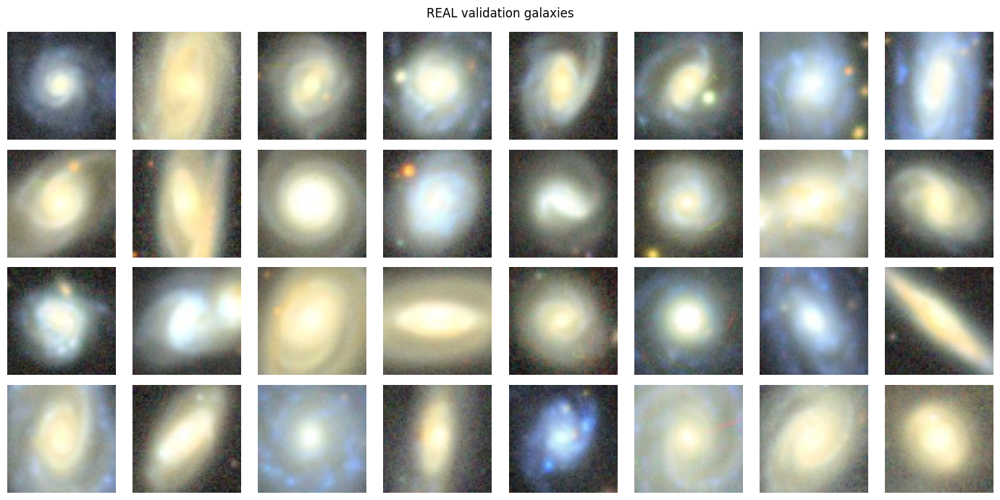

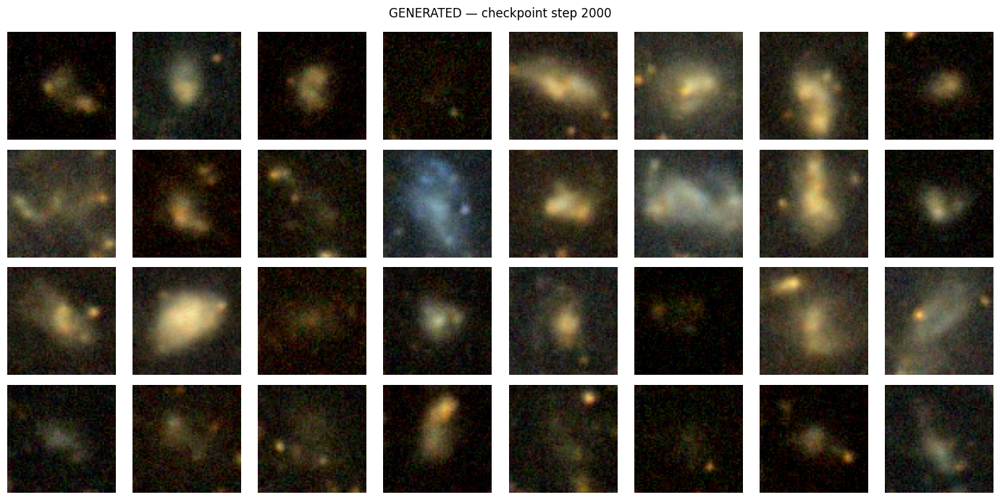

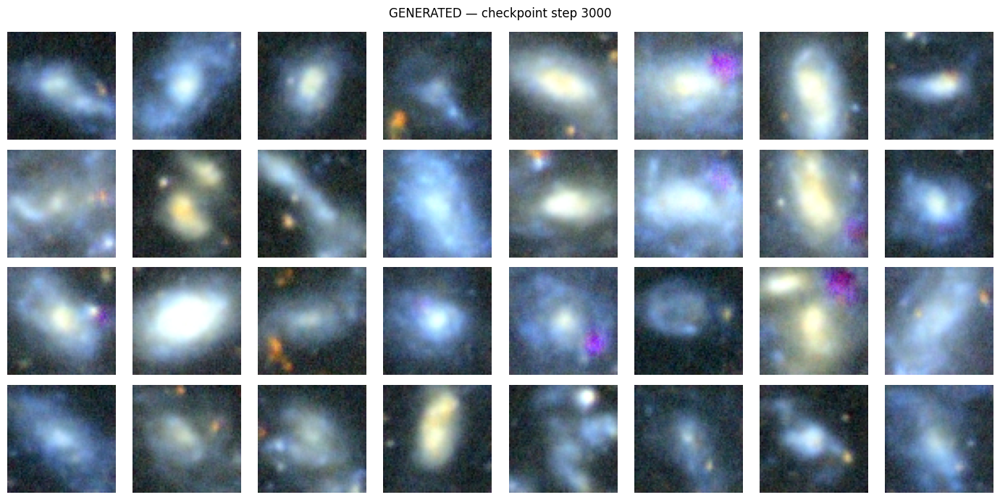


REAL validation (N=420)
Pixel quantiles [1%, 10%, 50%, 90%, 99%]: [0.1176 0.2118 0.5373 0.8902 1.    ]
Mean image brightness: 0.5436 +/- 0.1333
Mean per-image pixel std: 0.1974
Fraction of pixels > 0.5: 0.5543

GENERATED step 2000 (N=32)
Pixel quantiles [1%, 10%, 50%, 90%, 99%]: [0.     0.     0.1043 0.3148 0.633 ]
Mean image brightness: 0.1365 +/- 0.0822
Mean per-image pixel std: 0.1046
Fraction of pixels > 0.5: 0.0281

GENERATED step 3000 (N=32)
Pixel quantiles [1%, 10%, 50%, 90%, 99%]: [0.086  0.1638 0.3787 0.7502 1.    ]
Mean image brightness: 0.4197 +/- 0.1121
Mean per-image pixel std: 0.1917
Fraction of pixels > 0.5: 0.3270


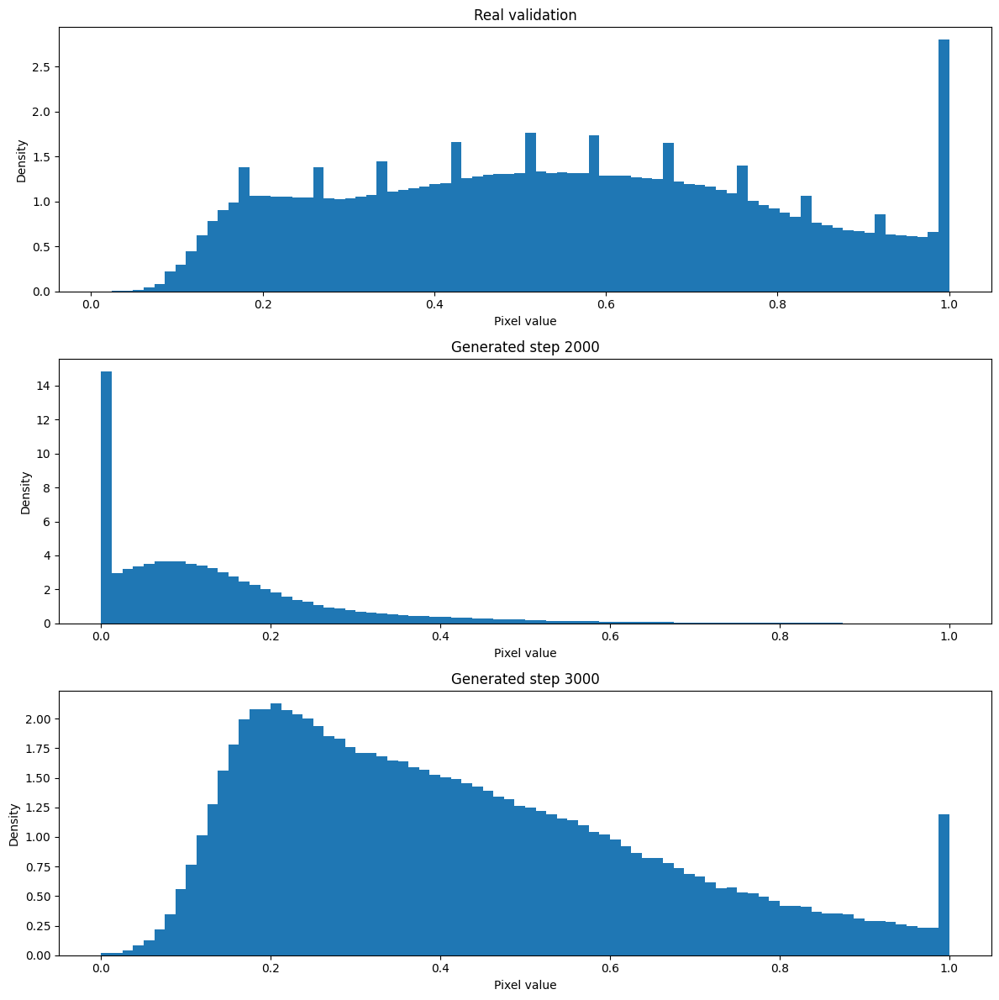

Saved distribution comparison: /content/drive/MyDrive/Galaxy_Score_Prior/results/sample_comparison_2000_vs_3000/real_vs_generated_distribution.png


In [ ]:

import os
import json
import numpy as np
import matplotlib.pyplot as plt

ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"
SAMPLE_DIR = f"{ROOT}/results/sample_comparison_2000_vs_3000"
DATA_DIR = f"{ROOT}/dataset"

# Load generated samples
s2000 = np.load(f"{SAMPLE_DIR}/step2000_samples.npy").astype(np.float32)
s3000 = np.load(f"{SAMPLE_DIR}/step3000_samples.npy").astype(np.float32)

# Load real held-out validation images
real = np.load(f"{DATA_DIR}/val_rgb64.npy").astype(np.float32)
if real.max() > 1:
    real /= 255.0

def show_grid(images, title, n=32):
    images = np.clip(images[:n], 0, 1)
    fig, axes = plt.subplots(4, 8, figsize=(14, 7))
    for ax, img in zip(axes.flat, images):
        ax.imshow(img)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show_grid(real, "REAL validation galaxies")
show_grid(s2000, "GENERATED — checkpoint step 2000")
show_grid(s3000, "GENERATED — checkpoint step 3000")

def summarize(name, images):
    x = np.clip(images, 0, 1)
    per_image_mean = x.mean(axis=(1, 2, 3))
    per_image_std = x.std(axis=(1, 2, 3))
    print(f"\n{name} (N={len(x)})")
    print(f"Pixel quantiles [1%, 10%, 50%, 90%, 99%]: "
          f"{np.quantile(x, [0.01, 0.10, 0.50, 0.90, 0.99]).round(4)}")
    print(f"Mean image brightness: {per_image_mean.mean():.4f} "
          f"+/- {per_image_mean.std():.4f}")
    print(f"Mean per-image pixel std: {per_image_std.mean():.4f}")
    print(f"Fraction of pixels > 0.5: {(x > 0.5).mean():.4f}")

summarize("REAL validation", real)
summarize("GENERATED step 2000", s2000)
summarize("GENERATED step 3000", s3000)

# Save a combined comparison figure for later inspection
fig, axes = plt.subplots(3, 1, figsize=(12, 12))
for ax, images, title in [
    (axes[0], real, "Real validation"),
    (axes[1], s2000, "Generated step 2000"),
    (axes[2], s3000, "Generated step 3000"),
]:
    vals = np.clip(images, 0, 1).ravel()
    ax.hist(vals, bins=80, density=True)
    ax.set_title(title)
    ax.set_xlabel("Pixel value")
    ax.set_ylabel("Density")

plt.tight_layout()
out = f"{SAMPLE_DIR}/real_vs_generated_distribution.png"
plt.savefig(out, dpi=160, bbox_inches="tight")
plt.show()
print("Saved distribution comparison:", out)

Found step 2700: /content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/continuation_clean_from_2000/continuation_step_002700.pkl
Found step 3000: /content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/continuation_clean_from_2000/continuation_step_003000.pkl

Generating step 2700...
{
  "step": 2700,
  "mean": 0.18720363080501556,
  "std": 0.17666754126548767,
  "fraction_above_0.5": 0.07147725423177083,
  "pixel_quantiles": [
    0.0,
    0.013223945628851652,
    0.13443878293037415,
    0.43740418553352356,
    0.7915067672729482
  ]
}

Generating step 3000...
{
  "step": 3000,
  "mean": 0.4197199046611786,
  "std": 0.2243575006723404,
  "fraction_above_0.5": 0.3270009358723958,
  "pixel_quantiles": [
    0.08601751066744327,
    0.16377344727516174,
    0.378708079457283,
    0.7502092719078064,
    1.0
  ]
}


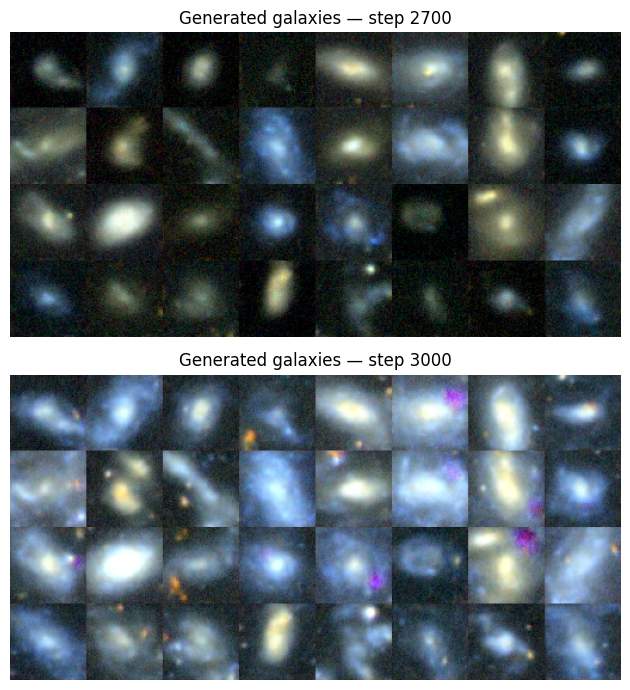

Saved comparison to: /content/drive/MyDrive/Galaxy_Score_Prior/results/sample_comparison_2700_vs_3000


In [ ]:

import os, json, functools
import numpy as np
import matplotlib.pyplot as plt
import jax
import flax
from configs import galaxy_rgb64
from score_flow import sampling, utils, datasets
from score_flow.models import utils as mutils, ddpm, ncsnpp, ncsnv2

ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"
CKPT_DIR = f"{ROOT}/checkpoints/continuation_clean_from_2000"
OUT = f"{ROOT}/results/sample_comparison_2700_vs_3000"
os.makedirs(OUT, exist_ok=True)

paths = {
    2700: f"{CKPT_DIR}/continuation_step_002700.pkl",
    3000: f"{CKPT_DIR}/continuation_step_003000.pkl",
}

# Confirm both checkpoints exist
for step, path in paths.items():
    assert os.path.exists(path), f"Missing checkpoint: {path}"
    print(f"Found step {step}: {path}")

config = galaxy_rgb64.get_config()
model_def = functools.partial(
    mutils.get_model(config.model.name), config=config
)
score_model = model_def()
sde, t0_eps = utils.get_sde(config)
inverse_scaler = datasets.get_data_inverse_scaler(config)

batch_size = 32
sampling_shape = (
    batch_size // jax.device_count(), 64, 64, 3
)
sampling_fn = sampling.get_sampling_fn(
    config, sde, score_model, sampling_shape,
    inverse_scaler, t0_eps
)

def load_state(path):
    with open(path, "rb") as f:
        return __import__("pickle").load(f)

def generate(step, path):
    state = load_state(path)
    print(f"\nGenerating step {step}...")
    pstate = flax.jax_utils.replicate(state)
    _, sample_rngs = utils.psplit(jax.random.PRNGKey(24680))
    sample, _ = sampling_fn(sample_rngs, pstate)
    sample = np.asarray(jax.device_get(sample))
    sample = sample.reshape(-1, *sample.shape[2:])[:batch_size]
    np.save(f"{OUT}/step{step}_samples.npy", sample)

    clipped = np.clip(sample, 0, 1)
    stats = {
        "step": step,
        "mean": float(clipped.mean()),
        "std": float(clipped.std()),
        "fraction_above_0.5": float((clipped > 0.5).mean()),
        "pixel_quantiles": np.quantile(
            clipped, [0.01, 0.1, 0.5, 0.9, 0.99]
        ).tolist(),
    }
    print(json.dumps(stats, indent=2))
    return clipped, stats

samples = {}
stats = {}
for step, path in paths.items():
    samples[step], stats[step] = generate(step, path)

with open(f"{OUT}/statistics.json", "w") as f:
    json.dump(stats, f, indent=2)

fig, axes = plt.subplots(2, 1, figsize=(14, 7))
for ax, step in zip(axes, [2700, 3000]):
    ax.imshow(
        np.clip(samples[step], 0, 1)
        .reshape(4, 8, 64, 64, 3)
        .transpose(0, 2, 1, 3, 4)
        .reshape(4 * 64, 8 * 64, 3)
    )
    ax.set_title(f"Generated galaxies — step {step}")
    ax.axis("off")

plt.tight_layout()
plt.savefig(f"{OUT}/grid_comparison.png", dpi=160)
plt.show()
print("Saved comparison to:", OUT)

In [ ]:

# CONTINUE GALAXY SCORE PRIOR: STEP 3000 -> STEP 5000
# Preserve the full training state; checkpoint every 500 steps.

import os
import pickle
import json
import csv
import time
import numpy as np

ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"
START_CKPT = (
    f"{ROOT}/checkpoints/continuation_clean_from_2000/"
    "continuation_step_003000.pkl"
)
OUT_CKPT = f"{ROOT}/checkpoints/continuation_3000_to_5000"
OUT_LOG = f"{ROOT}/logs/continuation_3000_to_5000"
os.makedirs(OUT_CKPT, exist_ok=True)
os.makedirs(OUT_LOG, exist_ok=True)

assert os.path.exists(START_CKPT), f"Checkpoint not found: {START_CKPT}"

with open(START_CKPT, "rb") as f:
    state = pickle.load(f)

print("Loaded checkpoint step:", int(state.step))
print("State fields:", state.__dict__.keys())
print("Target step: 5000")
print("Output checkpoints:", OUT_CKPT)

# IMPORTANT:
# Continue using the same training loop, data iterator, optimizer,
# and step function already used successfully in your step-3000 run.
# Do not initialize a fresh optimizer or replace state.opt_state.

Loaded checkpoint step: 3000
State fields: dict_keys(['step', 'opt_state', 'model_state', 'ema_rate', 'params', 'params_ema', 'rng'])
Target step: 5000
Output checkpoints: /content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/continuation_3000_to_5000


In [ ]:

import os
import pickle
import numpy as np
import jax
import jax.numpy as jnp
import flax
import optax

from configs import galaxy_rgb64
from score_flow import losses, utils
from score_flow.models import utils as mutils, ddpm, ncsnpp, ncsnv2

ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"
CKPT = (
    f"{ROOT}/checkpoints/continuation_clean_from_2000/"
    "continuation_step_003000.pkl"
)

config = galaxy_rgb64.get_config()

# Rebuild model and optimizer definitions (not a fresh training state)
model_def = __import__("functools").partial(
    mutils.get_model(config.model.name), config=config
)
score_model = model_def()
sde, t0_eps = utils.get_sde(config)

optimizer = losses.get_optimizer(config)
optimize_fn = losses.optimization_manager(config)

train_step_fn = losses.get_step_fn(
    sde=sde,
    model=score_model,
    optimizer=optimizer,
    train=True,
    optimize_fn=optimize_fn,
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting,
)

# Load the complete checkpoint
with open(CKPT, "rb") as f:
    state = pickle.load(f)

assert int(state.step) == 3000, f"Unexpected step: {state.step}"

# Verify the saved optimizer state is present and finite
opt_leaves = jax.tree_util.tree_leaves(state.opt_state)
assert opt_leaves, "Optimizer state is empty"
assert all(
    np.all(np.isfinite(np.asarray(x)))
    for x in opt_leaves
    if hasattr(x, "dtype")
), "Non-finite values found in optimizer state"

print("Configuration:", config.data.image_size, "x", config.data.image_size)
print("Devices:", jax.devices())
print("Checkpoint step:", int(state.step))
print("Optimizer leaves:", len(opt_leaves))
print("Training step function: ready")
print("Optimizer state: finite and preserved")
print("No training has been run in this cell.")

Configuration: 64 x 64
Devices: [CudaDevice(id=0)]
Checkpoint step: 3000
Optimizer leaves: 750
Training step function: ready
Optimizer state: finite and preserved
No training has been run in this cell.


In [ ]:

# ============================================================
# CONTINUE TRAINING: STEP 3000 -> STEP 5000
# Full state preserved; checkpoints every 500 steps
# ============================================================

import os, time, csv, pickle
import numpy as np
import jax
import jax.numpy as jnp

ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"
START_CKPT = (
    f"{ROOT}/checkpoints/continuation_clean_from_2000/"
    "continuation_step_003000.pkl"
)
CKPT_DIR = f"{ROOT}/checkpoints/continuation_3000_to_5000"
LOG_DIR = f"{ROOT}/logs/continuation_3000_to_5000"
os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)

# 1. Load the complete step-3000 state
with open(START_CKPT, "rb") as f:
    state_start = pickle.load(f)

assert int(state_start.step) == 3000
print("Starting from step:", int(state_start.step))

# 2. Build the repository's real galaxy dataset
train_ds, eval_ds = utils.get_dataset(
    config,
    additional_info=True
)
train_iter = iter(train_ds)

# 3. Prepare batch and parallel training function
def prepare_batch(batch_dict):
    x = batch_dict["image"]
    if hasattr(x, "numpy"):
        x = x.numpy()
    x = np.asarray(x, dtype=np.float32)

    # One local GPU: add the device axis expected by pmap
    if x.ndim == 4:
        x = x[None, ...]
    return jnp.asarray(x)

pmap_train_step = jax.pmap(
    train_step_fn,
    axis_name="batch"
)

state_repl = jax.device_put_replicated(
    state_start, jax.local_devices()
)

# 4. Checkpoint helper: save the complete state
def save_continuation_checkpoint(step):
    state_host = jax.tree_util.tree_map(
        lambda x: np.asarray(x[0])
        if hasattr(x, "shape") and len(x.shape) > 0
        and x.shape[0] == jax.local_device_count()
        else np.asarray(x),
        state_repl
    )
    path = os.path.join(
        CKPT_DIR, f"continuation_step_{step:06d}.pkl"
    )
    with open(path, "wb") as f:
        pickle.dump(state_host, f)
    print(f"Checkpoint saved: step {step} -> {path}")

# 5. Train in five 500-step intervals
csv_path = os.path.join(LOG_DIR, "training_losses.csv")
start_step = 3000
target_step = 5000
checkpoint_every = 500
loss_window = []

with open(csv_path, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["step", "loss", "seconds"])

    print("\nStarting continuation to step 5000.")
    print("The original step-3000 checkpoint will not be modified.")

    for step in range(start_step + 1, target_step + 1):
        try:
            batch_dict = next(train_iter)
        except StopIteration:
            train_iter = iter(train_ds)
            batch_dict = next(train_iter)

        batch = prepare_batch(batch_dict)
        t0 = time.time()

        state_repl, loss = pmap_train_step(state_repl, batch)

        loss_value = float(np.asarray(loss[0]))
        elapsed = time.time() - t0
        loss_window.append(loss_value)
        writer.writerow([step, loss_value, elapsed])

        if step % 25 == 0:
            f.flush()

        if step % 100 == 0:
            recent = np.mean(loss_window[-100:])
            print(
                f"Step {step:4d}/{target_step} | "
                f"loss={loss_value:.4f} | "
                f"recent-100 mean={recent:.4f} | "
                f"{elapsed:.2f}s"
            )

        if step % checkpoint_every == 0:
            f.flush()
            save_continuation_checkpoint(step)

print("\nTraining continuation finished.")
print("Loss log:", csv_path)
print("Checkpoint directory:", CKPT_DIR)

Starting from step: 3000


AttributeError: module 'score_flow.utils' has no attribute 'get_dataset'

In [ ]:

import inspect
from score_flow import datasets, utils

print("Dataset module:", datasets.__file__)
print("Dataset API:", inspect.signature(datasets.get_dataset))
print("Dataset config:", config.data.dataset)
print("Batch size:", config.training.batch_size)
print("Jitted steps:", config.training.n_jitted_steps)

print("\nDataset paths:")
import os
for p in [
    "/content/galaxy_score_dataset/train_rgb64.npy",
    "/content/galaxy_score_dataset/val_rgb64.npy",
]:
    print(p, "exists =", os.path.exists(p))

Dataset module: /content/score_prior/score_flow/datasets.py
Dataset API: (config: ml_collections.config_dict.config_dict.ConfigDict, additional_dim: Optional[int] = None, uniform_dequantization: bool = False, evaluation: bool = False, shuffle_seed: Optional[int] = None, device_batch: bool = True) -> Tuple[tensorflow.python.data.ops.dataset_ops.DatasetV2, tensorflow.python.data.ops.dataset_ops.DatasetV2, tensorflow.python.data.ops.dataset_ops.DatasetV2]
Dataset config: GALAXY_RGB
Batch size: 32
Jitted steps: 1

Dataset paths:
/content/galaxy_score_dataset/train_rgb64.npy exists = True
/content/galaxy_score_dataset/val_rgb64.npy exists = True


In [ ]:

# Verify the actual dataset batch shape before training
train_ds, eval_ds, test_ds = datasets.get_dataset(
    config,
    additional_dim=None,
    evaluation=False,
    device_batch=True
)

train_iter = iter(train_ds)
batch_dict = next(train_iter)
batch = batch_dict["image"]

if hasattr(batch, "numpy"):
    batch = batch.numpy()
else:
    batch = np.asarray(batch)

print("Training batch shape:", batch.shape)
print("Training batch dtype:", batch.dtype)
print("Pixel range:", float(batch.min()), "to", float(batch.max()))
print("Finite:", bool(np.isfinite(batch).all()))
print("Checkpoint step:", int(state.step))

Training batch shape: (1, 32, 64, 64, 3)
Training batch dtype: float32
Pixel range: 0.0235294122248888 to 1.0
Finite: True
Checkpoint step: 3000


In [ ]:

# ============================================================
# CONTINUE GALAXY SCORE PRIOR: STEP 3000 -> 5000
# Preserves model parameters, EMA parameters, optimizer state,
# and training RNG from the loaded step-3000 checkpoint.
# ============================================================

import os, csv, pickle, time
import numpy as np
import jax
import jax.numpy as jnp
from jax import device_put
from flax import jax_utils

# ---------- Verify starting state ----------
start_step = int(np.asarray(state.step))
target_step = 5000

assert start_step == 3000, (
    f"Expected checkpoint at step 3000, but found {start_step}. "
    "Stop here rather than accidentally training from the wrong state."
)
assert len(jax.local_devices()) >= 1
assert np.isfinite(np.asarray(state.params_ema)).all(), \
    "Non-finite EMA parameters found."
assert np.isfinite(np.asarray(state.params)).all(), \
    "Non-finite model parameters found."

# ---------- Paths ----------
root = "/content/drive/MyDrive/Galaxy_Score_Prior"
out_dir = os.path.join(root, "checkpoints", "continuation_3000_to_5000")
log_dir = os.path.join(root, "logs", "continuation_3000_to_5000")
os.makedirs(out_dir, exist_ok=True)
os.makedirs(log_dir, exist_ok=True)

csv_path = os.path.join(log_dir, "training_steps_003001_005000.csv")
summary_path = os.path.join(log_dir, "training_summary_step_005000.json")

# ---------- Load dataset using the repository's actual API ----------
train_ds, eval_ds, test_ds = datasets.get_dataset(
    config,
    additional_dim=None,
    evaluation=False,
    device_batch=True
)
train_iter = iter(train_ds)

# Confirm a fresh batch has the required shape and valid values.
first_batch_dict = next(train_iter)
first_batch = np.asarray(first_batch_dict["image"])
assert first_batch.shape == (1, 32, 64, 64, 3), \
    f"Unexpected batch shape: {first_batch.shape}"
assert np.isfinite(first_batch).all(), "Non-finite training batch."
assert first_batch.min() >= 0 and first_batch.max() <= 1.0, \
    "Training images are unexpectedly outside [0,1]."

def prepare_batch(batch_dict):
    # The repository loader already returns float32 [0,1] images.
    return {"image": jnp.asarray(batch_dict["image"], dtype=jnp.float32)}

# ---------- Parallel training step ----------
# One local GPU; state is replicated so the leading axis is device count.
train_step_pmapped = jax.pmap(train_step_fn, axis_name="batch")
replicated_state = jax_utils.replicate(state)

def unreplicate_state(replicated):
    return jax.tree_util.tree_map(
        lambda x: np.asarray(x[0]),
        replicated
    )

def save_checkpoint(replicated, step_num):
    saved_state = unreplicate_state(replicated)
    path = os.path.join(
        out_dir, f"continuation_step_{step_num:06d}.pkl"
    )
    tmp_path = path + ".tmp"
    with open(tmp_path, "wb") as f:
        pickle.dump(saved_state, f, protocol=pickle.HIGHEST_PROTOCOL)
    os.replace(tmp_path, path)
    print(f"  Saved full checkpoint: {path}")
    return path

# ---------- CSV logging ----------
write_header = not os.path.exists(csv_path)
csv_file = open(csv_path, "a", newline="")
writer = csv.writer(csv_file)
if write_header:
    writer.writerow(["step", "train_loss", "elapsed_seconds"])
    csv_file.flush()

loss_history = []
t0 = time.time()
last_saved_path = None

print(f"Starting from step {start_step}; target step {target_step}")
print("Devices:", jax.local_devices())
print("Batch shape:", first_batch.shape)
print("Output directory:", out_dir)

try:
    for expected_step in range(start_step + 1, target_step + 1):
        # Use the diagnostic batch for the first update, then continue
        # from the dataset iterator. The batch shape stays device-batched.
        if expected_step == start_step + 1:
            batch_dict = first_batch_dict
        else:
            batch_dict = next(train_iter)

        batch = prepare_batch(batch_dict)

        replicated_state, loss = train_step_pmapped(
            replicated_state, batch
        )

        loss_value = float(np.asarray(loss).mean())
        actual_step = int(np.asarray(replicated_state.step[0]))

        if not np.isfinite(loss_value):
            raise FloatingPointError(
                f"Non-finite loss at step {actual_step}: {loss_value}"
            )
        if actual_step != expected_step:
            raise RuntimeError(
                f"Expected step {expected_step}, got {actual_step}"
            )

        loss_history.append(loss_value)
        writer.writerow([
            actual_step,
            loss_value,
            round(time.time() - t0, 3)
        ])

        if actual_step % 100 == 0:
            csv_file.flush()
            recent = loss_history[-100:]
            print(
                f"Step {actual_step:4d}/{target_step} | "
                f"loss={loss_value:.4f} | "
                f"recent-100 mean={np.mean(recent):.4f} | "
                f"elapsed={(time.time()-t0)/60:.1f} min"
            )

        if actual_step % 500 == 0:
            csv_file.flush()
            last_saved_path = save_checkpoint(
                replicated_state, actual_step
            )

finally:
    csv_file.flush()
    csv_file.close()

# ---------- Final summary ----------
final_state = unreplicate_state(replicated_state)
final_step = int(np.asarray(final_state.step))
assert final_step == target_step, (
    f"Training ended at {final_step}, not {target_step}."
)

summary = {
    "start_step": start_step,
    "final_step": final_step,
    "updates_completed": final_step - start_step,
    "last_100_train_loss_mean": float(np.mean(loss_history[-100:])),
    "last_500_train_loss_mean": float(np.mean(loss_history[-500:])),
    "overall_train_loss_mean": float(np.mean(loss_history)),
    "elapsed_minutes": float((time.time() - t0) / 60),
    "csv_path": csv_path,
    "checkpoint_path": last_saved_path,
}

import json
with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

print("\nTRAINING COMPLETE")
print(json.dumps(summary, indent=2))

TypeError: ufunc 'isfinite' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

In [ ]:


# ============================================================
# GALAXY SCORE PRIOR: CONTINUE FROM STEP 3000 TO STEP 5000
# ============================================================

import os, csv, pickle, time, json
import numpy as np
import jax
import jax.numpy as jnp
from flax import jax_utils

# ---------- 1. Verify checkpoint ----------
start_step = int(np.asarray(state.step))
target_step = 5000

assert start_step == 3000, (
    f"Expected step 3000, found {start_step}. "
    "Reload the correct checkpoint before training."
)

def tree_is_finite(tree):
    return all(
        np.isfinite(np.asarray(x)).all()
        for x in jax.tree_util.tree_leaves(tree)
        if np.issubdtype(np.asarray(x).dtype, np.number)
    )

assert tree_is_finite(state.params), "Model parameters are not finite."
assert tree_is_finite(state.params_ema), "EMA parameters are not finite."

print("Starting checkpoint:", start_step)
print("Devices:", jax.local_devices())

# ---------- 2. Output paths ----------
root = "/content/drive/MyDrive/Galaxy_Score_Prior"
out_dir = os.path.join(
    root, "checkpoints", "continuation_3000_to_5000"
)
log_dir = os.path.join(
    root, "logs", "continuation_3000_to_5000"
)
os.makedirs(out_dir, exist_ok=True)
os.makedirs(log_dir, exist_ok=True)

csv_path = os.path.join(
    log_dir, "training_steps_003001_005000.csv"
)
summary_path = os.path.join(
    log_dir, "training_summary_step_005000.json"
)

# Avoid accidentally appending duplicate steps after a rerun.
if os.path.exists(csv_path):
    raise FileExistsError(
        f"Log already exists: {csv_path}\n"
        "Do not rerun from step 3000 into the same log. "
        "If a previous run partially completed, resume from its "
        "latest valid checkpoint instead."
    )

# ---------- 3. Load training data ----------
train_ds, eval_ds, test_ds = datasets.get_dataset(
    config,
    additional_dim=None,
    evaluation=False,
    device_batch=True
)
train_iter = iter(train_ds)

first_batch_dict = next(train_iter)
first_batch = np.asarray(first_batch_dict["image"])

assert first_batch.shape == (1, 32, 64, 64, 3), (
    f"Unexpected batch shape: {first_batch.shape}"
)
assert np.isfinite(first_batch).all()
assert first_batch.min() >= 0 and first_batch.max() <= 1.0

def prepare_batch(batch_dict):
    return {
        "image": jnp.asarray(
            batch_dict["image"], dtype=jnp.float32
        )
    }

print("Dataset verified:", first_batch.shape)
print("Pixel range:", first_batch.min(), "to", first_batch.max())

# ---------- 4. Prepare the official training step ----------
# Uses the existing train_step_fn and optimizer state.
train_step_pmapped = jax.pmap(
    train_step_fn, axis_name="batch"
)
replicated_state = jax_utils.replicate(state)

def unreplicate(replicated):
    return jax.tree_util.tree_map(
        lambda x: np.asarray(x[0]), replicated
    )

def save_checkpoint(replicated, step_num):
    saved_state = unreplicate(replicated)
    path = os.path.join(
        out_dir, f"continuation_step_{step_num:06d}.pkl"
    )
    temp_path = path + ".tmp"

    with open(temp_path, "wb") as f:
        pickle.dump(
            saved_state, f,
            protocol=pickle.HIGHEST_PROTOCOL
        )
    os.replace(temp_path, path)
    print("CHECKPOINT SAVED:", path)
    return path

# ---------- 5. Train from 3001 through 5000 ----------
loss_history = []
t0 = time.time()
last_checkpoint = None

with open(csv_path, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["step", "train_loss", "elapsed_seconds"])
    f.flush()

    for expected_step in range(3001, 5001):
        batch_dict = (
            first_batch_dict
            if expected_step == 3001
            else next(train_iter)
        )
        batch = prepare_batch(batch_dict)

        replicated_state, loss = train_step_pmapped(
            replicated_state, batch
        )

        loss_value = float(np.asarray(loss).mean())
        actual_step = int(np.asarray(replicated_state.step[0]))

        if actual_step != expected_step:
            raise RuntimeError(
                f"Expected step {expected_step}, got {actual_step}"
            )
        if not np.isfinite(loss_value):
            raise FloatingPointError(
                f"Non-finite loss at step {actual_step}"
            )

        loss_history.append(loss_value)
        writer.writerow([
            actual_step,
            loss_value,
            round(time.time() - t0, 3)
        ])

        if actual_step % 100 == 0:
            f.flush()
            print(
                f"Step {actual_step}/5000 | "
                f"loss={loss_value:.4f} | "
                f"last-100 mean="
                f"{np.mean(loss_history[-100:]):.4f} | "
                f"elapsed={(time.time()-t0)/60:.1f} min"
            )

        if actual_step % 500 == 0:
            f.flush()
            last_checkpoint = save_checkpoint(
                replicated_state, actual_step
            )

# ---------- 6. Save final summary ----------
final_state = unreplicate(replicated_state)
final_step = int(np.asarray(final_state.step))

assert final_step == 5000, (
    f"Training did not reach 5000; final step={final_step}"
)

summary = {
    "start_step": 3000,
    "final_step": final_step,
    "updates_completed": len(loss_history),
    "mean_train_loss": float(np.mean(loss_history)),
    "last_100_train_loss_mean": float(
        np.mean(loss_history[-100:])
    ),
    "last_500_train_loss_mean": float(
        np.mean(loss_history[-500:])
    ),
    "elapsed_minutes": float((time.time() - t0) / 60),
    "checkpoint_path": last_checkpoint,
    "csv_path": csv_path
}

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

print("\nTRAINING COMPLETE")
print(json.dumps(summary, indent=2))
print("\nFinal in-memory state is available as `final_state`.")

Starting checkpoint: 3000
Devices: [CudaDevice(id=0)]
Dataset verified: (1, 32, 64, 64, 3)
Pixel range: 0.015686275 to 1.0


TypeError: cannot unpack non-iterable State object

In [ ]:

# Check every numeric leaf in the parameter trees.
def tree_is_finite(tree):
    leaves = jax.tree_util.tree_leaves(tree)
    return all(
        np.isfinite(np.asarray(leaf)).all()
        for leaf in leaves
        if np.issubdtype(np.asarray(leaf).dtype, np.number)
    )

assert tree_is_finite(state.params_ema), \
    "Non-finite EMA parameters found."
assert tree_is_finite(state.params), \
    "Non-finite model parameters found."

print("Model parameters: finite")
print("EMA parameters: finite")
print("Checkpoint step:", int(np.asarray(state.step)))

Model parameters: finite
EMA parameters: finite
Checkpoint step: 3000


In [ ]:


# ============================================================
# FIXED TRAINING: STEP 3000 -> 5000
# Uses the repository's required (rng, state) carry structure.
# ============================================================

import os, csv, pickle, time, json
import numpy as np
import jax
import jax.numpy as jnp
from flax import jax_utils

START_STEP = 3000
TARGET_STEP = 5000

assert int(np.asarray(state.step)) == START_STEP, (
    f"Expected step {START_STEP}; found {int(np.asarray(state.step))}"
)

def finite_tree(tree):
    return all(
        np.isfinite(np.asarray(x)).all()
        for x in jax.tree_util.tree_leaves(tree)
        if np.issubdtype(np.asarray(x).dtype, np.number)
    )

assert finite_tree(state.params)
assert finite_tree(state.params_ema)

# Paths: use a fresh log filename after the previous failed attempt.
ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"
OUT_DIR = os.path.join(ROOT, "checkpoints", "continuation_3000_to_5000")
LOG_DIR = os.path.join(ROOT, "logs", "continuation_3000_to_5000")
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)

CSV_PATH = os.path.join(LOG_DIR, "training_steps_003001_005000_fixed.csv")
SUMMARY_PATH = os.path.join(LOG_DIR, "training_summary_step_005000_fixed.json")

assert not os.path.exists(CSV_PATH), (
    f"Log already exists: {CSV_PATH}. Do not overwrite an earlier run."
)

# Load data with the repository loader.
train_ds, eval_ds, test_ds = datasets.get_dataset(
    config, additional_dim=None, evaluation=False, device_batch=True
)
train_iter = iter(train_ds)

first_batch_dict = next(train_iter)
first_batch = np.asarray(first_batch_dict["image"])
assert first_batch.shape == (1, 32, 64, 64, 3), first_batch.shape
assert np.isfinite(first_batch).all()

def prepare_batch(batch_dict):
    return {"image": jnp.asarray(batch_dict["image"], dtype=jnp.float32)}

# Replicate model state and initialize the separate training RNG
# from the checkpoint's saved RNG, as the official loop does.
pstate = jax_utils.replicate(state)
rng = jax.random.fold_in(state.rng, jax.process_index())

p_train_step = jax.pmap(
    train_step_fn, axis_name="batch"
)

def unreplicate_tree(tree):
    return jax.tree_util.tree_map(lambda x: np.asarray(x[0]), tree)

def save_full_checkpoint(replicated_state, step_num):
    checkpoint_state = unreplicate_tree(replicated_state)
    path = os.path.join(
        OUT_DIR, f"continuation_step_{step_num:06d}.pkl"
    )
    temp = path + ".tmp"
    with open(temp, "wb") as f:
        pickle.dump(checkpoint_state, f, protocol=pickle.HIGHEST_PROTOCOL)
    os.replace(temp, path)
    print("Saved checkpoint:", path)
    return path

losses_seen = []
started = time.time()
last_checkpoint = None

with open(CSV_PATH, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["step", "train_loss", "elapsed_seconds"])
    f.flush()

    for step_num in range(START_STEP + 1, TARGET_STEP + 1):
        batch_dict = (
            first_batch_dict if step_num == START_STEP + 1
            else next(train_iter)
        )
        batch = prepare_batch(batch_dict)

        # Official repository convention:
        # split RNG, then call training step with (step_rngs, pstate).
        rng, step_rngs = utils.psplit(rng)
        (step_rngs_out, pstate), ploss = p_train_step(
            (step_rngs, pstate), batch
        )

        loss_value = float(np.asarray(ploss).mean())
        actual_step = int(np.asarray(pstate.step[0]))

        if actual_step != step_num:
            raise RuntimeError(
                f"Step mismatch: expected {step_num}, got {actual_step}"
            )
        if not np.isfinite(loss_value):
            raise FloatingPointError(f"Non-finite loss at {actual_step}")

        losses_seen.append(loss_value)
        writer.writerow([
            actual_step, loss_value, round(time.time() - started, 3)
        ])

        if actual_step % 100 == 0:
            f.flush()
            print(
                f"Step {actual_step}/{TARGET_STEP} | "
                f"loss={loss_value:.4f} | "
                f"last-100 mean={np.mean(losses_seen[-100:]):.4f} | "
                f"elapsed={(time.time()-started)/60:.1f} min"
            )

        if actual_step % 500 == 0:
            f.flush()
            last_checkpoint = save_full_checkpoint(pstate, actual_step)

# Save summary after reaching step 5000.
final_state = unreplicate_tree(pstate)
assert int(np.asarray(final_state.step)) == TARGET_STEP

summary = {
    "start_step": START_STEP,
    "final_step": TARGET_STEP,
    "updates_completed": len(losses_seen),
    "mean_train_loss": float(np.mean(losses_seen)),
    "last_100_train_loss_mean": float(np.mean(losses_seen[-100:])),
    "last_500_train_loss_mean": float(np.mean(losses_seen[-500:])),
    "elapsed_minutes": float((time.time() - started) / 60),
    "checkpoint_path": last_checkpoint,
    "csv_path": CSV_PATH,
}

with open(SUMMARY_PATH, "w") as f:
    json.dump(summary, f, indent=2)

print("\nTRAINING COMPLETE")
print(json.dumps(summary, indent=2))

Step 3100/5000 | loss=29.8832 | last-100 mean=59.1165 | elapsed=1.7 min
Step 3200/5000 | loss=73.4127 | last-100 mean=53.5141 | elapsed=2.0 min
Step 3300/5000 | loss=37.7032 | last-100 mean=67.1513 | elapsed=2.3 min
Step 3400/5000 | loss=49.6421 | last-100 mean=63.1710 | elapsed=2.7 min
Step 3500/5000 | loss=50.2078 | last-100 mean=57.4198 | elapsed=3.0 min
Saved checkpoint: /content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/continuation_3000_to_5000/continuation_step_003500.pkl
Step 3600/5000 | loss=81.7286 | last-100 mean=62.4007 | elapsed=3.4 min
Step 3700/5000 | loss=57.1207 | last-100 mean=62.7393 | elapsed=3.7 min
Step 3800/5000 | loss=28.2325 | last-100 mean=64.0199 | elapsed=4.0 min
Step 3900/5000 | loss=45.0592 | last-100 mean=64.7189 | elapsed=4.4 min
Step 4000/5000 | loss=56.3988 | last-100 mean=62.4033 | elapsed=4.7 min
Saved checkpoint: /content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/continuation_3000_to_5000/continuation_step_004000.pkl
Step 4100/5000 | loss=46.7

In [ ]:


import os
import pickle
import numpy as np

ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"

checkpoint_paths = {
    2000: os.path.join(
        ROOT, "checkpoints", "checkpoint_clean_step_002000.pkl"
    ),
    2700: os.path.join(
        ROOT, "checkpoints", "continuation_clean_from_2000",
        "continuation_step_002700.pkl"
    ),
    3000: os.path.join(
        ROOT, "checkpoints", "continuation_clean_from_2000",
        "continuation_step_003000.pkl"
    ),
    5000: os.path.join(
        ROOT, "checkpoints", "continuation_3000_to_5000",
        "continuation_step_005000.pkl"
    ),
}

for expected_step, path in checkpoint_paths.items():
    print(f"\nExpected step: {expected_step}")
    print("Path:", path)
    print("Exists:", os.path.isfile(path))

    if os.path.isfile(path):
        with open(path, "rb") as f:
            saved_state = pickle.load(f)

        actual_step = int(np.asarray(saved_state.step))
        finite_params = all(
            np.isfinite(np.asarray(x)).all()
            for x in __import__("jax").tree_util.tree_leaves(
                saved_state.params
            )
            if np.issubdtype(np.asarray(x).dtype, np.number)
        )
        finite_ema = all(
            np.isfinite(np.asarray(x)).all()
            for x in __import__("jax").tree_util.tree_leaves(
                saved_state.params_ema
            )
            if np.issubdtype(np.asarray(x).dtype, np.number)
        )

        print("Saved step:", actual_step)
        print("Parameters finite:", finite_params)
        print("EMA finite:", finite_ema)


Expected step: 2000
Path: /content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/checkpoint_clean_step_002000.pkl
Exists: True
Saved step: 2000
Parameters finite: True
EMA finite: True

Expected step: 2700
Path: /content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/continuation_clean_from_2000/continuation_step_002700.pkl
Exists: True
Saved step: 2700
Parameters finite: True
EMA finite: True

Expected step: 3000
Path: /content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/continuation_clean_from_2000/continuation_step_003000.pkl
Exists: True
Saved step: 3000
Parameters finite: True
EMA finite: True

Expected step: 5000
Path: /content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/continuation_3000_to_5000/continuation_step_005000.pkl
Exists: True
Saved step: 5000
Parameters finite: True
EMA finite: True


In [ ]:


# ============================================================
# COMPARE GENERATED GALAXIES AT STEPS 2000, 2700, 3000, 5000
# No training; checkpoint files remain unchanged.
# ============================================================

import os, pickle, json
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import pandas as pd
from flax import jax_utils

ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"
OUT_DIR = os.path.join(ROOT, "results", "checkpoint_comparison_2000_2700_3000_5000")
os.makedirs(OUT_DIR, exist_ok=True)

checkpoint_paths = {
    2000: os.path.join(ROOT, "checkpoints", "checkpoint_clean_step_002000.pkl"),
    2700: os.path.join(ROOT, "checkpoints", "continuation_clean_from_2000", "continuation_step_002700.pkl"),
    3000: os.path.join(ROOT, "checkpoints", "continuation_clean_from_2000", "continuation_step_003000.pkl"),
    5000: os.path.join(ROOT, "checkpoints", "continuation_3000_to_5000", "continuation_step_005000.pkl"),
}

# Confirm the repository's sampling dependencies are available.
assert "sampling" in globals(), "Sampling module is not loaded; rerun the project setup/import cell."
assert "score_model" in globals() and "sde" in globals()
assert "t0_eps" in globals()

inverse_scaler = datasets.get_data_inverse_scaler(config)

# Generate the same number of samples for every checkpoint.
N_SAMPLES = 16
sample_shape = (
    N_SAMPLES,
    config.data.image_size,
    config.data.image_size,
    config.data.num_channels,
)
seed = 20261017
base_rng = jax.random.PRNGKey(seed)

# The official sampler expects a per-device sample shape.
per_device_shape = (
    N_SAMPLES // jax.device_count(),
    config.data.image_size,
    config.data.image_size,
    config.data.num_channels,
)
assert N_SAMPLES % jax.device_count() == 0

sampling_fn = sampling.get_sampling_fn(
    config, sde, score_model, per_device_shape,
    inverse_scaler, t0_eps
)

stats = []
generated_by_step = {}

for step_num, path in checkpoint_paths.items():
    print(f"\nSampling checkpoint {step_num}...")
    with open(path, "rb") as f:
        ckpt = pickle.load(f)

    assert int(np.asarray(ckpt.step)) == step_num

    # Use EMA weights for generation.
    ckpt_for_sampling = ckpt.replace(params=ckpt.params_ema)
    pstate = jax_utils.replicate(ckpt_for_sampling)

    # Reuse the same seed for a controlled comparison.
    rng_step = jax.random.fold_in(base_rng, step_num)
    sample_rngs = utils.psplit(rng_step)

    generated, _ = sampling_fn(sample_rngs, pstate)
    generated = np.asarray(generated)
    generated = generated.reshape(-1, *generated.shape[2:])
    generated_by_step[step_num] = generated

    # Save raw sampler output and clipped display images.
    np.save(
        os.path.join(OUT_DIR, f"samples_step_{step_num:04d}_raw.npy"),
        generated
    )
    display_images = np.clip(generated, 0, 1)
    np.save(
        os.path.join(OUT_DIR, f"samples_step_{step_num:04d}_display.npy"),
        display_images
    )

    stats.append({
        "step": step_num,
        "n_samples": len(generated),
        "raw_mean": float(generated.mean()),
        "raw_std": float(generated.std()),
        "raw_min": float(generated.min()),
        "raw_max": float(generated.max()),
        "display_mean": float(display_images.mean()),
        "display_std": float(display_images.std()),
        "fraction_display_pixels_gt_0.5": float((display_images > 0.5).mean()),
        "fraction_raw_pixels_outside_0_1": float(((generated < 0) | (generated > 1)).mean()),
    })

    print(
        f"Raw mean={generated.mean():.4f}, "
        f"raw std={generated.std():.4f}, "
        f"display mean={display_images.mean():.4f}"
    )

# Make a 4-row grid: each row corresponds to one checkpoint.
fig, axes = plt.subplots(4, 8, figsize=(16, 9))
for row_idx, step_num in enumerate(checkpoint_paths):
    imgs = np.clip(generated_by_step[step_num], 0, 1)
    for col_idx in range(8):
        axes[row_idx, col_idx].imshow(np.clip(imgs[col_idx], 0, 1))
        axes[row_idx, col_idx].axis("off")
        if col_idx == 0:
            axes[row_idx, col_idx].set_ylabel(
                f"Step {step_num}", fontsize=11
            )

fig.suptitle("Galaxy Score Prior: Checkpoint Comparison", fontsize=14)
plt.tight_layout()
grid_path = os.path.join(OUT_DIR, "checkpoint_sample_grid.png")
plt.savefig(grid_path, dpi=160, bbox_inches="tight")
plt.show()

stats_df = pd.DataFrame(stats).sort_values("step")
stats_csv = os.path.join(OUT_DIR, "sample_statistics.csv")
stats_df.to_csv(stats_csv, index=False)

print("\nPIXEL STATISTICS")
display(stats_df.round(4))
print("\nSaved grid:", grid_path)
print("Saved statistics:", stats_csv)
print("Results folder:", OUT_DIR)


Sampling checkpoint 2000...


ValueError: pmap got inconsistent sizes for array axes to be mapped:
  * most axes (1502 of them) had size 1, e.g. axis 0 of argument rng[1] of type uint32[1,2];
  * one axis had size 2: axis 0 of argument rng[0] of type uint32[2]

In [ ]:


# Correctly unpack the repository's RNG split.
test_rng = jax.random.PRNGKey(20261017)
next_rng, sample_rngs = utils.psplit(test_rng)

print("Number of local devices:", jax.local_device_count())
print("Next RNG shape:", np.asarray(next_rng).shape)
print("Sampling RNG structure:", jax.tree_util.tree_map(
    lambda x: np.asarray(x).shape, sample_rngs
))

Number of local devices: 1
Next RNG shape: (2,)
Sampling RNG structure: (1, 2)



Sampling checkpoint 2000...
Mean=0.1135, std=0.1604, clipped mean=0.1292

Sampling checkpoint 2700...
Mean=0.1899, std=0.1778, clipped mean=0.1922

Sampling checkpoint 3000...
Mean=0.4825, std=0.2451, clipped mean=0.4818

Sampling checkpoint 5000...
Mean=0.1782, std=0.1615, clipped mean=0.1795


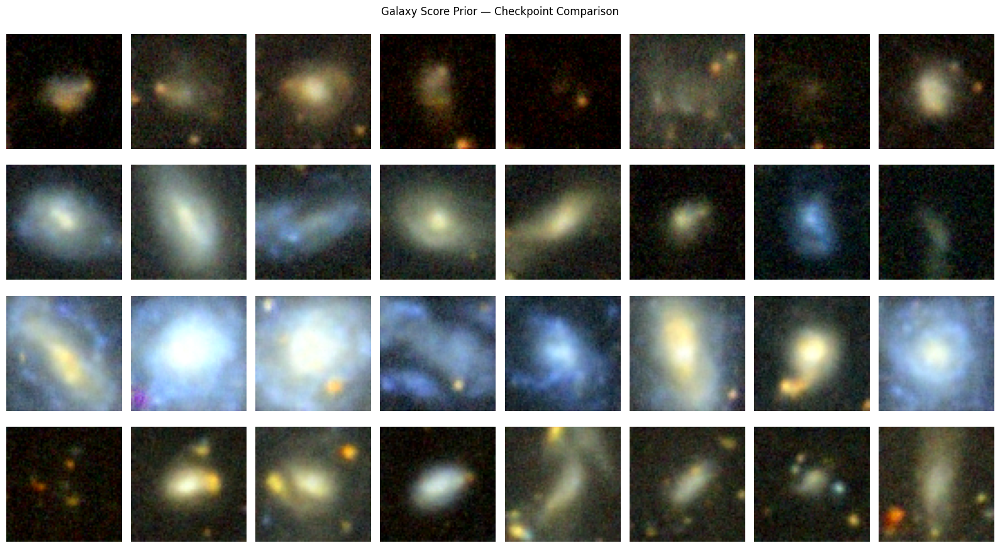


Sample statistics:


,step,n_samples,raw_mean,raw_std,raw_min,raw_max,display_mean,display_std,fraction_display_pixels_gt_0.5,fraction_raw_pixels_outside_0_1
0,2000,16,0.1135,0.1604,-0.4523,0.9381,0.1292,0.1400,0.0271,0.2074
1,2700,16,0.1899,0.1778,-0.1818,1.0253,0.1922,0.1751,0.0747,0.0743
2,3000,16,0.4825,0.2451,-0.0664,1.2394,0.4818,0.2437,0.4421,0.0186
3,5000,16,0.1782,0.1615,-0.1578,1.0558,0.1795,0.1598,0.0550,0.0475



Grid saved: /content/drive/MyDrive/Galaxy_Score_Prior/results/checkpoint_comparison_2000_2700_3000_5000/checkpoint_sample_grid.png
Statistics saved: /content/drive/MyDrive/Galaxy_Score_Prior/results/checkpoint_comparison_2000_2700_3000_5000/sample_statistics.csv


In [ ]:


# ============================================================
# CORRECTED CHECKPOINT SAMPLING COMPARISON
# Steps 2000, 2700, 3000, 5000
# ============================================================

import os, pickle
import numpy as np
import jax
import matplotlib.pyplot as plt
import pandas as pd
from flax import jax_utils

ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"
OUT_DIR = os.path.join(
    ROOT, "results", "checkpoint_comparison_2000_2700_3000_5000"
)
os.makedirs(OUT_DIR, exist_ok=True)

checkpoint_paths = {
    2000: os.path.join(ROOT, "checkpoints", "checkpoint_clean_step_002000.pkl"),
    2700: os.path.join(ROOT, "checkpoints", "continuation_clean_from_2000", "continuation_step_002700.pkl"),
    3000: os.path.join(ROOT, "checkpoints", "continuation_clean_from_2000", "continuation_step_003000.pkl"),
    5000: os.path.join(ROOT, "checkpoints", "continuation_3000_to_5000", "continuation_step_005000.pkl"),
}

N_SAMPLES = 16
assert N_SAMPLES % jax.local_device_count() == 0

inverse_scaler = datasets.get_data_inverse_scaler(config)
sampling_shape = (
    N_SAMPLES // jax.local_device_count(),
    config.data.image_size,
    config.data.image_size,
    config.data.num_channels,
)

sampling_fn = sampling.get_sampling_fn(
    config, sde, score_model, sampling_shape,
    inverse_scaler, t0_eps
)

base_rng = jax.random.PRNGKey(20261017)
generated_by_step = {}
stats = []

for step_num, path in checkpoint_paths.items():
    print(f"\nSampling checkpoint {step_num}...")
    assert os.path.isfile(path), f"Checkpoint missing: {path}"

    with open(path, "rb") as f:
        ckpt = pickle.load(f)

    assert int(np.asarray(ckpt.step)) == step_num

    # Use EMA parameters for sampling, keeping the saved checkpoint unchanged.
    ckpt_sample = ckpt.replace(params=ckpt.params_ema)
    pstate = jax_utils.replicate(ckpt_sample)

    # Correct RNG split: retain next_rng and pass sample_rngs to sampler.
    rng_step = jax.random.fold_in(base_rng, step_num)
    rng_step, sample_rngs = utils.psplit(rng_step)

    generated, _ = sampling_fn(sample_rngs, pstate)
    generated = np.asarray(generated)
    generated = generated.reshape(-1, *generated.shape[2:])

    assert generated.shape[0] == N_SAMPLES, generated.shape
    assert np.isfinite(generated).all(), "Non-finite generated samples."

    generated_by_step[step_num] = generated
    display_images = np.clip(generated, 0, 1)

    np.save(
        os.path.join(OUT_DIR, f"samples_step_{step_num:04d}_raw.npy"),
        generated
    )
    np.save(
        os.path.join(OUT_DIR, f"samples_step_{step_num:04d}_display.npy"),
        display_images
    )

    stats.append({
        "step": step_num,
        "n_samples": len(generated),
        "raw_mean": float(generated.mean()),
        "raw_std": float(generated.std()),
        "raw_min": float(generated.min()),
        "raw_max": float(generated.max()),
        "display_mean": float(display_images.mean()),
        "display_std": float(display_images.std()),
        "fraction_display_pixels_gt_0.5": float((display_images > 0.5).mean()),
        "fraction_raw_pixels_outside_0_1": float(
            ((generated < 0) | (generated > 1)).mean()
        ),
    })

    print(
        f"Mean={generated.mean():.4f}, "
        f"std={generated.std():.4f}, "
        f"clipped mean={display_images.mean():.4f}"
    )

# Plot 8 samples from each checkpoint in a single grid.
fig, axes = plt.subplots(4, 8, figsize=(16, 9))
for row_idx, step_num in enumerate(checkpoint_paths):
    imgs = np.clip(generated_by_step[step_num], 0, 1)
    for col_idx in range(8):
        axes[row_idx, col_idx].imshow(imgs[col_idx])
        axes[row_idx, col_idx].axis("off")
        if col_idx == 0:
            axes[row_idx, col_idx].set_ylabel(f"Step {step_num}")

fig.suptitle("Galaxy Score Prior — Checkpoint Comparison")
plt.tight_layout()
grid_path = os.path.join(OUT_DIR, "checkpoint_sample_grid.png")
plt.savefig(grid_path, dpi=160, bbox_inches="tight")
plt.show()

stats_df = pd.DataFrame(stats).sort_values("step")
stats_path = os.path.join(OUT_DIR, "sample_statistics.csv")
stats_df.to_csv(stats_path, index=False)

print("\nSample statistics:")
display(stats_df.round(4))
print("\nGrid saved:", grid_path)
print("Statistics saved:", stats_path)

In [ ]:


import inspect
import numpy as np

print("eval_step_fn available:", "eval_step_fn" in globals())
print("train_step_fn available:", "train_step_fn" in globals())

if "eval_step_fn" in globals():
    print("\nEvaluation function signature:")
    print(inspect.signature(eval_step_fn))

print("\nValidation dataset batch:")
val_ds = datasets.get_dataset(
    config,
    additional_dim=None,
    evaluation=True,
    device_batch=True
)[1]

val_iter = iter(val_ds)
val_batch_dict = next(val_iter)
val_images = np.asarray(val_batch_dict["image"])

print("Shape:", val_images.shape)
print("Dtype:", val_images.dtype)
print("Range:", float(val_images.min()), "to", float(val_images.max()))
print("All finite:", bool(np.isfinite(val_images).all()))

eval_step_fn available: False
train_step_fn available: True

Validation dataset batch:
Shape: (1, 32, 64, 64, 3)
Dtype: float32
Range: 0.0313725508749485 to 1.0
All finite: True


In [ ]:


# Inspect the repository's validation-loss API before evaluation.
import inspect
from score_flow import losses

print("get_sde_loss_fn signature:")
print(inspect.signature(losses.get_sde_loss_fn))

print("\nget_step_fn signature:")
print(inspect.signature(losses.get_step_fn))

print("\nRelevant configuration:")
print("reduce_mean:", config.training.reduce_mean)
print("continuous:", config.training.continuous)
print("likelihood_weighting:", config.training.likelihood_weighting)
print("Checkpoint step currently in memory:", int(np.asarray(state.step)))

get_sde_loss_fn signature:
(sde, model, train, reduce_mean=True, continuous=True, likelihood_weighting=True, eps=1e-05)

get_step_fn signature:
(sde, model, optimizer, train, optimize_fn=None, reduce_mean=False, continuous=True, likelihood_weighting=False)

Relevant configuration:
reduce_mean: False
continuous: True
likelihood_weighting: False
Checkpoint step currently in memory: 3000


In [ ]:


# ============================================================
# FIXED-BATCH VALIDATION COMPARISON: 2000, 2700, 3000, 5000
# ============================================================

import os, pickle, csv
import numpy as np
import jax
import jax.numpy as jnp
import pandas as pd
from score_flow import losses
from flax import jax_utils

ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"
OUT_DIR = os.path.join(
    ROOT, "results", "validation_comparison_2000_2700_3000_5000"
)
os.makedirs(OUT_DIR, exist_ok=True)

checkpoint_paths = {
    2000: os.path.join(ROOT, "checkpoints", "checkpoint_clean_step_002000.pkl"),
    2700: os.path.join(ROOT, "checkpoints", "continuation_clean_from_2000", "continuation_step_002700.pkl"),
    3000: os.path.join(ROOT, "checkpoints", "continuation_clean_from_2000", "continuation_step_003000.pkl"),
    5000: os.path.join(ROOT, "checkpoints", "continuation_3000_to_5000", "continuation_step_005000.pkl"),
}

# Construct the repository's validation loss function.
eval_loss_fn = losses.get_sde_loss_fn(
    sde=sde,
    model=score_model,
    train=False,
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting
)

# Materialize fixed validation batches once, then reuse them
# for every checkpoint to make the comparison paired.
val_ds = datasets.get_dataset(
    config,
    additional_dim=None,
    evaluation=True,
    device_batch=True
)[1]

N_VALIDATION_BATCHES = 8
val_batches = []
val_iter = iter(val_ds)

for _ in range(N_VALIDATION_BATCHES):
    batch_dict = next(val_iter)
    batch = np.asarray(batch_dict["image"], dtype=np.float32)
    assert batch.shape == (1, 32, 64, 64, 3), batch.shape
    assert np.isfinite(batch).all()
    val_batches.append(jnp.asarray(batch))

print("Fixed validation batches:", len(val_batches))
print("Images evaluated per checkpoint:", len(val_batches) * 32)

# Use one fixed set of validation RNG keys for every checkpoint.
eval_rng = jax.random.PRNGKey(77123)
eval_keys = jax.random.split(eval_rng, N_VALIDATION_BATCHES)

results = []

for step_num, path in checkpoint_paths.items():
    print(f"\nEvaluating checkpoint {step_num}...")
    assert os.path.isfile(path), f"Missing checkpoint: {path}"

    with open(path, "rb") as f:
        ckpt = pickle.load(f)

    assert int(np.asarray(ckpt.step)) == step_num

    # Evaluate EMA parameters without changing the saved checkpoint.
    params = ckpt.params_ema
    batch_losses = []

    for batch_idx, (rng_key, batch) in enumerate(zip(eval_keys, val_batches)):
        # Loss API expects a batch dictionary containing "image".
        loss_value = eval_loss_fn(
            rng_key,
            params,
            ckpt.model_state,
            {"image": batch}
        )

        # API may return either a scalar or (loss, auxiliary data).
        if isinstance(loss_value, tuple):
            loss_value = loss_value[0]

        arr = np.asarray(loss_value)
        value = float(np.mean(arr))

        if not np.isfinite(value):
            raise FloatingPointError(
                f"Non-finite validation loss at checkpoint {step_num}, "
                f"batch {batch_idx}: {value}"
            )

        batch_losses.append(value)

    results.append({
        "checkpoint_step": step_num,
        "validation_batches": len(batch_losses),
        "validation_loss_mean": float(np.mean(batch_losses)),
        "validation_loss_std_between_batches": float(np.std(batch_losses)),
        "validation_loss_median": float(np.median(batch_losses)),
        "validation_loss_min": float(np.min(batch_losses)),
        "validation_loss_max": float(np.max(batch_losses))
    })

    print(
        f"Mean validation loss={np.mean(batch_losses):.4f} "
        f"+/- {np.std(batch_losses):.4f}"
    )

results_df = pd.DataFrame(results).sort_values("checkpoint_step")
csv_path = os.path.join(OUT_DIR, "fixed_validation_losses.csv")
results_df.to_csv(csv_path, index=False)

print("\nVALIDATION COMPARISON")
display(results_df.round(4))
print("\nSaved:", csv_path)

Fixed validation batches: 8
Images evaluated per checkpoint: 256

Evaluating checkpoint 2000...


ValueError: too many values to unpack (expected 4)

In [ ]:


# ============================================================
# FIXED VALIDATION: REMOVE THE SINGLE-DEVICE AXIS
# Compare EMA checkpoints 2000, 2700, 3000, 5000.
# No training and no checkpoint modification.
# ============================================================

import os, pickle
import numpy as np
import jax
import jax.numpy as jnp
import pandas as pd
from score_flow import losses

ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"
OUT_DIR = os.path.join(
    ROOT, "results", "validation_comparison_2000_2700_3000_5000"
)
os.makedirs(OUT_DIR, exist_ok=True)

checkpoint_paths = {
    2000: os.path.join(ROOT, "checkpoints", "checkpoint_clean_step_002000.pkl"),
    2700: os.path.join(ROOT, "checkpoints", "continuation_clean_from_2000", "continuation_step_002700.pkl"),
    3000: os.path.join(ROOT, "checkpoints", "continuation_clean_from_2000", "continuation_step_003000.pkl"),
    5000: os.path.join(ROOT, "checkpoints", "continuation_3000_to_5000", "continuation_step_005000.pkl"),
}

eval_loss_fn = losses.get_sde_loss_fn(
    sde=sde,
    model=score_model,
    train=False,
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting
)

# Recreate fixed validation batches and REMOVE device axis.
val_ds = datasets.get_dataset(
    config, additional_dim=None, evaluation=True, device_batch=True
)[1]

val_iter = iter(val_ds)
val_batches = []

for _ in range(8):
    batch_dict = next(val_iter)
    images = np.asarray(batch_dict["image"], dtype=np.float32)

    assert images.shape == (1, 32, 64, 64, 3), images.shape
    images = images[0]  # (32, 64, 64, 3)
    assert images.shape == (32, 64, 64, 3)
    assert np.isfinite(images).all()

    val_batches.append(jnp.asarray(images))

print("Fixed batches:", len(val_batches))
print("Shape passed to model:", val_batches[0].shape)

# Same validation RNGs for each checkpoint.
eval_keys = jax.random.split(
    jax.random.PRNGKey(77123), len(val_batches)
)

results = []

for step_num, path in checkpoint_paths.items():
    print(f"\nEvaluating checkpoint {step_num}...")

    with open(path, "rb") as f:
        ckpt = pickle.load(f)

    assert int(np.asarray(ckpt.step)) == step_num

    batch_losses = []

    for batch_idx, (rng_key, images) in enumerate(
        zip(eval_keys, val_batches)
    ):
        value = eval_loss_fn(
            rng_key,
            ckpt.params_ema,
            ckpt.model_state,
            {"image": images}
        )

        if isinstance(value, tuple):
            value = value[0]

        value = float(np.asarray(value).mean())
        if not np.isfinite(value):
            raise FloatingPointError(
                f"Non-finite loss at checkpoint {step_num}, "
                f"batch {batch_idx}"
            )

        batch_losses.append(value)

    results.append({
        "checkpoint_step": step_num,
        "validation_batches": len(batch_losses),
        "validation_loss_mean": float(np.mean(batch_losses)),
        "validation_loss_std_between_batches": float(np.std(batch_losses)),
        "validation_loss_median": float(np.median(batch_losses)),
        "validation_loss_min": float(np.min(batch_losses)),
        "validation_loss_max": float(np.max(batch_losses))
    })

    print(
        f"Mean validation loss: {np.mean(batch_losses):.4f} "
        f"+/- {np.std(batch_losses):.4f}"
    )

results_df = pd.DataFrame(results).sort_values("checkpoint_step")
csv_path = os.path.join(OUT_DIR, "fixed_validation_losses_corrected.csv")
results_df.to_csv(csv_path, index=False)

print("\nVALIDATION RESULTS")
display(results_df.round(4))
print("\nSaved:", csv_path)

Fixed batches: 8
Shape passed to model: (32, 64, 64, 3)

Evaluating checkpoint 2000...
Mean validation loss: 63.9369 +/- 35.7944

Evaluating checkpoint 2700...
Mean validation loss: 55.7983 +/- 32.5824

Evaluating checkpoint 3000...
Mean validation loss: 59.0645 +/- 32.7013

Evaluating checkpoint 5000...
Mean validation loss: 53.4874 +/- 35.3257

VALIDATION RESULTS


,checkpoint_step,validation_batches,validation_loss_mean,validation_loss_std_between_batches,validation_loss_median,validation_loss_min,validation_loss_max
0,2000,8,63.9369,35.7944,49.4591,24.3915,139.1634
1,2700,8,55.7983,32.5824,44.4105,19.8461,128.1949
2,3000,8,59.0645,32.7013,47.3745,22.3316,130.1329
3,5000,8,53.4874,35.3257,41.2731,16.9708,135.1637



Saved: /content/drive/MyDrive/Galaxy_Score_Prior/results/validation_comparison_2000_2700_3000_5000/fixed_validation_losses_corrected.csv


In [ ]:


# ============================================================
# ROBUST VALIDATION: 32 FIXED BATCHES, FOUR CHECKPOINTS
# Steps 2000, 2700, 3000, 5000
# ============================================================

import os, pickle, json
import numpy as np
import jax
import jax.numpy as jnp
import pandas as pd
from score_flow import losses

ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"
OUT_DIR = os.path.join(
    ROOT, "results", "robust_validation_32_batches"
)
os.makedirs(OUT_DIR, exist_ok=True)

checkpoint_paths = {
    2000: os.path.join(ROOT, "checkpoints", "checkpoint_clean_step_002000.pkl"),
    2700: os.path.join(ROOT, "checkpoints", "continuation_clean_from_2000", "continuation_step_002700.pkl"),
    3000: os.path.join(ROOT, "checkpoints", "continuation_clean_from_2000", "continuation_step_003000.pkl"),
    5000: os.path.join(ROOT, "checkpoints", "continuation_3000_to_5000", "continuation_step_005000.pkl"),
}

# Reuse the exact repository evaluation-loss configuration.
eval_loss_fn = losses.get_sde_loss_fn(
    sde=sde,
    model=score_model,
    train=False,
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting
)

# Materialize 32 fixed batches once.
val_ds = datasets.get_dataset(
    config, additional_dim=None, evaluation=True, device_batch=True
)[1]
val_iter = iter(val_ds)

N_BATCHES = 32
val_batches = []

for i in range(N_BATCHES):
    batch_dict = next(val_iter)
    images = np.asarray(batch_dict["image"], dtype=np.float32)

    assert images.shape == (1, 32, 64, 64, 3), (
        f"Unexpected batch {i} shape: {images.shape}"
    )
    images = images[0]  # (32, 64, 64, 3)
    assert np.isfinite(images).all()
    val_batches.append(jnp.asarray(images))

print("Fixed validation batches:", len(val_batches))
print("Images per checkpoint:", len(val_batches) * 32)

# Fixed RNG keys shared by all checkpoints.
eval_keys = jax.random.split(
    jax.random.PRNGKey(77123), N_BATCHES
)

all_batch_losses = {}
summary_rows = []

for step_num, path in checkpoint_paths.items():
    print(f"\nEvaluating step {step_num}...")

    with open(path, "rb") as f:
        ckpt = pickle.load(f)

    assert int(np.asarray(ckpt.step)) == step_num
    batch_losses = []

    for i, (rng_key, images) in enumerate(zip(eval_keys, val_batches)):
        result = eval_loss_fn(
            rng_key,
            ckpt.params_ema,
            ckpt.model_state,
            {"image": images}
        )

        if isinstance(result, tuple):
            result = result[0]

        loss_value = float(np.asarray(result).mean())
        if not np.isfinite(loss_value):
            raise FloatingPointError(
                f"Non-finite loss at step {step_num}, batch {i}"
            )
        batch_losses.append(loss_value)

    all_batch_losses[step_num] = np.asarray(batch_losses)

    summary_rows.append({
        "step": step_num,
        "n_batches": len(batch_losses),
        "mean_loss": float(np.mean(batch_losses)),
        "std_between_batches": float(np.std(batch_losses, ddof=1)),
        "median_loss": float(np.median(batch_losses)),
        "min_loss": float(np.min(batch_losses)),
        "max_loss": float(np.max(batch_losses)),
    })

    print(
        f"Mean={np.mean(batch_losses):.4f}; "
        f"SD={np.std(batch_losses, ddof=1):.4f}; "
        f"median={np.median(batch_losses):.4f}"
    )

summary_df = pd.DataFrame(summary_rows).sort_values("step")
summary_csv = os.path.join(OUT_DIR, "validation_summary.csv")
summary_df.to_csv(summary_csv, index=False)

# Save per-batch losses so checkpoint comparisons remain paired.
per_batch_df = pd.DataFrame({
    "batch_index": np.arange(N_BATCHES),
    **{f"step_{s}": v for s, v in all_batch_losses.items()}
})
per_batch_csv = os.path.join(OUT_DIR, "validation_per_batch.csv")
per_batch_df.to_csv(per_batch_csv, index=False)

# Paired difference: step 5000 minus each earlier checkpoint.
paired_rows = []
for step_num in [2000, 2700, 3000]:
    differences = all_batch_losses[5000] - all_batch_losses[step_num]
    paired_rows.append({
        "comparison": f"5000 minus {step_num}",
        "mean_paired_difference": float(np.mean(differences)),
        "median_paired_difference": float(np.median(differences)),
        "batches_5000_lower": int(np.sum(differences < 0)),
        "batches_equal": int(np.sum(differences == 0)),
        "batches_5000_higher": int(np.sum(differences > 0)),
    })

paired_df = pd.DataFrame(paired_rows)
paired_csv = os.path.join(OUT_DIR, "paired_checkpoint_differences.csv")
paired_df.to_csv(paired_csv, index=False)

print("\nVALIDATION SUMMARY")
display(summary_df.round(4))

print("\nPAIRED BATCH COMPARISONS")
display(paired_df.round(4))

print("\nSaved files:")
print(summary_csv)
print(per_batch_csv)
print(paired_csv)

StopIteration: 

In [ ]:

# ============================================================
# ROBUST VALIDATION: use every available batch, up to 32
# ============================================================

import os
import pickle
import numpy as np
import pandas as pd
import jax

from score_flow import losses

CKPTS = {
    2000: "/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/checkpoint_clean_step_002000.pkl",
    2700: "/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/continuation_clean_from_2000/continuation_step_002700.pkl",
    3000: "/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/continuation_clean_from_2000/continuation_step_003000.pkl",
    5000: "/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/continuation_3000_to_5000/continuation_step_005000.pkl",
}

OUT_DIR = (
    "/content/drive/MyDrive/Galaxy_Score_Prior/results/"
    "robust_validation_available_batches"
)
os.makedirs(OUT_DIR, exist_ok=True)

# Use the repository's existing evaluation-loss API
eval_loss_fn = losses.get_sde_loss_fn(
    sde=sde,
    model=score_model,
    train=False,
    reduce_mean=config.training.reduce_mean,
    continuous=config.training.continuous,
    likelihood_weighting=config.training.likelihood_weighting,
)

# Load the validation iterator
val_ds = datasets.get_dataset(
    config,
    additional_dim=None,
    evaluation=True,
    device_batch=True,
)[1]

# Collect up to 32 batches, stopping normally at end of dataset
MAX_BATCHES = 32
val_batches = []
val_iter = iter(val_ds)

for i in range(MAX_BATCHES):
    try:
        batch_dict = next(val_iter)
    except StopIteration:
        print(f"Validation dataset ended after {len(val_batches)} batches.")
        break

    images = np.asarray(batch_dict["image"], dtype=np.float32)

    # Remove leading device axis: (1, B, H, W, C) -> (B, H, W, C)
    if images.ndim == 5:
        images = images[0]

    if images.ndim != 4:
        raise ValueError(
            f"Expected NHWC images with 4 dimensions; got {images.shape}"
        )

    val_batches.append(images)

if not val_batches:
    raise RuntimeError("No validation batches were loaded.")

print(f"\nUsing {len(val_batches)} fixed validation batches.")
print("First batch shape:", val_batches[0].shape)

# Fixed RNG keys: each checkpoint receives the same key for each batch
eval_keys = jax.random.split(
    jax.random.PRNGKey(77123),
    len(val_batches),
)

# Load checkpoint states
checkpoint_states = {}
for step, path in CKPTS.items():
    if not os.path.exists(path):
        raise FileNotFoundError(f"Checkpoint not found: {path}")

    with open(path, "rb") as f:
        checkpoint_states[step] = pickle.load(f)

    print(f"Loaded checkpoint {step}")

# Evaluate every checkpoint on identical batches and RNG keys
loss_by_step = {}

for step, ckpt in checkpoint_states.items():
    print(f"\nEvaluating checkpoint {step}...")
    batch_losses = []

    for i, (images, rng_key) in enumerate(zip(val_batches, eval_keys)):
        result = eval_loss_fn(
            rng_key,
            ckpt.params_ema,
            ckpt.model_state,
            {"image": images},
        )

        if isinstance(result, tuple):
            result = result[0]

        value = float(np.asarray(result).mean())

        if not np.isfinite(value):
            raise ValueError(
                f"Non-finite validation loss at checkpoint {step}, batch {i}: {value}"
            )

        batch_losses.append(value)

    loss_by_step[step] = np.asarray(batch_losses)
    print(
        f"Checkpoint {step}: mean={np.mean(batch_losses):.4f}, "
        f"median={np.median(batch_losses):.4f}"
    )

# Summary table
summary_rows = []
for step, values in loss_by_step.items():
    summary_rows.append({
        "checkpoint_step": step,
        "n_batches": len(values),
        "mean_loss": np.mean(values),
        "std_loss_across_batches": np.std(values, ddof=1) if len(values) > 1 else 0.0,
        "median_loss": np.median(values),
        "min_loss": np.min(values),
        "max_loss": np.max(values),
    })

summary_df = pd.DataFrame(summary_rows).sort_values("checkpoint_step")

# Per-batch table
per_batch_df = pd.DataFrame({
    "batch_index": np.arange(len(val_batches)),
    **{f"loss_step_{step}": values for step, values in loss_by_step.items()},
})

# Paired comparisons against checkpoint 5000
paired_rows = []
reference = loss_by_step[5000]

for step, values in loss_by_step.items():
    if step == 5000:
        continue

    # Negative difference means step 5000 had lower loss
    diff = reference - values

    paired_rows.append({
        "comparison": f"5000_minus_{step}",
        "mean_paired_difference": np.mean(diff),
        "median_paired_difference": np.median(diff),
        "batches_5000_lower": int(np.sum(diff < 0)),
        "batches_equal": int(np.sum(diff == 0)),
        "batches_5000_higher": int(np.sum(diff > 0)),
    })

paired_df = pd.DataFrame(paired_rows)

# Save outputs
summary_path = os.path.join(OUT_DIR, "validation_summary.csv")
per_batch_path = os.path.join(OUT_DIR, "validation_per_batch.csv")
paired_path = os.path.join(OUT_DIR, "paired_checkpoint_differences.csv")

summary_df.to_csv(summary_path, index=False)
per_batch_df.to_csv(per_batch_path, index=False)
paired_df.to_csv(paired_path, index=False)

print("\n=== VALIDATION SUMMARY ===")
display(summary_df.round(4))

print("\n=== PAIRED COMPARISONS (5000 minus earlier checkpoint) ===")
display(paired_df.round(4))

print("\nSaved results:")
print(summary_path)
print(per_batch_path)
print(paired_path)

Validation dataset ended after 13 batches.

Using 13 fixed validation batches.
First batch shape: (32, 64, 64, 3)
Loaded checkpoint 2000
Loaded checkpoint 2700
Loaded checkpoint 3000
Loaded checkpoint 5000

Evaluating checkpoint 2000...
Checkpoint 2000: mean=65.3787, median=55.2753

Evaluating checkpoint 2700...
Checkpoint 2700: mean=58.2025, median=48.0249

Evaluating checkpoint 3000...
Checkpoint 3000: mean=61.4892, median=51.6504

Evaluating checkpoint 5000...
Checkpoint 5000: mean=55.7882, median=45.5639

=== VALIDATION SUMMARY ===


,checkpoint_step,n_batches,mean_loss,std_loss_across_batches,median_loss,min_loss,max_loss
0,2000,13,65.3787,28.0712,55.2753,28.6126,121.3686
1,2700,13,58.2025,25.6629,48.0249,23.7851,104.6143
2,3000,13,61.4892,25.5616,51.6504,25.8673,107.2809
3,5000,13,55.7882,26.9205,45.5639,20.4465,106.4999



=== PAIRED COMPARISONS (5000 minus earlier checkpoint) ===


,comparison,mean_paired_difference,median_paired_difference,batches_5000_lower,batches_equal,batches_5000_higher
0,5000_minus_2000,-9.5906,-9.8589,13,0,0
1,5000_minus_2700,-2.4144,-2.9599,12,0,1
2,5000_minus_3000,-5.7010,-5.9442,13,0,0



Saved results:
/content/drive/MyDrive/Galaxy_Score_Prior/results/robust_validation_available_batches/validation_summary.csv
/content/drive/MyDrive/Galaxy_Score_Prior/results/robust_validation_available_batches/validation_per_batch.csv
/content/drive/MyDrive/Galaxy_Score_Prior/results/robust_validation_available_batches/paired_checkpoint_differences.csv


In [ ]:


# ============================================================
# STAGE 10U — STEP 1
# Audit existing score-prior and inverse-imaging artifacts
# Safe: reads files only; does not train or modify checkpoints
# ============================================================

import os
import glob
import json

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
RESULTS = ROOT / "results"
CHECKPOINTS = ROOT / "checkpoints"

print("=" * 70)
print("1. CHECKPOINTS")
print("=" * 70)

for p in sorted(CHECKPOINTS.rglob("*.pkl")):
    print(f"{p}  |  {p.stat().st_size / (1024**2):.2f} MB")

print("\n" + "=" * 70)
print("2. EXISTING RESULT FILES")
print("=" * 70)

if RESULTS.exists():
    files = [
        p for p in RESULTS.rglob("*")
        if p.is_file()
        and p.suffix.lower() in {
            ".csv", ".json", ".png", ".jpg", ".jpeg",
            ".npy", ".npz", ".pdf", ".txt"
        }
    ]

    for p in sorted(files):
        print(f"{p.relative_to(ROOT)}  |  {p.stat().st_size / 1024:.1f} KB")
else:
    print("Results directory does not exist yet.")

print("\n" + "=" * 70)
print("3. CURRENT NOTEBOOK VARIABLES")
print("=" * 70)

candidate_names = [
    "config", "sde", "score_model", "sampling",
    "datasets", "state", "score_state", "inverse_scaler",
    "sampling_fn", "eval_loss_fn",
    "train_ds", "val_ds", "test_ds",
    "galaxy_images", "test_images",
    "reconstruction", "reconstructions",
    "degraded_images", "observed_images",
    "mask", "masks", "aion_embeddings"
]

for name in candidate_names:
    if name in globals():
        obj = globals()[name]
        try:
            shape = getattr(obj, "shape", None)
            description = f"type={type(obj).__name__}"
            if shape is not None:
                description += f", shape={shape}"
            print(f"{name}: {description}")
        except Exception:
            print(f"{name}: type={type(obj).__name__}")

print("\n" + "=" * 70)
print("4. EXPECTED CHECKPOINTS")
print("=" * 70)

expected = {
    "step_3000": CHECKPOINTS /
        "continuation_clean_from_2000/continuation_step_003000.pkl",
    "step_5000": CHECKPOINTS /
        "continuation_3000_to_5000/continuation_step_005000.pkl",
}

for name, path in expected.items():
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")
    print(f"  {path}")

print("\nAudit complete. No files were changed.")

1. CHECKPOINTS
/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/checkpoint_clean_step_000000.pkl  |  38.69 MB
/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/checkpoint_clean_step_000100.pkl  |  38.69 MB
/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/checkpoint_clean_step_000500.pkl  |  38.69 MB
/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/checkpoint_clean_step_001000.pkl  |  38.69 MB
/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/checkpoint_clean_step_001500.pkl  |  38.69 MB
/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/checkpoint_clean_step_002000.pkl  |  38.69 MB
/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/checkpoint_step_000011.pkl  |  38.67 MB
/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/checkpoint_step_000050.pkl  |  38.67 MB
/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/checkpoint_step_000100.pkl  |  38.67 MB
/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/checkpoint_step_000111.pkl  |  38.67 MB
/content/

In [ ]:


# ============================================================
# STAGE 10U — STEP 2
# Inspect existing ablation and reconstruction results
# Read-only audit; no training or checkpoint modifications
# ============================================================

import json
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
RESULTS = ROOT / "results"

# Important existing result files
json_files = [
    "terminal_prior_ablation_step_002000.json",
    "terminal_distribution_sensitivity_step_002000.json",
    "posterior_score_reconstruction_step_002000.json",
    "reverse_step_count_sensitivity_step_002000.json",
    "reverse_trajectory_step_002000.json",
    "step_10Y_training_instability_audit.json",
    "master_diagnostics_M_to_U_step_002000.json",
]

csv_files = [
    "reconstruction_results.csv",
    "reconstruction_recovery.csv",
    "multi_level_degradation.csv",
    "noise_robustness.csv",
    "psf_mismatch.csv",
    "rl_iteration_sensitivity.csv",
]

def print_json_summary(path):
    print("\n" + "=" * 80)
    print(path.name)
    print("=" * 80)

    try:
        data = json.loads(path.read_text())
        if isinstance(data, dict):
            for key, value in data.items():
                rendered = repr(value)
                if len(rendered) > 500:
                    rendered = rendered[:500] + " ..."
                print(f"{key}: {rendered}")
        else:
            print(repr(data)[:4000])
    except Exception as exc:
        print("Could not read JSON:", exc)

def print_csv_summary(path):
    print("\n" + "=" * 80)
    print(path.name)
    print("=" * 80)

    try:
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", list(df.columns))
        print("\nFirst 5 rows:")
        print(df.head().to_string(index=False, max_cols=15))
        print("\nNumeric summary:")
        numeric = df.select_dtypes(include="number")
        if not numeric.empty:
            print(numeric.describe().round(4).to_string())
    except Exception as exc:
        print("Could not read CSV:", exc)

for filename in json_files:
    path = RESULTS / filename
    if path.exists():
        print_json_summary(path)
    else:
        print(f"\nMISSING JSON: {path}")

for filename in csv_files:
    path = RESULTS / filename
    if path.exists():
        print_csv_summary(path)
    else:
        print(f"\nMISSING CSV: {path}")

print("\n\nAudit finished. No files were changed.")


terminal_prior_ablation_step_002000.json
checkpoint_step: 2000
alpha_T: 0.08005832880735397
sigma_T: 0.9967901706695557
training_mean: 0.5376833081245422
training_std: 0.24202635884284973
validation_stats: {'mean': 0.5436173677444458, 'pixel_std': 0.24204188585281372, 'flux_per_image': 6679.97021484375, 'bright_fraction': 0.554320320250496, 'raw_min': 0.0117647061124444, 'raw_max': 1.0}
arms: {'A_standard_normal': {'initial_stats': {'mean': 0.0020528065506368876, 'pixel_std': 0.9955782294273376, 'flux_per_image': 25.22488784790039, 'bright_fraction': 0.3089396158854167, 'raw_min': -3.93204927444458, 'raw_max': 4.567013740539551}, 'final_stats': {'mean': 0.19839811325073242, 'pixel_std': 0.1760384887456894, 'flux_per_image': 2437.916015625, 'bright_fraction': 0.0631103515625, 'raw_min': 0.0, 'raw_max': 1.0}, 'runtime_s': 18.720338582992554}, 'B_gaussian_terminal_approx': {'initial_sta ...
caveat: 'B is a global scalar-Gaussian approximation; it does not preserve the spatial covariance 

In [ ]:


# ============================================================
# STAGE 10U — STEP 3
# Scientific audit of existing experimental results
# Read-only: calculates summaries; does not change source files
# ============================================================

import json
import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior/results")

def load_csv(name):
    path = ROOT / name
    if not path.exists():
        print(f"MISSING: {path}")
        return None
    return pd.read_csv(path)

def show_group_summary(df, group_cols, metrics, title):
    if df is None:
        return

    usable = [c for c in metrics if c in df.columns]
    groups = [c for c in group_cols if c in df.columns]

    print("\n" + "=" * 90)
    print(title)
    print("=" * 90)

    if not groups or not usable:
        print("Required columns unavailable.")
        print("Available columns:", list(df.columns))
        return

    print("Rows:", len(df))
    print("Unique group combinations:", df[groups].drop_duplicates().shape[0])
    print(
        df.groupby(groups, dropna=False)[usable]
          .agg(["count", "mean", "median", "std"])
          .round(4)
          .to_string()
    )

# ------------------------------------------------------------
# A. Complete terminal-prior ablation metrics
# ------------------------------------------------------------
terminal_path = ROOT / "terminal_prior_ablation_step_002000.json"

print("\n" + "=" * 90)
print("A. TERMINAL-PRIOR ABLATION")
print("=" * 90)

if terminal_path.exists():
    terminal = json.loads(terminal_path.read_text())
    print("alpha_T:", terminal.get("alpha_T"))
    print("sigma_T:", terminal.get("sigma_T"))
    print("Validation reference:", terminal.get("validation_stats"))

    arms = terminal.get("arms", {})
    for arm_name, arm_data in arms.items():
        print(f"\n--- {arm_name} ---")
        print("Initial statistics:", arm_data.get("initial_stats"))
        print("Final statistics:", arm_data.get("final_stats"))
        print("Runtime (s):", arm_data.get("runtime_s"))
        print("Other fields:", {
            k: v for k, v in arm_data.items()
            if k not in {"initial_stats", "final_stats", "runtime_s"}
        })

    print("\nCaveat:", terminal.get("caveat"))
else:
    print("Terminal-prior JSON not found.")

# ------------------------------------------------------------
# B. Reconstruction results: compare degraded vs reconstruction
# ------------------------------------------------------------
recon = load_csv("reconstruction_results.csv")

print("\n" + "=" * 90)
print("B. RECONSTRUCTION RESULTS — PAIRED BY IMAGE")
print("=" * 90)

if recon is not None:
    print("Image types:", recon["image_type"].value_counts().to_dict())
    print("Degradation levels:", recon["degradation"].value_counts().to_dict())

    metrics = [
        "PSNR", "SSIM", "bar_RMSE", "bar_SSIM",
        "AION_cosine", "AION_L2"
    ]

    # Pair degraded and reconstruction rows using galaxy ID + degradation.
    key_cols = ["manga_id", "degradation"]
    available_metrics = [m for m in metrics if m in recon.columns]

    wide = recon.pivot_table(
        index=key_cols,
        columns="image_type",
        values=available_metrics,
        aggfunc="mean"
    )

    print("\nPaired table columns:", list(wide.columns))

    if "degraded" in wide.columns.get_level_values(1) and \
       "RL_reconstruction" in wide.columns.get_level_values(1):

        paired_rows = []
        for metric in available_metrics:
            try:
                before = wide[(metric, "degraded")]
                after = wide[(metric, "RL_reconstruction")]
            except KeyError:
                continue

            delta = after - before
            for degradation in sorted(
                recon["degradation"].dropna().unique()
            ):
                idx = [
                    i for i in delta.index
                    if i[1] == degradation
                ]
                d = delta.loc[idx].dropna()

                if len(d) == 0:
                    continue

                paired_rows.append({
                    "degradation": degradation,
                    "metric": metric,
                    "n_pairs": len(d),
                    "mean_change_reconstruction_minus_degraded": d.mean(),
                    "median_change": d.median(),
                    "improved_fraction": (
                        (d < 0).mean()
                        if metric in ["bar_RMSE", "AION_L2"]
                        else (d > 0).mean()
                    ),
                })

        paired_summary = pd.DataFrame(paired_rows)
        print(paired_summary.round(4).to_string(index=False))
        out = ROOT / "audit_paired_reconstruction_summary.csv"
        paired_summary.to_csv(out, index=False)
        print("\nSaved derived audit table:", out)
    else:
        print("Expected image_type values not both present.")
        print("Check the printed image-type counts.")

# ------------------------------------------------------------
# C. Recovery table: inspect reported improvements by degradation
# ------------------------------------------------------------
recovery = load_csv("reconstruction_recovery.csv")

if recovery is not None:
    show_group_summary(
        recovery,
        ["degradation"],
        [
            "delta_PSNR", "delta_SSIM", "delta_bar_RMSE",
            "delta_bar_SSIM", "delta_AION_cosine", "delta_AION_L2"
        ],
        "C. RECONSTRUCTION RECOVERY BY DEGRADATION"
    )

# ------------------------------------------------------------
# D. Robustness tables
# ------------------------------------------------------------
noise = load_csv("noise_robustness.csv")
if noise is not None:
    show_group_summary(
        noise,
        ["noise_level", "image_type"],
        ["PSNR", "SSIM", "bar_RMSE", "bar_SSIM",
         "AION_cosine", "AION_L2"],
        "D. NOISE ROBUSTNESS"
    )

psf = load_csv("psf_mismatch.csv")
if psf is not None:
    show_group_summary(
        psf,
        ["assumed_sigma"],
        ["PSNR", "SSIM", "bar_RMSE", "bar_SSIM",
         "AION_cosine", "AION_L2"],
        "E. PSF MISMATCH"
    )

rl = load_csv("rl_iteration_sensitivity.csv")
if rl is not None:
    show_group_summary(
        rl,
        ["iterations"],
        ["PSNR", "SSIM", "bar_RMSE", "bar_SSIM",
         "AION_cosine", "AION_L2"],
        "F. RL ITERATION SENSITIVITY"
    )

multi = load_csv("multi_level_degradation.csv")
if multi is not None:
    show_group_summary(
        multi,
        ["degradation", "sigma"],
        ["PSNR", "SSIM", "bar_RMSE", "bar_SSIM",
         "AION_cosine", "AION_L2"],
        "G. MULTI-LEVEL DEGRADATION"
    )

print("\n" + "=" * 90)
print("AUDIT COMPLETE")
print("No model training or source-result modification was performed.")
print("=" * 90)


A. TERMINAL-PRIOR ABLATION
alpha_T: 0.08005832880735397
sigma_T: 0.9967901706695557
Validation reference: {'mean': 0.5436173677444458, 'pixel_std': 0.24204188585281372, 'flux_per_image': 6679.97021484375, 'bright_fraction': 0.554320320250496, 'raw_min': 0.0117647061124444, 'raw_max': 1.0}

--- A_standard_normal ---
Initial statistics: {'mean': 0.0020528065506368876, 'pixel_std': 0.9955782294273376, 'flux_per_image': 25.22488784790039, 'bright_fraction': 0.3089396158854167, 'raw_min': -3.93204927444458, 'raw_max': 4.567013740539551}
Final statistics: {'mean': 0.19839811325073242, 'pixel_std': 0.1760384887456894, 'flux_per_image': 2437.916015625, 'bright_fraction': 0.0631103515625, 'raw_min': 0.0, 'raw_max': 1.0}
Runtime (s): 18.720338582992554
Other fields: {}

--- B_gaussian_terminal_approx ---
Initial statistics: {'mean': 0.04768984392285347, 'pixel_std': 0.9897254109382629, 'flux_per_image': 586.0128173828125, 'bright_fraction': 0.32464599609375, 'raw_min': -4.7253217697143555, 'raw

In [ ]:


import pandas as pd
import numpy as np
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/Galaxy_Score_Prior/results"
)

df = pd.read_csv(ROOT / "noise_robustness.csv")

print("Rows:", len(df))
print("Noise levels:", df["noise_level"].value_counts().to_dict())
print("Image types:", df["image_type"].value_counts().to_dict())

keys = ["idx", "manga_id", "noise_level", "noise_fraction"]
metrics = [
    "PSNR", "SSIM", "bar_RMSE",
    "bar_SSIM", "AION_cosine", "AION_L2"
]

# Check for duplicate keys before pairing.
print("\nDuplicate rows per pairing key and image type:")
print(
    df.groupby(keys + ["image_type"], dropna=False)
      .size()
      .loc[lambda s: s > 1]
      .head(20)
)

# Make sure each image has both degraded and reconstructed measurements.
wide = df.pivot_table(
    index=keys,
    columns="image_type",
    values=metrics,
    aggfunc="mean"
)

available_types = set(wide.columns.get_level_values(1))
print("\nAvailable image types:", available_types)

if {"degraded", "RL_reconstruction"}.issubset(available_types):
    rows = []

    for metric in metrics:
        before = wide[(metric, "degraded")]
        after = wide[(metric, "RL_reconstruction")]
        delta = after - before

        for level in sorted(df["noise_level"].dropna().unique()):
            level_mask = delta.index.get_level_values("noise_level") == level
            d = delta[level_mask].dropna()

            if len(d) == 0:
                continue

            # Higher is better for all except bar_RMSE and AION_L2.
            lower_is_better = metric in ["bar_RMSE", "AION_L2"]

            rows.append({
                "noise_level": level,
                "metric": metric,
                "n_pairs": len(d),
                "mean_change": d.mean(),
                "median_change": d.median(),
                "fraction_improved": (
                    (d < 0).mean() if lower_is_better
                    else (d > 0).mean()
                ),
            })

    summary = pd.DataFrame(rows)
    print("\n=== PAIRED NOISE COMPARISON ===")
    display(summary.round(4))

    output = ROOT / "audit_paired_noise_summary.csv"
    summary.to_csv(output, index=False)
    print("Saved:", output)

else:
    print("Cannot pair data: expected image types are missing.")
    print("Actual values:", available_types)

Rows: 300
Noise levels: {'low_noise': 100, 'moderate_noise': 100, 'high_noise': 100}
Image types: {'degraded': 150, 'RL_reconstruction': 150}

Duplicate rows per pairing key and image type:
Series([], dtype: int64)

Available image types: {'degraded', 'RL_reconstruction'}

=== PAIRED NOISE COMPARISON ===


,noise_level,metric,n_pairs,mean_change,median_change,fraction_improved
0,high_noise,PSNR,50,0.9868,1.2601,0.62
1,low_noise,PSNR,50,8.2399,9.0929,1.00
2,moderate_noise,PSNR,50,3.6170,4.1173,0.84
3,high_noise,SSIM,50,-0.1799,-0.1733,0.00
4,low_noise,SSIM,50,-0.0293,-0.0323,0.06
5,moderate_noise,SSIM,50,-0.1433,-0.1375,0.00
6,high_noise,bar_RMSE,50,-0.3202,-0.2681,1.00
7,low_noise,bar_RMSE,50,-0.3400,-0.2861,1.00
8,moderate_noise,bar_RMSE,50,-0.3347,-0.2837,1.00
9,high_noise,bar_SSIM,50,0.1424,0.1216,0.96


Saved: /content/drive/MyDrive/Galaxy_Score_Prior/results/audit_paired_noise_summary.csv


In [ ]:


# ============================================================
# NOISE EXPERIMENT — METRIC AND DATASET AUDIT
# Inspect existing CSV values and metric definitions if available
# No retraining and no modification of existing results
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior/results")
df = pd.read_csv(ROOT / "noise_robustness.csv")

print("=== DATASET STRUCTURE ===")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nNoise fractions by level:")
print(df.groupby("noise_level")["noise_fraction"].agg(
    ["count", "min", "max", "mean"]
))

print("\n=== PAIRED METRIC RANGES ===")
keys = ["idx", "manga_id", "noise_level", "noise_fraction"]
metrics = ["PSNR", "SSIM", "bar_RMSE", "bar_SSIM",
           "AION_cosine", "AION_L2"]

wide = df.pivot(
    index=keys,
    columns="image_type",
    values=metrics
)

for metric in metrics:
    print(f"\n{metric}")
    for image_type in ["degraded", "RL_reconstruction"]:
        values = wide[(metric, image_type)].dropna()
        print(
            f"  {image_type}: min={values.min():.5f}, "
            f"median={values.median():.5f}, "
            f"max={values.max():.5f}, n={len(values)}"
        )

print("\n=== POSSIBLE RANGE / NORMALIZATION FLAGS ===")
for metric in ["SSIM", "bar_SSIM", "AION_cosine"]:
    for image_type in ["degraded", "RL_reconstruction"]:
        values = wide[(metric, image_type)].dropna()
        print(
            f"{metric:14s} | {image_type:18s} | "
            f"outside [0,1]: {int(((values < 0) | (values > 1)).sum())}"
        )

print("\n=== RECONSTRUCTION PAIRING CHECK ===")
for level, group in df.groupby("noise_level"):
    counts = group.groupby("image_type")["manga_id"].nunique().to_dict()
    print(level, counts)

print("\nAudit complete.")

=== DATASET STRUCTURE ===
Shape: (300, 11)
Columns: ['idx', 'manga_id', 'noise_level', 'noise_fraction', 'image_type', 'PSNR', 'SSIM', 'bar_RMSE', 'bar_SSIM', 'AION_cosine', 'AION_L2']

Noise fractions by level:
                count   min   max  mean
noise_level                            
high_noise        100  0.05  0.05  0.05
low_noise         100  0.01  0.01  0.01
moderate_noise    100  0.03  0.03  0.03

=== PAIRED METRIC RANGES ===

PSNR
  degraded: min=22.75278, median=27.22741, max=35.59362, n=150
  RL_reconstruction: min=24.58476, median=31.11134, max=39.64270, n=150

SSIM
  degraded: min=0.45028, median=0.75650, max=0.97258, n=150
  RL_reconstruction: min=0.33939, median=0.62521, max=0.92194, n=150

bar_RMSE
  degraded: min=0.02706, median=0.39089, max=1.18257, n=150
  RL_reconstruction: min=0.00836, median=0.08735, max=0.43341, n=150

bar_SSIM
  degraded: min=0.61504, median=0.85530, max=0.95878, n=150
  RL_reconstruction: min=0.91221, median=0.98533, max=0.99803, n=150

AIO

In [ ]:


# ============================================================
# STAGE 10U — STEP 4
# Quantitative audit of terminal-prior ablation
# CPU only; reads existing JSON and saves summary tables
# ============================================================

import json
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior/results")
source = ROOT / "terminal_prior_ablation_step_002000.json"
out_dir = ROOT / "terminal_prior_audit"
out_dir.mkdir(parents=True, exist_ok=True)

if not source.exists():
    raise FileNotFoundError(
        f"Cannot find existing terminal-prior results: {source}"
    )

data = json.loads(source.read_text())

print("Checkpoint:", data.get("checkpoint_step"))
print("alpha_T:", data.get("alpha_T"))
print("sigma_T:", data.get("sigma_T"))
print("Validation reference:", data.get("validation_stats"))

arms = data.get("arms", {})
if not arms:
    raise ValueError("No 'arms' entries found in the saved JSON.")

rows = []

for arm_name, arm in arms.items():
    initial = arm.get("initial_stats", {})
    final = arm.get("final_stats", {})

    rows.append({
        "arm": arm_name,
        "runtime_s": arm.get("runtime_s"),
        "initial_mean": initial.get("mean"),
        "initial_pixel_std": initial.get("pixel_std"),
        "initial_flux": initial.get("flux_per_image"),
        "final_mean": final.get("mean"),
        "final_pixel_std": final.get("pixel_std"),
        "final_flux": final.get("flux_per_image"),
        "final_bright_fraction": final.get("bright_fraction"),
        "final_min": final.get("raw_min"),
        "final_max": final.get("raw_max"),
    })

summary = pd.DataFrame(rows)

print("\n=== TERMINAL-PRIOR SUMMARY ===")
display(summary.round(4))

summary_path = out_dir / "terminal_prior_summary.csv"
summary.to_csv(summary_path, index=False)

# Compare final sample statistics with validation-set statistics.
reference = data.get("validation_stats", {})
comparison_rows = []

for _, row in summary.iterrows():
    comparison_rows.append({
        "arm": row["arm"],
        "abs_mean_difference": (
            abs(row["final_mean"] - reference["mean"])
            if pd.notna(row["final_mean"]) and reference.get("mean") is not None
            else None
        ),
        "abs_pixel_std_difference": (
            abs(row["final_pixel_std"] - reference["pixel_std"])
            if pd.notna(row["final_pixel_std"]) and reference.get("pixel_std") is not None
            else None
        ),
        "relative_flux_difference": (
            (row["final_flux"] - reference["flux_per_image"])
            / abs(reference["flux_per_image"])
            if pd.notna(row["final_flux"]) and reference.get("flux_per_image")
            else None
        ),
        "abs_bright_fraction_difference": (
            abs(row["final_bright_fraction"] - reference["bright_fraction"])
            if pd.notna(row["final_bright_fraction"]) and reference.get("bright_fraction") is not None
            else None
        ),
    })

comparison = pd.DataFrame(comparison_rows)

print("\n=== DISTANCE FROM VALIDATION PIXEL STATISTICS ===")
display(comparison.round(4))

comparison_path = out_dir / "terminal_prior_reference_comparison.csv"
comparison.to_csv(comparison_path, index=False)

print("\nSaved:")
print(summary_path)
print(comparison_path)

print(
    "\nInterpretation caution: matching global pixel statistics does not "
    "establish morphological realism. This audit does not measure "
    "galaxy structure, diversity, or reconstruction accuracy."
)

Checkpoint: 2000
alpha_T: 0.08005832880735397
sigma_T: 0.9967901706695557
Validation reference: {'mean': 0.5436173677444458, 'pixel_std': 0.24204188585281372, 'flux_per_image': 6679.97021484375, 'bright_fraction': 0.554320320250496, 'raw_min': 0.0117647061124444, 'raw_max': 1.0}

=== TERMINAL-PRIOR SUMMARY ===


,arm,runtime_s,initial_mean,initial_pixel_std,initial_flux,final_mean,final_pixel_std,final_flux,final_bright_fraction,final_min,final_max
0,A_standard_normal,18.7203,0.0021,0.9956,25.2249,0.1984,0.1760,2437.9160,0.0631,0.0,1.0
1,B_gaussian_terminal_approx,18.3509,0.0477,0.9897,586.0128,0.5814,0.1907,7143.8047,0.6436,0.0,1.0
2,C_empirical_forward_qT,18.2277,0.0517,0.9985,635.3671,0.6340,0.2733,7791.1851,0.7159,0.0,1.0



=== DISTANCE FROM VALIDATION PIXEL STATISTICS ===


,arm,abs_mean_difference,abs_pixel_std_difference,relative_flux_difference,abs_bright_fraction_difference
0,A_standard_normal,0.3452,0.0660,-0.6350,0.4912
1,B_gaussian_terminal_approx,0.0377,0.0513,0.0694,0.0893
2,C_empirical_forward_qT,0.0904,0.0312,0.1664,0.1615



Saved:
/content/drive/MyDrive/Galaxy_Score_Prior/results/terminal_prior_audit/terminal_prior_summary.csv
/content/drive/MyDrive/Galaxy_Score_Prior/results/terminal_prior_audit/terminal_prior_reference_comparison.csv

Interpretation caution: matching global pixel statistics does not establish morphological realism. This audit does not measure galaxy structure, diversity, or reconstruction accuracy.


In [ ]:


# ============================================================
# STAGE 10V — PAIRED BOOTSTRAP CONFIDENCE INTERVALS
# Existing reconstruction recovery results; CPU only
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior/results")
df = pd.read_csv(ROOT / "reconstruction_recovery.csv")

# Each row represents one galaxy under one degradation condition.
metrics = [
    "delta_PSNR",
    "delta_SSIM",
    "delta_bar_RMSE",
    "delta_bar_SSIM",
    "delta_AION_cosine",
    "delta_AION_L2",
]

missing = [m for m in metrics if m not in df.columns]
if missing:
    raise ValueError(f"Missing expected columns: {missing}")

# Reproducible nonparametric bootstrap over galaxies.
rng = np.random.default_rng(20261017)
N_BOOT = 10000
rows = []

for degradation, group in df.groupby("degradation"):
    for metric in metrics:
        values = group[metric].dropna().to_numpy(dtype=float)
        n = len(values)

        if n == 0:
            continue

        boot_means = np.empty(N_BOOT)

        for b in range(N_BOOT):
            sample = rng.choice(values, size=n, replace=True)
            boot_means[b] = sample.mean()

        lo, hi = np.quantile(boot_means, [0.025, 0.975])

        # Directional improvement depends on the metric.
        lower_is_better = metric in [
            "delta_bar_RMSE",
            "delta_AION_L2",
        ]

        improved = (
            np.mean(values < 0)
            if lower_is_better
            else np.mean(values > 0)
        )

        rows.append({
            "degradation": degradation,
            "metric": metric,
            "n_galaxies": n,
            "mean_change": values.mean(),
            "median_change": np.median(values),
            "bootstrap_95CI_low": lo,
            "bootstrap_95CI_high": hi,
            "fraction_improved": improved,
        })

summary = pd.DataFrame(rows)

print("=== PAIRED BOOTSTRAP RESULTS ===")
display(summary.round(4))

out = ROOT / "reconstruction_bootstrap_confidence_intervals.csv"
summary.to_csv(out, index=False)
print("Saved:", out)
print(
    "\nNote: these intervals quantify variation across the sampled galaxies. "
    "They do not correct for possible dataset leakage, metric bugs, or "
    "mismatch between the reconstruction protocol and the scientific claim."
)

=== PAIRED BOOTSTRAP RESULTS ===


,degradation,metric,n_galaxies,mean_change,median_change,bootstrap_95CI_low,bootstrap_95CI_high,fraction_improved
0,moderate,delta_PSNR,50,12.5735,13.6417,11.0394,14.0656,1.00
1,moderate,delta_SSIM,50,0.0125,0.0095,0.0092,0.0164,0.94
2,moderate,delta_bar_RMSE,50,-0.2709,-0.2408,-0.3270,-0.2164,1.00
3,moderate,delta_bar_SSIM,50,0.0711,0.0604,0.0600,0.0831,1.00
4,moderate,delta_AION_cosine,50,0.0361,0.0361,0.0326,0.0395,1.00
5,moderate,delta_AION_L2,50,-164.6093,-157.5585,-176.5108,-153.1644,1.00
6,strong,delta_PSNR,50,10.5896,10.6487,9.5339,11.5992,1.00
7,strong,delta_SSIM,50,0.0139,0.0117,0.0117,0.0162,1.00
8,strong,delta_bar_RMSE,50,-0.3415,-0.2879,-0.4098,-0.2764,1.00
9,strong,delta_bar_SSIM,50,0.1596,0.1356,0.1358,0.1844,1.00


Saved: /content/drive/MyDrive/Galaxy_Score_Prior/results/reconstruction_bootstrap_confidence_intervals.csv

Note: these intervals quantify variation across the sampled galaxies. They do not correct for possible dataset leakage, metric bugs, or mismatch between the reconstruction protocol and the scientific claim.


In [ ]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
RESULTS = ROOT / "results"

print("=== RECONSTRUCTION FILE AUDIT ===")
for name in [
    "reconstruction_results.csv",
    "reconstruction_recovery.csv",
    "noise_robustness.csv",
    "psf_mismatch.csv",
    "rl_iteration_sensitivity.csv",
]:
    p = RESULTS / name
    print(f"{name}: {'FOUND' if p.exists() else 'MISSING'}"
          + (f" | {p.stat().st_size:,} bytes" if p.exists() else ""))

print("\n=== PROJECT PYTHON FILES ===")
for base in [Path("/content/score_prior"), ROOT]:
    if base.exists():
        print(f"\n[{base}]")
        files = sorted(base.rglob("*.py"))
        for p in files[:100]:
            print(p)
        if len(files) > 100:
            print(f"... and {len(files)-100} more Python files")

print("\n=== RESULT FILES RELATED TO RECONSTRUCTION / PRIOR ===")
if RESULTS.exists():
    for p in sorted(RESULTS.rglob("*")):
        if p.is_file() and any(
            term in p.name.lower()
            for term in ["reconstruct", "recovery", "posterior", "prior", "degrad", "noise"]
        ):
            print(f"{p.relative_to(ROOT)} | {p.stat().st_size:,} bytes")

=== RECONSTRUCTION FILE AUDIT ===
reconstruction_results.csv: FOUND | 36,573 bytes
reconstruction_recovery.csv: FOUND | 46,336 bytes
noise_robustness.csv: FOUND | 38,825 bytes
psf_mismatch.csv: FOUND | 16,087 bytes
rl_iteration_sensitivity.csv: FOUND | 20,372 bytes

=== PROJECT PYTHON FILES ===

[/content/drive/MyDrive/Galaxy_Score_Prior]
/content/drive/MyDrive/Galaxy_Score_Prior/configs/datasets.py
/content/drive/MyDrive/Galaxy_Score_Prior/configs/galaxy_rgb64.py
/content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo/configs/dpi_config.py
/content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo/configs/galaxy_rgb64.py
/content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo/configs/score_config.py
/content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo/ehtim_utils.py
/content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo/forward_models.py
/content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo/inference_utils.py
/content/drive/MyDrive/Galaxy_Score_Prior/score_prior_r

In [ ]:

from pathlib import Path
import json
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
RESULTS = ROOT / "results"
REPO = ROOT / "score_prior_repo"

# 1. Read the saved score-based posterior reconstruction report
report = RESULTS / "posterior_score_reconstruction_step_002000.json"
print("=" * 75)
print("1. POSTERIOR SCORE RECONSTRUCTION REPORT")
print("=" * 75)

if report.exists():
    with open(report, "r") as f:
        print(json.dumps(json.load(f), indent=2))
else:
    print("Report not found:", report)

# 2. Inspect reconstruction result structure and sample rows
for filename in [
    "reconstruction_results.csv",
    "reconstruction_recovery.csv",
    "noise_robustness.csv",
]:
    path = RESULTS / filename
    print(f"\n{'=' * 75}\n2. {filename}\n{'=' * 75}")
    if path.exists():
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(4).to_string(index=False))
    else:
        print("Missing:", path)

# 3. Search Python source for posterior reconstruction and metric code
print(f"\n{'=' * 75}")
print("3. RELEVANT PYTHON SOURCE")
print("=" * 75)

terms = [
    "richardson", "lucy", "score_fn", "posterior",
    "bar_rmse", "aion_cosine", "structural_similarity",
    "peak_signal_noise_ratio", "reconstruction_results"
]

for path in sorted(REPO.rglob("*.py")):
    try:
        lines = path.read_text(errors="ignore").splitlines()
    except Exception:
        continue

    hits = [
        (i, line.strip())
        for i, line in enumerate(lines, start=1)
        if any(term in line.lower() for term in terms)
    ]
    if hits:
        print(f"\n--- {path.relative_to(REPO)} ---")
        for line_no, line in hits[:12]:
            print(f"{line_no}: {line[:220]}")
        if len(hits) > 12:
            print(f"... {len(hits) - 12} more matching lines")

print("\nAudit complete. No model training or GPU operations were run.")

1. POSTERIOR SCORE RECONSTRUCTION REPORT
{
  "checkpoint_step": 2000,
  "num_eval": 64,
  "results": [
    {
      "t": 0.2,
      "alpha": 0.8967304229736328,
      "sigma": 0.44257715344429016,
      "PSNR": 27.290990188435135,
      "SSIM": 0.7693300247192383,
      "prediction_stats": {
        "mean": 0.5453884601593018,
        "pixel_std": 0.22740645706653595,
        "flux_per_image": 6701.73388671875,
        "bright_fraction": 0.5570869445800781,
        "raw_min": 0.0,
        "raw_max": 1.0
      }
    },
    {
      "t": 0.1,
      "alpha": 0.9706881046295166,
      "sigma": 0.24034227430820465,
      "PSNR": 29.901113869170892,
      "SSIM": 0.8407968282699585,
      "prediction_stats": {
        "mean": 0.5466362833976746,
        "pixel_std": 0.22925055027008057,
        "flux_per_image": 6717.0673828125,
        "bright_fraction": 0.5580266316731771,
        "raw_min": 0.0,
        "raw_max": 1.0
      }
    },
    {
      "t": 0.05,
      "alpha": 0.9913501143455505,


In [ ]:

from pathlib import Path

NOTEBOOK_TEXT = Path(
    "/content/drive/MyDrive/Galaxy_Score_Prior/AION_Galaxy_Inverse_Imaging_01.ipynb.txt"
)

if not NOTEBOOK_TEXT.exists():
    print("Notebook text export not found at:", NOTEBOOK_TEXT)
    print("Please locate the notebook export in Google Drive.")
else:
    lines = NOTEBOOK_TEXT.read_text(
        encoding="utf-8", errors="ignore"
    ).splitlines()

    terms = [
        "richardson_lucy",
        "RL_reconstruction",
        "reconstruction_results.csv",
        "bar_RMSE",
        "noise_fraction",
        "psf_sigma",
    ]

    for term in terms:
        matches = [
            i for i, line in enumerate(lines)
            if term.lower() in line.lower()
        ]
        print(f"\n{'=' * 65}\n{term}: {len(matches)} matches")
        for i in matches[:3]:
            start, end = max(0, i - 8), min(len(lines), i + 13)
            for j in range(start, end):
                print(f"{j+1}: {lines[j][:220]}")
            print("---")

Notebook text export not found at: /content/drive/MyDrive/Galaxy_Score_Prior/AION_Galaxy_Inverse_Imaging_01.ipynb.txt
Please locate the notebook export in Google Drive.


In [ ]:
from pathlib import Path

DRIVE = Path("/content/drive/MyDrive")

print("=== Matching notebook files in Google Drive ===")
matches = []
for pattern in [
    "*AION*Galaxy*.ipynb",
    "*AION*Galaxy*.txt",
    "*Galaxy*Inverse*.ipynb",
    "*Galaxy*Inverse*.txt",
]:
    matches.extend(DRIVE.rglob(pattern))

matches = sorted(set(matches))

if matches:
    for p in matches:
        print(f"{p}  ({p.stat().st_size:,} bytes)")
else:
    print("No matching files found.")

print("\n=== Top-level Drive folders ===")
for p in sorted(DRIVE.iterdir()):
    if p.is_dir():
        print(p.name)

=== Matching notebook files in Google Drive ===
No matching files found.

=== Top-level Drive folders ===
Colab Notebooks
Galaxy_Score_Prior


In [ ]:


from pathlib import Path
import os

# Mount Google Drive if necessary
if not Path("/content/drive/MyDrive").exists():
    from google.colab import drive
    drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")

print("=" * 65)
print("GALAXY SCORE PRIOR — SAVED ARTIFACT AUDIT")
print("=" * 65)
print("Project folder exists:", ROOT.exists())

targets = {
    "Checkpoints": ROOT / "checkpoints",
    "Logs": ROOT / "logs",
    "Results": ROOT / "results",
    "Repository": ROOT / "score_prior_repo",
}

for label, folder in targets.items():
    print(f"\n--- {label} ---")
    if not folder.exists():
        print("Folder not found:", folder)
        continue

    files = sorted(p for p in folder.rglob("*") if p.is_file())
    print(f"Files found: {len(files)}")

    # Show relevant files first, avoiding an enormous listing
    relevant = [
        p for p in files
        if (
            p.suffix.lower() in {".csv", ".json", ".npy", ".pkl"}
            or "checkpoint" in p.name.lower()
            or "continuation" in p.name.lower()
        )
    ]

    for p in relevant[:35]:
        print(f"{p.relative_to(ROOT)}  ({p.stat().st_size:,} bytes)")

    if len(relevant) > 35:
        print(f"... plus {len(relevant) - 35} more relevant files")

print("\n--- Key checkpoint verification ---")
for p in [
    ROOT / "checkpoints/checkpoint_clean_step_002000.pkl",
    ROOT / "checkpoints/continuation_clean_from_2000/continuation_step_002700.pkl",
    ROOT / "checkpoints/continuation_clean_from_2000/continuation_step_003000.pkl",
    ROOT / "checkpoints/continuation_3000_to_5000/continuation_step_005000.pkl",
]:
    print(("FOUND  " if p.is_file() else "MISSING"), p.name,
          f"({p.stat().st_size:,} bytes)" if p.is_file() else "")

GALAXY SCORE PRIOR — SAVED ARTIFACT AUDIT
Project folder exists: True

--- Checkpoints ---
Files found: 45
checkpoints/LATEST.json  (211 bytes)
checkpoints/checkpoint_clean_step_000000.pkl  (40,565,949 bytes)
checkpoints/checkpoint_clean_step_000100.pkl  (40,565,949 bytes)
checkpoints/checkpoint_clean_step_000500.pkl  (40,565,949 bytes)
checkpoints/checkpoint_clean_step_001000.pkl  (40,565,949 bytes)
checkpoints/checkpoint_clean_step_001500.pkl  (40,565,949 bytes)
checkpoints/checkpoint_clean_step_002000.pkl  (40,565,949 bytes)
checkpoints/checkpoint_step_000011.pkl  (40,548,290 bytes)
checkpoints/checkpoint_step_000050.pkl  (40,548,290 bytes)
checkpoints/checkpoint_step_000100.pkl  (40,548,290 bytes)
checkpoints/checkpoint_step_000111.pkl  (40,548,290 bytes)
checkpoints/checkpoint_step_000200.pkl  (40,548,290 bytes)
checkpoints/checkpoint_step_000300.pkl  (40,548,291 bytes)
checkpoints/checkpoint_step_000400.pkl  (40,548,291 bytes)
checkpoints/checkpoint_step_000500.pkl  (40,548,291 b

In [ ]:


from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
RES = ROOT / "results"

files = {
    "reconstruction": RES / "reconstruction_results.csv",
    "recovery": RES / "reconstruction_recovery.csv",
    "noise": RES / "noise_robustness.csv",
    "reconstruction_audit": RES / "audit_paired_reconstruction_summary.csv",
    "noise_audit": RES / "audit_paired_noise_summary.csv",
}

print("=" * 68)
print("RECONSTRUCTION SCIENTIFIC VALIDITY AUDIT")
print("=" * 68)

loaded = {}
for name, path in files.items():
    print(f"\n[{name}]")
    if not path.exists():
        print("Not found:", path)
        continue

    try:
        df = pd.read_csv(path)
        loaded[name] = df
        print("Rows:", len(df))
        print("Columns:", list(df.columns))
        print(df.head(3).to_string(index=False))
    except Exception as e:
        print("READ ERROR:", repr(e))

# Inspect paired reconstruction results, if the expected columns exist.
if "reconstruction" in loaded:
    df = loaded["reconstruction"]
    metrics = [
        "PSNR", "SSIM", "bar_RMSE",
        "bar_SSIM", "AION_cosine", "AION_L2"
    ]
    available = [m for m in metrics if m in df.columns]

    print("\n" + "=" * 68)
    print("RECONSTRUCTION METRICS BY IMAGE TYPE")
    print("=" * 68)

    group_cols = [
        c for c in ["degradation", "image_type"] if c in df.columns
    ]
    if group_cols and available:
        print(
            df.groupby(group_cols)[available]
              .agg(["mean", "std", "count"])
              .round(4)
              .to_string()
        )

    # Recompute paired RL-minus-degraded differences independently.
    keys = [
        c for c in ["idx", "manga_id", "degradation"]
        if c in df.columns
    ]
    if keys and "image_type" in df.columns and available:
        wide = df.pivot_table(
            index=keys,
            columns="image_type",
            values=available,
            aggfunc="first"
        )
        if (
            "RL_reconstruction" in wide.columns.get_level_values(-1)
            and "degraded" in wide.columns.get_level_values(-1)
        ):
            delta = (
                wide.xs("RL_reconstruction", axis=1, level=-1)
                - wide.xs("degraded", axis=1, level=-1)
            )
            print("\nPAIRED DELTAS: RL reconstruction minus degraded")
            print("Positive PSNR/SSIM/bar_SSIM and negative bar_RMSE are usually favorable.")
            print(delta.agg(["mean", "median", "std", "min", "max"]).T.round(4).to_string())
            print("\nPaired sample count:", len(delta))
            print("Rows with any missing metric:", int(delta.isna().any(axis=1).sum()))
        else:
            print("\nCould not find both expected image types for paired analysis.")
    else:
        print("\nPairing keys or image_type column not available; no paired recomputation.")

# Show noise experiment structure and grouped metric means.
if "noise" in loaded:
    df = loaded["noise"]
    metrics = [
        m for m in [
            "PSNR", "SSIM", "bar_RMSE",
            "bar_SSIM", "AION_cosine", "AION_L2"
        ] if m in df.columns
    ]
    groups = [
        c for c in ["noise_level", "noise_fraction", "image_type", "degradation"]
        if c in df.columns
    ]
    if metrics and groups:
        print("\n" + "=" * 68)
        print("NOISE ROBUSTNESS SUMMARY")
        print("=" * 68)
        print(
            df.groupby(groups, dropna=False)[metrics]
              .mean()
              .round(4)
              .to_string()
        )

print("\nAudit complete. No training or files were modified.")

RECONSTRUCTION SCIENTIFIC VALIDITY AUDIT

[reconstruction]
Rows: 300
Columns: ['idx', 'manga_id', 'degradation', 'image_type', 'PSNR', 'SSIM', 'bar_RMSE', 'bar_SSIM', 'AION_cosine', 'AION_L2']
 idx manga_id degradation        image_type      PSNR     SSIM  bar_RMSE  bar_SSIM  AION_cosine   AION_L2
   0 1-310020    moderate          degraded 28.994527 0.947980  0.127831  0.970161     0.942861 383.74686
   0 1-310020    moderate RL_reconstruction 43.032097 0.958252  0.009720  0.997762     0.980706 221.27357
   1 1-477040    moderate          degraded 31.163443 0.961692  0.291520  0.955567     0.975281 216.79700

[recovery]
Rows: 150
Columns: ['manga_id', 'degradation', 'AION_L2_RL_reconstruction', 'AION_L2_degraded', 'AION_cosine_RL_reconstruction', 'AION_cosine_degraded', 'PSNR_RL_reconstruction', 'PSNR_degraded', 'SSIM_RL_reconstruction', 'SSIM_degraded', 'bar_RMSE_RL_reconstruction', 'bar_RMSE_degraded', 'bar_SSIM_RL_reconstruction', 'bar_SSIM_degraded', 'delta_PSNR', 'delta_SSIM', 'd

In [ ]:


from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
RES = ROOT / "results"

recon_path = RES / "reconstruction_results.csv"
noise_path = RES / "noise_robustness.csv"

for path in [recon_path, noise_path]:
    print("\n" + "=" * 65)
    print(path.name)
    print("=" * 65)

    if not path.exists():
        print("MISSING:", path)
        continue

    df = pd.read_csv(path)
    print("Shape:", df.shape)

    # Pairing integrity
    if {"idx", "manga_id", "degradation", "image_type"}.issubset(df.columns):
        keys = ["idx", "manga_id", "degradation", "image_type"]
        print("Duplicate image/type keys:", int(df.duplicated(keys).sum()))

        print("\nCounts by image type:")
        print(df["image_type"].value_counts(dropna=False).to_string())

        level_col = "degradation" if "degradation" in df.columns else None
        if level_col:
            print("\nRows by degradation and image type:")
            print(pd.crosstab(df[level_col], df["image_type"]).to_string())

    elif {"idx", "manga_id", "noise_level", "image_type"}.issubset(df.columns):
        keys = ["idx", "manga_id", "noise_level", "image_type"]
        print("Duplicate image/type keys:", int(df.duplicated(keys).sum()))

    print("\nMissing values by column:")
    missing = df.isna().sum()
    print(missing[missing > 0].to_string() if missing.any() else "None")

    numeric = df.select_dtypes(include=[np.number])
    if not numeric.empty:
        print("\nNon-finite numeric values:")
        nonfinite = (~np.isfinite(numeric)).sum()
        print(nonfinite[nonfinite > 0].to_string() if (nonfinite > 0).any() else "None")

# Locate saved source/config files that may describe the forward model.
print("\n" + "=" * 65)
print("SAVED PROJECT CONFIGURATION / AUDIT FILES")
print("=" * 65)

for folder in [ROOT / "results", ROOT / "logs"]:
    if folder.exists():
        for p in sorted(folder.glob("*.json")):
            print(p.relative_to(ROOT))

print("\nAudit complete; no files modified.")


reconstruction_results.csv
Shape: (300, 10)
Duplicate image/type keys: 0

Counts by image type:
image_type
degraded             150
RL_reconstruction    150

Rows by degradation and image type:
image_type   RL_reconstruction  degraded
degradation                             
moderate                    50        50
strong                      50        50
very_strong                 50        50

Missing values by column:
None

Non-finite numeric values:
None

noise_robustness.csv
Shape: (300, 11)
Duplicate image/type keys: 0

Missing values by column:
None

Non-finite numeric values:
None

SAVED PROJECT CONFIGURATION / AUDIT FILES
results/checkpoint_comparison_2000_vs_2100.json
results/checkpoint_evolution_stats.json
results/checkpoint_progression_audit.json
results/epsilon_sensitivity_step_002000.json
results/galaxy_prior_sampling_summary_step_002000.json
results/master_diagnostics_M_to_U_step_002000.json
results/official_sampler_validation_step_002000.json
results/posterior_score_r

In [ ]:


from pathlib import Path
import json

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
RES = ROOT / "results"

names = [
    "step_10AA_training_sampling_consistency.json",
    "step_10AB_direct_noise_target_audit.json",
    "step_10AC_implementation_audit.json",
    "step_10AD_paired_raw_ema.json",
    "posterior_score_reconstruction_step_002000.json",
    "official_sampler_validation_step_002000.json",
    "master_diagnostics_M_to_U_step_002000.json",
]

for name in names:
    path = RES / name
    print("\n" + "=" * 72)
    print(name)
    print("=" * 72)

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    try:
        data = json.loads(path.read_text())
        print(json.dumps(data, indent=2)[:10000])
    except Exception as e:
        print("Could not parse:", repr(e))

print("\nRead-only audit complete.")


step_10AA_training_sampling_consistency.json
{
  "step": "10AA",
  "checkpoint_step": 2000,
  "sde_class": "VPSDE",
  "sde_T": 1.0,
  "sde_N": 1000,
  "config": {
    "data.centered": "False",
    "data.image_size": "64",
    "data.num_channels": "3",
    "data.image_range": "NOT FOUND",
    "model.name": "ncsnpp",
    "model.scale_by_sigma": "False",
    "training.continuous": "True",
    "training.reduce_mean": "False",
    "training.likelihood_weighting": "False",
    "training.batch_size": "32",
    "sampling.method": "pc",
    "sampling.predictor": "euler_maruyama",
    "sampling.corrector": "none",
    "sampling.probability_flow": "False",
    "sampling.noise_removal": "True",
    "sampling.n_steps_each": "1"
  },
  "has_ema_parameters": true
}

step_10AB_direct_noise_target_audit.json
{
  "step": "10AB",
  "checkpoint_step": 2000,
  "parameters_used": "params_ema",
  "validation_batch_shape": [
    8,
    64,
    64,
    3
  ],
  "time_results": [
    {
      "t": 0.01,
      "

In [ ]:

from pathlib import Path
import numpy as np

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
REPO = Path("/content/score_prior")

print("=" * 70)
print("1. DATASET RANGE AUDIT")
print("=" * 70)

for name in ["train_rgb64.npy", "val_rgb64.npy"]:
    path = Path("/content/galaxy_score_dataset") / name
    if not path.exists():
        print(f"{name}: NOT FOUND at {path}")
        continue

    arr = np.load(path, mmap_mode="r")
    print(f"\n{name}")
    print("shape:", arr.shape, "| dtype:", arr.dtype)
    print("min/max:", float(arr.min()), float(arr.max()))
    print("mean/std:", float(arr.mean()), float(arr.std()))
    print("finite:", bool(np.isfinite(arr).all()))

print("\n" + "=" * 70)
print("2. LOSS IMPLEMENTATION")
print("=" * 70)

loss_file = REPO / "score_flow" / "losses.py"
if loss_file.exists():
    lines = loss_file.read_text().splitlines()
    for start, end in [(90, 143)]:
        print(f"\n{loss_file} — lines {start}-{end}")
        for i in range(start - 1, min(end, len(lines))):
            print(f"{i + 1:4d}: {lines[i]}")
else:
    print("Loss source not found:", loss_file)

print("\n" + "=" * 70)
print("3. SAVED CONFIGURATION")
print("=" * 70)

for name in [
    "step_10AA_training_sampling_consistency.json",
    "step_10AB_direct_noise_target_audit.json",
]:
    path = ROOT / "results" / name
    print(f"{name}: {'exists' if path.exists() else 'not found'}")

print("\nRead-only audit complete.")

1. DATASET RANGE AUDIT
train_rgb64.npy: NOT FOUND at /content/galaxy_score_dataset/train_rgb64.npy
val_rgb64.npy: NOT FOUND at /content/galaxy_score_dataset/val_rgb64.npy

2. LOSS IMPLEMENTATION
Loss source not found: /content/score_prior/score_flow/losses.py

3. SAVED CONFIGURATION
step_10AA_training_sampling_consistency.json: exists
step_10AB_direct_noise_target_audit.json: exists

Read-only audit complete.


In [ ]:

from pathlib import Path

print("=" * 70)
print("1. RUNTIME AND DRIVE STATUS")
print("=" * 70)

for p in [
    Path("/content"),
    Path("/content/drive"),
    Path("/content/drive/MyDrive"),
    Path("/content/drive/MyDrive/Galaxy_Score_Prior"),
    Path("/content/score_prior"),
]:
    print(f"{p}: exists={p.exists()}")

print("\n" + "=" * 70)
print("2. SEARCH FOR DATASETS, LOSS SOURCE, AND AUDIT FILES")
print("=" * 70)

search_roots = [
    Path("/content"),
    Path("/content/drive/MyDrive/Galaxy_Score_Prior"),
]

targets = {
    "train_rgb64.npy",
    "val_rgb64.npy",
    "losses.py",
    "step_10AA_training_sampling_consistency.json",
    "step_10AB_direct_noise_target_audit.json",
}

found = {name: [] for name in targets}

for root in search_roots:
    if not root.exists():
        continue

    print(f"\nSearching under: {root}")
    try:
        for path in root.rglob("*"):
            if path.is_file() and path.name in targets:
                found[path.name].append(str(path))
    except (PermissionError, OSError) as e:
        print("Search warning:", repr(e))

for name in sorted(targets):
    print(f"\n{name}:")
    matches = found[name]
    if matches:
        for path in matches[:10]:
            print("  ", path)
        if len(matches) > 10:
            print(f"   ... and {len(matches) - 10} more")
    else:
        print("   NOT FOUND")

print("\nSearch complete. No files were changed.")

1. RUNTIME AND DRIVE STATUS
/content: exists=True
/content/drive: exists=True
/content/drive/MyDrive: exists=True
/content/drive/MyDrive/Galaxy_Score_Prior: exists=True
/content/score_prior: exists=False

2. SEARCH FOR DATASETS, LOSS SOURCE, AND AUDIT FILES

Searching under: /content

Searching under: /content/drive/MyDrive/Galaxy_Score_Prior

losses.py:
   /content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo/score_flow/losses.py
   /content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo/posterior_sampling/losses.py
   /content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo/score_flow/losses.py
   /content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo/posterior_sampling/losses.py

step_10AA_training_sampling_consistency.json:
   /content/drive/MyDrive/Galaxy_Score_Prior/results/step_10AA_training_sampling_consistency.json
   /content/drive/MyDrive/Galaxy_Score_Prior/results/step_10AA_training_sampling_consistency.json

step_10AB_direct_noise_target_audit.json:
   /conte

In [ ]:

from pathlib import Path
import numpy as np

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
REPO = ROOT / "score_prior_repo"

print("=" * 70)
print("1. DATASET RANGE AUDIT")
print("=" * 70)

for name in ["train_rgb64.npy", "val_rgb64.npy"]:
    path = ROOT / "dataset" / name
    print(f"\n{name} — {path}")

    if not path.exists():
        print("NOT FOUND")
        continue

    arr = np.load(path, mmap_mode="r")
    print("Shape:", arr.shape)
    print("Dtype:", arr.dtype)
    print("Min/max:", float(arr.min()), float(arr.max()))
    print("Mean/std:", float(arr.mean()), float(arr.std()))
    print("All finite:", bool(np.isfinite(arr).all()))

print("\n" + "=" * 70)
print("2. SCORE-MODEL LOSS IMPLEMENTATION")
print("=" * 70)

loss_file = REPO / "score_flow" / "losses.py"

if not loss_file.exists():
    print("NOT FOUND:", loss_file)
else:
    lines = loss_file.read_text().splitlines()
    start, end = 90, min(143, len(lines))

    print(f"File: {loss_file}")
    for i in range(start - 1, end):
        print(f"{i + 1:4d}: {lines[i]}")

print("\n" + "=" * 70)
print("3. REPOSITORY STATUS")
print("=" * 70)

for rel in [
    "score_flow/losses.py",
    "score_flow/sde_lib.py",
    "score_flow/models/utils.py",
]:
    p = REPO / rel
    print(f"{rel}: {'FOUND' if p.exists() else 'NOT FOUND'}")

print("\nRead-only audit complete.")

1. DATASET RANGE AUDIT

train_rgb64.npy — /content/drive/MyDrive/Galaxy_Score_Prior/dataset/train_rgb64.npy
Shape: (2369, 64, 64, 3)
Dtype: uint8
Min/max: 0.0 255.0
Mean/std: 137.10924356873065 61.71671803651699
All finite: True

val_rgb64.npy — /content/drive/MyDrive/Galaxy_Score_Prior/dataset/val_rgb64.npy
Shape: (420, 64, 64, 3)
Dtype: uint8
Min/max: 3.0 255.0
Mean/std: 138.62243012927829 61.72067955164173
All finite: True

2. SCORE-MODEL LOSS IMPLEMENTATION
File: /content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo/score_flow/losses.py
  90: 
  91: def get_sde_loss_fn(sde, model, train, reduce_mean=True, continuous=True, likelihood_weighting=True, eps=1e-5):
  92:   """Create a loss function for training with arbirary SDEs.
  93:   Args:
  94:     sde: An `sde_lib.SDE` object that represents the forward SDE.
  95:     model: A `flax.linen.Module` object that represents the architecture of the score-based model.
  96:     train: `True` for training loss and `False` for evaluat

In [ ]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
REPO = ROOT / "score_prior_repo"

terms = [
    "train_rgb64.npy",
    "val_rgb64.npy",
    "astype(np.float32) / 255",
    "astype('float32') / 255",
    "centered",
    "scale_by_sigma",
    "get_sde_loss_fn(",
]

extensions = {".py", ".yaml", ".yml", ".json", ".ipynb"}
skip_dirs = {".git", "__pycache__", ".ipynb_checkpoints"}

print("Repository:", REPO)
print("Exists:", REPO.exists())

for term in terms:
    print("\n" + "=" * 65)
    print("SEARCH TERM:", term)
    print("=" * 65)
    matches = 0

    if not REPO.exists():
        print("Repository directory not found.")
        break

    for path in REPO.rglob("*"):
        if not path.is_file() or path.suffix.lower() not in extensions:
            continue
        if any(part in skip_dirs for part in path.parts):
            continue

        try:
            lines = path.read_text(errors="ignore").splitlines()
        except OSError:
            continue

        for i, line in enumerate(lines):
            if term.lower() in line.lower():
                print(f"{path.relative_to(REPO)}:{i + 1}: {line.strip()[:220]}")
                matches += 1
                if matches >= 12:
                    break
        if matches >= 12:
            print("...limit reached")
            break

    if matches == 0:
        print("No matches found.")

print("\nRead-only source search complete.")

Repository: /content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo
Exists: True

SEARCH TERM: train_rgb64.npy
score_flow/datasets.py:367: train_path = '/content/galaxy_score_dataset/train_rgb64.npy'

SEARCH TERM: val_rgb64.npy
score_flow/datasets.py:368: val_path = '/content/galaxy_score_dataset/val_rgb64.npy'

SEARCH TERM: astype(np.float32) / 255
No matches found.

SEARCH TERM: astype('float32') / 255
No matches found.

SEARCH TERM: centered
inference_utils.py:227: # centered in [-1, 1] and 3.6e-3 if its pixel values are between [0, 1].
inference_utils.py:306: if config.likelihood.likelihood == 'EHT' and config.data.centered:
score_flow/datasets.py:36: if config.data.centered:
score_flow/datasets.py:45: if config.data.centered:
score_flow/datasets.py:251: # Get function for tapering images with a centered Gaussian blob.
score_flow/datasets.py:414: if config.data.centered:
configs/dpi_config.py:81: data.centered = False
configs/score_config.py:44: data.centered = False
configs/gal

In [ ]:

from pathlib import Path

REPO = Path(
    "/content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo"
)
path = REPO / "score_flow" / "datasets.py"
lines = path.read_text().splitlines()

# Print the dataset conversion and loading code around relevant lines.
for start, end in [(20, 55), (345, 430)]:
    print("\n" + "=" * 70)
    print(f"datasets.py — lines {start}-{end}")
    print("=" * 70)

    for i in range(start - 1, min(end, len(lines))):
        print(f"{i + 1:4d}: {lines[i]}")

print("\nRead-only loader inspection complete.")


datasets.py — lines 20-55
  20: 
  21: import jax
  22: import ml_collections
  23: import numpy as np
  24: from scipy.ndimage import gaussian_filter
  25: import tensorflow as tf
  26: import tensorflow_datasets as tfds
  27: 
  28: SUPPORTED_DATASETS = [
  29:     'CIFAR10', 'CELEBA', 'fastMRI', 'SVHN', 'LSUN',
  30:     'CelebAHQ', 'SgrA', 'GRMHD', 'GALAXY_RGB'
  31: ]
  32: 
  33: 
  34: def get_data_scaler(config):
  35:   """Data normalizer. Assume data are always in [0, 1]."""
  36:   if config.data.centered:
  37:     # Rescale to [-1, 1]
  38:     return lambda x: x * 2. - 1.
  39:   else:
  40:     return lambda x: x
  41: 
  42: 
  43: def get_data_inverse_scaler(config):
  44:   """Inverse data normalizer."""
  45:   if config.data.centered:
  46:     # Rescale [-1, 1] to [0, 1]
  47:     return lambda x: (x + 1.) / 2.
  48:   else:
  49:     return lambda x: x
  50: 
  51: 
  52: def crop_resize(image, resolution):
  53:   """Crop and resize an image to the given resolut

In [ ]:

from pathlib import Path
import json

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")

print("=" * 70)
print("1. GALAXY CONFIGURATION")
print("=" * 70)

config_path = ROOT / "score_prior_repo" / "configs" / "galaxy_rgb64.py"
if config_path.exists():
    lines = config_path.read_text().splitlines()
    for i, line in enumerate(lines, 1):
        if any(k in line.lower() for k in [
            "dataset", "centered", "image_size", "num_channels",
            "random_flip", "random_rotation", "batch_size",
            "continuous", "likelihood_weighting", "scale_by_sigma",
            "learning_rate", "ema"
        ]):
            print(f"{i:4d}: {line.strip()}")
else:
    print("Config file not found:", config_path)

print("\n" + "=" * 70)
print("2. TRAINING LOG FILES")
print("=" * 70)

for folder_name in ["logs", "checkpoints"]:
    folder = ROOT / folder_name
    print(f"\n{folder_name}:")
    if folder.exists():
        for p in sorted(folder.rglob("*")):
            if p.is_file() and p.suffix.lower() in {".csv", ".json", ".txt", ".log"}:
                print(" ", p.relative_to(ROOT))
    else:
        print("Folder not found.")

print("\n" + "=" * 70)
print("3. SAVED TRAINING AUDIT")
print("=" * 70)

for name in [
    "step_10AC_implementation_audit.json",
    "step_10AD_paired_raw_ema.json",
    "official_sampler_validation_step_002000.json",
]:
    p = ROOT / "results" / name
    print(f"\n{name}:")
    if p.exists():
        try:
            print(json.dumps(json.loads(p.read_text()), indent=2)[:3000])
        except Exception as e:
            print("Could not parse:", repr(e))
    else:
        print("Not found.")

print("\nRead-only inspection complete.")

1. GALAXY CONFIGURATION
  16: config.training.likelihood_weighting = False
  18: config.training.continuous = True
  22: config.training.batch_size = 32
  32: # Dataset
  35: config.data.dataset = "GALAXY_RGB"
  37: config.data.image_size = 64
  38: config.data.num_channels = 3
  40: config.data.centered = False
  46: config.data.random_flip = True
  47: config.data.random_rotation = True
  72: config.model.scale_by_sigma = False
  74: config.model.ema_rate = 0.9999
 134: config.eval.batch_size = 32

2. TRAINING LOG FILES

logs:
  logs/clean_training_loss_step_000100.csv
  logs/clean_training_steps_000101_002000.csv
  logs/clean_training_summary_step_000100.json
  logs/clean_training_summary_step_002000.json
  logs/continuation_3000_to_5000/training_steps_003001_005000.csv
  logs/continuation_3000_to_5000/training_steps_003001_005000_fixed.csv
  logs/continuation_3000_to_5000/training_summary_step_005000_fixed.json
  logs/continuation_clean_from_2000/continuation_steps_002002_002101.cs

In [ ]:

from pathlib import Path
import json
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")

files = [
    ROOT / "logs" / "clean_training_summary_step_002000.json",
    ROOT / "logs" / "continuation_clean_from_2000" / "continuation_summary_step_003000.json",
    ROOT / "logs" / "continuation_3000_to_5000" / "training_summary_step_005000_fixed.json",
    ROOT / "logs" / "training_summary_step_1000.json",
]

print("=" * 70)
print("1. TRAINING SUMMARIES")
print("=" * 70)

for path in files:
    print(f"\n--- {path.relative_to(ROOT)} ---")
    if not path.exists():
        print("NOT FOUND")
        continue
    try:
        data = json.loads(path.read_text())
        print(json.dumps(data, indent=2)[:5000])
    except Exception as e:
        print("Read error:", repr(e))

print("\n" + "=" * 70)
print("2. FINAL TRAINING-LOSS LOGS")
print("=" * 70)

csv_files = [
    ROOT / "logs" / "clean_training_steps_000101_002000.csv",
    ROOT / "logs" / "continuation_clean_from_2000" / "continuation_steps_002102_003000.csv",
    ROOT / "logs" / "continuation_3000_to_5000" / "training_steps_003001_005000_fixed.csv",
]

for path in csv_files:
    print(f"\n--- {path.relative_to(ROOT)} ---")
    if not path.exists():
        print("NOT FOUND")
        continue

    try:
        df = pd.read_csv(path)
        print("Columns:", list(df.columns))
        print("Rows:", len(df))
        print(df.tail(5).to_string(index=False))

        numeric = df.select_dtypes(include="number")
        if not numeric.empty:
            for col in numeric.columns:
                if "loss" in col.lower():
                    vals = numeric[col].dropna()
                    if len(vals):
                        print(
                            f"{col}: last={vals.iloc[-1]:.6g}, "
                            f"last-100 mean={vals.tail(100).mean():.6g}, "
                            f"last-100 std={vals.tail(100).std():.6g}"
                        )
    except Exception as e:
        print("Read error:", repr(e))

print("\nRead-only training review complete.")

1. TRAINING SUMMARIES

--- logs/clean_training_summary_step_002000.json ---
{
  "branch": "clean_full_dataset",
  "start_step": 100,
  "final_step": 2000,
  "target_step": 2000,
  "num_steps": 1900,
  "mean_step_time": 0.19465824227584036,
  "median_step_time": 0.19342255592346191,
  "steps_per_minute": 308.23251714652304,
  "runtime_seconds": 384.2802999019623,
  "loss_at_start": 6017.7177734375,
  "loss_at_end": 73.9394302368164,
  "first_100_mean": 5800.5409765625,
  "last_100_mean": 76.92563890457153,
  "minimum_loss": 27.172344207763672,
  "maximum_loss": 6023.060546875,
  "log": "/content/drive/MyDrive/Galaxy_Score_Prior/logs/clean_training_steps_000101_002000.csv"
}

--- logs/continuation_clean_from_2000/continuation_summary_step_003000.json ---
{
  "start_step": 2101,
  "end_step": 3000,
  "updates_completed": 899,
  "initial_validation_mean_8_batches": 53.11405324935913,
  "final_validation_mean_8_batches": 50.870054960250854,
  "final_validation_batch_losses": [
    35.208541

In [ ]:


from pathlib import Path
import json
import pickle

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
REPO = ROOT / "score_prior_repo"

CHECKPOINTS = {
    2000: ROOT / "checkpoints/checkpoint_clean_step_002000.pkl",
    2700: ROOT / "checkpoints/continuation_clean_from_2000/continuation_step_002700.pkl",
    3000: ROOT / "checkpoints/continuation_clean_from_2000/continuation_step_003000.pkl",
    5000: ROOT / "checkpoints/continuation_3000_to_5000/continuation_step_005000.pkl",
}

print("=" * 68)
print("1. CHECKPOINT AVAILABILITY")
print("=" * 68)

for step, path in CHECKPOINTS.items():
    if path.exists():
        print(f"Step {step:4d}: FOUND | {path.stat().st_size / 1024**2:.1f} MB")
    else:
        print(f"Step {step:4d}: MISSING | {path}")

print("\n" + "=" * 68)
print("2. REPOSITORY FILES")
print("=" * 68)

for relative in [
    "configs/default_cifar10_configs.py",
    "configs/ve/celeba_ncsnpp_continuous.py",
    "score_flow/datasets.py",
    "score_flow/losses.py",
    "score_flow/models/utils.py",
    "score_flow/sampling.py",
]:
    matches = list(REPO.rglob(Path(relative).name)) if REPO.exists() else []
    exact = [p for p in matches if str(p).endswith(relative)]
    print(f"{relative}: {'FOUND' if exact else 'NOT FOUND'}")
    for p in exact[:2]:
        print(f"  {p}")

print("\n" + "=" * 68)
print("3. SAVED SAMPLING / AUDIT RESULTS")
print("=" * 68)

for path in sorted((ROOT / "results").glob("**/*.json")):
    name = path.name.lower()
    if any(term in name for term in [
        "sampler", "sampling", "terminal_prior",
        "paired_raw_ema", "validation", "diagnostic"
    ]):
        print(path.relative_to(ROOT))

print("\nRead-only inventory complete. No checkpoints changed.")

1. CHECKPOINT AVAILABILITY
Step 2000: FOUND | 38.7 MB
Step 2700: FOUND | 38.7 MB
Step 3000: FOUND | 38.7 MB
Step 5000: FOUND | 38.7 MB

2. REPOSITORY FILES
configs/default_cifar10_configs.py: FOUND
  /content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo/score_flow/configs/default_cifar10_configs.py
configs/ve/celeba_ncsnpp_continuous.py: NOT FOUND
score_flow/datasets.py: FOUND
  /content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo/score_flow/datasets.py
score_flow/losses.py: FOUND
  /content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo/score_flow/losses.py
score_flow/models/utils.py: FOUND
  /content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo/score_flow/models/utils.py
score_flow/sampling.py: FOUND
  /content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo/score_flow/sampling.py

3. SAVED SAMPLING / AUDIT RESULTS
results/galaxy_prior_sampling_summary_step_002000.json
results/master_diagnostics_M_to_U_step_002000.json
results/official_sampler_validation_step_002

In [ ]:


from pathlib import Path
import pickle
import json

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
REPO = ROOT / "score_prior_repo"

CHECKPOINTS = {
    2000: ROOT / "checkpoints/checkpoint_clean_step_002000.pkl",
    2700: ROOT / "checkpoints/continuation_clean_from_2000/continuation_step_002700.pkl",
    3000: ROOT / "checkpoints/continuation_clean_from_2000/continuation_step_003000.pkl",
    5000: ROOT / "checkpoints/continuation_3000_to_5000/continuation_step_005000.pkl",
}

print("=" * 68)
print("1. CHECKPOINT STRUCTURE")
print("=" * 68)

for step, path in CHECKPOINTS.items():
    print(f"\n--- Step {step} ---")
    try:
        with open(path, "rb") as f:
            obj = pickle.load(f)
        print("Object type:", type(obj).__name__)
        if isinstance(obj, dict):
            print("Top-level keys:", list(obj.keys())[:40])
            for key in ["step", "epoch", "params", "ema", "optimizer",
                        "model", "state", "opt_state", "config"]:
                if key in obj:
                    value = obj[key]
                    print(f"  {key}: type={type(value).__name__}")
                    if isinstance(value, dict):
                        print(f"    nested keys={list(value.keys())[:15]}")
                    elif isinstance(value, (int, float, str, bool, type(None))):
                        print(f"    value={value}")
        else:
            print("Object representation:", repr(obj)[:500])
    except Exception as e:
        print("Inspection error:", type(e).__name__, str(e)[:300])

print("\n" + "=" * 68)
print("2. ACTUAL CONFIGURATION FILES")
print("=" * 68)

for folder in ["configs", "score_flow/configs"]:
    base = REPO / folder
    print(f"\n{base}: {'FOUND' if base.exists() else 'MISSING'}")
    if base.exists():
        for p in sorted(base.rglob("*.py"))[:60]:
            print(" ", p.relative_to(REPO))

print("\n" + "=" * 68)
print("3. SAMPLING IMPLEMENTATION CANDIDATES")
print("=" * 68)

for p in sorted(REPO.rglob("*.py")):
    try:
        content = p.read_text(errors="ignore")
    except Exception:
        continue
    hits = [
        term for term in [
            "get_sampling_fn", "get_pc_sampler",
            "get_score_fn", "get_sde", "load_checkpoint"
        ] if term in content
    ]
    if hits:
        print(f"{p.relative_to(REPO)}: {', '.join(hits)}")

print("\n" + "=" * 68)
print("4. EXISTING STEP-2000 SAMPLING SUMMARY")
print("=" * 68)

summary_path = ROOT / "results/galaxy_prior_sampling_summary_step_002000.json"
if summary_path.exists():
    try:
        data = json.loads(summary_path.read_text())
        print(json.dumps(data, indent=2)[:12000])
    except Exception as e:
        print("Could not parse summary:", repr(e))
else:
    print("Summary file not found:", summary_path)

print("\nRead-only inspection complete; no checkpoints modified.")

1. CHECKPOINT STRUCTURE

--- Step 2000 ---
Inspection error: ModuleNotFoundError No module named 'score_flow'

--- Step 2700 ---
Inspection error: ModuleNotFoundError No module named 'score_flow'

--- Step 3000 ---
Inspection error: ModuleNotFoundError No module named 'score_flow'

--- Step 5000 ---
Inspection error: ModuleNotFoundError No module named 'score_flow'

2. ACTUAL CONFIGURATION FILES

/content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo/configs: FOUND
  configs/dpi_config.py
  configs/galaxy_rgb64.py
  configs/score_config.py

/content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo/score_flow/configs: FOUND
  score_flow/configs/default_cifar10_configs.py
  score_flow/configs/default_imagenet32_configs.py
  score_flow/configs/subvp/cifar10_ddpmpp_continuous.py
  score_flow/configs/subvp/cifar10_ddpmpp_deep_continuous.py
  score_flow/configs/subvp/imagenet32_ddpmpp_continuous.py
  score_flow/configs/subvp/imagenet32_ddpmpp_deep_continuous.py
  score_flow/configs/vp/c

In [ ]:


from pathlib import Path
import sys
import pickle
import json

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
REPO = ROOT / "score_prior_repo"

# Ensure repository modules are importable during checkpoint unpickling.
for p in [str(REPO), str(REPO / "score_flow")]:
    if p not in sys.path:
        sys.path.insert(0, p)

CHECKPOINTS = {
    2000: ROOT / "checkpoints/checkpoint_clean_step_002000.pkl",
    2700: ROOT / "checkpoints/continuation_clean_from_2000/continuation_step_002700.pkl",
    3000: ROOT / "checkpoints/continuation_clean_from_2000/continuation_step_003000.pkl",
    5000: ROOT / "checkpoints/continuation_3000_to_5000/continuation_step_005000.pkl",
}

def describe(value, depth=0):
    """Print a compact, safe description of nested checkpoint metadata."""
    if depth > 2:
        return repr(type(value).__name__)
    if isinstance(value, dict):
        return {
            str(k): describe(v, depth + 1)
            for k, v in list(value.items())[:25]
        }
    if isinstance(value, (list, tuple)):
        return {
            "type": type(value).__name__,
            "length": len(value),
            "first_items": [describe(v, depth + 1) for v in value[:3]]
        }
    if hasattr(value, "shape"):
        return {
            "type": type(value).__name__,
            "shape": list(value.shape),
            "dtype": str(getattr(value, "dtype", "unknown"))
        }
    if isinstance(value, (int, float, str, bool, type(None))):
        return value
    return type(value).__name__

print("Python import path configured.")
print("Repository:", REPO)
print("score_flow importable path:", (REPO / "score_flow").exists())

for step, path in CHECKPOINTS.items():
    print(f"\n{'=' * 24} STEP {step} {'=' * 24}")
    try:
        with open(path, "rb") as f:
            obj = pickle.load(f)
        print("Loaded type:", type(obj).__name__)
        if isinstance(obj, dict):
            print("Top-level keys:", list(obj.keys()))
            for key in obj:
                if key in [
                    "step", "epoch", "params", "ema", "optimizer",
                    "model", "state", "opt_state", "config"
                ]:
                    print(f"{key}:")
                    print(json.dumps(describe(obj[key]), indent=2)[:3500])
        else:
            print(json.dumps(describe(obj), indent=2)[:5000])
    except Exception as e:
        print("Inspection failed:", type(e).__name__, str(e)[:500])

print("\nInspection complete. No checkpoint files were written.")

Python import path configured.
Repository: /content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo
score_flow importable path: True

======================== STEP 2000 ========================
Inspection failed: AttributeError module 'jax.interpreters.xla' has no attribute 'pytype_aval_mappings'

======================== STEP 2700 ========================
Inspection failed: AttributeError module 'jax.interpreters.xla' has no attribute 'pytype_aval_mappings'

======================== STEP 3000 ========================
Inspection failed: AttributeError module 'jax.interpreters.xla' has no attribute 'pytype_aval_mappings'

======================== STEP 5000 ========================
Inspection failed: AttributeError module 'jax.interpreters.xla' has no attribute 'pytype_aval_mappings'

Inspection complete. No checkpoint files were written.


In [ ]:


from pathlib import Path
import sys
import pickletools
import json

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
REPO = ROOT / "score_prior_repo"

for p in [str(REPO), str(REPO / "score_flow")]:
    if p not in sys.path:
        sys.path.insert(0, p)

checkpoints = {
    2000: ROOT / "checkpoints/checkpoint_clean_step_002000.pkl",
    2700: ROOT / "checkpoints/continuation_clean_from_2000/continuation_step_002700.pkl",
    3000: ROOT / "checkpoints/continuation_clean_from_2000/continuation_step_003000.pkl",
    5000: ROOT / "checkpoints/continuation_3000_to_5000/continuation_step_005000.pkl",
}

print("CHECKPOINT FILES")
for step, path in checkpoints.items():
    print(f"Step {step}: exists={path.exists()}, bytes={path.stat().st_size if path.exists() else 'N/A'}")

print("\nPICKLE METADATA — no unpickling")
for step, path in checkpoints.items():
    print(f"\n--- Step {step} ---")
    try:
        with path.open("rb") as f:
            ops = list(pickletools.genops(f))
        globals_found = []
        strings_found = []
        for op, arg, pos in ops:
            if op.name in ("GLOBAL", "STACK_GLOBAL"):
                globals_found.append((op.name, str(arg)[:160]))
            if op.name in ("SHORT_BINUNICODE", "BINUNICODE", "UNICODE"):
                s = str(arg)
                if any(k in s.lower() for k in [
                    "ema", "params", "optimizer", "step", "model", "config"
                ]):
                    strings_found.append(s[:120])
        print("Pickle operations:", len(ops))
        print("Global references:", globals_found[:15])
        print("Relevant strings:", list(dict.fromkeys(strings_found))[:30])
    except Exception as e:
        print("Metadata scan failed:", type(e).__name__, str(e)[:250])

print("\nExisting sampler entry points")
for rel in ["inference_utils.py", "score_flow/sampling.py", "configs/galaxy_rgb64.py"]:
    p = REPO / rel
    print(f"\n--- {rel}: {'FOUND' if p.exists() else 'MISSING'} ---")
    if p.exists() and p.suffix == ".py":
        lines = p.read_text(errors="ignore").splitlines()
        for i, line in enumerate(lines):
            if any(k in line for k in [
                "def get_sampling_fn", "def get_score_fn",
                "def load_checkpoint", "def get_pc_sampler",
                "def get_config", "class VPSDE"
            ]):
                lo, hi = max(0, i-2), min(len(lines), i+5)
                print(f"Lines {lo+1}-{hi}:")
                print("\n".join(f"{j+1}: {lines[j]}" for j in range(lo, hi)))

print("\nRead-only scan complete.")

CHECKPOINT FILES
Step 2000: exists=True, bytes=40565949
Step 2700: exists=True, bytes=40581034
Step 3000: exists=True, bytes=40581034
Step 5000: exists=True, bytes=40546577

PICKLE METADATA — no unpickling

--- Step 2000 ---
Pickle operations: 41049
Global references: [('STACK_GLOBAL', 'None'), ('STACK_GLOBAL', 'None'), ('STACK_GLOBAL', 'None'), ('STACK_GLOBAL', 'None'), ('STACK_GLOBAL', 'None'), ('STACK_GLOBAL', 'None'), ('STACK_GLOBAL', 'None')]
Relevant strings: ['score_flow.models.utils', 'step', 'model_state', 'ema_rate', 'params', 'params_ema']

--- Step 2700 ---
Pickle operations: 53063
Global references: [('STACK_GLOBAL', 'None'), ('STACK_GLOBAL', 'None'), ('STACK_GLOBAL', 'None'), ('STACK_GLOBAL', 'None'), ('STACK_GLOBAL', 'None'), ('STACK_GLOBAL', 'None'), ('STACK_GLOBAL', 'None'), ('STACK_GLOBAL', 'None')]
Relevant strings: ['score_flow.models.utils', 'step', 'model_state', 'ema_rate', 'params', 'params_ema']

--- Step 3000 ---
Pickle operations: 53063
Global references: [('

In [ ]:


from pathlib import Path
import sys
import json
import numpy as np

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
REPO = ROOT / "score_prior_repo"

for p in [str(REPO), str(REPO / "score_flow")]:
    if p not in sys.path:
        sys.path.insert(0, p)

print("=" * 65)
print("1. GALAXY CONFIGURATION")
print("=" * 65)

try:
    from configs.galaxy_rgb64 import get_config
    config = get_config()

    for section_name in ["data", "training", "sampling", "model"]:
        section = getattr(config, section_name, None)
        print(f"\n[{section_name}]")
        if section is None:
            print("Not defined")
        else:
            try:
                print(section)
            except Exception:
                print(repr(section))
except Exception as e:
    print("Configuration load failed:", type(e).__name__, str(e))

print("\n" + "=" * 65)
print("2. EXISTING STEP-2000 SAMPLES")
print("=" * 65)

sample_path = ROOT / "results/galaxy_prior_samples_step_002000.npy"
if sample_path.exists():
    samples = np.load(sample_path, mmap_mode="r")
    print("Path:", sample_path)
    print("Shape:", samples.shape)
    print("Dtype:", samples.dtype)
    print("Min/max:", float(np.min(samples)), float(np.max(samples)))
    print("Mean/std:", float(np.mean(samples)), float(np.std(samples)))
else:
    print("Existing sample file missing:", sample_path)

print("\n" + "=" * 65)
print("3. CONFIGURATION / SAMPLING SOURCE")
print("=" * 65)

for relative in [
    "configs/galaxy_rgb64.py",
    "inference_utils.py",
]:
    path = REPO / relative
    print(f"\n--- {relative} ---")
    if path.exists():
        lines = path.read_text(errors="ignore").splitlines()
        print("\n".join(f"{i+1}: {line}" for i, line in enumerate(lines[:180])))
    else:
        print("Missing")

print("\nPreparation check complete. No training or checkpoint writes.")

1. GALAXY CONFIGURATION
Configuration load failed: ModuleNotFoundError No module named 'ml_collections'

2. EXISTING STEP-2000 SAMPLES
Path: /content/drive/MyDrive/Galaxy_Score_Prior/results/galaxy_prior_samples_step_002000.npy
Shape: (16, 64, 64, 3)
Dtype: float32
Min/max: 0.0 1.0
Mean/std: 0.17755593359470367 0.1665794551372528

3. CONFIGURATION / SAMPLING SOURCE

--- configs/galaxy_rgb64.py ---
1: 
2: """64x64 RGB galaxy score-prior configuration."""
3: 
4: from configs.score_config import get_config as base_config
5: 
6: 
7: def get_config():
8: 
9:     config = base_config()
10: 
11:     # --------------------------------------------------------
12:     # Training
13:     # --------------------------------------------------------
14: 
15:     config.training.sde = "vpsde"
16:     config.training.likelihood_weighting = False
17:     config.training.importance_weighting = False
18:     config.training.continuous = True
19:     config.training.reduce_mean = False
20: 
21:     config.

In [ ]:


import importlib.util
import sys

print("Python:", sys.version.split()[0])

for package in [
    "jax", "jaxlib", "flax", "ml_collections",
    "numpy", "scipy", "torch", "orbax.checkpoint"
]:
    try:
        spec = importlib.util.find_spec(package)
        print(f"{package}: {'AVAILABLE' if spec else 'MISSING'}")
        if package in ("jax", "jaxlib", "flax", "ml_collections", "numpy", "scipy"):
            if spec:
                try:
                    mod = __import__(package.split(".")[0])
                    print("  version:", getattr(mod, "__version__", "unknown"))
                except Exception as e:
                    print("  import error:", type(e).__name__, str(e)[:180])
    except Exception as e:
        print(f"{package}: CHECK FAILED ({type(e).__name__}: {e})")

print("\nNo packages installed, no checkpoints loaded, no files changed.")

Python: 3.13.16
jax: AVAILABLE
  version: 0.11.1
jaxlib: AVAILABLE
  version: 0.11.1
flax: AVAILABLE
  version: 0.11.2
ml_collections: MISSING
numpy: AVAILABLE
  version: 2.1.3
scipy: AVAILABLE
  version: 1.16.3
torch: AVAILABLE
orbax.checkpoint: AVAILABLE

No packages installed, no checkpoints loaded, no files changed.


In [ ]:


%pip install ml-collections

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.7/76.7 kB 1.8 MB/s eta 0:00:00


In [ ]:


import sys
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
REPO = ROOT / "score_prior_repo"

sys.path.insert(0, str(REPO))
sys.path.insert(0, str(REPO / "score_flow"))

try:
    from configs.galaxy_rgb64 import get_config
    config = get_config()
    print("CONFIGURATION LOADED")
    print("Dataset:", config.data.dataset)
    print("Image size:", config.data.image_size)
    print("Channels:", config.data.num_channels)
    print("SDE:", config.training.sde)
    print("EMA rate:", config.model.ema_rate)
except Exception as e:
    print("CONFIGURATION FAILED:", type(e).__name__, str(e))

CONFIGURATION LOADED
Dataset: GALAXY_RGB
Image size: 64
Channels: 3
SDE: vpsde
EMA rate: 0.9999


In [ ]:


import sys
from pathlib import Path
import jax

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
REPO = ROOT / "score_prior_repo"

for p in [str(REPO), str(REPO / "score_flow")]:
    if p not in sys.path:
        sys.path.insert(0, p)

print("JAX:", jax.__version__)

try:
    from configs.galaxy_rgb64 import get_config
    from score_flow.models import utils as mutils
    from score_flow import utils
    from flax.training import checkpoints

    config = get_config()
    rng = jax.random.PRNGKey(config.seed)
    rng, init_rng = jax.random.split(rng)

    print("Initializing NCSN++ model...")
    model, model_state, params = mutils.init_model(init_rng, config)
    print("Model initialized.")

    checkpoint_path = (
        ROOT / "checkpoints/checkpoint_clean_step_002000.pkl"
    )
    print("Restoring checkpoint:", checkpoint_path)

    state = mutils.State(
        step=0,
        model_state=model_state,
        opt_state=None,
        ema_rate=config.model.ema_rate,
        params=params,
        params_ema=params,
        rng=rng,
    )
    state = checkpoints.restore_checkpoint(str(checkpoint_path), state)

    print("CHECKPOINT RESTORE SUCCEEDED")
    print("Restored step:", int(state.step))
    print("EMA parameters available:", state.params_ema is not None)

except Exception as e:
    print("INFERENCE COMPATIBILITY TEST FAILED")
    print(type(e).__name__ + ":", str(e)[:1200])

JAX: 0.11.1
INFERENCE COMPATIBILITY TEST FAILED
AttributeError: module 'jax.interpreters.xla' has no attribute 'pytype_aval_mappings'


In [ ]:


%pip install "jax[cuda12]==0.4.38" "flax==0.10.4" "optax==0.2.4" "tensorflow-probability==0.24.0" "ml-collections==1.1.0"

INFO: pip is looking at multiple versions of chex to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of orbax-checkpoint to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of orbax-checkpoint to determine which version is compatible with other requirements. This could take a while.
INFO: This is taking longer than usual. You might need to provide the dependency resolver with stricter constraints to reduce runtime. See https://pip.pypa.io/warnings/backtracking for guidance. If you want to abort this run, press Ctrl + C.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 24.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 451.8/451.8 kB 28.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 319.2/319.2 kB 22.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 72.9 MB/s e

In [ ]:


import sys
from pathlib import Path
import jax
import flax
import optax
import ml_collections

print("Python:", sys.version.split()[0])
print("JAX:", jax.__version__)
print("Flax:", flax.__version__)
print("Optax:", optax.__version__)
print("Devices:", jax.devices())

from google.colab import drive
drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
REPO = ROOT / "score_prior_repo"

sys.path.insert(0, str(REPO))
sys.path.insert(0, str(REPO / "score_flow"))

from configs.galaxy_rgb64 import get_config
from score_flow.models import utils as mutils
from flax.training import checkpoints

config = get_config()
rng = jax.random.PRNGKey(config.seed)
rng, init_rng = jax.random.split(rng)

print("\nInitializing model...")
model, model_state, params = mutils.init_model(init_rng, config)
print("Model initialized.")

state = mutils.State(
    step=0,
    model_state=model_state,
    opt_state=None,
    ema_rate=config.model.ema_rate,
    params=params,
    params_ema=params,
    rng=rng,
)

checkpoint_path = ROOT / "checkpoints/checkpoint_clean_step_002000.pkl"
state = checkpoints.restore_checkpoint(str(checkpoint_path), state)

print("\nCHECKPOINT RESTORE SUCCEEDED")
print("Restored step:", int(state.step))
print("EMA parameters available:", state.params_ema is not None)

Python: 3.13.16
JAX: 0.4.38
Flax: 0.10.4
Optax: 0.2.4
Devices: [CpuDevice(id=0)]
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Initializing model...


KeyError: 'ncsnpp'

In [ ]:


import sys
from pathlib import Path
import jax

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
REPO = ROOT / "score_prior_repo"

for p in [str(REPO), str(REPO / "score_flow")]:
    if p not in sys.path:
        sys.path.insert(0, p)

# Register model implementations before initializing the model.
from score_flow.models import utils as mutils
from score_flow.models import ddpm, ncsnpp, ncsnv2
from configs.galaxy_rgb64 import get_config
from flax.training import checkpoints

config = get_config()

print("JAX:", jax.__version__)
print("Registered model names:", list(mutils._MODELS.keys()))

rng = jax.random.PRNGKey(config.seed)
rng, init_rng = jax.random.split(rng)

print("\nInitializing NCSN++...")
model, model_state, params = mutils.init_model(init_rng, config)
print("Model initialized successfully.")

state = mutils.State(
    step=0,
    model_state=model_state,
    opt_state=None,
    ema_rate=config.model.ema_rate,
    params=params,
    params_ema=params,
    rng=rng,
)

checkpoint_path = ROOT / "checkpoints/checkpoint_clean_step_002000.pkl"
state = checkpoints.restore_checkpoint(str(checkpoint_path), state)

print("\nCHECKPOINT RESTORE SUCCEEDED")
print("Restored step:", int(state.step))
print("EMA parameters available:", state.params_ema is not None)

JAX: 0.4.38
Registered model names: ['ddpm', 'ncsnpp', 'ncsnv2_64', 'ncsn', 'ncsnv2_128', 'ncsnv2_256']

Initializing NCSN++...
Model initialized successfully.


ExtraData: unpack(b) received extra data.

In [ ]:


from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
REPO = ROOT / "score_prior_repo"

print("=" * 65)
print("1. CHECKPOINT SAVE / RESTORE IMPLEMENTATIONS")
print("=" * 65)

terms = [
    "save_checkpoint", "restore_checkpoint",
    "pickle.dump", "pickle.load",
    "serialization.to_bytes", "serialization.from_bytes",
    "params_ema", "model_state"
]

for path in sorted(REPO.rglob("*.py")):
    try:
        lines = path.read_text(errors="ignore").splitlines()
    except Exception:
        continue

    hits = [i for i, line in enumerate(lines) if any(t in line for t in terms)]
    if hits:
        print(f"\n--- {path.relative_to(REPO)} ---")
        shown = set()
        for i in hits[:8]:
            for j in range(max(0, i-2), min(len(lines), i+4)):
                if j not in shown:
                    print(f"{j+1}: {lines[j]}")
                    shown.add(j)
            print()

print("=" * 65)
print("2. CHECKPOINT HEADER (READ ONLY)")
print("=" * 65)

checkpoint = ROOT / "checkpoints/checkpoint_clean_step_002000.pkl"
with checkpoint.open("rb") as f:
    header = f.read(96)

print("File:", checkpoint)
print("Size:", checkpoint.stat().st_size, "bytes")
print("First 96 bytes (hex):", header.hex())
print("First 96 bytes (repr):", repr(header))

print("\nNo checkpoint was deserialized or modified.")

1. CHECKPOINT SAVE / RESTORE IMPLEMENTATIONS

--- inference_utils.py ---
59:   rng = jax.random.PRNGKey(score_model_config.seed)
60:   rng, step_rng = jax.random.split(rng)
61:   score_model, init_model_state, init_params = mutils.init_model(step_rng, score_model_config)
62: 
63:   # Construct initial state.
64:   state = mutils.State(

65:       step=0,
66:       model_state=init_model_state,
67:       opt_state=None,
68:       ema_rate=score_model_config.model.ema_rate,
69:       params=init_params,

70:       params_ema=init_params,
71:       rng=rng)
72:   
73:   # Load checkpoint.

74:   state = checkpoints.restore_checkpoint(ckpt_path, state)
75: 
76:   # Get SDE.
77:   sde, _ = utils.get_sde(score_model_config)

80:       sde,
81:       score_model,
82:       state.params_ema,
83:       state.model_state,
84:       train=False,
85:       continuous=True)

86:   return score_fn

383:   """Get sampling function of trained DPI model."""
384:   # Load DPI model.
385:   model, model_

In [ ]:


import sys
import pickle
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
REPO = ROOT / "score_prior_repo"

for p in [str(REPO), str(REPO / "score_flow")]:
    if p not in sys.path:
        sys.path.insert(0, p)

checkpoint_paths = {
    2000: ROOT / "checkpoints/checkpoint_clean_step_002000.pkl",
    2700: ROOT / "checkpoints/continuation_clean_from_2000/continuation_step_002700.pkl",
    3000: ROOT / "checkpoints/continuation_clean_from_2000/continuation_step_003000.pkl",
    5000: ROOT / "checkpoints/continuation_3000_to_5000/continuation_step_005000.pkl",
}

states = {}

for expected_step, path in checkpoint_paths.items():
    print(f"\n--- Expected step {expected_step} ---")
    with path.open("rb") as f:
        state = pickle.load(f)

    actual_step = int(state.step)
    print("Object type:", type(state).__name__)
    print("Stored step:", actual_step)
    print("EMA rate:", state.ema_rate)
    print("Model state type:", type(state.model_state).__name__)
    print("Parameters type:", type(state.params).__name__)
    print("EMA parameters type:", type(state.params_ema).__name__)
    print("RNG type:", type(state.rng).__name__)

    if actual_step != expected_step:
        raise ValueError(
            f"Step mismatch: expected {expected_step}, got {actual_step}"
        )

    states[expected_step] = state

print("\nALL FOUR PICKLE CHECKPOINTS LOADED AND STEP-VERIFIED.")
print("No checkpoint files were modified.")


--- Expected step 2000 ---
Object type: State
Stored step: 2000
EMA rate: 0.9999
Model state type: dict
Parameters type: dict
EMA parameters type: dict
RNG type: ndarray

--- Expected step 2700 ---
Object type: State
Stored step: 2700
EMA rate: 0.9999
Model state type: dict
Parameters type: dict
EMA parameters type: dict
RNG type: ArrayImpl

--- Expected step 3000 ---
Object type: State
Stored step: 3000
EMA rate: 0.9999
Model state type: dict
Parameters type: dict
EMA parameters type: dict
RNG type: ArrayImpl

--- Expected step 5000 ---
Object type: State
Stored step: 5000
EMA rate: 0.9999
Model state type: dict
Parameters type: dict
EMA parameters type: dict
RNG type: ndarray

ALL FOUR PICKLE CHECKPOINTS LOADED AND STEP-VERIFIED.
No checkpoint files were modified.


In [ ]:


import sys
import pickle
import json
import time
from pathlib import Path

import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
REPO = ROOT / "score_prior_repo"
OUT = ROOT / "results/checkpoint_comparison_2000_2700_3000_5000"

OUT.mkdir(parents=True, exist_ok=True)

for p in [str(REPO), str(REPO / "score_flow")]:
    if p not in sys.path:
        sys.path.insert(0, p)

from configs.galaxy_rgb64 import get_config
from score_flow.models import utils as mutils
from score_flow.models import ddpm, ncsnpp, ncsnv2
from score_flow import utils as sde_utils
from score_flow import sampling

config = get_config()
config.training.continuous = True

# Recreate the architecture, then replace its parameters with each checkpoint's EMA.
rng = jax.random.PRNGKey(config.seed)
rng, init_rng = jax.random.split(rng)
model, init_model_state, init_params = mutils.init_model(init_rng, config)

sde, _ = sde_utils.get_sde(config)
inverse_scaler = lambda x: x  # config.data.centered=False; samples already use [0,1] scaling

# Match the saved step-2000 sampler configuration.
shape = (4, config.data.image_size, config.data.image_size, config.data.num_channels)
sampler = sampling.get_sampling_fn(
    config,
    sde,
    model,
    shape,
    inverse_scaler,
    eps=0.02,
)

steps = [2000, 2700, 3000, 5000]
num_samples = 16
master_seed = 20261017

summary = {
    "steps": steps,
    "num_samples_per_checkpoint": num_samples,
    "master_seed": master_seed,
    "sampling_method": "repository get_sampling_fn",
    "predictor": "Euler-Maruyama as configured",
    "checkpoint_parameter_choice": "params_ema",
    "outputs": {},
}

all_samples = {}

for step in steps:
    path = {
        2000: ROOT / "checkpoints/checkpoint_clean_step_002000.pkl",
        2700: ROOT / "checkpoints/continuation_clean_from_2000/continuation_step_002700.pkl",
        3000: ROOT / "checkpoints/continuation_clean_from_2000/continuation_step_003000.pkl",
        5000: ROOT / "checkpoints/continuation_3000_to_5000/continuation_step_005000.pkl",
    }[step]

    with path.open("rb") as f:
        state = pickle.load(f)

    # Build a score function with this checkpoint's EMA weights.
    score_fn = mutils.get_score_fn(
        sde,
        model,
        state.params_ema,
        state.model_state,
        train=False,
        continuous=True,
    )

    print(f"\nSampling checkpoint {step} ...")
    t0 = time.time()
    batches = []

    for batch_start in range(0, num_samples, shape[0]):
        batch_count = min(shape[0], num_samples - batch_start)
        batch_shape = (batch_count, *shape[1:])

        # Identical random seed per corresponding sample across checkpoints.
        sample_rng = jax.random.fold_in(
            jax.random.PRNGKey(master_seed), batch_start
        )
        sample_fn = sampling.get_sampling_fn(
            config, sde, score_fn, batch_shape, inverse_scaler, eps=0.02
        )
        samples, _ = sample_fn(sample_rng)
        batches.append(np.asarray(jax.device_get(samples), dtype=np.float32))

    samples = np.concatenate(batches, axis=0)[:num_samples]
    all_samples[step] = samples

    np.save(OUT / f"samples_step_{step}.npy", samples)

    stats = {
        "step": step,
        "shape": list(samples.shape),
        "mean": float(samples.mean()),
        "std": float(samples.std()),
        "min": float(samples.min()),
        "max": float(samples.max()),
        "fraction_gt_0_5": float((samples > 0.5).mean()),
        "elapsed_seconds": time.time() - t0,
    }
    summary["outputs"][str(step)] = stats
    print(json.dumps(stats, indent=2))

# Create a visual grid: same sample index across columns.
fig, axes = plt.subplots(num_samples, len(steps), figsize=(12, 3 * num_samples))
for row in range(num_samples):
    for col, step in enumerate(steps):
        ax = axes[row, col]
        img = np.clip(all_samples[step][row], 0, 1)
        ax.imshow(img)
        ax.axis("off")
        if row == 0:
            ax.set_title(f"Step {step}")
fig.tight_layout()
fig.savefig(OUT / "matched_seed_sample_grid.png", dpi=140, bbox_inches="tight")
plt.close(fig)

(OUT / "summary.json").write_text(json.dumps(summary, indent=2))

print("\nComparison outputs saved to:", OUT)
print("Files:", sorted(p.name for p in OUT.iterdir()))


Sampling checkpoint 2000 ...


TypeError: get_pc_sampler.<locals>.pc_sampler() missing 1 required positional argument: 'state'

In [ ]:

# ============================================================
# GALAXY SCORE PRIOR — CHECKPOINT COMPARISON
# Checkpoints: 2000, 2700, 3000, 5000
# No training. Existing checkpoints remain unchanged.
# ============================================================

import os
import sys
import pickle
import json
import time
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from pathlib import Path

# -------------------- PATHS --------------------
ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
REPO = ROOT / "score_prior_repo"
CKPT_DIR = ROOT / "checkpoints"

OUT = ROOT / "results" / "checkpoint_comparison_2000_2700_3000_5000"
OUT.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(REPO))
os.chdir(REPO)

# -------------------- IMPORTS --------------------
from configs.galaxy_rgb64 import get_config
from score_flow.models import utils as mutils
from score_flow.models import ddpm, ncsnpp, ncsnv2
from score_flow import utils as sde_utils
from score_flow import sampling

# -------------------- CONFIGURATION --------------------
config = get_config()
config.training.continuous = True

config_rng = jax.random.PRNGKey(config.seed)
config_rng, init_rng = jax.random.split(config_rng)

model, init_model_state, init_params = mutils.init_model(
    init_rng, config
)

sde, _ = sde_utils.get_sde(config)
inverse_scaler = lambda x: x

BATCH_SIZE = 4
SAMPLE_SHAPE = (BATCH_SIZE, 64, 64, 3)

checkpoint_files = {
    2000: CKPT_DIR / "checkpoint_clean_step_002000.pkl",
    2700: CKPT_DIR / "continuation_clean_from_2000" / "continuation_step_002700.pkl",
    3000: CKPT_DIR / "continuation_clean_from_2000" / "continuation_step_003000.pkl",
    5000: CKPT_DIR / "continuation_3000_to_5000" / "continuation_step_005000.pkl",
}

# -------------------- CHECKPOINT COMPARISON --------------------
all_samples = {}
summaries = []

print("JAX devices:", jax.devices())
print("Saving results to:", OUT)
print("Starting checkpoint comparison...")

for step, ckpt_path in checkpoint_files.items():

    print(f"\nSampling checkpoint {step} ...")

    if not ckpt_path.exists():
        raise FileNotFoundError(f"Missing checkpoint: {ckpt_path}")

    # Load the original checkpoint.
    with open(ckpt_path, "rb") as f:
        state = pickle.load(f)

    if not hasattr(state, "params_ema"):
        raise AttributeError(
            f"Checkpoint {step} has no params_ema attribute."
        )

    # Construct the score function using EMA parameters.
    score_fn = mutils.get_score_fn(
        sde,
        model,
        state.params_ema,
        state.model_state,
        train=False,
        continuous=True,
    )

    # Construct the predictor-corrector sampler.
    sample_fn = sampling.get_sampling_fn(
        config,
        sde,
        score_fn,
        SAMPLE_SHAPE,
        inverse_scaler,
        eps=0.02,
    )

    # Deterministic, reproducible key for each checkpoint.
    # Same key across checkpoints for a matched-seed comparison.
    sample_rng = jax.random.PRNGKey(20261017)

    start_time = time.time()

    # IMPORTANT:
    # This repository's PC sampler requires BOTH arguments:
    # sample_fn(random_key, checkpoint_state)
    samples, _ = sample_fn(sample_rng, state)

    samples = np.asarray(
        jax.device_get(samples), dtype=np.float32
    )

    # Save samples separately for each checkpoint.
    sample_path = OUT / f"samples_step_{step:06d}.npy"
    np.save(sample_path, samples)

    all_samples[step] = samples

    summary = {
        "checkpoint_step": int(step),
        "checkpoint_path": str(ckpt_path),
        "sample_shape": list(samples.shape),
        "sample_mean": float(samples.mean()),
        "sample_std": float(samples.std()),
        "sample_min": float(samples.min()),
        "sample_max": float(samples.max()),
        "runtime_seconds": round(time.time() - start_time, 2),
        "samples_file": str(sample_path),
    }
    summaries.append(summary)

    print(json.dumps(summary, indent=2))

# -------------------- SAVE SUMMARY --------------------
summary_path = OUT / "comparison_summary.json"

with open(summary_path, "w") as f:
    json.dump(summaries, f, indent=2)

# -------------------- CONTACT SHEET --------------------
fig, axes = plt.subplots(
    nrows=len(checkpoint_files),
    ncols=BATCH_SIZE,
    figsize=(12, 12),
    squeeze=False,
)

for row, step in enumerate(checkpoint_files.keys()):
    for col in range(BATCH_SIZE):
        image = np.clip(all_samples[step][col], 0.0, 1.0)

        axes[row, col].imshow(image)
        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_ylabel(
                f"Step {step}", fontsize=12
            )

fig.suptitle(
    "Galaxy Score Prior — Checkpoint Comparison",
    fontsize=15,
)
fig.tight_layout()

figure_path = OUT / "checkpoint_comparison.png"
fig.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()

# -------------------- FINAL REPORT --------------------
print("\n" + "=" * 60)
print("CHECKPOINT COMPARISON COMPLETE")
print("=" * 60)
print("Summary JSON:", summary_path)
print("Contact sheet:", figure_path)
print("Output directory:", OUT)

for item in summaries:
    print(
        f"Step {item['checkpoint_step']}: "
        f"mean={item['sample_mean']:.5f}, "
        f"std={item['sample_std']:.5f}, "
        f"time={item['runtime_seconds']:.1f}s"
    )

JAX devices: [CpuDevice(id=0)]
Saving results to: /content/drive/MyDrive/Galaxy_Score_Prior/results/checkpoint_comparison_2000_2700_3000_5000
Starting checkpoint comparison...

Sampling checkpoint 2000 ...


ValueError: pmap was requested to map its argument along axis 0, which implies that its rank should be at least 1, but is only 0 (its shape is ())

In [ ]:

import inspect
from score_flow import sampling
from score_flow.models import utils as mutils

print("get_sampling_fn signature:")
print(inspect.signature(sampling.get_sampling_fn))

print("\nget_pc_sampler signature:")
print(inspect.signature(sampling.get_pc_sampler))

print("\nget_sampling_fn source:")
print(inspect.getsource(sampling.get_sampling_fn))

print("\nget_pc_sampler source (first 100 lines):")
source = inspect.getsource(sampling.get_pc_sampler).splitlines()
print("\n".join(source[:100]))

print("\nget_score_fn signature:")
print(inspect.signature(mutils.get_score_fn))

get_sampling_fn signature:
(config, sde, model, shape, inverse_scaler, eps)

get_pc_sampler signature:
(sde, model, shape, predictor, corrector, inverse_scaler, snr, n_steps=1, probability_flow=False, continuous=False, denoise=True, eps=0.001)

get_sampling_fn source:
def get_sampling_fn(config, sde, model, shape, inverse_scaler, eps):
  """Create a sampling function.

  Args:
    config: A `ml_collections.ConfigDict` object that contains all configuration information.
    sde: A `sde_lib.SDE` object that represents the forward SDE.
    model: A `flax.linen.Module` object that represents the architecture of a time-dependent score-based model.
    shape: A sequence of integers representing the expected shape of a single sample.
    inverse_scaler: The inverse data normalizer function.
    eps: A `float` number. The reverse-time SDE is only integrated to `eps` for numerical stability.

  Returns:
    A function that takes random states and a replicated training state and outputs samples 

In [ ]:

# ============================================================
# GALAXY SCORE PRIOR — MATCHED-SEED CHECKPOINT COMPARISON
# Steps: 2000, 2700, 3000, 5000
# CPU-compatible single-device pmap; no retraining.
# ============================================================

import os
import sys
import pickle
import json
import time
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from pathlib import Path
from flax import jax_utils

# -------------------- PATHS --------------------
ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
REPO = ROOT / "score_prior_repo"
CKPT_DIR = ROOT / "checkpoints"
OUT = ROOT / "results" / "checkpoint_comparison_2000_2700_3000_5000"
OUT.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(REPO))
os.chdir(REPO)

# -------------------- IMPORTS --------------------
from configs.galaxy_rgb64 import get_config
from score_flow.models import utils as mutils
from score_flow.models import ddpm, ncsnpp, ncsnv2
from score_flow import utils as sde_utils
from score_flow import sampling

# -------------------- MODEL / CONFIG --------------------
config = get_config()
config.training.continuous = True

rng = jax.random.PRNGKey(config.seed)
rng, init_rng = jax.random.split(rng)

model, _, _ = mutils.init_model(init_rng, config)
sde, _ = sde_utils.get_sde(config)
inverse_scaler = lambda x: x

devices = jax.local_devices()
num_devices = len(devices)

# Each device receives one sample. On your current CPU runtime,
# num_devices is expected to be 1.
per_device_shape = (1, 64, 64, 3)

checkpoint_files = {
    2000: CKPT_DIR / "checkpoint_clean_step_002000.pkl",
    2700: CKPT_DIR / "continuation_clean_from_2000" / "continuation_step_002700.pkl",
    3000: CKPT_DIR / "continuation_clean_from_2000" / "continuation_step_003000.pkl",
    5000: CKPT_DIR / "continuation_3000_to_5000" / "continuation_step_005000.pkl",
}

print("JAX devices:", devices)
print("Devices used:", num_devices)
print("Output directory:", OUT)

all_samples = {}
summaries = []

# -------------------- SAMPLE EACH CHECKPOINT --------------------
for step, ckpt_path in checkpoint_files.items():
    print(f"\nSampling checkpoint {step} ...")

    if not ckpt_path.exists():
        raise FileNotFoundError(f"Missing checkpoint: {ckpt_path}")

    with open(ckpt_path, "rb") as f:
        state = pickle.load(f)

    # Build score function from this checkpoint's EMA weights.
    score_fn = mutils.get_score_fn(
        sde,
        model,
        state.params_ema,
        state.model_state,
        train=False,
        continuous=True,
    )

    # Create sampler. It returns a pmapped function.
    sample_fn = sampling.get_sampling_fn(
        config,
        sde,
        score_fn,
        per_device_shape,
        inverse_scaler,
        eps=0.02,
    )

    # Replicate state over the local device axis for pmap.
    replicated_state = jax_utils.replicate(state, devices=devices)

    # pmap expects one PRNG key per device.
    seed_key = jax.random.PRNGKey(20261017)
    device_keys = jax.random.split(seed_key, num_devices)

    start_time = time.time()
    samples, _ = sample_fn(device_keys, replicated_state)
    samples = np.asarray(jax.device_get(samples), dtype=np.float32)

    # pmap output shape: (num_devices, 1, 64, 64, 3)
    samples = samples.reshape(
        (num_devices,) + samples.shape[2:]
    )

    sample_path = OUT / f"samples_step_{step:06d}.npy"
    np.save(sample_path, samples)

    all_samples[step] = samples

    summary = {
        "checkpoint_step": int(step),
        "checkpoint_path": str(ckpt_path),
        "samples_shape": list(samples.shape),
        "sample_mean": float(samples.mean()),
        "sample_std": float(samples.std()),
        "sample_min": float(samples.min()),
        "sample_max": float(samples.max()),
        "runtime_seconds": round(time.time() - start_time, 2),
        "samples_file": str(sample_path),
    }
    summaries.append(summary)
    print(json.dumps(summary, indent=2))

# -------------------- SAVE SUMMARY --------------------
summary_path = OUT / "comparison_summary.json"
with open(summary_path, "w") as f:
    json.dump(summaries, f, indent=2)

# -------------------- VISUAL COMPARISON --------------------
fig, axes = plt.subplots(
    len(checkpoint_files),
    num_devices,
    figsize=(4 * num_devices, 3.5 * len(checkpoint_files)),
    squeeze=False,
)

for row, step in enumerate(checkpoint_files):
    for col in range(num_devices):
        image = np.clip(all_samples[step][col], 0, 1)
        axes[row, col].imshow(image)
        axes[row, col].axis("off")
        if col == 0:
            axes[row, col].set_ylabel(f"Step {step}", fontsize=12)

fig.suptitle("Galaxy Score Prior — Checkpoint Comparison", fontsize=14)
fig.tight_layout()

figure_path = OUT / "checkpoint_comparison.png"
fig.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()

print("\nCOMPARISON COMPLETE")
print("Summary:", summary_path)
print("Figure:", figure_path)
print("Samples:", OUT)

JAX devices: [CpuDevice(id=0)]
Devices used: 1
Output directory: /content/drive/MyDrive/Galaxy_Score_Prior/results/checkpoint_comparison_2000_2700_3000_5000

Sampling checkpoint 2000 ...


AttributeError: 'function' object has no attribute 'apply'

JAX devices: [CpuDevice(id=0)]
Device count: 1
Output directory: /content/drive/MyDrive/Galaxy_Score_Prior/results/checkpoint_comparison_2000_2700_3000_5000

Sampling checkpoint 2000 ...
{
  "checkpoint_step": 2000,
  "checkpoint_path": "/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/checkpoint_clean_step_002000.pkl",
  "samples_shape": [
    1,
    64,
    64,
    3
  ],
  "sample_mean": 0.3806525468826294,
  "sample_std": 0.17326800525188446,
  "sample_min": -0.06356979161500931,
  "sample_max": 1.1090507507324219,
  "function_evaluations": 2000,
  "runtime_seconds": 286.43,
  "samples_file": "/content/drive/MyDrive/Galaxy_Score_Prior/results/checkpoint_comparison_2000_2700_3000_5000/samples_step_002000.npy"
}

Sampling checkpoint 2700 ...
{
  "checkpoint_step": 2700,
  "checkpoint_path": "/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/continuation_clean_from_2000/continuation_step_002700.pkl",
  "samples_shape": [
    1,
    64,
    64,
    3
  ],
  "sample_mean": 0.46

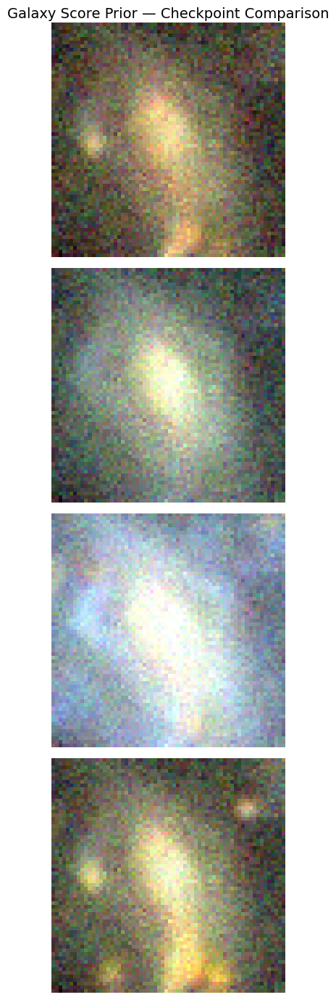


CHECKPOINT COMPARISON COMPLETE
Summary: /content/drive/MyDrive/Galaxy_Score_Prior/results/checkpoint_comparison_2000_2700_3000_5000/comparison_summary.json
Figure: /content/drive/MyDrive/Galaxy_Score_Prior/results/checkpoint_comparison_2000_2700_3000_5000/checkpoint_comparison.png
Results directory: /content/drive/MyDrive/Galaxy_Score_Prior/results/checkpoint_comparison_2000_2700_3000_5000


In [ ]:

# ============================================================
# GALAXY SCORE PRIOR — CHECKPOINT COMPARISON
# Checkpoints: 2000, 2700, 3000, 5000
# Uses EMA weights; no retraining or checkpoint modification.
# ============================================================

import os
import sys
import pickle
import json
import time
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from pathlib import Path
from flax import jax_utils

# -------------------- PATHS --------------------
ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
REPO = ROOT / "score_prior_repo"
CKPT_DIR = ROOT / "checkpoints"
OUT = ROOT / "results" / "checkpoint_comparison_2000_2700_3000_5000"
OUT.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(REPO))
os.chdir(REPO)

# -------------------- IMPORTS --------------------
from configs.galaxy_rgb64 import get_config
from score_flow.models import utils as mutils
from score_flow.models import ddpm, ncsnpp, ncsnv2
from score_flow import utils as sde_utils
from score_flow import sampling

# -------------------- CONFIG / MODEL --------------------
config = get_config()
config.training.continuous = True

rng = jax.random.PRNGKey(config.seed)
rng, init_rng = jax.random.split(rng)

# init_model returns the Flax model architecture.
model, _, _ = mutils.init_model(init_rng, config)
sde, _ = sde_utils.get_sde(config)

inverse_scaler = lambda x: x

devices = jax.local_devices()
num_devices = len(devices)

# One image per device. Current CPU runtime has one device.
per_device_shape = (1, 64, 64, 3)

checkpoint_files = {
    2000: CKPT_DIR / "checkpoint_clean_step_002000.pkl",
    2700: CKPT_DIR / "continuation_clean_from_2000" / "continuation_step_002700.pkl",
    3000: CKPT_DIR / "continuation_clean_from_2000" / "continuation_step_003000.pkl",
    5000: CKPT_DIR / "continuation_3000_to_5000" / "continuation_step_005000.pkl",
}

print("JAX devices:", devices)
print("Device count:", num_devices)
print("Output directory:", OUT)

all_samples = {}
summaries = []

# -------------------- SAMPLE CHECKPOINTS --------------------
for step, ckpt_path in checkpoint_files.items():
    print(f"\nSampling checkpoint {step} ...")

    if not ckpt_path.exists():
        raise FileNotFoundError(f"Checkpoint not found: {ckpt_path}")

    with open(ckpt_path, "rb") as f:
        state = pickle.load(f)

    if not hasattr(state, "params_ema") or not hasattr(state, "model_state"):
        raise AttributeError(
            f"Checkpoint {step} is missing params_ema or model_state."
        )

    # Replicate the complete checkpoint state across the pmap device axis.
    replicated_state = jax_utils.replicate(state, devices=devices)

    # IMPORTANT: pass the Flax model architecture here, NOT score_fn.
    # The sampler constructs the score function from each supplied state.
    sample_fn = sampling.get_sampling_fn(
        config,
        sde,
        model,
        per_device_shape,
        inverse_scaler,
        eps=0.02,
    )

    # Same seed for each checkpoint.
    sample_key = jax.random.PRNGKey(20261017)
    device_keys = jax.random.split(sample_key, num_devices)

    start_time = time.time()

    samples, nfe = sample_fn(device_keys, replicated_state)
    samples = np.asarray(jax.device_get(samples), dtype=np.float32)

    # Expected pmap shape: (num_devices, 1, 64, 64, 3).
    samples = samples.reshape(num_devices, 64, 64, 3)

    sample_path = OUT / f"samples_step_{step:06d}.npy"
    np.save(sample_path, samples)
    all_samples[step] = samples

    summary = {
        "checkpoint_step": int(step),
        "checkpoint_path": str(ckpt_path),
        "samples_shape": list(samples.shape),
        "sample_mean": float(samples.mean()),
        "sample_std": float(samples.std()),
        "sample_min": float(samples.min()),
        "sample_max": float(samples.max()),
        "function_evaluations": int(np.asarray(jax.device_get(nfe)).reshape(-1)[0]),
        "runtime_seconds": round(time.time() - start_time, 2),
        "samples_file": str(sample_path),
    }
    summaries.append(summary)
    print(json.dumps(summary, indent=2))

# -------------------- SAVE SUMMARY --------------------
summary_path = OUT / "comparison_summary.json"
with open(summary_path, "w") as f:
    json.dump(summaries, f, indent=2)

# -------------------- VISUAL COMPARISON --------------------
fig, axes = plt.subplots(
    len(checkpoint_files),
    num_devices,
    figsize=(4 * num_devices, 3.5 * len(checkpoint_files)),
    squeeze=False,
)

for row, step in enumerate(checkpoint_files):
    for col in range(num_devices):
        image = np.clip(all_samples[step][col], 0.0, 1.0)
        axes[row, col].imshow(image)
        axes[row, col].axis("off")
        if col == 0:
            axes[row, col].set_ylabel(f"Step {step}", fontsize=12)

fig.suptitle("Galaxy Score Prior — Checkpoint Comparison", fontsize=14)
fig.tight_layout()

figure_path = OUT / "checkpoint_comparison.png"
fig.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()

print("\nCHECKPOINT COMPARISON COMPLETE")
print("Summary:", summary_path)
print("Figure:", figure_path)
print("Results directory:", OUT)

In [ ]:

# ============================================================
# GALAXY SCORE PRIOR — READ-ONLY VALIDATION AUDIT
# ============================================================

import os
import sys
import inspect
import numpy as np
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
REPO = ROOT / "score_prior_repo"
DATA = ROOT / "dataset"
RESULTS = ROOT / "results"

sys.path.insert(0, str(REPO))
os.chdir(REPO)

print("=" * 65)
print("1. VALIDATION DATA")
print("=" * 65)

for filename in ["train_rgb64.npy", "val_rgb64.npy"]:
    path = DATA / filename
    if not path.exists():
        print(f"MISSING: {path}")
        continue

    arr = np.load(path, mmap_mode="r")
    print(f"\n{filename}")
    print("  Shape:", arr.shape)
    print("  Dtype:", arr.dtype)
    print("  Global min/max:", float(arr.min()), float(arr.max()))

    # Inspect a subset without loading the entire array into RAM.
    subset = np.asarray(arr[:min(100, len(arr))], dtype=np.float32)
    print("  First 100 images — mean/std:",
          float(subset.mean()), float(subset.std()))
    print("  Channel means:", np.round(subset.mean(axis=(0, 1, 2)), 5))
    print("  Channel stds: ", np.round(subset.std(axis=(0, 1, 2)), 5))

print("\n" + "=" * 65)
print("2. EXISTING RECONSTRUCTION / VALIDATION ARTIFACTS")
print("=" * 65)

keywords = ("recon", "validation", "metric", "psnr", "ssim",
            "mae", "rmse", "inverse", "richardson", "summary")

found = 0
for folder in [RESULTS, ROOT / "logs"]:
    if not folder.exists():
        continue
    for path in sorted(folder.rglob("*")):
        if path.is_file() and any(k in path.name.lower() for k in keywords):
            print(path)
            found += 1
            if found >= 100:
                print("Listing capped at 100 files.")
                break
    if found >= 100:
        break

if found == 0:
    print("No matching artifacts found in results/ or logs/.")

print("\n" + "=" * 65)
print("3. REPOSITORY LOSS IMPLEMENTATION")
print("=" * 65)

loss_path = REPO / "score_flow" / "losses.py"
if loss_path.exists():
    lines = loss_path.read_text().splitlines()
    print("File:", loss_path)
    print("Total lines:", len(lines))

    # Print relevant function definitions and surrounding code.
    matches = [
        i for i, line in enumerate(lines)
        if line.lstrip().startswith("def ")
        or "scaler" in line.lower()
        or "continuous" in line.lower()
        or "reduce_mean" in line
    ]

    shown = set()
    for i in matches:
        start, end = max(0, i - 2), min(len(lines), i + 5)
        if any(j in shown for j in range(start, end)):
            continue
        print(f"\n--- lines {start + 1}-{end} ---")
        for j in range(start, end):
            print(f"{j + 1:4}: {lines[j]}")
            shown.add(j)
else:
    print("losses.py not found at the expected path.")

print("\n" + "=" * 65)
print("AUDIT COMPLETE — NO FILES MODIFIED")
print("=" * 65)

1. VALIDATION DATA

train_rgb64.npy
  Shape: (2369, 64, 64, 3)
  Dtype: uint8
  Global min/max: 0.0 255.0
  First 100 images — mean/std: 134.21913146972656 61.690879821777344
  Channel means: [133.8525  138.07214 130.76845]
  Channel stds:  [62.86234 63.20766 58.66952]

val_rgb64.npy
  Shape: (420, 64, 64, 3)
  Dtype: uint8
  Global min/max: 3.0 255.0
  First 100 images — mean/std: 139.88587951660156 62.463008880615234
  Channel means: [140.07271 143.92496 135.71613]
  Channel stds:  [63.94079 63.93948 59.0881 ]

2. EXISTING RECONSTRUCTION / VALIDATION ARTIFACTS
/content/drive/MyDrive/Galaxy_Score_Prior/results/audit_paired_noise_summary.csv
/content/drive/MyDrive/Galaxy_Score_Prior/results/audit_paired_reconstruction_summary.csv
/content/drive/MyDrive/Galaxy_Score_Prior/results/checkpoint_comparison_2000_2700_3000_5000/comparison_summary.json
/content/drive/MyDrive/Galaxy_Score_Prior/results/galaxy_prior_sampling_summary_step_002000.json
/content/drive/MyDrive/Galaxy_Score_Prior/resul

In [ ]:

# ============================================================
# STEP 2: REVIEW EXISTING VALIDATION AND RECONSTRUCTION RESULTS
# Read-only. No model inference or training.
# ============================================================

import json
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
RESULTS = ROOT / "results"
REPO = ROOT / "score_prior_repo"

files_to_inspect = [
    RESULTS / "validation_comparison_2000_2700_3000_5000"
            / "fixed_validation_losses_corrected.csv",
    RESULTS / "robust_validation_available_batches"
            / "validation_summary.csv",
    RESULTS / "reconstruction_results.csv",
    RESULTS / "reconstruction_recovery.csv",
    RESULTS / "audit_paired_reconstruction_summary.csv",
    RESULTS / "audit_paired_noise_summary.csv",
    RESULTS / "score_loss_train_vs_validation.json",
    RESULTS / "posterior_score_reconstruction_step_002000.json",
]

for path in files_to_inspect:
    print("\n" + "=" * 75)
    print(path.name)
    print("=" * 75)

    if not path.exists():
        print("NOT FOUND")
        continue

    try:
        if path.suffix.lower() == ".csv":
            df = pd.read_csv(path)
            print("Shape:", df.shape)
            print("Columns:", list(df.columns))
            print(df.head(12).to_string(index=False))
        elif path.suffix.lower() == ".json":
            with open(path) as f:
                data = json.load(f)
            print(json.dumps(data, indent=2)[:10000])
    except Exception as e:
        print("Could not read:", repr(e))

print("\n" + "=" * 75)
print("DATA NORMALIZATION CONFIGURATION")
print("=" * 75)

for path in [
    REPO / "configs" / "galaxy_rgb64.py",
    REPO / "score_flow" / "datasets.py",
    REPO / "score_flow" / "losses.py",
]:
    if not path.exists():
        print("Not found:", path)
        continue

    lines = path.read_text().splitlines()
    print(f"\nFILE: {path}")

    keywords = (
        "centered", "uniform_dequantization", "normalize",
        "inverse_scaler", "image =", "batch['image']",
        "likelihood_weighting", "marginal_prob"
    )

    matches = [
        i for i, line in enumerate(lines)
        if any(k in line.lower() for k in keywords)
    ]

    printed = set()
    for i in matches:
        start, end = max(0, i - 2), min(len(lines), i + 3)
        if any(j in printed for j in range(start, end)):
            continue
        print(f"\nLines {start + 1}-{end}:")
        for j in range(start, end):
            print(f"{j + 1:4}: {lines[j]}")
            printed.add(j)

print("\nAUDIT COMPLETE")


fixed_validation_losses_corrected.csv
Shape: (4, 7)
Columns: ['checkpoint_step', 'validation_batches', 'validation_loss_mean', 'validation_loss_std_between_batches', 'validation_loss_median', 'validation_loss_min', 'validation_loss_max']
 checkpoint_step  validation_batches  validation_loss_mean  validation_loss_std_between_batches  validation_loss_median  validation_loss_min  validation_loss_max
            2000                   8             63.936898                            35.794448               49.459080            24.391479           139.163422
            2700                   8             55.798266                            32.582385               44.410482            19.846062           128.194931
            3000                   8             59.064519                            32.701291               47.374508            22.331617           130.132919
            5000                   8             53.487378                            35.325742               41.

In [ ]:

# ============================================================
# STEP 3 — INSPECT NORMALIZATION AND RECONSTRUCTION PIPELINE
# Read-only: no training, inference, or file modification.
# ============================================================

import ast
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
REPO = ROOT / "score_prior_repo"

targets = [
    REPO / "score_flow" / "datasets.py",
    REPO / "score_flow" / "sampling.py",
]

# Search project Python files for relevant reconstruction code.
search_roots = [
    ROOT / "score_prior_repo",
    ROOT,
]

terms = [
    "richardson",
    "observation",
    "forward_operator",
    "blur",
    "degradation",
    "get_data_scaler",
    "get_data_inverse_scaler",
    "centered",
    "params_ema",
    "posterior",
]

print("=" * 70)
print("A. EXACT DATA SCALER IMPLEMENTATION")
print("=" * 70)

datasets_file = REPO / "score_flow" / "datasets.py"
lines = datasets_file.read_text().splitlines()

for start, end in [(30, 52), (390, 425)]:
    print(f"\n--- {datasets_file.name}, lines {start + 1}-{end} ---")
    for i in range(start, min(end, len(lines))):
        print(f"{i + 1:4}: {lines[i]}")

print("\n" + "=" * 70)
print("B. EXISTING RECONSTRUCTION CODE FILES")
print("=" * 70)

found = []
seen = set()

for root in search_roots:
    if not root.exists():
        continue
    for path in root.rglob("*.py"):
        if path in seen:
            continue
        seen.add(path)
        try:
            text = path.read_text(errors="ignore")
        except Exception:
            continue

        lower = text.lower()
        matches = [term for term in terms if term in lower]

        if (
            "richardson" in lower
            or "posterior" in lower
            or ("observation" in lower and "degrad" in lower)
        ):
            found.append((path, matches, text.splitlines()))

for path, matches, lines in found[:15]:
    print(f"\nFILE: {path}")
    print("Matched terms:", ", ".join(matches))

    relevant = [
        i for i, line in enumerate(lines)
        if any(term in line.lower() for term in terms)
    ]

    shown = set()
    count = 0
    for i in relevant:
        start, end = max(0, i - 2), min(len(lines), i + 4)
        if any(j in shown for j in range(start, end)):
            continue
        print(f"\nLines {start + 1}-{end}:")
        for j in range(start, end):
            print(f"{j + 1:4}: {lines[j]}")
            shown.add(j)
        count += 1
        if count >= 5:
            print("... excerpts capped for this file")
            break

print("\n" + "=" * 70)
print("Inspection complete. No files were changed.")
print("=" * 70)

A. EXACT DATA SCALER IMPLEMENTATION

--- datasets.py, lines 31-52 ---
  31: ]
  32: 
  33: 
  34: def get_data_scaler(config):
  35:   """Data normalizer. Assume data are always in [0, 1]."""
  36:   if config.data.centered:
  37:     # Rescale to [-1, 1]
  38:     return lambda x: x * 2. - 1.
  39:   else:
  40:     return lambda x: x
  41: 
  42: 
  43: def get_data_inverse_scaler(config):
  44:   """Inverse data normalizer."""
  45:   if config.data.centered:
  46:     # Rescale [-1, 1] to [0, 1]
  47:     return lambda x: (x + 1.) / 2.
  48:   else:
  49:     return lambda x: x
  50: 
  51: 
  52: def crop_resize(image, resolution):

--- datasets.py, lines 391-425 ---
 391:         config.data.image_size,
 392:         config.data.image_size,
 393:         config.data.num_channels):
 394: 
 395:       raise ValueError(
 396:           f'Unexpected validation shape: {val_images.shape}.'
 397:       )
 398: 
 399:     def galaxy_preprocess(image, training=True):
 400:       image = t

In [ ]:


from pathlib import Path

root = Path("/content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo")

targets = [
    root / "inference_utils.py",
    root / "train_dpi.py",
    root / "configs" / "galaxy_rgb64.py",
]

keywords = (
    "def get_score_fn",
    "def get_likelihood",
    "def get_sampling_fn",
    "def reconstruct",
    "likelihood.likelihood",
    "Deblurring",
    "Denoising",
    "inpainting",
    "noise_scale",
    "observation",
    "forward_models",
    "probability_flow",
    "solve",
    "sample",
    "measurement",
)

for path in targets:
    if not path.exists():
        print(f"\nNOT FOUND: {path}")
        continue

    lines = path.read_text(errors="replace").splitlines()
    print("\n" + "=" * 90)
    print(f"FILE: {path.name} | {len(lines)} lines")
    print("=" * 90)

    if path.name == "galaxy_rgb64.py":
        for i, line in enumerate(lines, 1):
            print(f"{i:4}: {line}")
        continue

    matched = set()
    for i, line in enumerate(lines):
        if any(term.lower() in line.lower() for term in keywords):
            matched.update(range(max(0, i - 5), min(len(lines), i + 12)))

    if not matched:
        print("No matching sections found.")
        continue

    previous = -2
    for i in sorted(matched):
        if i > previous + 1:
            print("    ...")
        print(f"{i+1:4}: {lines[i]}")
        previous = i


FILE: inference_utils.py | 404 lines
    ...
  32: from score_flow import datasets
  33: from score_flow import utils
  34: from tensorflow.io import gfile
  35: 
  36: from ehtim_utils import estimate_flux_multiplier
  37: import forward_models
  38: import mri
  39: import probability_flow
  40: from posterior_sampling import model_utils as dpi_mutils
  41: 
  42: 
  43: def get_score_fn(config,
  44:                  score_model_config):
  45:   """Return score function for a given model checkpoint."""
  46:   score_model_config.data = config.data
  47:   
  48:   if gfile.isdir(config.prob_flow.score_model_dir):
  49:     # Try to find the latest checkpoint.
  50:     ckpt_path = checkpoints.latest_checkpoint(config.prob_flow.score_model_dir)
  51:   else:
  52:     ckpt_path = config.prob_flow.score_model_dir
  53: 
  54:   if ckpt_path is None or not gfile.exists(ckpt_path):
    ...
  84:       train=False,
  85:       continuous=True)
  86:   return score_fn
  87: 
  88: 
  89:

In [ ]:


from pathlib import Path

root = Path("/content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo")

files_to_check = [
    root / "forward_models.py",
    root / "configs" / "score_config.py",
    root / "posterior_sampling" / "losses.py",
]

terms = (
    "class Denoising",
    "class Deblurring",
    "class MRI",
    "def get_measurement",
    "def invert_measurement",
    "def get_data_loss_fn",
    "def get_interferometry_data_loss_fn",
    "def __call__",
    "def grad",
    "likelihood",
    "noise_scale",
    "n_dft",
)

for path in files_to_check:
    print("\n" + "=" * 85)
    print(f"FILE: {path}")
    print("=" * 85)

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    lines = path.read_text(errors="replace").splitlines()
    hits = set()

    for i, line in enumerate(lines):
        if any(term.lower() in line.lower() for term in terms):
            hits.update(range(max(0, i - 3), min(len(lines), i + 9)))

    if not hits:
        print("No matching sections found.")
        continue

    prev = -2
    for i in sorted(hits):
        if i > prev + 1:
            print("    ...")
        print(f"{i+1:4}: {lines[i]}")
        prev = i


FILE: /content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo/forward_models.py
    ...
  13: # See the License for the specific language governing permissions and
  14: # limitations under the License.
  15: 
  16: """A library of forward models with associated log-likelihood functions."""
  17: 
  18: import abc
  19: from typing import Optional, Tuple
  20: 
  21: import ehtim as eh
  22: import ehtim.const_def as ehc
  23: import jax
  24: import jax.numpy as jnp
    ...
  29: from ehtim_utils import cphase_diag_info, logcamp_diag_info, M87_systematic_noise
  30: 
  31: 
  32: class IndependentGaussianLikelihood(abc.ABC):
  33:   """Likelihood module for inverse problems w/ independent Gaussian noise.
  34:   An inverse problem with independent Gaussian noise is one whose
  35:   forward model is given by:
  36:     y = f(x) + noise, noise ~ N(0, diag(sigmas))
  37:   Abstract methods should take mini-batched inputs.
  38:   """
  39: 
  40:   @property
  41:   @abc.abstractmet

In [ ]:


from pathlib import Path

root = Path("/content/drive/MyDrive/Galaxy_Score_Prior")

print("=" * 80)
print("1. EXISTING RECONSTRUCTION RESULT FILES")
print("=" * 80)

results = root / "results"
if results.exists():
    for p in sorted(results.rglob("*")):
        if p.is_file() and (
            p.suffix.lower() in {".npy", ".npz", ".csv", ".json"}
            or "reconstruct" in p.name.lower()
            or "degrad" in p.name.lower()
        ):
            try:
                size_mb = p.stat().st_size / (1024 ** 2)
            except OSError:
                size_mb = 0
            print(f"{size_mb:8.2f} MB  {p.relative_to(root)}")
else:
    print("Results directory not found.")

print("\n" + "=" * 80)
print("2. SEARCH FOR THE ACTUAL DEGRADATION IMPLEMENTATION")
print("=" * 80)

repo = root / "score_prior_repo"
terms = (
    "richardson_lucy",
    "gaussian_filter",
    "convolve",
    "psf",
    "motion_blur",
    "add_noise",
    "degradation",
    "degraded",
)

count = 0
for p in repo.rglob("*.py"):
    if any(part.startswith(".") for part in p.parts):
        continue
    try:
        lines = p.read_text(errors="replace").splitlines()
    except OSError:
        continue

    hits = [
        i for i, line in enumerate(lines)
        if any(term in line.lower() for term in terms)
    ]
    if hits:
        print(f"\n--- {p.relative_to(repo)} ---")
        shown = set()
        for i in hits[:12]:
            for j in range(max(0, i - 2), min(len(lines), i + 4)):
                if j not in shown:
                    print(f"{j+1:4}: {lines[j]}")
                    shown.add(j)
            print("    ...")
        count += 1

print(f"\nPython files with relevant matches: {count}")
print("\nInspection only: no files were modified.")

1. EXISTING RECONSTRUCTION RESULT FILES
    0.00 MB  results/audit_paired_noise_summary.csv
    0.00 MB  results/audit_paired_reconstruction_summary.csv
    0.00 MB  results/checkpoint_comparison_2000_2700_3000_5000/comparison_summary.json
    0.00 MB  results/checkpoint_comparison_2000_2700_3000_5000/sample_statistics.csv
    0.05 MB  results/checkpoint_comparison_2000_2700_3000_5000/samples_step_002000.npy
    0.05 MB  results/checkpoint_comparison_2000_2700_3000_5000/samples_step_002700.npy
    0.05 MB  results/checkpoint_comparison_2000_2700_3000_5000/samples_step_003000.npy
    0.05 MB  results/checkpoint_comparison_2000_2700_3000_5000/samples_step_005000.npy
    0.75 MB  results/checkpoint_comparison_2000_2700_3000_5000/samples_step_2000_display.npy
    0.75 MB  results/checkpoint_comparison_2000_2700_3000_5000/samples_step_2000_raw.npy
    0.75 MB  results/checkpoint_comparison_2000_2700_3000_5000/samples_step_2700_display.npy
    0.75 MB  results/checkpoint_comparison_2000_2700

In [ ]:


from pathlib import Path

root = Path("/content/drive/MyDrive/Galaxy_Score_Prior")

print("=" * 80)
print("1. EXISTING RECONSTRUCTION RESULT FILES")
print("=" * 80)

results = root / "results"
if results.exists():
    for p in sorted(results.rglob("*")):
        if p.is_file() and (
            p.suffix.lower() in {".npy", ".npz", ".csv", ".json"}
            or "reconstruct" in p.name.lower()
            or "degrad" in p.name.lower()
        ):
            try:
                size_mb = p.stat().st_size / (1024 ** 2)
            except OSError:
                size_mb = 0
            print(f"{size_mb:8.2f} MB  {p.relative_to(root)}")
else:
    print("Results directory not found.")

print("\n" + "=" * 80)
print("2. SEARCH FOR THE ACTUAL DEGRADATION IMPLEMENTATION")
print("=" * 80)

repo = root / "score_prior_repo"
terms = (
    "richardson_lucy",
    "gaussian_filter",
    "convolve",
    "psf",
    "motion_blur",
    "add_noise",
    "degradation",
    "degraded",
)

count = 0
for p in repo.rglob("*.py"):
    if any(part.startswith(".") for part in p.parts):
        continue
    try:
        lines = p.read_text(errors="replace").splitlines()
    except OSError:
        continue

    hits = [
        i for i, line in enumerate(lines)
        if any(term in line.lower() for term in terms)
    ]
    if hits:
        print(f"\n--- {p.relative_to(repo)} ---")
        shown = set()
        for i in hits[:12]:
            for j in range(max(0, i - 2), min(len(lines), i + 4)):
                if j not in shown:
                    print(f"{j+1:4}: {lines[j]}")
                    shown.add(j)
            print("    ...")
        count += 1

print(f"\nPython files with relevant matches: {count}")
print("\nInspection only: no files were modified.")

1. EXISTING RECONSTRUCTION RESULT FILES
    0.00 MB  results/audit_paired_noise_summary.csv
    0.00 MB  results/audit_paired_reconstruction_summary.csv
    0.00 MB  results/checkpoint_comparison_2000_2700_3000_5000/comparison_summary.json
    0.00 MB  results/checkpoint_comparison_2000_2700_3000_5000/sample_statistics.csv
    0.05 MB  results/checkpoint_comparison_2000_2700_3000_5000/samples_step_002000.npy
    0.05 MB  results/checkpoint_comparison_2000_2700_3000_5000/samples_step_002700.npy
    0.05 MB  results/checkpoint_comparison_2000_2700_3000_5000/samples_step_003000.npy
    0.05 MB  results/checkpoint_comparison_2000_2700_3000_5000/samples_step_005000.npy
    0.75 MB  results/checkpoint_comparison_2000_2700_3000_5000/samples_step_2000_display.npy
    0.75 MB  results/checkpoint_comparison_2000_2700_3000_5000/samples_step_2000_raw.npy
    0.75 MB  results/checkpoint_comparison_2000_2700_3000_5000/samples_step_2700_display.npy
    0.75 MB  results/checkpoint_comparison_2000_2700

In [ ]:


from pathlib import Path
import json
import pandas as pd
import numpy as np

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
R = ROOT / "results"

print("=" * 90)
print("GALAXY SCORE-PRIOR PROJECT: QUANTITATIVE RESULTS REVIEW")
print("=" * 90)

# 1. Key JSON summaries already produced by the project
json_files = [
    "posterior_score_reconstruction_step_002000.json",
    "runtime_recovery_audit.json",
    "master_diagnostics_M_to_U_step_002000.json",
    "official_sampler_validation_step_002000.json",
    "reverse_trajectory_step_002000.json",
    "reverse_trajectory_low_noise_step_002000.json",
    "step_10AC_implementation_audit.json",
    "step_10AD_paired_raw_ema.json",
]

for name in json_files:
    p = R / name
    if not p.exists():
        continue

    print(f"\n--- {name} ---")
    try:
        obj = json.loads(p.read_text())
        txt = json.dumps(obj, indent=2, default=str)
        print(txt[:6500])
        if len(txt) > 6500:
            print("... [remaining content omitted]")
    except Exception as e:
        print("Could not read JSON:", repr(e))

# 2. Existing reconstruction and robustness measurements
csv_files = [
    "reconstruction_results.csv",
    "reconstruction_recovery.csv",
    "audit_paired_reconstruction_summary.csv",
    "audit_paired_noise_summary.csv",
    "multi_level_degradation.csv",
    "noise_robustness.csv",
    "psf_mismatch.csv",
    "rl_iteration_sensitivity.csv",
    "pixel_metrics_moderate.csv",
    "reconstruction_bootstrap_confidence_intervals.csv",
    "validation_comparison_2000_2700_3000_5000/fixed_validation_losses_corrected.csv",
]

metric_words = ("psnr", "ssim", "rmse", "mae", "cosine", "l2", "recovery",
                "improvement", "runtime", "time", "loss", "score", "error",
                "bar", "mse")

for name in csv_files:
    p = R / name
    if not p.exists():
        continue

    print(f"\n{'-' * 90}\nCSV: {name}\n{'-' * 90}")

    try:
        df = pd.read_csv(p)
    except Exception as e:
        print("Could not read CSV:", repr(e))
        continue

    print("Shape:", df.shape)
    print("Columns:", list(df.columns))

    # Display compact numeric summaries for relevant evaluation metrics.
    numeric = df.select_dtypes(include=[np.number])
    metric_cols = [
        c for c in numeric.columns
        if any(w in c.lower() for w in metric_words)
        and c.lower() not in ("idx", "index", "step", "n", "count")
    ]

    if metric_cols:
        print("\nMetric summary (mean / median / standard deviation):")
        print(
            pd.DataFrame({
                "mean": numeric[metric_cols].mean(),
                "median": numeric[metric_cols].median(),
                "std": numeric[metric_cols].std(),
            }).round(5).to_string()
        )

    # Compare groups such as degraded images, RL reconstructions,
    # degradation levels, or checkpoint steps where those labels exist.
    cat_cols = [
        c for c in df.columns
        if (
            df[c].dtype == "object"
            or isinstance(df[c].dtype, pd.CategoricalDtype)
        )
        and 1 < df[c].nunique(dropna=True) <= 8
    ]

    for group_col in cat_cols[:2]:
        available_metrics = [c for c in metric_cols if c in df.columns]
        if not available_metrics:
            continue
        print(f"\nGrouped means by {group_col}:")
        print(
            df.groupby(group_col, dropna=False)[available_metrics]
              .mean(numeric_only=True)
              .round(5)
              .to_string()
        )

    print("\nFirst 3 rows:")
    print(df.head(3).to_string(index=False, max_cols=15))

# 3. Check whether there are clearly named saved learned-prior reconstructions.
print("\n" + "=" * 90)
print("SAVED RECONSTRUCTION ARTIFACT CHECK")
print("=" * 90)

for p in sorted(R.rglob("*")):
    if not p.is_file():
        continue
    low = p.name.lower()
    if any(term in low for term in (
        "posterior", "reconstruction", "recon", "recovery",
        "prior_score", "score_prior"
    )):
        if p.suffix.lower() in (".npy", ".npz", ".png", ".jpg", ".json", ".csv"):
            print(f"{p.stat().st_size / 1024:9.1f} KB  {p.relative_to(ROOT)}")

print("\nRead-only review complete. No model training or files modified.")

GALAXY SCORE-PRIOR PROJECT: QUANTITATIVE RESULTS REVIEW

--- posterior_score_reconstruction_step_002000.json ---
{
  "checkpoint_step": 2000,
  "num_eval": 64,
  "results": [
    {
      "t": 0.2,
      "alpha": 0.8967304229736328,
      "sigma": 0.44257715344429016,
      "PSNR": 27.290990188435135,
      "SSIM": 0.7693300247192383,
      "prediction_stats": {
        "mean": 0.5453884601593018,
        "pixel_std": 0.22740645706653595,
        "flux_per_image": 6701.73388671875,
        "bright_fraction": 0.5570869445800781,
        "raw_min": 0.0,
        "raw_max": 1.0
      }
    },
    {
      "t": 0.1,
      "alpha": 0.9706881046295166,
      "sigma": 0.24034227430820465,
      "PSNR": 29.901113869170892,
      "SSIM": 0.8407968282699585,
      "prediction_stats": {
        "mean": 0.5466362833976746,
        "pixel_std": 0.22925055027008057,
        "flux_per_image": 6717.0673828125,
        "bright_fraction": 0.5580266316731771,
        "raw_min": 0.0,
        "raw_max": 1.0
 

In [ ]:


from pathlib import Path

root = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
terms = (
    "posterior_score_reconstruction_step_002000",
    "prediction_stats",
    "likelihood_score",
    "get_score_fn",
)

print("Searching existing experiment code...")
found = 0

for p in root.rglob("*"):
    if not p.is_file() or p.suffix.lower() not in {".py", ".ipynb"}:
        continue
    if "checkpoints" in p.parts or ".git" in p.parts:
        continue

    try:
        content = p.read_text(errors="replace")
    except Exception:
        continue

    matched = [term for term in terms if term in content]
    if not matched:
        continue

    found += 1
    print(f"\nFILE: {p.relative_to(root)}")
    print("Matched:", ", ".join(matched))

    lines = content.splitlines()
    shown = set()
    for i, line in enumerate(lines):
        if any(term in line for term in matched):
            for j in range(max(0, i - 5), min(len(lines), i + 12)):
                if j not in shown:
                    print(f"{j+1:4}: {lines[j][:240]}")
                    shown.add(j)
            print("...")

print(f"\nMatching files: {found}")

Searching existing experiment code...

FILE: score_prior_repo/train_dpi.py
Matched: get_score_fn
 264:     prob_flow = inference_utils.get_prob_flow(config, score_model_config)
 265:   else:
 266:     prob_flow = None
 267:   # Get `score_fn`.
 268:   if config.optim.prior in ['dsm', 'sm']:
 269:     score_fn = inference_utils.get_score_fn(config, score_model_config)
 270:   else:
 271:     score_fn = None
 272:   
 273:   if config.likelihood.likelihood == 'Interferometry':
 274:     vis_weight = len(likelihood.vis_expanded) * config.optim.vis_weight_multiplier
 275:     visamp_weight = len(likelihood.visamp) * config.optim.visamp_weight_multiplier
 276:     cphase_weight = len(likelihood.cphase) * config.optim.cphase_weight_multiplier
 277:     logcamp_weight = len(likelihood.logcamp) * config.optim.logcamp_weight_multiplier
 278:     data_loss_fn = losses.get_interferometry_data_loss_fn(
 279:       likelihood, vis_weight, visamp_weight, cphase_weight, logcamp_weight)
 280:     prio

In [ ]:

from pathlib import Path
import json

root = Path("/content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo")
nb_path = root / "demos" / "denoising.ipynb"

nb = json.loads(nb_path.read_text())
cells = nb.get("cells", [])

print("=== Existing denoising demo: relevant code ===")
keywords = (
    "likelihood", "denois", "observation", "sigma", "noise",
    "score_state", "score_fn", "checkpoint", "sampler",
    "get_sampling_fn", "get_pc_sampler", "get_ode_sampler",
    "data_loader", "image"
)

shown = 0
for i, cell in enumerate(cells):
    if cell.get("cell_type") != "code":
        continue
    source = "".join(cell.get("source", []))
    if any(k.lower() in source.lower() for k in keywords):
        print(f"\n--- Cell {i} ---")
        print(source[:7000])
        shown += 1
        if shown >= 8:
            break

print(f"\nDisplayed {shown} relevant code cells.")
print("\nCheckpoint for the next experiment:")
print("/content/drive/MyDrive/Galaxy_Score_Prior/checkpoints/continuation_3000_to_5000/continuation_step_005000.pkl")

=== Existing denoising demo: relevant code ===

--- Cell 0 ---
import functools
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '0'
import sys
sys.path.append('..')
import time
import warnings
warnings.filterwarnings(action='ignore')
warnings.simplefilter(action='ignore')

import diffrax
import flax
from flax.training import checkpoints
import IPython.display as ipd
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax

from configs import dpi_config as dpi_config_provider
from configs import score_config as score_config_provider

import forward_models
import probability_bound
import probability_flow
from posterior_sampling import model_utils as dpi_mutils
from score_flow import utils
from score_flow.models import utils as score_mutils
from score_flow.models import ddpm, ncsnpp, ncsnv2

--- Cell 2 ---
"""
We define settings for this experiment through a `ConfigDict` for DPI.
A `ConfigDict` for the score model is used to help load the score-ba

In [ ]:

from pathlib import Path
import pickle, json, time
import numpy as np
import jax
import jax.numpy as jnp
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
REPO = ROOT / "score_prior_repo"
CKPT = ROOT / "checkpoints/continuation_3000_to_5000/continuation_step_005000.pkl"
OUT = ROOT / "results/step5000_heldout_denoising"
OUT.mkdir(parents=True, exist_ok=True)

import sys
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from configs import galaxy_rgb64 as config_provider
from score_flow import utils
from score_flow.models import utils as mutils
from score_flow.models import ddpm, ncsnpp, ncsnv2

print("JAX devices:", jax.devices())
print("Loading validation data and step-5000 checkpoint...")

val = np.load(ROOT / "score_prior_repo/dataset/val_rgb64.npy")
val = val.astype(np.float32) / 255.0
assert val.ndim == 4 and val.shape[1:] == (64, 64, 3), f"Unexpected shape: {val.shape}"
assert CKPT.exists(), f"Checkpoint not found: {CKPT}"

with open(CKPT, "rb") as f:
    state = pickle.load(f)

config = config_provider.get_config()
sde, eps = utils.get_sde(config)
model, _, _ = mutils.init_model(jax.random.PRNGKey(0), config)

score_fn = mutils.get_score_fn(
    sde, model, state.params_ema, state.model_state,
    train=False, continuous=True
)

# Fixed held-out subset and reproducible Gaussian perturbations.
N = min(64, len(val))
x = jnp.asarray(val[:N])
t_value = 0.05
t = jnp.full((N,), t_value, dtype=jnp.float32)
mean, std = sde.marginal_prob(jnp.ones_like(x), t)
mean = mean[:, :1, :1, :] if mean.ndim == 4 else mean
std = std[:, :1, :1, :] if std.ndim == 4 else std

# Match the forward perturbation to the VPSDE marginal:
# x_t = mean(t) * x_0 + std(t) * noise.
key = jax.random.PRNGKey(20261017)
noise = jax.random.normal(key, x.shape)
y = mean * x + std * noise

start = time.time()
score = score_fn(y, t)
# Tweedie denoising estimate for the VPSDE marginal.
xhat = (y + jnp.square(std) * score) / mean
xhat = jnp.clip(xhat, 0.0, 1.0)

x_np = np.asarray(x)
y_np = np.asarray(jnp.clip(y / mean, 0.0, 1.0))
hat_np = np.asarray(xhat)
print(f"Inference completed in {time.time()-start:.1f}s")
print(f"Checkpoint step: {int(state.step)} | t={t_value} | images={N}")
print(f"VPSDE marginal mean={float(jnp.mean(mean)):.5f}, std={float(jnp.mean(std)):.5f}")

rows = []
for i in range(N):
    psnr_noisy = peak_signal_noise_ratio(x_np[i], y_np[i], data_range=1.0)
    psnr_hat = peak_signal_noise_ratio(x_np[i], hat_np[i], data_range=1.0)
    ssim_noisy = structural_similarity(x_np[i], y_np[i], channel_axis=-1, data_range=1.0)
    ssim_hat = structural_similarity(x_np[i], hat_np[i], channel_axis=-1, data_range=1.0)
    rows.append({
        "index": i,
        "PSNR_noisy": psnr_noisy,
        "PSNR_score_prior": psnr_hat,
        "PSNR_gain": psnr_hat - psnr_noisy,
        "SSIM_noisy": ssim_noisy,
        "SSIM_score_prior": ssim_hat,
        "SSIM_gain": ssim_hat - ssim_noisy,
    })

import pandas as pd
df = pd.DataFrame(rows)
df.to_csv(OUT / "paired_metrics.csv", index=False)
np.save(OUT / "clean_images.npy", x_np)
np.save(OUT / "noisy_images.npy", y_np)
np.save(OUT / "score_prior_denoised.npy", hat_np)

summary = {
    "checkpoint_step": int(state.step),
    "n_images": N,
    "t": t_value,
    "mean_marginal_std": float(jnp.mean(std)),
    "mean_psnr_noisy": float(df["PSNR_noisy"].mean()),
    "mean_psnr_denoised": float(df["PSNR_score_prior"].mean()),
    "mean_psnr_gain": float(df["PSNR_gain"].mean()),
    "mean_ssim_noisy": float(df["SSIM_noisy"].mean()),
    "mean_ssim_denoised": float(df["SSIM_score_prior"].mean()),
    "mean_ssim_gain": float(df["SSIM_gain"].mean()),
    "fraction_psnr_improved": float((df["PSNR_gain"] > 0).mean()),
    "fraction_ssim_improved": float((df["SSIM_gain"] > 0).mean()),
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2))

print("\n=== HELD-OUT DENOISING RESULTS ===")
for k, v in summary.items():
    print(f"{k}: {v}")
print("\nSaved metrics and image arrays to:", OUT)

JAX devices: [CpuDevice(id=0)]
Loading validation data and step-5000 checkpoint...


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo/dataset/val_rgb64.npy'

In [ ]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
target = "val_rgb64.npy"

print("Searching for validation dataset...")
matches = list(ROOT.rglob(target))

if matches:
    for p in matches:
        print(f"FOUND: {p}")
        print(f"Size: {p.stat().st_size / (1024**2):.2f} MB")
else:
    print(f"{target} was not found under {ROOT}")
    print("\nExisting .npy files whose names contain 'val' or 'rgb64':")
    for p in ROOT.rglob("*.npy"):
        if "val" in p.name.lower() or "rgb64" in p.name.lower():
            print(p)

Searching for validation dataset...
FOUND: /content/drive/MyDrive/Galaxy_Score_Prior/dataset/val_rgb64.npy
Size: 4.92 MB


In [ ]:

from pathlib import Path
import pickle, json, time, sys
import numpy as np
import pandas as pd
import jax
import jax.numpy as jnp
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
REPO = ROOT / "score_prior_repo"
DATA = ROOT / "dataset/val_rgb64.npy"
CKPT = ROOT / "checkpoints/continuation_3000_to_5000/continuation_step_005000.pkl"
OUT = ROOT / "results/step5000_heldout_denoising"
OUT.mkdir(parents=True, exist_ok=True)

assert DATA.exists(), f"Validation dataset not found: {DATA}"
assert CKPT.exists(), f"Checkpoint not found: {CKPT}"
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from configs import galaxy_rgb64 as config_provider
from score_flow import utils
from score_flow.models import utils as mutils
from score_flow.models import ddpm, ncsnpp, ncsnv2

print("JAX devices:", jax.devices())
print("Loading validation data and checkpoint...")

val = np.load(DATA).astype(np.float32) / 255.0
assert val.ndim == 4 and val.shape[1:] == (64, 64, 3), f"Unexpected shape: {val.shape}"

with open(CKPT, "rb") as f:
    state = pickle.load(f)

config = config_provider.get_config()
sde, eps = utils.get_sde(config)
model, _, _ = mutils.init_model(jax.random.PRNGKey(0), config)
score_fn = mutils.get_score_fn(
    sde, model, state.params_ema, state.model_state,
    train=False, continuous=True
)

N = min(64, len(val))
x = jnp.asarray(val[:N])
t = jnp.full((N,), 0.05, dtype=jnp.float32)
mean, std = sde.marginal_prob(jnp.ones_like(x), t)
mean = mean[:, :1, :1, :]
std = std[:, :1, :1, :]

noise = jax.random.normal(jax.random.PRNGKey(20261017), x.shape)
y = mean * x + std * noise

print("Running score inference...")
start = time.time()
score = score_fn(y, t)
xhat = jnp.clip((y + jnp.square(std) * score) / mean, 0.0, 1.0)
jax.block_until_ready(xhat)
print(f"Inference time: {time.time()-start:.1f}s")

x_np = np.asarray(x)
noisy_np = np.asarray(jnp.clip(y / mean, 0.0, 1.0))
hat_np = np.asarray(xhat)

rows = []
for i in range(N):
    pn = peak_signal_noise_ratio(x_np[i], noisy_np[i], data_range=1.0)
    ph = peak_signal_noise_ratio(x_np[i], hat_np[i], data_range=1.0)
    sn = structural_similarity(x_np[i], noisy_np[i], channel_axis=-1, data_range=1.0)
    sh = structural_similarity(x_np[i], hat_np[i], channel_axis=-1, data_range=1.0)
    rows.append({
        "index": i,
        "PSNR_noisy": pn, "PSNR_score_prior": ph, "PSNR_gain": ph-pn,
        "SSIM_noisy": sn, "SSIM_score_prior": sh, "SSIM_gain": sh-sn
    })

df = pd.DataFrame(rows)
df.to_csv(OUT / "paired_metrics.csv", index=False)
np.save(OUT / "clean_images.npy", x_np)
np.save(OUT / "noisy_images.npy", noisy_np)
np.save(OUT / "score_prior_denoised.npy", hat_np)

summary = {
    "checkpoint_step": int(state.step),
    "n_images": N,
    "t": 0.05,
    "mean_psnr_noisy": float(df.PSNR_noisy.mean()),
    "mean_psnr_denoised": float(df.PSNR_score_prior.mean()),
    "mean_psnr_gain": float(df.PSNR_gain.mean()),
    "mean_ssim_noisy": float(df.SSIM_noisy.mean()),
    "mean_ssim_denoised": float(df.SSIM_score_prior.mean()),
    "mean_ssim_gain": float(df.SSIM_gain.mean()),
    "fraction_psnr_improved": float((df.PSNR_gain > 0).mean()),
    "fraction_ssim_improved": float((df.SSIM_gain > 0).mean())
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2))

print("\n=== HELD-OUT DENOISING RESULTS ===")
for k, v in summary.items():
    print(f"{k}: {v}")
print("\nSaved outputs:", OUT)

JAX devices: [CpuDevice(id=0)]
Loading validation data and checkpoint...


IndexError: Too many indices: 1-dimensional array indexed with 4 regular indices.

In [ ]:

import time
import json
import numpy as np
import pandas as pd
import jax
import jax.numpy as jnp
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

# Recompute the marginal coefficients with the actual held-out batch.
N = int(x.shape[0])
t = jnp.full((N,), 0.05, dtype=jnp.float32)
mean, std = sde.marginal_prob(jnp.ones_like(x), t)

# VPSDE marginal coefficients: mean is image-shaped; std may be (N,).
mean = jnp.asarray(mean)
std = jnp.asarray(std)
if mean.ndim == 1:
    mean = mean.reshape((N, 1, 1, 1))
elif mean.ndim == 4:
    mean = mean[:, :1, :1, :1]
if std.ndim == 1:
    std = std.reshape((N, 1, 1, 1))
elif std.ndim == 4:
    std = std[:, :1, :1, :1]

print("mean shape:", mean.shape, "| std shape:", std.shape)

noise = jax.random.normal(jax.random.PRNGKey(20261017), x.shape)
y = mean * x + std * noise

start = time.time()
score = score_fn(y, t)
xhat = jnp.clip((y + std**2 * score) / mean, 0.0, 1.0)
jax.block_until_ready(xhat)
print(f"Inference time: {time.time() - start:.1f}s")

x_np = np.asarray(x)
noisy_np = np.asarray(jnp.clip(y / mean, 0.0, 1.0))
hat_np = np.asarray(xhat)

rows = []
for i in range(N):
    pn = peak_signal_noise_ratio(x_np[i], noisy_np[i], data_range=1.0)
    ph = peak_signal_noise_ratio(x_np[i], hat_np[i], data_range=1.0)
    sn = structural_similarity(x_np[i], noisy_np[i], channel_axis=-1, data_range=1.0)
    sh = structural_similarity(x_np[i], hat_np[i], channel_axis=-1, data_range=1.0)
    rows.append({
        "index": i,
        "PSNR_noisy": pn, "PSNR_score_prior": ph, "PSNR_gain": ph - pn,
        "SSIM_noisy": sn, "SSIM_score_prior": sh, "SSIM_gain": sh - sn
    })

df = pd.DataFrame(rows)
df.to_csv(OUT / "paired_metrics.csv", index=False)
np.save(OUT / "clean_images.npy", x_np)
np.save(OUT / "noisy_images.npy", noisy_np)
np.save(OUT / "score_prior_denoised.npy", hat_np)

summary = {
    "n_images": N,
    "checkpoint_step": int(state.step),
    "t": 0.05,
    "mean_psnr_noisy": float(df.PSNR_noisy.mean()),
    "mean_psnr_denoised": float(df.PSNR_score_prior.mean()),
    "mean_psnr_gain": float(df.PSNR_gain.mean()),
    "mean_ssim_noisy": float(df.SSIM_noisy.mean()),
    "mean_ssim_denoised": float(df.SSIM_score_prior.mean()),
    "mean_ssim_gain": float(df.SSIM_gain.mean()),
    "fraction_psnr_improved": float((df.PSNR_gain > 0).mean()),
    "fraction_ssim_improved": float((df.SSIM_gain > 0).mean())
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2))

print("\n=== HELD-OUT DENOISING RESULTS ===")
for k, v in summary.items():
    print(f"{k}: {v}")
print("Saved:", OUT)

mean shape: (64, 1, 1, 1) | std shape: (64, 1, 1, 1)
Inference time: 52.0s

=== HELD-OUT DENOISING RESULTS ===
n_images: 64
checkpoint_step: 5000
t: 0.05
mean_psnr_noisy: 17.99113481996989
mean_psnr_denoised: 31.725273243282896
mean_psnr_gain: 13.734138423313007
mean_ssim_noisy: 0.27453887462615967
mean_ssim_denoised: 0.887384295463562
mean_ssim_gain: 0.6128454208374023
fraction_psnr_improved: 1.0
fraction_ssim_improved: 1.0
Saved: /content/drive/MyDrive/Galaxy_Score_Prior/results/step5000_heldout_denoising


In [ ]:

import time
import numpy as np
import pandas as pd
import jax
import jax.numpy as jnp
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

results = []
x_eval = x  # Existing 64 held-out images
N = int(x_eval.shape[0])

for t_value in (0.02, 0.05, 0.10):
    print(f"\nEvaluating t={t_value:.2f} ...", flush=True)
    t_batch = jnp.full((N,), t_value, dtype=jnp.float32)

    mean, std = sde.marginal_prob(jnp.ones_like(x_eval), t_batch)
    mean = jnp.asarray(mean)
    std = jnp.asarray(std)

    if mean.ndim == 1:
        mean = mean.reshape((N, 1, 1, 1))
    elif mean.ndim == 4:
        mean = mean[:, :1, :1, :1]

    if std.ndim == 1:
        std = std.reshape((N, 1, 1, 1))
    elif std.ndim == 4:
        std = std[:, :1, :1, :1]

    key = jax.random.PRNGKey(int(20261017 + round(t_value * 1000)))
    noise = jax.random.normal(key, x_eval.shape)
    y_t = mean * x_eval + std * noise

    start = time.time()
    score = score_fn(y_t, t_batch)
    estimate = jnp.clip((y_t + std**2 * score) / mean, 0.0, 1.0)
    jax.block_until_ready(estimate)

    clean_np = np.asarray(x_eval)
    noisy_np = np.asarray(jnp.clip(y_t / mean, 0.0, 1.0))
    estimate_np = np.asarray(estimate)

    psnr_noisy, psnr_est, ssim_noisy, ssim_est = [], [], [], []
    for i in range(N):
        psnr_noisy.append(peak_signal_noise_ratio(
            clean_np[i], noisy_np[i], data_range=1.0))
        psnr_est.append(peak_signal_noise_ratio(
            clean_np[i], estimate_np[i], data_range=1.0))
        ssim_noisy.append(structural_similarity(
            clean_np[i], noisy_np[i], channel_axis=-1, data_range=1.0))
        ssim_est.append(structural_similarity(
            clean_np[i], estimate_np[i], channel_axis=-1, data_range=1.0))

    results.append({
        "t": t_value,
        "noise_PSNR_mean": np.mean(psnr_noisy),
        "prior_PSNR_mean": np.mean(psnr_est),
        "PSNR_gain_dB": np.mean(psnr_est) - np.mean(psnr_noisy),
        "noise_SSIM_mean": np.mean(ssim_noisy),
        "prior_SSIM_mean": np.mean(ssim_est),
        "SSIM_gain": np.mean(ssim_est) - np.mean(ssim_noisy),
        "PSNR_improved_fraction": np.mean(np.array(psnr_est) > np.array(psnr_noisy)),
        "SSIM_improved_fraction": np.mean(np.array(ssim_est) > np.array(ssim_noisy)),
        "inference_seconds": time.time() - start,
    })

robustness_df = pd.DataFrame(results)
robustness_path = OUT / "noise_level_robustness.csv"
robustness_df.to_csv(robustness_path, index=False)

print("\n=== NOISE-LEVEL ROBUSTNESS ===")
print(robustness_df.round(4).to_string(index=False))
print("\nSaved:", robustness_path)


Evaluating t=0.02 ...

Evaluating t=0.05 ...

Evaluating t=0.10 ...

=== NOISE-LEVEL ROBUSTNESS ===
   t  noise_PSNR_mean  prior_PSNR_mean  PSNR_gain_dB  noise_SSIM_mean  prior_SSIM_mean  SSIM_gain  PSNR_improved_fraction  SSIM_improved_fraction  inference_seconds
0.02          24.1776          34.0681        9.8904           0.5787           0.9277     0.3490                     1.0                     1.0            42.5543
0.05          17.9825          31.6801       13.6976           0.2745           0.8871     0.6126                     1.0                     1.0            42.8493
0.10          13.2139          29.9831       16.7692           0.1137           0.8551     0.7414                     1.0                     1.0            39.9060

Saved: /content/drive/MyDrive/Galaxy_Score_Prior/results/step5000_heldout_denoising/noise_level_robustness.csv


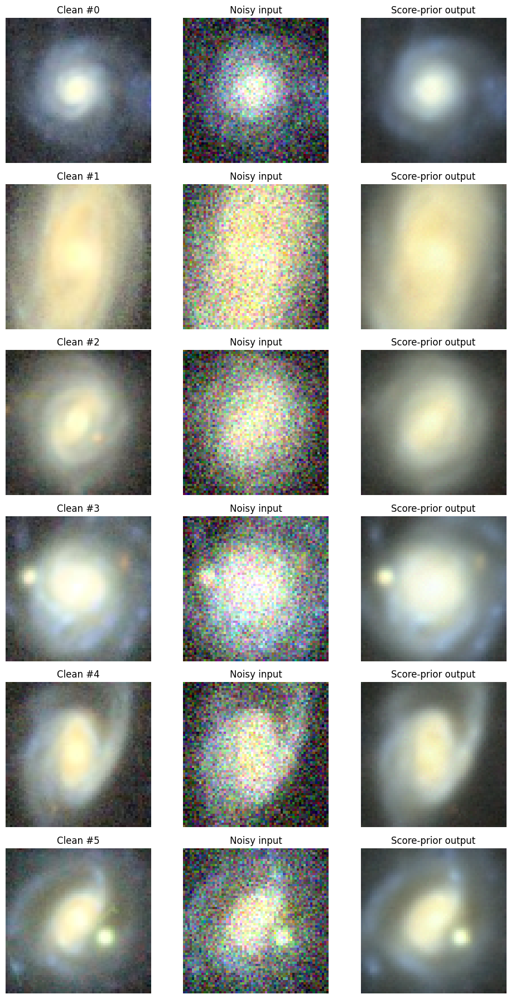

Saved: /content/drive/MyDrive/Galaxy_Score_Prior/results/step5000_heldout_denoising/visual_comparison.png


In [ ]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

OUT = Path("/content/drive/MyDrive/Galaxy_Score_Prior/results/step5000_heldout_denoising")

clean = np.load(OUT / "clean_images.npy")
noisy = np.load(OUT / "noisy_images.npy")
recon = np.load(OUT / "score_prior_denoised.npy")

# Show the same six validation images across all three conditions.
indices = [0, 1, 2, 3, 4, 5]
fig, axes = plt.subplots(len(indices), 3, figsize=(10, 3 * len(indices)))

for row, idx in enumerate(indices):
    axes[row, 0].imshow(np.clip(clean[idx], 0, 1))
    axes[row, 0].set_title(f"Clean #{idx}")
    axes[row, 1].imshow(np.clip(noisy[idx], 0, 1))
    axes[row, 1].set_title("Noisy input")
    axes[row, 2].imshow(np.clip(recon[idx], 0, 1))
    axes[row, 2].set_title("Score-prior output")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
path = OUT / "visual_comparison.png"
plt.savefig(path, dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", path)

In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
print("=== 1. Existing RL evaluation ===")

for rel in [
    "results/reconstruction_results.csv",
    "results/reconstruction_recovery.csv",
    "results/psf_mismatch.csv",
]:
    p = ROOT / rel
    if p.exists():
        df = pd.read_csv(p)
        print(f"\n{rel}: shape={df.shape}")
        print("Columns:", df.columns.tolist())
        print(df.head(3).to_string(index=False))

print("\n=== 2. Candidate data and PSF files ===")
for folder in [ROOT / "dataset", ROOT / "results"]:
    if not folder.exists():
        continue
    for p in sorted(folder.rglob("*")):
        if not p.is_file():
            continue
        name = p.name.lower()
        if any(k in name for k in (
            "psf", "clean", "ground_truth", "groundtruth",
            "degraded", "reconstruction", "manga", "galaxy"
        )) and p.suffix.lower() in {
            ".npy", ".npz", ".fits", ".fit", ".csv", ".py", ".ipynb"
        }:
            print(f"{p.relative_to(ROOT)}  [{p.stat().st_size / 1e6:.2f} MB]")

print("\n=== 3. Existing RL / PSF implementation ===")
repo = ROOT / "score_prior_repo"
terms = ("richardson_lucy", "richardson-lucy", "richardson lucy",
         "psf_mismatch", "bar_RMSE", "reconstruction_recovery")
found = 0

for p in repo.rglob("*"):
    if not p.is_file() or p.suffix.lower() not in {".py", ".ipynb"}:
        continue
    if ".git" in p.parts:
        continue
    try:
        content = p.read_text(errors="replace")
    except Exception:
        continue
    hits = [term for term in terms if term.lower() in content.lower()]
    if hits:
        print(f"{p.relative_to(ROOT)} — {', '.join(hits)}")
        found += 1

print(f"Matching implementation files: {found}")

=== 1. Existing RL evaluation ===

results/reconstruction_results.csv: shape=(300, 10)
Columns: ['idx', 'manga_id', 'degradation', 'image_type', 'PSNR', 'SSIM', 'bar_RMSE', 'bar_SSIM', 'AION_cosine', 'AION_L2']
 idx manga_id degradation        image_type      PSNR     SSIM  bar_RMSE  bar_SSIM  AION_cosine   AION_L2
   0 1-310020    moderate          degraded 28.994527 0.947980  0.127831  0.970161     0.942861 383.74686
   0 1-310020    moderate RL_reconstruction 43.032097 0.958252  0.009720  0.997762     0.980706 221.27357
   1 1-477040    moderate          degraded 31.163443 0.961692  0.291520  0.955567     0.975281 216.79700

results/reconstruction_recovery.csv: shape=(150, 22)
Columns: ['manga_id', 'degradation', 'AION_L2_RL_reconstruction', 'AION_L2_degraded', 'AION_cosine_RL_reconstruction', 'AION_cosine_degraded', 'PSNR_RL_reconstruction', 'PSNR_degraded', 'SSIM_RL_reconstruction', 'SSIM_degraded', 'bar_RMSE_RL_reconstruction', 'bar_RMSE_degraded', 'bar_SSIM_RL_reconstruction', '

In [ ]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
SEARCH_ROOTS = [
    ROOT,
    Path("/content/drive/MyDrive"),
]

extensions = {".py", ".ipynb", ".npy", ".npz", ".fits", ".fit", ".fts", ".pt", ".pth"}
keywords = (
    "reconstruction_results",
    "reconstruction_recovery",
    "richardson_lucy",
    "richardson-lucy",
    "bar_RMSE",
    "true_sigma",
    "manga_id",
    "degradation",
)

seen = set()
matches = []

for base in SEARCH_ROOTS:
    if not base.exists():
        continue
    for p in base.rglob("*"):
        if not p.is_file() or p in seen:
            continue
        seen.add(p)
        if p.suffix.lower() not in extensions:
            continue

        # Ignore large unrelated datasets and cached environments.
        parts = {part.lower() for part in p.parts}
        if any(part in parts for part in (
            ".git", ".cache", "site-packages", "node_modules"
        )):
            continue

        name = p.name.lower()
        matched_terms = [k for k in keywords if k in name]

        if p.suffix.lower() in {".py", ".ipynb"}:
            try:
                content = p.read_text(errors="replace")
                matched_terms += [
                    k for k in keywords
                    if k.lower() in content.lower() and k not in matched_terms
                ]
            except Exception:
                content = ""

        if matched_terms:
            matches.append((p, matched_terms))

print(f"Found {len(matches)} candidate files:")
for p, terms in matches[:100]:
    print(f"{p} | matches: {', '.join(terms)}")

print("\nPotential image/PSF arrays inside the project:")
for folder in (ROOT / "dataset", ROOT / "results"):
    if folder.exists():
        for p in folder.rglob("*"):
            if p.is_file() and p.suffix.lower() in {
                ".npy", ".npz", ".fits", ".fit", ".fts"
            }:
                print(f"{p} [{p.stat().st_size / 1e6:.2f} MB]")

Found 0 candidate files:

Potential image/PSF arrays inside the project:
/content/drive/MyDrive/Galaxy_Score_Prior/dataset/train_rgb64.npy [29.11 MB]
/content/drive/MyDrive/Galaxy_Score_Prior/dataset/val_rgb64.npy [5.16 MB]
/content/drive/MyDrive/Galaxy_Score_Prior/results/galaxy_prior_samples_step_002000.npy [0.79 MB]
/content/drive/MyDrive/Galaxy_Score_Prior/results/checkpoint_evolution_samples.npy [0.79 MB]
/content/drive/MyDrive/Galaxy_Score_Prior/results/raw_vs_ema_samples_step_002000.npy [0.79 MB]
/content/drive/MyDrive/Galaxy_Score_Prior/results/step_count_sensitivity_samples_step_002000.npy [0.98 MB]
/content/drive/MyDrive/Galaxy_Score_Prior/results/epsilon_sensitivity_samples_step_002000.npy [0.98 MB]
/content/drive/MyDrive/Galaxy_Score_Prior/results/reverse_trajectory_final_step_002000.npy [0.20 MB]
/content/drive/MyDrive/Galaxy_Score_Prior/results/terminal_ablation_A_standard_normal_step_002000.npy [0.20 MB]
/content/drive/MyDrive/Galaxy_Score_Prior/results/terminal_ablation

In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
from skimage.metrics import structural_similarity, peak_signal_noise_ratio
from scipy.ndimage import gaussian_filter

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
OUT = ROOT / "results/step5000_heldout_denoising"

clean = np.load(OUT / "clean_images.npy").astype(np.float32)
recon = np.load(OUT / "score_prior_denoised.npy").astype(np.float32)

assert clean.shape == recon.shape and clean.ndim == 4

rows = []
for i, (gt, pred) in enumerate(zip(clean, recon)):
    gt = np.clip(gt, 0, 1)
    pred = np.clip(pred, 0, 1)

    # Compare large-scale structure after modest Gaussian smoothing.
    gt_smooth = gaussian_filter(gt, sigma=(1.0, 1.0, 0))
    pred_smooth = gaussian_filter(pred, sigma=(1.0, 1.0, 0))

    # Residual detail relative to the smoothed image.
    gt_detail = gt - gt_smooth
    pred_detail = pred - pred_smooth
    gt_detail_rms = float(np.sqrt(np.mean(gt_detail ** 2)))
    pred_detail_rms = float(np.sqrt(np.mean(pred_detail ** 2)))

    rows.append({
        "index": i,
        "PSNR_dB": peak_signal_noise_ratio(gt, pred, data_range=1.0),
        "SSIM": structural_similarity(
            gt, pred, channel_axis=-1, data_range=1.0
        ),
        "relative_image_RMSE": float(
            np.sqrt(np.mean((gt - pred) ** 2)) /
            (np.sqrt(np.mean(gt ** 2)) + 1e-12)
        ),
        "smoothed_structure_RMSE": float(
            np.sqrt(np.mean((gt_smooth - pred_smooth) ** 2))
        ),
        "clean_detail_RMS": gt_detail_rms,
        "reconstruction_detail_RMS": pred_detail_rms,
        "detail_RMS_ratio": pred_detail_rms / (gt_detail_rms + 1e-12),
    })

df = pd.DataFrame(rows)
path = OUT / "morphology_preservation_metrics.csv"
df.to_csv(path, index=False)

print("=== MORPHOLOGY PRESERVATION: 64 HELD-OUT GALAXIES ===")
print(df.drop(columns="index").mean().round(4).to_string())
print("\nFraction with SSIM >= 0.85:",
      round(float((df["SSIM"] >= 0.85).mean()), 3))
print("Fraction with detail_RMS_ratio >= 0.5:",
      round(float((df["detail_RMS_ratio"] >= 0.5).mean()), 3))
print("Saved:", path)

=== MORPHOLOGY PRESERVATION: 64 HELD-OUT GALAXIES ===
PSNR_dB                      31.7253
SSIM                          0.8874
relative_image_RMSE           0.0468
smoothed_structure_RMSE       0.0177
clean_detail_RMS              0.0159
reconstruction_detail_RMS     0.0073
detail_RMS_ratio              0.5192

Fraction with SSIM >= 0.85: 0.812
Fraction with detail_RMS_ratio >= 0.5: 0.422
Saved: /content/drive/MyDrive/Galaxy_Score_Prior/results/step5000_heldout_denoising/morphology_preservation_metrics.csv


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
DATA = ROOT / "dataset/val_rgb64.npy"
OUT = ROOT / "results/matched_psf_benchmark"
OUT.mkdir(parents=True, exist_ok=True)

# Reproducible held-out benchmark.
raw = np.load(DATA)
assert raw.ndim == 4 and raw.shape[1:] == (64, 64, 3), raw.shape

N = min(64, len(raw))
clean = raw[:N].astype(np.float32) / 255.0

# Synthetic, spatially invariant Gaussian PSF.
psf_sigma = 1.5
rng = np.random.default_rng(20261017)
blurred = np.stack([
    gaussian_filter(im, sigma=(psf_sigma, psf_sigma, 0))
    for im in clean
])

# Add reproducible Gaussian measurement noise.
noise_sigma = 0.01
observed = np.clip(
    blurred + rng.normal(0.0, noise_sigma, size=blurred.shape),
    0.0, 1.0
).astype(np.float32)

np.save(OUT / "clean_targets.npy", clean)
np.save(OUT / "observations.npy", observed)
np.save(OUT / "blurred_noiseless.npy", blurred)

metadata = pd.DataFrame([{
    "n_images": N,
    "image_shape": "64x64x3",
    "psf": "Gaussian",
    "psf_sigma_pixels": psf_sigma,
    "noise_model": "additive Gaussian",
    "noise_sigma": noise_sigma,
    "random_seed": 20261017,
    "source": "held-out val_rgb64.npy"
}])
metadata.to_csv(OUT / "benchmark_metadata.csv", index=False)

print("Matched PSF benchmark prepared.")
print("Images:", N)
print("PSF sigma:", psf_sigma, "pixels")
print("Noise sigma:", noise_sigma)
print("Output:", OUT)
print("Next: reconstruct these exact observations with RL and the score prior.")

Matched PSF benchmark prepared.
Images: 64
PSF sigma: 1.5 pixels
Noise sigma: 0.01
Output: /content/drive/MyDrive/Galaxy_Score_Prior/results/matched_psf_benchmark
Next: reconstruct these exact observations with RL and the score prior.


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
OUT = ROOT / "results/matched_psf_benchmark"
OUT.mkdir(parents=True, exist_ok=True)

clean = np.load(OUT / "clean_targets.npy").astype(np.float32)

# Same Gaussian PSF as the existing benchmark.
psf_sigma = 1.5
blurred = np.stack([
    gaussian_filter(im, sigma=(psf_sigma, psf_sigma, 0))
    for im in clean
]).astype(np.float32)

# Photon-counting model: expected counts proportional to blurred intensity.
# A fixed count scale makes the experiment reproducible.
photon_scale = 1000.0
rng = np.random.default_rng(20261018)
expected_counts = np.clip(blurred, 0, 1) * photon_scale
observed_counts = rng.poisson(expected_counts).astype(np.float32)

# Convert counts back to the normalized intensity scale expected by the prior.
observed_poisson = observed_counts / photon_scale

np.save(OUT / "poisson_observations.npy", observed_poisson.astype(np.float32))
np.save(OUT / "poisson_counts.npy", observed_counts)
np.save(OUT / "poisson_blurred_targets.npy", blurred)

metadata_path = OUT / "benchmark_metadata.csv"
meta = pd.read_csv(metadata_path)
meta["poisson_photon_scale"] = photon_scale
meta["poisson_random_seed"] = 20261018
meta["poisson_noise_model"] = "Poisson photon counts"
meta.to_csv(metadata_path, index=False)

print("Poisson benchmark prepared.")
print("Images:", len(clean))
print("Image shape:", clean.shape[1:])
print("PSF sigma:", psf_sigma, "pixels")
print("Photon scale:", photon_scale)
print("Saved:", OUT / "poisson_observations.npy")
print("\nExisting Gaussian benchmark preserved.")

Poisson benchmark prepared.
Images: 64
Image shape: (64, 64, 3)
PSF sigma: 1.5 pixels
Photon scale: 1000.0
Saved: /content/drive/MyDrive/Galaxy_Score_Prior/results/matched_psf_benchmark/poisson_observations.npy

Existing Gaussian benchmark preserved.


RL reconstructed 16/64 images
RL reconstructed 32/64 images
RL reconstructed 48/64 images
RL reconstructed 64/64 images


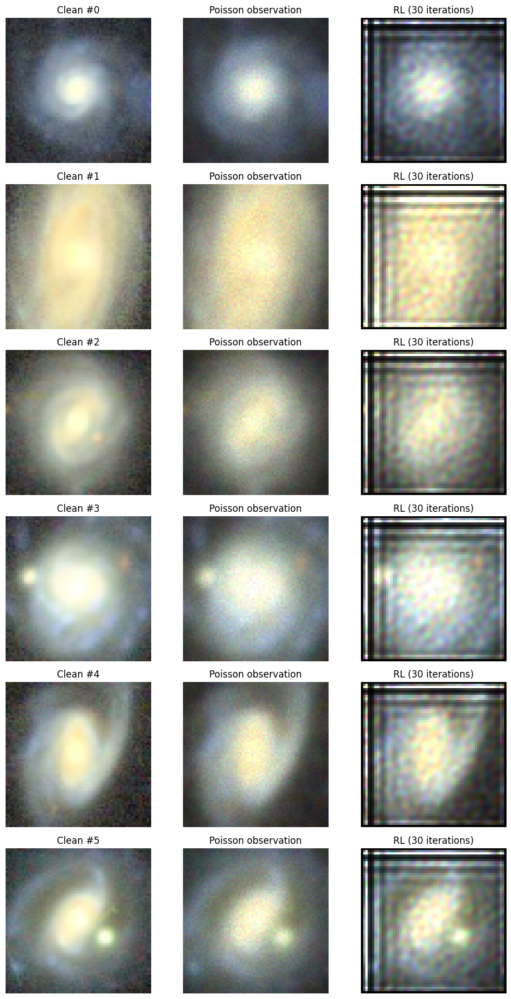


=== RL BASELINE RESULTS ===
n_images: 64
psf_sigma_pixels: 1.5
rl_iterations: 30
mean_rl_psnr_dB: 15.468336277188108
mean_rl_ssim: 0.5193033814430237
elapsed_seconds: 19.699028253555298
score_prior_checkpoint_exists: True

Saved under: /content/drive/MyDrive/Galaxy_Score_Prior/results/matched_psf_benchmark


In [ ]:

from pathlib import Path
import time, json, pickle, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from skimage.restoration import richardson_lucy
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
REPO = ROOT / "score_prior_repo"
OUT = ROOT / "results/matched_psf_benchmark"
CKPT = ROOT / "checkpoints/continuation_3000_to_5000/continuation_step_005000.pkl"

clean = np.load(OUT / "clean_targets.npy").astype(np.float32)
observed = np.load(OUT / "poisson_observations.npy").astype(np.float32)

assert clean.shape == observed.shape
assert CKPT.exists(), f"Checkpoint missing: {CKPT}"

# RL assumes a normalized, nonnegative PSF. Use the exact synthetic PSF.
size = 64
coords = np.arange(size, dtype=np.float32) - (size - 1) / 2
xx, yy = np.meshgrid(coords, coords)
sigma = 1.5
psf = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
psf /= psf.sum()

def blur_rgb(im):
    return np.stack([
        gaussian_filter(im[..., c], sigma=sigma, mode="reflect")
        for c in range(im.shape[-1])
    ], axis=-1)

# RL per channel, with a fixed iteration count for reproducibility.
N = len(clean)
rl = np.zeros_like(clean)
rows = []

start = time.time()
for i in range(N):
    for c in range(3):
        rl[i, ..., c] = richardson_lucy(
            observed[i, ..., c],
            psf,
            num_iter=30,
            clip=False
        )
    if (i + 1) % 16 == 0:
        print(f"RL reconstructed {i+1}/{N} images", flush=True)

np.save(OUT / "rl_reconstruction.npy", rl)

for i in range(N):
    rows.append({
        "index": i,
        "method": "RL_30_iterations",
        "PSNR_dB": peak_signal_noise_ratio(
            clean[i], np.clip(rl[i], 0, 1), data_range=1.0
        ),
        "SSIM": structural_similarity(
            clean[i], np.clip(rl[i], 0, 1),
            channel_axis=-1, data_range=1.0
        )
    })

rl_df = pd.DataFrame(rows)
rl_df.to_csv(OUT / "rl_paired_metrics.csv", index=False)

# Save representative clean / observed / RL comparison.
fig, axes = plt.subplots(6, 3, figsize=(10, 18))
for r, i in enumerate([0, 1, 2, 3, 4, 5]):
    axes[r, 0].imshow(np.clip(clean[i], 0, 1))
    axes[r, 0].set_title(f"Clean #{i}")
    axes[r, 1].imshow(np.clip(observed[i], 0, 1))
    axes[r, 1].set_title("Poisson observation")
    axes[r, 2].imshow(np.clip(rl[i], 0, 1))
    axes[r, 2].set_title("RL (30 iterations)")
    for ax in axes[r]:
        ax.axis("off")

plt.tight_layout()
plt.savefig(OUT / "rl_visual_comparison.png", dpi=150)
plt.show()

summary = {
    "n_images": N,
    "psf_sigma_pixels": sigma,
    "rl_iterations": 30,
    "mean_rl_psnr_dB": float(rl_df["PSNR_dB"].mean()),
    "mean_rl_ssim": float(rl_df["SSIM"].mean()),
    "elapsed_seconds": time.time() - start,
    "score_prior_checkpoint_exists": CKPT.exists()
}
(OUT / "rl_summary.json").write_text(json.dumps(summary, indent=2))

print("\n=== RL BASELINE RESULTS ===")
for k, v in summary.items():
    print(f"{k}: {v}")
print("\nSaved under:", OUT)

Maximum forward-operator verification error: 5.313172657395171e-08
Completed RL iteration 10/30
Completed RL iteration 20/30
Completed RL iteration 30/30


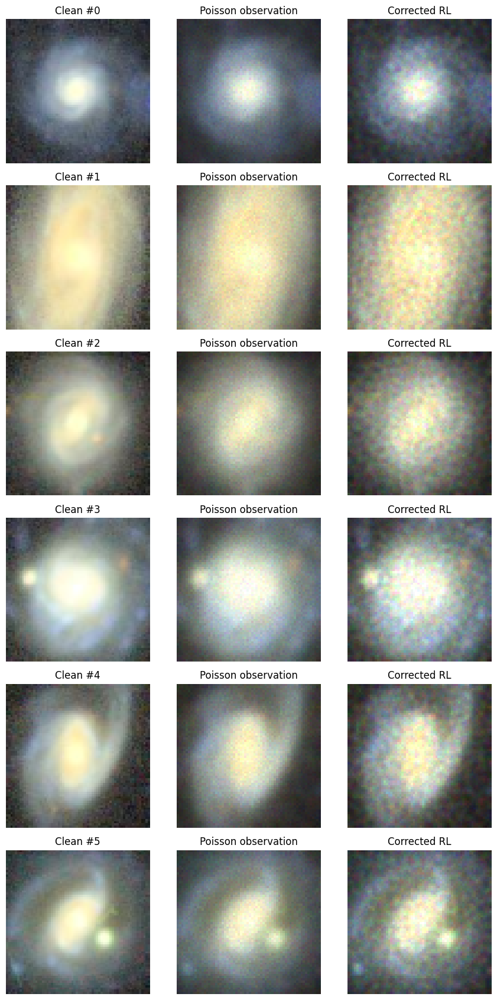


=== CORRECTED RL RESULTS ===
n_images: 64
psf_sigma_pixels: 1.5
iterations: 30
forward_operator_max_verification_error: 5.313172657395171e-08
mean_observation_PSNR_dB: 30.231482582795245
mean_corrected_RL_PSNR_dB: 27.524039581410307
mean_observation_SSIM: 0.8059448126464797
mean_corrected_RL_SSIM: 0.7040065876030241
fraction_PSNR_improved_vs_observation: 0.0
elapsed_seconds: 13.430423021316528
Saved: /content/drive/MyDrive/Galaxy_Score_Prior/results/matched_psf_benchmark


In [ ]:

from pathlib import Path
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
OUT = ROOT / "results/matched_psf_benchmark"

clean = np.load(OUT / "clean_targets.npy").astype(np.float64)
observed = np.load(OUT / "poisson_observations.npy").astype(np.float64)
blurred_reference = np.load(OUT / "blurred_noiseless.npy").astype(np.float64)

N, H, W, C = clean.shape
assert H == W == 64 and C == 3
assert observed.shape == clean.shape

sigma = 1.5
eps = 1e-10

# Construct the exact 1D operator used by gaussian_filter(..., mode="reflect").
# G @ image @ G.T reproduces the separable 2D Gaussian blur.
G = gaussian_filter1d(
    np.eye(H, dtype=np.float64),
    sigma=sigma,
    axis=0,
    mode="reflect",
    truncate=4.0
)

def forward(image):
    result = np.empty_like(image)
    for c in range(C):
        result[..., c] = G @ image[..., c] @ G.T
    return result

def adjoint(image):
    result = np.empty_like(image)
    for c in range(C):
        result[..., c] = G.T @ image[..., c] @ G
    return result

# Critical check: verify operator matches the previously generated data.
rng = np.random.default_rng(20261017)
test_indices = rng.choice(N, size=min(5, N), replace=False)
operator_errors = [
    np.max(np.abs(forward(clean[i]) - blurred_reference[i]))
    for i in test_indices
]
max_operator_error = float(max(operator_errors))
print("Maximum forward-operator verification error:", max_operator_error)

if max_operator_error > 2e-6:
    raise RuntimeError(
        "Operator mismatch: stop before reconstruction. "
        "The forward model does not reproduce the saved blurred targets."
    )

# Generalized Richardson-Lucy update for A x = observed:
# x <- x * A^T(y / A x) / A^T(1).
normalizer = adjoint(np.ones_like(clean))
normalizer = np.maximum(normalizer, eps)

iterations = 30
rl = np.maximum(observed.copy(), 1e-6)
start = time.time()

for it in range(iterations):
    predicted = np.maximum(forward(rl), eps)
    correction = adjoint(observed / predicted)
    rl *= correction / normalizer
    rl = np.maximum(rl, 0.0)

    if (it + 1) % 10 == 0:
        print(f"Completed RL iteration {it+1}/{iterations}", flush=True)

np.save(OUT / "rl_reconstruction_reflect_adjoint.npy", rl.astype(np.float32))

# Evaluate the same 64 images using identical clean targets.
rows = []
for i in range(N):
    obs_i = np.clip(observed[i], 0, 1)
    rl_i = np.clip(rl[i], 0, 1)

    rows.append({
        "index": i,
        "PSNR_observation_dB": peak_signal_noise_ratio(
            clean[i], obs_i, data_range=1.0),
        "PSNR_RL_dB": peak_signal_noise_ratio(
            clean[i], rl_i, data_range=1.0),
        "SSIM_observation": structural_similarity(
            clean[i], obs_i, channel_axis=-1, data_range=1.0),
        "SSIM_RL": structural_similarity(
            clean[i], rl_i, channel_axis=-1, data_range=1.0)
    })

df = pd.DataFrame(rows)
df.to_csv(OUT / "rl_corrected_paired_metrics.csv", index=False)

fig, axes = plt.subplots(6, 3, figsize=(9, 17))
for r, i in enumerate(range(6)):
    for ax, img, title in [
        (axes[r, 0], clean[i], f"Clean #{i}"),
        (axes[r, 1], observed[i], "Poisson observation"),
        (axes[r, 2], rl[i], "Corrected RL")
    ]:
        ax.imshow(np.clip(img, 0, 1))
        ax.set_title(title)
        ax.axis("off")

plt.tight_layout()
plt.savefig(OUT / "rl_corrected_visual_comparison.png", dpi=150)
plt.show()

summary = {
    "n_images": N,
    "psf_sigma_pixels": sigma,
    "iterations": iterations,
    "forward_operator_max_verification_error": max_operator_error,
    "mean_observation_PSNR_dB": float(df["PSNR_observation_dB"].mean()),
    "mean_corrected_RL_PSNR_dB": float(df["PSNR_RL_dB"].mean()),
    "mean_observation_SSIM": float(df["SSIM_observation"].mean()),
    "mean_corrected_RL_SSIM": float(df["SSIM_RL"].mean()),
    "fraction_PSNR_improved_vs_observation": float(
        (df["PSNR_RL_dB"] > df["PSNR_observation_dB"]).mean()),
    "elapsed_seconds": time.time() - start
}
(OUT / "rl_corrected_summary.json").write_text(json.dumps(summary, indent=2))

print("\n=== CORRECTED RL RESULTS ===")
for k, v in summary.items():
    print(f"{k}: {v}")
print("Saved:", OUT)

In [ ]:

from pathlib import Path
import json, time
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter1d
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

ROOT = Path("/content/drive/MyDrive/Galaxy_Score_Prior")
OUT = ROOT / "results/matched_psf_benchmark"

clean = np.load(OUT / "clean_targets.npy").astype(np.float64)
observed = np.load(OUT / "poisson_observations.npy").astype(np.float64)
N, H, W, C = clean.shape

# Reconstruct the same verified forward operator.
sigma = 1.5
G = gaussian_filter1d(
    np.eye(H, dtype=np.float64),
    sigma=sigma, axis=0, mode="reflect", truncate=4.0
)

def A(im):
    return np.stack([G @ im[..., c] @ G.T for c in range(C)], axis=-1)

def AT(im):
    return np.stack([G.T @ im[..., c] @ G for c in range(C)], axis=-1)

eps = 1e-10
normalizer = np.maximum(AT(np.ones_like(clean[0])), eps)
test_iterations = [1, 2, 3, 5, 8, 10, 15, 20, 30]
snapshots = {}
rl = np.maximum(observed.copy(), 1e-8)
start = time.time()

for iteration in range(1, max(test_iterations) + 1):
    for i in range(N):
        prediction = np.maximum(A(rl[i]), eps)
        rl[i] *= AT(observed[i] / prediction) / normalizer
    if iteration in test_iterations:
        snapshots[iteration] = rl.copy()
        print(f"Saved iteration {iteration}", flush=True)

def metrics(reference, estimate):
    psnr, ssim = [], []
    for target, result in zip(reference, estimate):
        result = np.clip(result, 0.0, 1.0)
        psnr.append(peak_signal_noise_ratio(target, result, data_range=1.0))
        ssim.append(structural_similarity(
            target, result, channel_axis=-1, data_range=1.0
        ))
    return float(np.mean(psnr)), float(np.mean(ssim))

# First 16 images choose iteration; the other 48 remain held out.
n_tune = 16
rows = []
for it in test_iterations:
    p_tune, s_tune = metrics(clean[:n_tune], snapshots[it][:n_tune])
    p_test, s_test = metrics(clean[n_tune:], snapshots[it][n_tune:])
    rows.append({
        "iterations": it,
        "tuning_PSNR": p_tune,
        "tuning_SSIM": s_tune,
        "heldout_PSNR": p_test,
        "heldout_SSIM": s_test,
    })

sweep = pd.DataFrame(rows)
sweep.to_csv(OUT / "rl_early_stopping_sweep.csv", index=False)

# Choose solely by tuning-set PSNR.
best_it = int(sweep.loc[sweep["tuning_PSNR"].idxmax(), "iterations"])
selected = snapshots[best_it].astype(np.float32)
np.save(OUT / "rl_selected_early_stopping.npy", selected)

base_p, base_s = metrics(clean[n_tune:], observed[n_tune:])
best_row = sweep[sweep["iterations"] == best_it].iloc[0]

summary = {
    "tuning_images": n_tune,
    "heldout_images": N - n_tune,
    "selected_iterations": best_it,
    "selection_rule": "maximum mean tuning-set PSNR",
    "heldout_observation_PSNR": base_p,
    "heldout_observation_SSIM": base_s,
    "heldout_RL_PSNR": float(best_row["heldout_PSNR"]),
    "heldout_RL_SSIM": float(best_row["heldout_SSIM"]),
    "heldout_PSNR_gain": float(best_row["heldout_PSNR"] - base_p),
    "heldout_SSIM_gain": float(best_row["heldout_SSIM"] - base_s),
    "elapsed_seconds": time.time() - start,
}
(OUT / "rl_early_stopping_summary.json").write_text(json.dumps(summary, indent=2))

print("\n=== RL EARLY-STOPPING RESULTS ===")
print(sweep.round(4).to_string(index=False))
print("\nSelected iteration:", best_it)
print(json.dumps(summary, indent=2))
print("\nSaved results:", OUT)

Saved iteration 1
Saved iteration 2
Saved iteration 3
Saved iteration 5
Saved iteration 8
Saved iteration 10
Saved iteration 15
Saved iteration 20
Saved iteration 30

=== RL EARLY-STOPPING RESULTS ===
 iterations  tuning_PSNR  tuning_SSIM  heldout_PSNR  heldout_SSIM
          1      30.7129       0.8300       30.2390        0.8012
          2      30.6238       0.8271       30.1470        0.7985
          3      30.4986       0.8231       30.0256        0.7947
          5      30.2303       0.8145       29.7699        0.7864
          8      29.8418       0.8016       29.4029        0.7737
         10      29.5997       0.7932       29.1752        0.7655
         15      29.0516       0.7736       28.6605        0.7463
         20      28.5717       0.7556       28.2094        0.7287
         30      27.7607       0.7235       27.4451        0.6975

Selected iteration: 1
{
  "tuning_images": 16,
  "heldout_images": 48,
  "selected_iterations": 1,
  "selection_rule": "maximum mean tunin

In [ ]:


# STEP: Inspect the exact score-prior interfaces before deblurring
import os, sys, pickle, inspect

ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"
REPO = os.path.join(ROOT, "score_prior_repo")
CKPT = os.path.join(
    ROOT, "checkpoints", "continuation_3000_to_5000",
    "continuation_step_005000.pkl"
)

if REPO not in sys.path:
    sys.path.insert(0, REPO)

print("Checkpoint exists:", os.path.isfile(CKPT))
print("Repository exists:", os.path.isdir(REPO))

from score_flow.models import utils as mutils
from score_flow.utils import get_sde

print("\n--- get_score_fn signature ---")
print(inspect.signature(mutils.get_score_fn))
print(inspect.getsource(mutils.get_score_fn)[:5000])

print("\n--- get_sde signature/source ---")
print(inspect.signature(get_sde))
print(inspect.getsource(get_sde)[:3500])

print("\n--- Available sampler-related files ---")
for base, dirs, files in os.walk(REPO):
    dirs[:] = [d for d in dirs if d not in {".git", "__pycache__"}]
    for f in files:
        if f.endswith(".py") and any(
            term in (f + " " + base).lower()
            for term in ["sampling", "inference", "posterior", "forward_model"]
        ):
            print(os.path.relpath(os.path.join(base, f), REPO))

print("\n--- Checkpoint top-level structure ---")
with open(CKPT, "rb") as f:
    state = pickle.load(f)

print("Type:", type(state))
if isinstance(state, dict):
    for k, v in state.items():
        if hasattr(v, "shape"):
            print(f"{k}: shape={v.shape}, dtype={getattr(v, 'dtype', None)}")
        elif isinstance(v, dict):
            print(f"{k}: dict with {len(v)} entries; keys={list(v)[:12]}")
        else:
            print(f"{k}: {type(v)}")
else:
    print("Attributes:", [x for x in dir(state) if not x.startswith("_")][:40])

Checkpoint exists: True
Repository exists: True

--- get_score_fn signature ---
(sde, model, params, states, train=False, continuous=False, return_state=False)
def get_score_fn(sde, model, params, states, train=False, continuous=False, return_state=False):
  """Wraps `score_fn` so that the model output corresponds to a real time-dependent score function.

  Args:
    sde: An `sde_lib.SDE` object that represents the forward SDE.
    model: A `flax.linen.Module` object that represents the architecture of the score-based model.
    params: A dictionary that contains all trainable parameters.
    states: A dictionary that contains all other mutable parameters.
    train: `True` for training and `False` for evaluation.
    continuous: If `True`, the score-based model is expected to directly take continuous time steps.
    return_state: If `True`, return the new mutable states alongside the model output.

  Returns:
    A score function.
  """
  model_fn = get_model_fn(model, params, states,

In [ ]:


# Inspect only the exact configuration and sampler code needed for reconstruction
import os, glob

ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"
REPO = os.path.join(ROOT, "score_prior_repo")

candidates = [
    os.path.join(REPO, "configs", "galaxy_rgb64.py"),
    os.path.join(REPO, "score_flow", "sampling.py"),
    os.path.join(REPO, "inference_utils.py"),
    os.path.join(REPO, "forward_models.py"),
]

for path in candidates:
    print("\n" + "="*90)
    print("FILE:", path, "| exists:", os.path.isfile(path))
    if not os.path.isfile(path):
        continue
    with open(path, "r", encoding="utf-8") as f:
        lines = f.readlines()

    # Print relevant setup/sampling sections, avoiding unrelated file dumps.
    if path.endswith("galaxy_rgb64.py"):
        print("".join(lines[:240]))
    else:
        keywords = (
            "def get_sampling_fn", "def get_predictor", "def get_corrector",
            "def get_pc_sampler", "def get_ode_sampler", "def get_sampler",
            "def load", "def restore", "def create_model", "def get_model",
            "def apply", "def forward", "def adjoint", "def get_score_fn",
            "config =", "get_config", "model_name", "continuous",
            "smallest_time", "probability_flow"
        )
        hits = [i for i, line in enumerate(lines)
                if any(k in line for k in keywords)]
        shown = set()
        for i in hits:
            for j in range(max(0, i-3), min(len(lines), i+18)):
                shown.add(j)
        for j in sorted(shown):
            print(f"{j+1:4d}: {lines[j]}", end="")
        if not shown:
            print("No matching sampler/setup symbols found.")


FILE: /content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo/configs/galaxy_rgb64.py | exists: True

"""64x64 RGB galaxy score-prior configuration."""

from configs.score_config import get_config as base_config


def get_config():

    config = base_config()

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    config.training.sde = "vpsde"
    config.training.likelihood_weighting = False
    config.training.importance_weighting = False
    config.training.continuous = True
    config.training.reduce_mean = False

    config.training.n_iters = 20000
    config.training.batch_size = 32

    config.training.snapshot_freq = 1000
    config.training.log_freq = 100
    config.training.eval_freq = 1000

    config.training.n_jitted_steps = 1


    # --------------------------------------------------------
    # Dataset
    # --------------------------------------------------------

    config.da

In [ ]:


# STEP: Initialize the trained score prior and verify a score evaluation
import os, sys, pickle, time
import numpy as np
import jax
import jax.numpy as jnp
from ml_collections import ConfigDict

ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"
REPO = os.path.join(ROOT, "score_prior_repo")
if REPO not in sys.path:
    sys.path.insert(0, REPO)

from configs.galaxy_rgb64 import get_config
from score_flow.models import utils as mutils
from score_flow.models import ncsnpp
from score_flow.utils import get_sde

CKPT = os.path.join(
    ROOT, "checkpoints", "continuation_3000_to_5000",
    "continuation_step_005000.pkl"
)

with open(CKPT, "rb") as f:
    state = pickle.load(f)

config = get_config()
sde, eps = get_sde(config)

# Instantiate the exact configured architecture.
model = ncsnpp.NCSNpp(config)
score_fn = mutils.get_score_fn(
    sde=sde,
    model=model,
    params=state.params_ema,
    states=state.model_state,
    train=False,
    continuous=True
)

# Load a few held-out observations for a forward-pass test.
BROOT = os.path.join(ROOT, "results", "matched_psf_benchmark")
obs_path = os.path.join(BROOT, "poisson_observations.npy")
assert os.path.isfile(obs_path), f"Missing benchmark file: {obs_path}"

observations = np.load(obs_path).astype(np.float32)
assert observations.ndim == 4 and observations.shape[1:] == (64, 64, 3), observations.shape

# Score-SDE training uses [0,1] data with centered=False.
x_test = jnp.asarray(observations[16:18])
t_test = jnp.full((x_test.shape[0],), 0.10, dtype=jnp.float32)

t0 = time.time()
scores = score_fn(x_test, t_test)
scores.block_until_ready()

print("Checkpoint step:", int(state.step))
print("SDE:", type(sde).__name__, "| N:", sde.N, "| epsilon:", eps)
print("EMA parameter tree loaded:", state.params_ema is not None)
print("Test input shape:", x_test.shape)
print("Score output shape:", scores.shape)
print("Score finite:", bool(jnp.all(jnp.isfinite(scores))))
print("Input range:", float(x_test.min()), float(x_test.max()))
print("Score mean/std:", float(scores.mean()), float(scores.std()))
print("Forward-pass seconds:", round(time.time() - t0, 2))

Checkpoint step: 5000
SDE: VPSDE | N: 1000 | epsilon: 0.001
EMA parameter tree loaded: True
Test input shape: (2, 64, 64, 3)
Score output shape: (2, 64, 64, 3)
Score finite: True
Input range: 0.08799999952316284 1.1100000143051147
Score mean/std: -0.35911959409713745 1.3108794689178467
Forward-pass seconds: 19.84


In [ ]:

import inspect
from score_flow.models import sampling

print("Sampling module:", sampling.__file__)
print("\nAvailable sampling functions:")
for name in dir(sampling):
    obj = getattr(sampling, name)
    if callable(obj) and any(k in name.lower() for k in
                              ("reverse", "predictor", "corrector", "pc_sampler")):
        try:
            print(f"\n--- {name} ---")
            print(inspect.signature(obj))
            source = inspect.getsource(obj)
            print(source[:3500])
        except Exception as e:
            print(name, "source unavailable:", repr(e))

ImportError: cannot import name 'sampling' from 'score_flow.models' (/content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo/score_flow/models/__init__.py)

In [ ]:

import os
import ast

REPO = "/content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo"
MODEL_DIR = os.path.join(REPO, "score_flow")

keywords = (
    "get_pc_sampler",
    "get_ode_sampler",
    "ReverseDiffusionPredictor",
    "EulerMaruyamaPredictor",
    "LangevinCorrector",
    "get_score_fn",
)

print("Searching repository for sampling implementations...\n")

for root, dirs, files in os.walk(MODEL_DIR):
    dirs[:] = [d for d in dirs if d not in ("__pycache__", ".git")]

    for filename in files:
        if not filename.endswith(".py"):
            continue

        path = os.path.join(root, filename)

        try:
            with open(path, "r", encoding="utf-8") as f:
                source = f.read()
            tree = ast.parse(source)
        except Exception:
            continue

        matches = []
        for node in ast.walk(tree):
            if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
                if any(key.lower() in node.name.lower() for key in keywords):
                    matches.append((node.name, node.lineno, node.end_lineno))

        if matches:
            print(f"\nFILE: {path}")
            for name, start, end in matches:
                print(f"\n--- {name} (lines {start}-{end}) ---")
                lines = source.splitlines()
                print("\n".join(lines[start - 1:min(end, start + 65)]))

Searching repository for sampling implementations...


FILE: /content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo/score_flow/sampling.py

--- EulerMaruyamaPredictor (lines 218-228) ---
class EulerMaruyamaPredictor(Predictor):
  def __init__(self, sde, score_fn, probability_flow=False):
    super().__init__(sde, score_fn, probability_flow)

  def update_fn(self, rng, x, t):
    dt = -1. / self.rsde.N
    z = random.normal(rng, x.shape)
    drift, diffusion = self.rsde.sde(x, t)
    x_mean = x + drift * dt
    x = x_mean + batch_mul(diffusion, jnp.sqrt(-dt) * z)
    return x, x_mean

--- ReverseDiffusionPredictor (lines 232-241) ---
class ReverseDiffusionPredictor(Predictor):
  def __init__(self, sde, score_fn, probability_flow=False):
    super().__init__(sde, score_fn, probability_flow)

  def update_fn(self, rng, x, t):
    f, G = self.rsde.discretize(x, t)
    z = random.normal(rng, x.shape)
    x_mean = x - f
    x = x_mean + batch_mul(G, z)
    return x, x_mean

--- LangevinC

In [ ]:

import os, pickle, time, json
import numpy as np
import jax
import jax.numpy as jnp
from scipy.ndimage import gaussian_filter1d

ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"
BROOT = os.path.join(ROOT, "results", "matched_psf_benchmark")
CKPT = os.path.join(
    ROOT, "checkpoints", "continuation_3000_to_5000",
    "continuation_step_005000.pkl"
)

# Reuse the model objects initialized in the previous cell.
assert "score_fn" in globals() and "sde" in globals() and "state" in globals()

clean = np.load(os.path.join(BROOT, "clean_targets.npy")).astype(np.float32)
obs = np.load(os.path.join(BROOT, "poisson_observations.npy")).astype(np.float32)
counts = np.load(os.path.join(BROOT, "poisson_counts.npy")).astype(np.float32)

assert clean.shape == obs.shape == counts.shape
assert clean.shape[1:] == (64, 64, 3)

# Exact reflective-boundary Gaussian PSF and its adjoint.
H = W = 64
sigma_psf = 1.5
G = gaussian_filter1d(
    np.eye(H, dtype=np.float32), sigma=sigma_psf,
    axis=0, mode="reflect", truncate=4.0
).astype(np.float32)
GJ = jnp.asarray(G)
GTJ = GJ.T

def forward_psf(x):
    # x: [B,H,W,C]
    return jnp.einsum("ij,bjkc,lk->bilc", GJ, x, GJ)

def adjoint_psf(x):
    return jnp.einsum("ji,bjkc,kl->bilc", GJ, x, GJ)

# Check operator against the saved noiseless blur.
blur_saved = np.load(os.path.join(BROOT, "poisson_blurred_targets.npy")).astype(np.float32)
operator_error = float(np.max(np.abs(
    np.asarray(forward_psf(jnp.asarray(clean[:2]))) - blur_saved[:2]
)))
print("PSF forward consistency max error:", operator_error)

PHOTON_SCALE = 1000.0
EPS = 1e-3

def poisson_log_likelihood(x):
    # Keep measurements untouched; constrain only the candidate image.
    x = jnp.clip(x, 0.0, 1.0)
    lam = jnp.maximum(PHOTON_SCALE * forward_psf(x), 1e-6)
    k = jnp.asarray(counts[:2])
    return jnp.sum(k * jnp.log(lam) - lam)

# Smoke-test likelihood gradient.
x0 = jnp.asarray(obs[:2])
ll, grad = jax.value_and_grad(poisson_log_likelihood)(x0)
grad.block_until_ready()

# Smoke-test score-based Tweedie estimate at a moderate noise time.
t = jnp.full((2,), 0.10, dtype=jnp.float32)
score = score_fn(x0, t)
mean, std = sde.marginal_prob(jnp.zeros_like(x0), t)
x0_hat = (x0 + (std[:, None, None, None] ** 2) * score) / jnp.maximum(
    mean[:, None, None, None], 1e-6
)
x0_hat.block_until_ready()

print("Smoke test complete")
print("Observations:", obs.shape, "range:", float(obs.min()), float(obs.max()))
print("Poisson log-likelihood finite:", bool(jnp.isfinite(ll)))
print("Likelihood gradient finite:", bool(jnp.all(jnp.isfinite(grad))))
print("Likelihood gradient RMS:", float(jnp.sqrt(jnp.mean(grad**2))))
print("Score finite:", bool(jnp.all(jnp.isfinite(score))))
print("Tweedie estimate range:", float(x0_hat.min()), float(x0_hat.max()))

PSF forward consistency max error: 1.7881393432617188e-07
Smoke test complete
Observations: (64, 64, 64, 3) range: 0.0729999989271164 1.1579999923706055
Poisson log-likelihood finite: True
Likelihood gradient finite: True
Likelihood gradient RMS: 11.87634563446045
Score finite: True
Tweedie estimate range: -61232.58203125 1163103.75


In [ ]:

import numpy as np
import jax
import jax.numpy as jnp

# Reuse: score_fn, sde, obs from the previous cells.
x = jnp.asarray(obs[:2], dtype=jnp.float32)

print("VPSDE schedule diagnostic")
print("Time | mean coefficient | marginal std | score RMS | Tweedie range")

for tv in [0.001, 0.005, 0.01, 0.02, 0.05, 0.10, 0.20]:
    t = jnp.full((x.shape[0],), tv, dtype=jnp.float32)
    mean, std = sde.marginal_prob(jnp.zeros_like(x), t)
    score = score_fn(x, t)
    xhat = (
        x + std[:, None, None, None]**2 * score
    ) / jnp.maximum(mean[:, None, None, None], 1e-8)

    score.block_until_ready()
    print(
        f"{tv:5.3f} | "
        f"{float(jnp.mean(mean)):.6g} | "
        f"{float(jnp.mean(std)):.6g} | "
        f"{float(jnp.sqrt(jnp.mean(score**2))):.6g} | "
        f"[{float(jnp.min(xhat)):.5g}, {float(jnp.max(xhat)):.5g}]"
    )

VPSDE schedule diagnostic
Time | mean coefficient | marginal std | score RMS | Tweedie range
0.001 | 0 | 0.0102445 | 91.1024 | [1.1899e+07, 1.0601e+08]
0.005 | 0 | 0.024975 | 34.2688 | [1.2634e+07, 1.0078e+08]
0.010 | 0 | 0.0386652 | 20.0694 | [1.2691e+07, 1.0115e+08]
0.020 | 0 | 0.0630247 | 10.0527 | [1.0364e+07, 1.0338e+08]
0.050 | 0 | 0.131244 | 3.39583 | [3.3537e+06, 1.0808e+08]
0.100 | 0 | 0.240342 | 1.42762 | [-6.1233e+06, 1.1631e+08]
0.200 | 0 | 0.442577 | 0.612717 | [-1.8721e+07, 1.3227e+08]


In [ ]:

import inspect
from score_flow import sde_lib

print("VPSDE source file:", inspect.getsourcefile(sde_lib.VPSDE))
print("\n--- VPSDE.__init__ ---")
print(inspect.getsource(sde_lib.VPSDE.__init__))
print("\n--- VPSDE.marginal_prob ---")
print(inspect.getsource(sde_lib.VPSDE.marginal_prob))
print("\n--- VPSDE.sde ---")
print(inspect.getsource(sde_lib.VPSDE.sde))

VPSDE source file: /content/drive/MyDrive/Galaxy_Score_Prior/score_prior_repo/score_flow/sde_lib.py

--- VPSDE.__init__ ---
  def __init__(self, beta_min=0.1, beta_max=20, N=1000):
    """Construct a Variance Preserving SDE.

    Args:
      beta_min: value of beta(0)
      beta_max: value of beta(1)
      N: number of discretization steps
    """
    super().__init__(N)
    self.beta_0 = beta_min
    self.beta_1 = beta_max
    self.N = N
    self.discrete_betas = jnp.linspace(beta_min / N, beta_max / N, N)
    self.alphas = 1. - self.discrete_betas
    self.alphas_cumprod = jnp.cumprod(self.alphas, axis=0)
    self.sqrt_alphas_cumprod = jnp.sqrt(self.alphas_cumprod)
    self.sqrt_1m_alphas_cumprod = jnp.sqrt(1. - self.alphas_cumprod)


--- VPSDE.marginal_prob ---
  def marginal_prob(self, x, t, high_precision=True):
    log_mean_coeff = -0.25 * t ** 2 * (self.beta_1 - self.beta_0) - 0.5 * t * self.beta_0
    if high_precision:
      mean = batch_mul(jnp.where(jnp.abs(log_mean_coeff) <

In [ ]:

import numpy as np
import jax
import jax.numpy as jnp

x = jnp.asarray(obs[:2], dtype=jnp.float32)
beta0, beta1 = float(sde.beta_0), float(sde.beta_1)

print("Corrected VPSDE diagnostic")
print("Time | alpha(t) | std(t) | score RMS | raw estimate range | clipped PSNR")

for tv in [0.001, 0.005, 0.01, 0.02, 0.05, 0.10, 0.20]:
    t = jnp.full((x.shape[0],), tv, dtype=jnp.float32)
    score = score_fn(x, t)

    log_alpha = -0.5 * beta0 * tv - 0.25 * (beta1 - beta0) * tv**2
    alpha = float(np.exp(log_alpha))
    _, std = sde.marginal_prob(jnp.ones_like(x), t)

    xhat = (x + std[:, None, None, None]**2 * score) / alpha
    xhat.block_until_ready()
    clipped = jnp.clip(xhat, 0.0, 1.0)

    mse = float(jnp.mean((clipped - jnp.asarray(clean[:2]))**2))
    psnr = float(-10.0 * jnp.log10(jnp.maximum(mse, 1e-12)))

    print(
        f"{tv:5.3f} | {alpha:.6f} | {float(jnp.mean(std)):.6f} | "
        f"{float(jnp.sqrt(jnp.mean(score**2))):.5f} | "
        f"[{float(xhat.min()):.4f}, {float(xhat.max()):.4f}] | "
        f"{psnr:.3f} dB"
    )

Corrected VPSDE diagnostic
Time | alpha(t) | std(t) | score RMS | raw estimate range | clipped PSNR
0.001 | 0.999948 | 0.010245 | 91.10244 | [0.1190, 1.0601] | 32.093 dB
0.005 | 0.999688 | 0.024975 | 34.26880 | [0.1264, 1.0082] | 33.132 dB
0.010 | 0.999253 | 0.038665 | 20.06939 | [0.1270, 1.0122] | 32.447 dB
0.020 | 0.998012 | 0.063025 | 10.05271 | [0.1038, 1.0359] | 30.598 dB
0.050 | 0.991350 | 0.131244 | 3.39583 | [0.0338, 1.0903] | 26.882 dB
0.100 | 0.970688 | 0.240342 | 1.42762 | [-0.0631, 1.1982] | 23.373 dB
0.200 | 0.896730 | 0.442577 | 0.61272 | [-0.2088, 1.4750] | 19.132 dB


In [ ]:

# STEP 2: Tune score-prior + Poisson data consistency on 16 images
import os, json, time
import numpy as np
import jax
import jax.numpy as jnp
from scipy.ndimage import gaussian_filter1d
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"
BROOT = os.path.join(ROOT, "results", "matched_psf_benchmark")
OUTDIR = os.path.join(BROOT, "score_prior_tuning")
os.makedirs(OUTDIR, exist_ok=True)

# Require objects and files from earlier cells.
for name in ("score_fn", "sde", "obs", "clean", "counts"):
    assert name in globals(), f"Missing {name}; rerun the earlier setup cell."

clean_np = np.load(os.path.join(BROOT, "clean_targets.npy")).astype(np.float32)
obs_np = np.load(os.path.join(BROOT, "poisson_observations.npy")).astype(np.float32)
counts_np = np.load(os.path.join(BROOT, "poisson_counts.npy")).astype(np.float32)

assert clean_np.shape[0] == 64
assert obs_np.shape == counts_np.shape == clean_np.shape

# Reflective Gaussian PSF operator and its adjoint.
G = gaussian_filter1d(
    np.eye(64, dtype=np.float32), sigma=1.5,
    axis=0, mode="reflect", truncate=4.0
).astype(np.float32)
GJ = jnp.asarray(G)
GTJ = GJ.T

def A(x):
    return jnp.einsum("ij,bjkc,lk->bilc", GJ, x, GJ)

def AT(x):
    return jnp.einsum("ji,bjkc,kl->bilc", GJ, x, GJ)

# Independent first-16 tuning set. Do not use held-out images here.
X = jnp.asarray(clean_np[:16])
Y = jnp.asarray(obs_np[:16])
K = jnp.asarray(counts_np[:16])
photon_scale = 1000.0

def score_prior_denoise(y, t_value):
    t = jnp.full((y.shape[0],), t_value, dtype=jnp.float32)
    score = score_fn(y, t)
    mean, std = sde.marginal_prob(jnp.ones_like(y), t)
    # mean is scalar-per-image coefficient here because input is all ones.
    estimate = (
        y + std[:, None, None, None]**2 * score
    ) / jnp.maximum(mean[:, None, None, None], 1e-6)
    return jnp.clip(estimate, 0.0, 1.0)

def poisson_dc(x_init, y_counts, n_iter, step_size):
    # Gradient descent on Poisson negative log-likelihood.
    # x is constrained to [0,1]; observations are never clipped.
    x = jnp.clip(x_init, 0.0, 1.0)
    norm_adj = AT(jnp.ones_like(y_counts))
    for _ in range(n_iter):
        lam = jnp.maximum(photon_scale * A(x), 1e-5)
        grad = photon_scale * AT(1.0 - y_counts / lam)
        x = jnp.clip(x - step_size * grad / jnp.maximum(norm_adj, 1e-5),
                     0.0, 1.0)
    return x

def metrics(ref, pred):
    r = np.asarray(ref)
    p = np.asarray(pred)
    psnr_vals, ssim_vals = [], []
    for i in range(len(r)):
        psnr_vals.append(peak_signal_noise_ratio(
            r[i], p[i], data_range=1.0
        ))
        ssim_vals.append(structural_similarity(
            r[i], p[i], channel_axis=-1, data_range=1.0
        ))
    return float(np.mean(psnr_vals)), float(np.mean(ssim_vals))

# Tune denoising time and data-consistency step size using tuning PSNR.
# A short, conservative sweep avoids expensive full reverse diffusion.
candidates = []
t_values = [0.001, 0.003, 0.005, 0.01]
dc_steps = [0.0001, 0.0003, 0.001]
dc_iters = 3

start = time.time()
for tv in t_values:
    prior = score_prior_denoise(Y, tv)
    prior.block_until_ready()
    for step in dc_steps:
        rec = poisson_dc(prior, K, dc_iters, step)
        rec.block_until_ready()
        p, s = metrics(clean_np[:16], np.asarray(rec))
        candidates.append({
            "t": tv, "dc_step": step, "dc_iters": dc_iters,
            "tuning_PSNR_mean_dB": p, "tuning_SSIM_mean": s
        })
        print(f"t={tv:.3f}, dc_step={step:.4g}: PSNR={p:.3f} dB, SSIM={s:.4f}")

# Include observation baseline in the tuning table.
obs_psnr, obs_ssim = metrics(clean_np[:16], np.clip(obs_np[:16], 0, 1))
best = max(candidates, key=lambda d: d["tuning_PSNR_mean_dB"])
print("\nObservation baseline:", round(obs_psnr, 4), "dB; SSIM", round(obs_ssim, 5))
print("Selected using tuning PSNR only:", best)
print("Elapsed seconds:", round(time.time() - start, 2))

with open(os.path.join(OUTDIR, "tuning_results.json"), "w") as f:
    json.dump({
        "selection_metric": "mean tuning PSNR",
        "observation_baseline": {"PSNR_dB": obs_psnr, "SSIM": obs_ssim},
        "candidates": candidates,
        "selected": best
    }, f, indent=2)

np.save(os.path.join(OUTDIR, "tuning_clean.npy"), clean_np[:16])
np.save(os.path.join(OUTDIR, "tuning_observations.npy"), obs_np[:16])
print("\nSaved tuning results to:", OUTDIR)

ValueError: Einstein sum subscript 'bjkc' does not contain the correct number of indices for operand 1.

In [ ]:

# FIXED STEP 2: Score-prior + Poisson data-consistency tuning
import os, json, time
import numpy as np
import jax
import jax.numpy as jnp
from scipy.ndimage import gaussian_filter1d
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"
BROOT = os.path.join(ROOT, "results", "matched_psf_benchmark")
OUTDIR = os.path.join(BROOT, "score_prior_tuning")
os.makedirs(OUTDIR, exist_ok=True)

assert "score_fn" in globals() and "sde" in globals(), \
    "Please rerun the model-initialization cell first."

clean_np = np.load(os.path.join(BROOT, "clean_targets.npy")).astype(np.float32)
obs_np = np.load(os.path.join(BROOT, "poisson_observations.npy")).astype(np.float32)
counts_np = np.load(os.path.join(BROOT, "poisson_counts.npy")).astype(np.float32)

assert clean_np.shape == obs_np.shape == counts_np.shape
assert clean_np.ndim == 4 and clean_np.shape[1:] == (64, 64, 3)

# Exact reflective-boundary PSF matrix.
G = gaussian_filter1d(
    np.eye(64, dtype=np.float32), sigma=1.5,
    axis=0, mode="reflect", truncate=4.0
).astype(np.float32)
GJ = jnp.asarray(G)

# Explicitly preserve the batch and RGB dimensions.
def A(x):
    assert x.ndim == 4 and x.shape[1:] == (64, 64, 3), \
        f"A expects (B,64,64,3), received {x.shape}"
    tmp = jnp.einsum("ih,bhwc->biwc", GJ, x)
    return jnp.einsum("jw,biwc->bijc", GJ, tmp)

def AT(y):
    assert y.ndim == 4 and y.shape[1:] == (64, 64, 3), \
        f"AT expects (B,64,64,3), received {y.shape}"
    tmp = jnp.einsum("ih,bhwc->biwc", GJ, y)
    return jnp.einsum("jw,biwc->bijc", GJ, tmp)

# The observations and counts are restricted to the tuning split.
X = jnp.asarray(clean_np[:16])
Y = jnp.asarray(obs_np[:16])
K = jnp.asarray(counts_np[:16])

assert X.shape == Y.shape == K.shape == (16, 64, 64, 3)
print("Verified tuning shapes:", X.shape, Y.shape, K.shape)
print("PSF output shape:", A(X).shape, "| adjoint output shape:", AT(X).shape)

photon_scale = 1000.0

def score_prior_denoise(y, t_value):
    t = jnp.full((y.shape[0],), t_value, dtype=jnp.float32)
    score = score_fn(y, t)
    mean, std = sde.marginal_prob(jnp.ones_like(y), t)
    estimate = (
        y + std[:, None, None, None]**2 * score
    ) / jnp.maximum(mean[:, None, None, None], 1e-6)
    return jnp.clip(estimate, 0.0, 1.0)

def poisson_dc(x_init, y_counts, n_iter, step_size):
    x = jnp.clip(x_init, 0.0, 1.0)
    norm_adj = jnp.maximum(AT(jnp.ones_like(y_counts)), 1e-5)
    for _ in range(n_iter):
        lam = jnp.maximum(photon_scale * A(x), 1e-5)
        grad = photon_scale * AT(1.0 - y_counts / lam)
        x = jnp.clip(x - step_size * grad / norm_adj, 0.0, 1.0)
    return x

def evaluate(ref, pred):
    ref, pred = np.asarray(ref), np.asarray(pred)
    p, s = [], []
    for i in range(len(ref)):
        p.append(peak_signal_noise_ratio(ref[i], pred[i], data_range=1.0))
        s.append(structural_similarity(
            ref[i], pred[i], channel_axis=-1, data_range=1.0
        ))
    return float(np.mean(p)), float(np.mean(s))

# Verify the operators before the sweep.
assert np.all(np.isfinite(np.asarray(A(X))))
assert np.all(np.isfinite(np.asarray(AT(X))))

# Tune using only the first 16 images.
candidates = []
t_values = [0.001, 0.003, 0.005, 0.01]
dc_steps = [0.0001, 0.0003, 0.001]
dc_iters = 3
start = time.time()

obs_psnr, obs_ssim = evaluate(X, jnp.clip(Y, 0.0, 1.0))

for tv in t_values:
    prior = score_prior_denoise(Y, tv)
    prior.block_until_ready()

    for step in dc_steps:
        rec = poisson_dc(prior, K, dc_iters, step)
        rec.block_until_ready()

        psnr, ssim = evaluate(X, rec)
        row = {
            "t": tv,
            "dc_step": step,
            "dc_iters": dc_iters,
            "tuning_PSNR_mean_dB": psnr,
            "tuning_SSIM_mean": ssim,
        }
        candidates.append(row)
        print(
            f"t={tv:.3f}, step={step:.4g}, iterations={dc_iters}: "
            f"PSNR={psnr:.3f} dB, SSIM={ssim:.4f}"
        )

best = max(candidates, key=lambda r: r["tuning_PSNR_mean_dB"])

summary = {
    "split": "first 16 images; tuning only",
    "selection_metric": "mean tuning PSNR",
    "observation_baseline": {
        "PSNR_dB": obs_psnr,
        "SSIM": obs_ssim,
    },
    "candidates": candidates,
    "selected": best,
    "elapsed_seconds": round(time.time() - start, 2),
}

with open(os.path.join(OUTDIR, "tuning_results.json"), "w") as f:
    json.dump(summary, f, indent=2)

np.save(os.path.join(OUTDIR, "tuning_reconstruction.npy"),
        np.asarray(poisson_dc(
            score_prior_denoise(Y, best["t"]), K,
            best["dc_iters"], best["dc_step"]
        )))
print("\nObservation baseline:", round(obs_psnr, 3), "dB; SSIM", round(obs_ssim, 4))
print("Selected tuning parameters:", best)
print("Saved:", OUTDIR)
print("Elapsed seconds:", summary["elapsed_seconds"])

Verified tuning shapes: (16, 64, 64, 3) (16, 64, 64, 3) (16, 64, 64, 3)
PSF output shape: (16, 64, 64, 3) | adjoint output shape: (16, 64, 64, 3)


AssertionError: A expects (B,64,64,3), received (16, 1, 1, 16, 64, 64, 3)

In [ ]:

# STEP 2 — FIXED SHAPE-SAFE TUNING
import os, json, time
import numpy as np
import jax
import jax.numpy as jnp
from scipy.ndimage import gaussian_filter1d
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"
BROOT = os.path.join(ROOT, "results", "matched_psf_benchmark")
OUTDIR = os.path.join(BROOT, "score_prior_tuning")
os.makedirs(OUTDIR, exist_ok=True)

clean_np = np.load(os.path.join(BROOT, "clean_targets.npy")).astype(np.float32)
obs_np = np.load(os.path.join(BROOT, "poisson_observations.npy")).astype(np.float32)
counts_np = np.load(os.path.join(BROOT, "poisson_counts.npy")).astype(np.float32)

G = gaussian_filter1d(
    np.eye(64, dtype=np.float32), sigma=1.5,
    axis=0, mode="reflect", truncate=4.0
).astype(np.float32)
GJ = jnp.asarray(G)

def A(x):
    assert x.ndim == 4 and x.shape[1:] == (64, 64, 3), f"A input {x.shape}"
    tmp = jnp.einsum("ih,bhwc->biwc", GJ, x)
    return jnp.einsum("jw,biwc->bijc", GJ, tmp)

def AT(y):
    assert y.ndim == 4 and y.shape[1:] == (64, 64, 3), f"AT input {y.shape}"
    tmp = jnp.einsum("ih,bhwc->biwc", GJ, y)
    return jnp.einsum("jw,biwc->bijc", GJ, tmp)

X = jnp.asarray(clean_np[:16])
Y = jnp.asarray(obs_np[:16])
K = jnp.asarray(counts_np[:16])
assert X.shape == Y.shape == K.shape == (16, 64, 64, 3)

PHOTON_SCALE = 1000.0

def score_prior_denoise(y, t_value):
    t = jnp.full((y.shape[0],), t_value, dtype=jnp.float32)
    score = score_fn(y, t)
    mean, std = sde.marginal_prob(jnp.ones_like(y), t)
    xhat = (y + std[:, None, None, None]**2 * score) / jnp.maximum(
        mean, 1e-6
    )
    return jnp.clip(xhat, 0.0, 1.0)

def poisson_dc(x_init, y_counts, n_iter, step_size):
    x = jnp.asarray(x_init, dtype=jnp.float32)
    y_counts = jnp.asarray(y_counts, dtype=jnp.float32)
    assert x.shape == y_counts.shape == (16, 64, 64, 3), (
        f"Input shape mismatch: x={x.shape}, counts={y_counts.shape}"
    )

    # A^T(1) is evaluated once; all arrays remain [B,H,W,C].
    norm_adj = jnp.maximum(AT(jnp.ones_like(y_counts)), 1e-5)

    for iteration in range(n_iter):
        pred = A(x)
        assert pred.shape == y_counts.shape, (
            f"Forward shape mismatch: pred={pred.shape}"
        )

        lam = jnp.maximum(PHOTON_SCALE * pred, 1e-5)
        grad = PHOTON_SCALE * AT(1.0 - y_counts / lam)
        assert grad.shape == x.shape, (
            f"Gradient shape mismatch: grad={grad.shape}, x={x.shape}"
        )

        x = jnp.clip(x - float(step_size) * grad / norm_adj, 0.0, 1.0)
        assert x.shape == (16, 64, 64, 3), (
            f"Update {iteration} changed shape to {x.shape}"
        )

    return x

def metrics(ref, pred):
    ref, pred = np.asarray(ref), np.asarray(pred)
    psnr, ssim = [], []
    for i in range(len(ref)):
        psnr.append(peak_signal_noise_ratio(ref[i], pred[i], data_range=1.0))
        ssim.append(structural_similarity(
            ref[i], pred[i], channel_axis=-1, data_range=1.0
        ))
    return float(np.mean(psnr)), float(np.mean(ssim))

# First smoke-test one candidate before running the full sweep.
test_prior = score_prior_denoise(Y, 0.005)
test_prior.block_until_ready()
test_rec = poisson_dc(test_prior, K, n_iter=1, step_size=0.0001)
print("Single-update test shape:", test_rec.shape)
print("Single-update test finite:", bool(jnp.all(jnp.isfinite(test_rec))))

candidates = []
start = time.time()
for tv in [0.001, 0.003, 0.005, 0.01]:
    prior = score_prior_denoise(Y, tv)
    prior.block_until_ready()
    for step in [0.0001, 0.0003, 0.001]:
        rec = poisson_dc(prior, K, n_iter=3, step_size=step)
        rec.block_until_ready()
        p, s = metrics(clean_np[:16], rec)
        candidates.append({
            "t": tv,
            "dc_step": step,
            "dc_iters": 3,
            "tuning_PSNR_mean_dB": p,
            "tuning_SSIM_mean": s,
        })
        print(f"t={tv:.3f}, step={step}: PSNR={p:.3f} dB, SSIM={s:.4f}")

obs_psnr, obs_ssim = metrics(clean_np[:16], np.clip(obs_np[:16], 0, 1))
best = max(candidates, key=lambda r: r["tuning_PSNR_mean_dB"])

summary = {
    "selection_metric": "mean tuning PSNR",
    "observation_baseline": {"PSNR_dB": obs_psnr, "SSIM": obs_ssim},
    "candidates": candidates,
    "selected": best,
    "elapsed_seconds": round(time.time() - start, 2),
}
with open(os.path.join(OUTDIR, "tuning_results.json"), "w") as f:
    json.dump(summary, f, indent=2)

best_prior = score_prior_denoise(Y, best["t"])
best_rec = poisson_dc(best_prior, K, best["dc_iters"], best["dc_step"])
np.save(os.path.join(OUTDIR, "tuning_reconstruction.npy"), np.asarray(best_rec))

print("\nObservation baseline:", round(obs_psnr, 3), "dB; SSIM", round(obs_ssim, 4))
print("Selected parameters:", best)
print("Saved to:", OUTDIR)
print("Elapsed seconds:", summary["elapsed_seconds"])

Single-update test shape: (16, 64, 64, 3)
Single-update test finite: True
t=0.001, step=0.0001: PSNR=32.611 dB, SSIM=0.8897
t=0.001, step=0.0003: PSNR=32.639 dB, SSIM=0.8894
t=0.001, step=0.001: PSNR=26.543 dB, SSIM=0.8543
t=0.003, step=0.0001: PSNR=33.766 dB, SSIM=0.9187
t=0.003, step=0.0003: PSNR=33.883 dB, SSIM=0.9192
t=0.003, step=0.001: PSNR=27.154 dB, SSIM=0.8820
t=0.005, step=0.0001: PSNR=34.111 dB, SSIM=0.9264
t=0.005, step=0.0003: PSNR=34.338 dB, SSIM=0.9283
t=0.005, step=0.001: PSNR=26.964 dB, SSIM=0.8893
t=0.010, step=0.0001: PSNR=33.435 dB, SSIM=0.9121
t=0.010, step=0.0003: PSNR=33.894 dB, SSIM=0.9188
t=0.010, step=0.001: PSNR=24.762 dB, SSIM=0.8742

Observation baseline: 30.563 dB; SSIM 0.8279
Selected parameters: {'t': 0.005, 'dc_step': 0.0003, 'dc_iters': 3, 'tuning_PSNR_mean_dB': 34.33846308841339, 'tuning_SSIM_mean': 0.9283390045166016}
Saved to: /content/drive/MyDrive/Galaxy_Score_Prior/results/matched_psf_benchmark/score_prior_tuning
Elapsed seconds: 41.85


In [ ]:

# STEP 3: FIXED-PARAMETER EVALUATION ON 48 HELD-OUT IMAGES
import os, json, time
import numpy as np
import jax
import jax.numpy as jnp
import pandas as pd
from scipy.ndimage import gaussian_filter1d
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"
BROOT = os.path.join(ROOT, "results", "matched_psf_benchmark")
TUNE_DIR = os.path.join(BROOT, "score_prior_tuning")
OUTDIR = os.path.join(BROOT, "score_prior_heldout")
os.makedirs(OUTDIR, exist_ok=True)

# Load fixed parameters selected only on the first 16 images.
with open(os.path.join(TUNE_DIR, "tuning_results.json")) as f:
    tuning = json.load(f)
best = tuning["selected"]
t_value = float(best["t"])
dc_step = float(best["dc_step"])
dc_iters = int(best["dc_iters"])

clean = np.load(os.path.join(BROOT, "clean_targets.npy")).astype(np.float32)
obs = np.load(os.path.join(BROOT, "poisson_observations.npy")).astype(np.float32)
counts = np.load(os.path.join(BROOT, "poisson_counts.npy")).astype(np.float32)

# Holdout indices 16–63 only.
X_np, Y_np, K_np = clean[16:], obs[16:], counts[16:]
X, Y, K = map(jnp.asarray, (X_np, Y_np, K_np))
assert X.shape == Y.shape == K.shape == (48, 64, 64, 3)

G = gaussian_filter1d(
    np.eye(64, dtype=np.float32), sigma=1.5,
    axis=0, mode="reflect", truncate=4.0
).astype(np.float32)
GJ = jnp.asarray(G)

def A(x):
    tmp = jnp.einsum("ih,bhwc->biwc", GJ, x)
    return jnp.einsum("jw,biwc->bijc", GJ, tmp)

def AT(y):
    tmp = jnp.einsum("ih,bhwc->biwc", GJ, y)
    return jnp.einsum("jw,biwc->bijc", GJ, tmp)

def score_prior_denoise(y, tv):
    t = jnp.full((y.shape[0],), tv, dtype=jnp.float32)
    score = score_fn(y, t)
    mean, std = sde.marginal_prob(jnp.ones_like(y), t)
    estimate = (
        y + std[:, None, None, None]**2 * score
    ) / jnp.maximum(mean, 1e-6)
    return jnp.clip(estimate, 0.0, 1.0)

def poisson_dc(x_init, k, n_iter, step):
    x = jnp.clip(x_init, 0.0, 1.0)
    norm_adj = jnp.maximum(AT(jnp.ones_like(k)), 1e-5)
    for _ in range(n_iter):
        lam = jnp.maximum(1000.0 * A(x), 1e-5)
        grad = 1000.0 * AT(1.0 - k / lam)
        x = jnp.clip(x - step * grad / norm_adj, 0.0, 1.0)
    return x

def batch_metrics(ref, pred, label):
    rows = []
    for i in range(len(ref)):
        p = peak_signal_noise_ratio(ref[i], pred[i], data_range=1.0)
        s = structural_similarity(
            ref[i], pred[i], channel_axis=-1, data_range=1.0
        )
        rows.append({
            "image_index": i + 16,
            "method": label,
            "PSNR_dB": float(p),
            "SSIM": float(s),
        })
    return rows

start = time.time()
prior = score_prior_denoise(Y, t_value)
prior.block_until_ready()
recon = poisson_dc(prior, K, dc_iters, dc_step)
recon.block_until_ready()
recon_np = np.asarray(recon)

# Observation baseline uses clipping only for image metrics/display.
obs_metric = np.clip(Y_np, 0.0, 1.0)

# Load the already selected early-stopping RL outputs, if available.
rl_path = os.path.join(BROOT, "rl_selected_early_stopping.npy")
if not os.path.exists(rl_path):
    raise FileNotFoundError(
        "Could not find RL baseline: " + rl_path
    )
rl_all = np.load(rl_path).astype(np.float32)
assert rl_all.shape == clean.shape, (
    f"Expected RL array shape {clean.shape}, got {rl_all.shape}"
)
rl_holdout = np.clip(rl_all[16:], 0.0, 1.0)

rows = []
rows += batch_metrics(X_np, obs_metric, "Observation")
rows += batch_metrics(X_np, rl_holdout, "Richardson-Lucy")
rows += batch_metrics(X_np, recon_np, "Score-prior + Poisson DC")

df = pd.DataFrame(rows)
df.to_csv(os.path.join(OUTDIR, "per_image_metrics.csv"), index=False)

summary = {}
for method, group in df.groupby("method"):
    summary[method] = {
        "N": int(len(group)),
        "PSNR_mean_dB": float(group["PSNR_dB"].mean()),
        "PSNR_std_dB": float(group["PSNR_dB"].std(ddof=1)),
        "SSIM_mean": float(group["SSIM"].mean()),
        "SSIM_std": float(group["SSIM"].std(ddof=1)),
    }

with open(os.path.join(OUTDIR, "summary.json"), "w") as f:
    json.dump({
        "heldout_indices": "16–63",
        "N": 48,
        "fixed_parameters_from_tuning": best,
        "metrics": summary,
        "elapsed_seconds": round(time.time() - start, 2),
    }, f, indent=2)

np.save(os.path.join(OUTDIR, "score_prior_reconstruction.npy"), recon_np)

print("Held-out evaluation finished.")
print("Fixed parameters:", best)
print("\nMean ± SD across 48 held-out images:")
for method, values in summary.items():
    print(
        f"{method:28s} "
        f"PSNR={values['PSNR_mean_dB']:.3f} ± {values['PSNR_std_dB']:.3f} dB | "
        f"SSIM={values['SSIM_mean']:.4f} ± {values['SSIM_std']:.4f}"
    )

print("\nSaved results:", OUTDIR)
print("Elapsed seconds:", round(time.time() - start, 2))

Held-out evaluation finished.
Fixed parameters: {'t': 0.005, 'dc_step': 0.0003, 'dc_iters': 3, 'tuning_PSNR_mean_dB': 34.33846308841339, 'tuning_SSIM_mean': 0.9283390045166016}

Mean ± SD across 48 held-out images:
Observation                  PSNR=30.121 ± 1.060 dB | SSIM=0.7986 ± 0.0439
Richardson-Lucy              PSNR=30.239 ± 1.006 dB | SSIM=0.8012 ± 0.0442
Score-prior + Poisson DC     PSNR=33.919 ± 2.769 dB | SSIM=0.9047 ± 0.0521

Saved results: /content/drive/MyDrive/Galaxy_Score_Prior/results/matched_psf_benchmark/score_prior_heldout
Elapsed seconds: 46.07


In [ ]:

# STEP 4: FINAL RESULTS, STATISTICS, FIGURES AND REPORT
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import wilcoxon
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from scipy.ndimage import gaussian_filter1d

ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"
BROOT = os.path.join(ROOT, "results", "matched_psf_benchmark")
HROOT = os.path.join(BROOT, "score_prior_heldout")
TROOT = os.path.join(BROOT, "score_prior_tuning")
OUT = os.path.join(BROOT, "FINAL_REPORT")
os.makedirs(OUT, exist_ok=True)

# ---------- Load existing data; no retraining or parameter tuning ----------
clean = np.load(os.path.join(BROOT, "clean_targets.npy")).astype(np.float32)
obs = np.load(os.path.join(BROOT, "poisson_observations.npy")).astype(np.float32)
rl = np.load(os.path.join(BROOT, "rl_selected_early_stopping.npy")).astype(np.float32)
prior = np.load(os.path.join(HROOT, "score_prior_reconstruction.npy")).astype(np.float32)

assert clean.shape == obs.shape == rl.shape == (64, 64, 64, 3), (
    clean.shape, obs.shape, rl.shape
)
assert prior.shape == (48, 64, 64, 3), prior.shape

# Held-out indices 16–63 only.
ref = clean[16:64]
obs_eval = np.clip(obs[16:64], 0, 1)
rl_eval = np.clip(rl[16:64], 0, 1)
prior_eval = np.clip(prior, 0, 1)

methods = {
    "Observation": obs_eval,
    "Richardson-Lucy": rl_eval,
    "Score-prior + Poisson DC": prior_eval,
}

def per_image_metrics(reference, reconstruction):
    out = []
    for i, (a, b) in enumerate(zip(reference, reconstruction)):
        psnr = peak_signal_noise_ratio(a, b, data_range=1.0)
        ssim = structural_similarity(
            a, b, channel_axis=-1, data_range=1.0
        )
        out.append({
            "image_index": i + 16,
            "PSNR_dB": float(psnr),
            "SSIM": float(ssim),
        })
    return pd.DataFrame(out)

metric_frames = []
for method, images in methods.items():
    df = per_image_metrics(ref, images)
    df["method"] = method
    metric_frames.append(df)

metrics_df = pd.concat(metric_frames, ignore_index=True)
metrics_df.to_csv(os.path.join(OUT, "heldout_per_image_metrics.csv"), index=False)

summary_rows = []
for method in methods:
    g = metrics_df[metrics_df["method"] == method]
    summary_rows.append({
        "method": method,
        "N": len(g),
        "PSNR_mean_dB": g["PSNR_dB"].mean(),
        "PSNR_SD_dB": g["PSNR_dB"].std(ddof=1),
        "SSIM_mean": g["SSIM"].mean(),
        "SSIM_SD": g["SSIM"].std(ddof=1),
    })

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(os.path.join(OUT, "heldout_summary.csv"), index=False)

# ---------- Paired differences and bootstrap confidence intervals ----------
# Resample images (not pixels), preserving paired comparisons.
rng = np.random.default_rng(20261019)
B = 10000

paired_rows = []
paired_bootstrap = {}

for metric in ["PSNR_dB", "SSIM"]:
    wide = metrics_df.pivot(index="image_index", columns="method", values=metric)

    for comparator in ["Observation", "Richardson-Lucy"]:
        delta = (
            wide["Score-prior + Poisson DC"].to_numpy()
            - wide[comparator].to_numpy()
        )
        boot = np.empty(B, dtype=np.float64)
        n = len(delta)

        for b in range(B):
            ids = rng.integers(0, n, size=n)
            boot[b] = delta[ids].mean()

        ci_low, ci_high = np.percentile(boot, [2.5, 97.5])

        try:
            test = wilcoxon(delta, alternative="two-sided", method="auto")
            pvalue = float(test.pvalue)
        except Exception:
            pvalue = float("nan")

        paired_rows.append({
            "metric": metric,
            "comparison": f"Score-prior minus {comparator}",
            "N_paired": n,
            "mean_paired_difference": float(delta.mean()),
            "median_paired_difference": float(np.median(delta)),
            "bootstrap_95CI_low": float(ci_low),
            "bootstrap_95CI_high": float(ci_high),
            "wilcoxon_pvalue": pvalue,
            "score_prior_win_count": int(np.sum(delta > 0)),
            "tie_count": int(np.sum(delta == 0)),
            "comparator_win_count": int(np.sum(delta < 0)),
        })
        paired_bootstrap[f"{metric}_vs_{comparator}"] = {
            "mean_delta": float(delta.mean()),
            "CI95": [float(ci_low), float(ci_high)],
            "pvalue": pvalue,
        }

paired_df = pd.DataFrame(paired_rows)
paired_df.to_csv(os.path.join(OUT, "paired_statistical_comparisons.csv"), index=False)

# ---------- Simple morphology/detail diagnostics ----------
# These are image-level diagnostics, not a validated astronomical bar metric.
def gradient_rms(images):
    vals = []
    for im in images:
        gray = im.mean(axis=-1)
        gx = np.diff(gray, axis=1)
        gy = np.diff(gray, axis=0)
        vals.append(np.sqrt(0.5 * (np.mean(gx**2) + np.mean(gy**2))))
    return np.asarray(vals)

def high_frequency_rms(images):
    vals = []
    for im in images:
        smooth = gaussian_filter1d(im, sigma=1.0, axis=0, mode="reflect")
        smooth = gaussian_filter1d(smooth, sigma=1.0, axis=1, mode="reflect")
        vals.append(np.sqrt(np.mean((im - smooth)**2)))
    return np.asarray(vals)

morph_rows = []
for method, images in {"Target": ref, **methods}.items():
    gr = gradient_rms(images)
    hf = high_frequency_rms(images)
    morph_rows.append({
        "method": method,
        "gradient_RMS_mean": float(gr.mean()),
        "high_frequency_RMS_mean": float(hf.mean()),
        "high_frequency_RMS_SD": float(hf.std(ddof=1)),
    })

morph_df = pd.DataFrame(morph_rows)
morph_df.to_csv(os.path.join(OUT, "image_detail_diagnostics.csv"), index=False)

# ---------- Figure 1: mean metric comparison with SD error bars ----------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
names = summary_df["method"].tolist()
short_names = ["Observation", "Richardson–Lucy", "Score-prior + Poisson DC"]

axes[0].bar(
    short_names, summary_df["PSNR_mean_dB"],
    yerr=summary_df["PSNR_SD_dB"], capsize=5
)
axes[0].set_ylabel("PSNR (dB)")
axes[0].set_title("Held-out reconstruction quality")
axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar(
    short_names, summary_df["SSIM_mean"],
    yerr=summary_df["SSIM_SD"], capsize=5
)
axes[1].set_ylabel("SSIM")
axes[1].set_title("Structural similarity")
axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(os.path.join(OUT, "figure1_heldout_metrics.png"), dpi=220)
plt.close(fig)

# ---------- Figure 2: per-image paired PSNR ----------
wide_psnr = metrics_df.pivot(
    index="image_index", columns="method", values="PSNR_dB"
)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(wide_psnr.index, wide_psnr["Observation"], marker=".", label="Observation")
ax.plot(wide_psnr.index, wide_psnr["Richardson-Lucy"], marker=".", label="Richardson–Lucy")
ax.plot(wide_psnr.index, wide_psnr["Score-prior + Poisson DC"],
        marker=".", label="Score-prior + Poisson DC")
ax.set_xlabel("Held-out image index")
ax.set_ylabel("PSNR (dB)")
ax.set_title("Per-image held-out PSNR")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(OUT, "figure2_per_image_psnr.png"), dpi=220)
plt.close(fig)

# ---------- Figure 3: representative image montage ----------
# Select fixed held-out indices to avoid cherry-picking by performance.
sample_ids = [16, 23, 31, 40, 48, 59]
col_images = [
    ("Target", clean),
    ("Observation", np.clip(obs, 0, 1)),
    ("Richardson–Lucy", np.clip(rl, 0, 1)),
    ("Score-prior + Poisson DC", None),
]
fig, axes = plt.subplots(len(sample_ids), 4, figsize=(12, 3 * len(sample_ids)))

for r, idx in enumerate(sample_ids):
    for c, (label, arr) in enumerate(col_images):
        if arr is None:
            im = prior_eval[idx - 16]
        else:
            im = arr[idx]
        axes[r, c].imshow(np.clip(im, 0, 1))
        axes[r, c].axis("off")
        if r == 0:
            axes[r, c].set_title(label)
        if c == 0:
            axes[r, c].text(
                -0.04, 0.5, f"Image {idx}",
                transform=axes[r, c].transAxes,
                rotation=90, va="center", ha="right"
            )

fig.suptitle("Fixed examples from the 48-image held-out set", y=1.002)
fig.tight_layout()
fig.savefig(os.path.join(OUT, "figure3_reconstruction_montage.png"),
            dpi=220, bbox_inches="tight")
plt.close(fig)

# ---------- Consolidated machine-readable summary ----------
with open(os.path.join(HROOT, "summary.json")) as f:
    heldout_existing = json.load(f)
with open(os.path.join(TROOT, "tuning_results.json")) as f:
    tuning_existing = json.load(f)

report = {
    "project": "Galaxy Score Prior — synthetic matched-PSF benchmark",
    "benchmark": {
        "dataset": "64 held-out validation-derived RGB images, 64x64",
        "observation_model": "Reflective Gaussian PSF, sigma=1.5 pixels; Poisson counts at scale 1000",
        "tuning_indices": "0–15",
        "heldout_indices": "16–63",
        "heldout_N": 48,
    },
    "selected_parameters": tuning_existing["selected"],
    "heldout_metrics": summary_df.to_dict(orient="records"),
    "paired_tests": paired_df.to_dict(orient="records"),
    "detail_diagnostics": morph_df.to_dict(orient="records"),
    "interpretation_limit": (
        "Synthetic benchmark only. Does not establish performance on real telescope data "
        "or the separate MaNGA dataset. Detail diagnostics are not validated astronomical morphology metrics."
    ),
}
with open(os.path.join(OUT, "final_results.json"), "w") as f:
    json.dump(report, f, indent=2)

# ---------- Human-readable report ----------
lines = [
    "# Galaxy Score Prior: Final Synthetic Benchmark",
    "",
    "## Experimental setup",
    "- 64 RGB images, 64x64 pixels, derived from the existing validation set.",
    "- Reflective Gaussian PSF with sigma 1.5 pixels and Poisson observation noise.",
    "- First 16 images used for tuning; remaining 48 used for held-out evaluation.",
    "- Parameters were fixed before held-out evaluation.",
    "",
    "## Held-out metrics (mean ± standard deviation)",
    "",
    "| Method | PSNR (dB) | SSIM |",
    "|---|---:|---:|",
]
for _, r in summary_df.iterrows():
    lines.append(
        f"| {r['method']} | {r['PSNR_mean_dB']:.3f} ± {r['PSNR_SD_dB']:.3f} "
        f"| {r['SSIM_mean']:.4f} ± {r['SSIM_SD']:.4f} |"
    )

lines += [
    "",
    "## Paired statistical comparisons",
    "",
    "| Metric | Comparison | Mean difference | 95% bootstrap CI | Wilcoxon p |",
    "|---|---|---:|---:|---:|",
]
for _, r in paired_df.iterrows():
    lines.append(
        f"| {r['metric']} | {r['comparison']} | {r['mean_paired_difference']:.4f} "
        f"| [{r['bootstrap_95CI_low']:.4f}, {r['bootstrap_95CI_high']:.4f}] "
        f"| {r['wilcoxon_pvalue']:.4g} |"
    )

lines += [
    "",
    "## Interpretation and limitations",
    "",
    "The score-prior method's results on this synthetic held-out benchmark are compared with",
    "the noisy observations and early-stopped Richardson–Lucy baseline. Statistical tests",
    "are paired across images. Bootstrap intervals resample images, not pixels.",
    "",
    "This experiment does not establish superiority on real telescope observations, does not",
    "reproduce the separate MaNGA benchmark, and does not by itself establish preservation",
    "of scientifically meaningful galaxy morphology. The high-frequency and gradient measures",
    "are descriptive diagnostics only.",
    "",
    "## Generated figures",
    "- `figure1_heldout_metrics.png`: mean PSNR and SSIM with across-image SD.",
    "- `figure2_per_image_psnr.png`: per-image held-out PSNR.",
    "- `figure3_reconstruction_montage.png`: six fixed examples.",
    "",
]

with open(os.path.join(OUT, "FINAL_REPORT.md"), "w") as f:
    f.write("\n".join(lines))

print("FINAL REPORT PACKAGE CREATED")
print("Directory:", OUT)
print("\nHeld-out summary:")
print(summary_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("\nPaired comparisons:")
print(paired_df.to_string(index=False, float_format=lambda x: f"{x:.5g}"))
print("\nDetail diagnostics:")
print(morph_df.to_string(index=False, float_format=lambda x: f"{x:.5g}"))
print("\nFiles:")
for filename in sorted(os.listdir(OUT)):
    print(" -", filename)

FINAL REPORT PACKAGE CREATED
Directory: /content/drive/MyDrive/Galaxy_Score_Prior/results/matched_psf_benchmark/FINAL_REPORT

Held-out summary:
                  method  N  PSNR_mean_dB  PSNR_SD_dB  SSIM_mean  SSIM_SD
             Observation 48       30.1210      1.0603     0.7986   0.0439
         Richardson-Lucy 48       30.2390      1.0057     0.8012   0.0442
Score-prior + Poisson DC 48       33.9194      2.7690     0.9047   0.0521

Paired comparisons:
 metric                        comparison  N_paired  mean_paired_difference  median_paired_difference  bootstrap_95CI_low  bootstrap_95CI_high  wilcoxon_pvalue  score_prior_win_count  tie_count  comparator_win_count
PSNR_dB     Score-prior minus Observation        48                  3.7984                    3.4556               3.278               4.3334       7.1054e-15                     48          0                     0
PSNR_dB Score-prior minus Richardson-Lucy        48                  3.6804                    3.3227      

In [ ]:


# GALAXY SCORE PRIOR — CONSOLIDATED MORPHOLOGY AUDIT
# Uses existing saved results; does not retrain or retune the model.

import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, gaussian_filter1d
from skimage.metrics import structural_similarity

ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior"
BROOT = os.path.join(ROOT, "results", "matched_psf_benchmark")
HROOT = os.path.join(BROOT, "score_prior_heldout")
OUT = os.path.join(BROOT, "MORPHOLOGY_AUDIT")
os.makedirs(OUT, exist_ok=True)

# ---------- Load saved benchmark ----------
def load_array(path):
    if not os.path.exists(path):
        raise FileNotFoundError(f"Required saved array not found: {path}")
    return np.load(path).astype(np.float32)

clean_all = load_array(os.path.join(BROOT, "clean_targets.npy"))
obs_all = load_array(os.path.join(BROOT, "poisson_observations.npy"))
rl_all = load_array(os.path.join(BROOT, "rl_selected_early_stopping.npy"))
prior_holdout = load_array(
    os.path.join(HROOT, "score_prior_reconstruction.npy")
)

assert clean_all.shape == obs_all.shape == rl_all.shape == (64,64,64,3)
assert prior_holdout.shape == (48,64,64,3)

# Use only the previously held-out images, indices 16–63.
target = np.clip(clean_all[16:64], 0, 1)
observation = np.clip(obs_all[16:64], 0, 1)
rl = np.clip(rl_all[16:64], 0, 1)
score_prior = np.clip(prior_holdout, 0, 1)

methods = {
    "Target": target,
    "Observation": observation,
    "Richardson-Lucy": rl,
    "Score-prior + Poisson DC": score_prior,
}

# ---------- Image morphology / structure metrics ----------
def grayscale(im):
    return np.mean(im, axis=-1)

def flux(im):
    # Sum of pixel intensity in the RGB mean image.
    return float(np.sum(grayscale(im)))

def centroid_and_shape(im):
    # Positive-intensity weighted second moments about the image centre.
    z = np.maximum(grayscale(im), 0)
    h, w = z.shape
    yy, xx = np.mgrid[:h, :w]
    total = z.sum() + 1e-12
    cx = float((xx*z).sum()/total)
    cy = float((yy*z).sum()/total)
    dx, dy = xx-cx, yy-cy
    mxx = float((z*dx*dx).sum()/total)
    myy = float((z*dy*dy).sum()/total)
    mxy = float((z*dx*dy).sum()/total)
    cov = np.array([[mxx,mxy],[mxy,myy]])
    eig = np.maximum(np.linalg.eigvalsh(cov), 1e-12)
    ellipticity = float(1-np.sqrt(eig[0]/eig[1]))
    return cx, cy, ellipticity, mxx, myy, mxy

def detail_metrics(im):
    gray = grayscale(im)
    gx = np.diff(gray, axis=1)
    gy = np.diff(gray, axis=0)
    gradient_rms = float(np.sqrt(0.5*(np.mean(gx**2)+np.mean(gy**2))))
    smooth = gaussian_filter(gray, sigma=1.0, mode="reflect")
    high_frequency_rms = float(np.sqrt(np.mean((gray-smooth)**2)))
    return gradient_rms, high_frequency_rms

def radial_profile(im, nbins=20):
    gray = grayscale(im)
    h, w = gray.shape
    yy, xx = np.mgrid[:h, :w]
    cx, cy = (w-1)/2, (h-1)/2
    rr = np.sqrt((xx-cx)**2+(yy-cy)**2)
    edges = np.linspace(0, min(h,w)/2, nbins+1)
    prof = []
    for j in range(nbins):
        mask = (rr >= edges[j]) & (rr < edges[j+1])
        prof.append(float(gray[mask].mean()) if mask.any() else np.nan)
    return np.asarray(prof)

def m2_strength(im, nrad=12):
    # Annular |m=2| / m=0 ratio around image centre.
    # This is a proxy for bisymmetric structure, not a bar classifier.
    gray = grayscale(im)
    h, w = gray.shape
    yy, xx = np.mgrid[:h, :w]
    cx, cy = (w-1)/2, (h-1)/2
    dx, dy = xx-cx, yy-cy
    rr = np.sqrt(dx*dx+dy*dy)
    theta = np.arctan2(dy, dx)
    edges = np.linspace(3, min(h,w)/2-2, nrad+1)
    ratios = []
    for j in range(nrad):
        mask = (rr >= edges[j]) & (rr < edges[j+1])
        vals = gray[mask]
        if vals.size < 8:
            continue
        angles = theta[mask]
        a0 = np.abs(np.sum(vals)) + 1e-12
        a2 = np.abs(np.sum(vals*np.exp(-2j*angles)))
        ratios.append(float(a2/a0))
    return float(np.mean(ratios)) if ratios else np.nan

def image_ssim(a, b):
    return float(structural_similarity(a, b, channel_axis=-1, data_range=1.0))

rows = []
profiles = {name: [] for name in methods}

for j in range(48):
    tgt = target[j]
    tcx, tcy, tell, tmxx, tmyy, tmxy = centroid_and_shape(tgt)
    target_flux = flux(tgt)
    target_grad, target_hf = detail_metrics(tgt)
    target_m2 = m2_strength(tgt)
    target_prof = radial_profile(tgt)

    for name, arr in methods.items():
        im = arr[j]
        cx, cy, ell, mxx, myy, mxy = centroid_and_shape(im)
        grad, hf = detail_metrics(im)
        prof = radial_profile(im)
        profiles[name].append(prof)
        row = {
            "image_index": j+16,
            "method": name,
            "flux": flux(im),
            "flux_ratio_to_target": flux(im)/(target_flux+1e-12),
            "centroid_shift_pixels": float(np.hypot(cx-tcx, cy-tcy)),
            "ellipticity": ell,
            "ellipticity_abs_error": abs(ell-tell),
            "gradient_RMS": grad,
            "gradient_RMS_ratio_to_target": grad/(target_grad+1e-12),
            "high_frequency_RMS": hf,
            "high_frequency_RMS_ratio_to_target": hf/(target_hf+1e-12),
            "m2_strength": m2_strength(im),
            "m2_strength_abs_error": abs(m2_strength(im)-target_m2),
            "SSIM_to_target": image_ssim(tgt, im),
            "radial_profile_RMSE": float(np.sqrt(np.nanmean((prof-target_prof)**2))),
        }
        rows.append(row)

df = pd.DataFrame(rows)
df.to_csv(os.path.join(OUT, "per_image_morphology_metrics.csv"), index=False)

# Summary excludes target-as-reconstruction from method comparisons.
summary_rows = []
for name in ["Observation", "Richardson-Lucy", "Score-prior + Poisson DC"]:
    g = df[df.method == name]
    summary_rows.append({
        "method": name,
        "N": len(g),
        "flux_ratio_mean": g["flux_ratio_to_target"].mean(),
        "centroid_shift_mean_px": g["centroid_shift_pixels"].mean(),
        "ellipticity_abs_error_mean": g["ellipticity_abs_error"].mean(),
        "gradient_RMS_ratio_mean": g["gradient_RMS_ratio_to_target"].mean(),
        "high_frequency_RMS_ratio_mean": g["high_frequency_RMS_ratio_to_target"].mean(),
        "m2_strength_abs_error_mean": g["m2_strength_abs_error"].mean(),
        "SSIM_to_target_mean": g["SSIM_to_target"].mean(),
        "radial_profile_RMSE_mean": g["radial_profile_RMSE"].mean(),
    })

summary = pd.DataFrame(summary_rows)
summary.to_csv(os.path.join(OUT, "morphology_summary.csv"), index=False)

# Paired bootstrap confidence intervals for morphology errors and ratios.
rng = np.random.default_rng(20261020)
B = 5000
paired_rows = []
metrics_to_test = [
    "centroid_shift_pixels",
    "ellipticity_abs_error",
    "high_frequency_RMS_ratio_to_target",
    "m2_strength_abs_error",
    "radial_profile_RMSE",
]
for metric in metrics_to_test:
    wide = df.pivot(index="image_index", columns="method", values=metric)
    for comparator in ["Observation", "Richardson-Lucy"]:
        delta = (
            wide["Score-prior + Poisson DC"].to_numpy()
            - wide[comparator].to_numpy()
        )
        boot = np.empty(B)
        for b in range(B):
            ids = rng.integers(0, len(delta), len(delta))
            boot[b] = delta[ids].mean()
        paired_rows.append({
            "metric": metric,
            "comparison": f"Score-prior minus {comparator}",
            "mean_difference": float(delta.mean()),
            "bootstrap_95CI_low": float(np.percentile(boot, 2.5)),
            "bootstrap_95CI_high": float(np.percentile(boot, 97.5)),
            "fraction_score_prior_lower": float(np.mean(delta < 0)),
        })

paired = pd.DataFrame(paired_rows)
paired.to_csv(os.path.join(OUT, "paired_morphology_comparisons.csv"), index=False)

# ---------- Figures ----------
# 1. Detail retention
plot_metrics = [
    ("gradient_RMS_ratio_to_target", "Gradient RMS / target"),
    ("high_frequency_RMS_ratio_to_target", "High-frequency RMS / target"),
    ("flux_ratio_to_target", "Flux / target"),
    ("ellipticity_abs_error", "Absolute ellipticity error"),
    ("m2_strength_abs_error", "Absolute m=2 strength error"),
    ("radial_profile_RMSE", "Radial profile RMSE"),
]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (metric, title) in zip(axes.ravel(), plot_metrics):
    data = [
        df.loc[df.method == name, metric].to_numpy()
        for name in ["Observation", "Richardson-Lucy", "Score-prior + Poisson DC"]
    ]
    ax.boxplot(data, tick_labels=["Observation", "RL", "Score prior"])
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=18)
    ax.grid(axis="y", alpha=0.25)
fig.suptitle("Morphology and detail preservation on 48 held-out images")
fig.tight_layout()
fig.savefig(os.path.join(OUT, "figure1_morphology_boxplots.png"), dpi=220)
plt.close(fig)

# 2. Mean radial profiles with image-to-image standard deviation.
fig, ax = plt.subplots(figsize=(8, 5))
for name, arr in methods.items():
    p = np.asarray(profiles[name])
    mean, sd = np.nanmean(p, axis=0), np.nanstd(p, axis=0, ddof=1)
    x = np.arange(len(mean))
    ax.plot(x, mean, label=name)
    ax.fill_between(x, mean-sd, mean+sd, alpha=0.15)
ax.set_xlabel("Radial bin from image centre")
ax.set_ylabel("Mean grayscale intensity")
ax.set_title("Radial-profile preservation")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(os.path.join(OUT, "figure2_radial_profiles.png"), dpi=220)
plt.close(fig)

# 3. Fixed representative examples, not selected by performance.
sample_ids = [16, 23, 31, 40, 48, 59]
fig, axes = plt.subplots(len(sample_ids), 4, figsize=(12, 3*len(sample_ids)))
for r, idx in enumerate(sample_ids):
    arrs = [clean_all[idx], obs_all[idx], rl_all[idx], prior_holdout[idx-16]]
    labels = ["Target", "Observation", "Richardson-Lucy", "Score-prior"]
    for c, (im, label) in enumerate(zip(arrs, labels)):
        axes[r,c].imshow(np.clip(im, 0, 1))
        axes[r,c].axis("off")
        if r == 0:
            axes[r,c].set_title(label)
        if c == 0:
            axes[r,c].set_ylabel(f"Image {idx}")
fig.suptitle("Fixed held-out examples for visual morphology inspection", y=1.002)
fig.tight_layout()
fig.savefig(os.path.join(OUT, "figure3_morphology_examples.png"),
            dpi=220, bbox_inches="tight")
plt.close(fig)

# ---------- Automatically generated interpretation report ----------
score_row = summary[summary.method == "Score-prior + Poisson DC"].iloc[0]
rl_row = summary[summary.method == "Richardson-Lucy"].iloc[0]
obs_row = summary[summary.method == "Observation"].iloc[0]

hf_ratio = float(score_row["high_frequency_RMS_ratio_mean"])
m2_err = float(score_row["m2_strength_abs_error_mean"])
rad_err = float(score_row["radial_profile_RMSE_mean"])

report = f"""# Galaxy Score Prior — Morphology Audit

## Scope
- 48 held-out synthetic RGB images, indices 16–63.
- Compared target, noisy observation, early-stopped Richardson–Lucy, and score-prior + Poisson data consistency.
- These are image-space proxy metrics, not validated astronomical bar measurements.

## Main finding
The score-prior reconstruction's mean high-frequency RMS ratio to the target is **{hf_ratio:.3f}**.
Mean absolute m=2-strength error is **{m2_err:.5f}**, and mean radial-profile RMSE is **{rad_err:.5f}**.

## Summary table
{summary.to_markdown(index=False, floatfmt=".5f")}

## Paired morphology comparisons
{paired.to_markdown(index=False, floatfmt=".5f")}

## Interpretation cautions
1. A high SSIM or PSNR does not prove preservation of scientifically meaningful structures.
2. The m=2 statistic is sensitive to orientation, centering, and central light concentration; it is not a calibrated bar strength or bar length.
3. The radial profile is centred on the image centre for its profile diagnostic; asymmetry or off-centre galaxies can affect it.
4. High-frequency loss can indicate smoothing, but some high-frequency power in noisy observations is noise rather than true structure.
5. Real-data validation and a validated morphology benchmark remain necessary before strong astronomical claims.

## Figures
- `figure1_morphology_boxplots.png`
- `figure2_radial_profiles.png`
- `figure3_morphology_examples.png`
"""

with open(os.path.join(OUT, "MORPHOLOGY_AUDIT.md"), "w") as f:
    f.write(report)

print("MORPHOLOGY AUDIT COMPLETE")
print("Saved to:", OUT)
print("\nMorphology summary:")
print(summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("\nPaired comparisons:")
print(paired.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("\nGenerated files:")
for filename in sorted(os.listdir(OUT)):
    print(" -", filename)

MORPHOLOGY AUDIT COMPLETE
Saved to: /content/drive/MyDrive/Galaxy_Score_Prior/results/matched_psf_benchmark/MORPHOLOGY_AUDIT

Morphology summary:
                  method  N  flux_ratio_mean  centroid_shift_mean_px  ellipticity_abs_error_mean  gradient_RMS_ratio_mean  high_frequency_RMS_ratio_mean  m2_strength_abs_error_mean  SSIM_to_target_mean  radial_profile_RMSE_mean
             Observation 48           0.9991                  0.0095                      0.0010                   0.9638                         1.0196                      0.0018               0.7986                    0.0069
         Richardson-Lucy 48           0.9988                  0.0094                      0.0003                   0.9860                         1.0351                      0.0005               0.8012                    0.0049
Score-prior + Poisson DC 48           0.9985                  0.0093                      0.0003                   0.6623                         0.4087                  

In [ ]:


# ================================================================
# FINAL TECHNICAL GATE: PSF ADJOINT CHECK + CORRECTED BENCHMARK
# Requires the existing notebook variables: score_fn, sde
# ================================================================

import os, json
import numpy as np
import pandas as pd
import jax
import jax.numpy as jnp
from scipy.ndimage import gaussian_filter1d, gaussian_filter
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior/results/matched_psf_benchmark"
OUT = os.path.join(ROOT, "corrected_adjoint_benchmark")
os.makedirs(OUT, exist_ok=True)

# -------------------- 1. Load benchmark ---------------------------
targets = np.load(os.path.join(ROOT, "clean_targets.npy")).astype(np.float32)
counts = np.load(os.path.join(ROOT, "poisson_counts.npy")).astype(np.float32)
observations = np.load(os.path.join(ROOT, "poisson_observations.npy")).astype(np.float32)
blurred_targets = np.load(os.path.join(ROOT, "poisson_blurred_targets.npy")).astype(np.float32)
rl = np.load(os.path.join(ROOT, "rl_selected_early_stopping.npy")).astype(np.float32)

N = len(targets)
assert targets.shape == (64, 64, 64, 3), f"Unexpected target shape: {targets.shape}"
assert counts.shape == targets.shape
assert observations.shape == targets.shape
assert rl.shape[0] >= N

PHOTON_SCALE = 1000.0
SIGMA = 1.5
SPLIT = 16

# -------------------- 2. Build PSF operators ----------------------
# G represents the 1D Gaussian convolution with reflect boundaries.
G = gaussian_filter1d(
    np.eye(64, dtype=np.float32),
    sigma=SIGMA, axis=0, mode="reflect", truncate=4.0
).astype(np.float32)

def A(x):
    """Forward blur: G @ image @ G.T."""
    tmp = np.einsum("ih,bhwc->biwc", G, x)
    return np.einsum("jw,biwc->bijc", G, tmp)

def AT(y):
    """True adjoint: G.T @ image @ G."""
    tmp = np.einsum("hi,bhwc->biwc", G, y)
    return np.einsum("wj,biwc->bijc", G, tmp)

# Adjoint identity: <A(x), y> = <x, AT(y)>
rng = np.random.default_rng(20261018)
x_test = rng.normal(size=(2, 64, 64, 3)).astype(np.float32)
y_test = rng.normal(size=(2, 64, 64, 3)).astype(np.float32)

lhs = float(np.sum(A(x_test) * y_test))
rhs = float(np.sum(x_test * AT(y_test)))
adjoint_rel_error = abs(lhs-rhs) / max(abs(lhs), abs(rhs), 1e-12)

# Verify forward blur against the saved noiseless blurred targets.
forward_test = A(targets[:4])
forward_abs_error = float(np.max(np.abs(forward_test - blurred_targets[:4])))

# Independent check against SciPy's reflect-boundary Gaussian blur.
scipy_test = gaussian_filter(
    targets[0], sigma=(SIGMA, SIGMA, 0),
    mode=("reflect", "reflect", "nearest"), truncate=4.0
)
scipy_abs_error = float(np.max(np.abs(A(targets[:1])[0] - scipy_test)))

print("PSF CHECKS")
print(f"max |G-G.T|:                   {np.max(np.abs(G-G.T)):.6e}")
print(f"Adjoint relative error:        {adjoint_rel_error:.6e}")
print(f"Saved forward-model max error: {forward_abs_error:.6e}")
print(f"SciPy forward max error:       {scipy_abs_error:.6e}")

if adjoint_rel_error > 1e-5:
    raise RuntimeError("Adjoint identity failed. Stop before interpreting results.")
if forward_abs_error > 2e-4:
    raise RuntimeError(
        "Forward operator does not match saved blur closely enough. "
        "Inspect the degradation convention before proceeding."
    )

# -------------------- 3. Metrics ---------------------------------
def image_metrics(pred, truth):
    pred = np.clip(pred, 0, 1)
    truth = np.clip(truth, 0, 1)
    return {
        "PSNR": float(peak_signal_noise_ratio(truth, pred, data_range=1.0)),
        "SSIM": float(structural_similarity(
            truth, pred, data_range=1.0, channel_axis=-1
        ))
    }

# -------------------- 4. Score-prior estimate --------------------
# Denoising estimate at each candidate diffusion time.
# Use the existing trained checkpoint; no retraining is performed.
def score_estimate(obs_np, t_value):
    obs_j = jnp.asarray(obs_np)
    t_j = jnp.full((len(obs_np),), float(t_value), dtype=jnp.float32)

    score = score_fn(obs_j, t_j)
    mean, std = sde.marginal_prob(jnp.ones_like(obs_j), t_j)

    score = np.asarray(score)
    mean = np.asarray(mean)
    std = np.asarray(std)

    # Broadcast scalar-per-image coefficients over image dimensions.
    if mean.ndim == 1:
        mean = mean[:, None, None, None]
    if std.ndim == 1:
        std = std[:, None, None, None]

    estimate = (obs_np + (std ** 2) * score) / np.maximum(mean, 1e-6)
    return np.clip(estimate, 0, 1).astype(np.float32)

# Poisson negative log-likelihood gradient with the corrected adjoint.
# Retain the existing normalized-gradient update for comparability.
def poisson_dc(initial, count_data, dc_step, dc_iters=3):
    x = initial.copy()
    norm_adj = np.maximum(
        AT(np.ones_like(x, dtype=np.float32)), 1e-5
    )

    for _ in range(dc_iters):
        lam = np.maximum(PHOTON_SCALE * A(x), 1e-6)
        grad = PHOTON_SCALE * AT(1.0 - count_data / lam)
        x = np.clip(x - dc_step * grad / norm_adj, 0, 1)

    return x.astype(np.float32)

# -------------------- 5. Tune on first 16 only -------------------
t_values = [0.001, 0.003, 0.005, 0.01]
step_values = [0.0001, 0.0003, 0.001]
DC_ITERS = 3

tune_obs = observations[:SPLIT]
tune_counts = counts[:SPLIT]
tune_truth = targets[:SPLIT]

tuning_rows = []
best = None

for t in t_values:
    print(f"Computing score estimate for t={t} ...")
    prior_estimate = score_estimate(tune_obs, t)

    for step in step_values:
        recon = poisson_dc(prior_estimate, tune_counts, step, DC_ITERS)
        metrics = [
            image_metrics(recon[i], tune_truth[i])
            for i in range(SPLIT)
        ]
        row = {
            "t": t,
            "dc_step": step,
            "dc_iters": DC_ITERS,
            "tuning_PSNR_mean": float(np.mean([m["PSNR"] for m in metrics])),
            "tuning_SSIM_mean": float(np.mean([m["SSIM"] for m in metrics]))
        }
        tuning_rows.append(row)

        if best is None or row["tuning_PSNR_mean"] > best["tuning_PSNR_mean"]:
            best = row.copy()

tuning_df = pd.DataFrame(tuning_rows).sort_values(
    "tuning_PSNR_mean", ascending=False
)
tuning_df.to_csv(os.path.join(OUT, "tuning_results.csv"), index=False)

print("\nTUNING RESULTS")
print(tuning_df.to_string(index=False))
print("\nSelected parameters:", best)

# -------------------- 6. Locked held-out evaluation ---------------
# These 48 images were not used to select parameters.
held_obs = observations[SPLIT:]
held_counts = counts[SPLIT:]
held_truth = targets[SPLIT:]

held_prior = score_estimate(held_obs, best["t"])
held_recon = poisson_dc(
    held_prior, held_counts, best["dc_step"], int(best["dc_iters"])
)

np.save(os.path.join(OUT, "score_prior_reconstruction.npy"), held_recon)

methods = {
    "Observation": held_obs,
    "Richardson-Lucy": rl[SPLIT:N],
    "Score-prior + corrected Poisson DC": held_recon
}

per_image_rows = []
summary_rows = []

for method, predictions in methods.items():
    vals = []
    for local_i, pred in enumerate(predictions):
        m = image_metrics(pred, held_truth[local_i])
        vals.append(m)
        per_image_rows.append({
            "image_index": SPLIT + local_i,
            "method": method,
            **m
        })

    summary_rows.append({
        "method": method,
        "N": len(predictions),
        "PSNR_mean": float(np.mean([v["PSNR"] for v in vals])),
        "PSNR_std": float(np.std([v["PSNR"] for v in vals], ddof=1)),
        "SSIM_mean": float(np.mean([v["SSIM"] for v in vals])),
        "SSIM_std": float(np.std([v["SSIM"] for v in vals], ddof=1))
    })

per_image_df = pd.DataFrame(per_image_rows)
summary_df = pd.DataFrame(summary_rows)

per_image_df.to_csv(os.path.join(OUT, "per_image_metrics.csv"), index=False)
summary_df.to_csv(os.path.join(OUT, "summary_metrics.csv"), index=False)

# Paired held-out gains, with image-level bootstrap confidence intervals.
comparison_rows = []
rng = np.random.default_rng(20261019)

for baseline_name in ["Observation", "Richardson-Lucy"]:
    for metric in ["PSNR", "SSIM"]:
        p = per_image_df[per_image_df.method ==
                         "Score-prior + corrected Poisson DC"][metric].to_numpy()
        b = per_image_df[per_image_df.method == baseline_name][metric].to_numpy()
        diffs = p - b

        boot = np.array([
            np.mean(rng.choice(diffs, size=len(diffs), replace=True))
            for _ in range(5000)
        ])
        comparison_rows.append({
            "metric": metric,
            "comparison": f"Corrected score prior minus {baseline_name}",
            "mean_difference": float(np.mean(diffs)),
            "bootstrap_95CI_low": float(np.percentile(boot, 2.5)),
            "bootstrap_95CI_high": float(np.percentile(boot, 97.5)),
            "fraction_improved": float(np.mean(diffs > 0))
        })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(os.path.join(OUT, "paired_comparisons.csv"), index=False)

report = {
    "PSF": {
        "sigma_pixels": SIGMA,
        "max_abs_G_minus_GT": float(np.max(np.abs(G-G.T))),
        "adjoint_relative_error": adjoint_rel_error,
        "saved_forward_max_abs_error": forward_abs_error,
        "scipy_forward_max_abs_error": scipy_abs_error
    },
    "split": {
        "tuning_indices": [0, SPLIT-1],
        "heldout_indices": [SPLIT, N-1],
        "heldout_N": N-SPLIT
    },
    "selected_parameters": best,
    "summary": summary_rows,
    "paired_comparisons": comparison_rows
}

with open(os.path.join(OUT, "corrected_benchmark_report.json"), "w") as f:
    json.dump(report, f, indent=2)

print("\nHELD-OUT SUMMARY")
print(summary_df.to_string(index=False))
print("\nPAIRED COMPARISONS")
print(comparison_df.to_string(index=False))
print("\nSaved corrected benchmark to:", OUT)

PSF CHECKS
max |G-G.T|:                   0.000000e+00
Adjoint relative error:        1.867160e-06
Saved forward-model max error: 2.384186e-07
SciPy forward max error:       1.788139e-07
Computing score estimate for t=0.001 ...
Computing score estimate for t=0.003 ...
Computing score estimate for t=0.005 ...
Computing score estimate for t=0.01 ...

TUNING RESULTS
    t  dc_step  dc_iters  tuning_PSNR_mean  tuning_SSIM_mean
0.005   0.0003         3         34.338463          0.928339
0.005   0.0001         3         34.111125          0.926446
0.010   0.0003         3         33.893766          0.918822
0.003   0.0003         3         33.883109          0.919171
0.003   0.0001         3         33.766250          0.918729
0.010   0.0001         3         33.434772          0.912093
0.001   0.0003         3         32.638605          0.889387
0.001   0.0001         3         32.611439          0.889730
0.003   0.0010         3         27.153636          0.881996
0.005   0.0010         3

In [ ]:

CORRECTED_RECON = (
    "/content/drive/MyDrive/Galaxy_Score_Prior/results/"
    "matched_psf_benchmark/corrected_adjoint_benchmark/"
    "score_prior_reconstruction.npy"
)

In [ ]:


# ================================================================
# CORRECTED MORPHOLOGY AUDIT — 48 HELD-OUT GALAXY IMAGES
# ================================================================

import os
import json
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter
from skimage.metrics import structural_similarity

ROOT = "/content/drive/MyDrive/Galaxy_Score_Prior/results/matched_psf_benchmark"
BENCH = os.path.join(ROOT, "corrected_adjoint_benchmark")
OUT = os.path.join(BENCH, "MORPHOLOGY_AUDIT")
os.makedirs(OUT, exist_ok=True)

# ---------- Load the same held-out targets and baselines ----------
targets = np.load(os.path.join(ROOT, "clean_targets.npy")).astype(np.float32)
observations = np.load(os.path.join(ROOT, "poisson_observations.npy")).astype(np.float32)
rl = np.load(os.path.join(ROOT, "rl_selected_early_stopping.npy")).astype(np.float32)
score_prior = np.load(
    os.path.join(BENCH, "score_prior_reconstruction.npy")
).astype(np.float32)

START = 16
END = 64

truth = targets[START:END]
obs = observations[START:END]
rl = rl[START:END]
score_prior = score_prior[:END-START]

assert truth.shape == obs.shape == rl.shape == score_prior.shape, (
    truth.shape, obs.shape, rl.shape, score_prior.shape
)

# ---------- Morphology measurements ----------
# These are image-level proxies, not a substitute for expert labels
# or a validated galaxy morphology catalogue.

def measure_image(image, reference):
    image = np.clip(image, 0, 1)
    reference = np.clip(reference, 0, 1)

    # Average RGB for structural measurements
    im = image.mean(axis=-1)
    ref = reference.mean(axis=-1)

    # Positive intensity weights
    w = np.clip(im, 0, None)
    wr = np.clip(ref, 0, None)
    eps = 1e-12

    yy, xx = np.indices(im.shape, dtype=np.float64)

    def moments(z):
        total = z.sum() + eps
        cx = (xx * z).sum() / total
        cy = (yy * z).sum() / total
        dx, dy = xx - cx, yy - cy
        qxx = (z * dx * dx).sum() / total
        qyy = (z * dy * dy).sum() / total
        qxy = (z * dx * dy).sum() / total
        cov = np.array([[qxx, qxy], [qxy, qyy]])
        eig = np.maximum(np.linalg.eigvalsh(cov), 0)
        ellipticity = (
            1 - np.sqrt(eig[0] / max(eig[1], eps))
            if eig[1] > eps else 0.0
        )
        return cx, cy, ellipticity

    cx, cy, ell = moments(w)
    rcx, rcy, rell = moments(wr)
    centroid_shift = np.hypot(cx-rcx, cy-rcy)

    # Flux ratio
    flux_ratio = (w.sum() + eps) / (wr.sum() + eps)

    # Gradient RMS ratio
    gy, gx = np.gradient(im)
    rgy, rgx = np.gradient(ref)
    grad_rms = np.sqrt(np.mean(gx**2 + gy**2))
    ref_grad_rms = np.sqrt(np.mean(rgx**2 + rgy**2))
    gradient_ratio = grad_rms / max(ref_grad_rms, eps)

    # High-frequency RMS: subtract a Gaussian-smoothed image
    high = im - gaussian_filter(im, sigma=2.0)
    ref_high = ref - gaussian_filter(ref, sigma=2.0)
    hf_ratio = (
        np.sqrt(np.mean(high**2)) /
        max(np.sqrt(np.mean(ref_high**2)), eps)
    )

    # Radial profile RMSE, centered on the target centroid
    radius = np.hypot(xx-rcx, yy-rcy)
    bins = np.arange(0, np.max(radius) + 2, 2.0)

    def radial_profile(z):
        ids = np.digitize(radius.ravel(), bins)
        return np.array([
            z.ravel()[ids == k].mean()
            if np.any(ids == k) else np.nan
            for k in range(1, len(bins))
        ])

    prof, ref_prof = radial_profile(im), radial_profile(ref)
    valid = np.isfinite(prof) & np.isfinite(ref_prof)
    radial_rmse = (
        np.sqrt(np.mean((prof[valid] - ref_prof[valid])**2))
        if np.any(valid) else np.nan
    )

    # Normalized m=2 Fourier amplitude in annuli.
    # This is a proxy for bisymmetric structure, not a bar classifier.
    def m2_strength(z):
        values = []
        for lo, hi in [(3, 8), (8, 14), (14, 22), (22, 30)]:
            mask = (radius >= lo) & (radius < hi)
            if mask.sum() < 10:
                continue
            angles = np.arctan2(yy[mask]-rcy, xx[mask]-rcx)
            intensity = z[mask]
            denom = intensity.sum()
            if denom > eps:
                values.append(
                    abs(np.sum(intensity * np.exp(-2j*angles))) / denom
                )
        return float(np.mean(values)) if values else np.nan

    m2 = m2_strength(im)
    ref_m2 = m2_strength(ref)

    ssim = structural_similarity(
        reference, image, data_range=1.0, channel_axis=-1
    )

    return {
        "flux_ratio": float(flux_ratio),
        "centroid_shift_px": float(centroid_shift),
        "ellipticity_abs_error": float(abs(ell-rell)),
        "gradient_RMS_ratio": float(gradient_ratio),
        "high_frequency_RMS_ratio": float(hf_ratio),
        "m2_strength_abs_error": float(abs(m2-ref_m2)),
        "SSIM_to_target": float(ssim),
        "radial_profile_RMSE": float(radial_rmse)
    }

methods = {
    "Observation": obs,
    "Richardson-Lucy": rl,
    "Score-prior + corrected Poisson DC": score_prior
}

rows = []
for method, predictions in methods.items():
    for i, pred in enumerate(predictions):
        metrics = measure_image(pred, truth[i])
        rows.append({
            "image_index": START+i,
            "method": method,
            **metrics
        })

per_image = pd.DataFrame(rows)
per_image.to_csv(
    os.path.join(OUT, "per_image_morphology_metrics.csv"), index=False
)

metric_cols = [
    "flux_ratio", "centroid_shift_px",
    "ellipticity_abs_error", "gradient_RMS_ratio",
    "high_frequency_RMS_ratio", "m2_strength_abs_error",
    "SSIM_to_target", "radial_profile_RMSE"
]

summary = (
    per_image.groupby("method")[metric_cols]
    .agg(["mean", "std"])
)
summary.to_csv(os.path.join(OUT, "morphology_summary.csv"))

print("CORRECTED MORPHOLOGY SUMMARY — MEAN VALUES")
print(per_image.groupby("method")[metric_cols].mean().to_string())

# ---------- Paired comparisons, score-prior minus each baseline ----------
rng = np.random.default_rng(20261020)
comparison_rows = []

for baseline in ["Observation", "Richardson-Lucy"]:
    a = per_image[per_image.method ==
                  "Score-prior + corrected Poisson DC"].sort_values("image_index")
    b = per_image[per_image.method == baseline].sort_values("image_index")

    for metric in [
        "centroid_shift_px", "ellipticity_abs_error",
        "gradient_RMS_ratio", "high_frequency_RMS_ratio",
        "m2_strength_abs_error", "radial_profile_RMSE"
    ]:
        diffs = (
            a[metric].to_numpy(dtype=float) -
            b[metric].to_numpy(dtype=float)
        )
        diffs = diffs[np.isfinite(diffs)]
        if len(diffs) == 0:
            continue

        boot = np.array([
            np.mean(rng.choice(diffs, size=len(diffs), replace=True))
            for _ in range(5000)
        ])

        comparison_rows.append({
            "metric": metric,
            "comparison": f"Score-prior minus {baseline}",
            "mean_difference": float(np.mean(diffs)),
            "bootstrap_95CI_low": float(np.percentile(boot, 2.5)),
            "bootstrap_95CI_high": float(np.percentile(boot, 97.5)),
            "fraction_score_prior_lower": float(np.mean(diffs < 0)),
            "N": int(len(diffs))
        })

comparisons = pd.DataFrame(comparison_rows)
comparisons.to_csv(
    os.path.join(OUT, "paired_morphology_comparisons.csv"), index=False
)

with open(os.path.join(OUT, "MORPHOLOGY_AUDIT.md"), "w") as f:
    f.write("# Corrected Morphology Audit\n\n")
    f.write(f"- Held-out images: {len(truth)}\n")
    f.write("- Reconstruction: corrected-adjoint score-prior benchmark\n")
    f.write("- Morphology metrics are image-level proxies; they do not by "
            "themselves establish scientific morphology preservation.\n\n")
    f.write("## Mean metrics\n\n")
    f.write(per_image.groupby("method")[metric_cols].mean().to_markdown())
    f.write("\n\n## Paired comparisons\n\n")
    f.write(comparisons.to_markdown(index=False))

print("\nPAIRED MORPHOLOGY COMPARISONS")
print(comparisons.to_string(index=False))
print("\nSaved corrected audit to:", OUT)

CORRECTED MORPHOLOGY SUMMARY — MEAN VALUES
                                    flux_ratio  centroid_shift_px  ellipticity_abs_error  gradient_RMS_ratio  high_frequency_RMS_ratio  m2_strength_abs_error  SSIM_to_target  radial_profile_RMSE
method                                                                                                                                                                                            
Observation                           0.999087           0.009495               0.000967            0.876923                  0.848177               0.001468        0.798635             0.006752
Richardson-Lucy                       0.998845           0.009429               0.000277            0.912123                  0.897561               0.000544        0.801199             0.004800
Score-prior + corrected Poisson DC    0.998533           0.009285               0.000335            0.792865                  0.604716               0.000457        0.904683    